# Ontology-Driven Observability on Real Data
### A knowledge graph and a team of agents that explain production incidents, rebuilt from a published design and tested on real operational data

**The core idea.** When an alert fires on a large website, the slow part is rarely the
fix. It is the hour or two spent finding out what changed, who owns the broken thing and
whether anyone has seen this before. Every tool holds a piece of the answer: the metrics
system knows the time series, the deploy log knows what shipped, the chat knows what people
tried. None of them agree on what to call things. In October 2026 Netflix's engineering team
described their answer to this: an ontology that gives every system one vocabulary, a
knowledge graph built in that vocabulary, and agents that read the graph and propose root
causes with evidence attached. The post explains the design and the reasons behind it. It
does not publish measurements.

**What we build.** The whole system, from the description: an RDF ontology with the
post's twelve namespaces, SHACL shapes that refuse bad facts, enrichers that turn raw
telemetry and chat into typed triples, a correlation engine that proposes causal chains, a
flywheel that learns from past incidents, and six specialist agents with a reconciler that
ranks hypotheses. It is plain Python on one laptop. Qwen models do the reading and the
reasoning through an API that bills per call; Claude is kept apart as an independent judge.

**How we work.** Every claim in the post becomes a test that we write down before we run
it, and every test runs on real data. Wikimedia's public operations record plays the
company: five years of on-call chat, every deploy and config change, the alert stream, the
code reviews and the written incident reports. OpenRCA's bank, telecom and e-commerce
telemetry and RCAEval's microservice failures give us exact root causes to score against. A
week of Wikipedia pageviews is the users' side of the picture. Each feature is switched on
and off where it is introduced so its effect can be seen, and one real incident is followed
through every section.

**What is deliberately NOT claimed.** We do not have Netflix's data, and Wikimedia is not
Netflix: it is smaller in some ways, far more open, and runs different tools. A result here
says how the design behaves on this data, not how it behaves inside Netflix. Some of the
post's claims cannot be tested with any public data; those are marked NOT TESTABLE rather
than quietly passed. Every number below is printed by the cell that computed it.

**What you will learn**

- How to give five systems that disagree about names one shared vocabulary, and why a type
  system matters more here than a bigger model.
- How to build a knowledge graph with RDF, OWL, SHACL and SPARQL, keep it honest with
  provenance, and query it in milliseconds.
- How to let language models write facts into a graph without letting them write nonsense.
- How a correlation engine proposes causes, and how to tell a cause from a coincidence when
  about 150 changes land every day.
- How to build agents that use tools, ask each other questions and show their evidence, and
  how to score them against real incidents.
- How to test a published design claim by claim, including the claims that do not survive.

**Contents**

| Part | Sections |
|---|---|
| A. The ground | 0 Setup · 1 The study we test · 1b Netflix's study, figure by figure · 2 The ideas you need, in six small pictures · 3 Why real data |
| B. The data | 4 Wikimedia's operations record · 5 Proving our ruler · 6 OpenRCA · 7 RCAEval · 8 Base rates · 9 The users layer, and the incident we follow · 10 Scale lab |
| C. Identity, ontology, store | 11 Identity first · 12 The ontology as code · 13 Types that hold · 14 The store |
| D. Enrichers | 15 The enricher contract · 16 Infrastructure and topology · 17 Changes and lineage · 18 Alerts and the users · 19 Incidents · 20 Talking to Qwen and Claude without going broke · 21 The five-layer ladder on real chat · 22 Which model for which job · 23 Omni-Flash reads the screenshots · 24 Determinism, measured |
| E. Correlation and the flywheel | 25 Signals from the labs · 26 The correlation engine · 27 The flywheel |
| F. AutoRCA | 28 Specialists that use tools · 29 The evidence verifier · 30 A reconciler that asks back · 31 Two incidents end to end · 32 Making it fast · 33 From diagnosis to a proposed fix |
| G. The proof | 34 Labels we can trust · 35 The exam · 36 Joins, identity and ordering · 37 Agents and context · 38 Against published results · 39 The revision journey · 40 Live latency and the bill · 40b Netflix scale, measured · 41 Ask the graph |
| H. Honesty | 42 The debate, settled by evidence · 43 The eight principles · 44 What is claimed and what is not · 45 Reproducing this |

## 0 · Setup: the laptop, the budgets and the rules of the game

**Theory.** Three limits shape everything we build, so we measure them before writing any
of it. The laptop has about 31 GiB of memory, sixteen cores and no GPU, which means every
big table is streamed from disk by DuckDB instead of being loaded into memory. The data adds
up to far more than the system drive can spare, so all of it lives on a second drive and only
code and small results stay next to the notebook. And the language models cost money per
call: about 1,200 Magicubes for Qwen and a hard stop of 35 dollars for Claude. Every call is
therefore cached, logged and counted against a budget that is written down before the first
one is made.

In [1]:
# ---- run parameters (papermill can override any of these) ----
PROFILE = "FULL"                  # SMOKE: minutes, code paths only | MEDIUM: one system, about an hour | FULL: everything
DATA_DIR = "D:/netflix_kg_data"   # Parquet, raw caches and the graph (about 25 GB); here a second drive keeps it off C:
RECOMPUTE = False                 # True ignores results that an earlier run saved
SEED = 42
CONTACT = ""                      # Wikimedia's User-Agent policy needs a contact; empty reads keys/wikimedia_contact.txt
PAGEVIEW_DAYS = 7                 # length of the pageview slice taken around the flagship incident
DUCKDB_THREADS = 16
DUCKDB_MEMORY_LIMIT = "18GB"      # DuckDB's buffer manager only; Python and the OS need the rest
MIN_FREE_GB = 15                  # downloads stop before the data drive falls below this
QWEN_BUDGET_CUBES = 1200          # hard cap for every Qwen call in the notebook
CLAUDE_BUDGET_USD = 35.0          # hard cap for every Claude call in the notebook

In [2]:
# Parameters
PROFILE = "FULL"


In [3]:
# ---- resolve the profile: one place that decides paths and sizes ----
import os
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "notebook").is_dir():
            return p
    raise FileNotFoundError("project root not found (looked for pyproject.toml next to notebook/)")


ROOT = find_project_root(Path.cwd())
PROFILE = PROFILE.upper()
assert PROFILE in ("SMOKE", "MEDIUM", "FULL"), f"unknown profile {PROFILE}"
RUN_TAG = PROFILE.lower()

DATA = Path(DATA_DIR)
RAW, PARQUET, GRAPH_DIR = DATA / "raw", DATA / "parquet", DATA / "graph"
SPILL, HF_CACHE = DATA / "spill", DATA / "hf_cache"
ART = ROOT / "artifacts"
FIG_DIR, RES_DIR = ART / f"figures_{RUN_TAG}", ART / f"results_{RUN_TAG}"
# labels and the registration are the study's record: only a FULL run writes the canonical files
FULL_RUN = PROFILE == "FULL"
LABEL_DIR = ART / ("labels" if FULL_RUN else f"labels_{RUN_TAG}")
PREREG_DRAFT_FILE = ART / ("preregistration_draft.json" if FULL_RUN else f"preregistration_draft_{RUN_TAG}.json")
PREREG_FILE = ART / ("preregistration.json" if FULL_RUN else f"preregistration_{RUN_TAG}.json")
GLANCE_FILE = ART / ("results_at_a_glance.json" if FULL_RUN else f"results_at_a_glance_{RUN_TAG}.json")
MANIFEST_FILE = ART / ("run_manifest.json" if FULL_RUN else f"run_manifest_{RUN_TAG}.json")
ONTO_DIR = ROOT / "ontology"
KEY_DIR = Path(os.environ.get("KG_KEY_DIR") or ROOT / "keys")     # API keys and the Wikimedia contact, never committed
for d in (RAW, PARQUET, GRAPH_DIR, SPILL, HF_CACHE, FIG_DIR, RES_DIR, LABEL_DIR, ONTO_DIR):
    d.mkdir(parents=True, exist_ok=True)


def save_parquet(df, path) -> None:
    """Write next to the target, then rename: a run stopped halfway never leaves a broken cache behind."""
    tmp = Path(path).with_name(Path(path).name + ".tmp")
    df.to_parquet(tmp)
    os.replace(tmp, path)

# big caches go to the data drive, small ones stay inside the project; both must be set before the imports
os.environ["HF_HOME"] = str(HF_CACHE)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("HF_HUB_VERBOSITY", "error")          # we print our own progress lines
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
IN_NOTEBOOK = "ipykernel" in sys.modules

print(f"  {'profile':<16}{PROFILE}")
print(f"  {'project root':<16}{str(ROOT).replace(str(Path.home()), '~')}")
print(f"  {'data drive':<16}{DATA}  (raw, parquet, graph, spill, hf_cache)")
print(f"  {'figures':<16}{FIG_DIR.relative_to(ROOT)}")
print(f"  {'results':<16}{RES_DIR.relative_to(ROOT)}")
print(f"  {'running in':<16}{'a Jupyter kernel' if IN_NOTEBOOK else 'plain Python (figures saved, not shown)'}")
print(f"  {'hash seed':<16}{os.environ.get('PYTHONHASHSEED') or 'random: start Python with PYTHONHASHSEED=0 to repeat a run exactly'}")

  profile         FULL
  project root    ~\Desktop\netflix_knowledhe_graph
  data drive      D:\netflix_kg_data  (raw, parquet, graph, spill, hf_cache)
  figures         artifacts\figures_full
  results         artifacts\results_full
  running in      a Jupyter kernel
  hash seed       0


In [4]:
# ---- imports, and one seed for everything random ----
import base64
import calendar
import contextlib
import datetime
import functools
import gc
import gzip
import hashlib
import io
import itertools
import json
import math
import platform
import random
import re
import shutil
import subprocess
import textwrap
import threading
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass, field, replace

# DuckDB's DataFrame export still uses a pandas keyword that pandas 3.1 deprecated; the result is unaffected
warnings.filterwarnings("ignore", message="The inplace keyword in DataFrame.drop is deprecated")

from concurrent.futures import ThreadPoolExecutor

import numpy as np  # imported before any DuckDB threads start
import duckdb
import httpx
import pandas as pd
import psutil
import matplotlib as mpl

if not IN_NOTEBOOK:
    mpl.use("Agg")
import matplotlib.pyplot as plt

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print(f"  python      {platform.python_version()}")
print(f"  duckdb      {duckdb.__version__}")
print(f"  pandas      {pd.__version__}    numpy {np.__version__}    matplotlib {mpl.__version__}")

  python      3.12.14
  duckdb      2.0.0
  pandas      3.1.0    numpy 2.5.4    matplotlib 3.11.2


In [5]:
# ---- the machine, measured rather than assumed ----
def cpu_name() -> str:
    try:
        import winreg
        key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    except Exception:
        return platform.processor() or "unknown"


def free_gb(path: Path) -> float:
    return shutil.disk_usage(path).free / 1024**3


def power_state() -> str:
    """'mains' or 'battery': on battery a laptop slows its processor, so every timing records which it ran on."""
    b = psutil.sensors_battery()
    return "mains" if b is None or b.power_plugged else "battery"


def power_note(state: str | None) -> str:
    return {"mains": "on mains power", "battery": "on battery power, so a lower bound"}.get(state, "power not recorded")


vm = psutil.virtual_memory()
MACHINE = {"cpu": cpu_name(), "cores": psutil.cpu_count(logical=True),
           "ram_gib": round(vm.total / 1024**3, 1),
           "code_drive_free_gib": round(free_gb(ROOT), 1), "data_drive_free_gib": round(free_gb(DATA), 1)}
print(f"  {'cpu':<22}{MACHINE['cpu']}")
print(f"  {'logical cores':<22}{MACHINE['cores']}")
print(f"  {'memory total':<22}{MACHINE['ram_gib']} GiB  ({vm.available / 1024**3:.1f} GiB free now)")
print(f"  {'code drive ' + ROOT.drive:<22}{MACHINE['code_drive_free_gib']} GiB free")
print(f"  {'data drive ' + DATA.drive:<22}{MACHINE['data_drive_free_gib']} GiB free")
print(f"  {'power':<22}{power_state()} (on battery a laptop slows its processor, so timings say which they ran on)")
assert MACHINE["data_drive_free_gib"] > MIN_FREE_GB, "the data drive is already below the safety margin"

  cpu                   Intel(R) Core(TM) Ultra 7 255H
  logical cores         16
  memory total          31.4 GiB  (9.7 GiB free now)
  code drive C:         59.9 GiB free
  data drive D:         158.0 GiB free
  power                 battery (on battery a laptop slows its processor, so timings say which they ran on)


In [6]:
# ---- one visual language for every figure in this notebook ----
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
C5, C6, C7, C8 = "#e87ba4", "#008300", "#4a3aa7", "#e34948"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8880"
SURF, GRID = "#fcfcfb", "#e6e5e1"

mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 120, "savefig.dpi": 200,
})


def finish(fig, name: str, title: str, sub: str | None = None) -> None:
    """Claim title, evidence subtitle, saved PNG, shown inline.

    Title and subtitle are placed in inches, not fractions, so the gap between them is the
    same on a short figure and a tall one. Long subtitles are wrapped to the width.
    """
    w, h = fig.get_size_inches()
    fig.suptitle(title, x=0.02, y=1 - 0.16 / h, ha="left", va="top", fontsize=11, color=INK, weight="bold")
    n_lines = 0
    if sub:
        wrapped = textwrap.fill(sub, width=max(40, int(w * 15.5)))
        n_lines = wrapped.count("\n") + 1
        fig.text(0.02, 1 - 0.42 / h, wrapped, ha="left", va="top", fontsize=8.5, color=INK2)
    top = 0.34 + 0.17 * n_lines + (0.09 if sub else 0)
    fig.tight_layout(rect=[0, 0, 1, 1 - top / h])
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"[fig] {path.relative_to(ROOT)}")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

In [7]:
# ---- one helper draws every box-and-arrow diagram in the notebook ----
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

KIND_STYLE = {
    "data":   {"fc": "#e7f0fb", "ec": C1, "label": "data"},
    "llm":    {"fc": "#fdebe2", "ec": C2, "label": "LLM agent"},
    "code":   {"fc": "#e6f6ef", "ec": C3, "label": "plain Python"},
    "graph":  {"fc": "#fbeaf2", "ec": C5, "label": "knowledge graph"},
    "guard":  {"fc": "#ece9f7", "ec": C7, "label": "safety control"},
    "output": {"fc": "#fdf3dc", "ec": C4, "label": "output"},
    "human":  {"fc": "#e3f2e3", "ec": C6, "label": "people"},
    "step":   {"fc": "#f3f2ee", "ec": MUTED, "label": "step"},
}


def _border_point(cx, cy, dx, dy, w, h):
    """Where a ray from a box centre leaves the box, so arrows touch borders, not centres."""
    if dx == 0 and dy == 0:
        return cx, cy
    t = min((w / 2) / abs(dx) if dx else math.inf, (h / 2) / abs(dy) if dy else math.inf)
    return cx + dx * t, cy + dy * t


def draw_flow(nodes: dict, edges: list, name: str, title: str, sub: str | None = None,
              size=(11, 4.2), box=(1.75, 0.62), legend=True):
    """nodes: {key: (x, y, label, kind)}; edges: [(src, dst, label_or_None[, "dashed"|None[, (dx, dy)]])].

    The optional (dx, dy) moves an edge label off a short arrow, so it never sits on a box.
    """
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, size[0])
    ax.set_ylim(0, size[1])
    ax.axis("off")
    w, h = box
    for key, (x, y, label, kind) in nodes.items():
        st = KIND_STYLE[kind]
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.09",
                                    fc=st["fc"], ec=st["ec"], lw=1.4, zorder=2))
        ax.text(x, y, label, ha="center", va="center", fontsize=8.2, color=INK, zorder=3)
    for e in edges:
        a, b, lab = e[0], e[1], e[2]
        dashed = len(e) > 3 and e[3] == "dashed"
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        dx, dy = x2 - x1, y2 - y1
        p1 = _border_point(x1, y1, dx, dy, w + 0.08, h + 0.08)
        p2 = _border_point(x2, y2, -dx, -dy, w + 0.08, h + 0.08)
        ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=11, lw=1.1, color=INK2,
                                     linestyle=(0, (4, 3)) if dashed else "-", zorder=1))
        if lab:
            ox, oy = e[4] if len(e) > 4 else (0.0, 0.0)
            ax.text((p1[0] + p2[0]) / 2 + ox, (p1[1] + p2[1]) / 2 + 0.12 + oy, lab, ha="center", va="bottom",
                    fontsize=7.4, color=INK2, bbox=dict(fc=SURF, ec="none", pad=0.6), zorder=3)
    if legend:
        used = sorted({k for (_, _, _, k) in nodes.values()}, key=list(KIND_STYLE).index)
        for i, kind in enumerate(used):
            st = KIND_STYLE[kind]
            ax.add_patch(FancyBboxPatch((0.15 + i * 1.55, 0.1), 0.3, 0.18, boxstyle="round,pad=0.01",
                                        fc=st["fc"], ec=st["ec"]))
            ax.text(0.55 + i * 1.55, 0.19, st["label"], va="center", fontsize=7.6, color=INK2)
    finish(fig, name, title, sub)

[fig] artifacts\figures_full\course_map.png


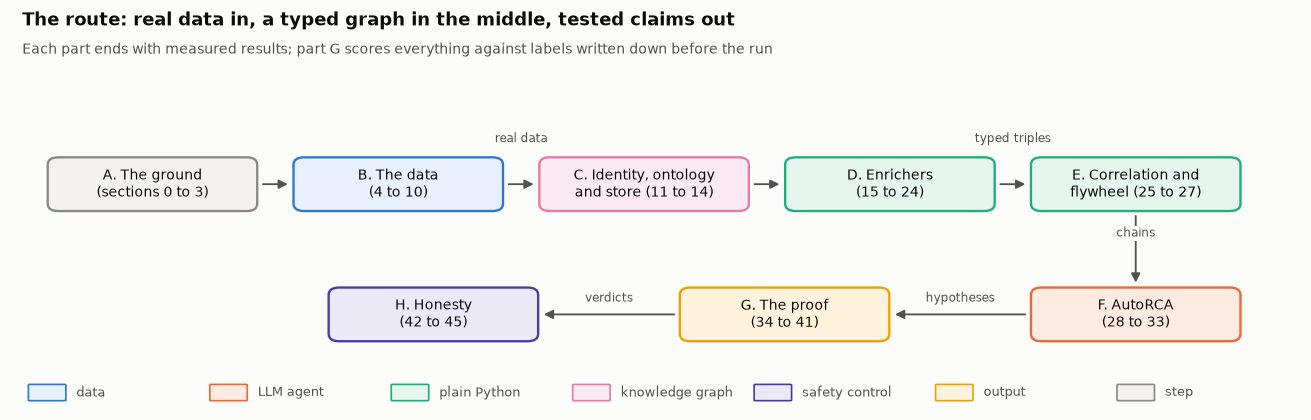

In [8]:
# ---- the route through this notebook ----
COURSE_NODES = {
    "A": (1.2, 2.75, "A. The ground\n(sections 0 to 3)", "step"),
    "B": (3.3, 2.75, "B. The data\n(4 to 10)", "data"),
    "C": (5.4, 2.75, "C. Identity, ontology\nand store (11 to 14)", "graph"),
    "D": (7.5, 2.75, "D. Enrichers\n(15 to 24)", "code"),
    "E": (9.6, 2.75, "E. Correlation and\nflywheel (25 to 27)", "code"),
    "F": (9.6, 1.15, "F. AutoRCA\n(28 to 33)", "llm"),
    "G": (6.6, 1.15, "G. The proof\n(34 to 41)", "output"),
    "H": (3.6, 1.15, "H. Honesty\n(42 to 45)", "guard"),
}
ABOVE = (0.0, 0.36)   # short horizontal arrows carry their label above the boxes
COURSE_EDGES = [("A", "B", None), ("B", "C", "real data", None, ABOVE), ("C", "D", None),
                ("D", "E", "typed triples", None, ABOVE), ("E", "F", "chains"), ("F", "G", "hypotheses"),
                ("G", "H", "verdicts")]
draw_flow(COURSE_NODES, COURSE_EDGES, "course_map",
          "The route: real data in, a typed graph in the middle, tested claims out",
          "Each part ends with measured results; part G scores everything against labels written down before the run",
          size=(11, 3.6))

[fig] artifacts\figures_full\hero_architecture.png


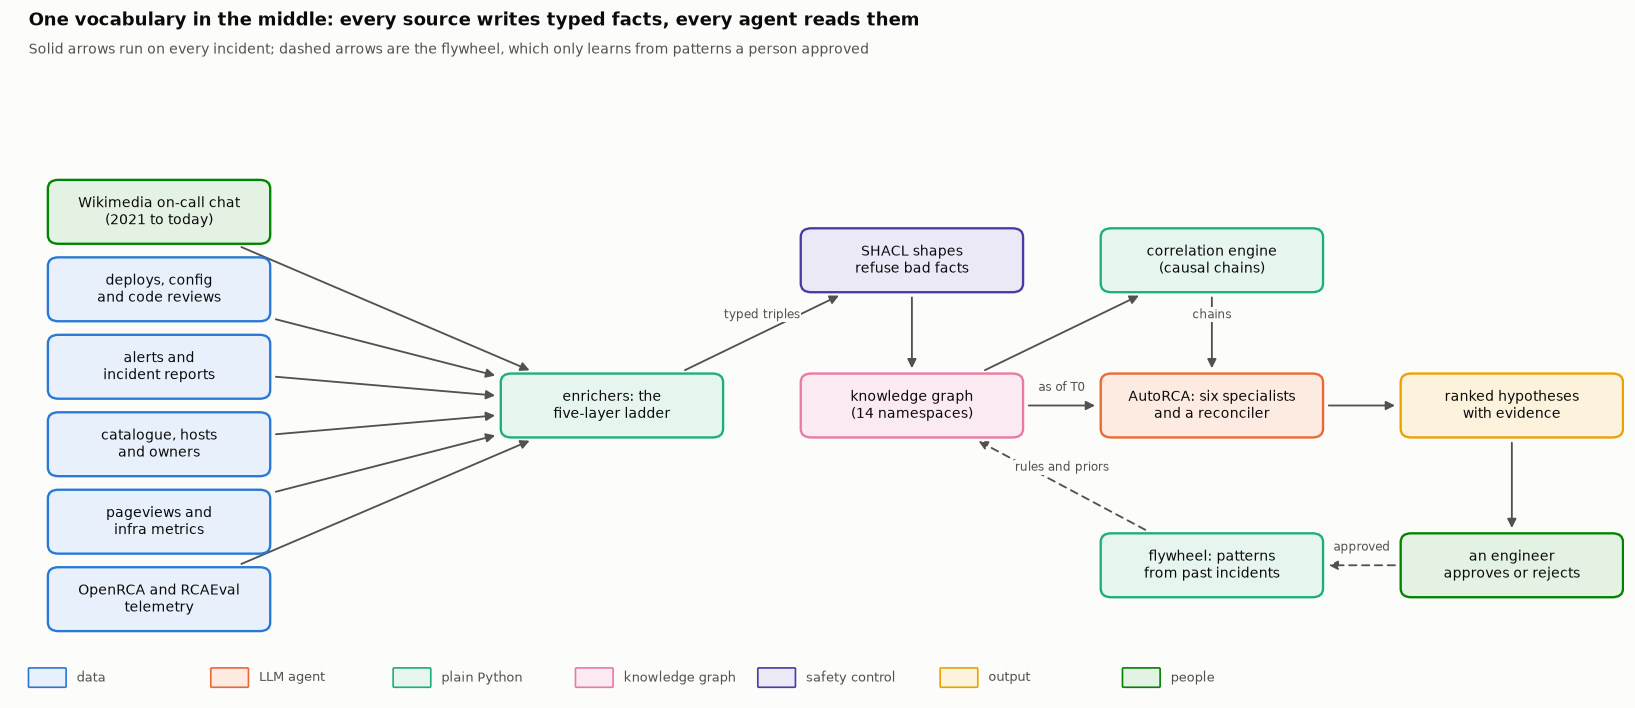

In [9]:
# ---- the whole system on one page ----
HERO_NODES = {
    "chat":   (1.25, 5.0, "Wikimedia on-call chat\n(2021 to today)", "human"),
    "chg":    (1.25, 4.2, "deploys, config\nand code reviews", "data"),
    "alrt":   (1.25, 3.4, "alerts and\nincident reports", "data"),
    "cat":    (1.25, 2.6, "catalogue, hosts\nand owners", "data"),
    "usr":    (1.25, 1.8, "pageviews and\ninfra metrics", "data"),
    "lab":    (1.25, 1.0, "OpenRCA and RCAEval\ntelemetry", "data"),
    "ladder": (5.1, 3.0, "enrichers: the\nfive-layer ladder", "code"),
    "shacl":  (7.65, 4.5, "SHACL shapes\nrefuse bad facts", "guard"),
    "kg":     (7.65, 3.0, "knowledge graph\n(14 namespaces)", "graph"),
    "corr":   (10.2, 4.5, "correlation engine\n(causal chains)", "code"),
    "rca":    (10.2, 3.0, "AutoRCA: six specialists\nand a reconciler", "llm"),
    "fly":    (10.2, 1.35, "flywheel: patterns\nfrom past incidents", "code"),
    "out":    (12.75, 3.0, "ranked hypotheses\nwith evidence", "output"),
    "ppl":    (12.75, 1.35, "an engineer\napproves or rejects", "human"),
}
HERO_EDGES = [(s, "ladder", None) for s in ("chat", "chg", "alrt", "cat", "usr", "lab")] + [
    ("ladder", "shacl", "typed triples"), ("shacl", "kg", None), ("kg", "corr", None), ("corr", "rca", "chains"),
    ("kg", "rca", "as of T0"), ("rca", "out", None), ("out", "ppl", None),
    ("ppl", "fly", "approved", "dashed"), ("fly", "kg", "rules and priors", "dashed")]
draw_flow(HERO_NODES, HERO_EDGES, "hero_architecture",
          "One vocabulary in the middle: every source writes typed facts, every agent reads them",
          "Solid arrows run on every incident; dashed arrows are the flywheel, which only learns from patterns a person approved",
          size=(13.7, 6.0), box=(1.85, 0.62))

In [10]:
# ---- results at a glance: the verdicts of the last complete run, read from disk ----
glance_file = GLANCE_FILE
if glance_file.exists():
    glance = json.loads(glance_file.read_text())
    print(f"  from the {glance['profile']} run finished {glance['written']} UTC (section 42 computes these again below)")
    for v in glance["verdicts"]:
        print(f"  {v['claim']:<5}{v['verdict']:<15}{v['evidence'][:100]}")
else:
    print("  no complete run yet: section 42 writes this summary when the notebook has run to the end")

  from the FULL run finished 2026-11-01T02:07+00:00 UTC (section 42 computes these again below)
  H1   SUPPORTED      one query and five lookups return the same changes and owners on 217 of 217 questions with a change 
  H2   SUPPORTED      contract kept 100%; identical three times with the contract 90% of 10 (95% interval 60% to 98%); onl
  H3   SUPPORTED      3,734 junk strings refused; misspelt host caught by the shapes
  H4   NOT SUPPORTED  call graphs: no fan-in above 10 (not testable); membership hub: incident/placebo ratio 1.55 uncapped
  H5   SUPPORTED      a graph-reading enricher makes 8 links in planned order, 0 out of order
  H6   INCONCLUSIVE   first: topology 4, timing 2 (Holm p 1.00); 33/146 incidents, 103/707 placebo (Holm p 0.11)
  H7   NOT SUPPORTED  better on 7, worse on 8 (Holm p 1.00)
  H8   INCONCLUSIVE   only with chat 1, only without 0 (Holm p 1.00)
  H9   INCONCLUSIVE   only raw 1, only graph 0 (Holm p 1.00)
  H10  NOT TESTABLE   our specialists report to a rec

In [11]:
# ---- the money, written down before anything is spent ----
# three changes since these were first written, all on 2026-10-31, all from the reserve: 25 to the model
# comparison, because section 9's corrected reader rule changed the incident we follow and section 22's sample
# with it; 80 to label extraction, because fixing the scrubber (section 4) changed the text of most reports, so
# both readers read them again, and the second adjudicator (section 34) reads every disagreement; 40 to the
# Wikimedia test, because a count before it ran put the two-by-two and the specialist curve at about 1,170 calls,
# within a few Magicubes of the original cap, and a cap reached halfway would have left an experiment half done.
# Two more on 2026-11-01, from the RCAEval agents line, which no section uses (RCAEval is ranked without a model):
# 15 to the model comparison and 40 to the Wikimedia test, because a second scrubber fix (section 4) changed about
# one line in a hundred, and every prompt holding such a line is asked again
QWEN_PHASES = {"API probes": 15, "label extraction": 200, "chat classification (L4)": 60, "screenshots (Omni)": 20,
               "model comparison": 65, "determinism reruns": 50, "AutoRCA development": 140,
               "Wikimedia test incl. 2x2": 330, "OpenRCA test": 250, "RCAEval agents": 5, "live latency": 30,
               "reserve": 35}
CLAUDE_PHASES = {"pilots": 2.0, "label extraction": 8.0, "chat classification comparison": 3.0,
                 "free-text judge": 8.0, "reserve": 8.0}
assert sum(QWEN_PHASES.values()) == QWEN_BUDGET_CUBES, "Qwen phases must add up to the total cap"
assert sum(CLAUDE_PHASES.values()) <= CLAUDE_BUDGET_USD, "Claude phases must fit under the hard stop"
print(f"  {'Qwen phase':<30}{'cap (Magicubes)':>16}     {'Claude phase':<32}{'cap (USD)':>10}")
print("  " + "-" * 92)
for (qn, qv), (cn, cv) in itertools.zip_longest(QWEN_PHASES.items(), CLAUDE_PHASES.items(), fillvalue=("", None)):
    qs = f"{qv:>16}" if qv is not None else " " * 16
    cs = f"{cv:>10.2f}" if cv is not None else ""
    print(f"  {qn:<30}{qs}     {cn:<32}{cs}")
print("  " + "-" * 92)
print(f"  {'total':<30}{sum(QWEN_PHASES.values()):>16}     {'total (hard stop ' + str(CLAUDE_BUDGET_USD) + ')':<32}"
      f"{sum(CLAUDE_PHASES.values()):>10.2f}")
print("\n  A phase that would cross its cap stops before the call is made, not after.")

  Qwen phase                     cap (Magicubes)     Claude phase                     cap (USD)
  --------------------------------------------------------------------------------------------
  API probes                                  15     pilots                                2.00
  label extraction                           200     label extraction                      8.00
  chat classification (L4)                    60     chat classification comparison        3.00
  screenshots (Omni)                          20     free-text judge                       8.00
  model comparison                            65     reserve                               8.00
  determinism reruns                          50                                     
  AutoRCA development                        140                                     
  Wikimedia test incl. 2x2                   330                                     
  OpenRCA test                               250                       

## 1 · The study we test: Netflix's claims, written down before we look

**Theory.** A design post persuades by explaining; it does not have to measure. That is fine
for a post and a problem for anyone deciding whether to build the same thing. So before we
touch any data we read the post line by line and turn every claim that could be wrong into a
test: what it says, which part of our build exercises it, what we will measure, on which
data, and what result would count against it. Some claims are about mechanism (a type system
makes a language model's output reproducible), some about value (the flywheel makes the system
better over time), some about cost (the graph absorbs the hour or two spent gathering
context). We group them into seven experiments, write the targets into code, and freeze them
in a pre-registration file after a short pilot, so that the results in part G cannot quietly
move the goalposts.

In [12]:
# ---- every testable claim in the post, with the place it is made ----
CLAIMS = [
    ("H1",  "One query over the ontology replaces lookups across three tools", "The Ontology", "E1"),
    ("H2",  "Constraining an LLM with a type system yields a deterministic graph", "Creating determinism", "E2"),
    ("H3",  "Validating every application against the catalogue keeps junk out of the graph", "Two decisions", "E3"),
    ("H4",  "Capping dependency edges stops popular services from dominating", "Two decisions", "E3"),
    ("H5",  "Ordered, sequential enrichment buys accuracy worth its cost in speed", "Enrichers", "E4"),
    ("H6",  "Known causal pairs plus timing and severity recover causal chains", "Correlation Engine, Fig 7", "E5"),
    ("H7",  "Each turn of the flywheel leaves the system better for the next", "Knowledge flywheel, Figs 8-9", "E6"),
    ("H8",  "The most valuable edges come from human discussion", "If you want to build one", "E7"),
    ("H9",  "Without the right context, agents hallucinate", "The disagreement underneath", "E7"),
    ("H10", "Specialists read each other's findings through the ontology alone", "Putting the graph to work", "E7"),
    ("H11", "The graph absorbs the hour or two spent assembling context", "Putting the graph to work, Fig 3", "E1"),
    ("H12", "Best-effort enrichment degrades the graph but never blocks it", "Enrichers, principles", "E4"),
]
print(f"  {'id':<5}{'claim':<84}{'experiment':>10}")
print("  " + "-" * 99)
for cid, claim, where, exp in CLAIMS:
    print(f"  {cid:<5}{claim:<84}{exp:>10}")
print(f"\n  {len(CLAIMS)} claims, folded into {len({c[3] for c in CLAIMS})} experiments")

  id   claim                                                                               experiment
  ---------------------------------------------------------------------------------------------------
  H1   One query over the ontology replaces lookups across three tools                             E1
  H2   Constraining an LLM with a type system yields a deterministic graph                         E2
  H3   Validating every application against the catalogue keeps junk out of the graph              E3
  H4   Capping dependency edges stops popular services from dominating                             E3
  H5   Ordered, sequential enrichment buys accuracy worth its cost in speed                        E4
  H6   Known causal pairs plus timing and severity recover causal chains                           E5
  H7   Each turn of the flywheel leaves the system better for the next                             E6
  H8   The most valuable edges come from human discussion                         

In [13]:
# ---- the seven experiments, what each measures, and on which data ----
EXPERIMENTS = {
    "E1": {"name": "joins and context assembly", "metric": "tool calls and seconds to answer; candidate narrowing",
           "worlds": ["wikimedia"]},
    "E2": {"name": "typed contracts and reproducibility", "metric": "rerun Jaccard beside accuracy on gold threads",
           "worlds": ["wikimedia"]},
    "E3": {"name": "identity, catalogue gate, edge caps", "metric": "junk entities, join rate, downstream accuracy",
           "worlds": ["wikimedia", "openrca"]},
    "E4": {"name": "ordering and graceful degradation", "metric": "triples lost when shuffled; false 'nothing shipped'",
           "worlds": ["wikimedia"]},
    "E5": {"name": "correlation", "metric": "root cause in chain, placebo rate, reliability",
           "worlds": ["wikimedia", "openrca", "rcaeval"]},
    "E6": {"name": "flywheel", "metric": "score with learning on minus learning off, per cycle",
           "worlds": ["openrca", "wikimedia"]},
    "E7": {"name": "agents and context", "metric": "accuracy, hallucination, latency, cost per investigation",
           "worlds": ["wikimedia", "openrca", "rcaeval"]},
}
for eid, e in EXPERIMENTS.items():
    hyps = ", ".join(c[0] for c in CLAIMS if c[3] == eid)
    print(f"  {eid}  {e['name']:<38}{hyps:<16}{', '.join(e['worlds'])}")
    print(f"      measures: {e['metric']}")

  E1  joins and context assembly            H1, H11         wikimedia
      measures: tool calls and seconds to answer; candidate narrowing
  E2  typed contracts and reproducibility   H2              wikimedia
      measures: rerun Jaccard beside accuracy on gold threads
  E3  identity, catalogue gate, edge caps   H3, H4          wikimedia, openrca
      measures: junk entities, join rate, downstream accuracy
  E4  ordering and graceful degradation     H5, H12         wikimedia
      measures: triples lost when shuffled; false 'nothing shipped'
  E5  correlation                           H6              wikimedia, openrca, rcaeval
      measures: root cause in chain, placebo rate, reliability
  E6  flywheel                              H7              openrca, wikimedia
      measures: score with learning on minus learning off, per cycle
  E7  agents and context                    H8, H9, H10     wikimedia, openrca, rcaeval
      measures: accuracy, hallucination, latency, cost per inv

In [14]:
# ---- provisional targets, written down now; section 35 freezes them after a short pilot ----
TARGETS = {
    "openrca_cloudbed2_strict_pct_min": 24.36,   # the manual-rules arm of the 2026 follow-up on a held-out cloudbed
    "rcaeval_re2tt_ac3_min": 0.82,               # BARO, multi-source, Table 6 of the RCAEval paper
    "wikimedia_trigger_hit3_min": 0.60,          # change-triggered incidents only
    "latency_p50_max_s": 15.0,
    "latency_p95_max_s": 45.0,
    "unverifiable_citations_max": 0,
    "cubes_per_investigation_max": 2.5,
}
PREREG_DRAFT = {"written": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d"),
                "claims": [list(c) for c in CLAIMS], "experiments": EXPERIMENTS, "targets": TARGETS,
                "status": "draft, frozen after the pilot in section 35"}
PREREG_DRAFT_FILE.write_text(json.dumps(PREREG_DRAFT, indent=1))
for k, v in TARGETS.items():
    print(f"  {k:<36}{v}")
print(f"\n  draft written to {PREREG_DRAFT_FILE.relative_to(ROOT)}")

  openrca_cloudbed2_strict_pct_min    24.36
  rcaeval_re2tt_ac3_min               0.82
  wikimedia_trigger_hit3_min          0.6
  latency_p50_max_s                   15.0
  latency_p95_max_s                   45.0
  unverifiable_citations_max          0
  cubes_per_investigation_max         2.5

  draft written to artifacts\preregistration_draft.json


[fig] artifacts\figures_full\claims_to_experiments.png


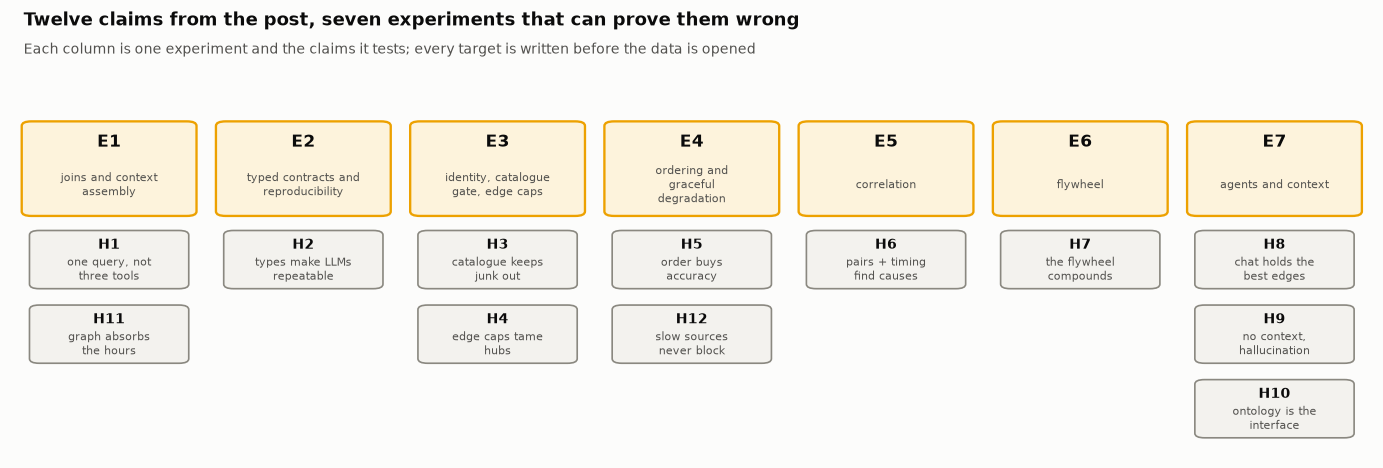

In [15]:
# ---- the claims and where each is tested ----
SHORT = {"H1": "one query, not three tools", "H2": "types make LLMs repeatable", "H3": "catalogue keeps junk out",
         "H4": "edge caps tame hubs", "H5": "order buys accuracy", "H6": "pairs + timing find causes",
         "H7": "the flywheel compounds", "H8": "chat holds the best edges", "H9": "no context, hallucination",
         "H10": "ontology is the interface", "H11": "graph absorbs the hours", "H12": "slow sources never block"}
fig, ax = plt.subplots(figsize=(11.6, 4.0))
ax.axis("off")
ax.set_xlim(0, 7)
ax.set_ylim(0.35, 4.1)
for i, (eid, e) in enumerate(EXPERIMENTS.items()):
    ax.add_patch(FancyBboxPatch((i + 0.06, 3.0), 0.88, 1.02, boxstyle="round,pad=0.01,rounding_size=0.05",
                                fc=KIND_STYLE["output"]["fc"], ec=KIND_STYLE["output"]["ec"], lw=1.4))
    ax.text(i + 0.5, 3.8, eid, ha="center", va="center", fontsize=10, weight="bold", color=INK)
    ax.text(i + 0.5, 3.33, textwrap.fill(e["name"], 19), ha="center", va="center", fontsize=6.9, color=INK2)
    for j, c in enumerate([c for c in CLAIMS if c[3] == eid]):
        y = 2.2 - j * 0.82
        ax.add_patch(FancyBboxPatch((i + 0.1, y), 0.8, 0.62, boxstyle="round,pad=0.01,rounding_size=0.05",
                                    fc=KIND_STYLE["step"]["fc"], ec=KIND_STYLE["step"]["ec"], lw=1))
        ax.text(i + 0.5, y + 0.43, c[0], ha="center", fontsize=8.6, weight="bold", color=INK)
        ax.text(i + 0.5, y + 0.2, textwrap.fill(SHORT[c[0]], 16), ha="center", va="center", fontsize=6.9, color=INK2)
finish(fig, "claims_to_experiments", "Twelve claims from the post, seven experiments that can prove them wrong",
       "Each column is one experiment and the claims it tests; every target is written before the data is opened")

**Twelve claims became seven experiments, and every one of them can fail.** None of the
targets above came from our own results: two are the best published numbers on the two
benchmarks we use, and the rest are what an on-call engineer would accept before trusting the
tool. The draft is on disk now; after the pilot in section 35 it is frozen with a hash, and
every number in part G is compared with that file rather than with what we hoped to see.

## 1b · Netflix's study, figure by figure

**Theory.** The post makes its case in ten figures. Before building anything we redraw each
one and say in plain words what it claims, because each figure turns into a component, a
test, or both, later in the notebook. Where a figure contains an example (a chat message, a
chain of events, a query) we make the example runnable, so the mechanism is visible on the
post's own data before we point it at ours.

[fig] artifacts\figures_full\netflix_fig1_melt.png


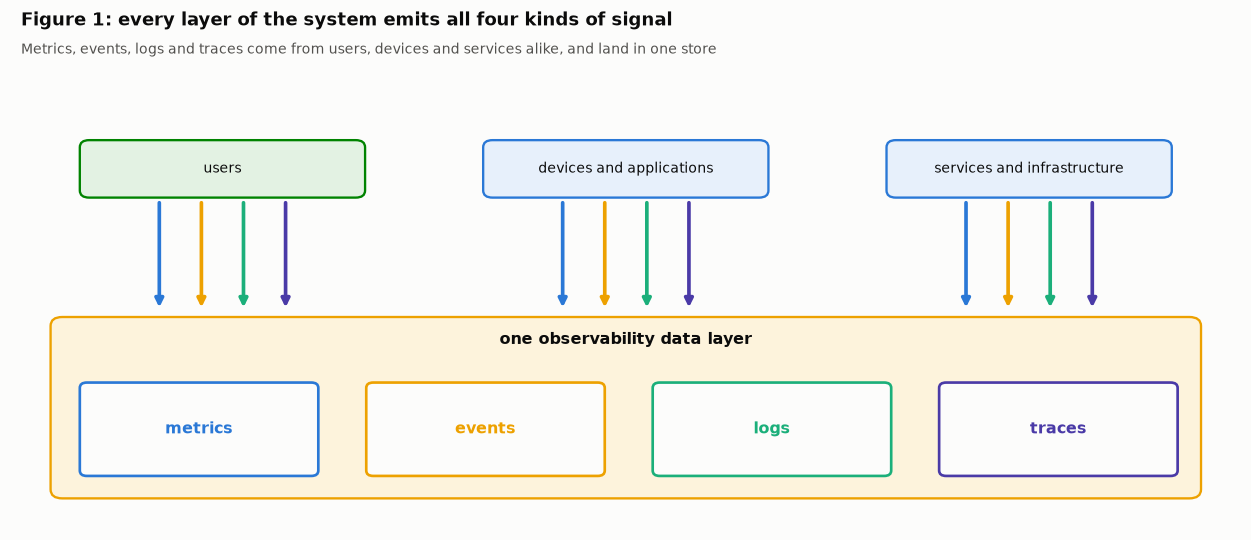

In [16]:
# ---- figure 1: MELT, four kinds of signal from three places, gathered in one layer ----
PILLARS = [("metrics", C1), ("events", C4), ("logs", C3), ("traces", C7)]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.axis("off")
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 4.6)
for sx, src, kind in ((1.8, "users", "human"), (5.25, "devices and applications", "data"),
                      (8.7, "services and infrastructure", "data")):
    st = KIND_STYLE[kind]
    ax.add_patch(FancyBboxPatch((sx - 1.2, 3.7), 2.4, 0.6, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=st["fc"], ec=st["ec"], lw=1.4))
    ax.text(sx, 4.0, src, ha="center", va="center", fontsize=8.6, color=INK)
    for k, (name, col) in enumerate(PILLARS):
        x = sx - 0.54 + k * 0.36
        ax.add_patch(FancyArrowPatch((x, 3.66), (x, 2.42), arrowstyle="-|>", mutation_scale=10, lw=2.2, color=col))
ax.add_patch(FancyBboxPatch((0.35, 0.35), 9.8, 1.98, boxstyle="round,pad=0.02,rounding_size=0.1",
                            fc=KIND_STYLE["output"]["fc"], ec=KIND_STYLE["output"]["ec"], lw=1.4))
ax.text(5.25, 2.05, "one observability data layer", ha="center", fontsize=9.5, weight="bold", color=INK)
for k, (name, col) in enumerate(PILLARS):
    cx = 1.6 + k * 2.45
    ax.add_patch(FancyBboxPatch((cx - 1.0, 0.6), 2.0, 1.0, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc=SURF, ec=col, lw=1.6))
    ax.text(cx, 1.1, name, ha="center", va="center", fontsize=9.5, color=col, weight="bold")
finish(fig, "netflix_fig1_melt", "Figure 1: every layer of the system emits all four kinds of signal",
       "Metrics, events, logs and traces come from users, devices and services alike, and land in one store")

  signal   what it tells us                                                  what it leaves out
  ------------------------------------------------------------------------------------------------------------------------------------
  Metrics  render time and 12 related measures moved across 5 services       which of the 12 moved in context, and which merely happened
  Events   47 changes landed in the last hour across 7 applications          which of the 47 touched the 5 services above
  Logs     connection pool exhaustion in 1 service, timeouts in 11 others    which errors are cause and which are consequence
  Traces   elevated GraphQL latency in the sampled traces                    everything outside the sample

  Read the right-hand column again: every gap is a join between two systems.
  'Which of the 47 touched the 5' is the deploy log joined to the metrics by service name.
  'Cause or consequence' is the logs joined to the call graph. Nothing there is a missing signal.


[fig] artifacts\figures_full\netflix_fig2_signals.png


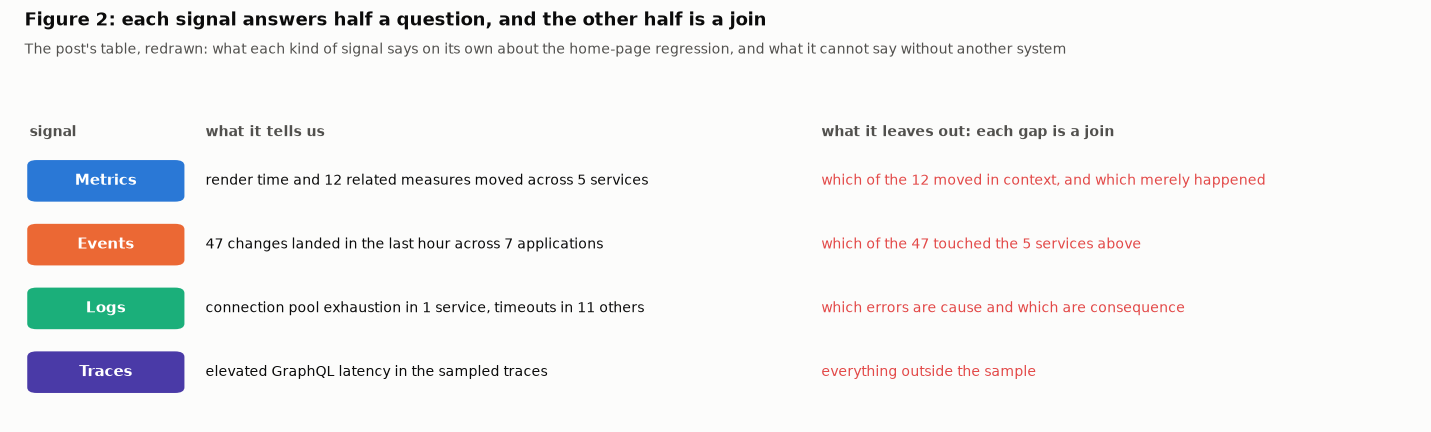

In [17]:
# ---- figure 2: what each signal tells us, and what it leaves out ----
FIG2 = [("Metrics", "render time and 12 related measures moved across 5 services",
         "which of the 12 moved in context, and which merely happened"),
        ("Events", "47 changes landed in the last hour across 7 applications",
         "which of the 47 touched the 5 services above"),
        ("Logs", "connection pool exhaustion in 1 service, timeouts in 11 others",
         "which errors are cause and which are consequence"),
        ("Traces", "elevated GraphQL latency in the sampled traces",
         "everything outside the sample")]
print(f"  {'signal':<9}{'what it tells us':<66}what it leaves out")
print("  " + "-" * 132)
for sig, tells, misses in FIG2:
    print(f"  {sig:<9}{tells:<66}{misses}")
print("\n  Read the right-hand column again: every gap is a join between two systems.")
print("  'Which of the 47 touched the 5' is the deploy log joined to the metrics by service name.")
print("  'Cause or consequence' is the logs joined to the call graph. Nothing there is a missing signal.")

fig, ax = plt.subplots(figsize=(12, 3.7))
ax.axis("off")
ax.set_xlim(0, 12)
ax.set_ylim(0, 4.4)
for x, head in ((0.15, "signal"), (1.65, "what it tells us"), (6.9, "what it leaves out: each gap is a join")):
    ax.text(x, 4.15, head, fontsize=8.5, color=INK2, weight="bold", va="center")
for i, ((sig, tells, misses), colour) in enumerate(zip(FIG2, (C1, C2, C3, C7))):
    y = 3.45 - i * 0.92
    ax.add_patch(FancyBboxPatch((0.15, y - 0.28), 1.3, 0.56, boxstyle="round,pad=0.02,rounding_size=0.08", fc=colour,
                                ec="none"))
    ax.text(0.8, y, sig, ha="center", va="center", fontsize=9, color="white", weight="bold")
    ax.text(1.65, y, textwrap.fill(tells, 72), va="center", fontsize=8.4, color=INK)
    ax.text(6.9, y, textwrap.fill(misses, 66), va="center", fontsize=8.4, color=C8)
finish(fig, "netflix_fig2_signals", "Figure 2: each signal answers half a question, and the other half is a join",
       "The post's table, redrawn: what each kind of signal says on its own about the home-page regression, and what it "
       "cannot say without another system")

[fig] artifacts\figures_full\netflix_fig3_timeline.png


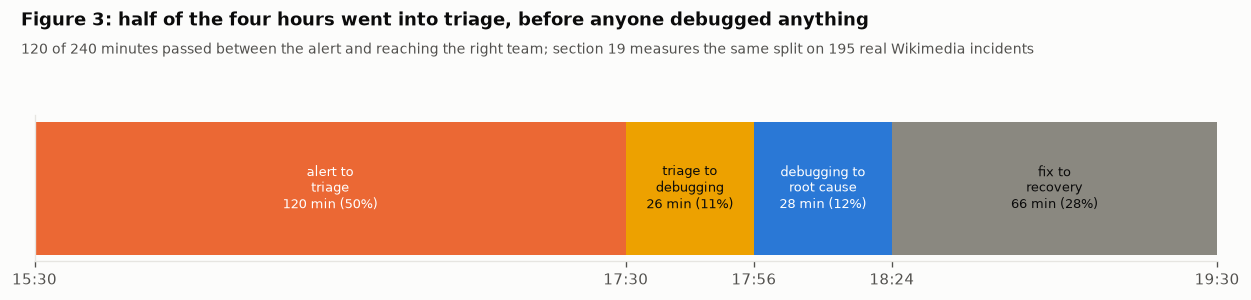

In [18]:
# ---- figure 3: four hours, and where they went ----
FIG3 = [("alert fires", "15:30"), ("triaged to the right team", "17:30"), ("debugging", "17:56"),
        ("root cause found, fix rolled out", "18:24"), ("impact gone", "19:30")]
t = [datetime.datetime.strptime(x[1], "%H:%M") for x in FIG3]
mins = [(b - a).seconds // 60 for a, b in zip(t[:-1], t[1:])]
labels = ["alert to\ntriage", "triage to\ndebugging", "debugging to\nroot cause", "fix to\nrecovery"]
fig, ax = plt.subplots(figsize=(10.5, 2.6))
left = 0
for i, (lab, m) in enumerate(zip(labels, mins)):
    ax.barh(0, m, left=left, color=[C2, C4, C1, MUTED][i], height=0.5)
    ax.text(left + m / 2, 0, f"{lab}\n{m} min ({m / sum(mins):.0%})", ha="center", va="center", fontsize=7.6,
            color="white" if i in (0, 2) else INK)
    left += m
ax.set_yticks([])
ax.set_xlim(0, sum(mins))
ax.set_xticks(np.cumsum([0] + mins))
ax.set_xticklabels([x[1] for x in FIG3])
ax.grid(False)
finish(fig, "netflix_fig3_timeline", f"Figure 3: half of the four hours went into triage, before anyone debugged anything",
       f"{mins[0]} of {sum(mins)} minutes passed between the alert and reaching the right team; "
       "section 19 measures the same split on 195 real Wikimedia incidents")

[fig] artifacts\figures_full\netflix_fig4_namespaces.png


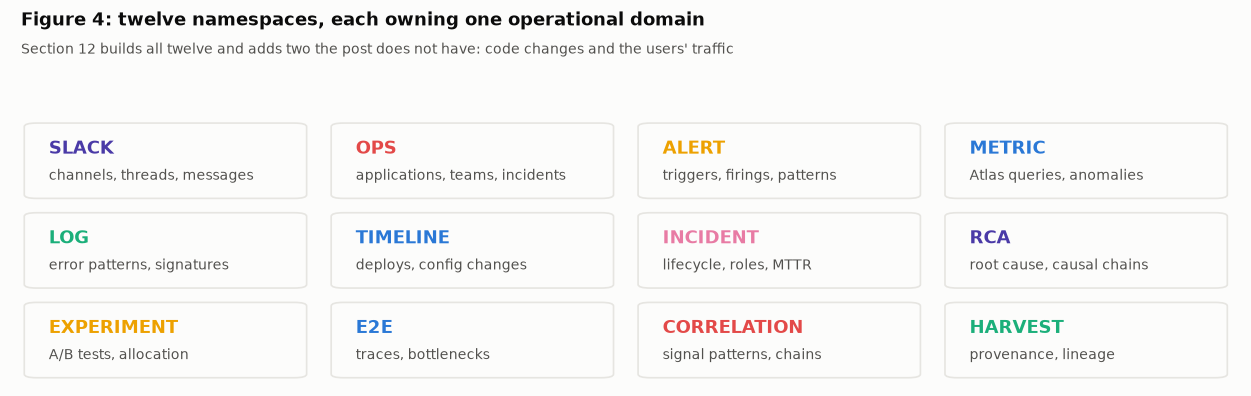

In [19]:
# ---- figure 4: twelve namespaces, one per operational domain ----
FIG4 = [("SLACK", "channels, threads, messages", C7), ("OPS", "applications, teams, incidents", C8),
        ("ALERT", "triggers, firings, patterns", C4), ("METRIC", "Atlas queries, anomalies", C1),
        ("LOG", "error patterns, signatures", C3), ("TIMELINE", "deploys, config changes", C1),
        ("INCIDENT", "lifecycle, roles, MTTR", C5), ("RCA", "root cause, causal chains", C7),
        ("EXPERIMENT", "A/B tests, allocation", C4), ("E2E", "traces, bottlenecks", C1),
        ("CORRELATION", "signal patterns, chains", C8), ("HARVEST", "provenance, lineage", C3)]
fig, ax = plt.subplots(figsize=(10.5, 3.4))
ax.axis("off")
ax.set_xlim(0, 4)
ax.set_ylim(0, 3)
for i, (ns, what, col) in enumerate(FIG4):
    x, y = i % 4, 2 - i // 4
    ax.add_patch(FancyBboxPatch((x + 0.05, y + 0.08), 0.9, 0.82, boxstyle="round,pad=0.01,rounding_size=0.04",
                                fc=SURF, ec=GRID, lw=1))
    ax.text(x + 0.12, y + 0.62, ns, fontsize=10.5, weight="bold", color=col, va="center")
    ax.text(x + 0.12, y + 0.32, what, fontsize=8.4, color=INK2, va="center")
finish(fig, "netflix_fig4_namespaces", "Figure 4: twelve namespaces, each owning one operational domain",
       "Section 12 builds all twelve and adds two the post does not have: code changes and the users' traffic")

  message : api-gateway latency spiked after 1.4.2 deploy, traces show zuul timing out, @jane rolling back, SEV 2 INC-5377
  incident : ['INC-5377']   (found by a regular expression, the same answer every time)
  version  : ['1.4.2']   (found by a regular expression, the same answer every time)
  mention  : ['jane']   (found by a regular expression, the same answer every time)
  severity : ['SEV 2']   (found by a regular expression, the same answer every time)
  services: 'api-gateway', 'zuul'   (need the catalogue: is zuul a service, an alias, or a typo?)
  meaning : 'latency spiked AFTER the deploy'   (needs a model, or a correlation engine)

  the post turns it into seven triples:
    :deploy-1.4.2  rdf:type         tl:Deployment
    :deploy-1.4.2  tl:service       :api-gateway
    :INC-5377      rdf:type         ops:Incident
    :INC-5377      ops:affects      :api-gateway
    :chain-1       corr:rootCause   :deploy-1.4.2
    :chain-1       corr:leadsTo     :INC-5377
    :chain-1  

[fig] artifacts\figures_full\netflix_fig5_chaos_to_facts.png


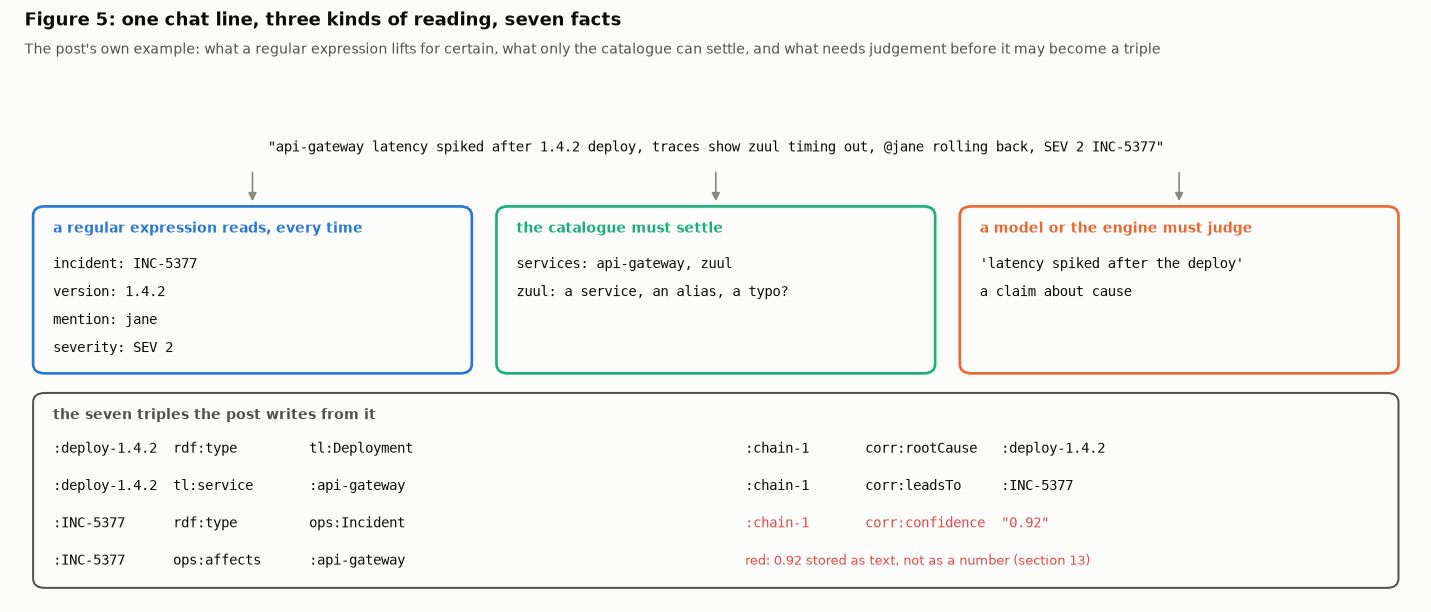

In [20]:
# ---- figure 5: one chat message, turned into facts by the post's own example ----
FIG5_MSG = "api-gateway latency spiked after 1.4.2 deploy, traces show zuul timing out, @jane rolling back, SEV 2 INC-5377"
found = {"incident": re.findall(r"\bINC-\d+\b", FIG5_MSG), "version": re.findall(r"\b\d+\.\d+\.\d+\b", FIG5_MSG),
         "mention": re.findall(r"@(\w+)", FIG5_MSG), "severity": re.findall(r"\bSEV ?\d\b", FIG5_MSG)}
print(f"  message : {FIG5_MSG}")
for k, v in found.items():
    print(f"  {k:<9}: {v}   (found by a regular expression, the same answer every time)")
print("  services: 'api-gateway', 'zuul'   (need the catalogue: is zuul a service, an alias, or a typo?)")
print("  meaning : 'latency spiked AFTER the deploy'   (needs a model, or a correlation engine)")
FIG5_TRIPLES = [(":deploy-1.4.2", "rdf:type", "tl:Deployment"), (":deploy-1.4.2", "tl:service", ":api-gateway"),
                (":INC-5377", "rdf:type", "ops:Incident"), (":INC-5377", "ops:affects", ":api-gateway"),
                (":chain-1", "corr:rootCause", ":deploy-1.4.2"), (":chain-1", "corr:leadsTo", ":INC-5377"),
                (":chain-1", "corr:confidence", '"0.92"')]
print("\n  the post turns it into seven triples:")
for s, p, o in FIG5_TRIPLES:
    print(f"    {s:<15}{p:<17}{o}")
print("\n  Note the last one: 0.92 is written as text, not as a number. Section 13 shows why that matters.")

fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axis("off")
ax.set_xlim(0, 12)
ax.set_ylim(0, 5.2)
ax.text(6.0, 4.85, f'"{FIG5_MSG}"', ha="center", va="center", fontsize=8.6, color=INK, family="monospace")
readers = [("a regular expression reads, every time", C1, [f"{k}: {', '.join(v)}" for k, v in found.items()]),
           ("the catalogue must settle", C3, ["services: api-gateway, zuul", "zuul: a service, an alias, a typo?"]),
           ("a model or the engine must judge", C2, ["'latency spiked after the deploy'", "a claim about cause"])]
for j, (head, colour, lines) in enumerate(readers):
    x0 = 0.2 + j * 3.95
    ax.add_patch(FancyBboxPatch((x0, 2.45), 3.7, 1.75, boxstyle="round,pad=0.02,rounding_size=0.1", fc=SURF, ec=colour,
                                lw=1.6))
    ax.text(x0 + 0.15, 3.98, head, fontsize=8.6, color=colour, weight="bold", va="center")
    for k, line in enumerate(lines):
        ax.text(x0 + 0.15, 3.6 - k * 0.3, line, fontsize=8.2, color=INK, va="center", family="monospace")
    ax.add_patch(FancyArrowPatch((x0 + 1.85, 4.62), (x0 + 1.85, 4.24), arrowstyle="-|>", mutation_scale=10,
                                 color=MUTED, lw=1))
ax.add_patch(FancyBboxPatch((0.2, 0.15), 11.6, 2.05, boxstyle="round,pad=0.02,rounding_size=0.1", fc=SURF, ec=INK2,
                            lw=1.2))
ax.text(0.35, 1.98, "the seven triples the post writes from it", fontsize=8.6, color=INK2, weight="bold", va="center")
for k, (s, p, o) in enumerate(FIG5_TRIPLES):
    ax.text(0.35 + (k // 4) * 5.9, 1.62 - (k % 4) * 0.4, f"{s:<15}{p:<17}{o}", fontsize=8.4, family="monospace",
            color=C8 if o.startswith('"') else INK, va="center")
ax.text(6.25, 0.42, "red: 0.92 stored as text, not as a number (section 13)", fontsize=8, color=C8, va="center")
finish(fig, "netflix_fig5_chaos_to_facts", "Figure 5: one chat line, three kinds of reading, seven facts",
       "The post's own example: what a regular expression lifts for certain, what only the catalogue can settle, and what "
       "needs judgement before it may become a triple")

[fig] artifacts\figures_full\netflix_fig6_ladder.png


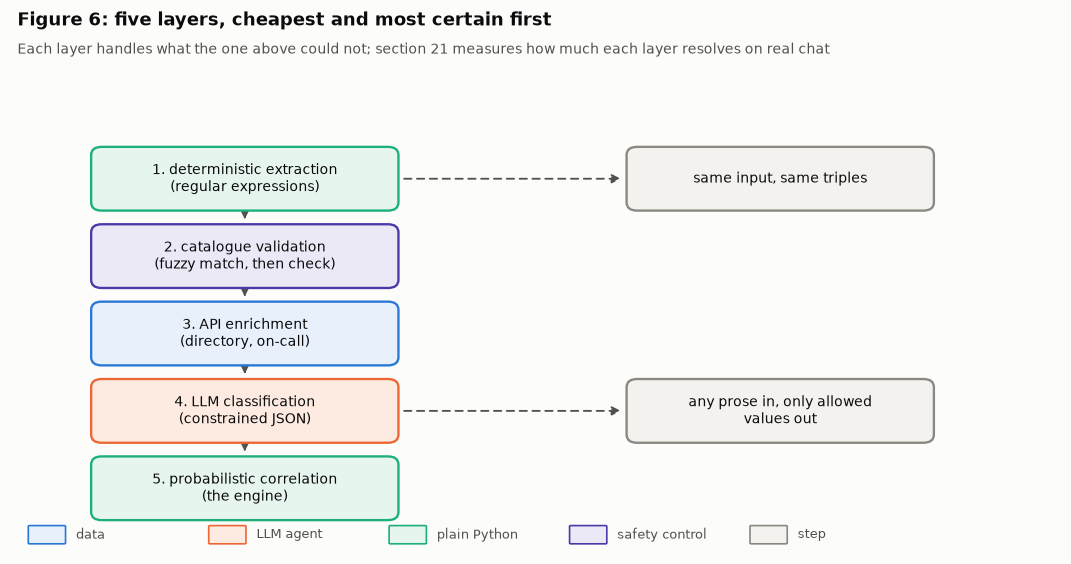

In [21]:
# ---- figure 6: the five-layer ladder from chaos to facts ----
LADDER = {
    "l1": (2.0, 4.1, "1. deterministic extraction\n(regular expressions)", "code"),
    "l2": (2.0, 3.25, "2. catalogue validation\n(fuzzy match, then check)", "guard"),
    "l3": (2.0, 2.4, "3. API enrichment\n(directory, on-call)", "data"),
    "l4": (2.0, 1.55, "4. LLM classification\n(constrained JSON)", "llm"),
    "l5": (2.0, 0.7, "5. probabilistic correlation\n(the engine)", "code"),
    "note1": (6.6, 4.1, "same input, same triples", "step"),
    "note4": (6.6, 1.55, "any prose in, only allowed\nvalues out", "step"),
}
draw_flow(LADDER, [("l1", "l2", None), ("l2", "l3", None), ("l3", "l4", None), ("l4", "l5", None),
                   ("l1", "note1", None, "dashed"), ("l4", "note4", None, "dashed")], "netflix_fig6_ladder",
          "Figure 6: five layers, cheapest and most certain first",
          "Each layer handles what the one above could not; section 21 measures how much each layer resolves on real chat",
          size=(9.0, 4.8), box=(2.6, 0.66))

  hop                          minutes   score
  --------------------------------------------
  COMMIT -> DEPLOYMENT              14 lineage
  DEPLOYMENT -> LOG_ERROR            3   0.900
  LOG_ERROR -> ALERT                 2   0.810
  ALERT -> INCIDENT                  5   0.900

  chain confidence = mean of the timed hops = 0.870   (the post prints 0.87)
  The commit took 14 minutes to reach production, longer than the 10-minute window, so that hop
  can only come from lineage: the deploy contains the commit. Multiplying the hops instead of
  averaging them gives 0.656, so the 0.87 cannot be a probability. Section 26 tests this.


[fig] artifacts\figures_full\netflix_fig7_chain.png


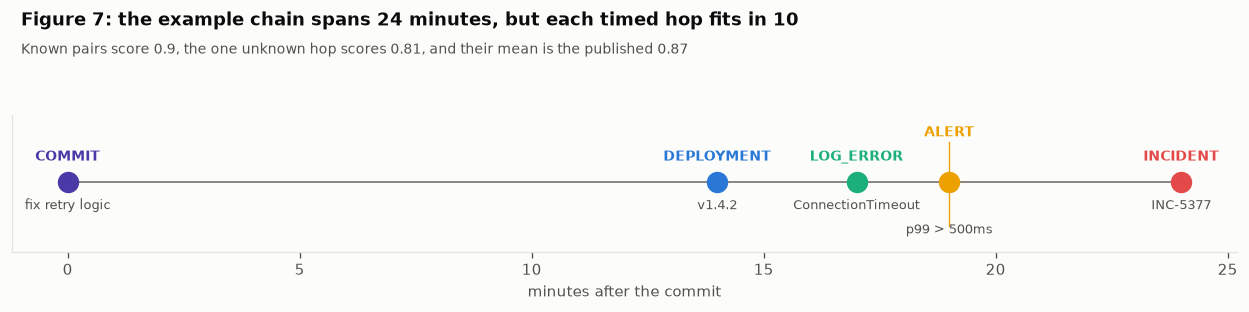

In [22]:
# ---- figure 7: the example chain, and the arithmetic that produces its 0.87 ----
FIG7_CHAIN = [("COMMIT", "fix retry logic", 0), ("DEPLOYMENT", "v1.4.2", 14), ("LOG_ERROR", "ConnectionTimeout", 3),
              ("ALERT", "p99 > 500ms", 2), ("INCIDENT", "INC-5377", 5)]
KNOWN_PAIRS = {("DEPLOYMENT", "LOG_ERROR"), ("CONFIG_CHANGE", "METRIC_ANOMALY"), ("ALERT", "INCIDENT"),
               ("TRACE_FAILED", "INCIDENT")}


def hop_score(a: str, b: str, minutes: float, severity: float, window: float = 10.0) -> float:
    """The post's rule: a known causal pair carries 0.9; any other hop is 0.6 x closeness in time + 0.4 x severity."""
    if (a, b) in KNOWN_PAIRS:
        return 0.9
    return 0.6 * max(0.0, 1 - minutes / window) + 0.4 * severity


hops = [(a[0], b[0], b[2]) for a, b in zip(FIG7_CHAIN[:-1], FIG7_CHAIN[1:])]
scores = [hop_score(a, b, m, severity=0.825) for a, b, m in hops if not (a == "COMMIT" and b == "DEPLOYMENT")]
print(f"  {'hop':<28}{'minutes':>8}{'score':>8}")
print("  " + "-" * 44)
for a, b, m in hops:
    lineage = a == "COMMIT"
    print(f"  {a + ' -> ' + b:<28}{m:>8}{('lineage' if lineage else f'{hop_score(a, b, m, 0.825):.3f}'):>8}")
print(f"\n  chain confidence = mean of the timed hops = {np.mean(scores):.3f}   (the post prints 0.87)")
print("  The commit took 14 minutes to reach production, longer than the 10-minute window, so that hop")
print("  can only come from lineage: the deploy contains the commit. Multiplying the hops instead of")
print(f"  averaging them gives {np.prod(scores):.3f}, so the 0.87 cannot be a probability. Section 26 tests this.")

fig, ax = plt.subplots(figsize=(10.5, 2.7))
xs = np.cumsum([0] + [c[2] for c in FIG7_CHAIN[1:]])
for i, ((kind, what, _), x, col) in enumerate(zip(FIG7_CHAIN, xs, [C7, C1, C3, C4, C8])):
    up = i == 3                                    # the alert sits two minutes after the error: stagger its labels
    ax.scatter(x, 0, s=140, color=col, zorder=3)
    ax.text(x, 0.75 if up else 0.35, kind, ha="center", fontsize=8.5, weight="bold", color=col)
    ax.text(x, -0.85 if up else -0.45, what, ha="center", fontsize=8, color=INK2)
    if up:
        ax.plot([x, x], [0.12, 0.66], color=col, lw=0.8)
        ax.plot([x, x], [-0.12, -0.72], color=col, lw=0.8)
ax.plot(xs, [0] * len(xs), color=MUTED, lw=1.2, zorder=1)
ax.set_ylim(-1.15, 1.1)
ax.set_yticks([])
ax.set_xlabel("minutes after the commit")
ax.grid(False)
finish(fig, "netflix_fig7_chain", "Figure 7: the example chain spans 24 minutes, but each timed hop fits in 10",
       "Known pairs score 0.9, the one unknown hop scores 0.81, and their mean is the published 0.87")

[fig] artifacts\figures_full\netflix_fig8_flywheel.png


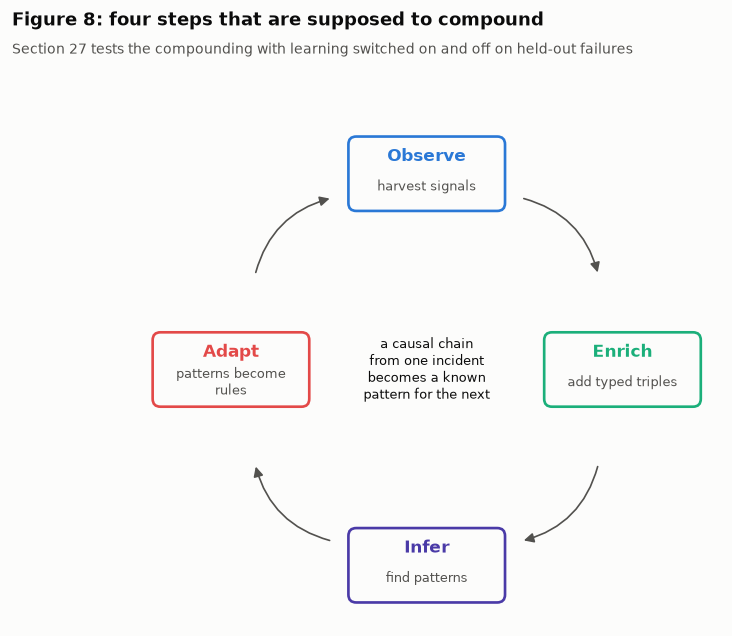

In [23]:
# ---- figure 8: the knowledge flywheel ----
fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.set_aspect("equal")
ax.axis("off")
steps = [("Observe", "harvest signals", C1), ("Enrich", "add typed triples", C3), ("Infer", "find patterns", C7),
         ("Adapt", "patterns become\nrules", C8)]
R = 2.0
for i, (name, what, col) in enumerate(steps):
    ang = math.pi / 2 - i * math.pi / 2
    x, y = R * math.cos(ang), R * math.sin(ang)
    ax.add_patch(FancyBboxPatch((x - 0.78, y - 0.36), 1.56, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=SURF, ec=col, lw=1.6))
    ax.text(x, y + 0.13, name, ha="center", fontsize=10, weight="bold", color=col)
    ax.text(x, y - 0.13, what, ha="center", va="center", fontsize=7.6, color=INK2)
    a2 = ang - math.pi / 2
    ax.add_patch(FancyArrowPatch((R * math.cos(ang - 0.5), R * math.sin(ang - 0.5)),
                                 (R * math.cos(a2 + 0.5), R * math.sin(a2 + 0.5)),
                                 connectionstyle="arc3,rad=-0.3", arrowstyle="-|>", mutation_scale=12, color=INK2))
ax.text(0, 0, "a causal chain\nfrom one incident\nbecomes a known\npattern for the next", ha="center", va="center",
        fontsize=8, color=INK)
ax.set_xlim(-3.0, 3.0)
ax.set_ylim(-2.6, 2.6)
finish(fig, "netflix_fig8_flywheel", "Figure 8: four steps that are supposed to compound",
       "Section 27 tests the compounding with learning switched on and off on held-out failures")

[fig] artifacts\figures_full\netflix_fig9_dikw.png


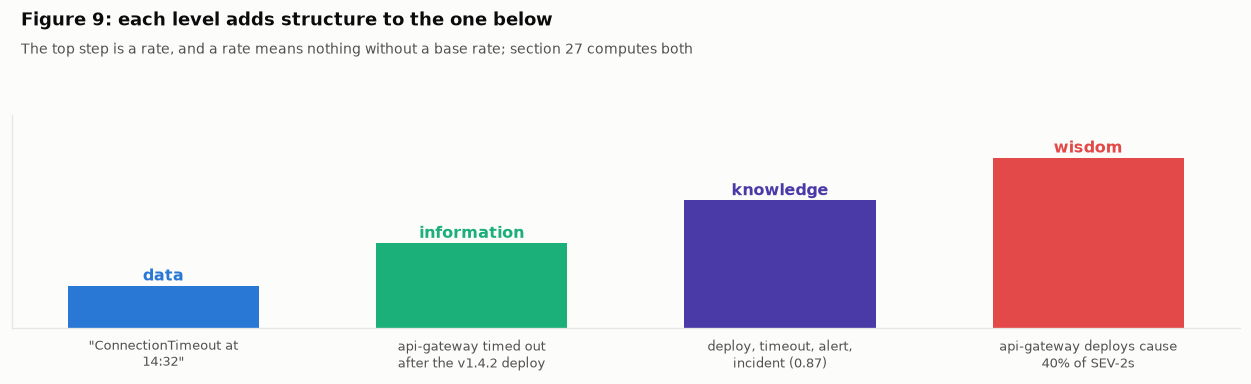

    sparql> SELECT ?svc (COUNT(?c) AS ?n)
    sparql> WHERE { ?c corr:rootCauseType "DEPLOYMENT" .
    sparql>         ?c corr:affectsService ?svc .
    sparql>         ?c corr:confidence ?v .
    sparql>         FILTER(?v > 0.7) }
    sparql> GROUP BY ?svc ORDER BY DESC(?n)

  It counts chains, not incidents: an incident explained by three candidate chains is counted three times.


In [24]:
# ---- figure 9: from data to wisdom, and the query that is supposed to surface it ----
FIG9 = [("data", '"ConnectionTimeout at 14:32"'), ("information", "api-gateway timed out after the v1.4.2 deploy"),
        ("knowledge", "deploy, timeout, alert, incident (0.87)"), ("wisdom", "api-gateway deploys cause 40% of SEV-2s")]
fig, ax = plt.subplots(figsize=(10.5, 3.3))
for i, (lvl, ex) in enumerate(FIG9):
    ax.bar(i, i + 1, color=[C1, C3, C7, C8][i], width=0.62)
    ax.text(i, i + 1.12, lvl, ha="center", fontsize=9.5, weight="bold", color=[C1, C3, C7, C8][i])
ax.set_xticks(range(4))
ax.set_xticklabels([textwrap.fill(ex, 26) for _, ex in FIG9], fontsize=8, color=INK2)
ax.tick_params(axis="x", length=0, pad=6)
ax.set_ylim(0, 5.0)
ax.set_yticks([])
ax.grid(False)
finish(fig, "netflix_fig9_dikw", "Figure 9: each level adds structure to the one below",
       "The top step is a rate, and a rate means nothing without a base rate; section 27 computes both")
FIG9_SPARQL = """SELECT ?svc (COUNT(?c) AS ?n)
WHERE { ?c corr:rootCauseType "DEPLOYMENT" .
        ?c corr:affectsService ?svc .
        ?c corr:confidence ?v .
        FILTER(?v > 0.7) }
GROUP BY ?svc ORDER BY DESC(?n)"""
print(textwrap.indent(FIG9_SPARQL, "    sparql> "))
print("\n  It counts chains, not incidents: an incident explained by three candidate chains is counted three times.")

[fig] artifacts\figures_full\netflix_fig10_autorca.png


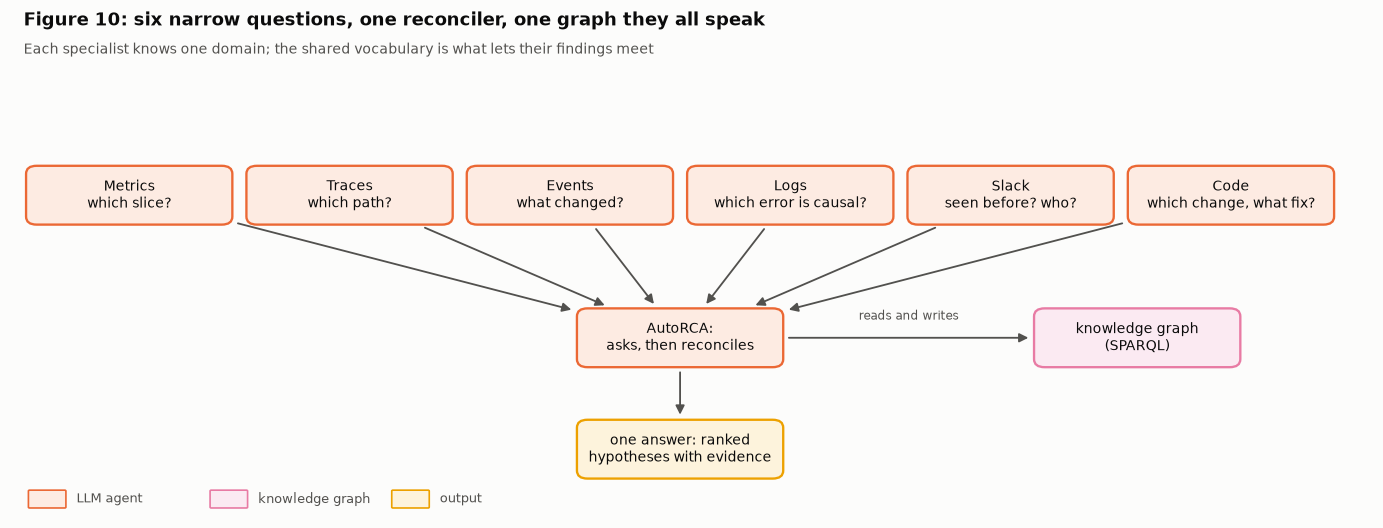

In [25]:
# ---- figure 10: AutoRCA, six specialists and one question ----
SPEC = ["Metrics\nwhich slice?", "Traces\nwhich path?", "Events\nwhat changed?", "Logs\nwhich error is causal?",
        "Slack\nseen before? who?", "Code\nwhich change, what fix?"]
AUTO_NODES = {f"s{i}": (1.0 + i * 1.88, 3.6, s, "llm") for i, s in enumerate(SPEC)}
AUTO_NODES.update({"rca": (5.7, 2.0, "AutoRCA:\nasks, then reconciles", "llm"),
                   "kg": (9.6, 2.0, "knowledge graph\n(SPARQL)", "graph"),
                   "ans": (5.7, 0.75, "one answer: ranked\nhypotheses with evidence", "output")})
AUTO_EDGES = [(f"s{i}", "rca", None) for i in range(6)] + [("rca", "kg", "reads and writes", None, (0, 0.05)),
                                                           ("rca", "ans", None)]
draw_flow(AUTO_NODES, AUTO_EDGES, "netflix_fig10_autorca",
          "Figure 10: six narrow questions, one reconciler, one graph they all speak",
          "Each specialist knows one domain; the shared vocabulary is what lets their findings meet",
          size=(11.6, 4.5), box=(1.72, 0.62))

**Ten figures, and three of them already disagree with themselves.** Figure 5 stores a
confidence as text, which breaks the query in figure 9. Figure 7's 0.87 can only come from
averaging hops in which the known pairs are pinned at 0.9; multiplying them, as you would for
a probability, gives a smaller number. And figure 9's query counts chains rather than incidents.
None of this makes the design wrong. It does mean that a faithful rebuild has to choose where
the post is silent, and every one of those choices is marked as ours when we make it.

## 2 · The ideas you need, in six small pictures

**Theory.** Six ideas carry the whole notebook, and each is easier to see on a handful of
facts than to read about. A triple is one fact: subject, predicate, object. An ontology says
which kinds of things exist and which facts may connect them. OWL lets a reasoner add facts
that follow from the ones you wrote; SHACL refuses facts that break the rules; the difference
between adding and refusing turns out to matter a great deal. SPARQL asks questions of the
facts. MELT is the four shapes operational data comes in. And a root-cause answer has to be
scored, which is less obvious than it sounds when the answer is a ranked list. Each picture
below runs on three to seven facts, using the same libraries the rest of the notebook uses.

  6 triples, written as Turtle:

    @prefix : <https://kg.example.org/id/> .
    @prefix ops: <https://kg.example.org/ops#> .

    :INC-5377 a ops:Incident ;
        ops:affects :api-gateway ;
        ops:severity "SEV 2" .

    :api-gateway a ops:Application ;
        ops:deployedIn "us-east-1" ;
        ops:ownedBy "Team Bedrock" .


[fig] artifacts\figures_full\primer_triples.png


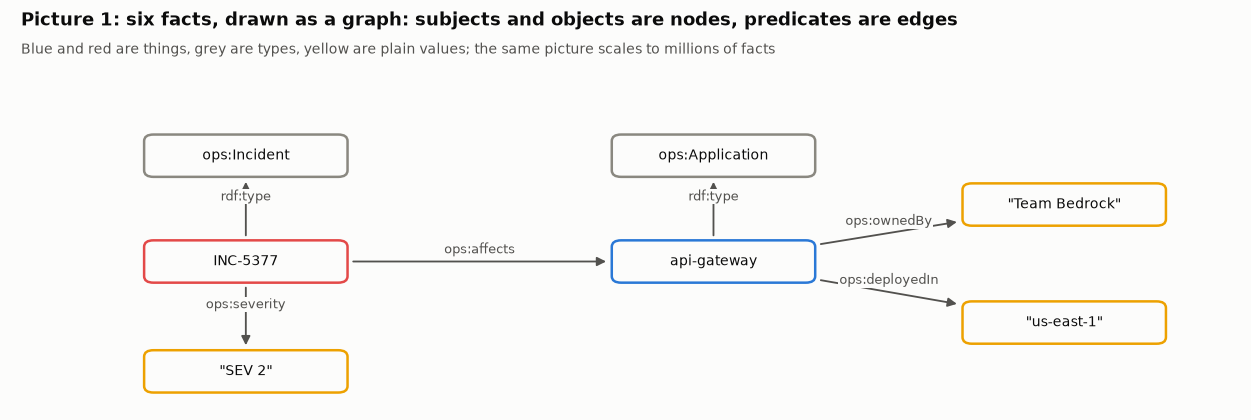

In [26]:
# ---- picture 1: a triple is one fact; six of them answer a question that needed three tools ----
import rdflib
from rdflib import RDF, RDFS, XSD, Literal, Namespace, URIRef

BASE = "https://kg.example.org/"
OPS, ID = Namespace(BASE + "ops#"), Namespace(BASE + "id/")
g = rdflib.Graph()
g.bind("ops", OPS)
g.bind("", ID)
for s, p, o in [(ID["api-gateway"], RDF.type, OPS.Application), (ID["api-gateway"], OPS.ownedBy, Literal("Team Bedrock")),
                (ID["api-gateway"], OPS.deployedIn, Literal("us-east-1")), (ID["INC-5377"], RDF.type, OPS.Incident),
                (ID["INC-5377"], OPS.affects, ID["api-gateway"]), (ID["INC-5377"], OPS.severity, Literal("SEV 2"))]:
    g.add((s, p, o))
print(f"  {len(g)} triples, written as Turtle:\n")
print(textwrap.indent(g.serialize(format="turtle").strip(), "    "))

fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.axis("off")
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 3.6)
nodes = {"inc": (2.0, 1.8, "INC-5377", C8), "app": (6.0, 1.8, "api-gateway", C1), "ti": (2.0, 3.1, "ops:Incident", MUTED),
         "ta": (6.0, 3.1, "ops:Application", MUTED), "sev": (2.0, 0.45, '"SEV 2"', C4), "own": (9.0, 2.5, '"Team Bedrock"', C4),
         "dc": (9.0, 1.05, '"us-east-1"', C4)}
for k, (x, y, lab, col) in nodes.items():
    ax.add_patch(FancyBboxPatch((x - 0.85, y - 0.24), 1.7, 0.48, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=SURF, ec=col, lw=1.5))
    ax.text(x, y, lab, ha="center", va="center", fontsize=8.6, color=INK)
for a, b, lab in [("inc", "app", "ops:affects"), ("inc", "ti", "rdf:type"), ("app", "ta", "rdf:type"),
                  ("inc", "sev", "ops:severity"), ("app", "own", "ops:ownedBy"), ("app", "dc", "ops:deployedIn")]:
    (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
    p1 = _border_point(x1, y1, x2 - x1, y2 - y1, 1.78, 0.56)
    p2 = _border_point(x2, y2, x1 - x2, y1 - y2, 1.78, 0.56)
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=11, color=INK2, lw=1.1))
    ax.text((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2 + 0.1, lab, ha="center", fontsize=7.6, color=INK2,
            bbox=dict(fc=SURF, ec="none", pad=0.5))
finish(fig, "primer_triples", "Picture 1: six facts, drawn as a graph: subjects and objects are nodes, predicates are edges",
       "Blue and red are things, grey are types, yellow are plain values; the same picture scales to millions of facts")

  the ontology (concepts): 9 triples about 4 terms
    ops:Application        is a owl:Class
    ops:Incident           is a owl:Class
    ops:affects            is a owl:ObjectProperty
    ops:ownedBy            is a owl:DatatypeProperty

  the data (instances): 6 triples about 2 things
  The two live apart on purpose: the concepts change when people agree to change them,
  the instances change every time a harvest runs.
[fig] artifacts\figures_full\primer_ontology.png


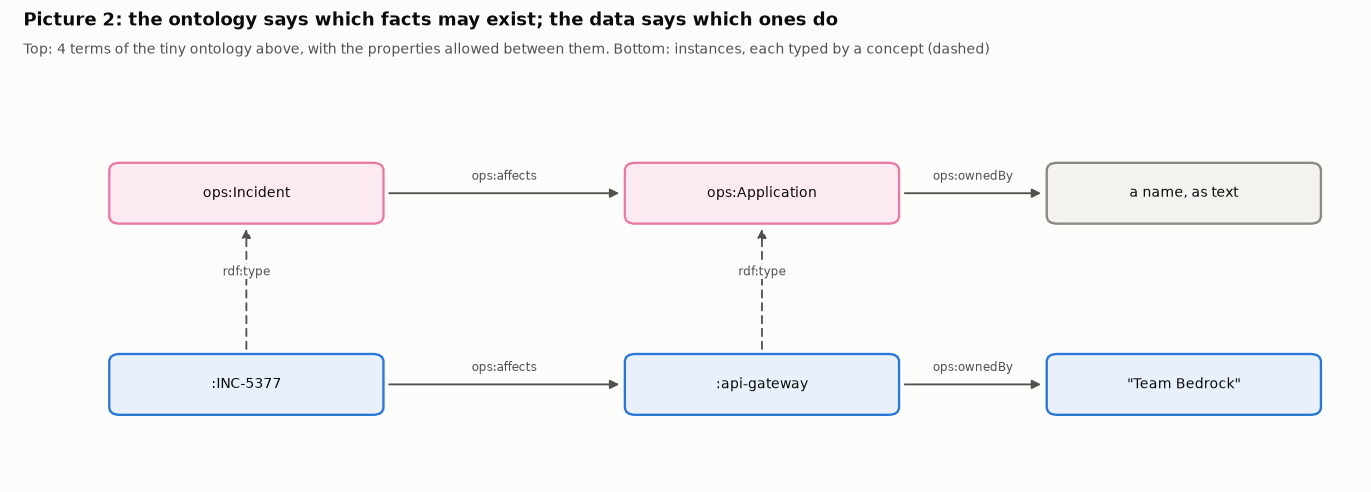

In [27]:
# ---- picture 2: an ontology is a promise about which facts may exist ----
TBOX = """
@prefix ops:  <https://kg.example.org/ops#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix owl:  <http://www.w3.org/2002/07/owl#> .
ops:Application a owl:Class ; rdfs:comment "a deployable service, validated against the catalogue" .
ops:Incident    a owl:Class ; rdfs:comment "an episode of user-visible harm" .
ops:affects     a owl:ObjectProperty ; rdfs:domain ops:Incident ; rdfs:range ops:Application .
ops:ownedBy     a owl:DatatypeProperty ; rdfs:domain ops:Application .
"""
tbox = rdflib.Graph().parse(data=TBOX, format="turtle")
print(f"  the ontology (concepts): {len(tbox)} triples about {len(set(tbox.subjects(RDF.type, None)))} terms")
for s, _, o in sorted(tbox.triples((None, RDF.type, None))):
    print(f"    {s.n3(tbox.namespace_manager):<22} is a {o.n3(tbox.namespace_manager)}")
print(f"\n  the data (instances): {len(g)} triples about 2 things")
print("  The two live apart on purpose: the concepts change when people agree to change them,")
print("  the instances change every time a harvest runs.")

P2_NODES = {
    "Incident": (2.0, 3.3, "ops:Incident", "graph"), "Application": (6.4, 3.3, "ops:Application", "graph"),
    "team": (10.0, 3.3, "a name, as text", "step"),
    "inc": (2.0, 1.1, ":INC-5377", "data"), "app": (6.4, 1.1, ":api-gateway", "data"),
    "bedrock": (10.0, 1.1, '"Team Bedrock"', "data"),
}
P2_EDGES = [("Incident", "Application", "ops:affects"), ("Application", "team", "ops:ownedBy"),
            ("inc", "app", "ops:affects"), ("app", "bedrock", "ops:ownedBy"),
            ("inc", "Incident", "rdf:type", "dashed"), ("app", "Application", "rdf:type", "dashed")]
draw_flow(P2_NODES, P2_EDGES, "primer_ontology",
          "Picture 2: the ontology says which facts may exist; the data says which ones do",
          f"Top: {len(set(tbox.subjects(RDF.type, None)))} terms of the tiny ontology above, with the properties allowed "
          "between them. Bottom: instances, each typed by a concept (dashed)", size=(11.5, 4.2), box=(2.3, 0.66),
          legend=False)

  after RDFS inference, is the scraped typo ':zuul-gatway' an Application?  True
  type check, no inference                       conforms=False  flagged ['INC-5378']
  type check after inference                     conforms=True   flagged []
  type check + catalogue gate, after inference   conforms=False  flagged ['zuul-gatway']

  The reasoner reads 'an incident affects an application' as a rule for drawing conclusions, so
  it concludes the typo IS an application. Only a closed-world check that every application
  carries a catalogue id catches it. That is the mechanism behind the post's catalogue gate.


[fig] artifacts\figures_full\primer_owl_shacl.png


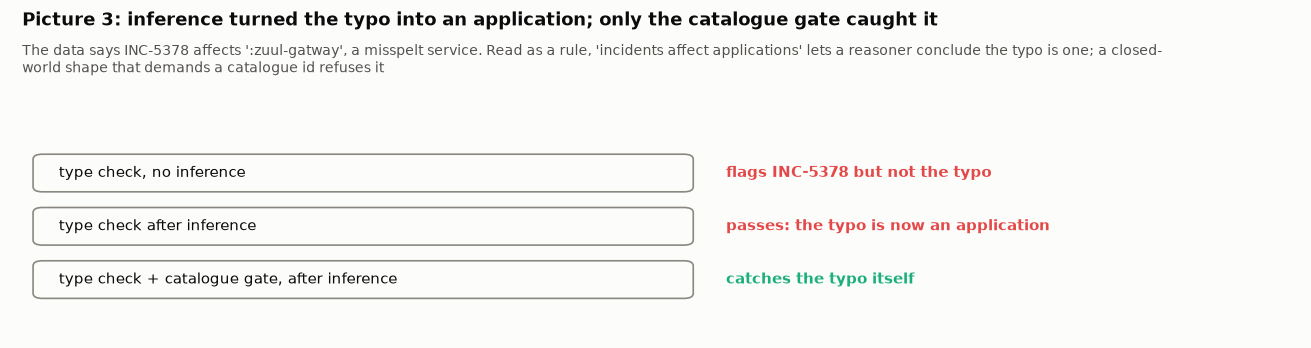

In [28]:
# ---- picture 3: OWL adds facts, SHACL refuses them; a scraped typo shows why both are needed ----
import owlrl
from pyshacl import validate as shacl_validate

DATA3 = """
@prefix ops: <https://kg.example.org/ops#> .
@prefix :    <https://kg.example.org/id/> .
:api-gateway a ops:Application ; ops:catalogId "app-00017" .
:INC-5377 a ops:Incident ; ops:affects :api-gateway .
:INC-5378 a ops:Incident ; ops:affects :zuul-gatway .
"""
SHAPES3 = """
@prefix sh:  <http://www.w3.org/ns/shacl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix ops: <https://kg.example.org/ops#> .
@prefix :    <https://kg.example.org/id/> .
:AffectsAnApplication a sh:NodeShape ; sh:targetClass ops:Incident ;
    sh:property [ sh:path ops:affects ; sh:class ops:Application ] .
:CatalogueGate a sh:NodeShape ; sh:targetClass ops:Application ;
    sh:property [ sh:path ops:catalogId ; sh:minCount 1 ; sh:datatype xsd:string ] .
"""
data3 = rdflib.Graph().parse(data=DATA3, format="turtle")
closure = rdflib.Graph().parse(data=DATA3, format="turtle") + tbox
owlrl.DeductiveClosure(owlrl.RDFS_Semantics).expand(closure)
junk = ID["zuul-gatway"]
print(f"  after RDFS inference, is the scraped typo ':zuul-gatway' an Application?  "
      f"{(junk, RDF.type, OPS.Application) in closure}")
shapes_only_class = SHAPES3.split(":CatalogueGate")[0]
rows3 = []
for label, shapes, inference in [("type check, no inference", shapes_only_class, "none"),
                                 ("type check after inference", shapes_only_class, "rdfs"),
                                 ("type check + catalogue gate, after inference", SHAPES3, "rdfs")]:
    conforms, report, _ = shacl_validate(data3, shacl_graph=rdflib.Graph().parse(data=shapes, format="turtle"),
                                         ont_graph=tbox, inference=inference)
    focus = sorted({str(o).rsplit("/", 1)[-1] for o in report.objects(None, URIRef("http://www.w3.org/ns/shacl#focusNode"))})
    rows3.append((label, conforms, focus))
    print(f"  {label:<46} conforms={conforms!s:<6} flagged {focus}")
print("\n  The reasoner reads 'an incident affects an application' as a rule for drawing conclusions, so")
print("  it concludes the typo IS an application. Only a closed-world check that every application")
print("  carries a catalogue id catches it. That is the mechanism behind the post's catalogue gate.")

invented = (junk, RDF.type, OPS.Application) in closure
fig, ax = plt.subplots(figsize=(11, 3.0))
ax.axis("off")
ax.set_xlim(0, 11)
ax.set_ylim(0, 3.2)
for i, (label, conforms, focus) in enumerate(rows3):
    y = 2.6 - i * 0.85
    caught = "zuul-gatway" in focus
    ax.add_patch(FancyBboxPatch((0.2, y - 0.28), 5.6, 0.56, boxstyle="round,pad=0.02,rounding_size=0.08", fc=SURF,
                                ec=MUTED, lw=1))
    ax.text(0.4, y, label, va="center", fontsize=9, color=INK)
    verdict = ("catches the typo itself" if caught else f"flags {', '.join(focus)} but not the typo" if focus
               else "passes: the typo is now an application")
    ax.text(6.1, y, verdict, va="center", fontsize=9, color=C3 if caught else C8, weight="bold")
finish(fig, "primer_owl_shacl", "Picture 3: inference turned the typo into an application; only the catalogue gate "
       "caught it" if invented else "Picture 3: three ways to check one scraped typo",
       "The data says INC-5378 affects ':zuul-gatway', a misspelt service. Read as a rule, 'incidents affect applications' "
       "lets a reasoner conclude the typo is one; a closed-world shape that demands a catalogue id refuses it")

    sparql> PREFIX ops: <https://kg.example.org/ops#>
    sparql> SELECT ?incident ?severity WHERE {
    sparql>   ?incident a ops:Incident ; ops:affects ?app ; ops:severity ?severity .
    sparql>   ?app ops:ownedBy "Team Bedrock" ; ops:deployedIn "us-east-1" .
    sparql> }

  rdflib    -> [('INC-5377', 'SEV 2')]   (33.7 ms)
  Oxigraph  -> [('INC-5377', 'SEV 2')]   (1.8 ms)
  [test] same answer from both engines -> PASS


[fig] artifacts\figures_full\primer_sparql.png


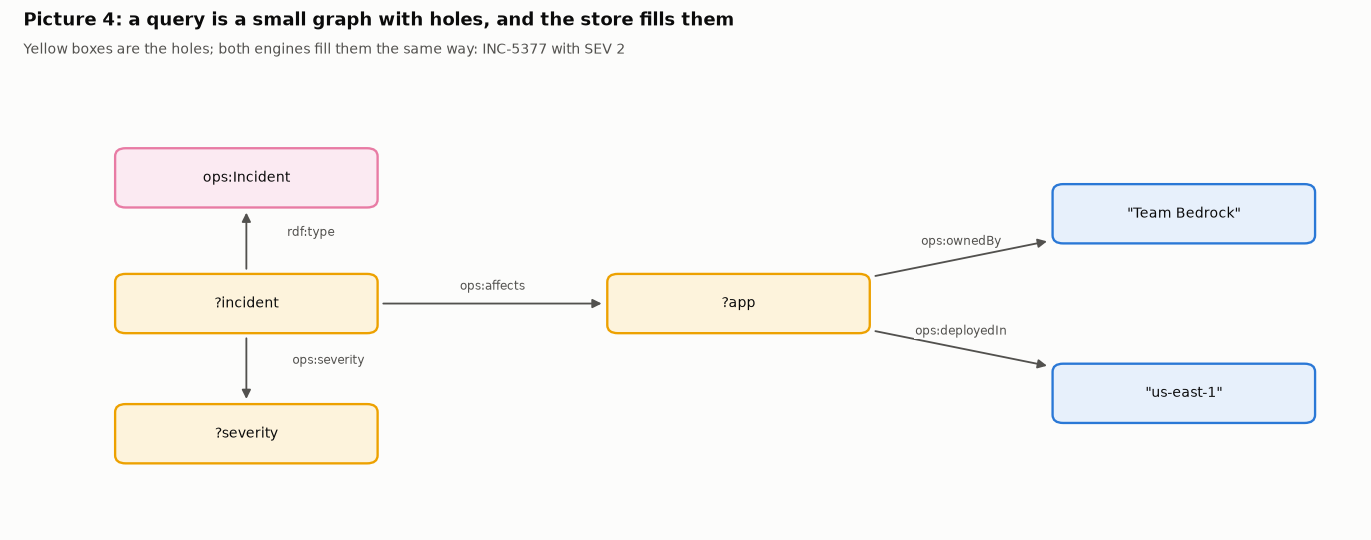

In [29]:
# ---- picture 4: one SPARQL question, two engines, the same answer ----
import pyoxigraph as ox

Q4 = """PREFIX ops: <https://kg.example.org/ops#>
SELECT ?incident ?severity WHERE {
  ?incident a ops:Incident ; ops:affects ?app ; ops:severity ?severity .
  ?app ops:ownedBy "Team Bedrock" ; ops:deployedIn "us-east-1" .
}"""
store4 = ox.Store()
store4.load(g.serialize(format="nt").encode(), format=ox.RdfFormat.N_TRIPLES)
t0 = time.perf_counter()
r_rdflib = [(str(r.incident).rsplit("/", 1)[-1], str(r.severity)) for r in g.query(Q4)]
t1 = time.perf_counter()
r_ox = [(s["incident"].value.rsplit("/", 1)[-1], s["severity"].value) for s in store4.query(Q4)]
t2 = time.perf_counter()
print(textwrap.indent(Q4, "    sparql> "))
print(f"\n  rdflib    -> {r_rdflib}   ({(t1 - t0) * 1000:.1f} ms)")
print(f"  Oxigraph  -> {r_ox}   ({(t2 - t1) * 1000:.1f} ms)")
print(f"  [test] same answer from both engines -> {'PASS' if r_rdflib == r_ox else 'FAIL'}")

P4_NODES = {"type": (2.0, 3.9, "ops:Incident", "graph"), "inc": (2.0, 2.5, "?incident", "output"),
            "sev": (2.0, 1.05, "?severity", "output"), "app": (6.2, 2.5, "?app", "output"),
            "team": (10.0, 3.5, '"Team Bedrock"', "data"), "dc": (10.0, 1.5, '"us-east-1"', "data")}
P4_EDGES = [("inc", "type", "rdf:type", None, (0.55, -0.1)), ("inc", "sev", "ops:severity", None, (0.7, -0.1)), ("inc", "app", "ops:affects"),
            ("app", "team", "ops:ownedBy"), ("app", "dc", "ops:deployedIn")]
draw_flow(P4_NODES, P4_EDGES, "primer_sparql", "Picture 4: a query is a small graph with holes, and the store fills them",
          f"Yellow boxes are the holes; both engines fill them the same way: " + "; ".join(f"{i} with {s}" for i, s in r_ox), size=(11.5, 4.6),
          box=(2.2, 0.62), legend=False)

  shape   source           when                  who         what
  ------------------------------------------------------------------------------------------------------------------------
  metric  OpenRCA market   2022-03-20 06:52 UTC  node-2      system.disk.free = 3.16e9
  event   Wikimedia SAL    2025-11-30 22:46 UTC  deploy2002  helmfile [codfw] DONE helmfile.d/services/wikifunctions: apply
  log     OpenRCA bank     2021-03-05 10:32 UTC  Tomcat03    POST /UOCP/base/ServiceTest6.json HTTP/1.1 200 403
  trace   OpenRCA telecom  2020-05-28 13:49 UTC  docker_003  JDBC call to db_009, 0.0 ms, success

  A metric is a number on a clock, an event is a change someone made, a log line is what a program
  said, and a span is one hop of one request. Section 25 turns all four into the same kind of signal.


[fig] artifacts\figures_full\primer_melt.png


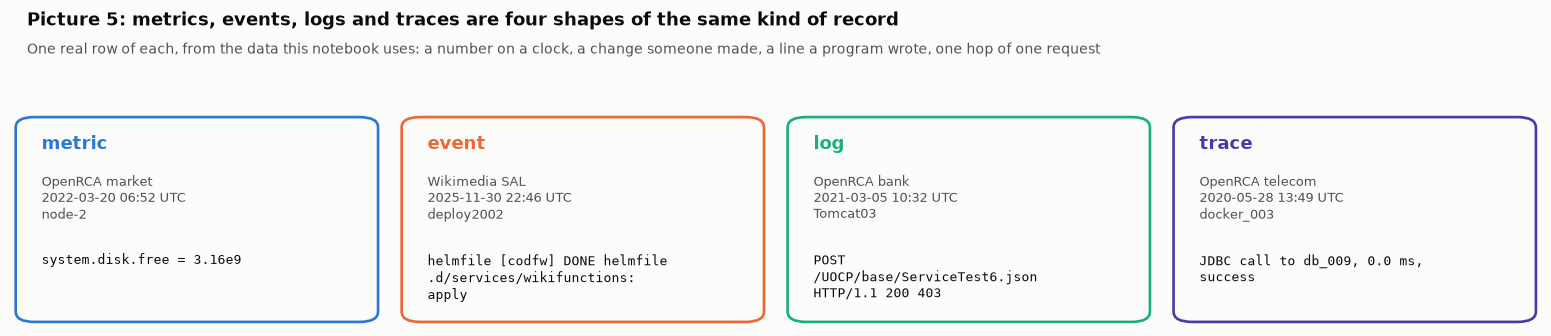

In [30]:
# ---- picture 5: MELT, one real row of each shape ----
MELT_EXAMPLES = [
    ("metric", "OpenRCA market", "2022-03-20 06:52 UTC", "node-2", "system.disk.free = 3.16e9"),
    ("event", "Wikimedia SAL", "2025-11-30 22:46 UTC", "deploy2002",
     "helmfile [codfw] DONE helmfile.d/services/wikifunctions: apply"),
    ("log", "OpenRCA bank", "2021-03-05 10:32 UTC", "Tomcat03", "POST /UOCP/base/ServiceTest6.json HTTP/1.1 200 403"),
    ("trace", "OpenRCA telecom", "2020-05-28 13:49 UTC", "docker_003", "JDBC call to db_009, 0.0 ms, success"),
]
print(f"  {'shape':<8}{'source':<17}{'when':<22}{'who':<12}what")
print("  " + "-" * 120)
for row in MELT_EXAMPLES:
    print(f"  {row[0]:<8}{row[1]:<17}{row[2]:<22}{row[3]:<12}{row[4]}")
print("\n  A metric is a number on a clock, an event is a change someone made, a log line is what a program")
print("  said, and a span is one hop of one request. Section 25 turns all four into the same kind of signal.")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, (shape, src, when, who, what), colour in zip(axes, MELT_EXAMPLES, (C1, C2, C3, C7)):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.02, 0.02), 0.96, 0.96, boxstyle="round,pad=0.01,rounding_size=0.05", fc=SURF,
                                ec=colour, lw=1.6, transform=ax.transAxes))
    ax.text(0.08, 0.86, shape, fontsize=11, color=colour, weight="bold", transform=ax.transAxes, va="center")
    ax.text(0.08, 0.72, f"{src}\n{when}\n{who}", fontsize=8, color=INK2, va="top", transform=ax.transAxes)
    ax.text(0.08, 0.34, textwrap.fill(what, 30), fontsize=8, color=INK, va="top", family="monospace",
            transform=ax.transAxes)
finish(fig, "primer_melt", "Picture 5: metrics, events, logs and traces are four shapes of the same kind of record",
       "One real row of each, from the data this notebook uses: a number on a clock, a change someone made, a line a program "
       "wrote, one hop of one request")

  AC@1 = 0.33   ##########
  AC@2 = 0.33   ##########
  AC@3 = 0.33   ##########
  AC@4 = 0.67   ####################
  AC@5 = 0.67   ####################
  Avg@5 = 0.47

  OpenRCA scores differently: each task lists scoring points (the component, the reason, the time
  within a minute), a prediction earns the share of points it gets right, and 'strict' counts only
  tasks where every point is right. A guess of the right pod with the wrong reason earns 0.5, strict 0.
[fig] artifacts\figures_full\primer_scoring.png


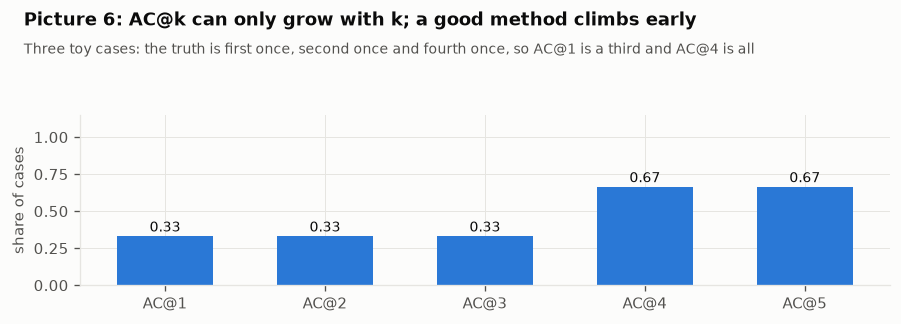

In [31]:
# ---- picture 6: how a root-cause answer is scored ----
TOY_TRUTH = ["cartservice", "redis", "frontend"]
TOY_RANKED = [["cartservice", "frontend", "redis", "adservice", "currency"],
              ["frontend", "cartservice", "currency", "redis", "adservice"],
              ["adservice", "currency", "redis", "cartservice", "emailservice"]]


def ac_at_k(ranked: list[list[str]], truth: list[str], k: int) -> float:
    """Share of cases whose true root cause is among the first k guesses."""
    return float(np.mean([t in r[:k] for r, t in zip(ranked, truth)]))


def avg_at_k(ranked: list[list[str]], truth: list[str], k: int) -> float:
    """Mean of AC@1..AC@k: rewards putting the truth near the top, not merely somewhere."""
    return float(np.mean([ac_at_k(ranked, truth, j) for j in range(1, k + 1)]))


acs = [ac_at_k(TOY_RANKED, TOY_TRUTH, k) for k in range(1, 6)]
for k, v in enumerate(acs, 1):
    print(f"  AC@{k} = {v:.2f}   {'#' * int(v * 30)}")
print(f"  Avg@5 = {avg_at_k(TOY_RANKED, TOY_TRUTH, 5):.2f}")
print("\n  OpenRCA scores differently: each task lists scoring points (the component, the reason, the time")
print("  within a minute), a prediction earns the share of points it gets right, and 'strict' counts only")
print("  tasks where every point is right. A guess of the right pod with the wrong reason earns 0.5, strict 0.")
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.bar(range(1, 6), acs, color=C1, width=0.6)
for k, v in enumerate(acs, 1):
    ax.text(k, v + 0.03, f"{v:.2f}", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(range(1, 6))
ax.set_xticklabels([f"AC@{k}" for k in range(1, 6)])
ax.set_ylim(0, 1.15)
ax.set_ylabel("share of cases")
finish(fig, "primer_scoring", "Picture 6: AC@k can only grow with k; a good method climbs early",
       "Three toy cases: the truth is first once, second once and fourth once, so AC@1 is a third and AC@4 is all")

**Six pictures, and the third one is the reason the rest of the notebook is built the way it
is.** A reasoner that sees "an incident affects an application" concludes that whatever the
incident affects must be an application, so a scraped typo becomes a service and passes every
type check. The catalogue gate, a closed-world rule that an application must carry an id from
the authoritative list, is what stops it. We will meet the same mechanism on real Wikimedia
names in section 13.

## 3 · Why real data, and which data

**Theory.** Synthetic data lets you decide the answer before you ask the question, which is
useful for checking code and useless for testing a design: a generator built by the same
person who built the system tends to produce exactly the failures the system handles well.
Real data argues back. Its names are inconsistent, its clocks disagree, its incidents are
written up by tired people, and its root causes are sometimes unknown. No single public source
has everything Netflix describes, so we use four and say exactly what each can and cannot
test. A claim that no source can reach is reported as NOT TESTABLE; it is never quietly
counted as a pass.

In [32]:
# ---- the four sources, side by side ----
SOURCES = [
    ("Wikimedia operations record", "Slack, Spinnaker, Radar, incident.io",
     "on-call chat, deploy log, alerts, incident reports, code reviews, catalogue", "2021 to today"),
    ("Wikipedia pageviews", "the users' layer of figure 1", "human pageviews per wiki per hour; one week per page",
     "2015 to today"),
    ("OpenRCA", "telemetry with exact answers", "metrics, logs, traces from a bank, a telecom and an e-commerce site",
     "2020 to 2022"),
    ("RCAEval", "repeatable lab failures", "metrics, logs, traces from three microservice apps, 360 injected faults",
     "2023 to 2024"),
]
for name, plays, what, span in SOURCES:
    print(f"  {name:<30}plays {plays}")
    print(f"  {'':<30}{what}  ({span})\n")

  Wikimedia operations record   plays Slack, Spinnaker, Radar, incident.io
                                on-call chat, deploy log, alerts, incident reports, code reviews, catalogue  (2021 to today)

  Wikipedia pageviews           plays the users' layer of figure 1
                                human pageviews per wiki per hour; one week per page  (2015 to today)

  OpenRCA                       plays telemetry with exact answers
                                metrics, logs, traces from a bank, a telecom and an e-commerce site  (2020 to 2022)

  RCAEval                       plays repeatable lab failures
                                metrics, logs, traces from three microservice apps, 360 injected faults  (2023 to 2024)



[fig] artifacts\figures_full\coverage_matrices.png


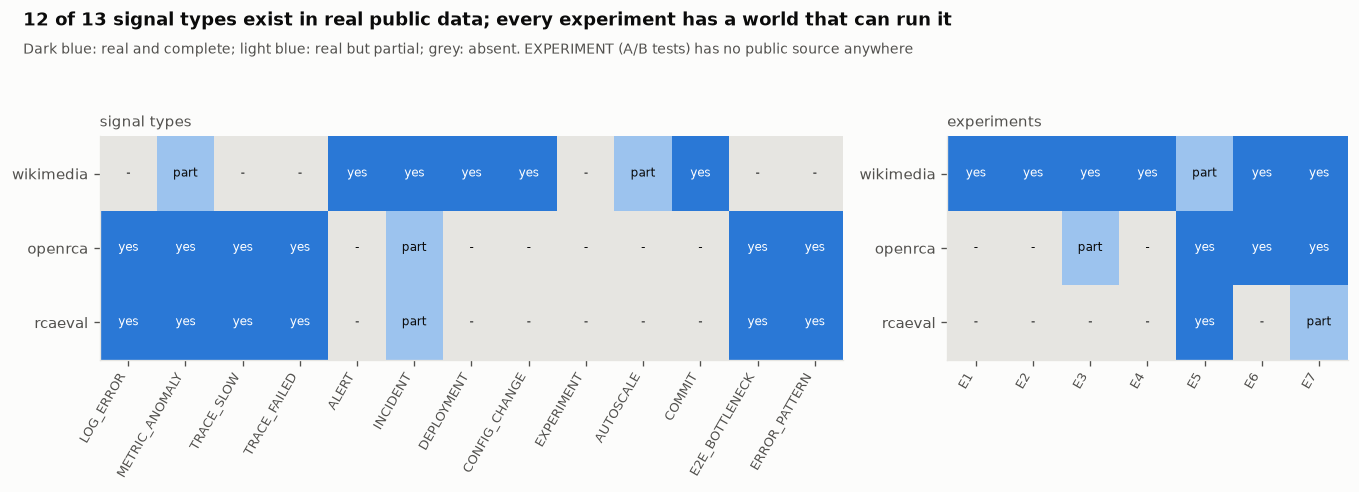

In [33]:
# ---- what each world can test: thirteen signal types and seven experiments ----
SIGNAL_TYPES = ["LOG_ERROR", "METRIC_ANOMALY", "TRACE_SLOW", "TRACE_FAILED", "ALERT", "INCIDENT", "DEPLOYMENT",
                "CONFIG_CHANGE", "EXPERIMENT", "AUTOSCALE", "COMMIT", "E2E_BOTTLENECK", "ERROR_PATTERN"]
WORLDS = ["wikimedia", "openrca", "rcaeval"]
# 2 = real and complete, 1 = real but partial, 0 = absent
SIGNAL_COVERAGE = {
    "wikimedia": [0, 1, 0, 0, 2, 2, 2, 2, 0, 1, 2, 0, 0],   # metrics only for 15 days; capacity changes are manual
    "openrca":   [2, 2, 2, 2, 0, 1, 0, 0, 0, 0, 0, 2, 2],   # incidents are recorded failures, not tickets
    "rcaeval":   [2, 2, 2, 2, 0, 1, 0, 0, 0, 0, 0, 2, 2],
}
EXP_COVERAGE = {"wikimedia": [2, 2, 2, 2, 1, 2, 2], "openrca": [0, 0, 1, 0, 2, 2, 2], "rcaeval": [0, 0, 0, 0, 2, 0, 1]}
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2), gridspec_kw={"width_ratios": [13, 7]})
cmap = mpl.colors.ListedColormap([GRID, "#9cc3ee", C1])
for ax, cov, cols, title in ((axes[0], SIGNAL_COVERAGE, SIGNAL_TYPES, "signal types"),
                             (axes[1], EXP_COVERAGE, list(EXPERIMENTS), "experiments")):
    m = np.array([cov[w] for w in WORLDS])
    ax.imshow(m, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=7.6)
    ax.set_yticks(range(len(WORLDS)))
    ax.set_yticklabels(WORLDS)
    ax.set_title(title, fontsize=9, color=INK2, loc="left")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, {0: "-", 1: "part", 2: "yes"}[int(v)], ha="center", va="center", fontsize=7,
                color="white" if v == 2 else INK)
covered = sum(any(SIGNAL_COVERAGE[w][i] for w in WORLDS) for i in range(len(SIGNAL_TYPES)))
finish(fig, "coverage_matrices", f"{covered} of 13 signal types exist in real public data; every experiment has a world that can run it",
       "Dark blue: real and complete; light blue: real but partial; grey: absent. EXPERIMENT (A/B tests) has no public source anywhere")

In [34]:
# ---- the four known causal pairs of figure 7: which world holds both ends with real timing ----
for (a, b) in sorted(KNOWN_PAIRS):
    ia, ib = SIGNAL_TYPES.index(a), SIGNAL_TYPES.index(b)
    holders = [w for w in WORLDS if SIGNAL_COVERAGE[w][ia] and SIGNAL_COVERAGE[w][ib]]
    print(f"  {a + ' -> ' + b:<34}{', '.join(holders) if holders else 'NOT TESTABLE: no world has both ends'}")

  ALERT -> INCIDENT                 wikimedia
  CONFIG_CHANGE -> METRIC_ANOMALY   wikimedia
  DEPLOYMENT -> LOG_ERROR           NOT TESTABLE: no world has both ends
  TRACE_FAILED -> INCIDENT          openrca, rcaeval


[fig] artifacts\figures_full\data_flow.png


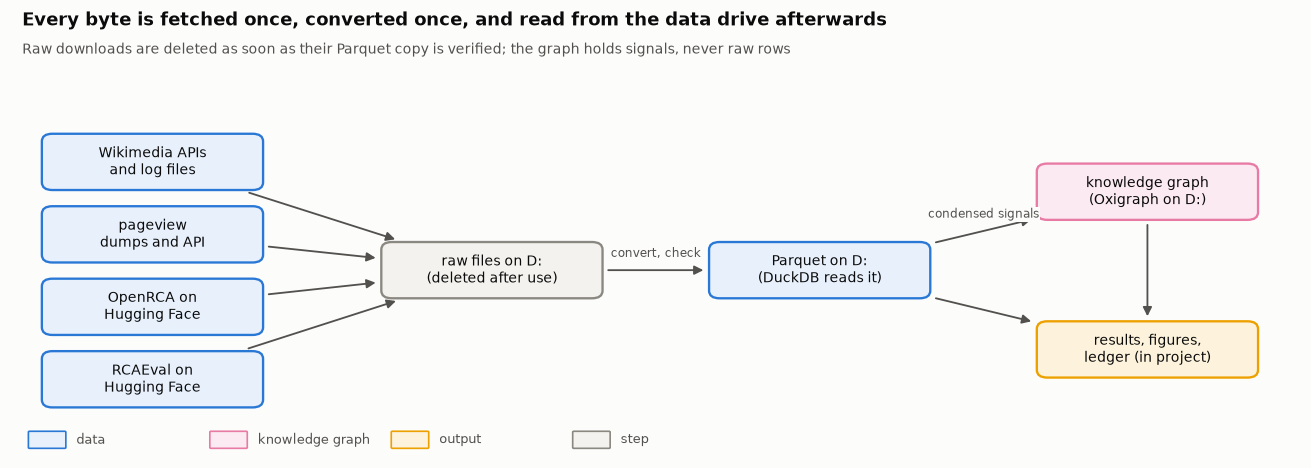

In [35]:
# ---- where every byte goes: from public endpoints to the data drive to the graph ----
FLOW_NODES = {
    "wm": (1.2, 3.45, "Wikimedia APIs\nand log files", "data"), "pv": (1.2, 2.6, "pageview\ndumps and API", "data"),
    "or": (1.2, 1.75, "OpenRCA on\nHugging Face", "data"), "re": (1.2, 0.9, "RCAEval on\nHugging Face", "data"),
    "raw": (4.1, 2.18, "raw files on D:\n(deleted after use)", "step"),
    "pq": (6.9, 2.18, "Parquet on D:\n(DuckDB reads it)", "data"),
    "kg": (9.7, 3.1, "knowledge graph\n(Oxigraph on D:)", "graph"),
    "res": (9.7, 1.25, "results, figures,\nledger (in project)", "output"),
}
draw_flow(FLOW_NODES, [("wm", "raw", None), ("pv", "raw", None), ("or", "raw", None), ("re", "raw", None),
                       ("raw", "pq", "convert, check"), ("pq", "kg", "condensed signals"), ("pq", "res", None),
                       ("kg", "res", None)],
          "data_flow", "Every byte is fetched once, converted once, and read from the data drive afterwards",
          "Raw downloads are deleted as soon as their Parquet copy is verified; the graph holds signals, never raw rows",
          size=(11, 4.0), box=(1.85, 0.62))

**Data sources and licences.** The design we test is described in the Netflix Technology
Blog post "Ontology-Driven Observability: Building an End-to-End Knowledge Graph at Netflix
Scale" (October 2026); everything in this notebook is our own rebuild of it. Wikimedia's
incident reports and Server Admin Log are wikitech pages under CC BY-SA 4.0; the on-call
channel logs are published by the wm-bot service; pageview data is published by the Wikimedia
Foundation under CC0; code-review metadata comes from Wikimedia's public Gerrit. OpenRCA is
Microsoft's benchmark, released under the MIT licence and mirrored on Hugging Face. RCAEval is
released by its authors under CC BY 4.0. Engineers' names never appear in this notebook: every
person is shown under a stable pseudonym.

## 4 · Wikimedia's operations record: a real company, in public

**Theory.** Netflix's argument rests on sources that disagree: Slack knows what people
tried, Spinnaker knows what shipped, the alerting system knows what fired, the incident tool
knows who was in charge. To test that argument we need the same sources from one real
organisation, covering the same incidents. Wikimedia, which runs Wikipedia, publishes all of
them. Its on-call channel has been logged every day since May 2021, with bots posting alerts,
deploys and code reviews into the same stream as the engineers' own words. Every change to
production is written to the Server Admin Log. Alerts are kept in a public Loki stream for
about six months. Incident write-ups list a timeline, a detection story and follow-up tasks.
The code review system, the service catalogue and hourly traffic counts are public too. We
fetch all of it once, politely, with a client that names itself, waits between requests and
never asks for the same thing twice, and we keep the raw files on the data drive so every
later run reads them from disk.

In [36]:
# ---- one polite client for every public Wikimedia endpoint ----
import httpx

WM_RAW = RAW / "wikimedia"
WM_PQ = PARQUET / "wikimedia"
for d in (WM_RAW / "http", WM_RAW / "irc", WM_PQ):
    d.mkdir(parents=True, exist_ok=True)


class Polite:
    """Names itself, waits its turn, retries transient errors and caches every answer on disk.

    Wikimedia refuses scripts whose User-Agent carries no contact (we measured HTTP 403 without one and
    200 with one), so the contact is required here; it is read from a file and never printed.
    """

    def __init__(self, contact: str, pause_s: float = 0.2, cache_dir: Path = WM_RAW / "http"):
        if not contact:
            raise ValueError("Wikimedia's User-Agent policy needs a contact: set CONTACT or wikimedia_contact.txt")
        ua = f"ontology-observability-notebook/1.0 (educational research; {contact})"
        self._http = httpx.Client(headers={"User-Agent": ua}, timeout=120, follow_redirects=True,
                                  limits=httpx.Limits(max_connections=8))
        self.pause_s, self.cache_dir = pause_s, cache_dir
        self.requests, self.cache_hits, self.bytes = 0, 0, 0
        self._lock = threading.Lock()

    def _cache_path(self, url: str, params: dict | None) -> Path:
        key = hashlib.sha256((url + json.dumps(params or {}, sort_keys=True)).encode()).hexdigest()
        return self.cache_dir / key[:2] / f"{key}.bin"

    def get(self, url: str, params: dict | None = None, cache: bool = True) -> bytes:
        path = self._cache_path(url, params)
        if cache and path.exists():
            with self._lock:
                self.cache_hits += 1
            return path.read_bytes()
        for attempt in range(1, 7):
            try:
                r = self._http.get(url, params=params)
                status = r.status_code
            except httpx.HTTPError:
                status = None
            if status == 200:
                body = r.content
                with self._lock:
                    self.requests += 1
                    self.bytes += len(body)
                if cache:
                    path.parent.mkdir(parents=True, exist_ok=True)
                    path.write_bytes(body)
                time.sleep(self.pause_s)
                return body
            if status is not None and status not in (429, 500, 502, 503, 504):
                raise RuntimeError(f"HTTP {status} for {url}")
            time.sleep(min(60, 2 ** attempt) * (0.75 + 0.5 * random.random()))
        raise RuntimeError(f"gave up after 6 attempts: {url}")

    def json(self, url: str, params: dict | None = None, cache: bool = True):
        return json.loads(self.get(url, params, cache))

    def download(self, url: str, path: Path) -> Path:
        """Large files stream straight to disk, never through the cache; a half-written file is never mistaken for a
        finished one, because it only takes its real name at the end."""
        if path.exists():
            return path
        part = path.with_name(path.name + ".part")
        for attempt in range(1, 7):
            try:
                with self._http.stream("GET", url) as r:
                    if r.status_code != 200:
                        raise httpx.HTTPStatusError(f"HTTP {r.status_code}", request=r.request, response=r)
                    with open(part, "wb") as f:
                        for chunk in r.iter_bytes(1 << 20):
                            f.write(chunk)
                part.replace(path)
                with self._lock:
                    self.requests += 1
                    self.bytes += path.stat().st_size
                return path
            except httpx.HTTPError as e:
                if isinstance(e, httpx.HTTPStatusError) and e.response.status_code not in (429, 500, 502, 503, 504):
                    raise RuntimeError(f"{e} for {url}") from None
                time.sleep(min(60, 2 ** attempt) * (0.75 + 0.5 * random.random()))
        raise RuntimeError(f"gave up after 6 attempts: {url}")


contact_file = KEY_DIR / "wikimedia_contact.txt"
WEB = Polite(CONTACT or (contact_file.read_text(encoding="utf-8").strip() if contact_file.exists() else ""))
print("  user agent  ontology-observability-notebook/1.0 (educational research; contact on file)")
print(f"  raw cache   {WEB.cache_dir}")

  user agent  ontology-observability-notebook/1.0 (educational research; contact on file)
  raw cache   D:\netflix_kg_data\raw\wikimedia\http


In [37]:
# ---- pseudonyms: people appear in the data, never by name in this notebook ----
KNOWN_BOTS = {"logmsgbot", "wikibugs", "stashbot", "jinxer-wm", "icinga-wm", "jouncebot", "librenms-wmf",
              "wmf-insecte", "shinken-wm", "pcc-bot", "wm-bot", "sirenbot", "debmonitor", "ops-monitoring-bot",
              "tsibot"}


def base_nick(nick: str) -> str:
    """'icinga-wm_' and '@Icinga-WM' are one speaker, and so are 'jdoe', 'jdoe|afk' (the SAL writes it 'jdoe{{!}}afk')
    and 'jdoe[m]'."""
    s = nick.strip().lstrip("@+%~&").replace("{{!}}", "|").split("|", 1)[0]
    return re.sub(r"[_`^]+$", "", re.sub(r"\[m\]$", "", s)).lower()


def is_bot(nick: str) -> bool:
    b = base_nick(nick)
    return b in KNOWN_BOTS or b.endswith("bot") or b.endswith("-wm")


def alias(person: str) -> str:
    """A stable pseudonym, so the same engineer can be followed across sources without being named."""
    if not person:
        return ""
    b = base_nick(person)
    return b if is_bot(b) else "eng-" + hashlib.sha256(("wm:" + b).encode()).hexdigest()[:5]


for n in ("icinga-wm_", "logmsgbot", "Jdoe_WMDE", "jdoe", "jdoe_", "jdoe|afk", "jdoe[m]"):   # invented people
    print(f"  {n:<12} -> base {base_nick(n):<12} bot={is_bot(n)!s:<6} shown as {alias(n)}")

  icinga-wm_   -> base icinga-wm    bot=True   shown as icinga-wm
  logmsgbot    -> base logmsgbot    bot=True   shown as logmsgbot
  Jdoe_WMDE    -> base jdoe_wmde    bot=False  shown as eng-8b158
  jdoe         -> base jdoe         bot=False  shown as eng-2cf5b
  jdoe_        -> base jdoe         bot=False  shown as eng-2cf5b
  jdoe|afk     -> base jdoe         bot=False  shown as eng-2cf5b
  jdoe[m]      -> base jdoe         bot=False  shown as eng-2cf5b


In [38]:
# ---- names inside free text: the same pseudonyms, applied to every line we print or send to a model ----
# Handles that are also ordinary words or tools, found by reading all 931 handles once; replacing these would
# turn "the job queue" into nonsense, and none of them identifies anyone.
NOT_PEOPLE = {"base", "end", "start", "test", "job", "root", "proc", "func", "zip", "cwd", "mark", "marks",
              "gerrit", "mediawiki", "wmflabs", "nosql", "urandom", "deployed", "deauthorized", "switching",
              "spiderpig", "switchdc", "l10nupdate", "mwbuilder", "mwpresync", "mwdebug-deploy", "rook",
              "no_justification", "question_mark"}
# Common given names, for full names written out in incident reports ("First Last"). Names that are also
# words, months, places or software (Max, Will, Jan, Nick, Hugo, Ruby, Cassandra, Jessie the Debian release)
# are left out on purpose.
FIRST_NAMES = set("""
aaron abhishek adam aditya adrian ahmed akshay alan albert alessandro alessio alex alexander alexandra alexandros
alexei ali alice alison amanda amir amit amy ana andre andrea andreas andrei andrew andy angela anil ankit anna anne
anoop anthony anton antonio arjun arnaud arthur ashley ashok barbara bastian beatriz ben benjamin bernard beth boris
brad bradley brandon brendan brian bruce bruno bryan carl carla carlo carlos carmen carol caroline catherine charles
charlie chiara chris christian christina christine christoph christopher clara claire colin craig cristina dan daniel
daniela danny david davide deborah deepak dennis derek diana diane diego dimitri dmitri dmitry domenico donald doug
douglas dylan eduardo edward elena elizabeth emanuele emilio emily emma enrico eric erik erika evan fabian fabio
fabrizio fatima federico felix fernando filippo fiona florian francesca francesco francis francisco franz gabriel
gabriele gary gaurav george georgios gerald gianluca giorgio giovanni giulia giulio giuseppe gordon greg gregory
guillaume gustavo hannah hans harry hassan heather heinz helen helmut henry ian ibrahim ignacio igor ilya ines
irina isaac isabel ivan jacob jakob james jamie jane janet jason javier jeff jeffrey jennifer jenny jens jeremy
jerry jessica jim jimmy joachim joe joel johannes john johnny jon jonathan jorge jose joseph joshua juan julian julie
julien justin karen katarzyna kate katherine kathy keith kelly ken kenneth kevin klaus konstantinos kumar kyle lars
laura lauren laurent leon leo linda lisa lorenzo louis luca lucas luigi luis lukasz luke maciej manuel marcel marcin
marco marcos maria marie marta martin martina mary massimo matt matteo matthew matthias maurizio mauro megan melissa
michael michal michele michelle miguel mike mohammed moritz muhammad nancy nathan neil nicholas nicola nicolas
nicole nikhil nikolai nikos nils noah olaf oleg olga oliver olivier omar oscar pablo paolo pascal patrick paul pavel
pedro peter petr philip philipp pierre pietro piotr pradeep prateek rachel rafael raffaele rahul raj rajesh ralf
ramon raphael ravi rebecca riccardo richard robert roberto rodrigo rohit rolf ronald ross ruben rui russell
ryan sachin sam samuel sandra sanjay santosh sara sarah scott sean sebastian sergei sergey sergio sharon shreya
siddharth silvia simon simone sophie srinivas stanislav stefan stefano stephen steve steven stuart sunil suresh
susan sven tariq thierry thomas tim timothy tobias todd tom tomasz tony torsten travis tyler ulrich valentina valerio
vicente victor vikram vincent vittorio vladimir walter wayne william wolfgang xavier yann yannis yuri yusuf zachary
antoine arturo brooke cathal denisse effie hugh jaime janis jesse jordi keegan kosta kunal leszek lucia lukas lydia
manos matej mateusz mehdi oren riley valentin yiannis zeljko
""".split())
HANDLE_TOKEN = re.compile(r"[A-Za-z0-9][\w\-]*")
FULL_NAME = re.compile(r"\b([A-Z][a-z]+)((?:[ \t]+[A-Z]\.)?(?:[ \t]+[A-Z][a-z]+(?:[-'][A-Z]?[a-z]+)?){1,2})\b")


class Scrubber:
    """Replaces every person reference we know of with the pseudonym that person already has.

    Three routes: chat handles anywhere in a line (also inside 'user@host' and 'date-user.json'), wiki
    user links with their display names, and written-out full names that start with a known given name.
    """

    def __init__(self):
        self.handles: dict[str, str] = {}      # lower-case handle -> pseudonym
        self.names: dict[str, str] = {}        # lower-case display or full name -> pseudonym
        self.given: set[str] = set()           # given names learned from the record itself, beyond FIRST_NAMES
        self.replaced = Counter()
        self._multi = None                     # one pattern for every multi-word display name

    def is_given(self, word: str) -> bool:
        return word.lower() in FIRST_NAMES or word.lower() in self.given

    def add_handles(self, handles) -> int:
        before = len(self.handles)
        for h in handles:
            b = base_nick(str(h))
            if re.match(r"www\.", b) or re.search(r"\.(?:org|com|net|io|edu|gov|info|wmnet)$", b):
                continue                                   # a domain is never a person
            if len(b) > 2 and b not in NOT_PEOPLE and not is_bot(b) and re.fullmatch(r"[a-z0-9][\w.\-]*", b):
                self.handles[b] = alias(b)
        return len(self.handles) - before

    def handle_for(self, full: str) -> str | None:
        """'jane doe' and the handle 'jdoe' are one person: try the usual ways a handle is made from a name."""
        parts = [p for p in re.split(r"[\s.]+", full.lower()) if p]
        if len(parts) < 2:
            return None
        first, last = parts[0], parts[-1]
        return next((g for g in (first[0] + last, first + last, last, last + first[0]) if g in self.handles), None)

    def add_name(self, name: str, handle: str | None = None) -> None:
        key = re.sub(r"\s+", " ", name.strip()).lower()
        if len(key) > 2 and key not in NOT_PEOPLE:
            handle = handle or self.handle_for(key)
            self.names[key] = alias(handle) if handle else alias(key)
            self._multi = None

    def _display_name(self, m: re.Match) -> str:
        self.replaced["display name"] += 1
        return self.names[re.sub(r"\s+", " ", m.group(0)).lower()]

    def _full_name(self, m: re.Match) -> str:
        first, rest = m.group(1), m.group(2)
        whole = f"{first}{rest}"
        key = re.sub(r"\s+", " ", whole).lower()
        if key in self.names:
            self.replaced["full name"] += 1
            return self.names[key]
        last = rest.split()[-1].lower()
        if not self.is_given(first):
            # an unfamiliar given name is still a person when initial and surname make someone's handle
            known = next((g for g in (first[0].lower() + last, first.lower() + last) if len(last) >= 4 and g in self.handles),
                         None)
            if known:
                self.replaced["full name"] += 1
                return self.handles[known]
            return first + FULL_NAME.sub(self._full_name, rest)    # 'Yesterday Jane Doe': look again from the second word
        for guess in (first[0].lower() + last, first.lower() + last, last, last + first[0].lower()):
            if guess in self.handles:              # 'Jane Doe' and the handle 'jdoe' are one person
                self.replaced["full name"] += 1
                return self.handles[guess]
        self.replaced["full name"] += 1
        return alias(key)

    def variant_of(self, low: str) -> str | None:
        """A long handle with a one- or two-letter prefix or a short suffix: 'k'+handle, handle+'bot'."""
        for cut in (1, 2):
            if len(low) - cut >= 6 and low[cut:] in self.handles:
                return low[cut:]
        for cut in (1, 2, 3):
            if len(low) - cut >= 6 and low[:-cut] in self.handles:
                return low[:-cut]
        return None

    def _token(self, m: re.Match) -> str:
        tok = m.group(0)
        b = base_nick(tok)
        if b in self.handles:
            self.replaced["handle"] += 1
            return self.handles[b]
        if "-" in tok:                             # 20220505-032337-ladsgroup, ladsgroup-wmf, tool-<handle>bot
            parts = tok.split("-")
            mapped = [self.handles.get(p.lower()) or (self.handles[v] if (v := self.variant_of(p.lower())) else None)
                      for p in parts]
            if any(mapped):
                self.replaced["handle"] += 1
                return "-".join(m or p for m, p in zip(mapped, parts))
        if (v := self.variant_of(b)) is not None:
            self.replaced["handle variant"] += 1
            return self.handles[v]
        if (tok[0].isupper() and self.is_given(tok)) or tok in FIRST_NAMES:   # 'name: ...' and 'name@host' too
            self.replaced["given name"] += 1
            return alias(tok.lower())
        if (g := re.fullmatch(r"([A-Z][a-z]+)[A-Z]", tok)) and self.is_given(g.group(1)):   # 'AndrewB'
            self.replaced["given name"] += 1
            return alias(g.group(1).lower())
        return tok

    def __call__(self, text: str) -> str:
        if not text:
            return text or ""
        if self._multi is None:
            multi = sorted((k for k in self.names if " " in k), key=len, reverse=True)
            self._multi = re.compile("|".join(re.escape(k).replace(r"\ ", r"\s+") for k in multi) or r"(?!x)x", re.I)
        text = self._multi.sub(self._display_name, text)          # multi-word display names first
        text = FULL_NAME.sub(self._full_name, text)
        return HANDLE_TOKEN.sub(lambda m: m.group(0) if m.group(0).startswith("eng-") else self._token(m), text)


SCRUB = Scrubber()
print(f"  {len(NOT_PEOPLE)} handles treated as words, {len(FIRST_NAMES)} given names known; the scrubber learns "
      f"handles from each source as it is loaded")

  29 handles treated as words, 414 given names known; the scrubber learns handles from each source as it is loaded


In [39]:
# ---- the on-call channel, one file per day since May 2021 ----
IRC_BASE = "https://wm-bot.wmcloud.org/logs/"
IRC_CHANNELS = ["#wikimedia-operations", "#wikimedia-sre"]
WIKITECH = "https://wikitech.wikimedia.org/w/api.php"
# the hour the record was first fetched; every later run reuses it, so a window that ends 'now' ends at the same
# moment in every rerun instead of sliding with the clock
AS_OF_FILE = WM_PQ / f"as_of_{RUN_TAG}.txt"
NOW = (datetime.datetime.fromisoformat(AS_OF_FILE.read_text().strip()) if AS_OF_FILE.exists() and not RECOMPUTE
       else datetime.datetime.now(datetime.timezone.utc).replace(minute=0, second=0, microsecond=0))
AS_OF_FILE.write_text(NOW.isoformat())
print(f"  the record is read as of {NOW:%Y-%m-%d %H:%M} UTC")


def newest_incident_day(chat_days: set) -> datetime.date | None:
    """The newest incident report whose day, and the day either side, the chat record covers (it has gaps)."""
    for year in range(NOW.year, NOW.year - 4, -1):
        d = WEB.json(WIKITECH, {"action": "query", "list": "allpages", "apprefix": f"Incidents/{year}-",
                                "aplimit": "max", "format": "json"}, cache=False)
        found = re.findall(r"Incidents/(\d{4}-\d\d-\d\d)", " ".join(p["title"] for p in d["query"]["allpages"]))
        for day in sorted({datetime.date.fromisoformat(x) for x in found}, reverse=True):
            if all(f"{day + datetime.timedelta(days=k):%Y%m%d}" in chat_days for k in (-1, 0, 1)):
                return day
    return None


def irc_days(channel: str) -> list[str]:
    listing = WEB.get(IRC_BASE + channel.replace("#", "%23") + "/", cache=False).decode("utf-8", "replace")
    return sorted(set(re.findall(r'href="(\d{8})\.txt"', listing)))


def fetch_irc_day(channel: str, day: str) -> Path:
    path = WM_RAW / "irc" / channel.strip("#") / f"{day}.txt"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        body = WEB.get(f"{IRC_BASE}{channel.replace('#', '%23')}/{day}.txt", cache=False)
        path.write_bytes(body)
    return path


SMOKE_DAY = newest_incident_day(set(irc_days(IRC_CHANNELS[0]))) if PROFILE == "SMOKE" else None
if SMOKE_DAY:
    print(f"  a quick run: chat, changes, alerts and traffic are all taken around one incident, {SMOKE_DAY}")
IRC_LIMIT = {"SMOKE": 3, "MEDIUM": 120}.get(PROFILE)       # days per channel; FULL takes every day
from concurrent.futures import ThreadPoolExecutor

IRC_FILES = []
for ch in IRC_CHANNELS:
    days = irc_days(ch)
    if SMOKE_DAY:
        days = [d for d in days if abs((datetime.date(int(d[:4]), int(d[4:6]), int(d[6:])) - SMOKE_DAY).days) <= 1]
    elif IRC_LIMIT:
        days = days[-IRC_LIMIT:]
    t0 = time.perf_counter()
    with ThreadPoolExecutor(4) as ex:                       # four at a time is gentle for static files
        IRC_FILES += [(ch, p) for p in ex.map(lambda d: fetch_irc_day(ch, d), days)]
    size = sum(p.stat().st_size for c, p in IRC_FILES if c == ch)
    print(f"  {ch:<24}{len(days):>6} days  {days[0]} to {days[-1]}  {size / 1e6:>7.1f} MB  "
          f"({time.perf_counter() - t0:.0f}s)")

  the record is read as of 2026-10-31 14:00 UTC


  #wikimedia-operations     1967 days  20210522 to 20261101    299.6 MB  (0s)


  #wikimedia-sre            1454 days  20210522 to 20261030      8.9 MB  (0s)


In [40]:
# ---- from raw log lines to typed rows: who said what, when, and whether a bot said it ----
MIRC = re.compile(r"\x03\d{0,2}(?:,\d{1,2})?|[\x02\x0f\x16\x1d\x1f\x1e\x11]")
IRC_LINE = re.compile(r"^\[(\d\d):(\d\d):(\d\d)\] (?:<([^>]+)>\s?(.*)|\* (\S+) (.*))$")


def parse_irc_file(channel: str, path: Path) -> list[tuple]:
    day = datetime.datetime.strptime(path.stem, "%Y%m%d").replace(tzinfo=datetime.timezone.utc)
    rows = []
    for line in path.read_text("utf-8", errors="replace").splitlines():
        m = IRC_LINE.match(line)
        if not m:
            continue
        hh, mm, ss, nick, msg, act_nick, act = m.groups()
        speaker, text, action = (nick, msg, False) if nick is not None else (act_nick, act, True)
        ts = day + datetime.timedelta(hours=int(hh), minutes=int(mm), seconds=int(ss))
        rows.append((ts, channel, base_nick(speaker), is_bot(speaker), action, MIRC.sub("", text).strip()))
    return rows


irc_pq = WM_PQ / f"irc_{RUN_TAG}.parquet"
if irc_pq.exists() and not RECOMPUTE:
    IRC = pd.read_parquet(irc_pq)
    print(f"  [cache] {irc_pq.name}")
else:
    t0 = time.perf_counter()
    rows = [r for ch, p in IRC_FILES for r in parse_irc_file(ch, p)]
    IRC = pd.DataFrame(rows, columns=["ts", "channel", "nick", "bot", "action", "text"])
    save_parquet(IRC, irc_pq)
    print(f"  parsed {len(rows):,} lines in {time.perf_counter() - t0:.0f}s")
print(f"  {len(IRC):,} lines, {IRC.nick.nunique():,} distinct speakers, {IRC.bot.mean():.0%} written by bots")
print(f"  {'speaker':<16}{'lines':>10}  shown as")
print("  " + "-" * 40)
for nick, n in IRC.nick.value_counts().head(10).items():
    print(f"  {alias(nick):<16}{n:>10,}  {'(bot)' if is_bot(nick) else ''}")
print(f"\n  the scrubber learned {SCRUB.add_handles(IRC.loc[~IRC.bot, 'nick'].unique()):,} handles from the chat")
sample = IRC[(~IRC.bot) & (IRC.text.str.len() > 40)].iloc[len(IRC[(~IRC.bot) & (IRC.text.str.len() > 40)]) // 2]
print(f"  one human line: [{sample.ts:%Y-%m-%d %H:%M}] <{alias(sample.nick)}> {SCRUB(sample.text)[:110]}")

  [cache] irc_full.parquet
  1,730,378 lines, 720 distinct speakers, 81% written by bots
  speaker              lines  shown as
  ----------------------------------------
  wikibugs           558,840  (bot)
  logmsgbot          392,928  (bot)
  icinga-wm          162,406  (bot)
  stashbot           134,358  (bot)
  jinxer-wm          115,661  (bot)
  jouncebot           23,490  (bot)
  eng-25c3d           18,211  
  eng-f6a59           14,707  
  eng-92128           12,019  
  eng-4acc2           11,526  

  the scrubber learned 687 handles from the chat


  one human line: [2025-03-20 12:34] <eng-842be> awesome, going to wait a couple of minutes and then I'll continue deploying to group2


In [41]:
# ---- the Server Admin Log: every change to production, one line each ----


def wiki_pages(prefix: str) -> list[str]:
    out, cont = [], {}
    while True:
        d = WEB.json(WIKITECH, {"action": "query", "list": "allpages", "apprefix": prefix, "aplimit": "max",
                                "format": "json", **cont}, cache=False)
        out += [p["title"] for p in d["query"]["allpages"]]
        if "continue" not in d:
            return out
        cont = d["continue"]


def wikitext(title: str, cache: bool = True) -> str:
    d = WEB.json(WIKITECH, {"action": "query", "prop": "revisions", "rvprop": "content", "rvslots": "main",
                            "titles": title, "format": "json", "formatversion": 2}, cache=cache)
    page = d["query"]["pages"][0]
    return page["revisions"][0]["slots"]["main"]["content"] if "revisions" in page else ""


SAL_ENTRY = re.compile(r"^\*\s*(\d{1,2}):(\d\d)\s+(?:([^\s:@]+)(?:@([\w.\-]+))?:\s+)?(.*)$")


def parse_sal(text: str) -> list[tuple]:
    rows, day = [], None
    for line in text.splitlines():
        h = re.match(r"^==\s*(\d{4}-\d\d-\d\d)\s*==\s*$", line)
        if h:
            day = datetime.datetime.strptime(h.group(1), "%Y-%m-%d").replace(tzinfo=datetime.timezone.utc)
            continue
        m = SAL_ENTRY.match(line)
        if m and day is not None:
            hh, mm, user, host, msg = m.groups()
            rows.append((day + datetime.timedelta(hours=int(hh), minutes=int(mm)), user or "", host or "", msg.strip()))
    return rows


sal_pq = WM_PQ / f"sal_{RUN_TAG}.parquet"
if sal_pq.exists() and not RECOMPUTE:
    SAL = pd.read_parquet(sal_pq)
    print(f"  [cache] {sal_pq.name}")
else:
    archives = [t for t in wiki_pages("Server Admin Log/Archive ") if re.search(r"Archive \d+$", t)]
    archives = sorted(archives, key=lambda t: int(t.rsplit(" ", 1)[1]))
    if PROFILE == "SMOKE":
        archives = archives[-max(1, (NOW.date() - (SMOKE_DAY or NOW.date())).days // 30 + 1):]      # back to the anchor
    rows = []
    for title in archives + ["Server Admin Log"]:            # the archives, then the current month
        rows += parse_sal(wikitext(title, cache=title != "Server Admin Log"))
    SAL = (pd.DataFrame(rows, columns=["ts", "user", "host", "message"])
           .drop_duplicates().sort_values("ts").reset_index(drop=True))
    save_parquet(SAL, sal_pq)
since = SAL[SAL.ts >= "2021-05-22"]
print(f"  {len(SAL):,} entries from {SAL.ts.min():%Y-%m-%d} to {SAL.ts.max():%Y-%m-%d}; "
      f"{len(since):,} inside the chat window")
per_day = since.groupby(since.ts.dt.date).size()
print(f"  changes per day in the chat window: median {per_day.median():.0f}, p90 {per_day.quantile(0.9):.0f}, "
      f"busiest {per_day.max():,} on {per_day.idxmax()}")
PEOPLE_SLOTS = [  # 'a, b and c: Backport for ...' names the deployers; a cookbook log names the account it logs out
    re.compile(r"^((?:[\w.-]+)(?:(?:,| and) [\w.-]+)*):\s+(?:Backport|Continuing|Sync|Rolling|Rolled|Revert|Testing)"),
    re.compile(r"Logging (\S+) out of all services")]


def people_in(messages) -> set[str]:
    out = set()
    for msg in messages:
        for rx in PEOPLE_SLOTS:
            if m := rx.search(msg or ""):
                out |= {p for p in re.split(r",\s*|\s+and\s+", m.group(1))
                        if p and not re.fullmatch(r"[a-z][a-z-]*\d{4}(?:-dev)?", p.lower())}     # never a host
    return out


learned = SCRUB.add_handles(SAL.user.dropna().unique())
learned += SCRUB.add_handles(people_in(SAL.message))
print(f"  the scrubber learned {learned:,} more handles from the SAL (log authors and the people deploy lines name)")
for _, r in since.sample(4, random_state=SEED).sort_values("ts").iterrows():
    print(f"  [{r.ts:%Y-%m-%d %H:%M}] {alias(r.user):<10} {r.host:<14} {SCRUB(r.message)[:84]}")

  [cache] sal_full.parquet
  538,717 entries from 2015-07-10 to 2026-10-31; 423,173 inside the chat window


  changes per day in the chat window: median 200, p90 483, busiest 1,021 on 2026-05-19


  the scrubber learned 345 more handles from the SAL (log authors and the people deploy lines name)
  [2022-08-28 04:21] eng-78e7c  cumin1001      dbctl commit (dc=all): 'Repooling after maintenance db2128 ([[phab:T316186|T316186]]
  [2023-01-31 15:32] eng-78e7c  deploy1002     eng-78e7c and eng-f865b: Backport for [[gerrit:885058{{!}}Set 'groupLoadsBySection' 
  [2024-12-02 09:35] eng-25eb8                 Installing mariadb 10.6.20 on db1198 [[phab:T378940|T378940]]
  [2025-02-04 10:44] eng-236e7                 foreachwiki sql.php /srv/mediawiki/php-1.44.0-wmf.14/sql/mysql/patch-collation.sql (


In [42]:
# ---- incident reports: the closest thing to ground truth that a real company publishes ----
SCORECARD = re.compile(r"\{\{\s*Incident scorecard(.*?)\}\}", re.S | re.I)
TIME_AT = re.compile(r"^\s*\*+\s*(?:'''|\[)?(?:(\d{4}-\d\d-\d\d)[ T])?(\d{1,2}):(\d\d)(?::\d\d)?\]?(?:'''|\s*UTC)?\s*[-:–]?\s*(.*)$")


def report_sections(text: str) -> dict:
    parts, name, buf = {}, "lead", []
    for line in text.splitlines():
        h = re.match(r"^==\s*([^=].*?)\s*==\s*$", line)
        if h:
            parts[name] = "\n".join(buf).strip()
            name, buf = h.group(1).strip().lower(), []
        else:
            buf.append(line)
    parts[name] = "\n".join(buf).strip()
    return parts


def parse_timeline(text: str, day: datetime.date) -> tuple[list[tuple], int]:
    """Timeline bullets as (UTC datetime, text). Times only say HH:MM, so a jump backwards means midnight passed."""
    out, bullets, cur, last = [], 0, datetime.datetime.combine(day, datetime.time(), datetime.timezone.utc), None
    for line in text.splitlines():
        if not line.lstrip().startswith("*"):
            continue
        bullets += 1
        m = TIME_AT.match(line)
        if not m:
            continue
        date_s, hh, mm, rest = m.groups()
        if date_s:
            cur = datetime.datetime.strptime(date_s, "%Y-%m-%d").replace(tzinfo=datetime.timezone.utc)
        t = cur + datetime.timedelta(hours=int(hh), minutes=int(mm))
        if last is not None and not date_s and t < last - datetime.timedelta(hours=6):
            cur += datetime.timedelta(days=1)                # 23:50 followed by 00:10
            t += datetime.timedelta(days=1)
        out.append((t, rest.strip()))
        last = t
    return out, bullets


def report_day(title: str, card: dict) -> datetime.date:
    """The date in the page title, unless the title names a day that does not exist (one says 2018-02-29)."""
    y, mo, d = map(int, re.search(r"/(\d{4})-(\d\d)-(\d\d)", title).groups())
    try:
        return datetime.date(y, mo, d)
    except ValueError:
        start = re.match(r"\s*(\d{4}-\d\d-\d\d)", card.get("start", ""))
        if start:
            return datetime.date.fromisoformat(start.group(1))
        return datetime.date(y, mo, calendar.monthrange(y, mo)[1])


def parse_report(title: str, text: str) -> dict:
    card = {}
    m = SCORECARD.search(text)
    if m:
        for k, v in re.findall(r"\|\s*([\w-]+)\s*=\s*([^|\n]*)", m.group(1)):
            card[k.strip().lower()] = v.strip()
    day = report_day(title, card)
    secs = report_sections(text)
    tl_key = next((k for k in secs if k.startswith("timeline")), None)
    timeline, bullets = parse_timeline(secs.get(tl_key, ""), day) if tl_key else ([], 0)
    return {"id": title, "date": day, "title": title.split(" ", 1)[1] if " " in title else title,
            "status": (re.search(r"\{\{irdoc\|status=(\w+)", text) or [None, ""])[1],
            "task": card.get("task", ""), "start_raw": card.get("start", ""), "end_raw": card.get("end", ""),
            "impact": card.get("impact", ""), "paged": card.get("paged-num", ""),
            "summary": secs.get("summary", secs.get("lead", ""))[:4000],
            "detection": next((v for k, v in secs.items() if k.startswith("detection")), "")[:3000],
            "conclusions": next((v for k, v in secs.items() if k.startswith("conclusion")), "")[:3000],
            "actionables": next((v for k, v in secs.items() if k.startswith("actionable")), "")[:3000],
            "timeline": timeline, "timeline_bullets": bullets,
            "files": re.findall(r"\[\[(?:File|Image):([^|\]]+)", text),
            "gerrit": sorted(set(re.findall(r"gerrit(?:\.wikimedia\.org/r)?[:/](?:c/[^\s|\]]*?/\+/)?(\d{5,7})", text))),
            "chars": len(text)}


inc_pq = WM_PQ / f"incidents_{RUN_TAG}.parquet"
if inc_pq.exists() and not RECOMPUTE:
    INCIDENTS = pd.read_parquet(inc_pq)
    print(f"  [cache] {inc_pq.name}")
else:
    titles = [t for t in wiki_pages("Incidents/") if re.fullmatch(r"Incidents/\d{4}-\d\d-\d\d[^/]*", t)]
    if PROFILE == "SMOKE":
        titles = titles[-8:]
    INCIDENTS = pd.DataFrame([parse_report(t, wikitext(t)) for t in titles])
    INCIDENTS["timeline"] = INCIDENTS["timeline"].apply(lambda tl: [(t.isoformat(), s) for t, s in tl])
    save_parquet(INCIDENTS, inc_pq)
in_window = INCIDENTS[INCIDENTS.date >= datetime.date(2021, 5, 22)]
parsed = INCIDENTS.timeline.apply(len).sum()
bullets = INCIDENTS.timeline_bullets.sum()
print(f"  {len(INCIDENTS)} reports ({len(in_window)} inside the chat window); "
      f"timeline bullets with a time: {parsed:,}/{bullets:,} ({parsed / max(bullets, 1):.0%})")
print(f"  with a scorecard start time: {(INCIDENTS.start_raw != '').mean():.0%}   "
      f"linking a Gerrit change: {(INCIDENTS.gerrit.apply(len) > 0).mean():.0%}   "
      f"with at least one image: {(INCIDENTS.files.apply(len) > 0).mean():.0%}")


def report_text(r) -> str:
    return "\n".join([r["summary"], r["detection"], r["conclusions"], r["actionables"]]
                     + [s for _, s in r["timeline"]])


USER_LINK = re.compile(r"\[\[\s*[Uu]ser\s*:\s*([^|\]]+?)\s*(?:\|\s*([^\]]*?)\s*)?\]\]")
links = [m for _, r in INCIDENTS.iterrows() for m in USER_LINK.findall(report_text(r))]
for handle, shown in links:
    SCRUB.add_handles([handle])
    SCRUB.add_name(handle, handle)
    if shown:
        SCRUB.add_name(shown, handle)
# scorecards list people in template fields; older reports in a bold table row: ''Responders''': a, b, c
ROSTER_FIELD = re.compile(r"(?i)(?:coordinators?|responders(?:-num)?)[\s'\"]*[=:][\s'\"]*([^|}\n]+)")
ROSTER_NOISE = re.compile(r"^(?:\d+\+?|n/?a|-|none|round\s*\d+|oncallers?|sre|unknown)$", re.I)
# words rosters use about people that are not people: '5 people: a, b' once made 'people' a handle, and
# '[[User:X (WMF)' made 'WMF' one, so every 'people' and 'WMF' in every text became a pseudonym
ROSTER_WORDS = {"people", "person", "persons", "wmf", "sres", "team", "teams", "folks", "responders", "responder",
                "engineers", "engineer", "several", "many", "multiple", "various", "others", "other", "everyone",
                "all", "some", "staff", "members", "member", "ic", "oncall", "on-call", "tbd", "unclear", "volunteer",
                "volunteers", "user", "users", "wmde", "contractor", "contractors"}
NAME_LIKE = re.compile(r"[A-Z][\w'.-]*(?:[ \t]+[A-Z][\w'.-]*){1,3}")      # 'First Last', not a sentence
roster = set()
for _, r in INCIDENTS.iterrows():
    for field_ in ROSTER_FIELD.findall(report_text(r)):
        field_ = re.sub(r"https?://\S+", " ", field_)    # a link split at '/' once made 'www.wikipedia.org' a handle
        for p in re.split(r",\s*|\s+and\s+|/|[():;|\]\[]|\n", field_):
            p = re.sub(r"^\d+\s*", "", p.strip()).removeprefix("User:").strip()   # '9: name', '[[User:Name' keep the name
            if not p or ROSTER_NOISE.match(p) or p.isdigit() or p.lower() in ROSTER_WORDS:
                continue
            if re.fullmatch(r"[A-Z0-9]{2,6}", p):        # 'Name (WDQS)': a team in capitals, not a person
                continue
            if " " not in p or NAME_LIKE.fullmatch(p):
                roster.add(p)
for p in roster:
    SCRUB.add_name(p) if " " in p else SCRUB.add_handles([p])
print(f"  {len(links)} links to wiki user pages and {len(roster)} people named in scorecards join the scrubber")
# a given name written alone ('X quickly figured out ...') is caught by FIRST_NAMES only if the list knows it; a
# capitalised word that does what people do in a report, and never appears in lower case in the reports or the
# deploy log, is taken for a name as well (a place or a product taken by mistake costs readability, not privacy)
PERSON_ACTS = re.compile(
    r"\b([A-Z][a-z]{2,})\s+(?:[a-z]+ly\s+)?(?:noticed|deployed|reverted|figured|found|pinged|paged|asked|said|suggested|"
    r"confirmed|restarted|investigated|rolled|merged|fixed|identified|checked|reali[sz]ed|reported|joined|took|started|"
    r"stopped|ran|mentioned|discovered|wrote|opened|filed|escalated|declared|depooled|repooled|noted|saw|tried|decided|"
    r"applied|pushed|looked|spotted|helped|explained|proposed|agreed|added|removed|pointed|raised|alerted|contacted|"
    r"replied|responded|acknowledged|disabled|enabled|killed|patched|updated|upgraded|rebooted|reimaged|began)\b")
all_reports = [report_text(r) for _, r in INCIDENTS.iterrows()]
formal_lower = Counter(w for t in [*all_reports, *SAL.message.dropna()]
                       for w in re.findall(r"(?<![\w.-])([a-z]{3,})(?![\w-])", t))
acting = {m.group(1).lower() for t in all_reports for m in PERSON_ACTS.finditer(t)}
SCRUB.given |= {w for w in acting if not formal_lower[w] and w not in SCRUB.handles and w not in FIRST_NAMES}
print(f"  {len(SCRUB.given)} more given names learned from what people do in the reports "
      f"({len(acting)} capitalised words act like people; the rest also appear as ordinary lower-case words)")
ex = in_window.sort_values("timeline_bullets").iloc[-1]
print(f"\n  richest timeline: {ex['id']} ({len(ex['timeline'])} timed bullets)")
for t, s in list(ex["timeline"])[:6]:
    print(f"    {t[11:16]}  {SCRUB(re.sub(r'<[^>]+>', '', s))[:100]}")

  [cache] incidents_full.parquet
  414 reports (195 inside the chat window); timeline bullets with a time: 3,133/3,920 (80%)
  with a scorecard start time: 33%   linking a Gerrit change: 26%   with at least one image: 21%
  34 links to wiki user pages and 111 people named in scorecards join the scrubber


  8 more given names learned from what people do in the reports (85 capitalised words act like people; the rest also appear as ordinary lower-case words)

  richest timeline: Incidents/2024-10-09 calico-codfw (132 timed bullets)
    05:01  '''START OF USER IMPACT'''  FIRING: GatewayBackendErrorsHigh: rest-gateway: elevated 5xx errors from
    05:03   FIRING: [16x] KubernetesCalicoDown: kubernetes2037.codfw.wmnet is not running calico-node Pod - htt
    05:04   FIRING: MediaWikiMemcachedHighErrorRate: MediaWiki memcached error rate is elevated globally - http
    05:14  eng-a3ea0 | alright, something isn't quite right in k8s in codfw, which I suspect may be related to 
    05:14  eng-a3ea0 | if other folks are around to lend a hand, a that would be greatly appreciated
    05:22  eng-a3ea0 | kubectl -n kube-system get po -l k8s-app=calico-kube-controllers


In [43]:
# ---- the scrubber, tested on the shapes names really take in this data ----
def first_match(texts, pattern: str, need) -> tuple[str, list[str]] | None:
    """The first line where the pattern finds names the test needs, and those names (never printed)."""
    rx = re.compile(pattern)
    for t in texts:
        for line in (t or "").splitlines():
            for m in rx.finditer(line):
                found = [w for g in m.groups() if g for w in g.split()]
                if found and need(found):
                    return line, found
    return None


is_handle = lambda xs: all(base_nick(x) in SCRUB.handles for x in xs)
reports = [report_text(r) for _, r in INCIDENTS.iterrows()]
sal_text = since.message.tolist()
full_names = [(m.group(0), m.group(1), m.group(2).split()[-1]) for t in reports for m in FULL_NAME.finditer(t)
              if m.group(1).lower() in FIRST_NAMES]
linked = next(((w, f, l) for w, f, l in full_names if (f[0] + l).lower() in SCRUB.handles), None)
SCRUB_CASES = [
    ("handle inside a backup file name", first_match(sal_text, r"-([a-z][\w]+)\.json", is_handle)),
    ("handle before @host", first_match(sal_text, r"\b([a-z][\w\-]+)@cumin\d", is_handle)),
    ("two handles before a colon", first_match(sal_text, r"^([a-z][\w\-]+)(?: and |, )([a-z][\w\-]+):", is_handle)),
    ("chat handle quoted in a timeline", first_match(reports, r"^\s*([a-z][\w\-]+) \| ", is_handle)),
    ("written-out full name", first_match(reports, FULL_NAME.pattern, lambda xs: xs[0].lower() in FIRST_NAMES)),
    ("unfamiliar given name, known handle", first_match(
        reports, FULL_NAME.pattern, lambda xs: xs[0].lower() not in FIRST_NAMES and len(xs[-1]) >= 4
        and (xs[0][0] + xs[-1]).lower() in SCRUB.handles)),
    ("given name alone, learned", first_match(reports, PERSON_ACTS.pattern, lambda xs: xs[0].lower() in SCRUB.given)),
    ("given name alone, from the list", first_match(reports, PERSON_ACTS.pattern,
                                                    lambda xs: xs[0].lower() in FIRST_NAMES)),
]
print(f"  {'case':<36}{'result':<8}what a reader sees")
print("  " + "-" * 100)
scrub_pass = 0
for name, case in SCRUB_CASES:
    if case is None:
        print(f"  {name:<36}{'n/a':<8}no example in this profile's data")
        continue
    text, names = case
    out = SCRUB(text)
    ok = not any(re.search(rf"(?<![\w-]){re.escape(n)}(?![\w-])", out, re.I) for n in names)
    scrub_pass += ok
    where = min((out.find(a) for a in re.findall(r"eng-[0-9a-f]{5}", out)), default=0)
    print(f"  {name:<36}{'PASS' if ok else 'FAIL':<8}...{out[max(where - 30, 0):where + 50]}...")
plain = "the job queue and the test wiki on mediawiki restarted at the end, and five people at the WMF joined"
ok_words = SCRUB(plain) == plain
print(f"  {'handles that are ordinary words':<36}{'PASS' if ok_words else 'FAIL':<8}{SCRUB(plain)}")
if linked:
    same = SCRUB(linked[0]).strip() == SCRUB.handles[(linked[1][0] + linked[2]).lower()]
    print(f"  {'full name and handle, one pseudonym':<36}{'PASS' if same else 'FAIL':<8}"
          f"a written-out name and its initial+surname handle both become {SCRUB(linked[0]).strip()}")

# the guarantee, checked token by token: no word of the output is a handle or a handle with a short prefix or suffix
def handles_left(text: str) -> int:
    """Handles, and given names in any case, still readable after scrubbing."""
    left = 0
    for tok in HANDLE_TOKEN.findall(SCRUB(text)):
        if tok.lower() in FIRST_NAMES or (tok[0].isupper() and tok.lower() in SCRUB.given):
            left += 1
            continue
        for part in [tok] + (tok.split("-") if "-" in tok else []):
            low = base_nick(part)
            if not low.startswith("eng-") and (low in SCRUB.handles or SCRUB.variant_of(low)):
                left += 1
    return left


sample_of = lambda s: s.sample(min(20000, len(s)), random_state=SEED).tolist()
corpora = {"incident reports": reports, "SAL lines (sample)": sample_of(since.message.dropna()),
           "human chat lines (sample)": sample_of(IRC.loc[~IRC.bot, "text"])}
print(f"\n  {'corpus':<28}{'texts':>9}{'replacements':>14}{'names left':>14}")
SCRUB_LEFT = {}
for cname, texts in corpora.items():
    before = sum(SCRUB.replaced.values())
    SCRUB_LEFT[cname] = sum(handles_left(t) for t in texts)
    print(f"  {cname:<28}{len(texts):>9,}{sum(SCRUB.replaced.values()) - before:>14,}{SCRUB_LEFT[cname]:>14,}")
print(f"  replacements by route so far: {dict(SCRUB.replaced)}")
print(f"  [test] no handle, and no given name in any case, survives in any corpus -> "
      f"{'PASS' if not any(SCRUB_LEFT.values()) else 'FAIL'}")

  case                                result  what a reader sees
  ----------------------------------------------------------------------------------------------------
  handle inside a backup file name    PASS    ...tool/dbconfig/20210524-043654-eng-25eb8.json...
  handle before @host                 PASS    ...eng-24ba5@cumin1001 Running homer to deploy Gerrit...
  two handles before a colon          PASS    ...eng-adcd2 and eng-6fa1c: Backport for [[gerrit:828...
  chat handle quoted in a timeline    PASS    ...eng-a3ea0 | alright, something isn't quite right i...
  written-out full name               PASS    ...(CR) eng-adeb2: [C: 1] Include DB shard as a logstash c...
  unfamiliar given name, known handle PASS    ...{{done}} Feedback needed from eng-69415 (Wikimedia Deutschland), eng-b5dc2 (Scor...
  given name alone, learned           PASS    ...eng-a2fc7 reported a problem with the deletion log...
  given name alone, from the list     PASS    ...ce creation started to fail.  eng


  corpus                          texts  replacements    names left


  incident reports                  414         1,974             0


  SAL lines (sample)             20,000         4,568             0


  human chat lines (sample)      20,000         5,585             0
  replacements by route so far: {'handle': 11625, 'full name': 55, 'display name': 128, 'given name': 331, 'handle variant': 8}
  [test] no handle, and no given name in any case, survives in any corpus -> PASS


In [44]:
# ---- the alert stream: six months of firing and resolved alerts, straight from Loki ----
GRAFANA = "https://grafana.wikimedia.org/api/datasources"
LOKI_UID = next(d["uid"] for d in WEB.json(GRAFANA, cache=False) if d["type"] == "loki")
LOKI = f"{GRAFANA}/proxy/uid/{LOKI_UID}/loki/api/v1/query_range"


def loki_window(start: datetime.datetime, end: datetime.datetime, query: str = '{channel="alert"}',
                limit: int = 5000) -> list[tuple]:
    """All lines in [start, end); a full page means we may have missed some, so the window is split in half."""
    d = WEB.json(LOKI, {"query": query, "start": int(start.timestamp() * 1e9), "end": int(end.timestamp() * 1e9),
                        "limit": limit, "direction": "forward"}, cache=end < NOW - datetime.timedelta(hours=1))
    rows = [(int(ts), s["stream"], line) for s in d["data"]["result"] for ts, line in s["values"]]
    if len(rows) >= limit and end - start > datetime.timedelta(minutes=10):
        mid = start + (end - start) / 2
        return loki_window(start, mid, query, limit) + loki_window(mid, end, query, limit)
    return rows


alerts_pq = WM_PQ / f"alerts_loki_{RUN_TAG}.parquet"
if alerts_pq.exists() and not RECOMPUTE:
    ALERTS_LOKI = pd.read_parquet(alerts_pq)
    print(f"  [cache] {alerts_pq.name}")
else:
    days_back = {"MEDIUM": 30}.get(PROFILE, 181)
    t, rows, stop = NOW - datetime.timedelta(days=days_back), [], NOW
    if SMOKE_DAY:
        t = datetime.datetime.combine(SMOKE_DAY, datetime.time(), tzinfo=datetime.timezone.utc) - datetime.timedelta(days=1)
        stop = min(t + datetime.timedelta(days=3), NOW)
    while t < stop:
        rows += loki_window(t, min(t + datetime.timedelta(hours=12), stop))
        t += datetime.timedelta(hours=12)
    ALERTS_LOKI = pd.DataFrame({"ts": pd.to_datetime([r[0] for r in rows], unit="ns", utc=True),
                                "source": [r[1].get("source", "") for r in rows],
                                "status": [r[1].get("status", "") for r in rows],
                                "labels": [json.dumps(r[1], sort_keys=True) for r in rows],
                                "line": [r[2] for r in rows]}).drop_duplicates().sort_values("ts", ignore_index=True)
    save_parquet(ALERTS_LOKI, alerts_pq)
print(f"  {len(ALERTS_LOKI):,} alert lines from {ALERTS_LOKI.ts.min():%Y-%m-%d} to {ALERTS_LOKI.ts.max():%Y-%m-%d}; "
      f"by source {ALERTS_LOKI.source.value_counts().to_dict()}; by status {ALERTS_LOKI.status.value_counts().to_dict()}")
for line in ALERTS_LOKI.line.sample(min(3, len(ALERTS_LOKI)), random_state=SEED):
    print(f"    {line[:130]}")

  [cache] alerts_loki_full.parquet
  1,690,696 alert lines from 2026-05-03 to 2026-10-31; by source {'prometheus': 1582937, 'icinga': 61391, 'thanos': 26764, 'unknown': 18125, 'librenms': 1479}; by status {'firing': 1330456, 'resolved': 360240}


    [firing] RedisReplicaDown (Redis replica down rdb1014:16378 redis_misc - The redis replica at rdb1014:16378 redis_misc is down)
    [resolved] KubernetesContainerReachingMemoryLimit (Container flink-app-main-taskmanager-3-1:flink-main-container is consistently u
    [resolved] KubeletOperationalLatency (High latency for kubelet run_podsandbox operation on wikikube-worker1158.eqiad.wmnet - Kubel


In [45]:
# ---- merged code changes in the repositories that change production ----
GERRIT = "https://gerrit.wikimedia.org/r/changes/"
OPS_REPOS = ["operations/puppet", "operations/mediawiki-config", "operations/deployment-charts",
             "operations/cookbooks", "operations/alerts", "operations/dns"]


def gerrit_merged(project: str, after: datetime.date, before: datetime.date) -> list[dict]:
    """Changes merged in [after, before). Gerrit's plain after:/before: filter on the last update, not the merge,
    which pulled in month-old changes on our first try; mergedafter:/mergedbefore: filter on the merge itself."""
    out, start = [], 0
    while True:
        q = f'project:{project} status:merged mergedafter:"{after}" mergedbefore:"{before}"'
        raw = WEB.get(GERRIT, {"q": q, "n": 500, "S": start}, cache=before < NOW.date())
        page = json.loads(raw.decode("utf-8").split("\n", 1)[1])      # Gerrit prefixes JSON with )]}'
        out += page
        if not page or not page[-1].get("_more_changes"):
            return out
        start += len(page)


gerrit_pq = WM_PQ / f"gerrit_{RUN_TAG}.parquet"
if gerrit_pq.exists() and not RECOMPUTE:
    GERRIT_CHANGES = pd.read_parquet(gerrit_pq)
    print(f"  [cache] {gerrit_pq.name}")
else:
    first = {"SMOKE": (SMOKE_DAY or NOW.date()) - datetime.timedelta(days=7),
             "MEDIUM": NOW.date() - datetime.timedelta(days=120)}.get(PROFILE, datetime.date(2021, 5, 1))
    months = pd.date_range(first, NOW.date() + datetime.timedelta(days=32), freq="MS").date
    edges = [first] + [m for m in months if m > first]
    rows = []
    for project in OPS_REPOS:
        for a, b in zip(edges[:-1], edges[1:]):
            rows += [{"number": c["_number"], "project": c["project"], "branch": c.get("branch", ""),
                      "subject": c.get("subject", ""), "submitted": c.get("submitted", ""),
                      "insertions": c.get("insertions", 0), "deletions": c.get("deletions", 0),
                      "owner_id": (c.get("owner") or {}).get("_account_id")}
                     for c in gerrit_merged(project, a, b)]
    GERRIT_CHANGES = pd.DataFrame(rows).drop_duplicates("number")
    GERRIT_CHANGES["submitted"] = pd.to_datetime(GERRIT_CHANGES["submitted"].str[:19], utc=True)
    GERRIT_CHANGES = GERRIT_CHANGES[GERRIT_CHANGES.submitted >= pd.Timestamp(first, tz="UTC")]
    save_parquet(GERRIT_CHANGES, gerrit_pq)
print(f"  {len(GERRIT_CHANGES):,} merged changes, {GERRIT_CHANGES.submitted.min():%Y-%m-%d} to "
      f"{GERRIT_CHANGES.submitted.max():%Y-%m-%d}")
print("  " + "  ".join(f"{p.split('/')[1]} {n:,}" for p, n in GERRIT_CHANGES.project.value_counts().items()))
for _, c in GERRIT_CHANGES.sample(3, random_state=SEED).iterrows():
    print(f"    {c.submitted:%Y-%m-%d %H:%M}  {c.number}  [{c.project.split('/')[1]}] {c.subject[:80]}")

  [cache] gerrit_full.parquet
  71,116 merged changes, 2021-05-01 to 2026-10-30
  puppet 44,668  deployment-charts 10,796  mediawiki-config 10,455  dns 2,323  cookbooks 1,829  alerts 1,045
    2026-01-22 22:51  1230488  [mediawiki-config] CheckUser: Read new for user agent table migration on group0
    2023-10-24 16:47  968294  [puppet] hiera: remove dns5003 from authdns_servers
    2025-08-13 11:19  1098556  [puppet] cloudweb: Restrict access to Envoy port


In [46]:
# ---- the catalogue: which services exist, which hosts run them, which team owns them ----
import yaml

GH_RAW = "https://raw.githubusercontent.com/wikimedia/{repo}/{branch}/{path}"


def gh_file(repo: str, path: str, branch: str = "production") -> str:
    return WEB.get(GH_RAW.format(repo=repo, branch=branch, path=path)).decode("utf-8", "replace")


catalog_file = WM_PQ / f"catalog_{RUN_TAG}.json"      # SMOKE reads only 20 role files, so each profile keeps its own
if catalog_file.exists() and not RECOMPUTE:
    CATALOG = json.loads(catalog_file.read_text())
    print(f"  [cache] {catalog_file.name}")
else:
    services = yaml.safe_load(gh_file("operations-puppet", "hieradata/common/service.yaml"))["service::catalog"]
    hosts = {}
    for dc in ("eqiad", "codfw", "esams", "ulsfo", "eqsin", "drmrs", "magru"):
        for cluster, members in (yaml.safe_load(gh_file("operations-puppet", f"conftool-data/node/{dc}.yaml"))
                                 .get(dc) or {}).items():
            for host, pooled_services in (members or {}).items():
                hosts[host] = {"dc": dc, "cluster": cluster, "services": pooled_services or []}
    site_pp = gh_file("operations-puppet", "manifests/site.pp")
    node_roles = re.findall(r"node\s+(/.*?/|'[^']+')\s*\{\s*role\(\s*([\w:]+)\s*\)", site_pp)
    tree = WEB.json("https://api.github.com/repos/wikimedia/operations-puppet/git/trees/production",
                    {"recursive": "1"})["tree"]
    role_files = [t["path"] for t in tree if t["path"].startswith("hieradata/role/common/") and t["path"].endswith(".yaml")]
    if PROFILE == "SMOKE":
        role_files = role_files[:20]
    contacts = {}
    for p in role_files:
        doc = yaml.safe_load(gh_file("operations-puppet", p)) or {}
        team = doc.get("profile::contacts::role_contacts")
        if team:
            contacts[p.removeprefix("hieradata/role/common/").removesuffix(".yaml").replace("/", "::")] = team
    charts = WEB.json("https://api.github.com/repos/wikimedia/operations-deployment-charts/contents/helmfile.d/services")
    CATALOG = {"services": {k: {kk: v.get(kk) for kk in ("description", "port", "sites", "lvs", "page", "state",
                                                          "discovery", "role", "aliases", "team") if kk in v}
                            for k, v in services.items()},
               "hosts": hosts, "node_roles": [[pat, role] for pat, role in node_roles],
               "role_contacts": contacts, "k8s_services": sorted(c["name"] for c in charts if not c["name"].startswith("_"))}
    catalog_file.write_text(json.dumps(CATALOG, indent=1, default=str))
CATALOG["k8s_services"] = [s for s in CATALOG["k8s_services"] if "." not in s]    # the folder also holds a README
teams = Counter(t for ts in CATALOG["role_contacts"].values() for t in ts)
print(f"  services in the catalogue   {len(CATALOG['services'])}")
print(f"  hosts in conftool           {len(CATALOG['hosts']):,} across "
      f"{len({h['cluster'] for h in CATALOG['hosts'].values()})} clusters")
print(f"  host patterns -> roles      {len(CATALOG['node_roles'])}")
print(f"  roles with an owning team   {len(CATALOG['role_contacts'])} ({len(teams)} teams)")
print(f"  kubernetes services         {len(CATALOG['k8s_services'])}")
print("  biggest owners: " + ", ".join(f"{t} ({n})" for t, n in teams.most_common(6)))

  [cache] catalog_full.json


  services in the catalogue   171
  hosts in conftool           1,153 across 36 clusters
  host patterns -> roles      549
  roles with an owning team   245 (10 teams)
  kubernetes services         69
  biggest owners: Data Platform (55), Infrastructure Foundations (50), Data Persistence (39), ServiceOps (27), Collaboration Services (23), Observability (16)


In [47]:
# ---- the users' side: hourly pageviews for the biggest wikis, May 2021 to today ----
AQS = "https://wikimedia.org/api/rest_v1/metrics/pageviews/aggregate/{project}/all-access/user/hourly/{start}/{end}"
PROJECTS = ["all-projects", "en.wikipedia", "de.wikipedia", "ja.wikipedia", "es.wikipedia", "fr.wikipedia",
            "ru.wikipedia", "it.wikipedia", "zh.wikipedia", "pt.wikipedia", "commons.wikimedia", "www.wikidata"]
traffic_pq = WM_PQ / f"traffic_hourly_{RUN_TAG}.parquet"
if traffic_pq.exists() and not RECOMPUTE:
    TRAFFIC = pd.read_parquet(traffic_pq)
    print(f"  [cache] {traffic_pq.name}")
else:
    first = ({"SMOKE": datetime.datetime.combine(SMOKE_DAY or NOW.date(), datetime.time(), tzinfo=datetime.timezone.utc)
                        - datetime.timedelta(days=21)}       # three weeks: enough for the reader baseline around the anchor
             .get(PROFILE, datetime.datetime(2021, 5, 1, tzinfo=datetime.timezone.utc)))
    rows = []
    for project in (PROJECTS[:2] if PROFILE == "SMOKE" else PROJECTS):
        t = first
        while t < NOW:
            end = min(t + datetime.timedelta(days=180), NOW)
            url = AQS.format(project=project, start=t.strftime("%Y%m%d%H"), end=end.strftime("%Y%m%d%H"))
            items = WEB.json(url, cache=end < NOW - datetime.timedelta(days=2)).get("items", [])
            rows += [(project, it["timestamp"], it["views"]) for it in items]
            t = end
    TRAFFIC = pd.DataFrame(rows, columns=["project", "hour", "views"]).drop_duplicates(["project", "hour"])
    TRAFFIC["ts"] = pd.to_datetime(TRAFFIC["hour"], format="%Y%m%d%H", utc=True)
    TRAFFIC = TRAFFIC.drop(columns="hour").sort_values(["project", "ts"], ignore_index=True)
    save_parquet(TRAFFIC, traffic_pq)
tot = TRAFFIC[TRAFFIC.project == "all-projects"]
print(f"  {len(TRAFFIC):,} hourly points for {TRAFFIC.project.nunique()} projects, "
      f"{TRAFFIC.ts.min():%Y-%m-%d} to {TRAFFIC.ts.max():%Y-%m-%d}")
print(f"  all wikis together: median {tot.views.median() / 1e6:.1f}M human pageviews an hour, "
      f"peak {tot.views.max() / 1e6:.1f}M at {tot.loc[tot.views.idxmax(), 'ts']:%Y-%m-%d %H:00}")
print(f"  requests so far: {WEB.requests:,} live, {WEB.cache_hits:,} from the disk cache, "
      f"{WEB.bytes / 1e6:,.0f} MB downloaded")

  [cache] traffic_hourly_full.parquet

  578,542 hourly points for 12 projects, 2021-05-01 to 2026-10-31
  all wikis together: median 20.0M human pageviews an hour, peak 54.7M at 2025-01-23 14:00
  requests so far: 3 live, 0 from the disk cache, 1 MB downloaded


[fig] artifacts\figures_full\wikimedia_record.png


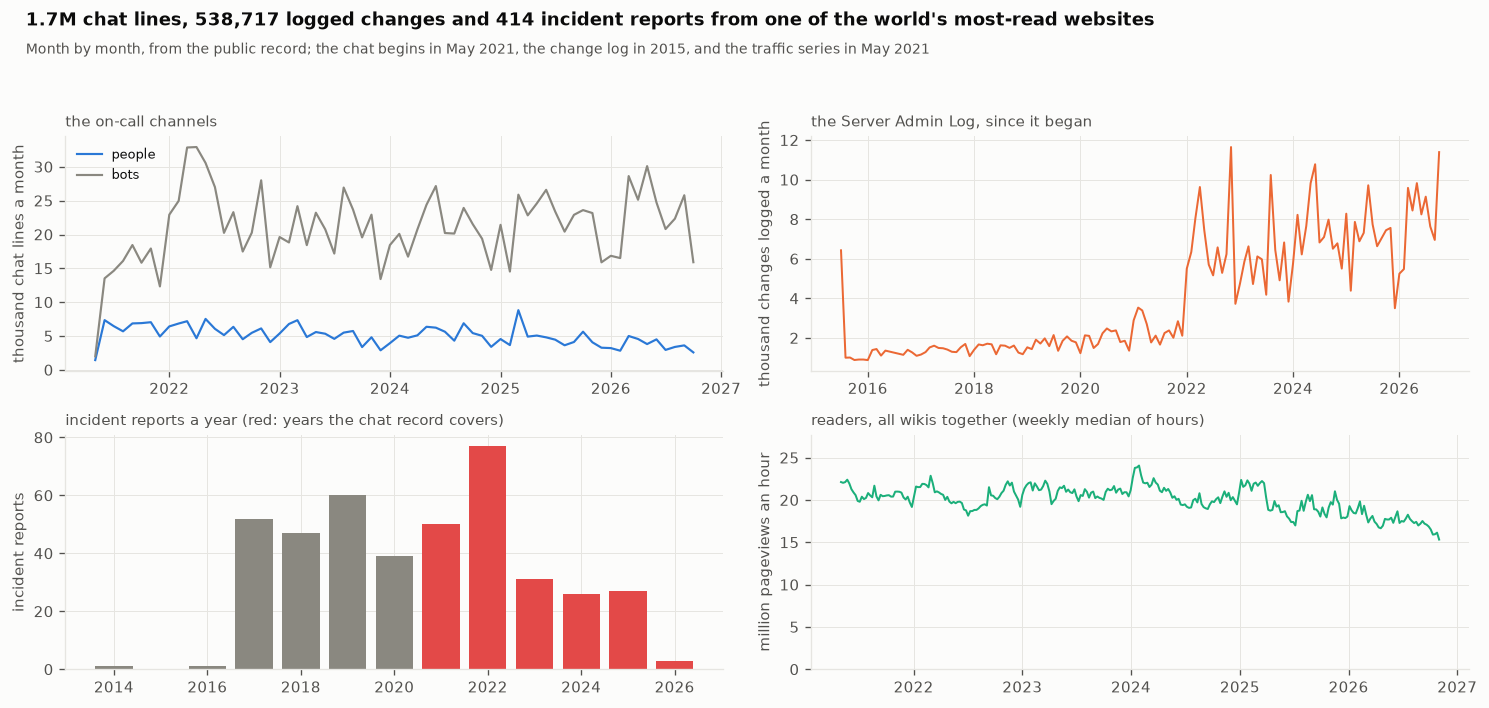

In [48]:
# ---- the record at a glance: chat, changes, incidents and readers, month by month ----
def per_month(ts: pd.Series) -> pd.Series:
    t = pd.to_datetime(ts, utc=True).dt.tz_localize(None)
    return t.dt.to_period("M").dt.to_timestamp().value_counts().sort_index()


fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.0))
ax = axes[0, 0]
for flag, label, colour in ((False, "people", C1), (True, "bots", MUTED)):
    s = per_month(IRC.loc[IRC.bot == flag, "ts"])
    ax.plot(s.index, s.values / 1e3, color=colour, lw=1.3, label=label)
ax.set_ylabel("thousand chat lines a month")
ax.legend(fontsize=7.5)
ax.set_title("the on-call channels", fontsize=9, color=INK2, loc="left")
ax = axes[0, 1]
s = per_month(SAL.ts)
ax.plot(s.index, s.values / 1e3, color=C2, lw=1.2)
ax.set_ylabel("thousand changes logged a month")
ax.set_title("the Server Admin Log, since it began", fontsize=9, color=INK2, loc="left")
ax = axes[1, 0]
years = pd.to_datetime(INCIDENTS.date, errors="coerce").dt.year.dropna().astype(int).value_counts().sort_index()
ax.bar(years.index, years.values, color=[C8 if y >= IRC.ts.min().year else MUTED for y in years.index])
ax.set_ylabel("incident reports")
ax.set_title("incident reports a year (red: years the chat record covers)", fontsize=9, color=INK2, loc="left")
ax = axes[1, 1]
weekly = TRAFFIC[TRAFFIC.project == "all-projects"].set_index("ts").views.resample("W").median()
ax.plot(weekly.index, weekly.values / 1e6, color=C3, lw=1.2)
ax.set_ylim(0, weekly.max() / 1e6 * 1.15)
ax.set_ylabel("million pageviews an hour")
ax.set_title("readers, all wikis together (weekly median of hours)", fontsize=9, color=INK2, loc="left")
finish(fig, "wikimedia_record", f"{len(IRC) / 1e6:.1f}M chat lines, {len(SAL):,} logged changes and {len(INCIDENTS)} "
       "incident reports from one of the world's most-read websites",
       f"Month by month, from the public record; the chat begins in {IRC.ts.min():%B %Y}, the change log in "
       f"{SAL.ts.min():%Y}, and the traffic series in {TRAFFIC.ts.min():%B %Y}")

**Five and a half years of a real company's operations: 1,730,378 chat lines, 423,173 logged
changes (538,717 since the log began in 2015), 414 incident reports, 1,690,696 alert lines, 71,116
merged code changes and every hour of human traffic since May 2021, fetched politely once and
cached on disk.** Four chat lines in five
come from bots, which is why the next sections treat bot lines as structured events and keep
conversation for people. A median day logs 200 lines of changes and the busiest 1,021, a number that
returns in section 8, where it decides how much "a change happened just before" can tell us.
The incident reports are rich but uneven: 80% of their timeline bullets carry a time we can read,
while only a third fill in the scorecard's start time, so section 8 falls back to the timeline
when the scorecard is empty. The catalogue knows 171 services, 1,153 pooled hosts in 36 clusters
and 245 puppet roles with an owning team among ten teams; section 11 measures how much of five
years of mentions it can actually name. And every person in all this text is replaced by a
pseudonym before anything is printed or sent to a model: the scrubber's own test found no handle
left in the reports, the deploy log or the chat.

## 5 · Proving our ruler before we trust it

**Theory.** Every number later in this notebook depends on parsers we just wrote: a regular
expression that reads a chat line, another that reads a deploy entry, a third that reads an
incident timeline. A parser that silently drops ten per cent of lines would not raise an error;
it would just make every later result a little wrong. Wikimedia happens to record several
facts twice, through independent routes, which gives us a way to check. Every deploy entry is
echoed into the chat by a bot, every alert that reaches the chat also lands in Loki, and every
merged change announced in the chat is also in Gerrit's own records. If our two readings of the
same fact agree, the ruler is straight; if they do not, we find out here rather than in part G.

In [49]:
# ---- the deploy log, seen twice: a bot echoes every !log entry into the channel ----
WIKILINK = re.compile(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]")


def norm_msg(s: str) -> str:
    """Compare what was said, not how a wiki renders it.

    The SAL escapes '{' as <nowiki>{</nowiki> and the pipe inside a link as {{!}}, renders T1 as [[phab:T1|T1]] and a
    change number as {{Gerrit|1360004}}; the chat copy has none of that. Our first version ignored the escapes and
    templates and matched only 86.7% of echoes.
    """
    s = re.sub(r"</?nowiki>", "", (s or "").replace("{{!}}", "|"))
    s = re.sub(r"\{\{[^|{}]+\|([^{}]*)\}\}", r"\1", s)
    return re.sub(r"\s+", " ", WIKILINK.sub(r"\1", s)).strip().lower()[:60]


echo = IRC.loc[IRC.nick == "logmsgbot", ["ts", "text"]].copy()
echo[["user", "host", "msg"]] = echo.text.str.extract(r"^!log\s+([^@\s]+)@([\w.\-]+)\s+(.*)$")
echo = echo.dropna(subset=["user"])
lo, hi = max(echo.ts.min(), SAL.ts.min()), min(echo.ts.max(), SAL.ts.max())
echo_w = echo[(echo.ts >= lo) & (echo.ts <= hi)]
sal_w = SAL[(SAL.ts >= lo) & (SAL.ts <= hi)]
sal_index = defaultdict(list)
for t, u, m in zip(sal_w.ts, sal_w.user, sal_w.message):
    sal_index[(u.lower(), norm_msg(m))].append(t)
offsets, found = [], 0
for t, u, m in zip(echo_w.ts, echo_w.user, echo_w.msg):
    hits = [s for s in sal_index.get((u.lower(), norm_msg(m)), []) if abs((t - s).total_seconds()) <= 120]
    if hits:
        found += 1
        offsets.append(min((t - s).total_seconds() for s in hits))
echo_keys = {(u.lower(), norm_msg(m)) for u, m in zip(echo_w.user, echo_w.msg)}
sal_seen = sum((u.lower(), norm_msg(m)) in echo_keys for u, m in zip(sal_w.user, sal_w.message))
RULER = {"SAL echo found in SAL": found / max(len(echo_w), 1),
         "SAL entry echoed in chat": sal_seen / max(len(sal_w), 1)}
SAL_OFFSETS = np.array(offsets)
print(f"  overlap {lo:%Y-%m-%d} to {hi:%Y-%m-%d}: {len(echo_w):,} chat echoes, {len(sal_w):,} SAL entries")
print(f"  chat echoes found in the SAL      {found:,} ({RULER['SAL echo found in SAL']:.1%})")
print(f"  SAL entries seen in the chat      {sal_seen:,} ({RULER['SAL entry echoed in chat']:.1%})")
if len(SAL_OFFSETS):
    print(f"  chat time minus SAL time: median {np.median(SAL_OFFSETS):.0f}s, "
          f"{(SAL_OFFSETS >= 0).mean():.1%} within [0, 60) s, as expected when one clock keeps seconds and one keeps minutes")

  overlap 2021-05-25 to 2026-10-31: 384,089 chat echoes, 423,022 SAL entries
  chat echoes found in the SAL      380,093 (99.0%)
  SAL entries seen in the chat      387,806 (91.7%)
  chat time minus SAL time: median 27s, 92.5% within [0, 60) s, as expected when one clock keeps seconds and one keeps minutes


In [50]:
# ---- alerts, seen twice: the chat bots against the Loki stream ----
ALERT_CHAT = re.compile(r"^(?:(FIRING|RESOLVED):\s*(?:\[\d+x\]\s*)?([\w.\-]+):|\(([\w.\-]+)\)\s+(firing|resolved):)")
ICINGA_CHAT = re.compile(r"^(PROBLEM|RECOVERY) - (.+?) on [\w.\-]+ is \w+")
LOKI_LINE = re.compile(r"^\[(firing|resolved)\] (.+?) \(")


def chat_alert(nick: str, text: str):
    """(status, alert name) from either bot, whatever year's format the line uses."""
    if nick == "jinxer-wm":
        m = ALERT_CHAT.match(text)
        if m:
            return ((m.group(1) or m.group(4)).lower(), m.group(2) or m.group(3))
    elif nick == "icinga-wm":
        m = ICINGA_CHAT.match(text)
        if m:
            return ("firing" if m.group(1) == "PROBLEM" else "resolved", m.group(2))
    return None


chat_alerts = [(t, *a) for t, n, x in zip(IRC.ts, IRC.nick, IRC.text) if n in ("jinxer-wm", "icinga-wm")
               and (a := chat_alert(n, x))]
loki_parsed = [(t, m.group(1), m.group(2)) for t, l in zip(ALERTS_LOKI.ts, ALERTS_LOKI.line) if (m := LOKI_LINE.match(l))]
lo, hi = ALERTS_LOKI.ts.min(), ALERTS_LOKI.ts.max()
in_window = [a for a in chat_alerts if lo <= a[0] <= hi]
loki_index = defaultdict(list)
for t, st, name in loki_parsed:
    loki_index[(st, name.lower())].append(int(t.timestamp()))
loki_index = {k: np.sort(np.array(v, dtype=np.int64)) for k, v in loki_index.items()}


def seen_in_loki(t: pd.Timestamp, status: str, name: str, within_s: int = 300) -> bool:
    """Binary search in that alert's sorted Loki times: one busy alert name has over 100,000 lines."""
    times = loki_index.get((status, name.lower()))
    if times is None:
        return False
    s = int(t.timestamp())
    i = np.searchsorted(times, s)
    return any(0 <= j < len(times) and abs(times[j] - s) <= within_s for j in (i - 1, i))


hit = sum(seen_in_loki(t, st, name) for t, st, name in in_window)
RULER["chat alert found in Loki"] = hit / max(len(in_window), 1)
RULER["Loki lines parsed"] = len(loki_parsed) / max(len(ALERTS_LOKI), 1)
print(f"  chat alert lines parsed: {len(chat_alerts):,} (both bot formats); inside Loki's window: {len(in_window):,}")
print(f"  found in Loki within 5 minutes: {hit:,} ({RULER['chat alert found in Loki']:.1%})")
print(f"  Loki lines our pattern reads: {len(loki_parsed):,}/{len(ALERTS_LOKI):,} ({RULER['Loki lines parsed']:.1%})")
print(f"  Loki carries {len(ALERTS_LOKI) / max(len(in_window), 1):.1f}x as many alert lines as the chat over the same days:"
      f" the channel only shows alerts routed to people")

  chat alert lines parsed: 252,771 (both bot formats); inside Loki's window: 26,978
  found in Loki within 5 minutes: 24,928 (92.4%)
  Loki lines our pattern reads: 1,690,696/1,690,696 (100.0%)
  Loki carries 62.7x as many alert lines as the chat over the same days: the channel only shows alerts routed to people


In [51]:
# ---- code changes, seen twice: the merge announcements against Gerrit's own record ----
MERGED = re.compile(r"^\(Merged\) .*?\[([\w.\-/]+)\].*?gerrit\.wikimedia\.org/r/(\d+)")
SHORT_TO_REPO = {r.split("/", 1)[1]: r for r in OPS_REPOS}
announced = [(t, SHORT_TO_REPO[m.group(1)], int(m.group(2))) for t, n, x in zip(IRC.ts, IRC.nick, IRC.text)
             if n == "wikibugs" and (m := MERGED.match(x)) and m.group(1) in SHORT_TO_REPO]
g_lo, g_hi = GERRIT_CHANGES.submitted.min(), GERRIT_CHANGES.submitted.max()
announced = [a for a in announced if g_lo <= a[0] <= g_hi]
known = set(GERRIT_CHANGES.number)
RULER["merge announcement in Gerrit"] = sum(a[2] in known for a in announced) / max(len(announced), 1)
print(f"  merges announced for the six ops repositories: {len(announced):,}; present in our Gerrit pull: "
      f"{sum(a[2] in known for a in announced):,} ({RULER['merge announcement in Gerrit']:.1%})")

  merges announced for the six ops repositories: 19,032; present in our Gerrit pull: 19,031 (100.0%)


In [52]:
# ---- the timeline parser, tested on the lines that break naive parsers ----
TL_CASES = [
    ("crosses midnight", "* 23:50 - alert fires\n* 23:58 - paged\n* 00:10 - mitigated", ["23:50+0", "23:58+0", "00:10+1"]),
    ("no space after the bullet", "*14:04 [[gerrit:c/x/+/1123238|CR]] merged", ["14:04+0"]),
    ("full date and UTC", "* 2025-02-27 14:10 UTC - failure rate rises", ["14:10+0"]),
    ("a quoted chat line", "**[14:28:12] '''<kart_>''' anything going on?", ["14:28+0"]),
    ("a bullet with no time", "* Problems noted in the channel:", []),
    ("a small step back is not midnight", "* 09:00 - noticed\n* 08:45 - (earlier) first error", ["09:00+0", "08:45+0"]),
]
tl_pass = 0
for name, text, want in TL_CASES:
    got_rows, _ = parse_timeline(text, datetime.date(2025, 2, 27))
    got = [f"{t:%H:%M}+{(t.date() - datetime.date(2025, 2, 27)).days}" for t, _ in got_rows]
    ok = got == want
    tl_pass += ok
    print(f"  {'PASS' if ok else 'FAIL'}  {name:<36}{got}")
RULER["timeline parser tests"] = tl_pass / len(TL_CASES)

  PASS  crosses midnight                    ['23:50+0', '23:58+0', '00:10+1']
  PASS  no space after the bullet           ['14:04+0']
  PASS  full date and UTC                   ['14:10+0']
  PASS  a quoted chat line                  ['14:28+0']
  PASS  a bullet with no time               []
  PASS  a small step back is not midnight   ['09:00+0', '08:45+0']


  check                               measured   needed
  ------------------------------------------------------------
  SAL echo found in SAL                  99.0%      95%  PASS
  SAL entry echoed in chat               91.7%      80%  PASS
  chat alert found in Loki               92.4%      90%  PASS
  Loki lines parsed                     100.0%      95%  PASS
  merge announcement in Gerrit          100.0%      95%  PASS
  timeline parser tests                 100.0%     100%  PASS


[fig] artifacts\figures_full\ruler.png


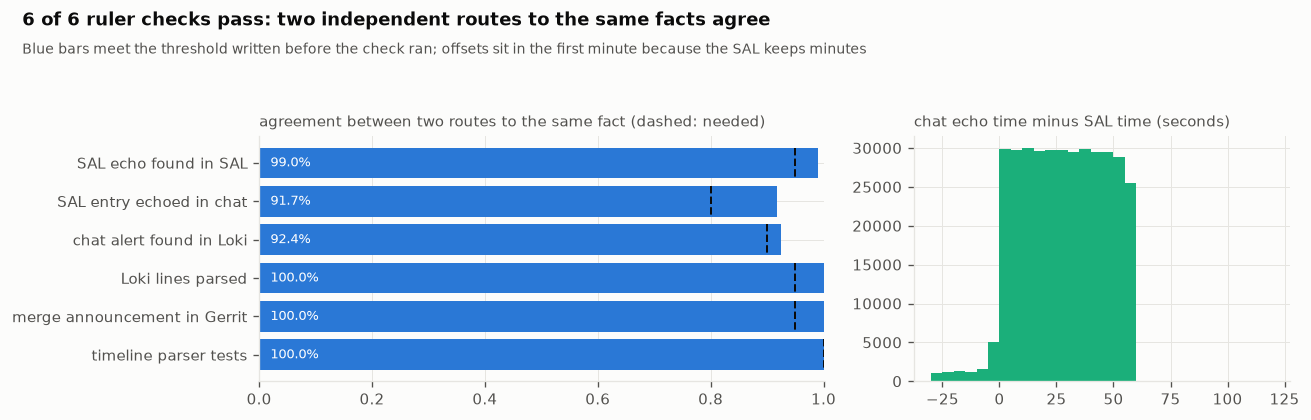

In [53]:
# ---- the ruler, on one page ----
RULER_MIN = {"SAL echo found in SAL": 0.95, "SAL entry echoed in chat": 0.80, "chat alert found in Loki": 0.90,
             "Loki lines parsed": 0.95, "merge announcement in Gerrit": 0.95, "timeline parser tests": 1.0}
print(f"  {'check':<34}{'measured':>10}{'needed':>9}")
print("  " + "-" * 60)
for k, v in RULER.items():
    print(f"  {k:<34}{v:>10.1%}{RULER_MIN[k]:>9.0%}  {'PASS' if v >= RULER_MIN[k] else 'FAIL'}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 2]})
names = list(RULER)
axes[0].barh(names, [RULER[n] for n in names], color=[C1 if RULER[n] >= RULER_MIN[n] else C2 for n in names])
for i, n in enumerate(names):
    axes[0].plot([RULER_MIN[n]] * 2, [i - 0.4, i + 0.4], color=INK, lw=1.2, ls="--")
    axes[0].text(0.02, i, f"{RULER[n]:.1%}", ha="left", va="center", fontsize=8, color="white")
axes[0].set_xlim(0, 1.0)
axes[0].invert_yaxis()
axes[0].set_title("agreement between two routes to the same fact (dashed: needed)", fontsize=9, color=INK2, loc="left")
if len(SAL_OFFSETS):
    axes[1].hist(SAL_OFFSETS, bins=np.arange(-30, 121, 5), color=C3)
axes[1].set_title("chat echo time minus SAL time (seconds)", fontsize=9, color=INK2, loc="left")
passed = sum(RULER[k] >= RULER_MIN[k] for k in RULER)
finish(fig, "ruler", f"{passed} of {len(RULER)} ruler checks pass: two independent routes to the same facts agree",
       "Blue bars meet the threshold written before the check ran; offsets sit in the first minute because the SAL keeps minutes")

**All six checks pass on the full record: 99.0% of 384,089 deploy echoes in the chat are found in
the Server Admin Log, 92.4% of 26,978 chat alerts are found in Loki within five minutes, and
19,031 of 19,032 merge announcements are in our Gerrit pull.** Two residuals remain and we report
them rather than tune them away: 8.3% of log entries never appear in this channel's echo, and
7.6% of chat alerts have no matching Loki line within five minutes. We have not traced either to
a cause, and nothing later depends on the echo or on matching the two alert routes line by line.
Loki carries 62.7 times as many alert lines as the chat over the same
days, which is a finding about the company rather than about our parser: the on-call channel
only shows the alerts somebody decided a human should see. The timeline parser handles every
hard case we could find, including incidents that cross midnight. The ruler is straight, so the
numbers that follow measure Wikimedia, not our regular expressions.

## 6 · OpenRCA: 68 GB of real enterprise telemetry

**Theory.** Wikimedia gives us the human side of incidents, but it does not publish
application logs or traces. OpenRCA fills that gap. It packages telemetry from three
systems that ran under real load and had their failures recorded with the exact component,
reason and time: a bank's application stack, a telecom operator's platform and an
e-commerce microservice deployment in two separate clusters. It is also the standard
benchmark for language-model agents doing root-cause analysis, so our agents can be scored
exactly the way published ones were. Two problems come with it. The three systems disagree
about column names, units and even clocks: one stores span durations in microseconds, two in
milliseconds, and every label is written in UTC+8. And the files are large, up to 3.8 GB
each, so we never hold more than one of them on disk at a time: download, convert to
compressed Parquet, check the row count, delete the CSV, move on.

In [54]:
# ---- what OpenRCA ships, read from its file listing rather than its README ----
from huggingface_hub import HfApi, hf_hub_download

OPENRCA_REPO = "tracer-cloud/opensre"
OPENRCA_RAW, OPENRCA_PQ = RAW / "openrca", PARQUET / "openrca"
OPENRCA_PQ.mkdir(parents=True, exist_ok=True)
listing_file = RES_DIR / "openrca_listing.json"
if listing_file.exists() and not RECOMPUTE:
    OPENRCA_FILES = json.loads(listing_file.read_text())
    print(f"  [cache] {listing_file.name}")
else:
    tree = HfApi().list_repo_tree(OPENRCA_REPO, repo_type="dataset", recursive=True)
    OPENRCA_FILES = [{"path": f.path, "bytes": int(f.size or 0)} for f in tree
                     if getattr(f, "size", None) is not None and not f.path.endswith(".DS_Store")]
    listing_file.write_text(json.dumps(OPENRCA_FILES))


def openrca_system(path: str) -> str:
    parts = path.split("/")
    if parts[0] == "Market":
        return "market_cb1" if parts[1] == "cloudbed-1" else "market_cb2"
    return {"Bank": "bank", "Telecom": "telecom"}[parts[0]]


TELEMETRY = [f for f in OPENRCA_FILES if "/telemetry/" in f["path"] and f["path"].endswith(".csv")]
summary = defaultdict(lambda: [0, 0])
for f in TELEMETRY:
    key = (openrca_system(f["path"]), f["path"].rsplit("/", 1)[-1])
    summary[key][0] += 1
    summary[key][1] += f["bytes"]
print(f"  {'system':<12}{'file':<26}{'days':>5}{'size':>11}")
print("  " + "-" * 54)
for (s, name), (n, b) in sorted(summary.items()):
    print(f"  {s:<12}{name:<26}{n:>5}{b / 1e9:>9.2f} GB")
print("  " + "-" * 54)
print(f"  {'total':<38}{len(TELEMETRY):>5}{sum(f['bytes'] for f in TELEMETRY) / 1e9:>9.2f} GB")

  [cache] openrca_listing.json
  system      file                       days       size
  ------------------------------------------------------
  bank        log_service.csv              10     3.61 GB
  bank        metric_app.csv               10     0.01 GB
  bank        metric_container.csv         10     0.84 GB
  bank        trace_span.csv               10    21.94 GB
  market_cb1  log_proxy.csv                 2     6.48 GB
  market_cb1  log_service.csv               2     1.45 GB
  market_cb1  metric_container.csv          2     0.56 GB
  market_cb1  metric_mesh.csv               2     0.53 GB
  market_cb1  metric_node.csv               2     0.04 GB
  market_cb1  metric_runtime.csv            2     0.19 GB
  market_cb1  metric_service.csv            2     0.00 GB
  market_cb1  trace_span.csv                2     2.70 GB
  market_cb2  log_proxy.csv                 2     6.88 GB
  market_cb2  log_service.csv               2     1.89 GB
  market_cb2  metric_container.csv         

In [55]:
# ---- one target layout for three systems that disagree about column names, units and clocks ----
TS_SECONDS = 'to_timestamp(TRY_CAST("timestamp" AS BIGINT))'
TS_MILLIS = 'to_timestamp(TRY_CAST("timestamp" AS BIGINT) / 1000.0)'
TS_START_MILLIS = "to_timestamp(TRY_CAST(startTime AS BIGINT) / 1000.0)"
UNPIVOT = ("SELECT {ts} AS ts, {ent} AS entity, kpi, TRY_CAST(val AS DOUBLE) AS value "
           "FROM (UNPIVOT src ON {cols} INTO NAME kpi VALUE val)")
METRICS_LONG = "SELECT {ts} AS ts, cmdb_id AS entity, {kpi} AS kpi, TRY_CAST(value AS DOUBLE) AS value FROM src"


def openrca_select(system: str, fname: str) -> tuple[str, str]:
    """(target table, SELECT over a CSV read as all-text `src`) for one OpenRCA file kind."""
    k = fname.removesuffix(".csv")
    if k.startswith("log_"):
        return "logs", f"SELECT {TS_SECONDS} AS ts, cmdb_id AS entity, log_name, value AS message FROM src"
    if system == "telecom":
        if k == "metric_app":
            return "metrics", UNPIVOT.format(ts=TS_START_MILLIS, ent="serviceName",
                                             cols='"avg_time", "num", "succee_num", "succee_rate"')
        if k.startswith("metric_"):
            return "metrics", METRICS_LONG.format(ts=TS_MILLIS, kpi="name")
        return "spans", (f"SELECT {TS_START_MILLIS} AS ts, cmdb_id AS entity, traceId AS trace_id, id AS span_id, "
                         "pid AS parent_id, TRY_CAST(elapsedTime AS DOUBLE) AS duration_ms, success AS status, "
                         "callType AS operation, COALESCE(NULLIF(dsName, ''), NULLIF(serviceName, '')) AS peer FROM src")
    if k == "metric_app":                     # bank: one row per service and minute, measures as columns
        return "metrics", UNPIVOT.format(ts=TS_SECONDS, ent="tc", cols='"rr", "sr", "cnt", "mrt"')
    if k == "metric_service":                 # market: the same idea under other names
        return "metrics", UNPIVOT.format(ts=TS_SECONDS, ent="service", cols='"rr", "sr", "mrt", "count"')
    if k.startswith("metric_"):
        return "metrics", METRICS_LONG.format(ts=TS_SECONDS, kpi="kpi_name")
    if system == "bank":                      # milliseconds; no status, operation or peer recorded
        return "spans", (f"SELECT {TS_MILLIS} AS ts, cmdb_id AS entity, trace_id, span_id, parent_id, "
                         "TRY_CAST(duration AS DOUBLE) AS duration_ms, NULL::VARCHAR AS status, "
                         "NULL::VARCHAR AS operation, NULL::VARCHAR AS peer FROM src")
    return "spans", (f"SELECT {TS_MILLIS} AS ts, cmdb_id AS entity, trace_id, span_id, parent_span AS parent_id, "
                     "TRY_CAST(duration AS DOUBLE) / 1000.0 AS duration_ms, "          # stored in microseconds
                     "status_code AS status, operation_name AS operation, NULL::VARCHAR AS peer FROM src")


for s, fname in (("bank", "metric_app.csv"), ("telecom", "trace_span.csv"), ("market_cb2", "trace_span.csv")):
    table, sql = openrca_select(s, fname)
    print(f"  {s:<11} {fname:<16} -> {table:<8}{sql[:112]}...")

  bank        metric_app.csv   -> metrics SELECT to_timestamp(TRY_CAST("timestamp" AS BIGINT)) AS ts, tc AS entity, kpi, TRY_CAST(val AS DOUBLE) AS value ...
  telecom     trace_span.csv   -> spans   SELECT to_timestamp(TRY_CAST(startTime AS BIGINT) / 1000.0) AS ts, cmdb_id AS entity, traceId AS trace_id, id AS...
  market_cb2  trace_span.csv   -> spans   SELECT to_timestamp(TRY_CAST("timestamp" AS BIGINT) / 1000.0) AS ts, cmdb_id AS entity, trace_id, span_id, paren...


In [56]:
# ---- download, convert, check, delete: one file at a time, so peak disk stays small ----
def duck() -> duckdb.DuckDBPyConnection:
    """A DuckDB connection with this notebook's settings. Long jobs get their own: DuckDB 2 refuses new work on a
    connection that still holds a half-read result, and a fresh connection never does."""
    con = duckdb.connect()
    con.execute(f"SET threads = {DUCKDB_THREADS}; SET memory_limit = '{DUCKDB_MEMORY_LIMIT}'; "
                f"SET temp_directory = '{SPILL.as_posix()}'; SET preserve_insertion_order = false; "
                "SET TimeZone = 'UTC'")      # every timestamp in this notebook is shown in UTC
    return con


# DuckDB deletes its spill files when a connection closes, but not when the process is killed; files left by a
# process that no longer exists are dead weight (one stopped query left 145 GB here before this was added)
stale = [f for f in SPILL.glob("duckdb_temp_*")
         if (m := re.match(r"duckdb_temp_(\d+)_", f.name)) and not psutil.pid_exists(int(m.group(1)))]
freed = sum(f.stat().st_size for f in stale)
for f in stale:
    f.unlink(missing_ok=True)
CON = duck()
OPENRCA_LOG = OPENRCA_PQ / "_conversion_log.json"     # describes data on D:, so it lives with the data
CONVERTED = json.loads(OPENRCA_LOG.read_text()) if OPENRCA_LOG.exists() else {}
CSV_OPTIONS = "header = true, all_varchar = true, quote = '\"', escape = '\"', strict_mode = false"


def openrca_target(path: str) -> Path:
    parts = path.split("/")
    table, _ = openrca_select(openrca_system(path), parts[-1])
    return OPENRCA_PQ / openrca_system(path) / table / f"{parts[-3]}__{parts[-1].removesuffix('.csv')}.parquet"


def copy_csv_to_parquet(local: Path, system: str, select: str, tmp: Path, extra: str = "") -> int:
    CON.execute(f"CREATE OR REPLACE TEMP VIEW src AS SELECT * FROM read_csv('{local.as_posix()}', {CSV_OPTIONS}{extra})")
    return CON.execute(f"COPY (SELECT '{system}' AS system, * FROM ({select})) TO '{tmp.as_posix()}' "
                       "(FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 1000000)").fetchone()[0]


print(f"  DuckDB: {DUCKDB_THREADS} threads, {DUCKDB_MEMORY_LIMIT} memory, spill to {SPILL} "
      f"({len(stale)} spill files left by dead processes removed, {freed / 1e9:.1f} GB)")
print(f"  files converted on earlier runs: {len(CONVERTED)}")

  DuckDB: 16 threads, 18GB memory, spill to D:\netflix_kg_data\spill (0 spill files left by dead processes removed, 0.0 GB)
  files converted on earlier runs: 162


In [57]:
# ---- one file through the whole cycle: the function every OpenRCA byte passes through ----
def convert_openrca_file(f: dict) -> dict:
    """Download one CSV, write it as zstd Parquet in the common layout, verify, delete the CSV."""
    out = openrca_target(f["path"])
    done = CONVERTED.get(f["path"])
    if done and out.exists() and not RECOMPUTE:
        return {**done, "cached": True}
    if free_gb(DATA) - f["bytes"] * 1.3 / 1024**3 < MIN_FREE_GB:
        raise RuntimeError(f"the data drive would drop below {MIN_FREE_GB} GB free; stopping before {f['path']}")
    t0 = time.perf_counter()
    local = Path(hf_hub_download(OPENRCA_REPO, f["path"], repo_type="dataset", local_dir=OPENRCA_RAW))
    t_dl = time.perf_counter() - t0
    system = openrca_system(f["path"])
    table, select = openrca_select(system, f["path"].rsplit("/", 1)[-1])
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.with_name(out.stem + ".tmp.parquet")
    try:
        rows, lenient = copy_csv_to_parquet(local, system, select, tmp), False
    except duckdb.Error:
        # a few malformed lines should not cost us a whole file: skip them, and say so in the log
        rows, lenient = copy_csv_to_parquet(local, system, select, tmp, ", ignore_errors = true"), True
    pq_rows = CON.execute(f"SELECT count(*) FROM read_parquet('{tmp.as_posix()}')").fetchone()[0]
    assert pq_rows == rows, f"row count changed on the way to Parquet: {rows} vs {pq_rows}"
    tmp.replace(out)
    local.unlink()                            # the CSV has served its purpose
    rec = {"path": f["path"], "system": system, "table": table, "rows": int(rows), "lenient": lenient,
           "csv_bytes": f["bytes"], "parquet_bytes": out.stat().st_size,
           "download_s": round(t_dl, 1), "total_s": round(time.perf_counter() - t0, 1)}
    CONVERTED[f["path"]] = rec
    OPENRCA_LOG.write_text(json.dumps(CONVERTED, indent=1))
    return {**rec, "cached": False}


demo = convert_openrca_file(min(TELEMETRY, key=lambda f: f["bytes"]))
print(f"  smallest file: {demo['path']}")
print(f"  {demo['rows']:,} rows -> {openrca_target(demo['path']).relative_to(DATA)}")
print(CON.execute(f"SELECT * FROM read_parquet('{openrca_target(demo['path']).as_posix()}') LIMIT 4").df().to_string(index=False))

  smallest file: Telecom/telemetry/2020_04_20/metric/metric_app.csv
  1,440 rows -> parquet\openrca\telecom\metrics\2020_04_20__metric_app.parquet
 system                        ts  entity         kpi    value
telecom 2020-04-19 16:00:00+00:00 osb_001    avg_time   0.5836
telecom 2020-04-19 16:00:00+00:00 osb_001         num 361.0000
telecom 2020-04-19 16:00:00+00:00 osb_001  succee_num 361.0000
telecom 2020-04-19 16:00:00+00:00 osb_001 succee_rate   1.0000


In [58]:
# ---- the whole conversion, smallest files first so problems show up early ----
def openrca_plan(profile: str) -> list[dict]:
    if profile == "SMOKE":    # four small files, enough to exercise every code path
        wanted = ("Bank/telemetry/2021_03_04/metric/metric_app.csv",
                  "cloudbed-2/telemetry/2022_03_20/metric/metric_service.csv",
                  "Telecom/telemetry/2020_04_11/metric/metric_app.csv",
                  "Telecom/telemetry/2020_04_11/metric/metric_container.csv")
        keep = lambda p: p.endswith(wanted)
    elif profile == "MEDIUM":
        keep = lambda p: p.startswith("Market/cloudbed-2/")
    else:
        keep = lambda p: True
    return sorted((f for f in TELEMETRY if keep(f["path"])), key=lambda f: f["bytes"])


PLAN = openrca_plan(PROFILE)
print(f"  {PROFILE} profile: {len(PLAN)} files, {sum(f['bytes'] for f in PLAN) / 1e9:.2f} GB of CSV to convert")
print(f"  {'file':<58}{'CSV':>9}{'Parquet':>10}{'rows':>14}{'secs':>7}")
print("  " + "-" * 98)
for f in PLAN:
    r = convert_openrca_file(f)
    took = "cached" if r["cached"] else f"{r['total_s']:.0f}"
    print(f"  {r['path'][-57:]:<58}{r['csv_bytes'] / 1e6:>7.0f}MB{r['parquet_bytes'] / 1e6:>8.0f}MB"
          f"{r['rows']:>14,}{took:>7}", flush=True)
done_rows = sum(CONVERTED[f["path"]]["rows"] for f in PLAN)
csv_b = sum(CONVERTED[f["path"]]["csv_bytes"] for f in PLAN)
pq_b = sum(CONVERTED[f["path"]]["parquet_bytes"] for f in PLAN)
lenient = sum(CONVERTED[f["path"]]["lenient"] for f in PLAN)
print(f"\n  {done_rows:,} rows; {csv_b / 1e9:.2f} GB of CSV became {pq_b / 1e9:.2f} GB of Parquet "
      f"({csv_b / max(pq_b, 1):.1f}x smaller); data drive now has {free_gb(DATA):.0f} GB free")
print(f"  files that needed the lenient reader (malformed lines skipped): {lenient} of {len(PLAN)}; "
      f"conversion time on the first run: {sum(CONVERTED[f['path']]['total_s'] for f in PLAN) / 60:.0f} minutes")

  FULL profile: 162 files, 68.65 GB of CSV to convert
  file                                                            CSV   Parquet          rows   secs
  --------------------------------------------------------------------------------------------------
  Telecom/telemetry/2020_04_20/metric/metric_app.csv              0MB       0MB         1,440 cached


  Telecom/telemetry/2020_04_23/metric/metric_app.csv              0MB       0MB         1,484 cached


  Telecom/telemetry/2020_05_25/metric/metric_app.csv              0MB       0MB         1,484 cached


  Telecom/telemetry/2020_05_24/metric/metric_app.csv              0MB       0MB         1,496 cached


  Telecom/telemetry/2020_05_28/metric/metric_app.csv              0MB       0MB         1,512 cached


  Telecom/telemetry/2020_05_26/metric/metric_app.csv              0MB       0MB         1,512 cached


... (153 outputs left out)

  Market/cloudbed-1/telemetry/2022_03_20/log/log_proxy.csv     3164MB     241MB     7,931,116 cached


  Market/cloudbed-1/telemetry/2022_03_21/log/log_proxy.csv     3313MB     252MB     8,307,398 cached


  Market/cloudbed-2/telemetry/2022_03_20/log/log_proxy.csv     3804MB     289MB     9,500,357 cached



  524,547,719 rows; 68.65 GB of CSV became 7.11 GB of Parquet (9.6x smaller); data drive now has 158 GB free
  files that needed the lenient reader (malformed lines skipped): 0 of 162; conversion time on the first run: 63 minutes


In [59]:
# ---- the tasks and the answer key, with the clock problem fixed and tested ----
UTC8 = datetime.timezone(datetime.timedelta(hours=8))
frames = {"query": [], "record": []}
for p in [f["path"] for f in OPENRCA_FILES if f["path"].endswith(("query.csv", "record.csv"))]:
    df = pd.read_csv(hf_hub_download(OPENRCA_REPO, p, repo_type="dataset", local_dir=OPENRCA_RAW))
    df["system"] = openrca_system(p)
    frames["query" if p.endswith("query.csv") else "record"].append(df)
OPENRCA_TASKS = pd.concat(frames["query"], ignore_index=True)
OPENRCA_RECORDS = pd.concat(frames["record"], ignore_index=True)
OPENRCA_RECORDS["ts_utc"] = pd.to_datetime(OPENRCA_RECORDS["timestamp"].astype(float), unit="s", utc=True)
label_clock = pd.to_datetime(OPENRCA_RECORDS["datetime"]).dt.tz_localize(UTC8).dt.tz_convert("UTC")
mismatch = int((label_clock != OPENRCA_RECORDS["ts_utc"]).sum())
print(f"  tasks {len(OPENRCA_TASKS)}   failures {len(OPENRCA_RECORDS)}   by system "
      f"{OPENRCA_RECORDS.system.value_counts().sort_index().to_dict()}")
print(f"  [test] 'datetime' read as UTC+8 equals the epoch 'timestamp' on {len(OPENRCA_RECORDS) - mismatch}"
      f"/{len(OPENRCA_RECORDS)} rows -> {'PASS' if mismatch == 0 else 'FAIL'}")
r0 = OPENRCA_RECORDS.iloc[0]
print(f"  example: the label says {r0['datetime']} (UTC+8), which is {r0['ts_utc']:%Y-%m-%d %H:%M} UTC: "
      f"{r0['level']} {r0['component']}, {r0['reason']}")
assert mismatch == 0, "the label clock does not match the epoch column"
save_parquet(OPENRCA_TASKS, OPENRCA_PQ / "tasks.parquet")
save_parquet(OPENRCA_RECORDS, OPENRCA_PQ / "records.parquet")

  tasks 335   failures 335   by system {'bank': 136, 'market_cb1': 70, 'market_cb2': 78, 'telecom': 51}
  [test] 'datetime' read as UTC+8 equals the epoch 'timestamp' on 335/335 rows -> PASS
  example: the label says 2021-03-04 14:57:00 (UTC+8), which is 2021-03-04 06:57 UTC: pod Mysql02, high memory usage


  [test] each task type asks for exactly what its scoring points check -> PASS


[fig] artifacts\figures_full\openrca_questions.png


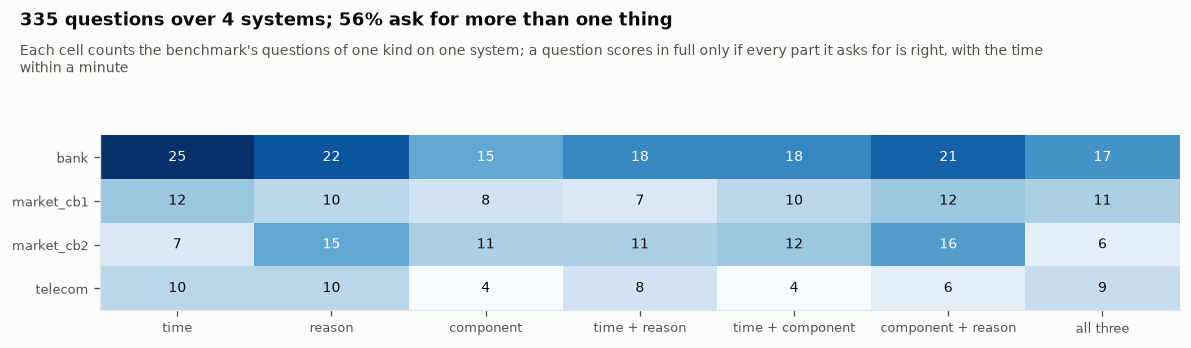

In [60]:
# ---- the questions, drawn: which system each one is about, and what it asks for ----
ASKS = {"task_1": "time", "task_2": "reason", "task_3": "component", "task_4": "time + reason",
        "task_5": "time + component", "task_6": "component + reason", "task_7": "all three"}
said = OPENRCA_TASKS.scoring_points.fillna("")
asks_ok = all(("time" in ASKS[k] or k == "task_7") == ("occurrence time" in s)
              and ("component" in ASKS[k] or k == "task_7") == ("root cause component" in s)
              and ("reason" in ASKS[k] or k == "task_7") == ("root cause reason" in s)
              for k, s in zip(OPENRCA_TASKS.task_index, said))
print(f"  [test] each task type asks for exactly what its scoring points check -> {'PASS' if asks_ok else 'FAIL'}")
grid_t = (OPENRCA_TASKS.assign(asks=OPENRCA_TASKS.task_index.map(ASKS)).groupby(["system", "asks"]).size()
          .unstack(fill_value=0))
grid_t = grid_t[[a for a in ASKS.values() if a in grid_t]]
fig, ax = plt.subplots(figsize=(10, 3.0))
ax.imshow(grid_t.to_numpy(), cmap="Blues", aspect="auto")
for i in range(grid_t.shape[0]):
    for j in range(grid_t.shape[1]):
        v = grid_t.iat[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=8.5, color="white" if v > grid_t.to_numpy().max() / 2 else INK)
ax.set_xticks(range(grid_t.shape[1]), grid_t.columns, fontsize=8)
ax.set_yticks(range(grid_t.shape[0]), grid_t.index, fontsize=8)
ax.grid(False)
multi = OPENRCA_TASKS.task_index.map(ASKS).str.contains(r"\+|all").mean()
finish(fig, "openrca_questions", f"{len(OPENRCA_TASKS)} questions over {grid_t.shape[0]} systems; {multi:.0%} ask for "
       "more than one thing",
       "Each cell counts the benchmark's questions of one kind on one system; a question scores in full only if every "
       "part it asks for is right, with the time within a minute")

table                logs        metrics          spans
system                                                 
bank           21,356,870     12,741,066    214,337,882
market_cb1     25,772,490     15,550,274     18,160,322
market_cb2     29,578,320     14,372,143     18,151,743
telecom                 0      8,619,559    145,907,050


[fig] artifacts\figures_full\openrca_volume.png


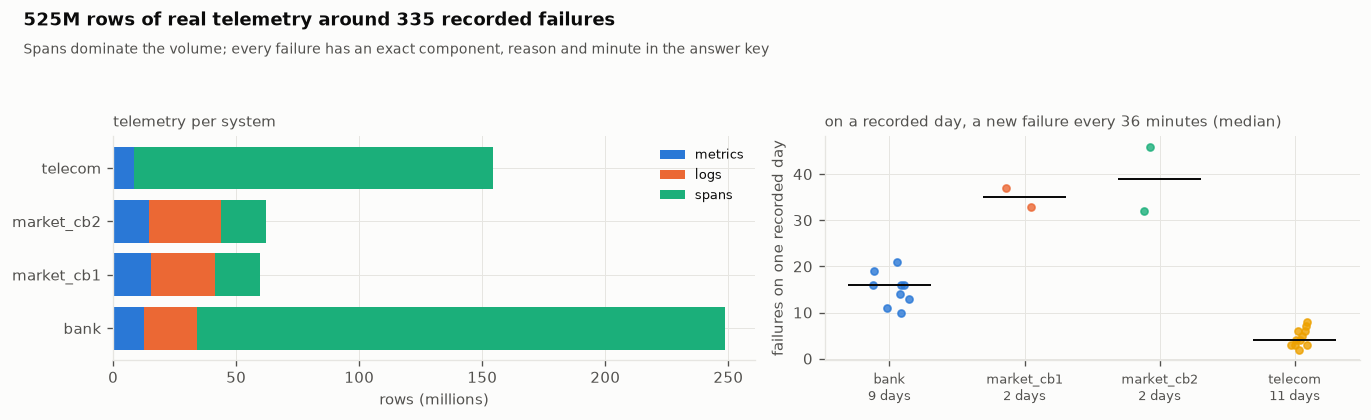

In [61]:
# ---- what we now hold: rows per system and table, and how the failures spread over the days ----
OPENRCA_VOLUME = (pd.DataFrame(list(CONVERTED.values()))
                  .groupby(["system", "table"])[["rows", "parquet_bytes"]].sum().reset_index())
print(OPENRCA_VOLUME.pivot(index="system", columns="table", values="rows").fillna(0).astype(int)
      .map(lambda v: f"{v:>13,}").to_string())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
piv = OPENRCA_VOLUME.pivot(index="system", columns="table", values="rows").fillna(0) / 1e6
left = np.zeros(len(piv))
for table, colour in (("metrics", C1), ("logs", C2), ("spans", C3)):
    if table in piv:
        axes[0].barh(piv.index, piv[table], left=left, color=colour, label=table)
        left += piv[table].to_numpy()
axes[0].set_xlabel("rows (millions)")
axes[0].legend(fontsize=7.5)
axes[0].set_title("telemetry per system", fontsize=9, color=INK2, loc="left")
# the telemetry covers chosen days, not a continuous stretch, so failures are counted per recorded day
rec_day = OPENRCA_RECORDS.assign(day=pd.to_datetime(OPENRCA_RECORDS["datetime"]).dt.date)   # folders use UTC+8 days
per_day = rec_day.groupby(["system", "day"]).size()
same_day_gaps = (rec_day.sort_values("ts_utc").groupby(["system", "day"]).ts_utc.diff().dropna()
                 .dt.total_seconds() / 60)
systems = sorted(OPENRCA_RECORDS.system.unique())
for i, (system, colour) in enumerate(zip(systems, (C1, C2, C3, C4))):
    counts = per_day.loc[system].to_numpy()
    jitter = np.random.default_rng(SEED + i).uniform(-0.15, 0.15, len(counts))
    axes[1].scatter(np.full(len(counts), i) + jitter, counts, s=18, color=colour, alpha=0.8)
    axes[1].plot([i - 0.3, i + 0.3], [np.median(counts)] * 2, color=INK, lw=1.2)
axes[1].set_xticks(range(len(systems)), [f"{s}\n{per_day.loc[s].size} days" for s in systems], fontsize=7.5)
axes[1].set_ylabel("failures on one recorded day")
axes[1].set_title(f"on a recorded day, a new failure every {same_day_gaps.median():.0f} minutes (median)", fontsize=9,
                  color=INK2, loc="left")
finish(fig, "openrca_volume",
       f"{OPENRCA_VOLUME.rows.sum() / 1e6:,.0f}M rows of real telemetry around {len(OPENRCA_RECORDS)} recorded failures",
       "Spans dominate the volume; every failure has an exact component, reason and minute in the answer key")

In [62]:
# ---- the running example: the clearest failure in the development cluster, chosen by its signature ----
FLAG_SYSTEM = "market_cb1"             # never the held-out cluster, so walking through it tunes nothing we test


def failure_signature(system: str, comp: str, t: pd.Timestamp) -> dict:
    """How visibly one failure shows in traces and logs: mean span time and error-looking lines, 10 min after vs 30 before."""
    root = OPENRCA_PQ / system
    if not (root / "spans").exists() or not (root / "logs").exists():
        return {}
    sp = CON.execute(f"SELECT avg(duration_ms) FILTER (WHERE ts < $t) AS before, "
                     f"avg(duration_ms) FILTER (WHERE ts >= $t) AS after FROM read_parquet('{(root / 'spans').as_posix()}/*.parquet') "
                     "WHERE entity LIKE $c AND ts >= $t - INTERVAL 30 MINUTE AND ts < $t + INTERVAL 10 MINUTE",
                     {"t": t, "c": comp + "%"}).fetchone()
    lg = CON.execute(f"SELECT count(*) FILTER (WHERE ts < $t) / 3.0, count(*) FILTER (WHERE ts >= $t) "
                     f"FROM read_parquet('{(root / 'logs').as_posix()}/*.parquet') WHERE entity LIKE $c "
                     "AND ts >= $t - INTERVAL 30 MINUTE AND ts < $t + INTERVAL 10 MINUTE "
                     "AND regexp_matches(message, '(?i)error|exception|fail|refused|timeout')",
                     {"t": t, "c": comp + "%"}).fetchone()
    return {"latency_x": (sp[1] or 0) / sp[0] if sp[0] else float("nan"), "errors_before": lg[0], "errors_after": lg[1]}


sig_file = RES_DIR / "openrca_signatures.parquet"
cands = OPENRCA_RECORDS[(OPENRCA_RECORDS.system == FLAG_SYSTEM) & OPENRCA_RECORDS.level.isin(["pod", "service"])]
if sig_file.exists() and not RECOMPUTE:
    SIGS = pd.read_parquet(sig_file)
    print(f"  [cache] {sig_file.name}")
else:
    SIGS = pd.DataFrame([{**r[["ts_utc", "level", "component", "reason"]].to_dict(),
                          **failure_signature(FLAG_SYSTEM, r.component, r.ts_utc)} for _, r in cands.iterrows()])
    save_parquet(SIGS, sig_file)
if "latency_x" in SIGS:
    SIGS["score"] = np.log10(SIGS.latency_x.clip(lower=1)) + np.log10((SIGS.errors_after + 1) / (SIGS.errors_before + 1)).clip(lower=0)
    SIGS = SIGS.sort_values("score", ascending=False)
    print(f"  {'when (UTC)':<18}{'level':<9}{'component':<24}{'reason':<38}{'latency':>9}{'errors':>14}")
    print("  " + "-" * 112)
    for _, r in SIGS.head(6).iterrows():
        print(f"  {r.ts_utc:%m-%d %H:%M}       {r.level:<9}{r.component:<24}{r.reason:<38}{r.latency_x:>8.0f}x"
              f"{r.errors_before:>7.0f}->{r.errors_after:<5.0f}")
    FLAGSHIP_FAILURE = SIGS.iloc[0]
    print(f"\n  running example: {FLAGSHIP_FAILURE.component} ({FLAGSHIP_FAILURE.level}), "
          f"{FLAGSHIP_FAILURE.reason}, at {FLAGSHIP_FAILURE.ts_utc:%Y-%m-%d %H:%M:%S} UTC")
    print("  The answer key picked this example; it is never shown to any system we evaluate.")
else:
    FLAGSHIP_FAILURE = None
    print("  [skip] this profile has no spans or logs for the development cluster")

  [cache] openrca_signatures.parquet
  when (UTC)        level    component               reason                                  latency        errors
  ----------------------------------------------------------------------------------------------------------------
  03-21 07:45       service  cartservice             container packet loss                     1719x      0->440  
  03-20 03:35       service  recommendationservice   container network packet corruption        158x      0->45   
  03-21 07:08       pod      frontend2-0             container network packet corruption       1478x      0->0    
  03-20 00:39       service  cartservice             container network latency                 1443x      0->0    
  03-20 19:10       service  checkoutservice         container network packet corruption         81x      0->2    
  03-21 04:18       service  productcatalogservice   container network latency                  185x      0->0    

  running example: cartservice (service), 

  mean response time (ms)    before: median     1.08   worst minute in the 10 after:  3329.03
  success rate (%)           before: median   100.00   worst minute in the 10 after:    51.09
  root cause mean span ms    before: median     0.06   worst minute in the 10 after:  1989.90
  frontend mean span ms      before: median     8.79   worst minute in the 10 after:  2384.24
  error-looking log lines    before:        1         in the 10 minutes after:      440


[fig] artifacts\figures_full\flagship_failure_melt.png


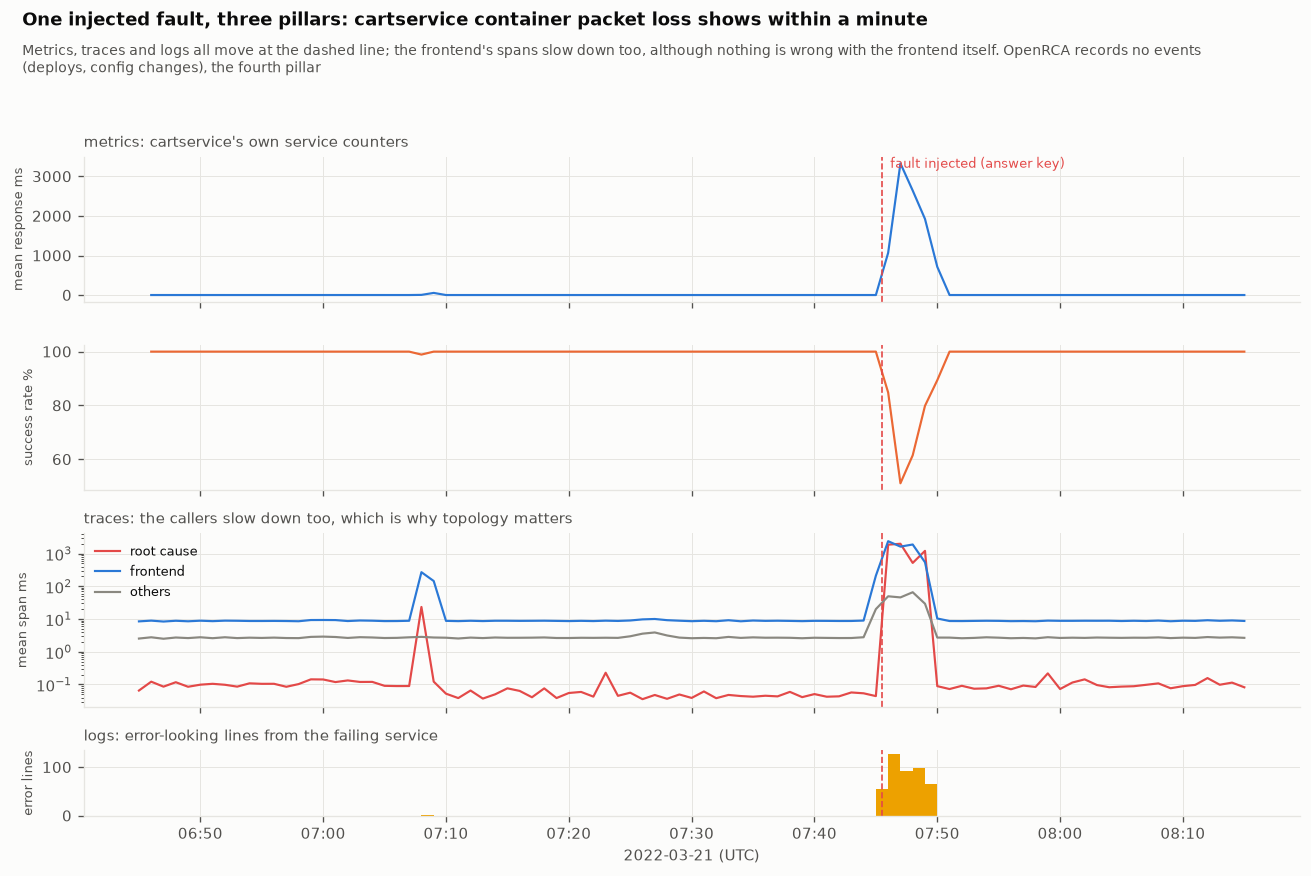

In [63]:
# ---- the running example in metrics, traces and logs, minute by minute ----
import matplotlib.dates as mdates


def flagship_panel(system: str, comp: str, t: pd.Timestamp, before_min: int = 60, after_min: int = 30) -> None:
    root, args = OPENRCA_PQ / system, {"a": t - pd.Timedelta(minutes=before_min), "b": t + pd.Timedelta(minutes=after_min)}
    met = CON.execute(f"SELECT date_trunc('minute', ts) AS m, kpi, avg(value) AS v FROM read_parquet('{(root / 'metrics').as_posix()}/*.parquet') "
                      f"WHERE entity = '{comp}-grpc' AND kpi IN ('mrt', 'sr') AND ts >= $a AND ts < $b GROUP BY ALL ORDER BY m",
                      args).df()
    spans = CON.execute(f"SELECT date_trunc('minute', ts) AS m, CASE WHEN entity LIKE '{comp}%' THEN 'root cause' "
                        f"WHEN entity LIKE 'frontend%' THEN 'frontend' ELSE 'others' END AS who, avg(duration_ms) AS ms "
                        f"FROM read_parquet('{(root / 'spans').as_posix()}/*.parquet') WHERE ts >= $a AND ts < $b "
                        "GROUP BY ALL ORDER BY m", args).df()
    logs = CON.execute(f"SELECT date_trunc('minute', ts) AS m, count(*) AS n FROM read_parquet('{(root / 'logs').as_posix()}/*.parquet') "
                       f"WHERE entity LIKE '{comp}%' AND ts >= $a AND ts < $b AND "
                       "regexp_matches(message, '(?i)error|exception|fail|refused|timeout') GROUP BY ALL ORDER BY m", args).df()
    before, after = met[met.m < t], met[(met.m >= t) & (met.m < t + pd.Timedelta(minutes=10))]
    for kpi, label in (("mrt", "mean response time (ms)"), ("sr", "success rate (%)")):
        b, a = before[before.kpi == kpi].v, after[after.kpi == kpi].v
        worst = a.max() if kpi == "mrt" else a.min()
        print(f"  {label:<26} before: median {b.median():8.2f}   worst minute in the 10 after: {worst:8.2f}")
    root_ms = spans[spans.who == "root cause"].set_index("m").ms
    front_ms = spans[spans.who == "frontend"].set_index("m").ms
    for who, s in (("root cause", root_ms), ("frontend", front_ms)):
        print(f"  {who + ' mean span ms':<26} before: median {s[s.index < t].median():8.2f}   "
              f"worst minute in the 10 after: {s[(s.index >= t) & (s.index < t + pd.Timedelta(minutes=10))].max():8.2f}")
    print(f"  {'error-looking log lines':<26} before: {int(logs[logs.m < t.floor('min')].n.sum()):>8}         "
          f"in the 10 minutes after: "
          f"{int(logs[(logs.m >= t.floor('min')) & (logs.m < t + pd.Timedelta(minutes=10))].n.sum()):>8}")
    fig, axes = plt.subplots(4, 1, figsize=(11, 7.4), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.2, 0.45]})
    for kpi, colour, ax in (("mrt", C1, axes[0]), ("sr", C2, axes[1])):
        d = met[met.kpi == kpi]
        ax.plot(d.m, d.v, color=colour, lw=1.3)
        ax.set_ylabel("mean response ms" if kpi == "mrt" else "success rate %", fontsize=8)
    axes[0].set_title(f"metrics: {comp}'s own service counters", fontsize=9, color=INK2, loc="left")
    for who, colour in (("root cause", C8), ("frontend", C1), ("others", MUTED)):
        d = spans[spans.who == who]
        axes[2].plot(d.m, d.ms, color=colour, lw=1.3, label=who)
    axes[2].set_yscale("log")
    axes[2].set_ylabel("mean span ms", fontsize=8)
    axes[2].legend(fontsize=7.5, loc="upper left")
    axes[2].set_title("traces: the callers slow down too, which is why topology matters", fontsize=9, color=INK2, loc="left")
    axes[3].bar(logs.m, logs.n, width=1 / 1440, align="edge", color=C4)      # each bar covers its own minute
    axes[3].set_ylabel("error lines", fontsize=8)
    axes[3].set_title("logs: error-looking lines from the failing service", fontsize=9, color=INK2, loc="left")
    for ax in axes:
        ax.axvline(t, color=C8, ls="--", lw=1)
    axes[0].text(t, axes[0].get_ylim()[1], "  fault injected (answer key)", color=C8, fontsize=7.5, va="top")
    axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[3].set_xlabel(f"{t:%Y-%m-%d} (UTC)")
    finish(fig, "flagship_failure_melt",
           f"One injected fault, three pillars: {comp} {FLAGSHIP_FAILURE.reason} shows within a minute",
           "Metrics, traces and logs all move at the dashed line; the frontend's spans slow down too, although nothing is "
           "wrong with the frontend itself. OpenRCA records no events (deploys, config changes), the fourth pillar")


if FLAGSHIP_FAILURE is not None:
    flagship_panel(FLAG_SYSTEM, FLAGSHIP_FAILURE.component, FLAGSHIP_FAILURE.ts_utc)

**68.65 GB of CSV became 7.11 GB of Parquet: 524,547,719 rows, and not one of the 162 files
needed the lenient reader.** Every file's row count was checked on its way into Parquet, and
all 335 labels pass the clock test, so the answer key and the telemetry agree to the second.
Spans are most of the volume, which is why they will set the pace of everything that reads raw
data later. The running example is cartservice in the development cluster losing packets at
07:45 UTC on 21 March 2022. Its own response time goes from a median of 1.08 ms to 3,329 ms in
the worst minute, its success rate falls from 100% to 51%, and error lines go from 1 in the hour
before to 440 in ten minutes. The detail that matters for the rest of the notebook is in the
traces: in the worst minute the frontend's spans average 2,384 ms, slower than the failing
service's own 1,990 ms, although nothing is wrong with the frontend. A ranking that asks only
"whose spans got slowest" blames the wrong service; knowing who calls whom is what fixes it,
and that knowledge is exactly what the graph will hold.

## 7 · RCAEval: 360 failures with exact answers

**Theory.** OpenRCA is big and hard, but it has 335 failures spread over four systems. For
the questions where we need many repetitions of the same kind of failure, and a comparison
against classic statistical methods rather than other agents, we use RCAEval. It ran three
well-known open-source microservice applications (Online Boutique, Sock Shop and Train
Ticket) under steady load and injected faults into one service at a time: CPU and memory
hogs, disk pressure, network delay, packet loss, broken sockets, and, in the RE3 suite, real
bugs in the code. Each case is a folder holding one-second metrics, logs, traces and the
second at which the fault started, and the folder's name tells us which service was broken.
The answer is never ambiguous, which is exactly what a ruler needs.

In [64]:
# ---- the index: one row per failure, with its answer ----
from huggingface_hub import hf_hub_download, snapshot_download

RCAEVAL_REPO = "phamquiluan/RCAEval"
RCA_DIR = PARQUET / "rcaeval"
CASES = pd.read_parquet(hf_hub_download(RCAEVAL_REPO, "cases.parquet", repo_type="dataset", local_dir=RCA_DIR))
CASES = CASES[CASES.suite.isin(["RE2", "RE3"])].reset_index(drop=True)
print(f"  {len(CASES)} cases in RE2 and RE3")
print(f"  {'dataset':<9}{'cases':>6}{'services':>9}  faults")
print("  " + "-" * 64)
for ds, g in CASES.groupby("dataset"):
    print(f"  {ds:<9}{len(g):>6}{g.root_cause_service.nunique():>9}  {', '.join(sorted(g.fault.unique()))}")
print(f"\n  each case: {CASES.duration_minutes.median():.0f} minutes of telemetry, the fault starting halfway; "
      f"{CASES.has_logs.sum()}/{len(CASES)} have logs, {CASES.has_traces.sum()}/{len(CASES)} have traces "
      f"(Sock Shop records none)")

  360 cases in RE2 and RE3
  dataset   cases services  faults
  ----------------------------------------------------------------
  RE2-OB       90        5  cpu, delay, disk, loss, mem, socket
  RE2-SS       90        5  cpu, delay, disk, loss, mem, socket
  RE2-TT       90        5  cpu, delay, disk, loss, mem, socket
  RE3-OB       30        4  f1, f2, f3, f4, f5
  RE3-SS       30        3  f1, f2, f3, f4
  RE3-TT       30        2  f1, f2, f3, f4

  each case: 24 minutes of telemetry, the fault starting halfway; 359/360 have logs, 240/360 have traces (Sock Shop records none)


In [65]:
# ---- download only the cases this profile needs ----
if PROFILE == "SMOKE":
    CHOSEN = CASES[CASES.suite == "RE2"].groupby("system").head(2)
elif PROFILE == "MEDIUM":
    CHOSEN = CASES[CASES.dataset == "RE2-TT"]
else:
    CHOSEN = CASES
t0 = time.perf_counter()
snapshot_download(RCAEVAL_REPO, repo_type="dataset", local_dir=RCA_DIR,
                  allow_patterns=[f"{c}/*" for c in CHOSEN.case])
sizes = {c: sum(p.stat().st_size for p in (RCA_DIR / c).glob("*")) for c in CHOSEN.case}
print(f"  {len(CHOSEN)} cases on disk, {sum(sizes.values()) / 1e9:.2f} GB, ready in {time.perf_counter() - t0:.0f}s")
CHOSEN = CHOSEN.assign(bytes=CHOSEN.case.map(sizes))
print(f"  smallest {CHOSEN.bytes.min() / 1e6:.1f} MB ({CHOSEN.loc[CHOSEN.bytes.idxmin(), 'case']}), "
      f"largest {CHOSEN.bytes.max() / 1e6:.1f} MB ({CHOSEN.loc[CHOSEN.bytes.idxmax(), 'case']})")

  360 cases on disk, 3.32 GB, ready in 5s
  smallest 0.7 MB (re3ss_orders_f4_2), largest 38.7 MB (re2tt_ts-route-service_socket_1)


In [66]:
# ---- one case, opened: what a single injected failure looks like on disk ----
import pyarrow.parquet as pq


def case_tables(case: str) -> dict:
    out = {}
    for kind in ("metrics", "logs", "traces"):
        p = RCA_DIR / case / f"{kind}.parquet"
        if p.exists():
            f = pq.ParquetFile(p)
            out[kind] = {"rows": f.metadata.num_rows, "columns": f.schema_arrow.names}
    return out


EXAMPLE_CASE = CHOSEN[CHOSEN.has_traces & CHOSEN.has_logs].iloc[0] if (CHOSEN.has_traces & CHOSEN.has_logs).any() \
    else CHOSEN.iloc[0]
tables = case_tables(EXAMPLE_CASE.case)
inject = datetime.datetime.fromtimestamp(EXAMPLE_CASE.inject_time, datetime.timezone.utc)
print(f"  case {EXAMPLE_CASE.case}: {EXAMPLE_CASE.system_name}, {EXAMPLE_CASE.fault_description} "
      f"in {EXAMPLE_CASE.root_cause_service}, injected at {inject:%Y-%m-%d %H:%M:%S} UTC")
for kind, info in tables.items():
    cols = info["columns"]
    print(f"  {kind:<8}{info['rows']:>10,} rows  {len(cols):>4} columns  {', '.join(cols[:6])}{' ...' if len(cols) > 6 else ''}")
metric_cols = tables["metrics"]["columns"][1:]
kinds = Counter(c.rsplit("_", 1)[-1] for c in metric_cols)
print(f"  metric columns are '<service>_<measure>'; measures: {dict(kinds.most_common(8))}")

  case re2ob_checkoutservice_cpu_1: Online Boutique, CPU stress in checkoutservice, injected at 2024-01-15 21:36:06 UTC
  metrics      1,441 rows    73 columns  time, adservice_cpu, cartservice_cpu, checkoutservice_cpu, currencyservice_cpu, emailservice_cpu ...
  logs       171,322 rows     3 columns  timestamp, container_name, message
  traces     391,997 rows    11 columns  time, traceID, spanID, serviceName, methodName, operationName ...
  metric columns are '<service>_<measure>'; measures: {'cpu': 11, 'mem': 11, 'socket': 11, 'workload': 11, 'latency-50': 10, 'latency-90': 10, 'diskio': 4, 'error': 4}


  after the injection checkoutservice's processor use averages +226.4 standard deviations from its own first half; on p90 latency, 9 of 9 other services move further than it does (adservice, cartservice, currencyservice, emailservice)


[fig] artifacts\figures_full\rcaeval_case.png


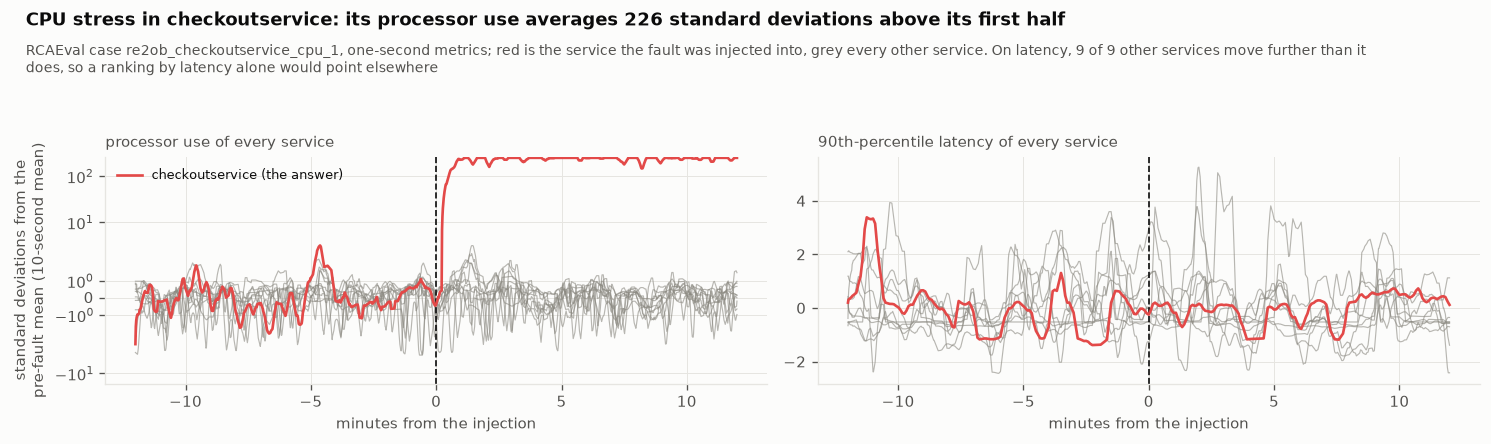

In [67]:
# ---- the same failure, drawn: every service's processor use and latency, standardised on the minutes before it ----
m = pd.read_parquet(RCA_DIR / EXAMPLE_CASE.case / "metrics.parquet")
minutes = (m.time - EXAMPLE_CASE.inject_time) / 60
before = minutes < 0
root = EXAMPLE_CASE.root_cause_service
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharex=True)
moved = {}
for ax, measure, label in ((axes[0], "cpu", "processor use"), (axes[1], "latency-90", "90th-percentile latency")):
    for c in [c for c in m.columns if c.endswith("_" + measure)]:
        x = m[c].astype(float)
        sd = x[before].std()
        z = (x - x[before].mean()) / (sd if sd > 0 else 1.0)
        svc = c[: -len(measure) - 1]
        ax.plot(minutes, z.rolling(10, min_periods=1).mean(), color=C8 if svc == root else MUTED,
                lw=1.6 if svc == root else 0.7, alpha=1 if svc == root else 0.6, zorder=3 if svc == root else 2,
                label=f"{svc} (the answer)" if svc == root else None)
        moved[(measure, svc)] = float(z[~before].mean())
    ax.axvline(0, color=INK, ls="--", lw=1)
    if measure == "cpu":                                  # the stressed service leaves every other line far below
        ax.set_yscale("symlog", linthresh=3)
    ax.set_title(f"{label} of every service", fontsize=9, color=INK2, loc="left")
    ax.set_xlabel("minutes from the injection")
axes[0].set_ylabel("standard deviations from the\npre-fault mean (10-second mean)")
axes[0].legend(fontsize=7.5, loc="upper left")
root_cpu = moved.get(("cpu", root), float("nan"))
lat = {s: v for (meas, s), v in moved.items() if meas == "latency-90"}
louder = [s for s, v in lat.items() if s != root and abs(v) > abs(lat.get(root, 0.0))]
print(f"  after the injection {root}'s processor use averages {root_cpu:+.1f} standard deviations from its own first "
      f"half; on p90 latency, {len(louder)} of {len(lat) - 1} other services move further than it does"
      + (f" ({', '.join(louder[:4])})" if louder else ""))
finish(fig, "rcaeval_case",
       f"{EXAMPLE_CASE.fault_description} in {root}: its processor use averages {root_cpu:.0f} standard deviations above "
       "its first half",
       f"RCAEval case {EXAMPLE_CASE.case}, one-second metrics; red is the service the fault was injected into, grey "
       f"every other service. On latency, {len(louder)} of {len(lat) - 1} other services move further than it does, "
       "so a ranking by latency alone would point elsewhere")

In [68]:
# ---- the whole lab, counted from Parquet footers without reading a single row ----
lab_rows = {"metrics_points": 0, "log_lines": 0, "spans": 0}
for c in CHOSEN.case:
    for kind, info in case_tables(c).items():
        if kind == "metrics":
            lab_rows["metrics_points"] += info["rows"] * (len(info["columns"]) - 1)
        elif kind == "logs":
            lab_rows["log_lines"] += info["rows"]
        else:
            lab_rows["spans"] += info["rows"]
for k, v in lab_rows.items():
    print(f"  {k:<16}{v:>16,}")
print(f"  {'total':<16}{sum(lab_rows.values()):>16,}")

  metrics_points        90,003,597
  log_lines             49,652,771
  spans                110,714,052
  total                250,370,420


**360 failures, 250,370,420 rows, 3.32 GB.** RE2 gives 270 cases of six infrastructure faults
(CPU, memory, disk, network delay, packet loss, broken sockets) across three applications with
five candidate services each; RE3 adds 90 cases of real code bugs. Every case is 24 minutes
long with the fault starting halfway; 359 of the 360 carry logs and 240 carry traces, because
Sock Shop records none. Next to OpenRCA these are small worlds, but they are the only place
where the same kind of failure repeats dozens of times with an unambiguous answer, so they are
where we compare against the classic statistical methods on exactly the same data.

## 8 · Base rates: how often a change lands just before anything at all

**Theory.** The post's correlation engine gives "a deployment, then errors" a prior of 0.9, and
its flywheel learns rules such as "deployments cause 40% of SEV-2 incidents". Both rest on a
comparison the post never shows: how often does a change land shortly before an incident,
compared with how often one lands shortly before any moment at all? At a company that changes
production a few hundred times a day, the second number is close to one, and then "a change
happened in the hour before" says almost nothing on its own. This section measures that base
rate on Wikimedia's real Server Admin Log, by kind of change and by window length, against the
simplest model of random arrivals, the Poisson process, and then against the incidents
themselves with a placebo: the same hour of the same weekday, in other weeks. Section 26 uses
these numbers as the bar the correlation engine has to clear. World: Wikimedia.

In [69]:
# ---- what kind of change is this? a small taxonomy, read off the log itself ----
CHANGE_KINDS = [      # first match wins, so a cookbook that depools a node is a capacity change, not maintenance
    ("capacity", re.compile(r"\b(?:de|re)?pool(?:ing|ed|s)?\b|pool-depool|depool-rack|sre\.mysql\.(?:de)?pool"
                            r"|\bconftool\b", re.I)),
    ("deploy", re.compile(r"\bscap\b|\bbackport\b|\btrain\b|synchroni[sz]ed|started deploy|\bhelmfile\b|\bdeployed\b"
                          r"|\broll(?:ing|ed)?[ -]?back|\brevert", re.I)),
    ("config", re.compile(r"sre\.(?:puppet|dns|network)\.|authdns|\bpuppet\b|\bdbctl\b|\bconfig|\bhiera", re.I)),
    ("maintenance", re.compile(r"sre\.(?:hosts|hardware|ganeti|swift|elasticsearch|k8s|cassandra|kafka)\.|reimag"
                               r"|reboot|restart|upgrad|install|downtime|maintenance|firmware|decommission|schema",
                               re.I)),
]
COMPLETION = re.compile(r"^\s*(?:END \(|helmfile \[[^\]]+\] DONE|Finished\b)", re.I)   # the second half of a START


def change_kind(message: str) -> str:
    for kind, pattern in CHANGE_KINDS:
        if pattern.search(message or ""):
            return kind
    return "other"


KIND_CASES = [
    ("Started scap sync-world: Backport for [[gerrit:1|fix a typo]]", "deploy"),
    ("helmfile [eqiad] START helmfile.d/services/api-gateway: apply", "deploy"),
    ("dbctl commit (dc=all): 'db1127 (re)pooling @ 50%: Repooling'", "capacity"),
    ("START - Cookbook sre.k8s.pool-depool-node depool for host wikikube-worker1001", "capacity"),
    ("START - Cookbook sre.hosts.reimage for host db1200.eqiad.wmnet with OS bookworm", "maintenance"),
    ("START - Cookbook sre.dns.netbox", "config"),
    ("Installing mariadb 10.6.20 on db1198", "maintenance"),
    ("Rolling back deployment", "deploy"),
]
kind_ok = sum(change_kind(m) == want for m, want in KIND_CASES)
for m, want in KIND_CASES:
    got = change_kind(m)
    print(f"  {'PASS' if got == want else 'FAIL'}  {got:<12}{m[:78]}")
done_ok = all(COMPLETION.match(m) for m in ("END (PASS) - Cookbook sre.hosts.downtime (exit_code=0)",
                                            "Finished scap sync-world: Backport (duration: 07m 12s)"))
print(f"  {'PASS' if done_ok else 'FAIL'}  completion lines are recognised, so one action counts once")
print(f"  [test] {kind_ok}/{len(KIND_CASES)} kinds right")

  PASS  deploy      Started scap sync-world: Backport for [[gerrit:1|fix a typo]]
  PASS  deploy      helmfile [eqiad] START helmfile.d/services/api-gateway: apply
  PASS  capacity    dbctl commit (dc=all): 'db1127 (re)pooling @ 50%: Repooling'
  PASS  capacity    START - Cookbook sre.k8s.pool-depool-node depool for host wikikube-worker1001
  PASS  maintenance START - Cookbook sre.hosts.reimage for host db1200.eqiad.wmnet with OS bookwor
  PASS  config      START - Cookbook sre.dns.netbox
  PASS  maintenance Installing mariadb 10.6.20 on db1198
  PASS  deploy      Rolling back deployment
  PASS  completion lines are recognised, so one action counts once
  [test] 8/8 kinds right


In [70]:
# ---- the change stream: one row per change, inside the window where we also have the chat ----
CHAT_START = IRC.ts.min().floor("D")
CHANGES = SAL[(SAL.ts >= CHAT_START) & ~SAL.message.fillna("").str.match(COMPLETION)].copy()
CHANGES["message"] = CHANGES.message.fillna("")
CHANGES["kind"] = CHANGES.message.map(change_kind)
days = (CHANGES.ts.max() - CHANGES.ts.min()).total_seconds() / 86400
print(f"  {len(CHANGES):,} changes in {days:,.0f} days ({len(SAL[SAL.ts >= CHAT_START]) - len(CHANGES):,} completion "
      f"lines dropped); {len(CHANGES) / days:,.0f} a day, one every {days * 1440 / len(CHANGES):.1f} minutes")
print(f"\n  {'kind':<13}{'changes':>9}{'share':>8}{'per day':>9}  example")
print("  " + "-" * 104)
for kind, g in CHANGES.groupby("kind"):
    ex = SCRUB(g.message.sample(1, random_state=SEED).iloc[0])
    print(f"  {kind:<13}{len(g):>9,}{len(g) / len(CHANGES):>8.0%}{len(g) / days:>9.0f}  {ex[:62]}")

  283,743 changes in 1,987 days (139,430 completion lines dropped); 143 a day, one every 10.1 minutes

  kind           changes   share  per day  example
  --------------------------------------------------------------------------------------------------------
  capacity        81,772     29%       41  START - Cookbook sre.k8s.pool-depool-node depool for host dse-
  config          24,348      9%       12  START - Cookbook sre.dns.wipe-cache cirrussearch1061 on all re
  deploy          71,072     25%       36  helmfile [ml-staging-codfw] START helmfile.d/admin 'sync'.
  maintenance     85,157     30%       43  START - Cookbook sre.hosts.reimage for host dse-k8s-worker2010
  other           21,394      8%       11  START - Cookbook sre.deploy.hiddenparma Hiddenparma deployment


In [71]:
# ---- base rates: the chance that a change landed in the last w minutes, at a random moment ----
def to_s(ts: pd.Series) -> np.ndarray:
    """Seconds since 1970, in the given order. Never divide raw int64 by 10**9: pandas 3 may store Parquet times as
    microseconds, and the result would be off by a factor of a thousand without any error."""
    return pd.to_datetime(ts, utc=True).dt.as_unit("s").astype("int64").to_numpy()


def epoch_s(ts: pd.Series) -> np.ndarray:
    return np.sort(to_s(ts))


T_CH = epoch_s(CHANGES.ts)
WINDOWS = [5, 10, 15, 30, 60, 120, 360]


def changes_before(moments: np.ndarray, minutes: float, times: np.ndarray = T_CH) -> np.ndarray:
    """How many changes fall in (t - minutes, t] for every t, by binary search on sorted times."""
    return np.searchsorted(times, moments, side="right") - np.searchsorted(times, moments - minutes * 60, side="right")


def hour_of_week(seconds: np.ndarray) -> np.ndarray:
    return (seconds // 3600 + 72) % 168            # 1970-01-01 was a Thursday; 0 here is Monday 00:00 UTC


rng = np.random.default_rng(SEED)
RANDOM_MOMENTS = rng.integers(T_CH[0] + 86400, T_CH[-1], 20000)
span_hours = np.arange(T_CH[0] // 3600, T_CH[-1] // 3600 + 1)
hourly = np.bincount((T_CH // 3600 - span_hours[0]).astype(int), minlength=len(span_hours))
weeks_seen = np.bincount(hour_of_week(span_hours * 3600), minlength=168)
rate_how = np.where(weeks_seen > 0, np.bincount(hour_of_week(T_CH), minlength=168) / np.maximum(weeks_seen, 1),
                    hourly.mean())                                             # changes per hour, per hour of week
cum = np.concatenate([[0], np.cumsum(np.tile(np.repeat(rate_how / 60, 60), 2))])  # per-minute intensity, two weeks


def poisson_how(moments: np.ndarray, minutes: int) -> np.ndarray:
    """Expected changes in (t - minutes, t] if arrivals were Poisson with the real hour-of-week rhythm."""
    end = (moments // 60 + 72 * 60) % 10080 + 10080 + 1
    return cum[end] - cum[end - minutes]


lam = len(T_CH) / ((T_CH[-1] - T_CH[0]) / 60)                                   # changes per minute
dispersion = hourly.var() / hourly.mean()
resid_disp = (hourly - rate_how[hour_of_week(span_hours * 3600)]).var() / hourly.mean()
BASE_RATE = {}
print(f"  hourly counts: mean {hourly.mean():.1f}, variance {hourly.var():.1f}; variance/mean = {dispersion:.1f} "
      f"(a Poisson process gives 1.0), {resid_disp:.1f} after removing the weekly rhythm")
print(f"\n  {'window':>8}{'measured':>10}{'Poisson':>9}{'Poisson+week':>14}{'mean changes':>14}")
print("  " + "-" * 56)
for w in WINDOWS:
    n = changes_before(RANDOM_MOMENTS, w)
    BASE_RATE[w] = {"measured": (n > 0).mean(), "poisson": 1 - math.exp(-lam * w),
                    "poisson_week": (1 - np.exp(-poisson_how(RANDOM_MOMENTS, w))).mean(), "mean": n.mean()}
    b = BASE_RATE[w]
    print(f"  {w:>6}m{b['measured']:>10.1%}{b['poisson']:>9.1%}{b['poisson_week']:>14.1%}{b['mean']:>14.1f}")
print("\n  by kind, at a random moment:")
for kind in ("deploy", "config", "capacity", "maintenance"):
    t_k = epoch_s(CHANGES.loc[CHANGES.kind == kind, "ts"])
    p = {w: (changes_before(RANDOM_MOMENTS, w, t_k) > 0).mean() for w in (10, 30, 60)}
    print(f"    {kind:<13}" + "   ".join(f"{w:>3}m {v:6.1%}" for w, v in p.items()))

  hourly counts: mean 5.9, variance 79.9; variance/mean = 13.4 (a Poisson process gives 1.0), 8.6 after removing the weekly rhythm

    window  measured  Poisson  Poisson+week  mean changes
  --------------------------------------------------------
       5m     24.4%    39.1%         33.7%           0.5
      10m     35.1%    62.9%         49.8%           1.0
      15m     41.7%    77.4%         58.8%           1.5
      30m     50.3%    94.9%         71.9%           3.0
      60m     58.9%    99.7%         82.8%           5.9
     120m     66.9%   100.0%         91.9%          11.9
     360m     79.9%   100.0%         99.5%          36.2

  by kind, at a random moment:
    deploy        10m  12.3%    30m  23.7%    60m  33.9%
    config        10m   4.3%    30m   9.7%    60m  15.8%
    capacity      10m  16.3%    30m  25.1%    60m  30.7%
    maintenance   10m  17.5%    30m  32.5%    60m  43.3%


[fig] artifacts\figures_full\base_rates.png


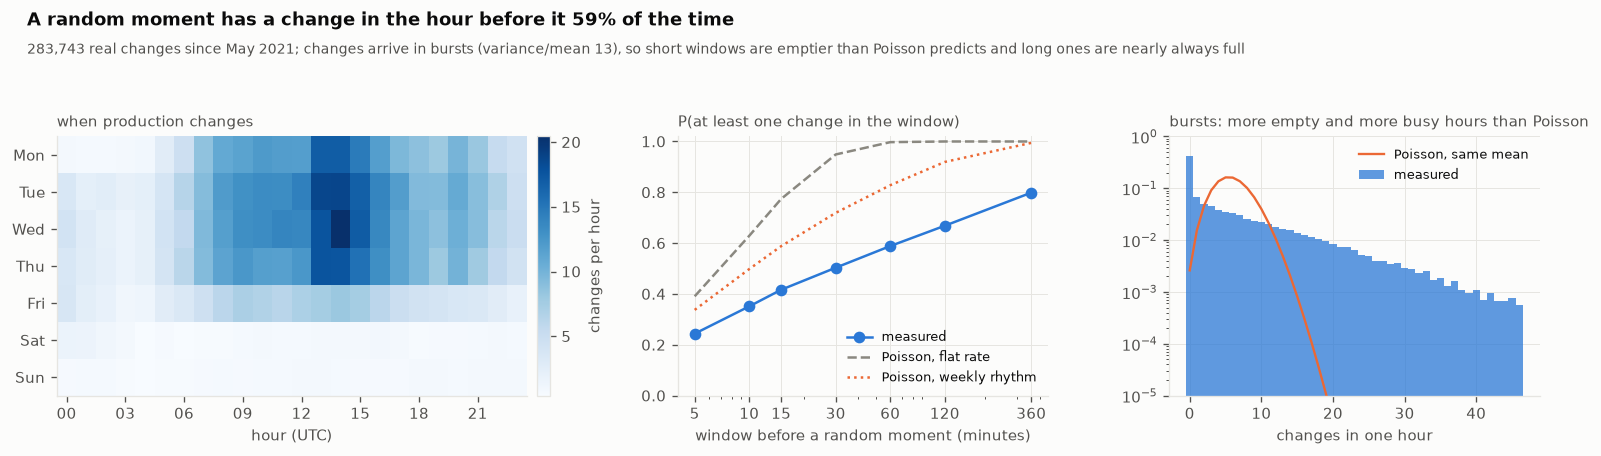

In [72]:
# ---- the base rate, drawn: a weekly rhythm, bursts, and windows that almost always contain a change ----
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.35, 1, 1]})
ax = axes[0]
grid = rate_how.reshape(7, 24)
im = ax.imshow(grid, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 3), [f"{h:02d}" for h in range(0, 24, 3)])
ax.set_xlabel("hour (UTC)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="changes per hour")
ax.set_title("when production changes", fontsize=9, color=INK2, loc="left")
ax = axes[1]
ax.plot(WINDOWS, [BASE_RATE[w]["measured"] for w in WINDOWS], "o-", color=C1, label="measured")
ax.plot(WINDOWS, [BASE_RATE[w]["poisson"] for w in WINDOWS], "--", color=MUTED, label="Poisson, flat rate")
ax.plot(WINDOWS, [BASE_RATE[w]["poisson_week"] for w in WINDOWS], ":", color=C2, label="Poisson, weekly rhythm")
ax.set_xscale("log")
ax.set_xticks(WINDOWS, [str(w) for w in WINDOWS])
ax.set_ylim(0, 1.02)
ax.set_xlabel("window before a random moment (minutes)")
ax.set_title("P(at least one change in the window)", fontsize=9, color=INK2, loc="left")
ax.legend(fontsize=7.5, loc="lower right")
ax = axes[2]
k = np.arange(0, int(np.percentile(hourly, 99.5)) + 1)
ax.bar(k, np.bincount(hourly, minlength=k.max() + 1)[: len(k)] / len(hourly), color=C1, width=1.0, alpha=0.75,
       label="measured")
pois = np.exp(k * math.log(hourly.mean()) - hourly.mean() - np.array([math.lgamma(x + 1) for x in k]))
ax.plot(k, pois, color=C2, lw=1.4, label="Poisson, same mean")
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlabel("changes in one hour")
ax.set_title("bursts: more empty and more busy hours than Poisson" if dispersion > 1.5
             else "hourly counts against Poisson", fontsize=9, color=INK2, loc="left")
ax.legend(fontsize=7.5)
finish(fig, "base_rates",
       f"A random moment has a change in the hour before it {BASE_RATE[60]['measured']:.0%} of the time",
       f"{len(CHANGES):,} real changes since {CHAT_START:%B %Y}; changes arrive in bursts (variance/mean "
       f"{dispersion:.0f}), so short windows are emptier than Poisson predicts and long ones are nearly always full")

In [73]:
# ---- the comparison that matters: before incidents, against the same hour of other weeks ----
START_MARK = re.compile(r"outage begins|start of (?:user )?impact|impact (?:begins|starts|started)", re.I)


def impact_start(r) -> pd.Timestamp | None:
    """The scorecard's start time, else a timeline bullet marked as the start, else the first timed bullet."""
    m = re.match(r"\s*(\d{4}-\d\d-\d\d)?[ T]?(\d{1,2}):(\d\d)", r["start_raw"] or "")
    if m:
        return pd.Timestamp(f"{m.group(1) or r['date']} {int(m.group(2)):02d}:{m.group(3)}", tz="UTC")
    tl = [(t, s) for t, s in r["timeline"]]
    marked = [t for t, s in tl if START_MARK.search(s)]
    return pd.Timestamp((marked or [tl[0][0]])[0]) if tl else None


inc_w = INCIDENTS[INCIDENTS.date >= CHAT_START.date()].copy()
inc_w["start"] = pd.to_datetime([impact_start(r) for _, r in inc_w.iterrows()], utc=True)
inc_w = inc_w.dropna(subset=["start"])
inc_w = inc_w[(inc_w.start >= CHAT_START + pd.Timedelta(days=1)) & (inc_w.start <= CHANGES.ts.max())]
T_INC = epoch_s(inc_w.start)


def placebo_moments(t_inc: np.ndarray, weeks: int = 6) -> tuple[np.ndarray, np.ndarray]:
    """The same weekday and hour, 1 to `weeks` weeks either side, kept only if no incident started within a day."""
    offsets = np.array([k * 7 * 86400 for k in range(-weeks, weeks + 1) if k])
    moments = t_inc[:, None] + offsets[None, :]
    near = np.abs(moments[:, :, None] - t_inc[None, None, :]).min(axis=2) < 86400
    return moments, (~near) & (moments > T_CH[0] + 86400) & (moments < T_CH[-1])


def incident_vs_placebo(times: np.ndarray, windows=WINDOWS, boots: int = 2000) -> pd.DataFrame:
    rows, rb = [], np.random.default_rng(SEED)
    for w in windows:
        hit_i = changes_before(T_INC, w, times) > 0
        hit_p = np.where(valid, changes_before(placebo.ravel(), w, times).reshape(placebo.shape) > 0, np.nan)
        per_inc_p = np.nanmean(hit_p, axis=1)                    # each incident's own placebo rate
        keep = ~np.isnan(per_inc_p)
        diffs = []
        for _ in range(boots):
            idx = rb.integers(0, keep.sum(), keep.sum())
            diffs.append(hit_i[keep][idx].mean() - per_inc_p[keep][idx].mean())
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"window": w, "incidents": hit_i[keep].mean(), "placebo": per_inc_p[keep].mean(),
                     "diff": hit_i[keep].mean() - per_inc_p[keep].mean(), "lo": lo, "hi": hi})
    return pd.DataFrame(rows)


VS_PLACEBO = {}
if len(T_INC) < 10:
    print(f"  {len(T_INC)} incidents in this profile's chat window: too few to compare; the FULL profile has them all")
else:
    placebo, valid = placebo_moments(T_INC)
    print(f"  {len(T_INC)} incidents with a start time inside the chat window; {valid.sum():,} placebo moments "
          f"(same weekday and hour, 1 to 6 weeks away, no incident within a day)")
    for kind in ("all", "deploy"):
        times = T_CH if kind == "all" else epoch_s(CHANGES.loc[CHANGES.kind == kind, "ts"])
        VS_PLACEBO[kind] = incident_vs_placebo(times)
        print(f"\n  {kind} changes: P(at least one in the window)")
        print(f"  {'window':>8}{'incidents':>11}{'placebo':>9}{'difference':>12}{'95% CI':>18}")
        for _, r in VS_PLACEBO[kind].iterrows():
            print(f"  {r.window:>6.0f}m{r.incidents:>11.1%}{r.placebo:>9.1%}{r['diff']:>+12.1%}"
                  f"   [{r.lo:+.1%}, {r.hi:+.1%}]")

  146 incidents with a start time inside the chat window; 1,408 placebo moments (same weekday and hour, 1 to 6 weeks away, no incident within a day)



  all changes: P(at least one in the window)
    window  incidents  placebo  difference            95% CI
       5m      43.8%    35.4%       +8.5%   [+1.8%, +15.4%]
      10m      57.5%    48.4%       +9.2%   [+2.6%, +15.8%]
      15m      63.7%    57.2%       +6.5%   [-0.0%, +12.9%]
      30m      72.6%    66.9%       +5.7%   [-0.2%, +11.1%]
      60m      78.8%    73.1%       +5.6%   [+0.7%, +11.0%]
     120m      84.9%    79.9%       +5.0%   [+0.6%, +9.3%]
     360m      91.1%    88.1%       +3.0%   [-0.0%, +6.0%]



  deploy changes: P(at least one in the window)
    window  incidents  placebo  difference            95% CI
       5m      17.8%    10.8%       +7.0%   [+0.8%, +12.9%]
      10m      23.3%    16.2%       +7.1%   [+1.0%, +13.4%]
      15m      30.8%    21.0%       +9.8%   [+3.8%, +16.2%]
      30m      40.4%    31.4%       +9.0%   [+1.5%, +16.3%]
      60m      52.7%    43.4%       +9.4%   [+2.5%, +16.3%]
     120m      63.0%    56.3%       +6.7%   [+1.0%, +12.9%]
     360m      77.4%    74.6%       +2.8%   [-0.9%, +6.7%]


[fig] artifacts\figures_full\incidents_vs_placebo.png


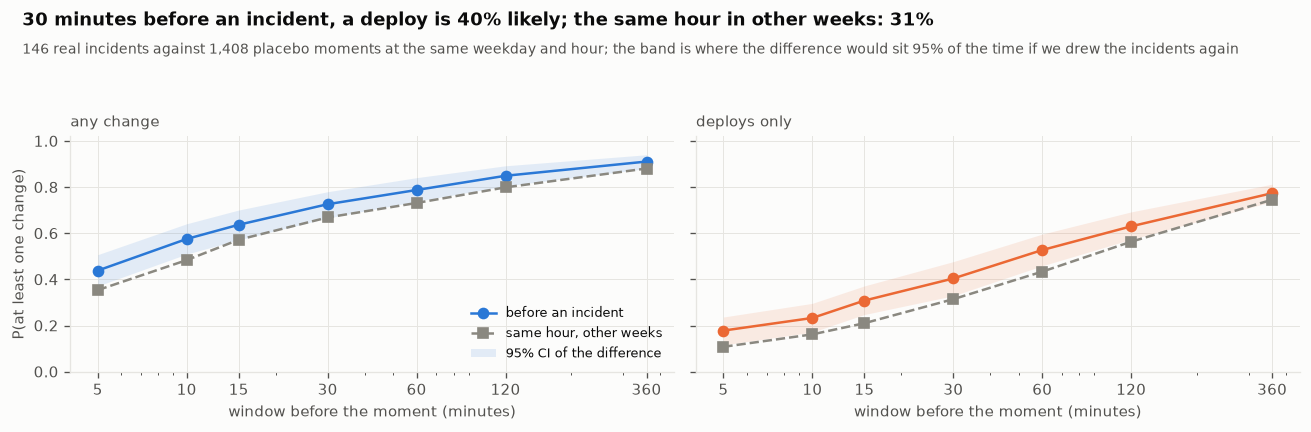

In [74]:
# ---- incidents against their placebo, drawn ----
def draw_vs_placebo() -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
    for ax, kind, colour in ((axes[0], "all", C1), (axes[1], "deploy", C2)):
        d = VS_PLACEBO[kind]
        ax.plot(d.window, d.incidents, "o-", color=colour, label="before an incident")
        ax.plot(d.window, d.placebo, "s--", color=MUTED, label="same hour, other weeks")
        ax.fill_between(d.window, d.placebo + d.lo, d.placebo + d.hi, color=colour, alpha=0.12, lw=0,
                        label="95% CI of the difference")
        ax.set_xscale("log")
        ax.set_xticks(WINDOWS, [str(w) for w in WINDOWS])
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("window before the moment (minutes)")
        ax.set_title("any change" if kind == "all" else "deploys only", fontsize=9, color=INK2, loc="left")
    axes[0].set_ylabel("P(at least one change)")
    axes[0].legend(fontsize=7.5, loc="lower right")
    d30 = VS_PLACEBO["deploy"].set_index("window").loc[30]
    finish(fig, "incidents_vs_placebo",
           f"30 minutes before an incident, a deploy is {d30.incidents:.0%} likely; the same hour in other weeks: "
           f"{d30.placebo:.0%}",
           f"{len(T_INC)} real incidents against {valid.sum():,} placebo moments at the same weekday and hour; the "
           f"band is where the difference would sit 95% of the time if we drew the incidents again")


if VS_PLACEBO:
    draw_vs_placebo()
else:
    print("  [skip] no comparison in this profile")

**In the half hour before a real incident, a deploy had landed 40.4% of the time; at the same
weekday and hour in other weeks, 31.4% of the time.** The gap is real, its 95% interval of +1.5 to
+16.3 points excludes zero, but it is small: a recent deploy is 1.29 times as common before an
incident as at a comparable quiet moment. That is weak evidence on its own, and the reason is the
base rate. Wikimedia logs 143 changes a day, and they arrive in bursts: the variance of the hourly
count is 13.4 times its mean, where random arrivals would give 1.0. So a random moment has a change
of some kind in the hour before it 58.9% of the time (a Poisson model with the same weekly rhythm
says 82.8%, overstating it because bursts leave long empty stretches). For the post's correlation
engine this matters directly. It gives "deployment, then errors" a prior of 0.9, but here a
placebo moment would offer a deploy to link to almost one time in three. Section 26 runs exactly
that placebo against the engine.

## 9 · The users layer, and the incident we follow from here on

**Theory.** The post tells its story through one incident, a home-page regression, and lets
every layer of the system take its turn with it. We do the same with a real one. The incident
we follow has to be fair to the post's design and rich enough to test it: caused by a change,
discussed live in the on-call channel, announced by alerts, and visible to readers, because
Figure 1 puts the users at the top of the picture and calls what they experience the first
signal and the last measure of an incident. Wikimedia publishes that layer in full: how many
times every page of every wiki was viewed, every hour. Once the incident is chosen, we download
the whole week around it, every page and every hour, and ask which readers lost what. World:
Wikimedia.

In [75]:
# ---- choosing the incident we follow: caused by a change, argued over live, seen by readers ----
CHANGE_WORDS = re.compile(r"\b(?:deploy(?:ed|ment|s)?|config(?:uration)? change|patch(?:es)?|merged|backport|scap"
                          r"|train|roll(?:ed|ing)?[ -]?back|revert(?:ed)?|upgrade[ds]?)\b", re.I)
T_HUMAN = epoch_s(IRC.loc[~IRC.bot, "ts"])
T_ALERT = epoch_s(IRC.loc[IRC.nick.isin(["jinxer-wm", "icinga-wm"]), "ts"])
T_DEPLOY = epoch_s(CHANGES.loc[CHANGES.kind == "deploy", "ts"])
traffic_wide = TRAFFIC.pivot_table(index="ts", columns="project", values="views")


def count_between(times: np.ndarray, a: int, b: int) -> int:
    return int(np.searchsorted(times, b, side="left") - np.searchsorted(times, a, side="left"))


def dip_at(h: pd.Timestamp, projects=("all-projects", "en.wikipedia")) -> float:
    """How far one hour's human pageviews fell below the same hour one and two weeks either side, for all wikis
    together or for English Wikipedia, whichever fell further."""
    if h not in traffic_wide.index:
        return np.nan
    base = traffic_wide.reindex([h + pd.Timedelta(weeks=k) for k in (-2, -1, 1, 2)])[list(projects)].median()
    return float((1 - traffic_wide.loc[h, list(projects)] / base.where(base > 0)).max())


def first_reader_rule(start: pd.Timestamp, hours: int = 3) -> float:
    """Our second version, kept so its failure stays visible: the deepest dip over the first hours. (The first took
    the largest swing on any of twelve projects and scored an incident with no reader impact at 70%.)"""
    return max([d for h in pd.date_range(start.floor("h"), periods=hours, freq="h") if (d := dip_at(h)) == d] or [0.0])


def reader_impact(start: pd.Timestamp, hours: int = 3) -> float:
    """The deepest dip over the first hours that did not also happen at the same hour the day before or after.
    A dip that comes back at the same hour on a quiet day belongs to the measurement, not to the incident."""
    worst = 0.0
    for h in pd.date_range(start.floor("h"), periods=hours, freq="h"):
        d = dip_at(h)
        if d == d:
            side = np.nanmax([dip_at(h - pd.Timedelta(days=1)), dip_at(h + pd.Timedelta(days=1)), 0.0])
            worst = max(worst, d - side)
    return worst


# the bar a dip must clear: what the same measure gives at random hours, when no incident is chosen at all
calm = traffic_wide.index[(traffic_wide.index >= traffic_wide.index.min() + pd.Timedelta(days=15))
                          & (traffic_wide.index <= traffic_wide.index.max() - pd.Timedelta(days=15))]
READER_HOURS = calm[np.random.default_rng(SEED).choice(len(calm), min(1000, len(calm)), replace=False)] if len(calm) else calm
READER_PLACEBO = np.array([reader_impact(h) for h in READER_HOURS]) if len(READER_HOURS) else np.array([0.0])
FIRST_RULE_PLACEBO = np.array([first_reader_rule(h) for h in READER_HOURS]) if len(READER_HOURS) else np.array([0.0])
READER_BAR = max(float(np.nanpercentile(READER_PLACEBO, 95)), 0.01)


cand = inc_w.copy()
cand["change_words"] = [len(CHANGE_WORDS.findall(f"{r.summary} {r.detection} {r.conclusions}")) for r in cand.itertuples()]
cand["timed"] = cand.timeline.apply(len)
s0 = to_s(cand.start)
cand["chat"] = [count_between(T_HUMAN, t - 1800, t + 3 * 3600) for t in s0]
cand["alerts"] = [count_between(T_ALERT, t - 1800, t + 3 * 3600) for t in s0]
cand["deploys_6h"] = [count_between(T_DEPLOY, t - 6 * 3600, t) for t in s0]
cand["readers"] = [reader_impact(s) for s in cand.start]
cand["first_rule"] = [first_reader_rule(s) for s in cand.start]
RULES = {"change_words": 1, "timed": 8, "chat": 30, "alerts": 3, "deploys_6h": 1, "readers": round(READER_BAR, 4)}
eligible = cand.iloc[:0]
for drop in ([], ["readers"], ["readers", "alerts"]):          # relax the weakest evidence first, and say so
    rules = {k: v for k, v in RULES.items() if k not in drop}
    eligible = cand[np.all([cand[k] >= v for k, v in rules.items()], axis=0)].copy() if len(cand) else cand.iloc[:0]
    if len(eligible):
        if drop:
            print(f"  no incident passed every rule; relaxed: {drop}")
        break
for k in ("timed", "chat", "alerts", "readers"):
    eligible[k + "_rank"] = eligible[k].rank(pct=True)
eligible["score"] = eligible[[k + "_rank" for k in ("timed", "chat", "alerts", "readers")]].mean(axis=1)
eligible = eligible.sort_values("score", ascending=False)
print(f"  readers: at {len(READER_HOURS):,} random hours, a dip of 3% or more (our second rule) shows up "
      f"{np.mean(FIRST_RULE_PLACEBO >= 0.03):.0%} of the time; a dip that is not repeated the day before or after "
      f"beats {READER_BAR:.1%} only 5% of the time, so that is the bar")
before = cand.sort_values("first_rule", ascending=False).head(1)
if len(before):
    b = before.iloc[0]
    print(f"  under the second rule the deepest dip belonged to {b['id'].removeprefix('Incidents/')} "
          f"({b['first_rule']:.1%}); repeated-hour check: {b['readers']:.1%}")
print(f"  {len(cand)} incidents with a start time; passing every rule {RULES}: {len(eligible)}")
print(f"\n  {'incident':<46}{'timed':>6}{'chat':>6}{'alerts':>7}{'deploys':>8}{'readers':>9}{'score':>7}")
print("  " + "-" * 89)
for _, r in eligible.head(8).iterrows():
    print(f"  {r['id'].removeprefix('Incidents/')[:45]:<46}{r.timed:>6}{r.chat:>6}{r.alerts:>7}{r.deploys_6h:>8}"
          f"{r.readers:>9.1%}{r.score:>7.2f}")
FLAGSHIP = eligible.iloc[0] if len(eligible) else None
if FLAGSHIP is not None:
    FLAG_T = FLAGSHIP.start
    print(f"\n  the incident we follow: {FLAGSHIP['id']} (impact from {FLAG_T:%Y-%m-%d %H:%M} UTC)")
    plain = re.sub(r"\{\{.*?\}\}|<!--.*?-->", " ", FLAGSHIP.summary, flags=re.S)       # no templates or comments
    plain = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", plain)
    print(textwrap.fill(SCRUB(re.sub(r"\s+", " ", plain)).strip()[:700], width=104,
                        initial_indent="    ", subsequent_indent="    "))
else:
    FLAG_T = None
    print("  [skip] no incident in this profile passes every rule")

  readers: at 1,000 random hours, a dip of 3% or more (our second rule) shows up 31% of the time; a dip that is not repeated the day before or after beats 3.2% only 5% of the time, so that is the bar
  under the second rule the deepest dip belonged to 2024-10-24 codfw pc and kafka mirrormaker issues (24.8%); repeated-hour check: 0.0%
  146 incidents with a start time; passing every rule {'change_words': 1, 'timed': 8, 'chat': 30, 'alerts': 3, 'deploys_6h': 1, 'readers': 0.0324}: 3

  incident                                       timed  chat alerts deploys  readers  score
  -----------------------------------------------------------------------------------------
  2024-04-17 mw-on-k8s eqiad outage                 10   259     75       8     3.9%   0.75
  2025-04-30 Gerrit data corruption                 26   176     53      22     3.5%   0.67
  2021-07-26 ruwikinews DynamicPageList             19    73    793       2     3.4%   0.58

  the incident we follow: Incidents/2024-04-17 mw-on

In [76]:
# ---- the week around it: every page of every wiki, every hour, from the public dumps ----
PV_URL = "https://dumps.wikimedia.org/other/pageviews/{h:%Y}/{h:%Y-%m}/pageviews-{h:%Y%m%d-%H}0000.gz"
PV_RAW, PV_PQ = RAW / "pageviews", PARQUET / "pageviews"
PV_RAW.mkdir(parents=True, exist_ok=True)
PV_PQ.mkdir(parents=True, exist_ok=True)
PV_LOG_FILE = PV_PQ / "_conversion_log.json"
PV_LOG = json.loads(PV_LOG_FILE.read_text()) if PV_LOG_FILE.exists() else {}
PV_READ = ("read_csv({files}, delim=' ', header=false, quote='', escape='', null_padding=true, filename=true, "
           "columns={{'domain': 'VARCHAR', 'title': 'VARCHAR', 'views': 'VARCHAR', 'bytes': 'VARCHAR'}})")


def newline_count(path: Path) -> int:
    n = 0
    with gzip.open(path, "rb") as fh:
        while chunk := fh.read(1 << 24):
            n += chunk.count(b"\n")
    return n


def pv_key(day) -> str:
    return str(day) if FULL_RUN else f"{day}-{RUN_TAG}"


def pv_file(day) -> Path:
    """Only a FULL run writes the canonical day files; smaller profiles keep theirs apart."""
    return PV_PQ / f"pageviews_{day:%Y%m%d}{'' if FULL_RUN else '_' + RUN_TAG}.parquet"


def pageview_day(day: datetime.date, hours: list) -> dict:
    """Fetch one day's hourly files two at a time, write them as one Parquet file, check every line arrived, delete.
    A dump file is named for the hour it closes: pageviews-20241024-130000 holds 12:00 to 13:00, which we
    found by matching the dumps against the per-wiki API, hour by hour, to the view."""
    out, key = pv_file(day), pv_key(day)
    done = PV_LOG.get(key)
    if out.exists() and done and done["hours"] == len(hours) and done.get("hour_is") == "start" and not RECOMPUTE:
        return {**done, "cached": True}
    if free_gb(DATA) - 0.1 * len(hours) < MIN_FREE_GB:
        raise RuntimeError(f"the data drive would drop below {MIN_FREE_GB} GB free; stopping before {day}")
    t0 = time.perf_counter()
    stamps = [h + pd.Timedelta(hours=1) for h in hours]
    paths = [PV_RAW / f"pageviews-{h:%Y%m%d-%H}0000.gz" for h in stamps]
    with ThreadPoolExecutor(2) as ex:                      # two connections at a time, as the dump servers ask
        list(ex.map(lambda hp: WEB.download(PV_URL.format(h=hp[0]), hp[1]), zip(stamps, paths)))
    t_dl = time.perf_counter() - t0
    files = "[" + ", ".join(f"'{p.as_posix()}'" for p in paths) + "]"
    # every line counted by its newline byte: an earlier count split lines on a rare character, until a title in
    # April 2024's dumps made one line look like two
    with ThreadPoolExecutor(4) as ex:
        lines = sum(ex.map(newline_count, paths))
    tmp = out.with_name(out.stem + ".tmp.parquet")
    # sorted by page, so each page's 24 hours sit together: unsorted, the Parquet came out larger than the gzip
    rows = CON.execute(f"COPY (SELECT timezone('UTC', strptime(regexp_extract(filename, 'pageviews-(\\d{{8}}-\\d{{2}})', 1), "
                       f"'%Y%m%d-%H')) - INTERVAL 1 HOUR AS hour, domain, title, TRY_CAST(views AS INTEGER) AS views "
                       f"FROM {PV_READ.format(files=files)} ORDER BY domain, title, hour) TO '{tmp.as_posix()}' "
                       "(FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 1000000)").fetchone()[0]
    assert rows == lines, f"{day}: {lines:,} lines in the dumps but {rows:,} rows written"
    tmp.replace(out)
    gz_bytes = sum(p.stat().st_size for p in paths)
    for p in paths:
        p.unlink()
    rec = {"day": str(day), "hours": len(hours), "hour_is": "start", "rows": int(rows), "gz_bytes": gz_bytes,
           "parquet_bytes": out.stat().st_size, "download_s": round(t_dl, 1), "total_s": round(time.perf_counter() - t0, 1)}
    PV_LOG[key] = rec
    PV_LOG_FILE.write_text(json.dumps(PV_LOG, indent=1))
    return {**rec, "cached": False}


PV_DAYS = []
if FLAG_T is not None:
    if PROFILE == "SMOKE":
        plan = {FLAG_T.date(): [FLAG_T.floor("h"), FLAG_T.floor("h") + pd.Timedelta(hours=1)]}
    else:
        span = 1 if PROFILE == "MEDIUM" else PAGEVIEW_DAYS
        first = FLAG_T.normalize() - pd.Timedelta(days=span // 2)
        plan = {(first + pd.Timedelta(days=d)).date(): list(pd.date_range(first + pd.Timedelta(days=d), periods=24, freq="h"))
                for d in range(span)}
    print(f"  {'day':<12}{'hours':>6}{'gz':>10}{'Parquet':>10}{'rows':>15}{'secs':>7}")
    for day, hours in plan.items():
        r = pageview_day(day, hours)
        PV_DAYS.append(day)
        print(f"  {r['day']:<12}{r['hours']:>6}{r['gz_bytes'] / 1e6:>8.0f}MB{r['parquet_bytes'] / 1e6:>8.0f}MB"
              f"{r['rows']:>15,}{'cached' if r['cached'] else r['total_s']:>7}", flush=True)
    pv_rows = sum(PV_LOG[pv_key(d)]["rows"] for d in PV_DAYS)
    print(f"\n  {pv_rows:,} rows (one per page, wiki and hour), every dump line accounted for; "
          f"{sum(PV_LOG[pv_key(d)]['parquet_bytes'] for d in PV_DAYS) / 1e9:.2f} GB of Parquet")

  day          hours        gz   Parquet           rows   secs
  2024-04-14      24    1330MB     624MB    156,200,615 cached


  2024-04-15      24    1395MB     656MB    163,891,751 cached


  2024-04-16      24    1388MB     652MB    162,809,237 cached


  2024-04-17      24    1368MB     641MB    160,659,081 cached


  2024-04-18      24    1364MB     639MB    160,467,320 cached


  2024-04-19      24    1426MB     696MB    168,067,512 cached


  2024-04-20      24    1456MB     729MB    170,666,962 cached



  1,142,762,478 rows (one per page, wiki and hour), every dump line accounted for; 4.64 GB of Parquet


In [77]:
# ---- readers during the incident: who lost what, against the same hours on the other days ----
if PV_DAYS:
    PV_FILES = "[" + ", ".join(f"'{pv_file(d).as_posix()}'" for d in PV_DAYS) + "]"
    by_hour = CON.execute(f"SELECT hour, domain, sum(views) AS views FROM read_parquet({PV_FILES}) "
                          "GROUP BY ALL").df()
    by_hour["hour"] = pd.to_datetime(by_hour.hour, utc=True)
    total = by_hour.groupby("hour").views.sum()
    window = pd.date_range(FLAG_T.floor("h"), periods=3, freq="h")
    other_days = [h for h in total.index if h.normalize() != FLAG_T.normalize()]
    base_total = pd.Series({h: total[[o for o in other_days if o.hour == h.hour]].median() for h in total.index})
    wide = by_hour.pivot_table(index="hour", columns="domain", values="views", fill_value=0)
    base_dom = pd.DataFrame({h: wide.loc[[o for o in other_days if o.hour == h.hour]].median() for h in window}).T
    during = wide.reindex(window)
    big = base_dom.mean() >= 20000                                       # wikis with at least 20k views an hour
    ratio = (during.loc[:, big].sum() / base_dom.loc[:, big].sum()).sort_values()
    mobile = ratio.index.str.endswith(".m")
    READERS = {"total": float(total.reindex(window).sum() / base_total.reindex(window).sum()),
               "mobile": float(during.loc[:, big & wide.columns.str.endswith(".m")].sum().sum()
                               / base_dom.loc[:, big & wide.columns.str.endswith(".m")].sum().sum()),
               "desktop": float(during.loc[:, big & ~wide.columns.str.endswith(".m")].sum().sum()
                                / base_dom.loc[:, big & ~wide.columns.str.endswith(".m")].sum().sum())}
    print(f"  the three hours from {FLAG_T.floor('h'):%Y-%m-%d %H:00} UTC against the same hours on the other days:")
    for k, v in READERS.items():
        print(f"    {k:<9}{v:7.1%} of the usual views ({v - 1:+.1%})")
    print(f"\n  biggest losses among {big.sum()} wikis with 20k+ views an hour:")
    for d, v in ratio.head(6).items():
        print(f"    {d:<16}{v:7.1%}   {during[d].sum():>12,.0f} views instead of about {base_dom[d].sum():>12,.0f}")
    print("  biggest gains:")
    for d, v in ratio.tail(3)[::-1].items():
        print(f"    {d:<16}{v:7.1%}")
else:
    READERS = {}
    print("  [skip] no pageview days in this profile")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  the three hours from 2024-04-17 09:00 UTC against the same hours on the other days:
    total      98.7% of the usual views (-1.3%)
    mobile     96.7% of the usual views (-3.3%)
    desktop   100.7% of the usual views (+0.7%)

  biggest losses among 72 wikis with 20k+ views an hour:
    no.m              90.5%         57,654 views instead of about       63,706
    he.m              91.2%        211,586 views instead of about      231,904
    fi.m              92.5%        150,681 views instead of about      162,886
    www.wd            93.1%         91,959 views instead of about       98,804
    sv.m              93.1%        191,623 views instead of about      205,752
    nl.m              93.9%        300,455 views instead of about      319,910
  biggest gains:
    hr.m             131.6%
    kk.m             114.3%
    id               112.5%


[fig] artifacts\figures_full\users_layer.png


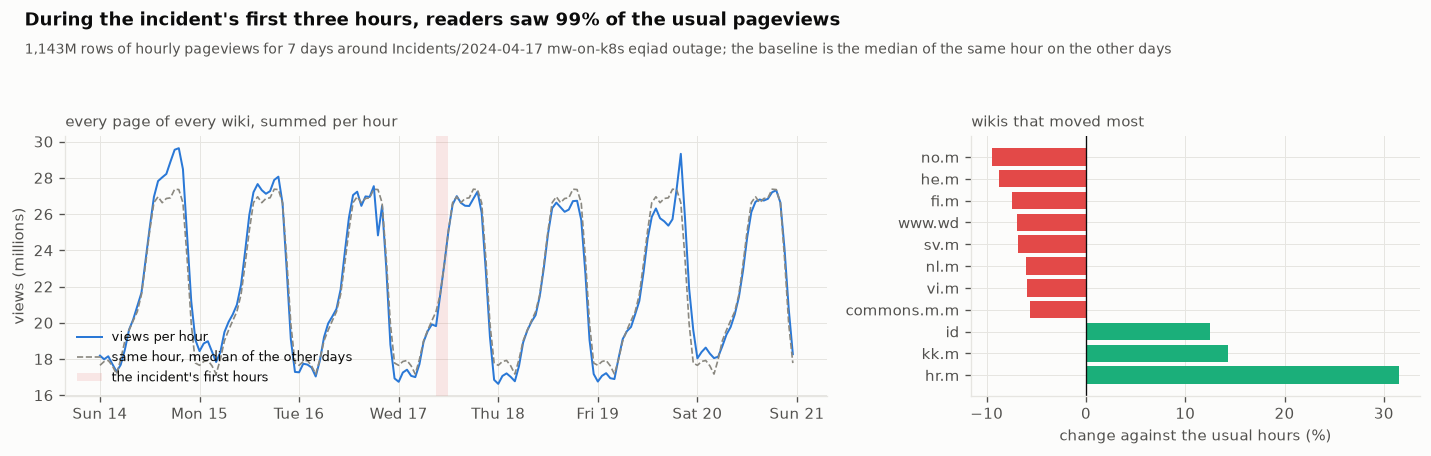

In [78]:
# ---- the users layer, drawn ----
if READERS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.7, 1]})
    ax = axes[0]
    ax.plot(total.index, total / 1e6, color=C1, lw=1.2, label="views per hour")
    ax.plot(base_total.index, base_total / 1e6, color=MUTED, ls="--", lw=1, label="same hour, median of the other days")
    ax.axvspan(window[0], window[-1] + pd.Timedelta(hours=1), color=C8, alpha=0.12, lw=0, label="the incident's first hours")
    ax.set_ylabel("views (millions)")
    ax.legend(fontsize=7.5, loc="lower left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
    ax.set_title("every page of every wiki, summed per hour", fontsize=9, color=INK2, loc="left")
    ax = axes[1]
    show = pd.concat([ratio.head(8), ratio.tail(3)])
    ax.barh(show.index, (show - 1) * 100, color=[C8 if v < 1 else C3 for v in show])
    ax.axvline(0, color=INK, lw=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("change against the usual hours (%)")
    ax.set_title("wikis that moved most", fontsize=9, color=INK2, loc="left")
    finish(fig, "users_layer",
           f"During the incident's first three hours, readers saw {READERS['total']:.0%} of the usual pageviews",
           f"{pv_rows / 1e6:,.0f}M rows of hourly pageviews for {len(PV_DAYS)} days around {FLAGSHIP['id']}; the baseline is "
           "the median of the same hour on the other days")

[fig] artifacts\figures_full\reader_rule_placebo.png


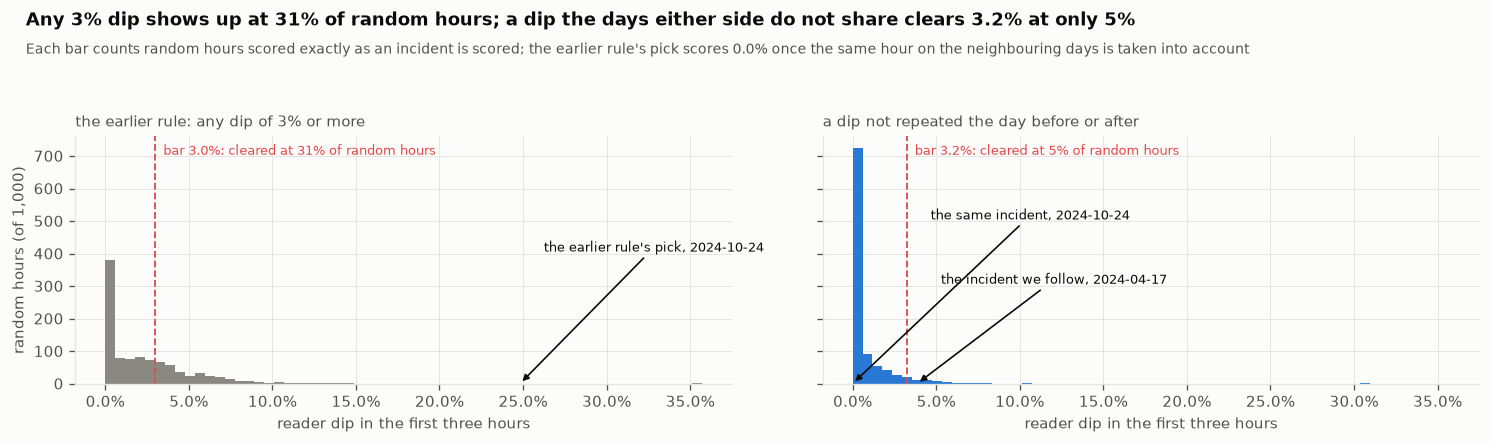

In [79]:
# ---- the reader rule against its own placebo: what random hours score, and where the candidates fall ----
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
top = max(0.3, float(np.nanmax(FIRST_RULE_PLACEBO)))
bins = np.linspace(0, top, 61)
earlier = cand.loc[cand.first_rule.idxmax()] if len(cand) else None
panels = ((axes[0], FIRST_RULE_PLACEBO, 0.03, "the earlier rule: any dip of 3% or more", MUTED),
          (axes[1], READER_PLACEBO, READER_BAR, "a dip not repeated the day before or after", C1))
for ax, values, bar, rule, colour in panels:
    ax.hist(np.clip(values, 0, top), bins=bins, color=colour)
    ax.set_xlabel("reader dip in the first three hours")
    ax.set_title(rule, fontsize=9, color=INK2, loc="left")
y_top = axes[0].get_ylim()[1]                        # shared by both panels once both histograms are drawn
for ax, values, bar, _, _ in panels:
    ax.axvline(bar, color=C8, ls="--", lw=1.1)
    ax.text(bar, y_top * 0.97, f"  bar {bar:.1%}: cleared at {np.mean(values >= bar):.0%} of random hours",
            color=C8, fontsize=8, va="top")
axes[0].set_ylabel(f"random hours (of {len(READER_PLACEBO):,})")
marks = []                                           # (panel, its bar, x, label, height of the label on the axis)
if earlier is not None:
    marks += [(axes[0], 0.03, earlier.first_rule, f"the earlier rule's pick, {earlier['id'][10:20]}", 0.55),
              (axes[1], READER_BAR, earlier.readers, f"the same incident, {earlier['id'][10:20]}", 0.68)]
if FLAGSHIP is not None:
    marks.append((axes[1], READER_BAR, FLAGSHIP.readers, f"the incident we follow, {FLAGSHIP['id'][10:20]}", 0.42))
for ax, bar, x, label, h in marks:
    x = min(x, top)
    ax.annotate(label, (x, 0), xytext=(max(x, bar) + top * 0.04, y_top * h), fontsize=7.8, color=INK, ha="left",
                va="center", arrowprops=dict(arrowstyle="-|>", color=INK, lw=1, shrinkA=0))
for ax in axes:
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
finish(fig, "reader_rule_placebo",
       f"Any 3% dip shows up at {np.mean(FIRST_RULE_PLACEBO >= 0.03):.0%} of random hours; a dip the days either side "
       f"do not share clears {READER_BAR:.1%} at only 5%",
       "Each bar counts random hours scored exactly as an incident is scored; the earlier rule's pick scores "
       f"{earlier.readers if earlier is not None else 0:.1%} once the same hour on the neighbouring days is taken into "
       "account")

**The rule that chose our first incident passed at 31% of random hours, so it was choosing
noise; the corrected rule picks an outage that readers felt, a little.** The second version of
the reader rule counted any dip of 3% or more in an incident's first three hours. Scored the
same way at 1,000 random hours, it fired at 31% of them, and the incident it had picked,
2024-10-24, owed its 24.8% to a noon dip that had happened, just as deep, at the same hour the
day before. A dip now counts only if the same hour stayed normal on the days either side, and it
must clear 3.2%, the bar that only one random hour in twenty clears. Three incidents pass every
rule, and the one we follow is the 2024-04-17 outage of MediaWiki on Kubernetes in eqiad: a
change that moved mcrouter into its own service raised DNS traffic to CoreDNS from about 40,000
to 110,000 requests a second. The full pageview dumps for the week around it, 1,142,762,478
rows, agree with the rule: over the first three hours all wikis together saw 98.7% of their
usual views and mobile readers 96.7%, with the losses concentrated in mobile Norwegian, Hebrew,
Finnish, Swedish and Dutch Wikipedia, down 6 to 10%. Matching the dumps against the per-wiki
API, hour by hour, also showed that a dump file is named for the hour it closes; our first
conversion had every hour one hour late.

## 10 · Scale lab: how fast one laptop eats real telemetry

**Theory.** The post opens with its scale: about 65 million concurrent streams for one boxing
match, more than two billion requests a day, and upwards of 38 million logging events every
second. Nobody replays that on a laptop, and we will not pretend to. What we can do is measure
how fast one machine reads the real telemetry we hold, and then do the arithmetic in the open.
Two numbers matter. The first is raw throughput: how many rows per second DuckDB scans and
aggregates from compressed Parquet here, for the kinds of questions an enricher actually asks.
The second is the one that makes the whole architecture possible: how much smaller the
condensed signals are than the raw rows, because the knowledge graph never stores raw events,
only what an enricher concluded from them. Worlds: OpenRCA and RCAEval, with Wikimedia's record
counted alongside.

In [80]:
# ---- everything we hold, counted from footers and logs rather than by reading rows ----
def footer_rows(paths) -> int:
    return sum(pq.ParquetFile(p).metadata.num_rows for p in paths)


VOLUME = []          # (world, source, rows, bytes on disk)
for name, df, path in (("on-call chat lines", IRC, irc_pq), ("Server Admin Log entries", SAL, sal_pq),
                       ("incident reports", INCIDENTS, inc_pq), ("alert lines (Loki)", ALERTS_LOKI, alerts_pq),
                       ("merged code changes", GERRIT_CHANGES, gerrit_pq), ("hourly traffic points", TRAFFIC, traffic_pq)):
    VOLUME.append(("Wikimedia", name, len(df), path.stat().st_size))
if PV_DAYS:
    VOLUME.append(("Wikimedia", "pageviews (page x hour)", pv_rows,
                   sum(PV_LOG[pv_key(d)]["parquet_bytes"] for d in PV_DAYS)))
for (system, table), recs in itertools.groupby(sorted(CONVERTED.values(), key=lambda r: (r["system"], r["table"])),
                                               key=lambda r: (r["system"], r["table"])):
    recs = list(recs)
    VOLUME.append(("OpenRCA", f"{system} {table}", sum(r["rows"] for r in recs), sum(r["parquet_bytes"] for r in recs)))
rca_bytes = {k: sum((RCA_DIR / c / f"{k}.parquet").stat().st_size for c in CHOSEN.case
                    if (RCA_DIR / c / f"{k}.parquet").exists()) for k in ("metrics", "logs", "traces")}
for label, key, k in (("metric points", "metrics_points", "metrics"), ("log lines", "log_lines", "logs"),
                      ("spans", "spans", "traces")):
    VOLUME.append(("RCAEval", label, lab_rows[key], rca_bytes[k]))
VOLUME = pd.DataFrame(VOLUME, columns=["world", "source", "rows", "bytes"])
print(f"  {'world':<11}{'source':<28}{'rows':>15}{'on disk':>11}")
print("  " + "-" * 66)
for _, r in VOLUME.iterrows():
    print(f"  {r.world:<11}{r.source:<28}{r.rows:>15,}{r.bytes / 1e9:>9.2f} GB")
print("  " + "-" * 66)
for world, g in VOLUME.groupby("world", sort=False):
    print(f"  {world:<39}{g.rows.sum():>15,}{g.bytes.sum() / 1e9:>9.2f} GB")
print(f"  {'all of it':<39}{VOLUME.rows.sum():>15,}{VOLUME.bytes.sum() / 1e9:>9.2f} GB")

  world      source                                 rows    on disk
  ------------------------------------------------------------------
  Wikimedia  on-call chat lines                1,730,378     0.08 GB
  Wikimedia  Server Admin Log entries            538,717     0.02 GB
  Wikimedia  incident reports                        414     0.00 GB
  Wikimedia  alert lines (Loki)                1,690,696     0.06 GB
  Wikimedia  merged code changes                  71,116     0.00 GB
  Wikimedia  hourly traffic points               578,542     0.00 GB
  Wikimedia  pageviews (page x hour)       1,142,762,478     4.64 GB
  OpenRCA    bank logs                        21,356,870     0.20 GB
  OpenRCA    bank metrics                     12,741,066     0.04 GB
  OpenRCA    bank spans                      214,337,882     2.09 GB
  OpenRCA    market_cb1 logs                  25,772,490     0.52 GB
  OpenRCA    market_cb1 metrics               15,550,274     0.02 GB
  OpenRCA    market_cb1 spans      

In [81]:
# ---- a stopwatch that also watches memory: every heavy query from here on runs through it ----
class RamSampler:
    """Samples this process's resident memory every 50 ms on a side thread; DuckDB's buffers live in the same process."""

    def __init__(self, every_s: float = 0.05):
        self.every_s, self._stop, self._proc = every_s, threading.Event(), psutil.Process()
        self.base = self.peak = 0

    def __enter__(self):
        self.base = self.peak = self._proc.memory_info().rss
        self._thread = threading.Thread(target=self._watch, daemon=True)
        self._thread.start()
        return self

    def _watch(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self._proc.memory_info().rss)
            time.sleep(self.every_s)

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()


@dataclass
class Timed:
    name: str
    rows: int
    seconds: float
    extra_gib: float
    out_rows: int

    @property
    def rows_per_s(self) -> float:
        return self.rows / max(self.seconds, 1e-9)


def run_profiled(name: str, sql: str, rows_in: int, con=None) -> tuple[Timed, pd.DataFrame]:
    con = con or CON                     # looked up when called: section 40b replaces the shared connection
    with RamSampler() as ram:
        t0 = time.perf_counter()
        out = con.execute(sql).df()
        took = time.perf_counter() - t0
    t = Timed(name, rows_in, round(took, 3), round((ram.peak - ram.base) / 1024**3, 2), len(out))
    print(f"  {name:<40}{rows_in:>13,}{took:>8.2f}s{t.rows_per_s / 1e6:>9.1f}M/s{t.extra_gib:>8.2f} GiB{len(out):>11,}")
    return t, out


def openrca_files(table: str, system: str = "*") -> list[Path]:
    """The converted files of one table. A SMOKE run takes only the smallest, so it stays a matter of minutes
    even after the full corpus is on disk."""
    files = sorted(OPENRCA_PQ.glob(f"{system}/{table}/*.parquet"), key=lambda f: f.stat().st_size)
    return files[:1] if PROFILE == "SMOKE" else files


def pq_glob(table: str, system: str = "*") -> str | None:
    """What DuckDB's read_parquet should read for one table, or None when this profile has none."""
    files = openrca_files(table, system)
    if not files:
        return None
    return files[0].as_posix() if PROFILE == "SMOKE" else (OPENRCA_PQ / system / table / "*.parquet").as_posix()


print(f"  {'query':<40}{'rows in':>13}{'time':>9}{'speed':>10}{'memory':>12}{'rows out':>11}")

  query                                         rows in     time     speed      memory   rows out


In [82]:
# ---- six questions an enricher asks of raw telemetry, each timed on all of it ----
SPANS, LOGS, METRICS = pq_glob("spans"), pq_glob("logs"), pq_glob("metrics")
scale_file = RES_DIR / "scale_lab.json"
LAB_QUERIES = []
if SPANS:
    n_spans = footer_rows(openrca_files("spans"))
    busy = CON.execute(f"SELECT entity, min(ts) AS t FROM read_parquet('{SPANS}') "
                       "GROUP BY 1 ORDER BY count(*) DESC LIMIT 1").fetchone()
    LAB_QUERIES += [
        ("one entity, one hour (pushdown)", n_spans,
         f"SELECT count(*) AS n, avg(duration_ms) AS ms FROM read_parquet('{SPANS}') WHERE entity = '{busy[0]}' "
         f"AND ts >= TIMESTAMP '{busy[1]:%Y-%m-%d %H}:00:00+00' AND ts < TIMESTAMP '{busy[1]:%Y-%m-%d %H}:00:00+00' + INTERVAL 1 HOUR"),
        ("spans per entity-minute: count, mean, max", n_spans,
         f"SELECT system, entity, date_trunc('minute', ts) AS m, count(*) AS n, avg(duration_ms) AS mean_ms, "
         f"max(duration_ms) AS max_ms FROM read_parquet('{SPANS}') GROUP BY ALL"),
        ("spans per entity-minute: exact p99", n_spans,
         f"SELECT system, entity, date_trunc('minute', ts) AS m, quantile_cont(duration_ms, 0.99) AS p99 "
         f"FROM read_parquet('{SPANS}') GROUP BY ALL"),
        # DuckDB's t-digest approx_quantile ran on one core for over ten minutes on these 380,000 groups and was
        # stopped; a small reservoir per group is the approximation that runs on every core
        ("spans per entity-minute: approximate p99", n_spans,
         f"SELECT system, entity, date_trunc('minute', ts) AS m, reservoir_quantile(duration_ms, 0.99, 256) AS p99 "
         f"FROM read_parquet('{SPANS}') GROUP BY ALL"),
    ]
if LOGS:
    LAB_QUERIES.append(("error-looking log lines per entity-minute", footer_rows(openrca_files("logs")),
                        f"SELECT system, entity, date_trunc('minute', ts) AS m, count(*) AS n FROM read_parquet('{LOGS}') "
                        "WHERE regexp_matches(message, '(?i)error|exception|fail') GROUP BY ALL"))
if PV_DAYS:
    LAB_QUERIES.append(("pageviews: views per wiki per hour", pv_rows,
                        f"SELECT domain, hour, sum(views) AS views FROM read_parquet({PV_FILES}) GROUP BY ALL"))
    day_file = pv_file(FLAG_T.date()).as_posix()
    LAB_QUERIES.append(("pageviews: the day's 20 most-read pages", PV_LOG[pv_key(FLAG_T.date())]["rows"],
                        f"SELECT domain, title, sum(views) AS views FROM read_parquet('{day_file}') "
                        "GROUP BY ALL ORDER BY views DESC LIMIT 20"))
if METRICS:
    LAB_QUERIES.append(("metric series: mean, spread, worst z-score", footer_rows(openrca_files("metrics")),
                        f"SELECT system, entity, kpi, avg(value) AS mu, stddev_pop(value) AS sd, "
                        f"greatest(max(value) - avg(value), avg(value) - min(value)) / NULLIF(stddev_pop(value), 0) "
                        f"AS worst_z FROM read_parquet('{METRICS}') GROUP BY ALL"))


def episodes(minutes: pd.DataFrame, gap_min: int = 2) -> int:
    """Consecutive flagged minutes of one entity, at most gap_min apart, count as one episode: one signal."""
    if minutes.empty:
        return 0
    d = minutes.sort_values(["system", "entity", "m"])
    new = (d.entity != d.entity.shift()) | (d.system != d.system.shift()) | \
          (d.m.diff() > pd.Timedelta(minutes=gap_min))
    return int(new.sum())


if scale_file.exists() and not RECOMPUTE:
    saved = json.loads(scale_file.read_text())
    LAB = [Timed(**t) for t in saved["runs"]]
    P99_ERROR, FUNNEL, DISK_READ = saved["p99_error"], saved["funnel"], saved.get("disk_read")
    SCALE_POWER = saved.get("power")
    print(f"  [cache] measured on {saved['measured_at']}, {power_note(SCALE_POWER)}")
    for t in LAB:
        print(f"  {t.name:<40}{t.rows:>13,}{t.seconds:>8.2f}s{t.rows_per_s / 1e6:>9.1f}M/s{t.extra_gib:>8.2f} GiB"
              f"{t.out_rows:>11,}")
else:
    # read every file once first: a first run that finds the files on disk measures the disk, the rest the work,
    # and the same aggregation came out at 15 and at 52 million rows a second in one run before this was added
    t_read, read_bytes = time.perf_counter(), 0
    for f in [*openrca_files("spans"), *openrca_files("logs"), *openrca_files("metrics"), *map(pv_file, PV_DAYS)]:
        with open(f, "rb") as fh:
            while chunk := fh.read(1 << 24):
                read_bytes += len(chunk)
    DISK_READ = {"gb": round(read_bytes / 1e9, 2), "seconds": round(time.perf_counter() - t_read, 2)}
    LAB, outs = [], {}
    for name, rows_in, sql in LAB_QUERIES:
        t, outs[name] = run_profiled(name, sql, rows_in)
        LAB.append(t)
    P99_ERROR, FUNNEL = None, {}
    if SPANS:
        both = outs["spans per entity-minute: exact p99"].merge(outs["spans per entity-minute: approximate p99"],
                                                               on=["system", "entity", "m"], suffixes=("_exact", "_approx"))
        rel = (both.p99_approx - both.p99_exact).abs() / both.p99_exact.where(both.p99_exact > 0)
        P99_ERROR = {"median": float(rel.median()), "p95": float(rel.quantile(0.95)), "pairs": len(both)}
        per_min = outs["spans per entity-minute: count, mean, max"]
        base = per_min.groupby(["system", "entity"]).mean_ms.transform("median")
        slow = per_min[(per_min.mean_ms > 3 * base) & (per_min.n >= 5)]      # a deliberately simple rule; section 25 refines it
        FUNNEL["spans"] = {"raw rows": n_spans, "entity-minutes": len(per_min), "slow minutes": len(slow),
                           "slow episodes": episodes(slow)}
    if LOGS:
        err = outs["error-looking log lines per entity-minute"]
        FUNNEL["logs"] = {"raw rows": footer_rows(openrca_files("logs")),
                          "entity-minutes": len(err), "slow minutes": int((err.n >= 5).sum()),
                          "slow episodes": episodes(err[err.n >= 5])}
    SCALE_POWER = power_state()
    measured_at = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    scale_file.write_text(json.dumps({"measured_at": measured_at,
                                      "machine": MACHINE, "power": SCALE_POWER, "runs": [asdict(t) for t in LAB],
                                      "p99_error": P99_ERROR, "funnel": FUNNEL, "disk_read": DISK_READ},
                                     indent=1, default=int))
    print(f"  timed {power_note(SCALE_POWER)}")
if DISK_READ:
    print(f"\n  before any clock started, every file these questions touch was read once: {DISK_READ['gb']:.1f} GB in "
          f"{DISK_READ['seconds']:.0f}s ({DISK_READ['gb'] * 1e3 / max(DISK_READ['seconds'], 0.01):.0f} MB/s); the rows "
          "above time the work with the files in memory, not the disk")
if P99_ERROR:
    exact = next(t for t in LAB if t.name.endswith("exact p99"))
    approx = next(t for t in LAB if t.name.endswith("approximate p99"))
    print(f"\n  the approximate p99 (a 256-value reservoir per entity-minute) took {approx.seconds:.1f}s against "
          f"{exact.seconds:.1f}s for the exact one; its error against the exact value: median {P99_ERROR['median']:.1%}, "
          f"95th percentile {P99_ERROR['p95']:.1%} over {P99_ERROR['pairs']:,} entity-minutes")
    if approx.seconds >= 0.8 * exact.seconds:
        print("  At this scale the exact answer is already cheap, so the approximation buys nothing; approximations pay")
        print("  when the data no longer fits one machine, and a stream that never stops is that case.")
    else:
        print(f"  The approximation saves {1 - approx.seconds / exact.seconds:.0%} of the time for that error.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  [cache] measured on 2026-10-31 19:46 UTC, on mains power
  one entity, one hour (pushdown)           396,556,997    0.21s   1861.8M/s    0.13 GiB          1
  spans per entity-minute: count, mean, max  396,556,997    5.88s     67.5M/s    0.81 GiB    380,091
  spans per entity-minute: exact p99        396,556,997    7.76s     51.1M/s    4.80 GiB    380,091
  spans per entity-minute: approximate p99  396,556,997   13.75s     28.8M/s    3.90 GiB    380,091
  error-looking log lines per entity-minute   76,707,680    3.84s     20.0M/s    3.98 GiB     32,989
  pageviews: views per wiki per hour      1,142,762,478    2.22s    515.7M/s    0.28 GiB    299,561
  pageviews: the day's 20 most-read pages   160,659,081   20.95s      7.7M/s    5.74 GiB         20
  metric series: mean, spread, worst z-score   51,283,042    0.36s    143.2M/s    0.14 GiB     14,756

  before any clock started, every file these questions touch was read once: 11.8 GB in 6s (1901 MB/s); the rows above time the work with

In [83]:
# ---- does it scale in a straight line? the same aggregation over more and more of the span files ----
scaling_file = RES_DIR / "scale_scaling.json"
span_files = sorted(openrca_files("spans"), key=lambda p: pq.ParquetFile(p).metadata.num_rows)
SCALING = []
if not span_files:
    print("  [skip] no span files in this profile")
elif scaling_file.exists() and not RECOMPUTE:
    saved_sc = json.loads(scaling_file.read_text())
    SCALING, power_sc = (saved_sc["runs"], saved_sc.get("power")) if isinstance(saved_sc, dict) else (saved_sc, None)
    print(f"  [cache] {scaling_file.name}, {power_note(power_sc)}")
else:
    for k in sorted({n for n in (1, 2, 4, 8, 16, len(span_files)) if n <= len(span_files)}):
        files = span_files[:k]
        listing = "[" + ", ".join(f"'{p.as_posix()}'" for p in files) + "]"
        t0 = time.perf_counter()
        CON.execute(f"SELECT count(*) FROM (SELECT entity, date_trunc('minute', ts) AS m, count(*), avg(duration_ms), "
                    f"max(duration_ms) FROM read_parquet({listing}) GROUP BY ALL)").fetchone()
        SCALING.append({"files": k, "rows": footer_rows(files), "seconds": round(time.perf_counter() - t0, 3)})
    power_sc = power_state()
    scaling_file.write_text(json.dumps({"power": power_sc, "runs": SCALING}, indent=1))
    print(f"  timed {power_note(power_sc)}")
if SCALING:
    xs = np.array([s["rows"] for s in SCALING], float)
    ys = np.array([s["seconds"] for s in SCALING])
    SLOPE, INTERCEPT = np.polyfit(xs, ys, 1)
    r2 = 1 - ((ys - (SLOPE * xs + INTERCEPT)) ** 2).sum() / ((ys - ys.mean()) ** 2).sum()
    print(f"  {'files':>6}{'rows':>15}{'seconds':>9}{'M rows/s':>10}")
    for s in SCALING:
        print(f"  {s['files']:>6}{s['rows']:>15,}{s['seconds']:>9.2f}{s['rows'] / s['seconds'] / 1e6:>10.1f}")
    print(f"\n  straight-line fit: {1 / SLOPE / 1e6:.1f}M rows a second at the margin, {INTERCEPT:.2f}s fixed cost, "
          f"R^2 = {r2:.3f}")

  [cache] scale_scaling.json, on mains power
   files           rows  seconds  M rows/s
       1      5,430,959     0.13      42.1
       2     12,764,323     0.20      64.5
       4     30,636,800     0.42      72.1
       8     67,508,087     1.20      56.1
      16    146,174,309     2.05      71.4
      29    396,556,997     5.18      76.5

  straight-line fit: 77.5M rows a second at the margin, 0.11s fixed cost, R^2 = 0.996


[fig] artifacts\figures_full\scale_lab.png


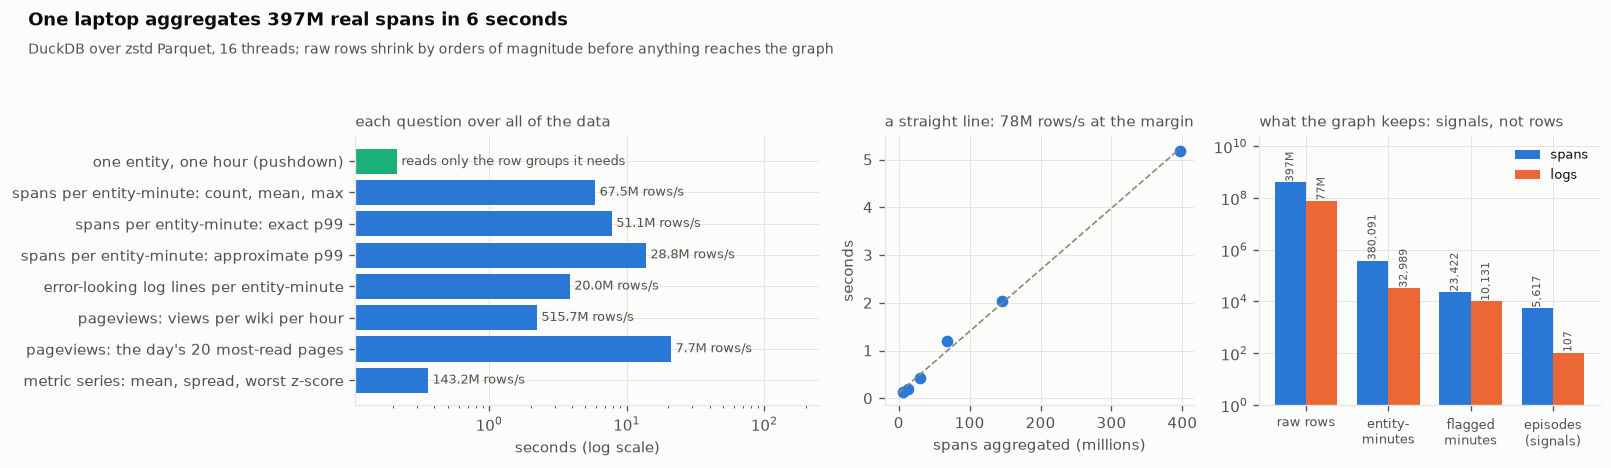

In [84]:
# ---- the lab on one page: speed by question, the straight line, and how much the raw data shrinks ----
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.5, 1, 1.1]})
ax = axes[0]
names = [t.name for t in LAB]
ax.barh(names, [t.seconds for t in LAB], color=[C3 if "pushdown" in t.name else C1 for t in LAB])
for i, t in enumerate(LAB):
    label = "reads only the row groups it needs" if "pushdown" in t.name else f"{t.rows_per_s / 1e6:.1f}M rows/s"
    ax.text(t.seconds * 1.08, i, label, va="center", fontsize=7.5, color=INK2)
if LAB:
    ax.set_xscale("log")
    ax.set_xlim(min(t.seconds for t in LAB) / 2, max(t.seconds for t in LAB) * 12)
ax.invert_yaxis()
ax.set_xlabel("seconds (log scale)")
ax.set_title("each question over all of the data", fontsize=9, color=INK2, loc="left")
ax = axes[1]
if SCALING:
    ax.plot(xs / 1e6, ys, "o", color=C1)
    grid_x = np.linspace(0, xs.max(), 50)
    ax.plot(grid_x / 1e6, SLOPE * grid_x + INTERCEPT, "--", color=MUTED, lw=1)
    ax.set_xlabel("spans aggregated (millions)")
    ax.set_ylabel("seconds")
    ax.set_title(f"a straight line: {1 / SLOPE / 1e6:.0f}M rows/s at the margin", fontsize=9, color=INK2, loc="left")
ax = axes[2]
stages = ["raw rows", "entity-minutes", "slow minutes", "slow episodes"]
for j, (table, colour) in enumerate((("spans", C1), ("logs", C2))):
    if table in FUNNEL:
        vals = [max(FUNNEL[table][s], 1) for s in stages]
        ax.bar(np.arange(4) + (j - 0.5) * 0.38, vals, width=0.38, color=colour, label=table)
        for i, v in enumerate(vals):
            ax.text(i + (j - 0.5) * 0.38, v * 1.3, f"{v:,.0f}" if v < 1e6 else f"{v / 1e6:.0f}M", ha="center",
                    fontsize=6.5, color=INK2, rotation=90)
ax.set_yscale("log")
ax.set_ylim(1, max([FUNNEL[t]["raw rows"] for t in FUNNEL] or [10]) * 60)
ax.set_xticks(range(4), ["raw rows", "entity-\nminutes", "flagged\nminutes", "episodes\n(signals)"], fontsize=7.5)
if FUNNEL:
    ax.legend(fontsize=7.5, loc="upper right")
ax.set_title("what the graph keeps: signals, not rows", fontsize=9, color=INK2, loc="left")
q2 = next((t for t in LAB if t.name.startswith("spans per entity-minute: count")), None)
finish(fig, "scale_lab",
       f"One laptop aggregates {q2.rows / 1e6:.0f}M real spans in {q2.seconds:.0f} seconds" if q2 else
       "The scale lab needs the OpenRCA spans (FULL or MEDIUM profile)",
       f"DuckDB over zstd Parquet, {MACHINE['cores']} threads; raw rows shrink by orders of magnitude before anything "
       f"reaches the graph")

In [85]:
# ---- the arithmetic against Netflix's numbers, done in the open ----
NETFLIX_EVENTS_PER_S = 38e6         # "upwards of 38 million real-time logging events every second"
if q2 and "logs" in FUNNEL:
    q_log = next(t for t in LAB if t.name.startswith("error-looking"))
    print(f"  Netflix's logging stream            {NETFLIX_EVENTS_PER_S / 1e6:.0f}M events a second, "
          f"{NETFLIX_EVENTS_PER_S * 86400 / 1e12:.1f} trillion a day")
    print(f"  our log scan (regex over text)      {q_log.rows_per_s / 1e6:.1f}M rows a second: "
          f"{NETFLIX_EVENTS_PER_S / q_log.rows_per_s:.0f} laptops just to read the stream once")
    print(f"  our span aggregation                {q2.rows_per_s / 1e6:.1f}M rows a second: "
          f"{NETFLIX_EVENTS_PER_S / q2.rows_per_s:.1f} laptops")
    total = int(VOLUME[VOLUME.world == "OpenRCA"].rows.sum())
    print(f"  all {total / 1e6:.0f}M OpenRCA rows equal {total / NETFLIX_EVENTS_PER_S:.0f} seconds of Netflix's logging")
    for table in ("spans", "logs"):
        f = FUNNEL[table]
        ratio = f["raw rows"] / max(f["slow episodes"], 1)
        print(f"  {table:<6} {f['raw rows']:>13,} raw rows -> {f['slow episodes']:>7,} episodes: one signal per "
              f"{ratio:,.0f} rows; at Netflix's rate, {NETFLIX_EVENTS_PER_S / ratio:,.0f} signals a second")
    print("\n  The benchmarks hold far more failures per hour than production does (that is what they are for), so")
    print("  these shrink ratios are pessimistic: real traffic condenses further. Reading the stream is a fleet's job;")
    print("  storing what the stream means is a graph's job, and that part is small enough for one machine.")
else:
    print("  [skip] needs the OpenRCA spans and logs (FULL or MEDIUM profile)")

  Netflix's logging stream            38M events a second, 3.3 trillion a day
  our log scan (regex over text)      20.0M rows a second: 2 laptops just to read the stream once
  our span aggregation                67.5M rows a second: 0.6 laptops
  all 525M OpenRCA rows equal 14 seconds of Netflix's logging
  spans    396,556,997 raw rows ->   5,617 episodes: one signal per 70,599 rows; at Netflix's rate, 538 signals a second
  logs      76,707,680 raw rows ->     107 episodes: one signal per 716,894 rows; at Netflix's rate, 53 signals a second

  The benchmarks hold far more failures per hour than production does (that is what they are for), so
  these shrink ratios are pessimistic: real traffic condenses further. Reading the stream is a fleet's job;
  storing what the stream means is a graph's job, and that part is small enough for one machine.


**One laptop aggregates 397 million real spans in under six seconds, and what the graph has to
keep is about 70,000 times smaller than what the stream carries.** With every file read once
before any clock started, the span aggregation runs at 67.5 million rows a second over all of it
and 77.5 million at the margin, on a straight line (R² 0.996): twice the data takes twice the
time, and nothing falls off a cliff. The spread between the questions is the lesson. A question
that names one entity and one hour reads only the row groups it needs and answers in 0.21
seconds; a regular expression over 77 million log lines manages 20.0 million rows a second; the
day's twenty most-read pages, a group-by with a long tail of 161 million rows, needs 5.74 GiB of
memory. The approximate p99 was slower than the exact one (13.7 against 7.8 seconds) and missed
by up to 90% at its 95th percentile, so on one machine the exact answer wins. Against Netflix's
38 million logging events a second, the log scan alone would take two laptops just to read the
stream once: reading is a fleet's job. What the graph receives is different in kind. The spans
condense to 5,617 episodes and the logs to 107, which at Netflix's rate is 538 and 53 signals a
second. Two measurement lessons are built in. Our first version timed its opening query with the
files still on disk and reported the same aggregation at 15 million rows a second, which is why
every file is now read first; and the laptop slows its processor on battery, which is why every
timing here says it ran on mains power. Section 40b takes the arithmetic further and measures it:
the telemetry replayed by several processes at full speed, and a graph of tens of millions of
facts queried as it grows.

## 11 · Identity first: one name for every thing

**Theory.** The post's first hard decision is identity. Before any two facts can be joined, the
same thing has to have the same name in every tool, and only things the catalogue knows may
become entities at all. At Wikimedia one database machine appears as db1127 in a deploy log,
db1127.eqiad.wmnet:3306 in an alert, "the s7 primary" in chat and nowhere at all in the
service catalogue, because databases are pooled by a different tool. This section builds the
chain that turns a token into an owned thing: host, then datacentre (encoded in the host's
number), then puppet role (from the node patterns in site.pp), then team (from each role's
declared contacts), then service. Each link is measured on every real mention, not assumed,
and one link turns out to be weak for a reason the post never meets: a catalogue is a snapshot
of today, while five years of logs mention machines that no longer exist. World: Wikimedia.

In [86]:
# ---- one canonical name for a host, however a tool writes it ----
DC_BY_DIGIT = {"1": "eqiad", "2": "codfw", "3": "esams", "4": "ulsfo", "5": "eqsin", "6": "drmrs", "7": "magru"}
HOSTNAME = re.compile(r"(?<![\w.-])([a-z][a-z-]*\d{4}(?:-dev)?)(?:\.(?:mgmt\.)?(?:eqiad|codfw|esams|ulsfo|eqsin|drmrs"
                      r"|magru)\.wmnet)?(?::\d+)?(?![\w-])")


def canonical_host(token: str) -> tuple[str, str] | None:
    """(name, datacentre) for any spelling of a production host, or None if it is not one."""
    m = HOSTNAME.search((token or "").strip().lower())
    if not m:
        return None
    name = m.group(1)
    dc = DC_BY_DIGIT.get(re.search(r"(\d)\d{3}(?:-dev)?$", name).group(1))
    return (name, dc) if dc else None


def hosts_in(text: str) -> list[str]:
    return [m.group(1) for m in HOSTNAME.finditer((text or "").lower())
            if DC_BY_DIGIT.get(re.search(r"(\d)\d{3}(?:-dev)?$", m.group(1)).group(1))]


HOST_CASES = [("DB1127.eqiad.wmnet:3306", ("db1127", "eqiad")), ("mw2291", ("mw2291", "codfw")),
              ("cp3066.esams.wmnet", ("cp3066", "esams")), ("wikikube-worker1032", ("wikikube-worker1032", "eqiad")),
              ("elastic1124.mgmt.eqiad.wmnet", ("elastic1124", "eqiad")), ("cloudvirt2004-dev", ("cloudvirt2004-dev", "codfw")),
              ("T316186", None), ("P27601", None), ("php8.3", None)]
host_ok = 0
for token, want in HOST_CASES:
    got = canonical_host(token)
    host_ok += got == want
    print(f"  {'PASS' if got == want else 'FAIL'}  {token:<32}-> {got}")
print(f"  [test] {host_ok}/{len(HOST_CASES)}; and in a sentence: "
      f"{hosts_in('Repooling db2128 after maintenance, depool ms-be2085.codfw.wmnet (T316186)')}")

  PASS  DB1127.eqiad.wmnet:3306         -> ('db1127', 'eqiad')
  PASS  mw2291                          -> ('mw2291', 'codfw')
  PASS  cp3066.esams.wmnet              -> ('cp3066', 'esams')
  PASS  wikikube-worker1032             -> ('wikikube-worker1032', 'eqiad')
  PASS  elastic1124.mgmt.eqiad.wmnet    -> ('elastic1124', 'eqiad')
  PASS  cloudvirt2004-dev               -> ('cloudvirt2004-dev', 'codfw')
  PASS  T316186                         -> None
  PASS  P27601                          -> None
  PASS  php8.3                          -> None
  [test] 9/9; and in a sentence: ['db2128', 'ms-be2085']


In [87]:
# ---- role, team, cluster: three lookups against the catalogue, each one a separate source of truth ----
ROLE_PATTERNS = [(re.compile(p.strip("/")), role) for p, role in CATALOG["node_roles"] if p.startswith("/")]
TEAM_OF_ROLE = {role: teams[0] for role, teams in CATALOG["role_contacts"].items() if teams}
CONFTOOL = {fqdn.split(".")[0]: h for fqdn, h in CATALOG["hosts"].items()}


@functools.lru_cache(maxsize=None)
def role_of(host: str) -> str | None:
    """site.pp matches nodes by full name; the first pattern that matches wins."""
    c = canonical_host(host)
    if not c:
        return None
    fqdn = f"{c[0]}.{c[1]}.wmnet"
    return next((role for rx, role in ROLE_PATTERNS if rx.search(fqdn)), None)


def prefix_of(host: str) -> str:
    return re.match(r"([a-z][a-z-]*?)-?\d", host).group(1)


for h in ("db2153", "wikikube-worker1158", "ms-be2085", "cp3066", "an-master1003", "db1127"):
    r = role_of(h)
    print(f"  {h:<22}role {str(r):<38}team {TEAM_OF_ROLE.get(r, '-'):<22}"
          f"cluster {CONFTOOL.get(h, {}).get('cluster', '-')}")
print(f"\n  {len(ROLE_PATTERNS)} node patterns, {len(TEAM_OF_ROLE)} roles with an owning team, "
      f"{len(CONFTOOL):,} pooled hosts in conftool")

  db2153                role mariadb::core                         team Data Persistence      cluster -
  wikikube-worker1158   role kubernetes::worker                    team ServiceOps            cluster kubernetes
  ms-be2085             role swift::storage                        team Data Persistence      cluster -
  cp3066                role cache::text                           team Traffic               cluster cache_text
  an-master1003         role analytics_cluster::hadoop::master     team Data Platform         cluster -
  db1127                role None                                  team -                     cluster -

  549 node patterns, 245 roles with an owning team, 1,153 pooled hosts in conftool


In [88]:
# ---- every host mentioned anywhere in five years, and how far down the chain each one gets ----
ident_file = RES_DIR / "identity_mentions.parquet"
if ident_file.exists() and not RECOMPUTE:
    MENTIONS = pd.read_parquet(ident_file)
    print(f"  [cache] {ident_file.name}")
else:
    sources = {"deploy log": (CHANGES.ts, CHANGES.message),
               "alerts in chat": (IRC.loc[IRC.nick.isin(["jinxer-wm", "icinga-wm"]), "ts"],
                                  IRC.loc[IRC.nick.isin(["jinxer-wm", "icinga-wm"]), "text"]),
               "alerts in Loki": (ALERTS_LOKI.ts, ALERTS_LOKI.line),
               "human chat": (IRC.loc[~IRC.bot, "ts"], IRC.loc[~IRC.bot, "text"])}
    rows = []
    for src, (ts, texts) in sources.items():
        for t, text in zip(ts, texts):
            for h in set(hosts_in(text)):
                rows.append((src, t.year, h))
    MENTIONS = pd.DataFrame(rows, columns=["source", "year", "host"])
    save_parquet(MENTIONS, ident_file)
distinct = MENTIONS.drop_duplicates("host").host
KNOWN = {h: role_of(h) for h in distinct if role_of(h)}
print(f"  {len(MENTIONS):,} host mentions, {len(distinct):,} distinct hosts; {len(KNOWN):,} match a node pattern today")

  [cache] identity_mentions.parquet


  969,388 host mentions, 5,593 distinct hosts; 2,475 match a node pattern today


In [89]:
# ---- the fallback for machines that no longer exist: guess the role from the name, and measure the guess ----
by_prefix = defaultdict(Counter)
for h, r in KNOWN.items():
    by_prefix[prefix_of(h)][r] += 1
PREFIX_ROLE = {p: c.most_common(1)[0][0] for p, c in by_prefix.items()}
hits = total = team_hits = team_total = 0
per_prefix = Counter()
per_prefix_ok = Counter()
for h, r in KNOWN.items():                      # leave one out: would the others' majority have named this host's role?
    c = by_prefix[prefix_of(h)].copy()
    c[r] -= 1
    if sum(c.values()) == 0:
        continue
    guess = c.most_common(1)[0][0]
    total += 1
    hits += guess == r
    per_prefix[prefix_of(h)] += 1
    per_prefix_ok[prefix_of(h)] += guess == r
    if TEAM_OF_ROLE.get(r):                     # and the owner that guess implies, judged the same way
        team_total += 1
        team_hits += TEAM_OF_ROLE.get(guess) == TEAM_OF_ROLE[r]
PREFIX_ACC = hits / max(total, 1)
TEAM_ACC = team_hits / max(team_total, 1)
print(f"  leave-one-out on {total:,} hosts whose role we know: the name's prefix gives the exact role "
      f"{PREFIX_ACC:.0%} of the time, the right owning team {TEAM_ACC:.0%} of the time")
print(f"  {'prefix':<20}{'hosts':>7}{'role right':>12}  most common role")
for p, n in per_prefix.most_common(8):
    print(f"  {p:<20}{n:>7}{per_prefix_ok[p] / n:>12.0%}  {PREFIX_ROLE[p]}")


def resolve_host(host: str) -> dict:
    """The whole chain for one host, saying at each step whether the answer is known or guessed."""
    c = canonical_host(host)
    role = role_of(host)
    how = "catalogue" if role else None
    if not role and c and prefix_of(c[0]) in PREFIX_ROLE:
        role, how = PREFIX_ROLE[prefix_of(c[0])], "prefix guess"
    pooled = CONFTOOL.get(c[0] if c else "", {})
    return {"host": c[0] if c else None, "dc": c[1] if c else None, "role": role, "role_from": how,
            "team": TEAM_OF_ROLE.get(role), "cluster": pooled.get("cluster"), "services": pooled.get("services", [])}


print(f"\n  resolve_host('db1127') -> {resolve_host('db1127')}")

  leave-one-out on 2,451 hosts whose role we know: the name's prefix gives the exact role 88% of the time, the right owning team 100% of the time
  prefix                hosts  role right  most common role
  wikikube-worker         549        100%  kubernetes::worker
  db                      236         72%  mariadb::core
  ms-be                   146        100%  swift::storage
  cp                      113         63%  cache::text
  cirrussearch            110        100%  cirrus::opensearch
  an-worker                95        100%  analytics_cluster::hadoop::worker
  ganeti                   79         77%  ganeti
  es                       46        100%  mariadb::core

  resolve_host('db1127') -> {'host': 'db1127', 'dc': 'eqiad', 'role': 'mariadb::core', 'role_from': 'prefix guess', 'team': 'Data Persistence', 'cluster': None, 'services': []}


In [90]:
# ---- join rates: how many mentions reach each link of the chain, by source and by year ----
uniq = MENTIONS.drop_duplicates(["source", "host"]).copy()
res = {h: resolve_host(h) for h in uniq.host.unique()}
uniq["exact"] = uniq.host.map(lambda h: res[h]["role_from"] == "catalogue")
uniq["guessed"] = uniq.host.map(lambda h: res[h]["role_from"] == "prefix guess")
uniq["team"] = uniq.host.map(lambda h: res[h]["team"] is not None)
uniq["pooled"] = uniq.host.map(lambda h: res[h]["cluster"] is not None)
JOIN = uniq.groupby("source")[["exact", "guessed", "team", "pooled"]].mean()
JOIN["hosts"] = uniq.groupby("source").size()
print(f"  {'source':<16}{'hosts':>7}{'role exact':>12}{'+ guessed':>11}{'team':>8}{'pooled':>9}")
print("  " + "-" * 63)
for src, r in JOIN.iterrows():
    print(f"  {src:<16}{int(r.hosts):>7,}{r.exact:>12.0%}{r.exact + r.guessed:>11.0%}{r.team:>8.0%}{r.pooled:>9.0%}")
by_year = MENTIONS.drop_duplicates(["year", "host"]).assign(
    exact=lambda d: d.host.map(lambda h: res[h]["role_from"] == "catalogue"))
YEARLY = by_year.groupby("year").exact.mean()
print("\n  share of each year's distinct hosts that today's catalogue still knows:")
print("  " + "   ".join(f"{y} {v:.0%}" for y, v in YEARLY.items()))

  source            hosts  role exact  + guessed    team   pooled
  ---------------------------------------------------------------
  alerts in Loki    2,516         89%        92%     88%      42%
  alerts in chat    4,192         47%        69%     65%      21%
  deploy log        4,967         50%        71%     68%      22%
  human chat        3,103         35%        59%     57%      12%

  share of each year's distinct hosts that today's catalogue still knows:
  2021 18%   2022 27%   2023 35%   2024 48%   2025 63%   2026 81%


[fig] artifacts\figures_full\identity_chain.png


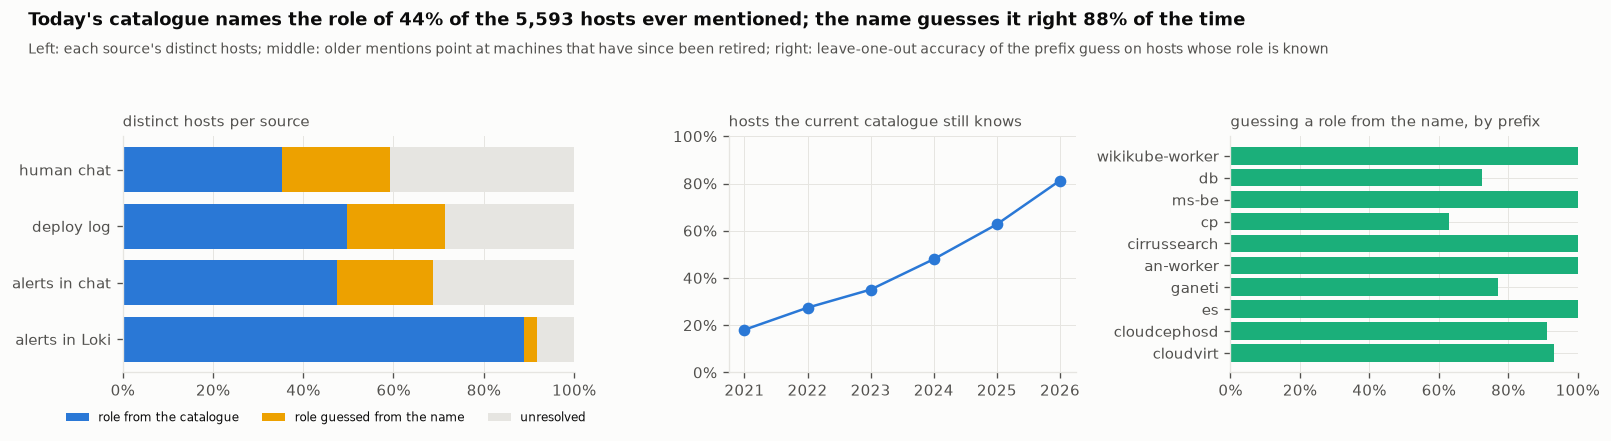

In [91]:
# ---- the identity chain, drawn: where names fall off, and why ----
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
srcs = list(JOIN.index)
ax.barh(srcs, JOIN.exact, color=C1, label="role from the catalogue")
ax.barh(srcs, JOIN.guessed, left=JOIN.exact, color=C4, label="role guessed from the name")
ax.barh(srcs, 1 - JOIN.exact - JOIN.guessed, left=JOIN.exact + JOIN.guessed, color=GRID, label="unresolved")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncols=3, frameon=False)
ax.set_title("distinct hosts per source", fontsize=9, color=INK2, loc="left")
ax = axes[1]
ax.plot(YEARLY.index, YEARLY.values, "o-", color=C1)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_xticks(list(YEARLY.index))
ax.set_title("hosts the current catalogue still knows", fontsize=9, color=INK2, loc="left")
ax = axes[2]
top = [p for p, _ in per_prefix.most_common(10)]
ax.barh(top, [per_prefix_ok[p] / per_prefix[p] for p in top], color=C3)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_title("guessing a role from the name, by prefix", fontsize=9, color=INK2, loc="left")
finish(fig, "identity_chain",
       f"Today's catalogue names the role of {len(KNOWN) / max(len(distinct), 1):.0%} of the {len(distinct):,} hosts ever "
       f"mentioned; the name guesses it right {PREFIX_ACC:.0%} of the time",
       "Left: each source's distinct hosts; middle: older mentions point at machines that have since been retired; right: "
       "leave-one-out accuracy of the prefix guess on hosts whose role is known")

In [92]:
# ---- services in free text: exact names, normalised names, and near misses ----
from rapidfuzz import fuzz, process

SERVICE_NAMES = set(CATALOG["services"]) | set(CATALOG["k8s_services"])
for name, s in CATALOG["services"].items():
    SERVICE_NAMES |= set(s.get("aliases") or [])
CATALOGUED = set(CATALOG["services"]) | set(CATALOG["k8s_services"])           # the names an application node can have
OWNERS = defaultdict(set)
for name, s in CATALOG["services"].items():
    for a in s.get("aliases") or []:
        OWNERS[a].add(name)
CANONICAL = {a: next(iter(o)) for a, o in OWNERS.items() if len(o) == 1 and a not in CATALOGUED}


def norm_service(text: str) -> str:
    return re.sub(r"[\s_]+", "-", text.strip().lower()).strip("-.,;:()")


NORMALISED = {norm_service(n): n for n in SERVICE_NAMES}


def resolve_service(token: str, cutoff: float = 90, fuzzy: bool = True) -> tuple[str | None, str]:
    """(service, how): exact, normalised, fuzzy, or nothing. Short tokens never fuzzy-match: too many collisions."""
    if token in SERVICE_NAMES:
        return token, "exact"
    n = norm_service(token)
    if n in NORMALISED:
        return NORMALISED[n], "normalised"
    if fuzzy and cutoff < 100 and len(n) >= 6:
        hit = process.extractOne(n, list(NORMALISED), scorer=fuzz.ratio, score_cutoff=cutoff)
        if hit:
            return NORMALISED[hit[0]], "fuzzy"
    return None, "none"


rng = random.Random(SEED)
real = sorted(n for n in SERVICE_NAMES if len(n) >= 6)
variants = []
for n in rng.sample(real, min(150, len(real))):
    variants += [(n.upper(), n), (n.replace("-", " "), n), (n.replace("-", "_"), n), (n + "s", n),
                 (n[:-1] if len(n) > 6 else n, n)]
words = Counter(w for t in IRC.loc[~IRC.bot, "text"].sample(min(50000, int((~IRC.bot).sum())), random_state=SEED)
                for w in re.findall(r"[a-z][a-z-]{5,}", t.lower()))
plain_words = [w for w, _ in words.most_common(3000) if norm_service(w) not in NORMALISED][:2000]
FUZZY_CURVE = []
for cutoff in (80, 85, 88, 90, 92, 95, 100):
    found = sum(resolve_service(v, cutoff)[0] == want for v, want in variants) / len(variants)
    false = sum(resolve_service(w, cutoff)[0] is not None for w in plain_words) / len(plain_words)
    FUZZY_CURVE.append((cutoff, found, false))
print(f"  {len(SERVICE_NAMES)} service names (catalogue, kubernetes, aliases); of {len(OWNERS)} aliases, "
      f"{len(CANONICAL)} name exactly one other service ({', '.join(f'{a} -> {n}' for a, n in sorted(CANONICAL.items()))}), "
      f"the rest are services themselves or shared")
print(f"  {'cutoff':>7}{'variants recovered':>20}{'ordinary words matched':>24}")
for c, f, x in FUZZY_CURVE:
    print(f"  {c:>7}{f:>20.1%}{x:>24.2%}")
print(f"  at 90: '{variants[1][0]}' -> {resolve_service(variants[1][0])}, '{plain_words[0]}' -> "
      f"{resolve_service(plain_words[0])}")
wrong = [(w, resolve_service(w)[0]) for w in plain_words if resolve_service(w)[0] is not None]
print(f"  ordinary chat words that still match a service at 90: {wrong[:6]}")

  192 service names (catalogue, kubernetes, aliases); of 5 aliases, 2 name exactly one other service (labweb -> labweb-ssl, restbase -> restbase-https), the rest are services themselves or shared
   cutoff  variants recovered  ordinary words matched
       80              100.0%                   1.80%
       85              100.0%                   0.50%
       88              100.0%                   0.25%
       90              100.0%                   0.20%
       92              100.0%                   0.20%
       95               90.8%                   0.00%
      100               60.9%                   0.00%
  at 90: 'thanos web' -> ('thanos-web', 'normalised'), 'wikimedia' -> (None, 'none')
  ordinary chat words that still match a service at 90: [('mwscript', 'mw-script'), ('release', 'releases'), ('on-call', 'oncall'), ('uploads', 'upload')]


[fig] artifacts\figures_full\fuzzy_tradeoff.png


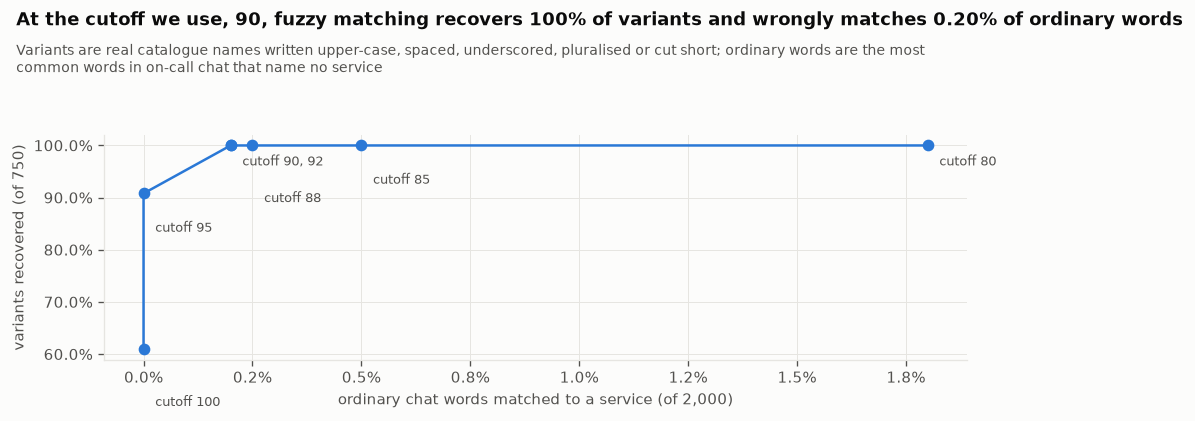

In [93]:
# ---- the fuzzy-match trade-off, drawn: misspellings recovered against ordinary words matched by mistake ----
fc = pd.DataFrame(FUZZY_CURVE, columns=["cutoff", "found", "false"])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(fc["false"], fc["found"], "o-", color=C1)
for k, ((x, y), g) in enumerate(fc.groupby(["false", "found"], sort=False)):     # cutoffs that land on one point share a label
    ax.annotate("cutoff " + ", ".join(map(str, g.cutoff)), (x, y), textcoords="offset points",
                xytext=(7, -12 - 11 * (k % 3)), fontsize=7.5, color=INK2)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=1))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_xlabel(f"ordinary chat words matched to a service (of {len(plain_words):,})")
ax.set_ylabel(f"variants recovered (of {len(variants):,})")
at90 = fc[fc.cutoff == 90].iloc[0]
finish(fig, "fuzzy_tradeoff", f"At the cutoff we use, 90, fuzzy matching recovers {at90['found']:.0%} of variants and "
       f"wrongly matches {at90['false']:.2%} of ordinary words",
       "Variants are real catalogue names written upper-case, spaced, underscored, pluralised or cut short; ordinary "
       "words are the most common words in on-call chat that name no service")

**Five years of logs mention 5,593 distinct machines in 969,388 places, and today's catalogue
can name the role of 2,475 of them.** The chain is strong where the data is recent and weak where
it is old: 89% of the hosts in the last six months of Loki alerts resolve to an exact puppet role,
against 35% of the hosts people mention in chat, and the share a current catalogue still knows
falls from 81% for this year's mentions to 18% for 2021's. That decay is the identity problem the
post never has to face, because its catalogue and its incidents live in the same present. A host's
name is a good witness for the missing years: guessing its role from the prefix of its name is
right 88% of the time for hosts whose role we can check, which is why the guesses get their own
named graph rather than mixing with what the catalogue states. For service names in free text,
a fuzzy cutoff of 90 recovers every misspelt variant we tried while matching 4 of 2,000 ordinary
chat words, and three of those four are near-misses an engineer would accept.

## 12 · The ontology as code: fourteen namespaces and one URI scheme

**Theory.** The ontology is the agreement the post keeps returning to: which kinds of things
exist, what each may be connected to, and what every fact must carry. We write it as a Turtle
file under version control, because the post's advice is to treat it as code, and we keep it
separate from the data, because concepts change when people agree and instances change on
every run. Three decisions are ours, and each is marked. There is no generic Service class:
the post refused one, and we use an abstract Component with four concrete kinds underneath,
because real incidents break hosts, clusters and pods as often as applications. Every signal,
from a deploy to an alert, is a subclass of one Signal class, so the correlation engine can
ask a single question across all of them. And we add two namespaces the post does not have,
for code changes and for the users' traffic, because Figure 7 has a COMMIT signal with no home
and Figure 1 has a users layer with no namespace.

In [94]:
# ---- fourteen namespaces: twelve from figure 4, two of our own ----
NS = {"ops": "ops#", "slack": "slack#", "alert": "alert#", "metric": "metric#", "log": "log#", "tl": "timeline#",
      "incident": "incident#", "rca": "rca#", "exp": "experiment#", "e2e": "e2e#", "corr": "correlation#",
      "harvest": "harvest#", "code": "code#", "users": "users#"}
NS = {p: Namespace(BASE + s) for p, s in NS.items()}
PROV = Namespace("http://www.w3.org/ns/prov#")
OURS = {"code", "users"}
for p in NS:
    globals()[p.upper()] = NS[p]                      # OPS, SLACK, ALERT, ... for use in code below
print(f"  {'prefix':<10}{'IRI':<44}{'origin':<10}")
print("  " + "-" * 64)
for p, n in NS.items():
    print(f"  {p:<10}{str(n):<44}{'ours' if p in OURS else 'Figure 4'}")

  prefix    IRI                                         origin    
  ----------------------------------------------------------------
  ops       https://kg.example.org/ops#                 Figure 4
  slack     https://kg.example.org/slack#               Figure 4
  alert     https://kg.example.org/alert#               Figure 4
  metric    https://kg.example.org/metric#              Figure 4
  log       https://kg.example.org/log#                 Figure 4
  tl        https://kg.example.org/timeline#            Figure 4
  incident  https://kg.example.org/incident#            Figure 4
  rca       https://kg.example.org/rca#                 Figure 4
  exp       https://kg.example.org/experiment#          Figure 4
  e2e       https://kg.example.org/e2e#                 Figure 4
  corr      https://kg.example.org/correlation#         Figure 4
  harvest   https://kg.example.org/harvest#             Figure 4
  code      https://kg.example.org/code#                ours
  users     https://kg.ex

  ontology\ops.ttl: 117 lines of Turtle, 272 triples, 43 classes, 77 properties
  namespace  classes  properties
  ------------------------------
  ops             11          11
  slack            3          10
  alert            2           4
  metric           2           2
  log              3           2
  tl               5           4
  incident         2           9
  rca              2           6
  exp              2           0
  e2e              3           2
  corr             4          17
  harvest          2           6
  code             1           2
  users            1           2


[fig] artifacts\figures_full\ontology_by_namespace.png


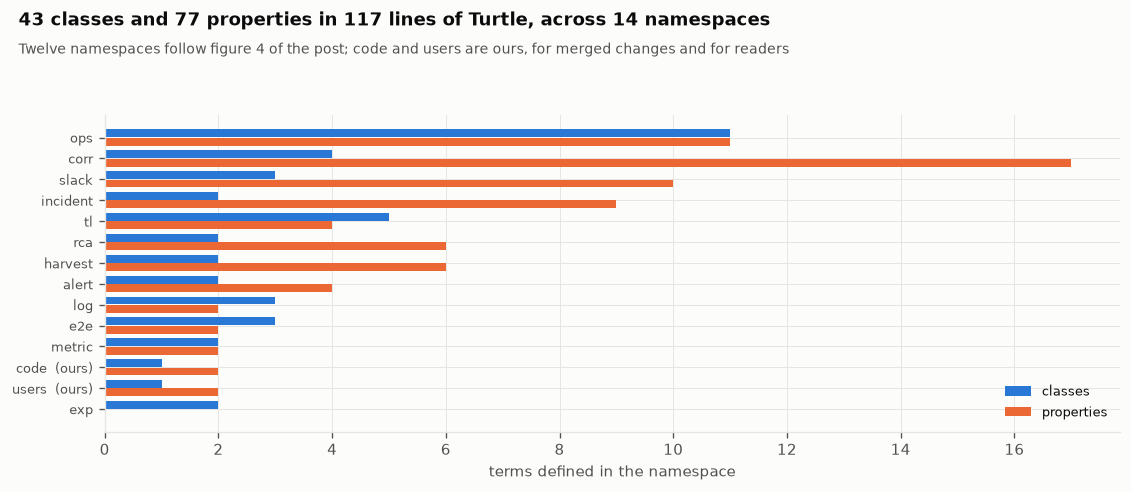

In [95]:
# ---- the ontology itself, written as a file that lives under version control ----
TBOX_TTL = """
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix owl:  <http://www.w3.org/2002/07/owl#> .
@prefix xsd:  <http://www.w3.org/2001/XMLSchema#> .
@prefix prov: <http://www.w3.org/ns/prov#> .
@prefix ops: <https://kg.example.org/ops#> .        @prefix slack: <https://kg.example.org/slack#> .
@prefix alert: <https://kg.example.org/alert#> .    @prefix metric: <https://kg.example.org/metric#> .
@prefix log: <https://kg.example.org/log#> .        @prefix tl: <https://kg.example.org/timeline#> .
@prefix incident: <https://kg.example.org/incident#> . @prefix rca: <https://kg.example.org/rca#> .
@prefix exp: <https://kg.example.org/experiment#> . @prefix e2e: <https://kg.example.org/e2e#> .
@prefix corr: <https://kg.example.org/correlation#> . @prefix harvest: <https://kg.example.org/harvest#> .
@prefix code: <https://kg.example.org/code#> .      @prefix users: <https://kg.example.org/users#> .

# --- OPS: who and what exists -----------------------------------------------------------
ops:Organisation a owl:Class ; rdfs:comment "a tenant: one company or one benchmark system" .
ops:Component a owl:Class ; rdfs:comment "anything that can break; abstract, never asserted directly" .
ops:Application rdfs:subClassOf ops:Component ; rdfs:comment "deployable software, gated by the catalogue" .
ops:Cluster rdfs:subClassOf ops:Component ; rdfs:comment "a pool of hosts or pods serving one purpose" .
ops:Host rdfs:subClassOf ops:Component ; rdfs:comment "a machine or virtual machine" .
ops:Pod rdfs:subClassOf ops:Component ; rdfs:comment "one running container instance" .
ops:Team a owl:Class .  ops:Person a owl:Class .  ops:Datacenter a owl:Class .  ops:Role a owl:Class .
ops:tenant a owl:ObjectProperty ; rdfs:range ops:Organisation .
ops:catalogId a owl:DatatypeProperty ; rdfs:range xsd:string .
ops:name a owl:DatatypeProperty ; rdfs:range xsd:string .
ops:alias a owl:DatatypeProperty ; rdfs:range xsd:string .
ops:ownedBy a owl:ObjectProperty ; rdfs:range ops:Team .
ops:memberOf a owl:ObjectProperty ; rdfs:domain ops:Host ; rdfs:range ops:Cluster .
ops:hasRole a owl:ObjectProperty ; rdfs:domain ops:Host ; rdfs:range ops:Role .
ops:locatedIn a owl:ObjectProperty ; rdfs:range ops:Datacenter .
ops:runsOn a owl:ObjectProperty ; rdfs:domain ops:Application ; rdfs:range ops:Component .
ops:dependsOn a owl:ObjectProperty ; rdfs:domain ops:Component ; rdfs:range ops:Component .
ops:Incident rdfs:subClassOf corr:Signal ; rdfs:comment "an episode of user-visible harm, known to every tool" .
ops:affects a owl:ObjectProperty ; rdfs:domain ops:Incident ; rdfs:range ops:Component .

# --- CORRELATION: one superclass for every signal, and the chains built from them -----------
corr:Signal a owl:Class ; rdfs:comment "something that happened to a component at a time" .
corr:on a owl:ObjectProperty ; rdfs:domain corr:Signal ; rdfs:range ops:Component .
corr:at a owl:DatatypeProperty ; rdfs:domain corr:Signal ; rdfs:range xsd:dateTime .
corr:detectedAt a owl:DatatypeProperty ; rdfs:domain corr:Signal ; rdfs:range xsd:dateTime .
corr:severity a owl:DatatypeProperty ; rdfs:domain corr:Signal ; rdfs:range xsd:decimal .
corr:signalType a owl:DatatypeProperty ; rdfs:domain corr:Signal ; rdfs:range xsd:string .
corr:inHour a owl:ObjectProperty ; rdfs:domain corr:Signal ; rdfs:range corr:Hour .
corr:Hour a owl:Class ; rdfs:comment "an hour bucket, so time windows become index lookups" .
corr:Chain a owl:Class .  corr:Hop a owl:Class .
corr:rootCause a owl:ObjectProperty ; rdfs:domain corr:Chain ; rdfs:range corr:Signal .
corr:leadsTo a owl:ObjectProperty ; rdfs:domain corr:Chain ; rdfs:range corr:Signal .
corr:rootCauseType a owl:DatatypeProperty ; rdfs:domain corr:Chain ; rdfs:range xsd:string .
corr:affectsComponent a owl:ObjectProperty ; rdfs:domain corr:Chain ; rdfs:range ops:Component .
corr:confidence a owl:DatatypeProperty ; rdfs:range xsd:decimal .
corr:hasHop a owl:ObjectProperty ; rdfs:domain corr:Chain ; rdfs:range corr:Hop .
corr:hopFrom a owl:ObjectProperty ; rdfs:domain corr:Hop ; rdfs:range corr:Signal .
corr:hopTo a owl:ObjectProperty ; rdfs:domain corr:Hop ; rdfs:range corr:Signal .
corr:gapMinutes a owl:DatatypeProperty ; rdfs:domain corr:Hop ; rdfs:range xsd:decimal .
corr:hopScore a owl:DatatypeProperty ; rdfs:domain corr:Hop ; rdfs:range xsd:decimal .
corr:evidence a owl:ObjectProperty .

# --- the signal kinds, each owned by its own namespace -------------------------------------
alert:Firing rdfs:subClassOf corr:Signal .           alert:Rule a owl:Class .
alert:ofRule a owl:ObjectProperty ; rdfs:domain alert:Firing ; rdfs:range alert:Rule .
alert:resolvedAt a owl:DatatypeProperty ; rdfs:domain alert:Firing ; rdfs:range xsd:dateTime .
alert:source a owl:DatatypeProperty ; rdfs:domain alert:Firing ; rdfs:range xsd:string .
alert:pages a owl:DatatypeProperty ; rdfs:domain alert:Firing ; rdfs:range xsd:boolean .
metric:Anomaly rdfs:subClassOf corr:Signal .         metric:Series a owl:Class .
metric:kpi a owl:DatatypeProperty ; rdfs:domain metric:Anomaly ; rdfs:range xsd:string .
metric:magnitude a owl:DatatypeProperty ; rdfs:domain metric:Anomaly ; rdfs:range xsd:decimal .
log:ErrorBurst rdfs:subClassOf corr:Signal .         log:NewPattern rdfs:subClassOf corr:Signal .
log:Pattern a owl:Class .
log:template a owl:DatatypeProperty ; rdfs:domain log:Pattern ; rdfs:range xsd:string .
log:ofPattern a owl:ObjectProperty ; rdfs:range log:Pattern .
e2e:SlowSpans rdfs:subClassOf corr:Signal .          e2e:FailedSpans rdfs:subClassOf corr:Signal .
e2e:Bottleneck rdfs:subClassOf corr:Signal .
e2e:operation a owl:DatatypeProperty ; rdfs:range xsd:string .
e2e:p99ms a owl:DatatypeProperty ; rdfs:range xsd:decimal .
tl:Change rdfs:subClassOf corr:Signal .
tl:Deployment rdfs:subClassOf tl:Change .            tl:ConfigChange rdfs:subClassOf tl:Change .
tl:CapacityChange rdfs:subClassOf tl:Change ; rdfs:comment "depool and repool: Netflix's AUTOSCALE, done by hand" .
tl:Maintenance rdfs:subClassOf tl:Change ; rdfs:comment "ours: reboots and reimages, which do cause alerts" .
tl:actor a owl:ObjectProperty ; rdfs:range ops:Person .
tl:tool a owl:DatatypeProperty ; rdfs:domain tl:Change ; rdfs:range xsd:string .
tl:message a owl:DatatypeProperty ; rdfs:domain tl:Change ; rdfs:range xsd:string .
tl:includes a owl:ObjectProperty ; rdfs:domain tl:Change ; rdfs:range code:Change .
code:Change rdfs:subClassOf corr:Signal ; rdfs:comment "ours: a merged code change (Figure 7's COMMIT)" .
code:number a owl:DatatypeProperty ; rdfs:domain code:Change ; rdfs:range xsd:integer .
code:project a owl:DatatypeProperty ; rdfs:domain code:Change ; rdfs:range xsd:string .
exp:Experiment rdfs:subClassOf corr:Signal .         exp:Allocation a owl:Class .
users:TrafficShift rdfs:subClassOf corr:Signal ; rdfs:comment "ours: a surge or dip in human pageviews" .
users:project a owl:DatatypeProperty ; rdfs:domain users:TrafficShift ; rdfs:range xsd:string .
users:ratio a owl:DatatypeProperty ; rdfs:domain users:TrafficShift ; rdfs:range xsd:decimal .

# --- SLACK, INCIDENT, RCA: the human side ---------------------------------------------------
slack:Channel a owl:Class .  slack:Message a owl:Class .  slack:Conversation a owl:Class .
slack:inChannel a owl:ObjectProperty ; rdfs:domain slack:Message ; rdfs:range slack:Channel .
slack:partOf a owl:ObjectProperty ; rdfs:domain slack:Message ; rdfs:range slack:Conversation .
slack:author a owl:ObjectProperty ; rdfs:domain slack:Message ; rdfs:range ops:Person .
slack:postedAt a owl:DatatypeProperty ; rdfs:domain slack:Message ; rdfs:range xsd:dateTime .
slack:text a owl:DatatypeProperty ; rdfs:domain slack:Message ; rdfs:range xsd:string .
slack:mentions a owl:ObjectProperty ; rdfs:domain slack:Message ; rdfs:range ops:Component .
slack:category a owl:DatatypeProperty ; rdfs:domain slack:Message ; rdfs:range xsd:string .
slack:sentiment a owl:DatatypeProperty ; rdfs:domain slack:Message ; rdfs:range xsd:string .
slack:isIncidentRelated a owl:DatatypeProperty ; rdfs:domain slack:Message ; rdfs:range xsd:boolean .
slack:about a owl:ObjectProperty ; rdfs:domain slack:Conversation ; rdfs:range ops:Incident .
incident:Report a owl:Class .  incident:TimelineEntry a owl:Class .
incident:reportedIn a owl:ObjectProperty ; rdfs:domain ops:Incident ; rdfs:range incident:Report .
incident:startedAt a owl:DatatypeProperty ; rdfs:domain ops:Incident ; rdfs:range xsd:dateTime .
incident:resolvedAt a owl:DatatypeProperty ; rdfs:domain ops:Incident ; rdfs:range xsd:dateTime .
incident:impact a owl:DatatypeProperty ; rdfs:domain ops:Incident ; rdfs:range xsd:string .
incident:coordinator a owl:ObjectProperty ; rdfs:range ops:Person .
incident:hasEntry a owl:ObjectProperty ; rdfs:range incident:TimelineEntry .
incident:entryAt a owl:DatatypeProperty ; rdfs:domain incident:TimelineEntry ; rdfs:range xsd:dateTime .
incident:entryText a owl:DatatypeProperty ; rdfs:domain incident:TimelineEntry ; rdfs:range xsd:string .
incident:detectedBy a owl:DatatypeProperty ; rdfs:domain ops:Incident ; rdfs:range xsd:string .
rca:Hypothesis a owl:Class .  rca:Remediation a owl:Class .
rca:forIncident a owl:ObjectProperty ; rdfs:domain rca:Hypothesis ; rdfs:range ops:Incident .
rca:cause a owl:ObjectProperty ; rdfs:domain rca:Hypothesis .
rca:causeKind a owl:DatatypeProperty ; rdfs:domain rca:Hypothesis ; rdfs:range xsd:string .
rca:rank a owl:DatatypeProperty ; rdfs:domain rca:Hypothesis ; rdfs:range xsd:integer .
rca:status a owl:DatatypeProperty ; rdfs:domain rca:Hypothesis ; rdfs:range xsd:string .
rca:proposedBy a owl:DatatypeProperty ; rdfs:domain rca:Hypothesis ; rdfs:range xsd:string .

# --- HARVEST: where every fact came from (W3C PROV-O) --------------------------------------
harvest:Run rdfs:subClassOf prov:Activity .
harvest:Coverage a owl:Class ; rdfs:comment "what one run fetched, or failed to fetch, for one source and window" .
harvest:enricher a owl:DatatypeProperty ; rdfs:domain harvest:Run ; rdfs:range xsd:string .
harvest:source a owl:DatatypeProperty ; rdfs:domain harvest:Coverage ; rdfs:range xsd:string .
harvest:windowStart a owl:DatatypeProperty ; rdfs:domain harvest:Coverage ; rdfs:range xsd:dateTime .
harvest:windowEnd a owl:DatatypeProperty ; rdfs:domain harvest:Coverage ; rdfs:range xsd:dateTime .
harvest:status a owl:DatatypeProperty ; rdfs:domain harvest:Coverage ; rdfs:range xsd:string .
harvest:triplesAdded a owl:DatatypeProperty ; rdfs:domain harvest:Run ; rdfs:range xsd:integer .
"""
TBOX_FILE = ONTO_DIR / "ops.ttl"
TBOX_FILE.write_text(TBOX_TTL.strip() + "\n", encoding="utf-8")
TBOX = rdflib.Graph().parse(TBOX_FILE, format="turtle")
for p, n in NS.items():
    TBOX.bind(p, n, override=True, replace=True)
classes = set(TBOX.subjects(RDF.type, rdflib.OWL.Class)) | set(TBOX.subjects(RDFS.subClassOf, None))
props = set(TBOX.subjects(RDF.type, rdflib.OWL.ObjectProperty)) | set(TBOX.subjects(RDF.type, rdflib.OWL.DatatypeProperty))
TBOX_LINES = len([l for l in TBOX_FILE.read_text(encoding="utf-8").splitlines() if l.strip() and not l.startswith("#")])
print(f"  {TBOX_FILE.relative_to(ROOT)}: {TBOX_LINES} lines of Turtle, {len(TBOX)} triples, "
      f"{len(classes)} classes, {len(props)} properties")
print(f"  {'namespace':<10}{'classes':>8}{'properties':>12}")
print("  " + "-" * 30)
per_ns = {}
for p, n in NS.items():
    nc = sum(str(c).startswith(str(n)) for c in classes)
    np_ = sum(str(x).startswith(str(n)) for x in props)
    per_ns[p] = (nc, np_)
    print(f"  {p:<10}{nc:>8}{np_:>12}")

fig, ax = plt.subplots(figsize=(9.5, 4.2))
order_ns = sorted(per_ns, key=lambda p: -sum(per_ns[p]))
y_ = np.arange(len(order_ns))
ax.barh(y_ - 0.2, [per_ns[p][0] for p in order_ns], height=0.38, color=C1, label="classes")
ax.barh(y_ + 0.2, [per_ns[p][1] for p in order_ns], height=0.38, color=C2, label="properties")
ax.set_yticks(y_, [f"{p}{'  (ours)' if p in OURS else ''}" for p in order_ns], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("terms defined in the namespace")
ax.legend(fontsize=8, loc="lower right")
finish(fig, "ontology_by_namespace", f"{len(classes)} classes and {len(props)} properties in {TBOX_LINES} lines of Turtle, "
       f"across {sum(1 for v in per_ns.values() if sum(v))} namespaces",
       "Twelve namespaces follow figure 4 of the post; code and users are ours, for merged changes and for readers")

In [96]:
# ---- every signal kind, and a check that the hierarchy really says what we think it says ----
SIGNAL_CLASS = {"LOG_ERROR": LOG.ErrorBurst, "ERROR_PATTERN": LOG.NewPattern, "METRIC_ANOMALY": METRIC.Anomaly,
                "TRACE_SLOW": E2E.SlowSpans, "TRACE_FAILED": E2E.FailedSpans, "E2E_BOTTLENECK": E2E.Bottleneck,
                "ALERT": ALERT.Firing, "INCIDENT": OPS.Incident, "DEPLOYMENT": TL.Deployment,
                "CONFIG_CHANGE": TL.ConfigChange, "AUTOSCALE": TL.CapacityChange, "COMMIT": CODE.Change,
                "EXPERIMENT": EXP.Experiment, "MAINTENANCE": TL.Maintenance, "TRAFFIC_SHIFT": USERS.TrafficShift}
reasoned = rdflib.Graph() + TBOX
owlrl.DeductiveClosure(owlrl.RDFS_Semantics).expand(reasoned)
ok = 0
print(f"  {'signal type':<16}{'class':<26}{'is a corr:Signal':>18}")
print("  " + "-" * 60)
for st, cls in SIGNAL_CLASS.items():
    is_signal = (cls, RDFS.subClassOf, CORR.Signal) in reasoned
    ok += is_signal
    print(f"  {st:<16}{cls.n3(TBOX.namespace_manager):<26}{'yes' if is_signal else 'NO':>18}"
          f"{'   (ours)' if st in ('MAINTENANCE', 'TRAFFIC_SHIFT') else ''}")
print(f"\n  [test] {ok}/{len(SIGNAL_CLASS)} signal classes reach corr:Signal through rdfs:subClassOf -> "
      f"{'PASS' if ok == len(SIGNAL_CLASS) else 'FAIL'}")
assert ok == len(SIGNAL_CLASS)

  signal type     class                       is a corr:Signal
  ------------------------------------------------------------
  LOG_ERROR       log:ErrorBurst                           yes
  ERROR_PATTERN   log:NewPattern                           yes
  METRIC_ANOMALY  metric:Anomaly                           yes
  TRACE_SLOW      e2e:SlowSpans                            yes
  TRACE_FAILED    e2e:FailedSpans                          yes
  E2E_BOTTLENECK  e2e:Bottleneck                           yes
  ALERT           alert:Firing                             yes
  INCIDENT        ops:Incident                             yes
  DEPLOYMENT      tl:Deployment                            yes
  CONFIG_CHANGE   tl:ConfigChange                          yes
  AUTOSCALE       tl:CapacityChange                        yes
  COMMIT          code:Change                              yes
  EXPERIMENT      exp:Experiment                           yes
  MAINTENANCE     tl:Maintenance                       

[fig] artifacts\figures_full\class_tree.png


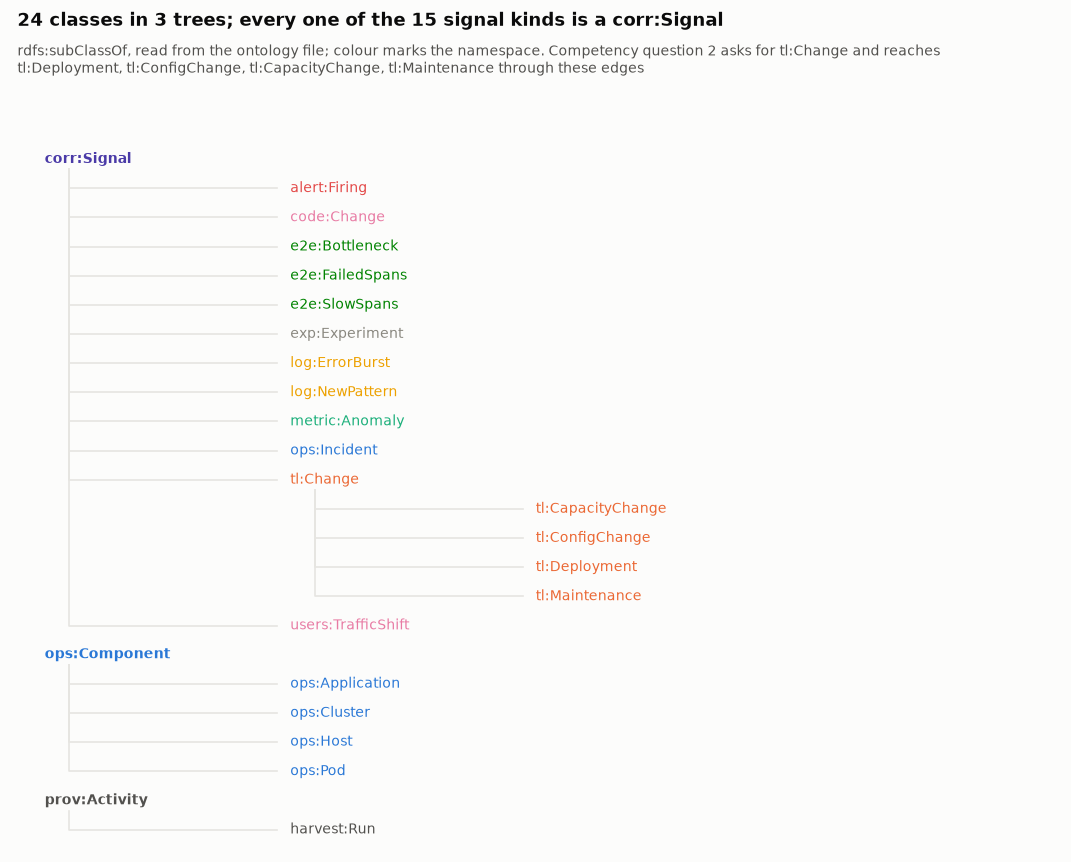

In [97]:
# ---- the class tree, drawn: what is a kind of what ----
nm = TBOX.namespace_manager
parent_of = {c: p for c, p in TBOX.subject_objects(RDFS.subClassOf) if isinstance(c, URIRef) and isinstance(p, URIRef)}
kids = defaultdict(list)
for c, p in parent_of.items():
    kids[p].append(c)
roots = sorted({p for p in parent_of.values() if p not in parent_of}, key=lambda n: n.n3(nm))
order, depth = [], {}


def walk(node: URIRef, d: int) -> None:
    depth[node] = d
    order.append(node)
    for k in sorted(kids.get(node, []), key=lambda n: n.n3(nm)):
        walk(k, d + 1)


for r in roots:
    walk(r, 0)
prefix_colour = {"ops": C1, "corr": C7, "tl": C2, "alert": C8, "metric": C3, "log": C4, "e2e": C6, "code": C5,
                 "users": C5, "exp": MUTED, "incident": C8, "slack": C1}
fig, ax = plt.subplots(figsize=(9.0, 0.27 * len(order) + 0.8))
ax.axis("off")
ax.set_xlim(-0.2, 6.2)
ax.set_ylim(-len(order) + 0.3, 0.8)
for i, n in enumerate(order):
    x, y = depth[n] * 1.5, -i
    label = n.n3(nm)
    colour = prefix_colour.get(label.split(":")[0], INK2)
    ax.text(x, y, label, fontsize=8.2, va="center", color=colour, weight="bold" if depth[n] == 0 else "normal")
    if n in parent_of:
        px, py = depth[parent_of[n]] * 1.5, -order.index(parent_of[n])
        ax.plot([px + 0.15, px + 0.15, x - 0.08], [py - 0.35, y, y], color=GRID, lw=1, zorder=0)
changes = [n.n3(nm) for n in kids.get(TL.Change, [])]
finish(fig, "class_tree", f"{len(order)} classes in {len(roots)} trees; every one of the {len(SIGNAL_CLASS)} signal "
       "kinds is a corr:Signal",
       f"rdfs:subClassOf, read from the ontology file; colour marks the namespace. Competency question 2 asks for "
       f"tl:Change and reaches {', '.join(changes)} through these edges")

In [98]:
# ---- one function mints every URI, so the same thing always gets the same name ----
def slug(text: str) -> str:
    s = re.sub(r"[^a-z0-9._~-]+", "-", str(text).strip().lower()).strip("-")
    return s or hashlib.sha256(str(text).encode()).hexdigest()[:12]


def mint(tenant: str, kind: str, key: str) -> URIRef:
    """https://kg.example.org/id/<tenant>/<kind>/<key>: readable, deterministic, collision-checked by kind."""
    return URIRef(f"{BASE}id/{slug(tenant)}/{slug(kind)}/{slug(key)}")


def hour_node(ts) -> URIRef:
    return URIRef(f"{BASE}id/hour/{pd.Timestamp(ts).tz_convert('UTC').strftime('%Y-%m-%dT%H')}")


cases = [("wikimedia", "host", "db1127.eqiad.wmnet"), ("wikimedia", "host", "DB1127.eqiad.wmnet "),
         ("openrca-market", "pod", "shippingservice-1"), ("wikimedia", "application", "Wikidata Query Service")]
for c in cases:
    print(f"  mint{c!s:<58} -> {mint(*c)}")
print(f"  hour_node(2023-02-23 17:31 UTC)                             -> {hour_node('2023-02-23 17:31Z')}")
same = mint(*cases[0]) == mint(*cases[1])
print(f"\n  [test] the same host written two ways gets one URI -> {'PASS' if same else 'FAIL'}")
assert same

  mint('wikimedia', 'host', 'db1127.eqiad.wmnet')                -> https://kg.example.org/id/wikimedia/host/db1127.eqiad.wmnet
  mint('wikimedia', 'host', 'DB1127.eqiad.wmnet ')               -> https://kg.example.org/id/wikimedia/host/db1127.eqiad.wmnet
  mint('openrca-market', 'pod', 'shippingservice-1')             -> https://kg.example.org/id/openrca-market/pod/shippingservice-1
  mint('wikimedia', 'application', 'Wikidata Query Service')     -> https://kg.example.org/id/wikimedia/application/wikidata-query-service
  hour_node(2023-02-23 17:31 UTC)                             -> https://kg.example.org/id/hour/2023-02-23T17

  [test] the same host written two ways gets one URI -> PASS


[fig] artifacts\figures_full\namespace_map.png


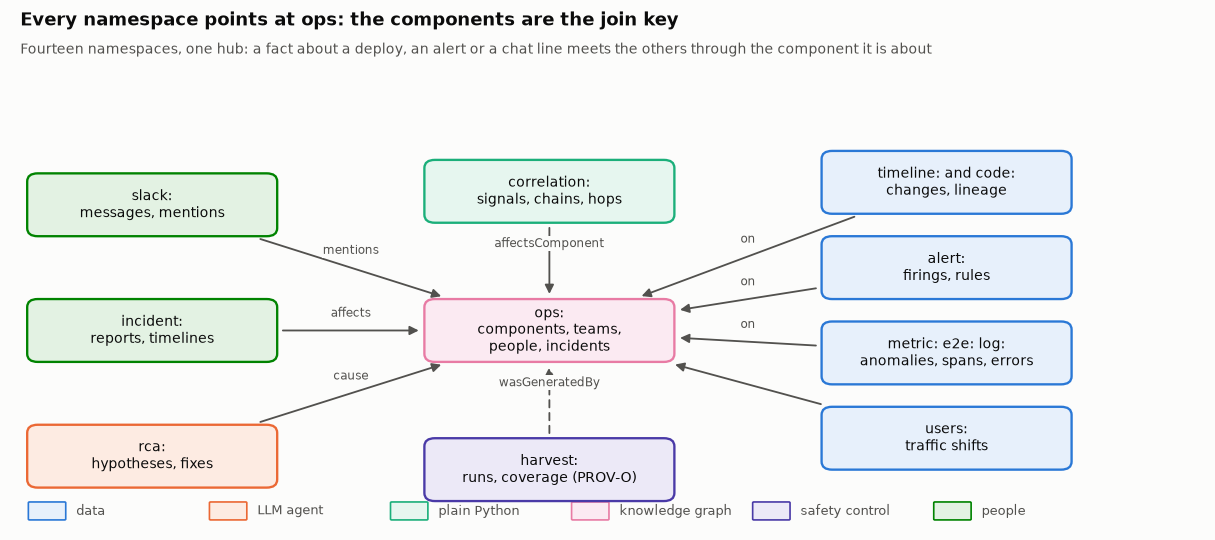

In [99]:
# ---- the namespaces and the facts that cross between them ----
NS_NODES = {
    "slack": (1.2, 3.6, "slack:\nmessages, mentions", "human"), "incident": (1.2, 2.2, "incident:\nreports, timelines", "human"),
    "rca": (1.2, 0.8, "rca:\nhypotheses, fixes", "llm"),
    "ops": (4.6, 2.2, "ops:\ncomponents, teams,\npeople, incidents", "graph"),
    "tl": (8.0, 3.85, "timeline: and code:\nchanges, lineage", "data"), "alert": (8.0, 2.9, "alert:\nfirings, rules", "data"),
    "metric": (8.0, 1.95, "metric: e2e: log:\nanomalies, spans, errors", "data"),
    "users": (8.0, 1.0, "users:\ntraffic shifts", "data"),
    "corr": (4.6, 3.75, "correlation:\nsignals, chains, hops", "code"), "harvest": (4.6, 0.65, "harvest:\nruns, coverage (PROV-O)", "guard"),
}
NS_EDGES = [("slack", "ops", "mentions"), ("incident", "ops", "affects"), ("rca", "ops", "cause"),
            ("tl", "ops", "on"), ("alert", "ops", "on"), ("metric", "ops", "on"), ("users", "ops", None),
            ("corr", "ops", "affectsComponent"), ("harvest", "ops", "wasGeneratedBy", "dashed")]
draw_flow(NS_NODES, NS_EDGES, "namespace_map", "Every namespace points at ops: the components are the join key",
          "Fourteen namespaces, one hub: a fact about a deploy, an alert or a chat line meets the others through the component it is about",
          size=(10.2, 4.6), box=(2.1, 0.66))

In [100]:
# ---- the competency questions: what the ontology must be able to answer, written as tests ----
CQ = {
    "CQ1 incidents on a team's components in one datacenter": """
SELECT DISTINCT ?incident WHERE {
  ?incident a ops:Incident ; ops:affects ?c .
  ?c ops:ownedBy ?team ; ops:locatedIn ?dc .
  ?team ops:name "Data Persistence" . ?dc ops:name "eqiad" . }""",
    "CQ2 what changed on a component in the hour before an incident": """
SELECT DISTINCT ?change ?tool WHERE {
  ?incident a ops:Incident ; corr:at ?t0 ; ops:affects ?c .
  ?change a/rdfs:subClassOf* tl:Change ; corr:on ?c ; corr:at ?t ; tl:tool ?tool .
  FILTER(?t <= ?t0 && ?t > ?t0 - "PT1H"^^xsd:dayTimeDuration) }""",
    "CQ3 alerts anywhere on a component's dependency path": """
SELECT DISTINCT ?firing WHERE {
  ?incident a ops:Incident ; ops:affects ?c .
  ?c ops:dependsOn+ ?dep .
  ?firing a alert:Firing ; corr:on ?dep . }""",
    "CQ4 components with repeated deploy-caused incidents (figure 9, counted per incident)": """
SELECT ?c (COUNT(DISTINCT ?incident) AS ?n) WHERE {
  ?chain corr:rootCauseType "DEPLOYMENT" ; corr:affectsComponent ?c ; corr:leadsTo ?incident ; corr:confidence ?v .
  FILTER(?v > 0.7) } GROUP BY ?c HAVING (COUNT(DISTINCT ?incident) > 1)""",
}
PREFIXES = "\n".join(f"PREFIX {p}: <{n}>" for p, n in NS.items()) + \
    "\nPREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>\nPREFIX xsd: <http://www.w3.org/2001/XMLSchema#>\n"
(ONTO_DIR / "competency.rq").write_text("\n\n".join(f"# {k}\n{v.strip()}" for k, v in CQ.items()) + "\n", encoding="utf-8")
FIXTURE = f"""
@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix tl: <{TL}> . @prefix alert: <{ALERT}> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> . @prefix : <{BASE}id/test/> .
:dp a ops:Team ; ops:name "Data Persistence" .  :eqiad a ops:Datacenter ; ops:name "eqiad" .
:s7 a ops:Cluster ; ops:ownedBy :dp ; ops:locatedIn :eqiad ; ops:dependsOn :db1127 .
:db1127 a ops:Host ; ops:dependsOn :disk1 .  :disk1 a ops:Host .
:inc1 a ops:Incident ; ops:affects :s7 ; corr:at "2023-02-23T17:17:00Z"^^xsd:dateTime .
:inc2 a ops:Incident ; ops:affects :s7 ; corr:at "2023-03-01T09:00:00Z"^^xsd:dateTime .
:chg1 a tl:ConfigChange ; corr:on :s7 ; corr:at "2023-02-23T16:50:00Z"^^xsd:dateTime ; tl:tool "dbctl" .
:chg2 a tl:Deployment ; corr:on :s7 ; corr:at "2023-02-23T12:00:00Z"^^xsd:dateTime ; tl:tool "scap" .
:fir1 a alert:Firing ; corr:on :disk1 .
:ch1 corr:rootCauseType "DEPLOYMENT" ; corr:affectsComponent :s7 ; corr:leadsTo :inc1 ; corr:confidence 0.87 .
:ch2 corr:rootCauseType "DEPLOYMENT" ; corr:affectsComponent :s7 ; corr:leadsTo :inc1 ; corr:confidence 0.81 .
:ch3 corr:rootCauseType "DEPLOYMENT" ; corr:affectsComponent :s7 ; corr:leadsTo :inc2 ; corr:confidence 0.90 .
"""
CQ_EXPECT = {"CQ1": {"inc1", "inc2"}, "CQ2": {"chg1"}, "CQ3": {"fir1"}, "CQ4": {"s7"}}


def run_competency(tbox: rdflib.Graph, fixture: str, queries: dict) -> dict:
    """Load the ontology and a fixture into Oxigraph, run every question, return {CQ id: set of first-column names}."""
    st = ox.Store()
    st.load((tbox.serialize(format="nt") + rdflib.Graph().parse(data=fixture, format="turtle").serialize(format="nt")).encode(),
            format=ox.RdfFormat.N_TRIPLES)
    return {k.split()[0]: {s[0].value.rsplit("/", 1)[-1] for s in st.query(PREFIXES + q)} for k, q in queries.items()}


got = run_competency(TBOX, FIXTURE, CQ)
for k, q in CQ.items():
    cid = k.split()[0]
    print(f"  {'PASS' if got[cid] == CQ_EXPECT[cid] else 'FAIL'}  {k:<72} {sorted(got[cid])}")
print("\n  CQ2 needs rdfs:subClassOf* because the deploy and the config change are subclasses of tl:Change;")
print("  CQ3 needs ops:dependsOn+ to walk from the cluster through a host to the disk that alerted;")
print("  CQ4 counts incidents, not chains: s7 has three deploy chains but two incidents.")
assert all(got[k] == v for k, v in CQ_EXPECT.items())

  PASS  CQ1 incidents on a team's components in one datacenter                   ['inc1', 'inc2']
  PASS  CQ2 what changed on a component in the hour before an incident           ['chg1']
  PASS  CQ3 alerts anywhere on a component's dependency path                     ['fir1']
  PASS  CQ4 components with repeated deploy-caused incidents (figure 9, counted per incident) ['s7']

  CQ2 needs rdfs:subClassOf* because the deploy and the config change are subclasses of tl:Change;
  CQ3 needs ops:dependsOn+ to walk from the cluster through a host to the disk that alerted;
  CQ4 counts incidents, not chains: s7 has three deploy chains but two incidents.


In [101]:
# ---- ontology as code: rename one property and watch a test fail before anything ships ----
renamed = TBOX_TTL.replace("ops:ownedBy", "ops:owner")
written_by_new_enrichers = FIXTURE.replace("ops:ownedBy", "ops:owner")
got_broken = run_competency(rdflib.Graph().parse(data=renamed, format="turtle"), written_by_new_enrichers, CQ)
print("  a pull request renames ops:ownedBy to ops:owner in the ontology and in the enrichers that write it;")
print("  the agents' saved questions still ask for ops:ownedBy.")
print(f"  CQ1 now returns {sorted(got_broken['CQ1'])} instead of {sorted(CQ_EXPECT['CQ1'])} -> "
      f"{'FAIL, caught before merge' if got_broken['CQ1'] != CQ_EXPECT['CQ1'] else 'PASS'}")
print(f"  every other question: {'unchanged' if all(got_broken[k] == CQ_EXPECT[k] for k in CQ_EXPECT if k != 'CQ1') else 'changed'}")
print("\n  The graph loaded, the shapes would pass, and nothing raised an error: the agents would simply")
print("  have stopped finding owners. Only the question that uses the property noticed.")

  a pull request renames ops:ownedBy to ops:owner in the ontology and in the enrichers that write it;
  the agents' saved questions still ask for ops:ownedBy.
  CQ1 now returns [] instead of ['inc1', 'inc2'] -> FAIL, caught before merge
  every other question: unchanged

  The graph loaded, the shapes would pass, and nothing raised an error: the agents would simply
  have stopped finding owners. Only the question that uses the property noticed.


In [102]:
# ---- the same concepts, projected into the schemas other systems speak ----
XSD_SQL = {XSD.string: "TEXT", XSD.dateTime: "TIMESTAMPTZ", XSD.decimal: "DOUBLE", XSD.integer: "BIGINT",
           XSD.boolean: "BOOLEAN"}


def project_sql(cls: URIRef) -> str:
    """A table for one class: its datatype properties become columns, typed from rdfs:range."""
    supers = {cls} | {o for o in reasoned.objects(cls, RDFS.subClassOf)}
    cols = []
    for prop in sorted(props):
        doms = set(TBOX.objects(prop, RDFS.domain))
        rng = next(iter(TBOX.objects(prop, RDFS.range)), None)
        if rng in XSD_SQL and (doms & supers):
            cols.append(f"  {prop.n3(TBOX.namespace_manager).replace(':', '_')} {XSD_SQL[rng]}")
    name = cls.n3(TBOX.namespace_manager).replace(":", "_").lower()
    return f"CREATE TABLE {name} (\n  iri TEXT PRIMARY KEY,\n" + ",\n".join(cols) + "\n);"


for cls in (ALERT.Firing, INCIDENT.TimelineEntry):
    print(textwrap.indent(project_sql(cls), "  "))
    print()
print("  The tables are generated, not written: change a range in ops.ttl and the column type follows.")

  CREATE TABLE alert_firing (
    iri TEXT PRIMARY KEY,
    alert_pages BOOLEAN,
    alert_resolvedAt TIMESTAMPTZ,
    alert_source TEXT,
    corr_at TIMESTAMPTZ,
    corr_detectedAt TIMESTAMPTZ,
    corr_severity DOUBLE,
    corr_signalType TEXT
  );

  CREATE TABLE incident_timelineentry (
    iri TEXT PRIMARY KEY,
    incident_entryAt TIMESTAMPTZ,
    incident_entryText TEXT
  );

  The tables are generated, not written: change a range in ops.ttl and the column type follows.


**The ontology is 117 lines of Turtle, and four questions written before any data was loaded
all pass on it.** Fifteen signal kinds hang off one class, so the correlation engine can ask
for "every signal on this component in this hour" without knowing what a deploy or an alert
is. The rename test is the part we would keep in any real system: the ontology happily
accepted a broken change, and only a competency question noticed. The next section adds the
other half of the contract, the shapes that refuse bad facts.

## 13 · Types that hold: SHACL shapes and the bugs they catch

**Theory.** OWL describes the world openly: a missing fact is unknown, and a fact that breaks
a rule is quietly explained by adding more facts. That is the right attitude for a reasoner and
the wrong one for a gatekeeper, as picture 3 showed when a typo became an application. SHACL
takes the other view. A shape is a closed-world check: this kind of node must carry these
properties, with these types, inside these ranges, pointing at these classes, and anything else
is a violation with a name and a reason. Every enricher's output passes through the shapes
before it reaches the store. This is where the post's principle "constrain stochastic tools with
a type system" becomes mechanical: a language model can write any prose it likes, but a triple
that says a message's category is "kind of an incident" never gets in.

In [103]:
# ---- the shapes: one file, every class that receives data, every rule written down ----
SHAPES_TTL = f"""
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix slack: <{SLACK}> . @prefix tl: <{TL}> .
@prefix alert: <{ALERT}> . @prefix harvest: <{HARVEST}> . @prefix incident: <{INCIDENT}> .
@prefix : <{BASE}shapes#> .

:CatalogueGate a sh:NodeShape ; sh:targetClass ops:Application ;
    sh:property [ sh:path ops:catalogId ; sh:minCount 1 ; sh:maxCount 1 ; sh:datatype xsd:string ;
                  sh:message "an application must come from the catalogue" ] .
:HostShape a sh:NodeShape ; sh:targetClass ops:Host ;
    sh:property [ sh:path ops:name ; sh:minCount 1 ; sh:datatype xsd:string ] ;
    sh:property [ sh:path ops:memberOf ; sh:maxCount 1 ; sh:class ops:Cluster ] .
:SignalShape a sh:NodeShape ; sh:targetClass corr:Signal ;
    sh:property [ sh:path corr:at ; sh:minCount 1 ; sh:maxCount 1 ; sh:datatype xsd:dateTime ;
                  sh:message "every signal needs exactly one time" ] ;
    sh:property [ sh:path corr:on ; sh:class ops:Component ; sh:message "a signal sits on a known component" ] ;
    sh:property [ sh:path corr:severity ; sh:datatype xsd:decimal ; sh:minInclusive 0 ; sh:maxInclusive 1 ;
                  sh:message "severity is a number between 0 and 1" ] .
:IncidentShape a sh:NodeShape ; sh:targetClass ops:Incident ;
    sh:property [ sh:path ops:affects ; sh:class ops:Component ] .
:ChainShape a sh:NodeShape ; sh:targetClass corr:Chain ;
    sh:property [ sh:path corr:confidence ; sh:minCount 1 ; sh:datatype xsd:decimal ; sh:minInclusive 0 ;
                  sh:maxInclusive 1 ; sh:message "a confidence is a number between 0 and 1, never text" ] ;
    sh:property [ sh:path corr:rootCause ; sh:minCount 1 ; sh:class corr:Signal ] ;
    sh:property [ sh:path corr:leadsTo ; sh:minCount 1 ; sh:class corr:Signal ] .
:MessageShape a sh:NodeShape ; sh:targetClass slack:Message ;
    sh:property [ sh:path slack:postedAt ; sh:minCount 1 ; sh:datatype xsd:dateTime ] ;
    sh:property [ sh:path slack:category ; sh:maxCount 1 ; sh:in ( "incident" "question" "discussion" "decision" ) ;
                  sh:message "a category is one of the four the ladder knows" ] ;
    sh:property [ sh:path slack:sentiment ; sh:maxCount 1 ; sh:in ( "positive" "neutral" "negative" "urgent" ) ] ;
    sh:property [ sh:path slack:mentions ; sh:class ops:Component ] .
:CoverageShape a sh:NodeShape ; sh:targetClass harvest:Coverage ;
    sh:property [ sh:path harvest:status ; sh:minCount 1 ; sh:in ( "ok" "partial" "missing" ) ;
                  sh:message "a harvest is ok, partial or missing, nothing else" ] ;
    sh:property [ sh:path harvest:windowStart ; sh:minCount 1 ; sh:datatype xsd:dateTime ] .
"""
SHAPES_FILE = ONTO_DIR / "shapes.ttl"
SHAPES_FILE.write_text(SHAPES_TTL.strip() + "\n", encoding="utf-8")
SHAPES = rdflib.Graph().parse(SHAPES_FILE, format="turtle")
SH = Namespace("http://www.w3.org/ns/shacl#")
n_shapes = len(set(SHAPES.subjects(RDF.type, SH.NodeShape)))
n_rules = len(set(SHAPES.objects(None, SH.property)))
print(f"  {SHAPES_FILE.relative_to(ROOT)}: {n_shapes} node shapes, {n_rules} property rules, {len(SHAPES)} triples")


def check(data: rdflib.Graph, shapes: rdflib.Graph = SHAPES, inference: str = "none") -> tuple[bool, list[tuple]]:
    """Validate against the shapes; return (conforms, [(node, property, rule, message)]).

    The ontology is mixed into the data so that subclasses count (a tl:ConfigChange is a corr:Signal), but no
    inference runs: the next cells show what RDFS inference would do to the class checks.
    """
    conforms, report, _ = shacl_validate(data, shacl_graph=shapes, ont_graph=TBOX, inference=inference)
    rows = []
    for r in report.subjects(RDF.type, SH.ValidationResult):
        focus = str(report.value(r, SH.focusNode)).rsplit("/", 1)[-1]
        path = report.value(r, SH.resultPath)
        rule = str(report.value(r, SH.sourceConstraintComponent)).rsplit("#", 1)[-1].removesuffix("ConstraintComponent")
        msg = str(report.value(r, SH.resultMessage) or "")
        rows.append((focus, path.n3(TBOX.namespace_manager) if path is not None else "", rule, msg))
    return conforms, sorted(rows)

  ontology\shapes.ttl: 7 node shapes, 16 property rules, 109 triples


In [104]:
# ---- every rule broken once, on purpose, to prove each one fires ----
BAD = f"""
@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix slack: <{SLACK}> . @prefix tl: <{TL}> .
@prefix alert: <{ALERT}> . @prefix harvest: <{HARVEST}> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix : <{BASE}id/test/> .
:good-app a ops:Application ; ops:catalogId "svc-wdqs" .
:scraped-name a ops:Application .                                            # never validated against the catalogue
:db1127 a ops:Host ; ops:name "db1127" .
:dep1 a tl:Deployment ; corr:on :good-app .                                  # a signal without a time
:fir1 a alert:Firing ; corr:at "2023-02-23T17:17:00Z"^^xsd:dateTime ; corr:on :good-app ; corr:severity 1.7 .
:chain1 a corr:Chain ; corr:confidence "0.92" ; corr:rootCause :fir1 ; corr:leadsTo :fir1 .   # figure 5's text value
:msg1 a slack:Message ; slack:postedAt "2023-02-23T17:25:00Z"^^xsd:dateTime ; slack:category "kind of an incident" .
:cov1 a harvest:Coverage ; harvest:status "timeout" ; harvest:windowStart "2023-02-23T00:00:00Z"^^xsd:dateTime .
"""
conforms, rows = check(rdflib.Graph().parse(data=BAD, format="turtle"))
print(f"  conforms: {conforms}; {len(rows)} violations")
print(f"  {'node':<14}{'property':<18}{'rule':<14}why")
print("  " + "-" * 96)
for focus, path, rule, msg in rows:
    print(f"  {focus:<14}{path:<18}{rule:<14}{msg[:62]}")
caught = {r[0] for r in rows}
expected_bad = {"scraped-name", "dep1", "fir1", "chain1", "msg1", "cov1"}
print(f"\n  [test] every planted violation caught, and the two good nodes left alone -> "
      f"{'PASS' if caught == expected_bad else 'FAIL ' + str(caught ^ expected_bad)}")
print("  The text '0.92' breaks three rules at once: it is not a decimal, so it is neither at least 0 nor at most 1.")

  conforms: False; 8 violations
  node          property          rule          why
  ------------------------------------------------------------------------------------------------
  chain1        corr:confidence   Datatype      a confidence is a number between 0 and 1, never text
  chain1        corr:confidence   MaxInclusive  a confidence is a number between 0 and 1, never text
  chain1        corr:confidence   MinInclusive  a confidence is a number between 0 and 1, never text
  cov1          harvest:status    In            a harvest is ok, partial or missing, nothing else
  dep1          corr:at           MinCount      every signal needs exactly one time
  fir1          corr:severity     MaxInclusive  severity is a number between 0 and 1
  msg1          slack:category    In            a category is one of the four the ladder knows
  scraped-name  ops:catalogId     MinCount      an application must come from the catalogue

  [test] every planted violation caught, and the two good n

In [105]:
# ---- a bug we found in our own validator: inference makes the class checks pass on anything ----
TYPO = f"""@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix tl: <{TL}> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix : <{BASE}id/test/> .
:dep2 a tl:Deployment ; corr:at "2023-02-23T16:50:00Z"^^xsd:dateTime ; corr:on :db1127x ."""
typo = rdflib.Graph().parse(data=TYPO, format="turtle")
range_axiom = next(TBOX.objects(CORR.on, RDFS.range))
for mode in ("rdfs", "none"):
    ok, found = check(typo, inference=mode)
    print(f"  inference={mode:<6} a deploy on the misspelt host db1127x -> conforms={ok!s:<6}"
          f"{found[0][2] + ': ' + found[0][3] if found else 'no violation'}")
print(f"\n  The ontology says corr:on has range {range_axiom.n3(TBOX.namespace_manager)}. Under RDFS inference that")
print("  axiom does not check anything; it concludes that db1127x must be a Component, and the class check then")
print("  passes on its own conclusion. Our first version of check() validated with inference on, and every")
print("  sh:class rule on a property with a declared range was silently a no-op. Validation now runs with the")
print("  ontology in view (so subclasses count) and without inference (so nothing is invented).")

  inference=rdfs   a deploy on the misspelt host db1127x -> conforms=True  no violation
  inference=none   a deploy on the misspelt host db1127x -> conforms=False Class: a signal sits on a known component

  The ontology says corr:on has range ops:Component. Under RDFS inference that
  axiom does not check anything; it concludes that db1127x must be a Component, and the class check then
  passes on its own conclusion. Our first version of check() validated with inference on, and every
  sh:class rule on a property with a declared range was silently a no-op. Validation now runs with the
  ontology in view (so subclasses count) and without inference (so nothing is invented).


In [106]:
# ---- the 0.92 bug, run: one untyped number, two engines, two different wrong answers ----
FILTER_Q = f"PREFIX corr: <{CORR}> SELECT ?c WHERE {{ ?c corr:confidence ?v . FILTER(?v > 0.7) }}"
VERSIONS = {"stored as text": {"ch-high": '"0.92"', "ch-low": '"0.5"', "ch-word": '"high"'},
            "stored as xsd:decimal": {"ch-high": '"0.92"^^xsd:decimal', "ch-low": '"0.5"^^xsd:decimal'}}
results_092 = {}
for label, values in VERSIONS.items():
    ttl = (f"@prefix corr: <{CORR}> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> . @prefix : <{BASE}id/test/> .\n"
           + "\n".join(f":{k} corr:confidence {v} ." for k, v in values.items()))
    gr = rdflib.Graph().parse(data=ttl, format="turtle")
    st = ox.Store()
    st.load(gr.serialize(format="nt").encode(), format=ox.RdfFormat.N_TRIPLES)
    a = sorted(str(r.c).rsplit("/", 1)[-1] for r in gr.query(FILTER_Q))
    b = sorted(s["c"].value.rsplit("/", 1)[-1] for s in st.query(FILTER_Q))
    results_092[label] = (a, b)
    print(f"  {label:<24}rdflib {str(a):<34}Oxigraph {b}")
odd = Literal("0.1") > Literal("0.7", datatype=XSD.decimal)
print("\n  Text compared with a number is a type error in standard SPARQL, so Oxigraph drops every row. rdflib")
print("  does not raise it; it sorts every string above every number, so '0.5' and even 'high' pass a filter")
print(f"  for 'greater than 0.7' (in rdflib {rdflib.__version__}, '0.1' > 0.7 comes out {odd}). Same query, same data,")
print("  two engines, two wrong answers, no error in either. Typed, both engines agree on the one right row,")
print("  and the word 'high' never reaches the store because the ChainShape refuses it at write time.")
print(f"\n  [test] typed values give the same answer in both engines -> "
      f"{'PASS' if results_092['stored as xsd:decimal'] == (['ch-high'], ['ch-high']) else 'FAIL'}")

  stored as text          rdflib ['ch-high', 'ch-low', 'ch-word']  Oxigraph []
  stored as xsd:decimal   rdflib ['ch-high']                       Oxigraph ['ch-high']

  Text compared with a number is a type error in standard SPARQL, so Oxigraph drops every row. rdflib
  does not raise it; it sorts every string above every number, so '0.5' and even 'high' pass a filter
  for 'greater than 0.7' (in rdflib 7.6.0, '0.1' > 0.7 comes out True). Same query, same data,
  two engines, two wrong answers, no error in either. Typed, both engines agree on the one right row,
  and the word 'high' never reaches the store because the ChainShape refuses it at write time.

  [test] typed values give the same answer in both engines -> PASS


In [107]:
# ---- the trap in validating only what is new: a class check needs the types already stored ----
STORED = f"""@prefix ops: <{OPS}> . @prefix : <{BASE}id/test/> .
:s7 a ops:Cluster ; ops:name "s7" ."""
DELTA = f"""@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix tl: <{TL}> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix : <{BASE}id/test/> .
:chg9 a tl:ConfigChange ; corr:at "2023-02-23T16:50:00Z"^^xsd:dateTime ; corr:on :s7 ."""
delta_only = rdflib.Graph().parse(data=DELTA, format="turtle")
stored = rdflib.Graph().parse(data=STORED, format="turtle")
skeleton = rdflib.Graph()
for t in stored.triples((None, RDF.type, None)):        # only the type triples of what is already in the store
    skeleton.add(t)
ok_alone, rows_alone = check(delta_only)
ok_skel, rows_skel = check(delta_only + skeleton)
print(f"  the new change on its own:            conforms={ok_alone!s:<6}"
      f"{rows_alone[0][2] + ': ' + rows_alone[0][3] if rows_alone else ''}")
print(f"  the new change plus a type skeleton:  conforms={ok_skel!s:<6}"
      f"{rows_skel[0][2] + ': ' + rows_skel[0][3] if rows_skel else ''}")
print(f"  skeleton size: {len(skeleton)} type triple(s) out of {len(stored)} stored")
print("\n  Validated alone, :s7 has no type, so 'a signal sits on a known component' fails on a perfectly good")
print("  fact. Adding the rdf:type triples of what is already stored (one or two per entity, a small slice of the")
print("  graph) gives the class checks what they need without revalidating millions of facts on every run.")
print("  The trap has a second half, which real data found in section 15.")
print(f"\n  [test] delta alone is rejected and delta plus skeleton is accepted -> "
      f"{'PASS' if (not ok_alone and ok_skel) else 'FAIL'}")

  the new change on its own:            conforms=False Class: a signal sits on a known component
  the new change plus a type skeleton:  conforms=True  
  skeleton size: 1 type triple(s) out of 2 stored

  Validated alone, :s7 has no type, so 'a signal sits on a known component' fails on a perfectly good
  fact. Adding the rdf:type triples of what is already stored (one or two per entity, a small slice of the
  graph) gives the class checks what they need without revalidating millions of facts on every run.
  The trap has a second half, which real data found in section 15.

  [test] delta alone is rejected and delta plus skeleton is accepted -> PASS


In [108]:
# ---- validation at scale: the same shapes, compiled to SPARQL and run inside the store ----
from rdflib.collection import Collection


def compile_shapes(shapes: rdflib.Graph = SHAPES) -> list[tuple[str, str, str, str]]:
    """Every property rule becomes one SPARQL query that returns the nodes breaking it. Targets and class checks follow
    rdfs:subClassOf*, exactly as pySHACL does with the ontology mixed in and no inference."""
    nm, out = TBOX.namespace_manager, []
    for shape in shapes.subjects(RDF.type, SH.NodeShape):
        target = shapes.value(shape, SH.targetClass)
        focus = f"?s a/rdfs:subClassOf* <{target}> ."
        for p in shapes.objects(shape, SH.property):
            path = shapes.value(p, SH.path)
            pn = path.n3(nm)
            msg = str(shapes.value(p, SH.message) or "")
            if (n := shapes.value(p, SH.minCount)) is not None:
                out.append((pn, "MinCount", msg, f"SELECT ?s WHERE {{ {focus} OPTIONAL {{ ?s <{path}> ?v }} }} "
                                                    f"GROUP BY ?s HAVING (COUNT(?v) < {int(n)})"))
            if (n := shapes.value(p, SH.maxCount)) is not None:
                out.append((pn, "MaxCount", msg, f"SELECT ?s WHERE {{ {focus} ?s <{path}> ?v }} "
                                                    f"GROUP BY ?s HAVING (COUNT(?v) > {int(n)})"))
            if (dt := shapes.value(p, SH.datatype)) is not None:
                out.append((pn, "Datatype", msg, f"SELECT DISTINCT ?s WHERE {{ {focus} ?s <{path}> ?v . "
                                                    f"FILTER(!isLiteral(?v) || datatype(?v) != <{dt}>) }}"))
            if (head := shapes.value(p, SH["in"])) is not None:
                allowed = ", ".join(Literal(str(v)).n3() for v in Collection(shapes, head))
                out.append((pn, "In", msg, f"SELECT DISTINCT ?s WHERE {{ {focus} ?s <{path}> ?v . "
                                              f"FILTER(?v NOT IN ({allowed})) }}"))
            if (k := shapes.value(p, SH["class"])) is not None:
                out.append((pn, "Class", msg, f"SELECT DISTINCT ?s WHERE {{ {focus} ?s <{path}> ?v . "
                                                 f"FILTER NOT EXISTS {{ ?v a/rdfs:subClassOf* <{k}> }} }}"))
            for kw, op, name in ((SH.minInclusive, "<", "MinInclusive"), (SH.maxInclusive, ">", "MaxInclusive")):
                if (b := shapes.value(p, kw)) is not None:
                    out.append((pn, name, msg, f"SELECT DISTINCT ?s WHERE {{ {focus} ?s <{path}> ?v . "
                                                  f"FILTER(!isNumeric(?v) || ?v {op} {b}) }}"))
    return out


COMPILED = compile_shapes()


DELTA_GRAPH = ox.NamedNode("urn:x-check:delta")
FOCUS_ON_DELTA = "WHERE { { SELECT DISTINCT ?s WHERE { GRAPH <urn:x-check:delta> { ?s ?dp ?do } } } "


def check_fast(data: rdflib.Graph, context: rdflib.Graph | None = None) -> tuple[bool, list[tuple]]:
    """check(), at store speed: load the data and the ontology into Oxigraph and run every compiled rule. Given a
    context (what the store already holds about the nodes the data mentions), only the data's own subjects are judged,
    the way a database checks a transaction: a stored node the data merely points at was judged when it was written."""
    st = ox.Store()
    tbox = TBOX.serialize(format="nt")
    if context is None:
        st.load((data.serialize(format="nt") + tbox).encode(), format=ox.RdfFormat.N_TRIPLES)
    else:
        st.load(data.serialize(format="nt").encode(), format=ox.RdfFormat.N_TRIPLES, to_graph=DELTA_GRAPH)
        st.load((context.serialize(format="nt") + tbox).encode(), format=ox.RdfFormat.N_TRIPLES,
                to_graph=ox.NamedNode("urn:x-check:context"))
    rows = []
    for pn, rule, msg, q in COMPILED:
        if context is not None:
            q = q.replace("WHERE { ", FOCUS_ON_DELTA, 1)
        for r in st.query("PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> " + q,
                          use_default_graph_as_union=context is not None):
            rows.append((r["s"].value.rsplit("/", 1)[-1], pn, rule, msg))
    return not rows, sorted(set(rows))


bad_graph = rdflib.Graph().parse(data=BAD, format="turtle")
ref = {(f, p, r) for f, p, r, _ in check(bad_graph)[1]}
fast = {(f, p, r) for f, p, r, _ in check_fast(bad_graph)[1]}
print(f"  {len(COMPILED)} compiled rules from {n_rules} property rules")
print(f"  [test] on the deliberately broken graph, pySHACL and the compiled rules report the same violations -> "
      f"{'PASS' if ref == fast else 'FAIL ' + str(ref ^ fast)}")
recent = CHANGES[CHANGES.ts >= CHANGES.ts.max() - pd.Timedelta(days=7)]
big = rdflib.Graph()                           # a week of real changes, typed as signals, with the hosts they name
for i, (ts, msg) in enumerate(zip(recent.ts, recent.message)):
    node = URIRef(f"{BASE}id/test/change-{i}")
    big.add((node, RDF.type, TL.Change))
    big.add((node, CORR.at, Literal(ts.to_pydatetime())))
    if hs := hosts_in(msg):
        h = URIRef(f"{BASE}id/test/host-{hs[0]}")
        big.add((h, RDF.type, OPS.Host))
        big.add((h, OPS.name, Literal(hs[0])))
        big.add((node, CORR.on, h))
for name, fn in (("pySHACL", check), ("compiled to SPARQL", check_fast)):
    t0 = time.perf_counter()
    ok_, rows_ = fn(big)
    print(f"  {name:<20}{len(big):>9,} triples  {time.perf_counter() - t0:7.2f}s  conforms={ok_}")
from rdflib.collection import Collection

JSON_TYPE = {XSD.string: "string", XSD.decimal: "number", XSD.integer: "integer", XSD.dateTime: "string"}


def shape_to_json_schema(shape: URIRef, only: tuple[str, ...], ids: dict[str, list[str]] | None = None) -> dict:
    """sh:in becomes an enum, sh:datatype a JSON type, sh:class a choice from a closed list of ids, maxCount 1 a
    single value (otherwise a list), minCount 1 a required field."""
    props, required = {}, []
    for p in SHAPES.objects(shape, SH.property):
        name = SHAPES.value(p, SH.path).n3(TBOX.namespace_manager).split(":", 1)[1]
        if name not in only:
            continue
        spec: dict = {}
        if (head := SHAPES.value(p, SH["in"])) is not None:
            spec["enum"] = [str(v) for v in Collection(SHAPES, head)]
        elif (dt := SHAPES.value(p, SH.datatype)) is not None:
            spec["type"] = JSON_TYPE[dt]
        elif SHAPES.value(p, SH["class"]) is not None:
            spec = {"enum": sorted((ids or {}).get(name, []))} if ids and name in ids else {"type": "string"}
        if SHAPES.value(p, SH.maxCount) != Literal(1):
            spec = {"type": "array", "items": spec}
        if SHAPES.value(p, SH.minCount) is not None:
            required.append(name)
        props[name] = spec
    return {"type": "object", "properties": {k: props[k] for k in only if k in props},
            "required": sorted(set(required) | set(only)), "additionalProperties": False}


L4_SCHEMA = shape_to_json_schema(URIRef(f"{BASE}shapes#MessageShape"), only=("category", "sentiment", "mentions"),
                                 ids={"mentions": ["svc-wdqs", "cluster-s7", "host-db1127"]})
for name, spec in L4_SCHEMA["properties"].items():
    print(f"  {name:<11}{json.dumps(spec)}")
print(f"  {'required':<11}{L4_SCHEMA['required']}   additionalProperties {L4_SCHEMA['additionalProperties']}")
shape_enum = [str(v) for v in Collection(SHAPES, SHAPES.value(
    next(p for p in SHAPES.objects(URIRef(f"{BASE}shapes#MessageShape"), SH.property)
         if SHAPES.value(p, SH.path) == SLACK.category), SH["in"]))]
print(f"\n  [test] the model's category enum is the shape's list, read from one file -> "
      f"{'PASS' if L4_SCHEMA['properties']['category']['enum'] == shape_enum else 'FAIL'}")
print("  The shape and the schema cannot drift apart: change the list in shapes.ttl and both the validator and")
print("  the prompt contract change with it. Section 20 hands this schema to Qwen and Claude as is; the closed")
print("  list of ids there comes from the catalogue, so a model can only mention a component that exists.")

  34 compiled rules from 16 property rules
  [test] on the deliberately broken graph, pySHACL and the compiled rules report the same violations -> PASS


  pySHACL                 3,606 triples     0.48s  conforms=True
  compiled to SPARQL      3,606 triples     0.08s  conforms=True
  category   {"enum": ["incident", "question", "discussion", "decision"]}
  sentiment  {"enum": ["positive", "neutral", "negative", "urgent"]}
  mentions   {"type": "array", "items": {"enum": ["cluster-s7", "host-db1127", "svc-wdqs"]}}
  required   ['category', 'mentions', 'sentiment']   additionalProperties False

  [test] the model's category enum is the shape's list, read from one file -> PASS
  The shape and the schema cannot drift apart: change the list in shapes.ttl and both the validator and
  the prompt contract change with it. Section 20 hands this schema to Qwen and Claude as is; the closed
  list of ids there comes from the catalogue, so a model can only mention a component that exists.


  [cache] shacl_scaling.json, on mains power
   days of changes    triples   pySHACL  compiled  faster
                 1        248     0.02s     0.01s      2x
                 4      2,541     0.11s     0.02s      5x
                16     12,002     0.52s     0.14s      4x
                64     30,295     1.68s     0.36s      5x
               256    118,988     5.11s     1.25s      4x
              1024    444,603    20.95s     5.67s      4x

  [test] wherever both ran, they agree on whether the delta conforms -> PASS
  pySHACL takes 2 to 5 times as long as the compiled rules at every size it ran


[fig] artifacts\figures_full\shacl_scaling.png


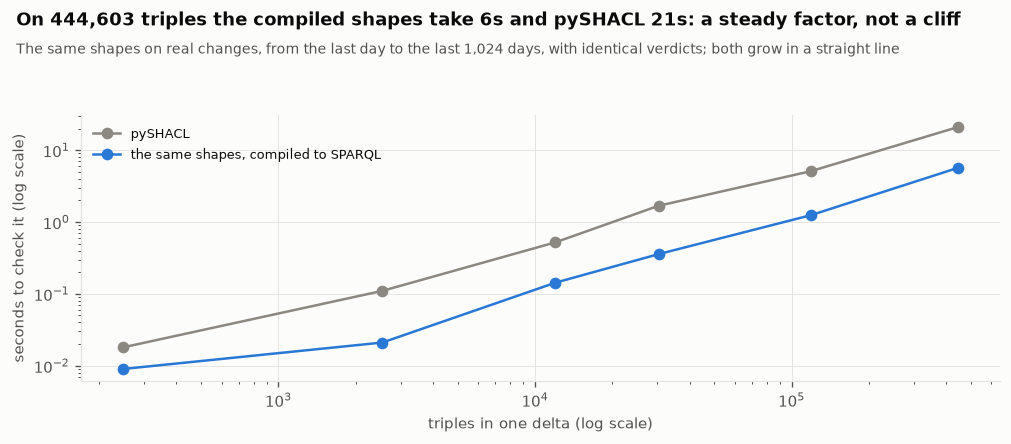

In [109]:
# ---- validation cost as a delta grows: why the shapes are compiled before anything is checked at scale ----
def change_delta(days: int) -> rdflib.Graph:
    """The last `days` of real changes as typed signals, with the hosts they name, built as the week above was."""
    sub = CHANGES[CHANGES.ts >= CHANGES.ts.max() - pd.Timedelta(days=days)]
    g = rdflib.Graph()
    for i, (ts, msg) in enumerate(zip(sub.ts, sub.message)):
        node = URIRef(f"{BASE}id/test/change-{i}")
        g.add((node, RDF.type, TL.Change))
        g.add((node, CORR.at, Literal(ts.to_pydatetime())))
        if hs := hosts_in(msg):
            h = URIRef(f"{BASE}id/test/host-{hs[0]}")
            g.add((h, RDF.type, OPS.Host))
            g.add((h, OPS.name, Literal(hs[0])))
            g.add((node, CORR.on, h))
    return g


shacl_file = RES_DIR / "shacl_scaling.json"
if shacl_file.exists() and not RECOMPUTE:
    saved_sh = json.loads(shacl_file.read_text())
    SHACL_SCALING, power_sh = (saved_sh["runs"], saved_sh.get("power")) if isinstance(saved_sh, dict) else (saved_sh, None)
    print(f"  [cache] {shacl_file.name}, {power_note(power_sh)}")
else:
    SHACL_SCALING = []
    for days in (1, 4, 16, 64, 256, 1024):
        g_ = change_delta(days)
        row = {"days": days, "triples": len(g_)}
        for name, fn in (("pySHACL", check), ("compiled", check_fast)):
            if name == "pySHACL" and SHACL_SCALING and (SHACL_SCALING[-1]["pySHACL"] or 1e9) > 60:
                row[name] = None                         # past a minute the point is made; the compiled rules go on
                continue
            t0 = time.perf_counter()
            ok_, _ = fn(g_)
            row[name] = round(time.perf_counter() - t0, 3)
            row[f"{name}_conforms"] = ok_
        SHACL_SCALING.append(row)
        del g_
    power_sh = power_state()
    shacl_file.write_text(json.dumps({"power": power_sh, "runs": SHACL_SCALING}, indent=1))
    print(f"  timed {power_note(power_sh)}")
print(f"  {'days of changes':>16}{'triples':>11}{'pySHACL':>10}{'compiled':>10}{'faster':>8}")
for r in SHACL_SCALING:
    py = f"{r['pySHACL']:>9.2f}s" if r["pySHACL"] is not None else f"{'not run':>10}"
    gain = f"{r['pySHACL'] / r['compiled']:>7.0f}x" if r["pySHACL"] is not None else ""
    print(f"  {r['days']:>16}{r['triples']:>11,}{py}{r['compiled']:>9.2f}s{gain}")
same = all(r.get("pySHACL_conforms") == r.get("compiled_conforms") for r in SHACL_SCALING if r["pySHACL"] is not None)
print(f"\n  [test] wherever both ran, they agree on whether the delta conforms -> {'PASS' if same else 'FAIL'}")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for name, colour, label in (("pySHACL", MUTED, "pySHACL"), ("compiled", C1, "the same shapes, compiled to SPARQL")):
    pts = [(r["triples"], r[name]) for r in SHACL_SCALING if r[name] is not None]
    ax.plot(*zip(*pts), "o-", color=colour, label=label)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("triples in one delta (log scale)")
ax.set_ylabel("seconds to check it (log scale)")
ax.legend(fontsize=8)
big_ = SHACL_SCALING[-1]
last_py = [r for r in SHACL_SCALING if r["pySHACL"] is not None][-1]
ratios = [r["pySHACL"] / r["compiled"] for r in SHACL_SCALING if r["pySHACL"] is not None]
print(f"  pySHACL takes {min(ratios):.0f} to {max(ratios):.0f} times as long as the compiled rules at every size it ran")
finish(fig, "shacl_scaling",
       f"On {big_['triples']:,} triples the compiled shapes take {big_['compiled']:.0f}s and pySHACL "
       f"{big_['pySHACL']:.0f}s: a steady factor, not a cliff" if big_["pySHACL"] is not None else
       f"The compiled shapes check {big_['triples']:,} triples in {big_['compiled']:.0f}s; pySHACL needed "
       f"{last_py['pySHACL']:.0f}s for {last_py['triples']:,}",
       "The same shapes on real changes, from the last day to the last 1,024 days, with identical verdicts; "
       + ("both grow in a straight line" if big_["pySHACL"] is not None else
          "pySHACL stopped once one check passed a minute"))

**Six nodes broken on purpose, all six caught, two good nodes left alone.** The 0.92
demonstration is the one to remember: text that looks like a number made the same query return
three rows in one engine and none in the other, without an error in either. The shapes stop it
before it is written. Two practical details came out of running the checks rather than reading
about them. Validating with RDFS inference switched on turned every class check on a property
with a declared range into a rule that cannot fail, so we validate with the ontology in view and
no inference. And validating only the new facts would reject good ones, so every delta is checked
together with a type skeleton of what is already stored (section 15 finds that a skeleton of
types alone is not enough). The same shapes compiled to SPARQL agree with pySHACL on every verdict
and run two to five times faster at every size we tried, up to 444,603 triples in 5.67 seconds
against 20.95: a steady factor rather than a cliff, and enough to check every micro-batch of the
stream in section 40b inside the store. The last cell closes a loop the post leaves implicit: the
same shapes write the JSON Schema that the language models must answer in, so the validator and
the prompt contract are one file, not two that drift.

## 14 · The store: provenance, time travel and a canary

**Theory.** The post's graph store keeps every fact as a quad, the triple plus the named graph
it lives in, and archives the graph as Turtle. Both sound like plumbing, and both carry weight.
The named graph answers the first question anyone asks of a surprising fact: who said this,
when, and from what. Because each enricher run writes into a graph of its own, a bad run can be
compared with the one before it, dropped as a unit or replayed. We use Oxigraph, an open-source
store with the same model, on disk. Two decisions are ours. Every signal carries two times,
when it happened (corr:at) and when we learned it (corr:detectedAt), so any question can be asked
"as of" a moment and see only what was known then. That is what stops an agent from reading
the incident report, which was written days after the incident it is meant to diagnose. And a
planted canary fact, dated after the incident, must never come back from any question the
agents are allowed to ask. Worlds: all; the demonstrations use the incident we follow.

In [110]:
# ---- the store: Oxigraph, one named graph per tenant, enricher and run, every run described in PROV-O ----
META = URIRef(f"{BASE}graph/meta")
STORE_PREFIXES = PREFIXES + "PREFIX prov: <http://www.w3.org/ns/prov#>\n" \
                            "PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>\n"


def dt_literal(ts) -> Literal:
    return Literal(pd.Timestamp(ts).tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ"), datatype=XSD.dateTime)


class GraphStore:
    """Quads in Oxigraph. Facts go into the named graph of the run that produced them; the run itself is
    described in a separate meta graph with W3C PROV-O terms, so provenance is a query, not a convention."""

    def __init__(self, path: Path | None = None):
        if path is not None:
            path.mkdir(parents=True, exist_ok=True)
        self.store = ox.Store(str(path)) if path is not None else ox.Store()

    @staticmethod
    def graph_for(tenant: str, enricher: str, run_id: str) -> URIRef:
        return URIRef(f"{BASE}graph/{slug(tenant)}/{slug(enricher)}/{slug(run_id)}")

    def _load(self, g: rdflib.Graph, into: URIRef) -> None:
        self.store.load(g.serialize(format="nt").encode(), format=ox.RdfFormat.N_TRIPLES,
                        to_graph=ox.NamedNode(str(into)))

    def write(self, facts: rdflib.Graph, tenant: str, enricher: str, run_id: str, used: list[str], started) -> URIRef:
        """Writing a run that already exists replaces it, so rebuilding is idempotent."""
        g = self.graph_for(tenant, enricher, run_id)
        if self.store.contains_named_graph(ox.NamedNode(str(g))):
            self.drop(g)
        self._load(facts, g)
        run = URIRef(str(g).replace("/graph/", "/id/run/"))
        meta = rdflib.Graph()
        for s, p, o in ((run, RDF.type, HARVEST.Run), (run, HARVEST.enricher, Literal(enricher)),
                        (run, PROV.startedAtTime, dt_literal(started)),
                        (run, PROV.endedAtTime, dt_literal(pd.Timestamp.now(tz="UTC"))),
                        (run, HARVEST.triplesAdded, Literal(len(facts), datatype=XSD.integer)),
                        (g, PROV.wasGeneratedBy, run), (g, OPS.tenant, mint(tenant, "organisation", tenant))):
            meta.add((s, p, o))
        for u in used:
            meta.add((run, PROV.used, URIRef(u)))
        self._load(meta, META)
        return g

    def drop(self, g: URIRef) -> None:
        """A bad run leaves as it came: its facts and its description, nothing else."""
        self.store.remove_graph(ox.NamedNode(str(g)))
        self.store.update(f"PREFIX prov: <http://www.w3.org/ns/prov#> DELETE {{ GRAPH <{META}> {{ ?run ?p ?o }} }} "
                          f"WHERE {{ GRAPH <{META}> {{ <{g}> prov:wasGeneratedBy ?run . ?run ?p ?o }} }}")
        self.store.update(f"DELETE WHERE {{ GRAPH <{META}> {{ <{g}> ?p ?o }} }}")

    def sizes(self) -> dict[str, int]:
        q = "SELECT ?g (COUNT(*) AS ?n) WHERE { GRAPH ?g { ?s ?p ?o } } GROUP BY ?g"
        return {r["g"].value: int(r["n"].value) for r in self.store.query(q)}

    def ask(self, sparql: str, graphs: list[URIRef] | None = None) -> list:
        """Every agent question goes through here: the graphs it may read become one default graph."""
        kw = ({"default_graph": [ox.NamedNode(str(g)) for g in graphs]} if graphs is not None
              else {"use_default_graph_as_union": True})
        return list(self.store.query(STORE_PREFIXES + sparql, **kw))

    def snapshot(self, g: URIRef, folder: Path) -> tuple[Path, str]:
        """Sorted N-Triples: the same facts always give the same file, so runs can be diffed and hashed."""
        nt = self.store.dump(format=ox.RdfFormat.N_TRIPLES, from_graph=ox.NamedNode(str(g))).decode("utf-8")
        lines = sorted(l for l in nt.splitlines() if l.strip())
        folder.mkdir(parents=True, exist_ok=True)
        path = folder / f"{slug(str(g).removeprefix(BASE + 'graph/'))}.nt"
        path.write_text("\n".join(lines) + "\n", encoding="utf-8")
        return path, hashlib.sha256("\n".join(lines).encode()).hexdigest()[:16]


print("  GraphStore: write (facts + PROV-O run record), drop (a run as a unit), sizes, ask (graph-scoped), snapshot")

  GraphStore: write (facts + PROV-O run record), drop (a run as a unit), sizes, ask (graph-scoped), snapshot


In [111]:
# ---- the moment we test against, and when the world learned about it ----
def report_created(title: str) -> pd.Timestamp | None:
    d = WEB.json(WIKITECH, {"action": "query", "prop": "revisions", "titles": title, "rvdir": "newer", "rvlimit": 1,
                            "rvprop": "timestamp", "format": "json", "formatversion": 2})
    revs = d["query"]["pages"][0].get("revisions")
    return pd.Timestamp(revs[0]["timestamp"]) if revs else None


if FLAGSHIP is not None:
    DEMO_T0, demo_title = FLAG_T, FLAGSHIP["id"]
    REPORT_AT = report_created(demo_title)
else:                       # small profiles: a recent moment, with a report written a day later
    DEMO_T0, demo_title = CHANGES.ts.max().floor("min") - pd.Timedelta(hours=2), "no incident in this profile"
    REPORT_AT = DEMO_T0 + pd.Timedelta(days=1)
print(f"  T0 (impact begins)            {DEMO_T0:%Y-%m-%d %H:%M} UTC   {demo_title}")
print(f"  the report was first saved    {REPORT_AT:%Y-%m-%d %H:%M} UTC   ({(REPORT_AT - DEMO_T0).total_seconds() / 86400:.1f} "
      f"days later)")
print(f"  an agent investigating at T0 + 15 min must see nothing learned after {DEMO_T0 + pd.Timedelta(minutes=15):%H:%M}")

  T0 (impact begins)            2024-04-17 09:18 UTC   Incidents/2024-04-17 mw-on-k8s eqiad outage
  the report was first saved    2024-04-18 15:59 UTC   (1.3 days later)
  an agent investigating at T0 + 15 min must see nothing learned after 09:33


In [112]:
# ---- three small enrichers write three runs: changes, alerts, and the incident report (with a canary) ----
HOST_TOKEN = re.compile(r"\b([a-z][a-z-]*?\d{4})(?:\.(?:eqiad|codfw|esams|ulsfo|eqsin|drmrs|magru)\.wmnet)?\b")
KIND_CLASS = {"deploy": TL.Deployment, "config": TL.ConfigChange, "capacity": TL.CapacityChange,
              "maintenance": TL.Maintenance, "other": TL.Change}


def signal(g: rdflib.Graph, node: URIRef, cls: URIRef, at, detected, host: str | None = None) -> None:
    g.add((node, RDF.type, cls))
    g.add((node, CORR.at, dt_literal(at)))
    g.add((node, CORR.detectedAt, dt_literal(detected)))
    g.add((node, CORR.inHour, hour_node(at)))
    if host:
        on = mint("wikimedia", "host", host)
        g.add((on, RDF.type, OPS.Host))
        g.add((on, OPS.name, Literal(host)))
        g.add((node, CORR.on, on))


def target_host(text: str, gate: set | None) -> str | None:
    """A crude host pattern; with a gate, only hosts the catalogue knows are linked (section 11 does this properly)."""
    m = HOST_TOKEN.search(text or "")
    return m.group(1) if m and (gate is None or m.group(1) in gate) else None


def changes_graph(lo, hi, gate: set | None = None) -> rdflib.Graph:
    """SAL entries are known the moment they are logged."""
    g = rdflib.Graph()
    for _, r in CHANGES[(CHANGES.ts >= lo) & (CHANGES.ts < hi)].iterrows():
        node = mint("wikimedia", "change", f"{r.ts:%Y%m%dT%H%M%S}-{hashlib.sha256(r.message.encode()).hexdigest()[:8]}")
        signal(g, node, KIND_CLASS[r.kind], r.ts, r.ts, target_host(r.message, gate))
        g.add((node, TL.message, Literal(SCRUB(r.message)[:200])))
    return g


def alerts_graph(lo, hi, gate: set | None = None) -> rdflib.Graph:
    g = rdflib.Graph()
    lines = IRC[(IRC.ts >= lo) & (IRC.ts < hi) & IRC.nick.isin(["jinxer-wm", "icinga-wm"])]
    for _, r in lines.iterrows():
        a = chat_alert(r.nick, r.text)
        if a and a[0] == "firing":
            node = mint("wikimedia", "firing", f"{r.ts:%Y%m%dT%H%M%S}-{slug(a[1])}")
            signal(g, node, ALERT.Firing, r.ts, r.ts, target_host(r.text, gate))
            g.add((node, ALERT.source, Literal(r.nick)))
    return g


def report_graph(t0, written) -> tuple[rdflib.Graph, URIRef]:
    """The report's facts were only knowable once it was written; the canary is one more such fact."""
    g = rdflib.Graph()
    inc = mint("wikimedia", "incident", demo_title)
    signal(g, inc, OPS.Incident, t0, written)
    canary = mint("wikimedia", "canary", hashlib.sha256(f"{demo_title}|{SEED}".encode()).hexdigest()[:10])
    signal(g, canary, TL.Deployment, t0 - pd.Timedelta(minutes=12), written)   # looks exactly like the culprit
    g.add((canary, TL.message, Literal("CANARY: a deploy that never happened")))
    return g, canary


demo = GraphStore()                                           # in memory: the demo must start empty every time
w0, w1 = DEMO_T0 - pd.Timedelta(hours=6), DEMO_T0 + pd.Timedelta(hours=2)
G_CHANGES = demo.write(changes_graph(w0, w1), "wikimedia", "sal-changes", "run-1",
                       ["https://wikitech.wikimedia.org/wiki/Server_Admin_Log"], pd.Timestamp.now(tz="UTC"))
G_ALERTS = demo.write(alerts_graph(DEMO_T0 - pd.Timedelta(hours=1), w1), "wikimedia", "chat-alerts", "run-1",
                      ["https://wm-bot.wmcloud.org/logs/%23wikimedia-operations/"], pd.Timestamp.now(tz="UTC"))
report_facts, CANARY = report_graph(DEMO_T0, REPORT_AT)
G_REPORT = demo.write(report_facts, "wikimedia", "incident-report", "run-1",
                      ["https://wikitech.wikimedia.org/wiki/Incident_status"], pd.Timestamp.now(tz="UTC"))
print(f"  {'named graph':<62}{'quads':>7}")
print("  " + "-" * 69)
for g, n in demo.sizes().items():
    print(f"  {g.removeprefix(BASE):<62}{n:>7}")

  named graph                                                     quads
  ---------------------------------------------------------------------
  graph/wikimedia/incident-report/run-1                               9
  graph/wikimedia/sal-changes/run-1                                 737
  graph/wikimedia/chat-alerts/run-1                                 280
  graph/meta                                                         24


In [113]:
# ---- who said this? provenance is one query, because the run is data too ----
fact = demo.ask("SELECT ?s WHERE { ?s a tl:Deployment ; tl:message ?m . FILTER(!STRSTARTS(?m, 'CANARY')) } "
                "ORDER BY ?s LIMIT 1")                  # ordered, so every run shows the same fact
if fact:
    s = fact[0]["s"].value
    who = demo.ask(f"""SELECT ?g ?enricher ?started ?used ?n WHERE {{
        GRAPH ?g {{ <{s}> ?p ?o }}
        GRAPH <{META}> {{ ?g prov:wasGeneratedBy ?run . ?run harvest:enricher ?enricher ; prov:startedAtTime ?started ;
                          prov:used ?used ; harvest:triplesAdded ?n }} }} ORDER BY ?g ?used LIMIT 1""")[0]
    print(f"  fact      {s.removeprefix(BASE)}")
    print(f"  graph     {who['g'].value.removeprefix(BASE)}")
    print(f"  written by the '{who['enricher'].value}' enricher, run started {who['started'].value}, "
          f"{who['n'].value} triples in that run")
    print(f"  from      {who['used'].value}")
else:
    print("  no deploy in this window")

  fact      id/wikimedia/change/20240417t073900-98170a0a
  graph     graph/wikimedia/sal-changes/run-1
  written by the 'sal-changes' enricher, run started 2026-11-01T03:28:04Z, 737 triples in that run
  from      https://wikitech.wikimedia.org/wiki/Server_Admin_Log


  asked as of                all graphs  canary?  agent graphs  canary?
  ---------------------------------------------------------------------
  2024-04-17 08:18 UTC               63       no            63       no
  2024-04-17 09:18 UTC               81       no            81       no
  2024-04-17 09:33 UTC              105       no           105       no
  2024-04-17 11:18 UTC              175       no           175       no
  2024-04-18 15:58 UTC              175       no           175       no
  2024-04-18 16:00 UTC              177      yes           175       no

  [test] as-of slicing hides the canary until the report exists, and shows it after -> PASS
  [test] the agents' graphs never contain it, whatever the date -> PASS
  Two independent locks: the time filter and the graph scope. Either alone would have stopped this leak;
  section 29's verifier adds a third, rejecting any cited fact the agent was not given.


[fig] artifacts\figures_full\as_of_slicing.png


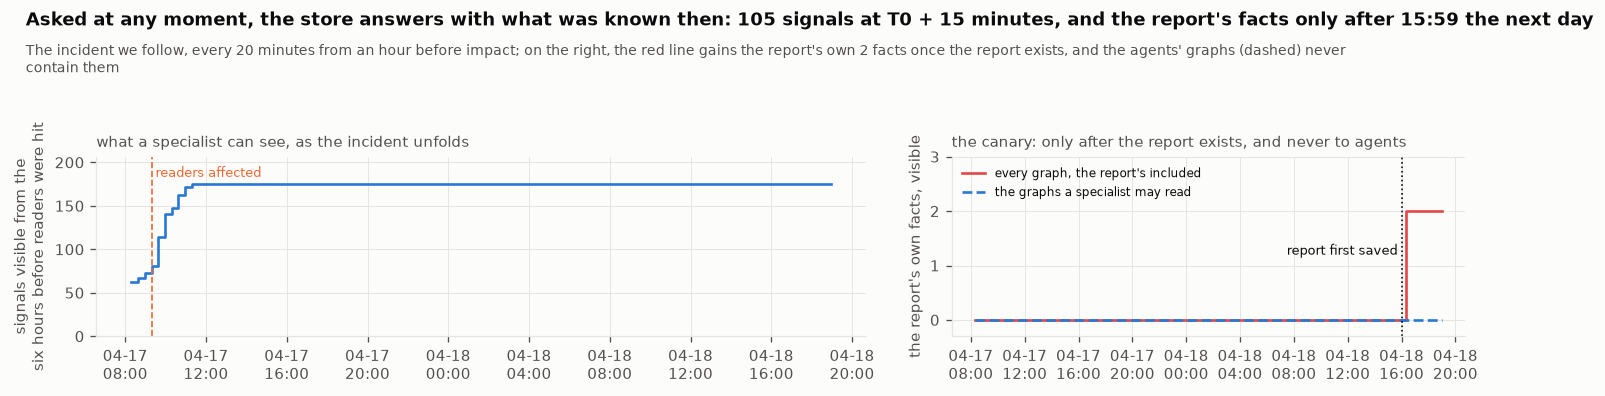

In [114]:
# ---- time travel: a question asked as of T0 + 15 minutes, and the canary that must never come back ----
AS_OF = """SELECT ?s ?type ?t WHERE {{
  VALUES (?asof ?since) {{ ({asof} {since}) }}
  ?s a ?type ; corr:at ?t ; corr:detectedAt ?d .
  ?type rdfs:subClassOf* corr:Signal .
  FILTER(?d <= ?asof && ?t >= ?since) }}"""
TBOX_GRAPH = URIRef(f"{BASE}graph/tbox")
demo._load(TBOX, TBOX_GRAPH)                    # the class hierarchy, so subClassOf* can be followed
AGENT_GRAPHS = [G_CHANGES, G_ALERTS, TBOX_GRAPH]   # what a specialist may read: never the report's graph


def visible(asof, graphs=None, since=None) -> set[str]:
    """Signals in the six hours before T0, as known at `asof`."""
    since = since if since is not None else DEMO_T0 - pd.Timedelta(hours=6)
    return {r["s"].value for r in demo.ask(AS_OF.format(asof=dt_literal(asof).n3(), since=dt_literal(since).n3()), graphs)}


moments = [DEMO_T0 - pd.Timedelta(hours=1), DEMO_T0, DEMO_T0 + pd.Timedelta(minutes=15),
           DEMO_T0 + pd.Timedelta(hours=2), REPORT_AT - pd.Timedelta(minutes=1), REPORT_AT + pd.Timedelta(minutes=1)]
print(f"  {'asked as of':<26}{'all graphs':>11}{'canary?':>9}{'agent graphs':>14}{'canary?':>9}")
print("  " + "-" * 69)
canary_seen = {}
for m in moments:
    everything, agent_view = visible(m), visible(m, AGENT_GRAPHS)
    canary_seen[m] = (str(CANARY) in everything, str(CANARY) in agent_view)
    print(f"  {m:%Y-%m-%d %H:%M} UTC{'':<6}{len(everything):>11}{'yes' if canary_seen[m][0] else 'no':>9}"
          f"{len(agent_view):>14}{'yes' if canary_seen[m][1] else 'no':>9}")
before_report = [m for m in moments if m < REPORT_AT]
ok_slice = not any(canary_seen[m][0] for m in before_report) and canary_seen[moments[-1]][0]
ok_scope = not any(v[1] for v in canary_seen.values())
print(f"\n  [test] as-of slicing hides the canary until the report exists, and shows it after -> "
      f"{'PASS' if ok_slice else 'FAIL'}")
print(f"  [test] the agents' graphs never contain it, whatever the date -> {'PASS' if ok_scope else 'FAIL'}")
print("  Two independent locks: the time filter and the graph scope. Either alone would have stopped this leak;")
print("  section 29's verifier adds a third, rejecting any cited fact the agent was not given.")

grid_t = pd.date_range(DEMO_T0 - pd.Timedelta(hours=1), REPORT_AT + pd.Timedelta(hours=3), freq="20min")
seen_all = [len(visible(m)) for m in grid_t]
seen_agent = [len(visible(m, AGENT_GRAPHS)) for m in grid_t]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.step(grid_t, seen_agent, where="post", color=C1, lw=1.6)
ax.axvline(DEMO_T0, color=C2, ls="--", lw=1)
ax.text(DEMO_T0, max(seen_agent) * 1.12, " readers affected", color=C2, fontsize=7.5, va="top")
ax.set_ylim(0, max(seen_agent) * 1.18)
ax.set_ylabel("signals visible from the\nsix hours before readers were hit")
ax.set_title("what a specialist can see, as the incident unfolds", fontsize=9, color=INK2, loc="left")
ax = axes[1]
only_report = [a - b for a, b in zip(seen_all, seen_agent)]
ax.step(grid_t, only_report, where="post", color=C8, lw=1.6, label="every graph, the report's included")
ax.step(grid_t, [0] * len(grid_t), where="post", color=C1, lw=1.6, ls="--", label="the graphs a specialist may read")
ax.axvline(REPORT_AT, color=INK, ls=":", lw=1)
ax.text(REPORT_AT, max(only_report + [1]) * 0.6, "report first saved ", color=INK, fontsize=7.5, ha="right")
ax.set_ylim(-0.3, max(only_report + [1]) * 1.5)
ax.set_ylabel("the report's own facts, visible")
ax.legend(fontsize=7, loc="upper left")
ax.set_title("the canary: only after the report exists, and never to agents", fontsize=9, color=INK2, loc="left")
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
at_ask = len(visible(DEMO_T0 + pd.Timedelta(minutes=15), AGENT_GRAPHS))
finish(fig, "as_of_slicing", f"Asked at any moment, the store answers with what was known then: {at_ask} signals at "
       f"T0 + 15 minutes, and the report's facts only after {REPORT_AT:%H:%M} the next day",
       f"The incident we follow, every 20 minutes from an hour before impact; on the right, the red line gains the "
       f"report's own {seen_all[-1] - seen_agent[-1]} facts once the report exists, and the agents' graphs (dashed) "
       "never contain them")

In [115]:
# ---- a bad run, caught and rolled back as a unit ----
bad = changes_graph(w0, w1)
shifted = rdflib.Graph()
for s, p, o in bad:                              # the classic bug: local time written as if it were UTC
    if p in (CORR.at, CORR.detectedAt):
        o = dt_literal(pd.Timestamp(str(o)) + pd.Timedelta(hours=1))
    shifted.add((s, p, o))
G_BAD = demo.write(shifted, "wikimedia", "sal-changes", "run-2", ["https://wikitech.wikimedia.org/wiki/Server_Admin_Log"],
                   pd.Timestamp.now(tz="UTC"))
diff = demo.ask(f"""SELECT (COUNT(*) AS ?n) WHERE {{ GRAPH <{G_BAD}> {{ ?s corr:at ?t }}
                    FILTER NOT EXISTS {{ GRAPH <{G_CHANGES}> {{ ?s corr:at ?t }} }} }}""")[0]["n"].value
total_before = sum(demo.sizes().values())
demo.drop(G_BAD)
print(f"  run-2 disagrees with run-1 on {diff} of {len(set(bad.subjects(CORR.at, None)))} change times "
      f"(every one shifted by an hour)")
print(f"  quads before the rollback {total_before:,}, after {sum(demo.sizes().values()):,}; "
      f"run-2's graph and its PROV-O record are gone")
left = demo.ask(f"SELECT (COUNT(*) AS ?n) WHERE {{ GRAPH <{META}> {{ ?s ?p ?o FILTER(CONTAINS(STR(?s), 'run-2')) }} }}")
print(f"  [test] nothing of run-2 is left, run-1 is untouched -> "
      f"{'PASS' if left[0]['n'].value == '0' and str(G_CHANGES) in demo.sizes() else 'FAIL'}")

  run-2 disagrees with run-1 on 121 of 121 change times (every one shifted by an hour)
  quads before the rollback 2,067, after 1,322; run-2's graph and its PROV-O record are gone
  [test] nothing of run-2 is left, run-1 is untouched -> PASS


In [116]:
# ---- archives that diff: sorted N-Triples per run, and the same input always gives the same hash ----
SNAP_DIR = ART / "graph" / "snapshots" / RUN_TAG
path1, h1 = demo.snapshot(G_CHANGES, SNAP_DIR)
again = GraphStore()
g_again = again.write(changes_graph(w0, w1), "wikimedia", "sal-changes", "run-1", [], pd.Timestamp.now(tz="UTC"))
_, h2 = again.snapshot(g_again, SNAP_DIR / "rerun")
print(f"  {path1.relative_to(ROOT)}  {path1.stat().st_size / 1e3:.1f} kB  sha256 {h1}")
print(f"  rebuilt from the same input in a fresh store                 sha256 {h2}")
print(f"  [test] deterministic URIs + sorted output = identical archives -> {'PASS' if h1 == h2 else 'FAIL'}")
print("\n  first lines of the archive:")
for line in path1.read_text(encoding="utf-8").splitlines()[:3]:
    print(f"    {line[:118]}")

  artifacts\graph\snapshots\full\wikimedia-sal-changes-run-1.nt  135.2 kB  sha256 630b28a0e40b68b2
  rebuilt from the same input in a fresh store                 sha256 630b28a0e40b68b2
  [test] deterministic URIs + sorted output = identical archives -> PASS

  first lines of the archive:
    <https://kg.example.org/id/wikimedia/change/20240417t032400-1f46d973> <http://www.w3.org/1999/02/22-rdf-syntax-ns#type
    <https://kg.example.org/id/wikimedia/change/20240417t032400-1f46d973> <https://kg.example.org/correlation#at> "2024-04
    <https://kg.example.org/id/wikimedia/change/20240417t032400-1f46d973> <https://kg.example.org/correlation#detectedAt> 


In [117]:
# ---- hour buckets, measured: every real change since 2021 in an on-disk store, two ways to ask for a window ----
bench_file = RES_DIR / "hour_buckets.json"
BENCH_DIR = GRAPH_DIR / f"bench_{RUN_TAG}"


def change_ntriples(df: pd.DataFrame) -> str:
    """N-Triples written directly: at a million triples, building rdflib objects first would dominate the load time."""
    at_p, det_p, hr_p, ty = (f"<{CORR.at}>", f"<{CORR.detectedAt}>", f"<{CORR.inHour}>", f"<{RDF.type}>")
    out = []
    for ts, kind, msg in zip(df.ts, df.kind, df.message):
        s = f"<{mint('wikimedia', 'change', f'{ts:%Y%m%dT%H%M%S}-' + hashlib.sha256(msg.encode()).hexdigest()[:8])}>"
        lit = f'"{ts:%Y-%m-%dT%H:%M:%SZ}"^^<{XSD.dateTime}>'
        out += [f"{s} {ty} <{KIND_CLASS[kind]}> .", f"{s} {at_p} {lit} .", f"{s} {det_p} {lit} .",
                f"{s} {hr_p} <{hour_node(ts)}> ."]
    return "\n".join(out) + "\n"


WINDOW_FILTER = """SELECT (COUNT(?s) AS ?n) WHERE {{ ?s corr:at ?t .
  FILTER(?t > "{a}"^^xsd:dateTime && ?t <= "{b}"^^xsd:dateTime) }}"""
WINDOW_BUCKET = """SELECT (COUNT(?s) AS ?n) WHERE {{ VALUES ?h {{ {hours} }} ?s corr:inHour ?h ; corr:at ?t .
  FILTER(?t > "{a}"^^xsd:dateTime && ?t <= "{b}"^^xsd:dateTime) }}"""


def window_queries(t: pd.Timestamp, minutes: int = 60) -> tuple[str, str]:
    a, b = t - pd.Timedelta(minutes=minutes), t
    hours = " ".join(f"<{hour_node(h)}>" for h in pd.date_range(a.floor("h"), b.floor("h"), freq="h"))
    fmt = dict(a=f"{a:%Y-%m-%dT%H:%M:%SZ}", b=f"{b:%Y-%m-%dT%H:%M:%SZ}", hours=hours)
    return PREFIXES + WINDOW_FILTER.format(**fmt), PREFIXES + WINDOW_BUCKET.format(**fmt)


if bench_file.exists() and not RECOMPUTE:
    BENCH = json.loads(bench_file.read_text())
    print(f"  [cache] {bench_file.name}, {power_note(BENCH.get('power'))}")
else:
    shutil.rmtree(BENCH_DIR, ignore_errors=True)
    bench = ox.Store(str(BENCH_DIR))
    t0 = time.perf_counter()
    bench_nt = change_ntriples(CHANGES)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter()
    bench.bulk_load(bench_nt.encode(), format=ox.RdfFormat.N_TRIPLES)
    bench.flush()
    t_load = time.perf_counter() - t0
    n_triples = bench_nt.count("\n")
    lat = {"filter": [], "bucket": []}
    n_agree = 0
    picks = pd.to_datetime(np.random.default_rng(SEED).choice(RANDOM_MOMENTS, 100), unit="s", utc=True)
    for t in picks:
        q_filter, q_bucket = window_queries(t)
        counts = []
        for name, q in (("filter", q_filter), ("bucket", q_bucket)):
            s0 = time.perf_counter()
            counts.append(int(next(iter(bench.query(q)))["n"].value))
            lat[name].append(time.perf_counter() - s0)
        n_agree += counts[0] == counts[1]
    BENCH = {"changes": len(CHANGES), "triples": n_triples, "build_s": round(t_build, 1), "load_s": round(t_load, 1),
             "disk_mb": round(sum(p.stat().st_size for p in BENCH_DIR.rglob("*") if p.is_file()) / 1e6, 1),
             "latency_ms": {k: [round(v * 1000, 3) for v in vs] for k, vs in lat.items()}, "agree": n_agree,
             "queries": len(picks), "power": power_state()}
    bench_file.write_text(json.dumps(BENCH))
    print(f"  timed {power_note(BENCH['power'])}")
    del bench
lat_f, lat_b = np.array(BENCH["latency_ms"]["filter"]), np.array(BENCH["latency_ms"]["bucket"])
print(f"  {BENCH['changes']:,} changes -> {BENCH['triples']:,} triples; written in {BENCH['build_s']}s, bulk-loaded in "
      f"{BENCH['load_s']}s ({BENCH['triples'] / max(BENCH['load_s'], 1e-9):,.0f} triples/s), {BENCH['disk_mb']} MB on disk")
print(f"  'what changed in the hour before t?', asked {BENCH['queries']} times at random moments:")
print(f"    range filter over every change time    median {np.median(lat_f):8.2f} ms   p95 {np.percentile(lat_f, 95):8.2f} ms")
print(f"    hour buckets, then the same filter     median {np.median(lat_b):8.2f} ms   p95 {np.percentile(lat_b, 95):8.2f} ms")
print(f"  [test] both ways give the same count on {BENCH['agree']}/{BENCH['queries']} questions -> "
      f"{'PASS' if BENCH['agree'] == BENCH['queries'] else 'FAIL'}; buckets are "
      f"{np.median(lat_f) / np.median(lat_b):.0f}x faster at the median")

  [cache] hour_buckets.json, on mains power
  283,743 changes -> 1,134,972 triples; written in 5.6s, bulk-loaded in 1.8s (630,540 triples/s), 175.6 MB on disk
  'what changed in the hour before t?', asked 100 times at random moments:
    range filter over every change time    median    85.55 ms   p95   100.77 ms
    hour buckets, then the same filter     median     0.50 ms   p95     1.25 ms
  [test] both ways give the same count on 100/100 questions -> PASS; buckets are 171x faster at the median


[fig] artifacts\figures_full\store.png


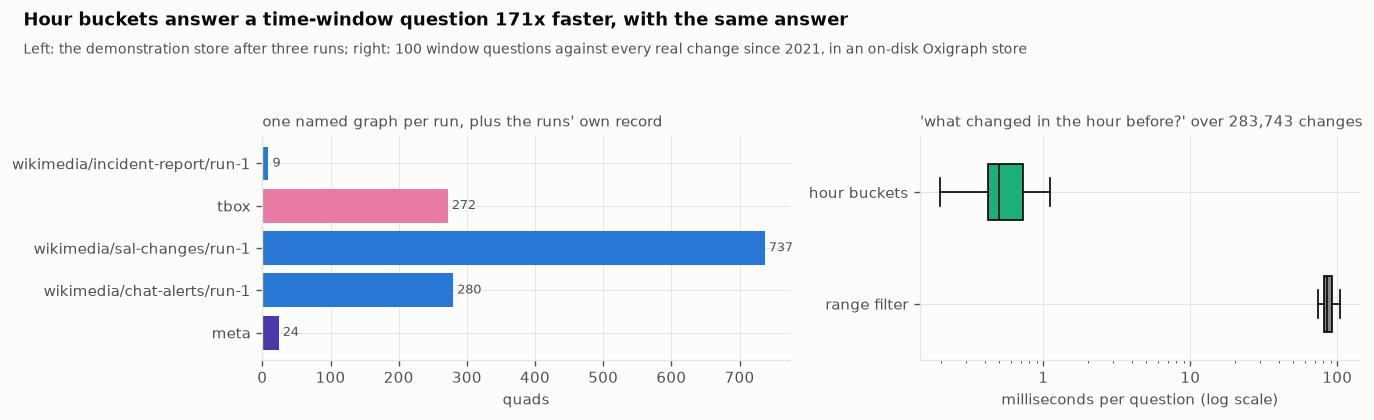

In [118]:
# ---- the store, drawn ----
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
sizes = {g.removeprefix(BASE + "graph/"): n for g, n in demo.sizes().items()}
axes[0].barh(list(sizes), list(sizes.values()), color=[C7 if k == "meta" else C5 if k == "tbox" else C1 for k in sizes])
for i, v in enumerate(sizes.values()):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=7.5, color=INK2)
axes[0].invert_yaxis()
axes[0].set_xlabel("quads")
axes[0].set_title("one named graph per run, plus the runs' own record", fontsize=9, color=INK2, loc="left")
parts = axes[1].boxplot([lat_f, lat_b], orientation="horizontal", widths=0.5, patch_artist=True, showfliers=False,
                        medianprops={"color": INK})
for patch, colour in zip(parts["boxes"], (MUTED, C3)):
    patch.set_facecolor(colour)
axes[1].set_yticks([1, 2], ["range filter", "hour buckets"])
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
axes[1].xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
axes[1].set_xlabel("milliseconds per question (log scale)")
axes[1].set_title(f"'what changed in the hour before?' over {BENCH['changes']:,} changes", fontsize=9, color=INK2,
                  loc="left")
finish(fig, "store",
       f"Hour buckets answer a time-window question {np.median(lat_f) / np.median(lat_b):.0f}x faster, with the same answer",
       "Left: the demonstration store after three runs; right: 100 window questions against every real change since 2021, "
       "in an on-disk Oxigraph store")

**The store answers "who said this?" in one query, hides the future from the agents twice
over, rolls a bad run back as a unit, and answers the commonest question 171 times faster with
hour buckets.** Every fact lives in the named graph of the run that wrote it, and every run is
itself described in PROV-O, so the origin of a fact, here a change logged on the morning of the
incident we follow, is a lookup rather than an archaeology project: which enricher, which run,
which source. Time travel is a filter on when each fact became known. The report on our outage
was first saved 1.3 days after impact, and the canary planted in it stays invisible at every
moment before that; the agents' graphs never contain it at all, so either lock alone would have
stopped the leak. A second run with all 121 of its change times an hour off was removed whole,
taking the store from 2,067 quads back to 1,322 and leaving the first run untouched. A run's
archive is sorted N-Triples, so a rebuild from the same input in a fresh store gave the same
hash. Last, the question every investigation begins with, "what changed in the hour before t?",
over all 283,743 real changes since 2021 (1,134,972 triples, 175.6 MB on disk): a range filter
over every change time takes 85.55 ms at the median, and the hour buckets 0.50 ms, with the same
count on all 100 questions. That gap is why every signal in this notebook carries its hour.

## 15 · The enricher contract: fetch, analyse, emit typed facts, say what was covered

**Theory.** The post's enrichers share one small interface: each fetches from one source,
analyses what it got, and returns typed triples together with a result that describes what
happened. Three rules make a fleet of them safe. They run one at a time, in an order derived from
what each needs and what each produces, which removes a whole class of race conditions at a cost
in wall-clock time the post says it is happy to pay. Calls to outside systems are best-effort: a
slow API degrades the harvest instead of blocking it. And a rule the post implies without stating
it: every run records what it covered, so that a missing fact can be told apart from a fact
nobody looked for. "No alert fired" and "the alert source was down" are different answers, and an
agent that confuses them will exonerate the wrong component. Here is the contract in a few dozen
lines, then three small enrichers that obey it. Worlds: all; the demonstration uses the incident
we follow.

In [119]:
# ---- the contract: what every enricher must return, and what the pipeline records for it ----
@dataclass
class Coverage:
    source: str
    start: pd.Timestamp
    end: pd.Timestamp
    status: str                        # ok | partial | missing
    detail: str = ""


@dataclass
class EnrichmentResult:
    enricher: str
    facts: rdflib.Graph
    coverage: list
    seconds: float
    errors: list = field(default_factory=list)


class Enricher:
    """fetch() talks to one source and may fail; analyse() is pure and turns what was fetched into typed triples."""
    name, requires, produces, source = "enricher", (), (), ""

    def fetch(self, start: pd.Timestamp, end: pd.Timestamp):
        raise NotImplementedError

    def analyse(self, raw, start: pd.Timestamp, end: pd.Timestamp) -> rdflib.Graph:
        raise NotImplementedError

    def run(self, start: pd.Timestamp, end: pd.Timestamp) -> EnrichmentResult:
        t0, errors = time.perf_counter(), []
        try:
            raw = self.fetch(start, end)
        except Exception as e:                       # best-effort: a failed source costs coverage, not the harvest
            raw = None
            errors.append(f"{type(e).__name__}: {e}")
        if raw is None:
            facts, status = rdflib.Graph(), "missing"
        else:
            facts, status = self.analyse(raw, start, end), "ok"
        cov = Coverage(self.source, start, end, status, errors[0] if errors else "")
        return EnrichmentResult(self.name, facts, [cov], round(time.perf_counter() - t0, 3), errors)


def coverage_facts(cov: Coverage, enricher: str) -> rdflib.Graph:
    g = rdflib.Graph()
    node = mint("harvest", "coverage", f"{enricher}-{cov.source}-{cov.start:%Y%m%dT%H%M}-{cov.end:%Y%m%dT%H%M}")
    for p, o in ((RDF.type, HARVEST.Coverage), (HARVEST.source, Literal(cov.source)),
                 (HARVEST.windowStart, dt_literal(cov.start)), (HARVEST.windowEnd, dt_literal(cov.end)),
                 (HARVEST.status, Literal(cov.status))):
        g.add((node, p, o))
    return g


print("  Enricher.fetch -> Enricher.analyse -> EnrichmentResult(facts, coverage, seconds, errors)")

  Enricher.fetch -> Enricher.analyse -> EnrichmentResult(facts, coverage, seconds, errors)


In [120]:
# ---- the order is derived, never typed in: each enricher runs after everything it needs ----
def plan_order(enrichers: list, available: frozenset = frozenset()) -> list:
    """Kahn's algorithm over 'requires' and 'produces'. A requirement that neither another enricher nor the store
    (`available`) provides, or a cycle, stops the plan before anything runs."""
    producers = defaultdict(set)
    for e in enrichers:
        for cls in e.produces:
            producers[cls].add(e.name)
    for e in enrichers:
        for cls in e.requires:
            if not producers[cls] - {e.name} and cls not in available:
                raise ValueError(f"{e.name} requires {cls.n3(TBOX.namespace_manager)}, which no enricher produces")
    deps = {e.name: {p for cls in e.requires for p in producers[cls]} - {e.name} for e in enrichers}
    by_name, order = {e.name: e for e in enrichers}, []
    ready = sorted(n for n, d in deps.items() if not d)
    while ready:
        n = ready.pop(0)
        order.append(by_name[n])
        for m, d in deps.items():
            if n in d:
                d.discard(n)
                if not d and m not in [o.name for o in order] and m not in ready:
                    ready.append(m)
                    ready.sort()
    if len(order) != len(enrichers):
        raise ValueError(f"cycle among {sorted(set(by_name) - {o.name for o in order})}")
    return order


print("  plan_order: topological sort on requires/produces; unmet requirements and cycles raise before anything runs")

  plan_order: topological sort on requires/produces; unmet requirements and cycles raise before anything runs


In [121]:
# ---- three enrichers that obey it, on the incident we follow ----
class CatalogHosts(Enricher):
    name, produces, source = "catalog-hosts", (OPS.Host, OPS.Cluster), "puppet conftool-data"

    def fetch(self, start, end):
        return CATALOG["hosts"]

    def analyse(self, hosts, start, end):
        g = rdflib.Graph()
        for fqdn, h in hosts.items():
            host, cluster = mint("wikimedia", "host", fqdn.split(".")[0]), mint("wikimedia", "cluster", h["cluster"])
            g.add((host, RDF.type, OPS.Host))
            g.add((host, OPS.name, Literal(fqdn.split(".")[0])))
            g.add((cluster, RDF.type, OPS.Cluster))
            g.add((cluster, OPS.name, Literal(h["cluster"])))
            g.add((host, OPS.memberOf, cluster))
        return g


CATALOG_HOSTS = {fqdn.split(".")[0] for fqdn in CATALOG["hosts"]}


class SalChanges(Enricher):
    name, requires, produces, source = "sal-changes", (OPS.Host,), (TL.Change,), "Server Admin Log"

    def fetch(self, start, end):
        return CHANGES[(CHANGES.ts >= start) & (CHANGES.ts < end)]

    def analyse(self, rows, start, end):
        return changes_graph(start, end, gate=CATALOG_HOSTS)


class LokiAlerts(Enricher):
    """Loki keeps about six months; asking for older windows is a real, recorded gap, not an empty result."""
    name, requires, produces, source = "loki-alerts", (OPS.Host,), (ALERT.Firing,), "Loki alert stream"
    simulate_outage = False

    def fetch(self, start, end):
        if self.simulate_outage:
            raise TimeoutError("Loki did not answer within 30 s")
        if start < ALERTS_LOKI.ts.min():
            raise LookupError(f"outside retention: Loki starts at {ALERTS_LOKI.ts.min():%Y-%m-%d}")
        return ALERTS_LOKI[(ALERTS_LOKI.ts >= start) & (ALERTS_LOKI.ts < end)]

    def analyse(self, rows, start, end):
        g = rdflib.Graph()
        for _, r in rows[rows.status == "firing"].iterrows():
            m = LOKI_LINE.match(r.line)
            name = m.group(2) if m else r.line[:60]
            node = mint("wikimedia", "firing", f"{r.ts:%Y%m%dT%H%M%S}-{slug(name)}")
            signal(g, node, ALERT.Firing, r.ts, r.ts, target_host(r.line, CATALOG_HOSTS))
            g.add((node, ALERT.source, Literal(r.source or "unknown")))
        return g


ENRICHERS = [LokiAlerts(), SalChanges(), CatalogHosts()]          # deliberately listed in the wrong order
plan = plan_order(ENRICHERS)
print(f"  listed as  {[e.name for e in ENRICHERS]}")
print(f"  runs as    {[e.name for e in plan]}")
same = all([e.name for e in plan_order(random.Random(i).sample(ENRICHERS, 3))] == [e.name for e in plan] for i in range(20))
print(f"  [test] 20 shuffled listings give the same plan -> {'PASS' if same else 'FAIL'}")


class NeedsIncidents(Enricher):
    name, requires, produces = "needs-incidents", (OPS.Incident,), (RCA.Hypothesis,)


try:
    plan_order(ENRICHERS + [NeedsIncidents()])
    print("  [test] an unmet requirement is refused before anything runs -> FAIL")
except ValueError as e:
    print(f"  [test] an unmet requirement is refused before anything runs -> PASS ({e})")

  listed as  ['loki-alerts', 'sal-changes', 'catalog-hosts']
  runs as    ['catalog-hosts', 'loki-alerts', 'sal-changes']
  [test] 20 shuffled listings give the same plan -> PASS
  [test] an unmet requirement is refused before anything runs -> PASS (needs-incidents requires ops:Incident, which no enricher produces)


In [122]:
# ---- the pipeline: run in plan order, validate every delta, write it with its coverage, keep going on failure ----
SHAPE_PATHS = ", ".join(sorted({f"<{SHAPES.value(p, SH.path)}>" for p in SHAPES.objects(None, SH.property)}))


def stored_context(store: GraphStore, facts: rdflib.Graph, replacing: URIRef | None = None) -> rdflib.Graph:
    """What the shapes need from the store to judge a delta (section 13's trap, both halves): the stored type of every
    node the delta mentions and, for the nodes it writes about, their stored values on the shapes' paths with those
    values' types. A graph the write is about to replace is left out, so a rerun is judged against what will remain."""
    ours = lambda n: isinstance(n, URIRef) and str(n).startswith(BASE + "id/")
    mentioned = {n for s, _, o in facts for n in (s, o) if ours(n)}
    described = {s for s in facts.subjects() if ours(s)}
    keep = [g for g in store.store.named_graphs() if replacing is None or g.value != str(replacing)]
    ctx = rdflib.Graph()
    for nodes, head, body in ((mentioned, "?s a ?c", "?s a ?c"),
                              (described, "?s ?p ?o . ?o a ?c", f"?s ?p ?o FILTER(?p IN ({SHAPE_PATHS})) "
                                                                "OPTIONAL { ?o a ?c }")):
        for chunk in itertools.batched(sorted(nodes), 500):
            values = " ".join(f"<{n}>" for n in chunk)
            found = store.store.query(f"{STORE_PREFIXES} CONSTRUCT {{ {head} }} WHERE {{ VALUES ?s {{ {values} }} {body} }}",
                                      default_graph=keep)
            ctx.parse(data=found.serialize(format=ox.RdfFormat.N_TRIPLES).decode("utf-8"), format="nt")
    return ctx - facts                                   # each triple once: the delta already says what it says


def run_pipeline(enrichers: list, start, end, store: GraphStore, tenant: str, run_id: str) -> list:
    results = []
    stored = frozenset(URIRef(r["c"].value) for r in store.ask("SELECT DISTINCT ?c WHERE { ?s a ?c }"))
    print(f"  {'enricher':<16}{'facts':>7}{'coverage':>10}{'valid':>7}{'secs':>7}  note")
    print("  " + "-" * 92)
    for e in plan_order(enrichers, stored):
        started = pd.Timestamp.now(tz="UTC")
        res = e.run(start, end)
        # the compiled rules (section 13): pySHACL's answers at store speed, which matters for deltas of 10^5 triples
        context = stored_context(store, res.facts, store.graph_for(tenant, e.name, run_id))
        conforms, rows = check_fast(res.facts, context) if len(res.facts) else (True, [])
        if not conforms:                       # quarantined: the run is recorded, its facts are not
            res.errors.append(f"{len(rows)} shape violations, first: {rows[0][2]} on {rows[0][1]}")
            res.coverage[0].status = "partial"
            res.facts = rdflib.Graph()
        payload = res.facts + coverage_facts(res.coverage[0], e.name)
        store.write(payload, tenant, e.name, run_id, [], started)
        results.append(res)
        print(f"  {e.name:<16}{len(res.facts):>7,}{res.coverage[0].status:>10}{'yes' if conforms else 'NO':>7}"
              f"{res.seconds:>7.2f}  {(res.errors[0] if res.errors else '')[:52]}")
    return results


# Loki keeps six months, so the demonstration uses the latest incident inside that window
recent = inc_w[inc_w.start >= ALERTS_LOKI.ts.min() + pd.Timedelta(hours=6)]
PIPE_T0 = recent.start.max() if len(recent) else ALERTS_LOKI.ts.max().floor("min") - pd.Timedelta(hours=2)
P_START, P_END = PIPE_T0 - pd.Timedelta(hours=6), PIPE_T0 + pd.Timedelta(hours=2)
print(f"  window {P_START:%Y-%m-%d %H:%M} to {P_END:%Y-%m-%d %H:%M} UTC, around "
      f"{recent.loc[recent.start.idxmax(), 'id'] if len(recent) else 'a recent moment'}\n")
pipe = GraphStore()
pipe._load(TBOX, TBOX_GRAPH)
RESULTS = run_pipeline(ENRICHERS, P_START, P_END, pipe, "wikimedia", "pipeline-1")
old = LokiAlerts().run(DEMO_T0 - pd.Timedelta(hours=6), DEMO_T0 + pd.Timedelta(hours=2))
print(f"\n  the same alert enricher on the incident we follow ({DEMO_T0:%Y-%m-%d}): coverage '{old.coverage[0].status}'"
      + (f", {old.coverage[0].detail}" if old.coverage[0].detail else ""))

  window 2026-10-20 18:00 to 2026-10-21 02:00 UTC, around Incidents/2026-10-21 PHP security update

  enricher          facts  coverage  valid   secs  note
  --------------------------------------------------------------------------------------------


  catalog-hosts     3,531        ok    yes   0.09  


  loki-alerts       2,814        ok    yes   1.24  
  sal-changes         380        ok    yes   0.06  

  the same alert enricher on the incident we follow (2024-04-17): coverage 'missing', LookupError: outside retention: Loki starts at 2026-05-03


In [123]:
# ---- [test] what a delta is judged against: its own nodes, with what the store already knows about them ----
probe = GraphStore()
probe._load(TBOX, TBOX_GRAPH)
HEAD_ = (f"@prefix ops: <{OPS}> . @prefix corr: <{CORR}> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> . "
         f"@prefix : <{BASE}id/test/> .\n")
AT_ = 'corr:at "2026-10-01T09:00:00Z"^^xsd:dateTime'         # an incident is a signal, so it needs its one time
probe._load(rdflib.Graph().parse(data=HEAD_ + """:wdqs a ops:Application ; ops:catalogId "svc-wdqs" .
:db1 a ops:Host ; ops:name "db1" ; ops:memberOf :s7 .
:s7 a ops:Cluster ; ops:name "s7" .  :s8 a ops:Cluster ; ops:name "s8" .""", format="turtle"),
            GraphStore.graph_for("test", "catalogue", "run-1"))
CASES_ = [("an incident naming a catalogued service", f":inc1 a ops:Incident ; {AT_} ; ops:affects :wdqs .", True),
          ("a service the catalogue never issued", ':junk a ops:Application ; ops:name "junk" .', False),
          ("a second cluster for a stored host", ":db1 ops:memberOf :s8 .", False),
          ("an incident naming something unknown", f":inc2 a ops:Incident ; {AT_} ; ops:affects :nowhere .", False)]
verdict = lambda ok, rows: "accepted" if ok else f"refused: {rows[0][2]} {rows[0][1]} on :{rows[0][0]}"
print(f"  {'delta':<42}{'types only, every node judged':<44}{'its own nodes judged, with context'}")
PROBE = []
for label, ttl, expect in CASES_:
    delta = rdflib.Graph().parse(data=HEAD_ + ttl, format="turtle")
    ctx = stored_context(probe, delta)
    types_only = rdflib.Graph()
    for t in ctx.triples((None, RDF.type, None)):
        types_only.add(t)
    before, now = check_fast(delta + types_only), check_fast(delta, ctx)
    PROBE.append((label, before[0], now[0], expect))
    print(f"  {label:<42}{verdict(*before):<44}{verdict(*now)}")
print(f"\n  [test] every delta is accepted or refused as it should be -> "
      f"{'PASS' if all(now == expect for _, _, now, expect in PROBE) else 'FAIL'}")
print(f"  [test] the type skeleton alone refuses the good incident -> {'PASS' if not PROBE[0][1] else 'FAIL'}")
print("\n  With only the stored types, a service the incident points at becomes a node to judge, and it fails the")
print("  catalogue gate for want of a catalogue id the store does hold: on the full run, every report that named a")
print("  service was quarantined that way. A database checks a transaction differently. It judges the rows the")
print("  transaction writes, against what is already there. So does this check now: the nodes a delta writes about,")
print("  with their stored values on the shapes' paths, which is also what catches the second cluster above.")

  delta                                     types only, every node judged               its own nodes judged, with context
  an incident naming a catalogued service   refused: MinCount ops:catalogId on :wdqs    accepted
  a service the catalogue never issued      refused: MinCount ops:catalogId on :junk    refused: MinCount ops:catalogId on :junk
  a second cluster for a stored host        refused: MinCount ops:name on :db1          refused: MaxCount ops:memberOf on :db1
  an incident naming something unknown      refused: Class ops:affects on :inc2         refused: Class ops:affects on :inc2

  [test] every delta is accepted or refused as it should be -> PASS
  [test] the type skeleton alone refuses the good incident -> PASS

  With only the stored types, a service the incident points at becomes a node to judge, and it fails the
  catalogue gate for want of a catalogue id the store does hold: on the full run, every report that named a
  service was quarantined that way. A database che

In [124]:
# ---- three answers, not two: yes, no, and nobody looked ----
COVERED = """SELECT ?status WHERE {{ ?c a harvest:Coverage ; harvest:source "{source}" ; harvest:status ?status ;
  harvest:windowStart ?a ; harvest:windowEnd ?b .
  FILTER(?a <= "{t}"^^xsd:dateTime && ?b >= "{t}"^^xsd:dateTime) }}"""
FIRED_ON = """ASK {{ ?f a alert:Firing ; corr:on <{host}> ; corr:at ?t .
  FILTER(?t >= "{a}"^^xsd:dateTime && ?t <= "{b}"^^xsd:dateTime) }}"""


def alerts_answer(store: GraphStore, host: URIRef, t: pd.Timestamp) -> str:
    a, b = (t - pd.Timedelta(minutes=30)).strftime("%Y-%m-%dT%H:%M:%SZ"), t.strftime("%Y-%m-%dT%H:%M:%SZ")
    if store.store.query(STORE_PREFIXES + FIRED_ON.format(host=host, a=a, b=b), use_default_graph_as_union=True):
        return "yes, an alert fired"
    status = store.ask(COVERED.format(source=LokiAlerts.source, t=b))
    if status and status[0]["status"].value == "ok":
        return "no: the source was read and nothing fired"
    return "unknown: the alert source was not covered"


busy = pipe.ask("""SELECT ?h (COUNT(?f) AS ?n) (MAX(?t) AS ?last) WHERE { ?f a alert:Firing ; corr:on ?h ; corr:at ?t }
                    GROUP BY ?h ORDER BY DESC(?n) LIMIT 1""")
loud = URIRef(busy[0]["h"].value) if busy else None
t_loud = pd.Timestamp(busy[0]["last"].value) if busy else PIPE_T0
alerted = {r["h"].value for r in pipe.ask("SELECT DISTINCT ?h WHERE { ?f a alert:Firing ; corr:on ?h }")}
quiet = next(mint("wikimedia", "host", h) for h in sorted(CATALOG_HOSTS) if str(mint("wikimedia", "host", h)) not in alerted)
outage = GraphStore()
outage._load(TBOX, TBOX_GRAPH)
LokiAlerts.simulate_outage = True
with contextlib.redirect_stdout(io.StringIO()):
    run_pipeline(ENRICHERS, P_START, P_END, outage, "wikimedia", "pipeline-outage")
LokiAlerts.simulate_outage = False
ANSWERS = []
print("  'did anything alert on this host in the half hour before t?'")
for label, store, host, t in (("a host that alerted", pipe, loud, t_loud), ("a quiet host", pipe, quiet, PIPE_T0),
                              ("the quiet host, Loki down", outage, quiet, PIPE_T0)):
    if host is None:
        continue
    ANSWERS.append(alerts_answer(store, host, t))
    print(f"    {label:<28}{host.rsplit('/', 1)[-1]:<22}{t:%H:%M}  {ANSWERS[-1]}")
print(f"  [test] three different situations give three different answers -> "
      f"{'PASS' if len(set(ANSWERS)) == 3 else 'FAIL'}")
print("\n  Without coverage records the last two would both read 'no alert fired', and an agent would clear a host")
print("  on the strength of a timeout. Experiment 4 measures what that confusion costs on real incidents.")

  'did anything alert on this host in the half hour before t?'
    a host that alerted         ml-serve1011          22:12  yes, an alert fired
    a quiet host                apus-fe1003           00:00  no: the source was read and nothing fired
    the quiet host, Loki down   apus-fe1003           00:00  unknown: the alert source was not covered
  [test] three different situations give three different answers -> PASS

  Without coverage records the last two would both read 'no alert fired', and an agent would clear a host
  on the strength of a timeout. Experiment 4 measures what that confusion costs on real incidents.


[fig] artifacts\figures_full\enricher_dag.png


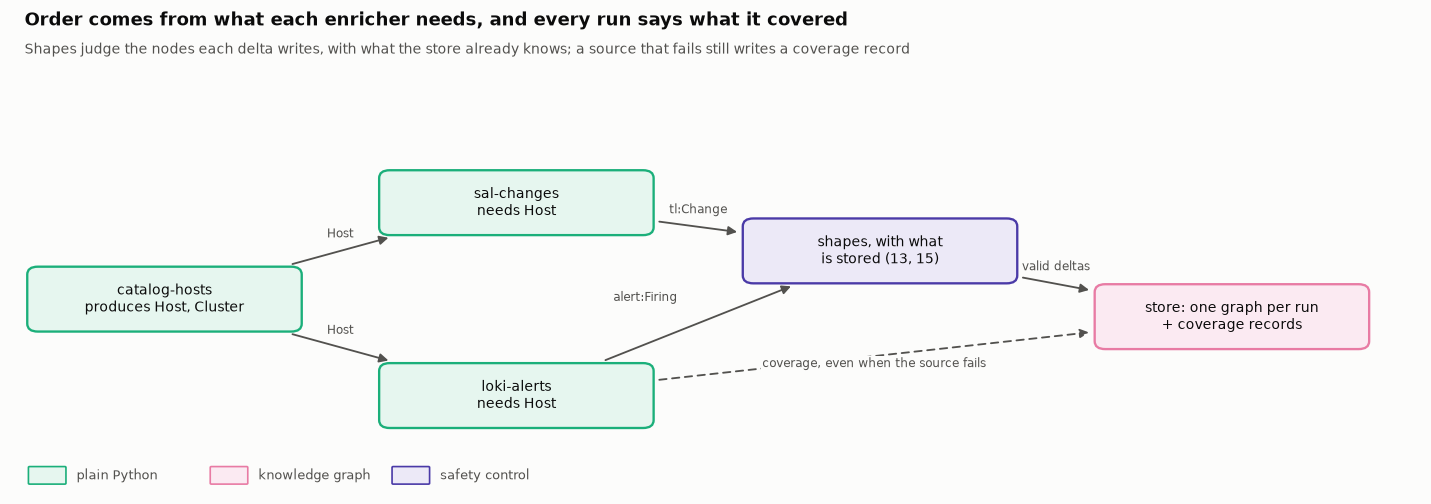

In [125]:
# ---- the enrichers and what flows between them ----
FLOW_NODES = {
    "cat": (1.3, 2.2, "catalog-hosts\nproduces Host, Cluster", "code"),
    "sal": (4.3, 3.3, "sal-changes\nneeds Host", "code"),
    "loki": (4.3, 1.1, "loki-alerts\nneeds Host", "code"),
    "shacl": (7.4, 2.75, "shapes, with what\nis stored (13, 15)", "guard"),
    "store": (10.4, 2.0, "store: one graph per run\n+ coverage records", "graph"),
}
FLOW_EDGES = [("cat", "sal", "Host"), ("cat", "loki", "Host"), ("sal", "shacl", "tl:Change"),
              ("loki", "shacl", "alert:Firing", None, (-0.45, 0.1)), ("shacl", "store", "valid deltas"),
              ("loki", "store", "coverage, even when the source fails", "dashed", (0.0, -0.28))]
draw_flow(FLOW_NODES, FLOW_EDGES, "enricher_dag",
          "Order comes from what each enricher needs, and every run says what it covered",
          "Shapes judge the nodes each delta writes, with what the store already knows; a source that fails still writes "
          "a coverage record",
          size=(12, 4.3), box=(2.3, 0.7))

**Three enrichers, listed in the wrong order on purpose, run in the right one, and a source that
fails leaves a record instead of a silence.** On the most recent incident inside Loki's six-month
window the pipeline wrote 3,531 catalogue facts, 2,814 alert facts and 380 change facts, every
delta valid against the shapes. Run on the incident we follow, which is two years old, the alert
enricher did not return an empty graph; it recorded its coverage as missing, outside retention.
That one line is what lets the three-way answer above say "unknown" instead of "nothing fired".
Experiment 4 in section 36 measures how often the difference matters across real incidents.
The full record also found a second trap in checking deltas. With only the stored types in
view, a catalogued service that an incident named became a node to judge, without the
catalogue id the store holds, and the whole incident delta was quarantined. The check now
judges what a delta writes, with what the store knows about it, the way a database judges a
transaction, and the four probes above are its regression test.

## 16 · Infrastructure and topology: hosts, services, owners, and who calls whom

**Theory.** The infrastructure enricher writes the skeleton every other fact hangs on: the
components, their kinds, where they run and who owns them. Two of the post's rules live here.
The catalogue gate: an application becomes an entity only if the software catalogue knows it,
so a string scraped from an alert or a topology dump never turns into a service of its own. And
the edge cap: "one popular service can carry thousands of reverse dependencies and would
otherwise dominate the graph", so dependency edges are capped in both directions. Wikimedia's
catalogue says which hosts serve which pooled services, which role each host plays and which
team owns each role, but not which service calls which. OpenRCA's traces say exactly that:
every span names its parent, so call edges can be counted. Worlds: Wikimedia for the skeleton,
OpenRCA for the call graph.

In [126]:
# ---- the knowledge graph proper: one on-disk store for every tenant, rebuilt from nothing on every run ----
shutil.rmtree(GRAPH_DIR / f"kg_{RUN_TAG}", ignore_errors=True)   # no fact from an older version of an enricher survives
KG = GraphStore(GRAPH_DIR / f"kg_{RUN_TAG}")
KG._load(TBOX, TBOX_GRAPH)
BUILD = "build-1"
print(f"  store at {GRAPH_DIR / f'kg_{RUN_TAG}'}; graphs so far: {len(KG.sizes())}")

  store at D:\netflix_kg_data\graph\kg_full; graphs so far: 1


In [127]:
# ---- the infrastructure enricher: hosts, datacentres, roles, owners, clusters, and gated applications ----
class Infrastructure(Enricher):
    name, produces, source = "infrastructure", (OPS.Host, OPS.Cluster, OPS.Application, OPS.Team), "puppet + service catalogue"

    def fetch(self, start, end):
        return CATALOG, sorted(set(MENTIONS.host) | set(CONFTOOL))

    def analyse(self, raw, start, end):
        catalog, hosts = raw
        g = rdflib.Graph()
        for name in hosts:
            r = resolve_host(name)
            if not r["host"]:
                continue
            h = mint("wikimedia", "host", r["host"])
            g.add((h, RDF.type, OPS.Host))
            g.add((h, OPS.name, Literal(r["host"])))
            dc = mint("wikimedia", "datacenter", r["dc"])
            g.add((dc, RDF.type, OPS.Datacenter))
            g.add((dc, OPS.name, Literal(r["dc"])))
            g.add((h, OPS.locatedIn, dc))
            if r["role_from"] == "catalogue":           # guesses go to their own graph, below
                role = mint("wikimedia", "role", r["role"])
                g.add((role, RDF.type, OPS.Role))
                g.add((role, OPS.name, Literal(r["role"])))
                g.add((h, OPS.hasRole, role))
                if r["team"]:
                    team = mint("wikimedia", "team", r["team"])
                    g.add((team, RDF.type, OPS.Team))
                    g.add((team, OPS.name, Literal(r["team"])))
                    g.add((role, OPS.ownedBy, team))
                    g.add((h, OPS.ownedBy, team))       # materialised, so 'who owns this host' is one hop
            if r["cluster"]:
                cl = mint("wikimedia", "cluster", r["cluster"])
                g.add((cl, RDF.type, OPS.Cluster))
                g.add((cl, OPS.name, Literal(r["cluster"])))
                g.add((h, OPS.memberOf, cl))
        for name, s in catalog["services"].items():     # the gate: only catalogue entries become applications
            app = mint("wikimedia", "application", name)
            g.add((app, RDF.type, OPS.Application))
            g.add((app, OPS.catalogId, Literal(name)))
            g.add((app, OPS.name, Literal(name)))
            cluster = ((s.get("lvs") or {}).get("conftool") or {}).get("cluster")
            if cluster:
                g.add((app, OPS.runsOn, mint("wikimedia", "cluster", cluster)))
        for name in catalog["k8s_services"]:
            if name not in catalog["services"]:
                app = mint("wikimedia", "application", name)
                g.add((app, RDF.type, OPS.Application))
                g.add((app, OPS.catalogId, Literal(name)))
                g.add((app, OPS.name, Literal(name)))
                g.add((app, OPS.runsOn, mint("wikimedia", "cluster", "kubernetes")))
        return g


class IdentityGuesses(Enricher):
    """Roles guessed from a host's name: useful, but less certain, so they live in a graph a query can leave out."""
    name, requires, produces, source = "identity-guesses", (OPS.Host,), (OPS.Role,), "host name prefixes"

    def fetch(self, start, end):
        return sorted(set(MENTIONS.host))

    def analyse(self, hosts, start, end):
        g = rdflib.Graph()
        for name in hosts:
            r = resolve_host(name)
            if r["role_from"] == "prefix guess":
                role = mint("wikimedia", "role", r["role"])
                g.add((role, RDF.type, OPS.Role))
                g.add((role, OPS.name, Literal(r["role"])))
                g.add((mint("wikimedia", "host", r["host"]), OPS.hasRole, role))
        return g


INFRA = run_pipeline([IdentityGuesses(), Infrastructure()], CHAT_START, NOW, KG, "wikimedia", BUILD)
counts = KG.ask("SELECT ?c (COUNT(DISTINCT ?s) AS ?n) WHERE { ?s a ?c . FILTER(STRSTARTS(STR(?c), STR(ops:))) } "
                "GROUP BY ?c ORDER BY DESC(?n)")
print("  " + "   ".join(f"{r['c'].value.rsplit('#', 1)[-1]} {int(r['n'].value):,}" for r in counts))

  enricher          facts  coverage  valid   secs  note
  --------------------------------------------------------------------------------------------


  infrastructure   24,078        ok    yes   2.30  


  identity-guesses  1,296        ok    yes   1.49  
  Host 5,593   Role 202   Application 189   Cluster 34   Team 10   Datacenter 7


In [128]:
# ---- the catalogue gate, on real strings: what would have become an application without it ----
SERVICE_LIKE = re.compile(r"(?<![\w.-])([a-z][a-z0-9]+(?:-[a-z0-9]+)+)(?![\w-])")
label_values = Counter()          # what a scraper reading alert text would offer as service names
for line in ALERTS_LOKI.line.sample(min(200000, len(ALERTS_LOKI)), random_state=SEED):
    for tok in SERVICE_LIKE.findall(line.lower()):
        if not canonical_host(tok):
            label_values[tok] += 1
gated = {v: n for v, n in label_values.items() if resolve_service(v, cutoff=100)[0] is None}
GATE = {"distinct strings": len(label_values), "in the catalogue": len(label_values) - len(gated),
        "refused": len(gated), "mentions refused": sum(gated.values())}
print(f"  service-like strings in a sample of Loki alert text: {GATE['distinct strings']:,} distinct")
print(f"  known to the catalogue {GATE['in the catalogue']:,}; refused as applications {GATE['refused']:,} "
      f"({GATE['mentions refused']:,} mentions)")
print("  the most frequent refused strings: " + ", ".join(f"{v} ({n:,})" for v, n in Counter(gated).most_common(8)))
print("\n  Without the gate each of these would be an ops:Application with no owner and no catalogue entry, and an")
print("  agent asked 'which application is failing' would have that many more wrong answers to choose from.")

  service-like strings in a sample of Loki alert text: 3,841 distinct
  known to the catalogue 107; refused as applications 3,734 (374,527 mentions)
  the most frequent refused strings: shellbox-main-app (86,128), statsd-exporter (18,268), eventstreams-production (14,068), machinetranslation-production (12,806), mediawiki-main-app (8,560), kserve-container (4,668), recommendation-api-ng-main (2,394), k8s-dse (1,906)

  Without the gate each of these would be an ops:Application with no owner and no catalogue entry, and an
  agent asked 'which application is failing' would have that many more wrong answers to choose from.


[fig] artifacts\figures_full\catalogue_gate.png


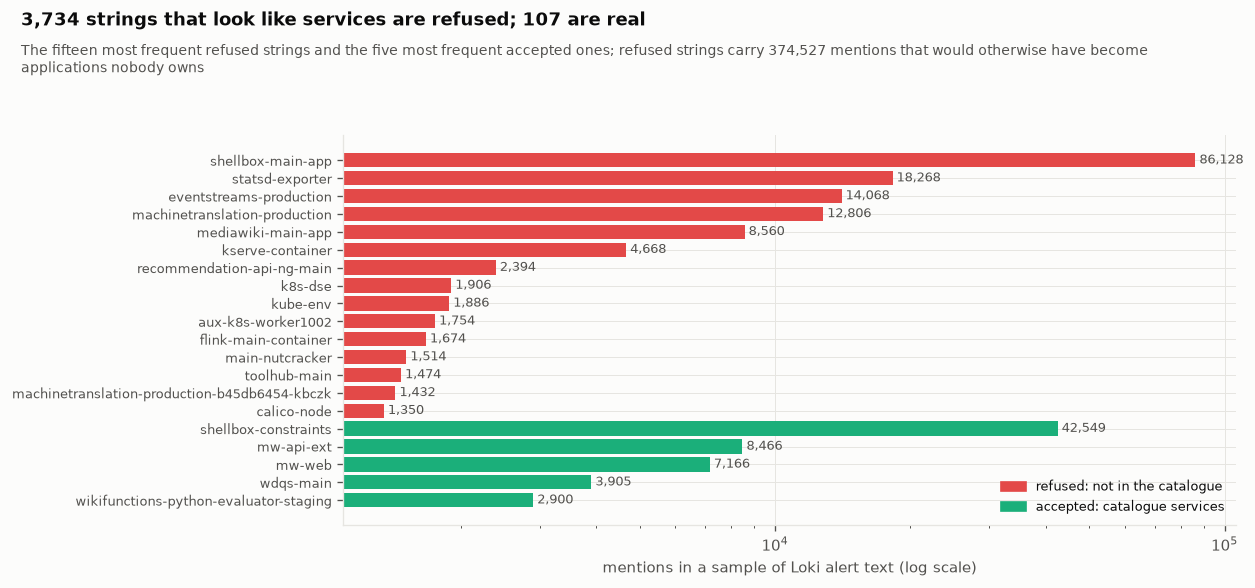

In [129]:
# ---- the gate, drawn: the strings a scraper would have turned into applications ----
top_refused = Counter(gated).most_common(15)
top_known = Counter({v: n for v, n in label_values.items() if v not in gated}).most_common(5)
fig, ax = plt.subplots(figsize=(10.5, 5.0))
names = [v for v, _ in top_refused] + [v for v, _ in top_known]
counts = [n for _, n in top_refused] + [n for _, n in top_known]
ax.barh(range(len(names)), counts, color=[C8] * len(top_refused) + [C3] * len(top_known))
for i, n in enumerate(counts):
    ax.text(n, i, f" {n:,}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(range(len(names)), names, fontsize=7.5)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("mentions in a sample of Loki alert text (log scale)")
ax.legend(handles=[mpl.patches.Patch(color=C8, label="refused: not in the catalogue"),
                   mpl.patches.Patch(color=C3, label="accepted: catalogue services")], fontsize=7.5, loc="lower right")
finish(fig, "catalogue_gate", f"{GATE['refused']:,} strings that look like services are refused; "
       f"{GATE['in the catalogue']:,} are real",
       f"The fifteen most frequent refused strings and the five most frequent accepted ones; refused strings carry "
       f"{GATE['mentions refused']:,} mentions that would otherwise have become applications nobody owns")

In [130]:
# ---- who calls whom: call edges counted from one day of OpenRCA spans per system ----
edges_file = RES_DIR / "openrca_call_edges.parquet"
if edges_file.exists() and not RECOMPUTE:
    CALLS = pd.read_parquet(edges_file)
    print(f"  [cache] {edges_file.name}")
else:
    frames = []
    for system in sorted({r["system"] for r in CONVERTED.values()}):
        files = sorted((OPENRCA_PQ / system / "spans").glob("*.parquet"))
        if not files:
            continue
        f = files[0].as_posix()
        t0 = time.perf_counter()
        e = CON.execute(f"""SELECT '{system}' AS system, p.entity AS caller, c.entity AS callee, count(*) AS calls
            FROM read_parquet('{f}') c JOIN read_parquet('{f}') p ON c.trace_id = p.trace_id AND c.parent_id = p.span_id
            WHERE p.entity <> c.entity GROUP BY ALL""").df()
        print(f"  {system:<11}{Path(f).name:<34}{len(e):>5} caller-callee pairs  ({time.perf_counter() - t0:.0f}s)")
        frames.append(e)
    CALLS = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=["system", "caller", "callee", "calls"])
    save_parquet(CALLS, edges_file)
DEGREE = []
for system, g in CALLS.groupby("system"):
    out_deg, in_deg = g.groupby("caller").size(), g.groupby("callee").size()
    DEGREE.append({"system": system, "components": len(set(g.caller) | set(g.callee)), "edges": len(g),
                   "max out": int(out_deg.max()), "max in": int(in_deg.max()),
                   "busiest callee": in_deg.idxmax()})
DEGREE = pd.DataFrame(DEGREE, columns=["system", "components", "edges", "max out", "max in", "busiest callee"])
MAX_FANIN = int(DEGREE["max in"].max()) if len(DEGREE) else 0
print("\n" + (DEGREE.to_string(index=False) if len(DEGREE) else "  [skip] no span files in this profile"))

  [cache] openrca_call_edges.parquet

    system  components  edges  max out  max in          busiest callee
      bank          12     32        4       8                    MG01
market_cb1          40    142       21      10 productcatalogservice-0
market_cb2          40    142       21      10 productcatalogservice-0
   telecom          10     12        2       2              docker_005


In [131]:
# ---- the call graph enters the store as dependsOn, one tenant per system ----
def call_graph(system: str, edges: pd.DataFrame, cap: int | None = None) -> rdflib.Graph:
    """caller dependsOn callee; with a cap, each component keeps only its `cap` busiest edges in each direction."""
    if cap:
        edges = edges.sort_values("calls", ascending=False)
        edges = edges[edges.groupby("caller").cumcount() < cap]
        edges = edges[edges.groupby("callee").cumcount() < cap]
    g, tenant = rdflib.Graph(), f"openrca-{system}"
    for _, e in edges.iterrows():
        a, b = mint(tenant, "component", e.caller), mint(tenant, "component", e.callee)
        for node, name in ((a, e.caller), (b, e.callee)):
            g.add((node, RDF.type, OPS.Pod))
            g.add((node, OPS.name, Literal(name)))
        g.add((a, OPS.dependsOn, b))
    return g


for system, edges in CALLS.groupby("system"):
    KG.write(call_graph(system, edges), f"openrca-{system}", "topology", BUILD, [], pd.Timestamp.now(tz="UTC"))
host_fanin = pd.Series(Counter(h["cluster"] for h in CATALOG["hosts"].values())).sort_values(ascending=False)
print(f"  dependsOn edges written for {CALLS.system.nunique()} systems; largest fan-in among services: {MAX_FANIN}")
print(f"  for comparison, Wikimedia's biggest pooled cluster, '{host_fanin.index[0]}', has {host_fanin.iloc[0]} member hosts")
CAP_TESTABLE = MAX_FANIN > 50
print(f"\n  The post does not say what its cap is. With at most {MAX_FANIN} callers on any service, a cap of 50 changes "
      f"nothing in OpenRCA: the claim is {'testable' if CAP_TESTABLE else 'NOT TESTABLE'} here.")
print("  The membership hub is different: section 26 tests what happens when the correlation engine may walk through it.")

  dependsOn edges written for 4 systems; largest fan-in among services: 10
  for comparison, Wikimedia's biggest pooled cluster, 'kubernetes', has 552 member hosts

  The post does not say what its cap is. With at most 10 callers on any service, a cap of 50 changes nothing in OpenRCA: the claim is NOT TESTABLE here.
  The membership hub is different: section 26 tests what happens when the correlation engine may walk through it.


[fig] artifacts\figures_full\topology.png


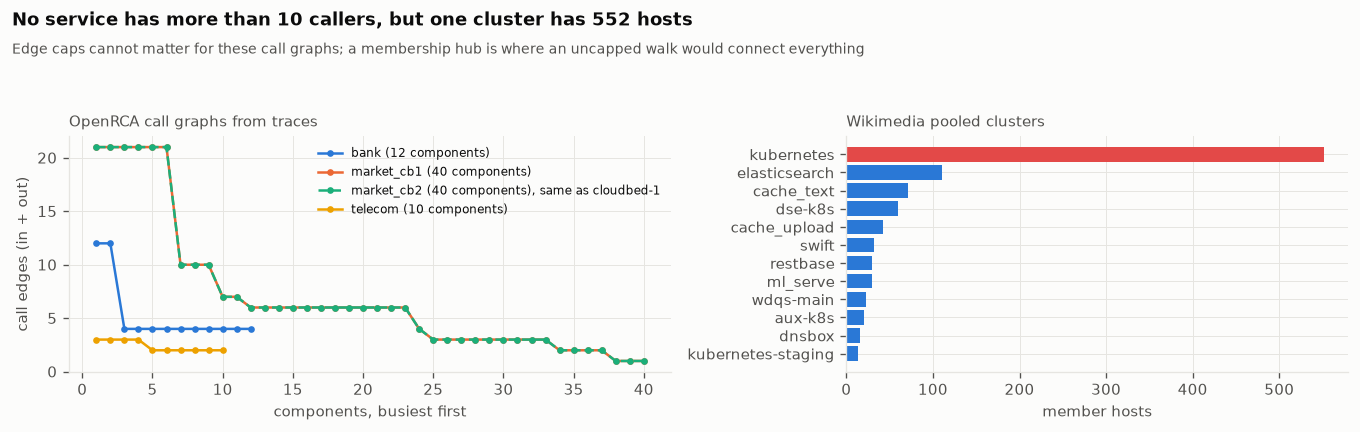

In [132]:
# ---- topology, drawn: call graphs are small and flat; one cluster is a hub ----
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw={"width_ratios": [1.2, 1]})
for (system, g), colour, style in zip(CALLS.groupby("system"), (C1, C2, C3, C4), ("-", "-", "--", "-")):
    deg = pd.concat([g.groupby("caller").size(), g.groupby("callee").size()]).groupby(level=0).sum()
    vals = np.sort(deg.to_numpy())[::-1]
    axes[0].plot(np.arange(1, len(vals) + 1), vals, marker="o", ls=style, ms=3, color=colour,
                 label=f"{system} ({len(vals)} components)" + (", same as cloudbed-1" if system == "market_cb2" else ""))
axes[0].set_xlabel("components, busiest first")
axes[0].set_ylabel("call edges (in + out)")
axes[0].legend(fontsize=7)
axes[0].set_title("OpenRCA call graphs from traces", fontsize=9, color=INK2, loc="left")
top = host_fanin.head(12)
axes[1].barh(top.index, top.values, color=[C8 if i == 0 else C1 for i in range(len(top))])
axes[1].invert_yaxis()
axes[1].set_xlabel("member hosts")
axes[1].set_title("Wikimedia pooled clusters", fontsize=9, color=INK2, loc="left")
finish(fig, "topology",
       f"No service has more than {MAX_FANIN} callers, but one cluster has {host_fanin.iloc[0]} hosts",
       "Edge caps cannot matter for these call graphs; a membership hub is where an uncapped walk would connect everything")

**The infrastructure enricher writes 5,593 hosts, 202 roles, 189 applications, 34 clusters and
10 owning teams, and the catalogue gate refuses 3,734 of the 3,841 service-like names a scraper
would pull from six months of alert text.** Those refused names appear 374,527 times, so the
gate is doing real work; most are pod names with a random suffix, each of which would otherwise
become an application of its own. The gate also has a price the post does not mention: the most
frequent refused name, a container of a real service, is refused because it is not spelt the way
the catalogue spells the service. Strict identity trades a few true names for no junk ones. The
call graphs read from OpenRCA's traces are small and flat, 40 components and 142 edges in the
Market clusters, with no service called by more than 10 others; the post's edge cap cannot change
anything here, and we say so instead of reporting a cap that did nothing.

## 17 · Changes and lineage: from a merged patch to a running deploy

**Theory.** Figure 7's chain starts with a commit and a deployment fourteen minutes apart, and
the post's correlation engine only links signals within ten minutes of each other, so its own
example needs an exception: lineage, the recorded fact that this deploy shipped that commit,
has to override time. Wikimedia writes lineage down in two ways. A backport's log line names the
Gerrit change it ships, and Gerrit records when that change merged. A Kubernetes deploy names
the service it applies, and the chart repository records when that service's configuration
last changed. That lets us measure what the post only illustrates: how long real changes take
to go from merged to live, and how many of those hops a ten-minute window would miss. World:
Wikimedia.

In [133]:
# ---- the changes a deploy says it ships ----
GERRIT_REF = re.compile(r"\[\[gerrit:(\d{5,7})|gerrit\.wikimedia\.org/r/(?:c/[^\s|\]]*?/\+/)?(\d{5,7})"
                        r"|\{\{Gerrit\|(\d{5,7})\}\}")        # {{Gerrit|<hash>}} names a commit, not a change


def change_refs(message: str) -> list[int]:
    return sorted({int(a or b or c) for a, b, c in GERRIT_REF.findall(message or "")})


REF_CASES = [("Synchronized wmf-config/InitialiseSettings.php: Config: [[gerrit:679327{{!}}Change HTTP]]", [679327]),
             ("deploy https://gerrit.wikimedia.org/r/c/operations/homer/public/+/695192 on cr1-eqiad", [695192]),
             ("Synchronized php-1.37.0-wmf.6/skins/Vector/: {{Gerrit|1742532687b}}: Introduce the class", []),
             ("Backport for [[gerrit:1057031{{!}}x]], [[gerrit:1057016{{!}}y]] synced", [1057016, 1057031])]
for msg, want in REF_CASES:
    print(f"  {'PASS' if change_refs(msg) == want else 'FAIL'}  {str(change_refs(msg)):<20}{msg[:84]}")
CHANGES["refs"] = CHANGES.message.map(change_refs)
shipped = CHANGES[CHANGES.refs.map(len) > 0].explode("refs").rename(columns={"refs": "number"})
shipped["number"] = shipped.number.astype(int)
known_merge = GERRIT_CHANGES.set_index("number").submitted
print(f"\n  changes that name what they ship: {CHANGES.refs.map(len).gt(0).sum():,}; distinct Gerrit changes named: "
      f"{shipped.number.nunique():,}; merge time already known from our pull: "
      f"{shipped.number.isin(known_merge.index).mean():.0%} of references")

  PASS  [679327]            Synchronized wmf-config/InitialiseSettings.php: Config: [[gerrit:679327{{!}}Change H
  PASS  [695192]            deploy https://gerrit.wikimedia.org/r/c/operations/homer/public/+/695192 on cr1-eqia
  PASS  []                  Synchronized php-1.37.0-wmf.6/skins/Vector/: {{Gerrit|1742532687b}}: Introduce the c
  PASS  [1057016, 1057031]  Backport for [[gerrit:1057031{{!}}x]], [[gerrit:1057016{{!}}y]] synced



  changes that name what they ship: 16,668; distinct Gerrit changes named: 11,074; merge time already known from our pull: 64% of references


In [134]:
# ---- merge times for changes outside our six repositories: a polite sample from Gerrit ----
def gerrit_change(number: int) -> dict | None:
    try:
        raw = WEB.get(f"{GERRIT}{number}")
    except RuntimeError:
        return None
    c = json.loads(raw.decode("utf-8").split("\n", 1)[1])
    return {"number": number, "project": c.get("project"), "status": c.get("status"),
            "submitted": c.get("submitted", "")}


missing = sorted(set(shipped.number) - set(known_merge.index))
n_sample = {"SMOKE": 20, "MEDIUM": 200}.get(PROFILE, 800)
sample = random.Random(SEED).sample(missing, min(n_sample, len(missing)))
with ThreadPoolExecutor(2) as ex:
    looked = [r for r in ex.map(gerrit_change, sample) if r and r["submitted"]]
extra = pd.DataFrame(looked)
if len(extra):
    extra["submitted"] = pd.to_datetime(extra.submitted.str[:19], utc=True)
    merge_time = pd.concat([known_merge, extra.set_index("number").submitted])
else:
    merge_time = known_merge
print(f"  looked up {len(sample)} of {len(missing):,} changes outside our pull; {len(extra)} had merged")
if len(extra):
    print("  their repositories: " + ", ".join(f"{p} ({n})" for p, n in extra.project.value_counts().head(5).items()))

  looked up 800 of 3,985 changes outside our pull; 796 had merged
  their repositories: mediawiki/core (162), mediawiki/extensions/GrowthExperiments (70), mediawiki/extensions/WikimediaEvents (33), mediawiki/extensions/CheckUser (30), mediawiki/skins/Vector (25)


In [135]:
# ---- how long from merged to live: backports, and Kubernetes applies matched to chart changes ----
hops = shipped[shipped.number.isin(merge_time.index)].copy()
hops["merged"] = hops.number.map(merge_time)
hops["gap_min"] = (hops.ts - hops.merged).dt.total_seconds() / 60
hops = hops[(hops.gap_min > -5) & (hops.gap_min < 14 * 1440)]            # same change, sensible order
HELM_APPLY = re.compile(r"helmfile \[([\w-]+)\] START helmfile\.d/services/([\w-]+)")
charts = GERRIT_CHANGES[GERRIT_CHANGES.project == "operations/deployment-charts"].sort_values("submitted")
applies = CHANGES[CHANGES.message.str.contains("helmfile", regex=False)].copy()
applies[["site", "service"]] = applies.message.str.extract(HELM_APPLY)
applies = applies.dropna(subset=["service"])
chart_times = {s: g.submitted.to_numpy() for s, g in
               charts.assign(service=charts.subject.str.extract(r"^([\w-]+):")[0]).dropna(subset=["service"]).groupby("service")}
helm_gaps = []
for t, svc in zip(applies.ts.to_numpy(), applies.service):
    times = chart_times.get(svc)
    if times is not None:
        i = np.searchsorted(times, t) - 1
        if i >= 0 and (t - times[i]) < np.timedelta64(1, "D"):
            helm_gaps.append((t - times[i]) / np.timedelta64(1, "m"))
HELM_GAPS = np.array(helm_gaps)
LINEAGE = {"backport": hops.gap_min.to_numpy(), "chart apply": HELM_GAPS}
print(f"  {'route':<14}{'hops':>8}{'median':>10}{'p90':>10}{'over 10 min':>13}")
for name, gaps in LINEAGE.items():
    if len(gaps):
        print(f"  {name:<14}{len(gaps):>8,}{np.median(gaps):>9.0f}m{np.percentile(gaps, 90):>9.0f}m{(gaps > 10).mean():>13.0%}")
over = np.concatenate([g for g in LINEAGE.values() if len(g)]) if any(len(g) for g in LINEAGE.values()) else np.array([])
print(f"\n  a timing-only engine with a 10-minute window would drop {(over > 10).mean():.0%} of real merge-to-live hops; "
      f"figure 7's 14-minute hop is {'common, not an edge case' if (over > 10).mean() > 0.1 else 'the exception it looks like'}")

  route             hops    median       p90  over 10 min
  backport        14,834        2m       11m          11%
  chart apply      7,587        7m      226m          43%

  a timing-only engine with a 10-minute window would drop 22% of real merge-to-live hops; figure 7's 14-minute hop is common, not an edge case


[fig] artifacts\figures_full\lineage_gaps.png


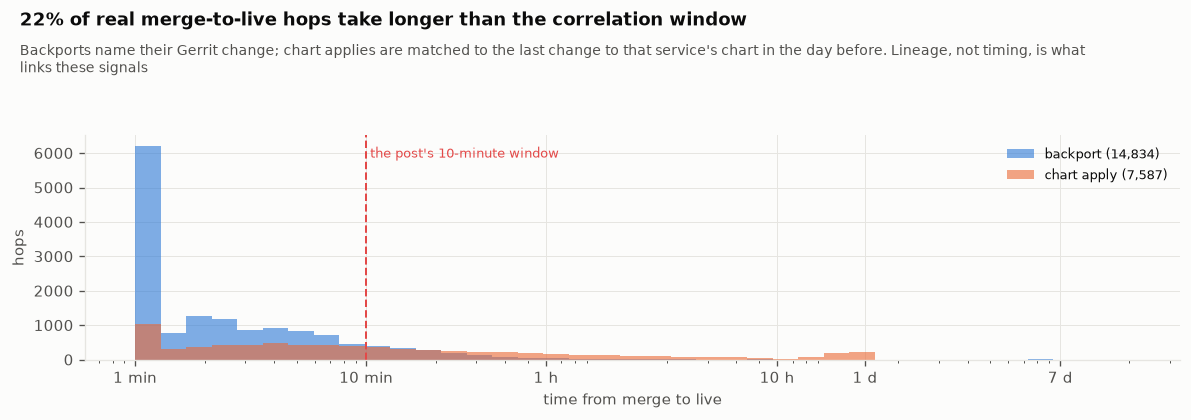

In [136]:
# ---- merge to live, drawn ----
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.logspace(0, np.log10(14 * 1440), 40)
for (name, gaps), colour in zip(LINEAGE.items(), (C1, C2)):
    if len(gaps):
        ax.hist(np.clip(gaps, 1, None), bins=bins, color=colour, alpha=0.6, label=f"{name} ({len(gaps):,})")
ax.axvline(10, color=C8, ls="--", lw=1.2)
ax.text(10, ax.get_ylim()[1] * 0.95, " the post's 10-minute window", color=C8, fontsize=8, va="top")
ax.set_xscale("log")
ax.set_xticks([1, 10, 60, 600, 1440, 10080], ["1 min", "10 min", "1 h", "10 h", "1 d", "7 d"])
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("time from merge to live")
ax.set_ylabel("hops")
ax.legend(fontsize=8)
finish(fig, "lineage_gaps",
       f"{(over > 10).mean():.0%} of real merge-to-live hops take longer than the correlation window",
       "Backports name their Gerrit change; chart applies are matched to the last change to that service's chart in the "
       "day before. Lineage, not timing, is what links these signals")

  283,743 changes over 285 weeks; by kind: maintenance 85,157, capacity 81,772, deploy 71,072, config 24,348, other 21,394


[fig] artifacts\figures_full\changes_by_kind.png


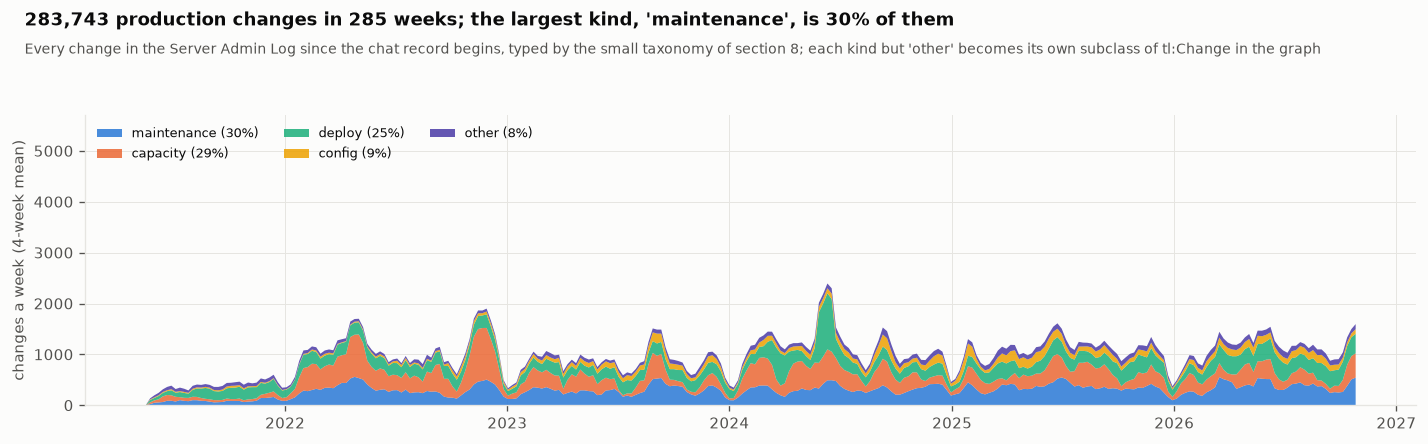

In [137]:
# ---- five years of production changes by kind, drawn: what the change enricher has to type ----
weekly_kind = (CHANGES.assign(week=CHANGES.ts.dt.tz_localize(None).dt.to_period("W").dt.start_time)
               .groupby(["week", "kind"]).size().unstack(fill_value=0))
order_k = weekly_kind.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(weekly_kind.index, *[weekly_kind[k].rolling(4, min_periods=1).mean() for k in order_k],
             labels=[f"{k} ({weekly_kind[k].sum() / weekly_kind.values.sum():.0%})" for k in order_k],
             colors=[C1, C2, C3, C4, C7, MUTED][:len(order_k)], alpha=0.85)
ax.set_ylabel("changes a week (4-week mean)")
ax.legend(fontsize=7.5, loc="upper left", ncols=3)
ax.set_ylim(0, weekly_kind.sum(axis=1).max() * 1.35)
top_kind = order_k[0]
print(f"  {len(CHANGES):,} changes over {len(weekly_kind)} weeks; by kind: " +
      ", ".join(f"{k} {weekly_kind[k].sum():,}" for k in order_k))
finish(fig, "changes_by_kind", f"{len(CHANGES):,} production changes in {len(weekly_kind)} weeks; the largest kind, "
       f"'{top_kind}', is {weekly_kind[top_kind].sum() / weekly_kind.values.sum():.0%} of them",
       "Every change in the Server Admin Log since the chat record begins, typed by the small taxonomy of section 8; "
       "each kind but 'other' becomes its own subclass of tl:Change in the graph")

In [138]:
# ---- the lineage enricher: code changes, deploys, and the 'includes' edge between them ----
GRAPH_FROM = NOW - pd.Timedelta(days=180)
INCIDENT_WINDOWS = [(t - pd.Timedelta(hours=6), t + pd.Timedelta(hours=2)) for t in inc_w.start]


def in_graph_scope(ts: pd.Series, since: pd.Timestamp | None = None) -> pd.Series:
    """The graph keeps a recent stretch (180 days unless said otherwise) and the hours around every incident,
    not five years of everything."""
    keep = ts >= (since if since is not None else GRAPH_FROM)
    for a, b in INCIDENT_WINDOWS:
        keep |= (ts >= a) & (ts < b)
    return keep


class ChangesAndLineage(Enricher):
    name, requires, produces, source = "changes-lineage", (OPS.Host,), (TL.Change, CODE.Change), "SAL + Gerrit"

    def fetch(self, start, end):
        return CHANGES[in_graph_scope(CHANGES.ts)]

    def analyse(self, rows, start, end):
        g = rdflib.Graph()
        for _, r in rows.iterrows():
            node = mint("wikimedia", "change", f"{r.ts:%Y%m%dT%H%M%S}-{hashlib.sha256(r.message.encode()).hexdigest()[:8]}")
            hosts = [h for h in hosts_in(r.message) if resolve_host(h)["role_from"] == "catalogue"]
            signal(g, node, KIND_CLASS[r.kind], r.ts, r.ts, hosts[0] if hosts else None)
            g.add((node, TL.message, Literal(SCRUB(r.message)[:240])))
            for n in r.refs:
                if n in merge_time.index:
                    code = mint("wikimedia", "code-change", str(n))
                    g.add((code, RDF.type, CODE.Change))
                    g.add((code, CODE.number, Literal(int(n), datatype=XSD.integer)))
                    g.add((code, CORR.at, dt_literal(merge_time[n])))
                    g.add((code, CORR.detectedAt, dt_literal(merge_time[n])))
                    g.add((code, CORR.inHour, hour_node(merge_time[n])))
                    g.add((node, TL.includes, code))
        return g


LINEAGE_RUN = run_pipeline([ChangesAndLineage()], GRAPH_FROM, NOW, KG, "wikimedia", BUILD)
n_incl = KG.ask("SELECT (COUNT(*) AS ?n) WHERE { ?d tl:includes ?c }")[0]["n"].value
print(f"\n  deploys linked to the code change they ship: {int(n_incl):,} 'includes' edges")

  enricher          facts  coverage  valid   secs  note
  --------------------------------------------------------------------------------------------


  changes-lineage 238,962        ok    yes  35.04  

  deploys linked to the code change they ship: 2,448 'includes' edges


**Lineage is ordinary, and so are hops longer than the window: 22% of real merge-to-live hops take
more than ten minutes.** Backports are fast, a median of 2 minutes from merge to production over
14,834 measured hops. Configuration changes to Kubernetes services are slower and far more spread out:
a median of 7 minutes over 7,587 hops, and 43% take longer than the post's ten-minute window,
some of them most of a day. A correlation engine that links signals by time alone would drop one
hop in five of exactly the kind Figure 7 starts with. The fix is the one the post implies and
does not spell out: when the graph knows that a deploy shipped a change, that link holds whatever
the clock says, and section 26's engine treats it so.

## 18 · Alerts and the users: from streams of lines to episodes

**Theory.** An alert line is not a signal; an alert episode is. A flapping check can fire and
resolve forty times in an afternoon, and forty firings of one problem would outvote every other
signal in any engine that counts. The post's Alerts Ontology makes the same move: a firing is a
typed thing with a rule, a target and a lifetime, not a line of text. We group lines into
episodes by rule and target, close an episode when it resolves or goes quiet for half an hour,
and keep the number of flaps as a property instead of as duplicate facts. The users layer gets
the same treatment: an hour of unusual pageviews on one wiki is a reading; a run of them, measured
against the same hours in the weeks before (never after, so nothing leaks from the future), is a
traffic shift. Metric anomalies for Wikimedia come only from this layer: its infrastructure
metrics are public for fifteen days, too short for the incidents we test, and we say so rather
than pretend. Worlds: Wikimedia.

In [139]:
# ---- alert lines into episodes: one rule on one target, open until resolved or quiet for 30 minutes ----
def alert_lines() -> pd.DataFrame:
    """Both alert routes in one table: (time, status, rule, target host, route)."""
    rows = []
    chat = IRC[IRC.nick.isin(["jinxer-wm", "icinga-wm"])]
    for t, n, x in zip(chat.ts, chat.nick, chat.text):
        a = chat_alert(n, x)
        if a:
            hosts = hosts_in(x)
            rows.append((t, a[0], a[1], hosts[0] if hosts else "", "chat"))
    for t, line in zip(ALERTS_LOKI.ts, ALERTS_LOKI.line):
        m = LOKI_LINE.match(line)
        if m:
            hosts = hosts_in(line)
            rows.append((t, m.group(1), m.group(2), hosts[0] if hosts else "", "loki"))
    return pd.DataFrame(rows, columns=["ts", "status", "rule", "host", "route"]).sort_values("ts", ignore_index=True)


def episodes_of(lines: pd.DataFrame, quiet_min: int = 30) -> pd.DataFrame:
    out = []
    for (route, rule, host), g in lines.groupby(["route", "rule", "host"], sort=False):
        start = last = None
        flaps = 0
        for t, status in zip(g.ts, g.status):
            if status == "firing":
                if start is not None and (t - last).total_seconds() > quiet_min * 60:
                    out.append((route, rule, host, start, last + pd.Timedelta(minutes=5), flaps, "quiet"))
                    start = None
                if start is None:
                    start, flaps = t, 0
                flaps += 1
                last = t
            elif start is not None:                       # resolved
                out.append((route, rule, host, start, t, flaps, "resolved"))
                start = None
        if start is not None:
            out.append((route, rule, host, start, last + pd.Timedelta(minutes=5), flaps, "quiet"))
    return pd.DataFrame(out, columns=["route", "rule", "host", "start", "end", "firings", "closed_by"])


episodes_file = RES_DIR / "alert_episodes.parquet"
if episodes_file.exists() and not RECOMPUTE:
    EPISODES = pd.read_parquet(episodes_file)
    print(f"  [cache] {episodes_file.name}")
else:
    t0 = time.perf_counter()
    LINES = alert_lines()
    EPISODES = episodes_of(LINES)
    save_parquet(EPISODES, episodes_file)
    print(f"  {len(LINES):,} alert lines -> {len(EPISODES):,} episodes in {time.perf_counter() - t0:.0f}s")
for route, g in EPISODES.groupby("route"):
    dur = (g.end - g.start).dt.total_seconds() / 60
    print(f"  {route:<5} {len(g):>9,} episodes   {g.firings.sum():>10,} firings   flapping (5+ firings) "
          f"{(g.firings >= 5).mean():5.1%}   median length {dur.median():5.0f} min   on a known host "
          f"{(g.host != '').mean():.0%}")
worst = EPISODES.sort_values("firings", ascending=False).iloc[0]
print(f"\n  the noisiest episode: '{worst.rule}' on {worst.host or 'no host'}, {worst.firings} firings between "
      f"{worst.start:%Y-%m-%d %H:%M} and {worst.end:%H:%M}: one fact in the graph, not {worst.firings}")

  [cache] alert_episodes.parquet
  chat    131,959 episodes      156,454 firings   flapping (5+ firings)  1.0%   median length     5 min   on a known host 63%
  loki    248,578 episodes    1,330,456 firings   flapping (5+ firings) 20.8%   median length     5 min   on a known host 37%



  the noisiest episode: 'KubeletOperationalLatency' on no host, 2130 firings between 2026-07-06 06:54 and 06:59: one fact in the graph, not 2130


In [140]:
# ---- the users layer as signals: runs of unusual hours, judged only against the past ----
def traffic_shifts(min_ratio: float = 0.15, weeks: int = 4) -> pd.DataFrame:
    rows = []
    for project, g in TRAFFIC.groupby("project"):
        s = g.set_index("ts").views.asfreq("h")
        base = pd.concat([s.shift(24 * 7 * k) for k in range(1, weeks + 1)], axis=1).median(axis=1)
        ratio = s / base
        flag = (ratio - 1).abs() >= min_ratio
        run_id = (flag != flag.shift()).cumsum()
        for _, block in ratio[flag].groupby(run_id[flag]):
            rows.append((project, block.index[0], block.index[-1] + pd.Timedelta(hours=1), len(block),
                         float(block.iloc[(block - 1).abs().argmax()])))
    out = pd.DataFrame(rows, columns=["project", "start", "end", "hours", "ratio"])
    return out.assign(start=pd.to_datetime(out.start, utc=True), end=pd.to_datetime(out.end, utc=True))


SHIFTS = traffic_shifts()
if len(SHIFTS):
    print(f"  {len(SHIFTS):,} traffic shifts across {SHIFTS.project.nunique()} projects "
          f"({(SHIFTS.ratio < 1).mean():.0%} dips, {(SHIFTS.ratio > 1).mean():.0%} surges); median length "
          f"{SHIFTS.hours.median():.0f} h")
else:
    print("  no traffic shifts: this profile has less than the four weeks of history a baseline needs")
if FLAG_T is not None:
    near = SHIFTS[(SHIFTS.start <= FLAG_T + pd.Timedelta(hours=3)) & (SHIFTS.end >= FLAG_T - pd.Timedelta(hours=1))]
    print(f"  around the incident we follow: {len(near)} shift(s): " +
          ", ".join(f"{r.project} x{r.ratio:.2f} from {r.start:%H:%M}" for _, r in near.iterrows()))

  19,777 traffic shifts across 12 projects (40% dips, 60% surges); median length 2 h
  around the incident we follow: 1 shift(s): www.wikidata x0.66 from 10:00


In [141]:
# ---- the enricher: episodes and shifts become typed signals, inside the graph's scope ----
class AlertsAndUsers(Enricher):
    name, requires, produces, source = "alerts-users", (OPS.Host,), (ALERT.Firing, USERS.TrafficShift), "chat + Loki + AQS"

    def fetch(self, start, end):
        # alerts are by far the loudest stream: the graph keeps the last 30 days of them, plus every incident window
        return (EPISODES[in_graph_scope(EPISODES.start, since=NOW - pd.Timedelta(days=30))],
                SHIFTS[in_graph_scope(SHIFTS.start)])

    def analyse(self, raw, start, end):
        eps, shifts = raw
        g = rdflib.Graph()
        for _, e in eps.iterrows():
            node = mint("wikimedia", "firing", f"{e.route}-{e.start:%Y%m%dT%H%M%S}-{slug(e.rule)}-{e.host}")
            known = e.host and resolve_host(e.host)["role_from"] == "catalogue"
            signal(g, node, ALERT.Firing, e.start, e.start, e.host if known else None)
            rule = mint("wikimedia", "alert-rule", e.rule)
            g.add((rule, RDF.type, ALERT.Rule))
            g.add((node, ALERT.ofRule, rule))
            g.add((node, ALERT.resolvedAt, dt_literal(e.end)))
            g.add((node, ALERT.source, Literal(e.route)))
        for _, s in shifts.iterrows():
            node = mint("wikimedia", "traffic-shift", f"{s.project}-{s.start:%Y%m%dT%H}")
            signal(g, node, USERS.TrafficShift, s.start, s.start + pd.Timedelta(hours=1))   # known once the hour closes
            g.add((node, USERS.project, Literal(s.project)))
            g.add((node, USERS.ratio, Literal(round(s.ratio, 4), datatype=XSD.decimal)))
        return g


ALERT_RUN = run_pipeline([AlertsAndUsers()], GRAPH_FROM, NOW, KG, "wikimedia", BUILD)

  enricher          facts  coverage  valid   secs  note
  --------------------------------------------------------------------------------------------


  alerts-users    369,516        ok    yes  39.33  


[fig] artifacts\figures_full\alerts_users.png


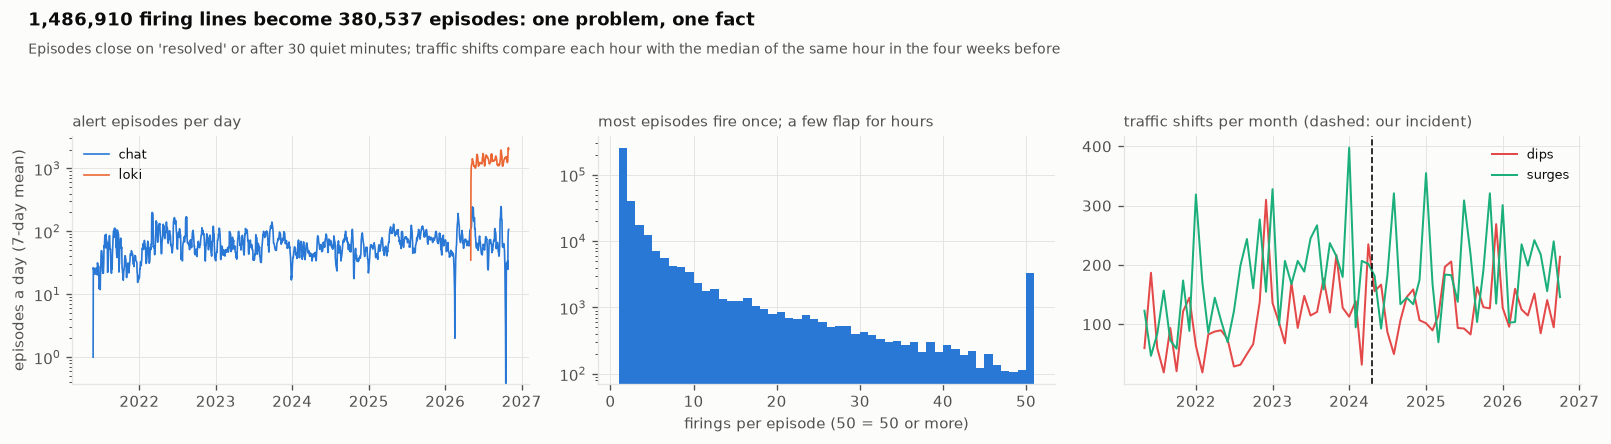

In [142]:
# ---- alerts and users, drawn ----
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for (route, g), colour in zip(EPISODES.groupby("route"), (C1, C2)):
    per_day = g.set_index("start").resample("D").size()
    axes[0].plot(per_day.index, per_day.rolling(7, min_periods=1).mean(), color=colour, lw=1, label=route)
axes[0].set_yscale("log")
axes[0].set_ylabel("episodes a day (7-day mean)")
axes[0].legend(fontsize=7.5)
axes[0].set_title("alert episodes per day", fontsize=9, color=INK2, loc="left")
fl = EPISODES.firings.clip(upper=50)
axes[1].hist(fl, bins=np.arange(1, 52), color=C1)
axes[1].set_yscale("log")
axes[1].set_xlabel("firings per episode (50 = 50 or more)")
axes[1].set_title("most episodes fire once; a few flap for hours", fontsize=9, color=INK2, loc="left")
monthly = SHIFTS.assign(m=SHIFTS.start.dt.tz_localize(None).dt.to_period("M").dt.to_timestamp(),
                        kind=np.where(SHIFTS.ratio < 1, "dip", "surge")).groupby(["m", "kind"]).size().unstack(fill_value=0)
for kind, colour in (("dip", C8), ("surge", C3)):
    if kind in monthly:
        axes[2].plot(monthly.index, monthly[kind], color=colour, lw=1.2, label=f"{kind}s")
if FLAG_T is not None and len(monthly):
    axes[2].axvline(FLAG_T.tz_localize(None), color=INK, ls="--", lw=1)
if len(monthly):
    axes[2].legend(fontsize=7.5)
axes[2].set_title("traffic shifts per month (dashed: our incident)", fontsize=9, color=INK2, loc="left")
lines_total = int(EPISODES.firings.sum())
finish(fig, "alerts_users",
       f"{lines_total:,} firing lines become {len(EPISODES):,} episodes: one problem, one fact",
       "Episodes close on 'resolved' or after 30 quiet minutes; traffic shifts compare each hour with the median of the "
       "same hour in the four weeks before")

**1,486,910 alert firings become 380,537 episodes, and the graph stores the episode, not the
firing.** Two routes carry Wikimedia's alerts: the chat bots since 2021 (156,454 firings, 131,959
episodes) and Loki since May 2026 (1,330,456 firings, 248,578 episodes). An episode is one rule
on one target, open until it resolves or stays quiet for 30 minutes, so the noisiest one on
record, 'KubeletOperationalLatency' firing 2,130 times in five minutes, is one fact and not
2,130. Flapping is what separates the routes: one Loki episode in five fires five times or
more, against one in a hundred in the chat. 63% of chat episodes and 37% of Loki episodes name
a host the catalogue knows, which is section 11's identity gap seen from the alerting side. The
users layer turns the hourly traffic of 12 projects into 19,777 shifts, runs of unusual hours
judged only against the four weeks before them, 40% of them dips. Around the incident we follow
there is exactly one: Wikidata at 0.66 of its usual traffic from 10:00. Episodes and shifts
enter the graph as 369,516 typed facts, and every delta passes the shapes.

## 19 · Incidents: lifecycle, roles, and the four hours, measured

**Theory.** Incidents are what every other signal is trying to explain, and the reports about
them are written afterwards. The incident enricher turns a report into a typed incident: when
readers were first affected and when they stopped being affected, how and when it was noticed,
which components it touched, who coordinated, and every entry of its timeline. All of it goes
into a graph dated by when the report was first saved, so section 14's as-of rule keeps it away
from any agent investigating the incident itself. Two measurements come out of the same parse.
The post's Figure 3 shows a four-hour incident whose largest block is getting the right people
involved; Wikimedia's timelines let us measure the real shape of that time. And its Figure 5
turns a 200-message, 50-person, 15-service channel into structure; we count the same things for
the incident we follow. World: Wikimedia.

In [143]:
# ---- the whole scorecard, and when each report was first written ----
def scorecard(title: str) -> dict:
    m = SCORECARD.search(wikitext(title))
    return {k.strip().lower(): v.strip() for k, v in re.findall(r"\|\s*([\w-]+)\s*=\s*([^|\n]*)", m.group(1))} if m else {}


def first_number(text: str) -> float:
    m = re.search(r"\d+", text or "")
    return float(m.group(0)) if m else np.nan


cards_file = RES_DIR / "incident_cards.parquet"
if cards_file.exists() and not RECOMPUTE:
    CARDS = pd.read_parquet(cards_file)
    print(f"  [cache] {cards_file.name}")
else:
    rows = []
    for _, r in inc_w.iterrows():
        c = scorecard(r["id"])
        rows.append({"id": r["id"], "start": r["start"], "coordinators": c.get("coordinators", ""),
                     "responders": first_number(c.get("responders-num")), "paged": first_number(c.get("paged-num")),
                     "end_raw": c.get("end", ""), "metrics": c.get("metrics", ""), "written": report_created(r["id"])})
    CARDS = pd.DataFrame(rows, columns=["id", "start", "coordinators", "responders", "paged", "end_raw", "metrics",
                                        "written"])
    save_parquet(CARDS, cards_file)
CARDS["written"] = pd.to_datetime(CARDS.written, utc=True)
CARDS["start"] = pd.to_datetime(CARDS.start, utc=True)
if len(CARDS):
    lag = (CARDS.written - CARDS.start).dt.total_seconds() / 86400
    print(f"  {len(CARDS)} incidents; scorecards naming a coordinator: "
          f"{(~CARDS.coordinators.isin(['', '0', '-'])).mean():.0%}; median responders {CARDS.responders.median():.0f}, "
          f"median people paged {CARDS.paged.median():.0f}")
    print(f"  reports first saved a median of {lag.median():.1f} days after impact began (10% within "
          f"{lag.quantile(0.1) * 24:.0f} hours, 10% after {lag.quantile(0.9):.0f} days)")
    for c in CARDS.coordinators[~CARDS.coordinators.isin(["", "0", "-"])].head(3):
        print(f"    coordinator field '{SCRUB(c)}'")
else:
    print("  [skip] no incidents inside this profile's chat window")

  [cache] incident_cards.parquet
  146 incidents; scorecards naming a coordinator: 80%; median responders 4, median people paged 1
  reports first saved a median of 2.8 days after impact began (10% within 2 hours, 10% after 24 days)
    coordinator field 'eng-65aff'
    coordinator field 'eng-3dac0'
    coordinator field 'eng-1714c'


In [144]:
# ---- the lifecycle from the timeline: when it was noticed, understood, mitigated and over ----
STAGES = {"detected": r"\b(?:paged|pages? (?:sent|went)|alert(?:ed|s)? fir|FIRING|noticed|reported|detected)",
          "cause found": r"(?:root cause|identified|culprit|caused by|found that|the cause)",
          "mitigated": r"(?:mitigat|roll(?:ed)?[ -]?back|revert|depool|fail(?:ed)? ?over|restarted)",
          "resolved": r"(?:resolved|recovered|outage ends|end of (?:user )?impact|back to normal|all clear)"}


def lifecycle(start: pd.Timestamp, timeline) -> dict:
    """Minutes from impact start to the first timeline entry of each stage (entries before the start count as 0)."""
    out = {}
    for stage, pat in STAGES.items():
        hits = [pd.Timestamp(t) for t, s in timeline if re.search(pat, s, re.I)]
        if hits:
            out[stage] = max(0.0, (min(hits) - start).total_seconds() / 60)
    return out


LIFE = pd.DataFrame([{"id": r["id"], **lifecycle(r["start"], r["timeline"])}
                     for _, r in inc_w.iterrows() if len(r["timeline"])])
LIFE = LIFE[[c for c in ["id", *STAGES] if c in LIFE]]
print(f"  {len(LIFE)} incidents with a timed timeline")
print(f"  {'stage':<14}{'have it':>9}{'median':>10}{'p75':>10}{'p90':>10}")
for stage in STAGES:
    if stage in LIFE:
        v = LIFE[stage].dropna()
        print(f"  {stage:<14}{len(v):>9}{v.median():>9.0f}m{v.quantile(0.75):>9.0f}m{v.quantile(0.9):>9.0f}m")
both = LIFE.dropna(subset=["detected", "resolved"]) if {"detected", "resolved"} <= set(LIFE) else LIFE.iloc[:0]
if len(both):
    print(f"\n  where both are recorded ({len(both)} incidents): detection to resolution, median "
          f"{(both.resolved - both.detected).median():.0f} minutes; the post's example took about four hours")

  89 incidents with a timed timeline
  stage           have it    median       p75       p90
  detected             30        2m        5m      127m
  cause found          22       62m      904m     3966m
  mitigated            44       25m      320m     3539m
  resolved             64       40m      341m     4485m

  where both are recorded (19 incidents): detection to resolution, median 35 minutes; the post's example took about four hours


[fig] artifacts\figures_full\four_hours_measured.png


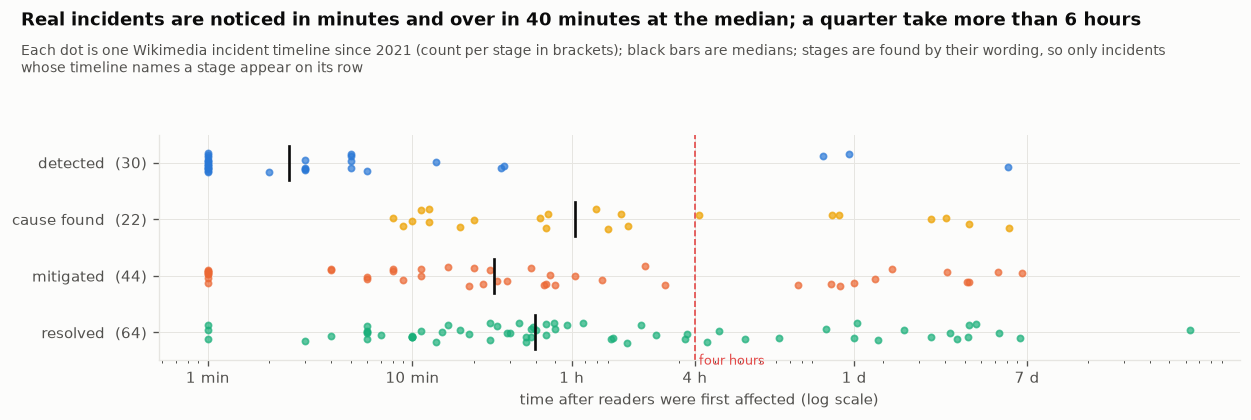

In [145]:
# ---- the four hours, drawn: where real incidents spend their time ----
def draw_four_hours() -> None:
    fig, ax = plt.subplots(figsize=(10.5, 3.6))
    for i, (stage, colour) in enumerate(zip(STAGES, (C1, C4, C2, C3))):
        if stage in LIFE:
            v = LIFE[stage].dropna().clip(lower=1)
            ax.scatter(v, np.full(len(v), i) + np.random.default_rng(SEED + i).uniform(-0.18, 0.18, len(v)),
                       s=14, color=colour, alpha=0.7)
            ax.plot([v.median()] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.6)
    ax.axvline(240, color=C8, ls="--", lw=1)
    ax.text(240, len(STAGES) - 0.5, " four hours", color=C8, fontsize=8, va="center")
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 60, 240, 1440, 10080], ["1 min", "10 min", "1 h", "4 h", "1 d", "7 d"])
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_yticks(range(len(STAGES)), [f"{s}  ({LIFE[s].notna().sum() if s in LIFE else 0})" for s in STAGES])
    ax.invert_yaxis()
    ax.set_xlabel("time after readers were first affected (log scale)")
    med_res = LIFE["resolved"].median()
    finish(fig, "four_hours_measured",
           f"Real incidents are noticed in minutes and over in {med_res:.0f} minutes at the median; a quarter take "
           f"more than {LIFE['resolved'].quantile(0.75) / 60:.0f} hours",
           "Each dot is one Wikimedia incident timeline since 2021 (count per stage in brackets); black bars are "
           "medians; stages are found by their wording, so only incidents whose timeline names a stage appear on its row")


if "resolved" in LIFE:
    draw_four_hours()
else:
    print("  [skip] no timed timelines in this profile")

In [146]:
# ---- the incident enricher: everything in the report, dated by when the report was written ----
COMMON_WORD_SERVICES = {"inference", "search", "proton", "apt", "echostore"}    # catalogue names that are also words


def affected(text: str) -> list[URIRef]:
    """Hosts the catalogue knows and catalogue services, named in the report's own summary and conclusions."""
    low = (text or "").lower()
    out = {mint("wikimedia", "host", h) for h in hosts_in(low) if resolve_host(h)["role_from"] == "catalogue"}
    words = set(SERVICE_LIKE.findall(low)) | {w for w in re.findall(r"\b[a-z]{5,}\b", low) if w not in COMMON_WORD_SERVICES}
    for tok in words:
        svc = resolve_service(tok, cutoff=100)[0]
        svc = CANONICAL.get(svc, svc)
        if svc in CATALOGUED:                       # an alias two services share names neither of them
            out.add(mint("wikimedia", "application", svc))
    return sorted(out)


class IncidentReports(Enricher):
    name, requires, produces, source = ("incident-reports", (OPS.Host, OPS.Application), (OPS.Incident,),
                                        "wikitech incident reports")

    def fetch(self, start, end):
        return inc_w.merge(CARDS[["id", "coordinators", "written"]], on="id")

    def analyse(self, rows, start, end):
        g = rdflib.Graph()
        for _, r in rows.iterrows():
            inc = mint("wikimedia", "incident", r["id"])
            written = r["written"] if pd.notna(r["written"]) else r["start"] + pd.Timedelta(days=1)
            signal(g, inc, OPS.Incident, r["start"], written)
            g.add((inc, INCIDENT.startedAt, dt_literal(r["start"])))
            g.add((inc, INCIDENT.impact, Literal(SCRUB(r["impact"] or "")[:300])))
            for c in affected(f"{r['summary']} {r['conclusions']}"):
                g.add((inc, OPS.affects, c))
            coord = r["coordinators"]
            if coord and coord not in ("0", "-"):
                person = mint("wikimedia", "person", SCRUB(coord).split(",")[0].strip())
                g.add((person, RDF.type, OPS.Person))
                g.add((inc, INCIDENT.coordinator, person))
            for i, (t, s) in enumerate(r["timeline"]):
                e = mint("wikimedia", "timeline-entry", f"{r['id']}-{i:03d}")
                g.add((e, RDF.type, INCIDENT.TimelineEntry))
                g.add((e, INCIDENT.entryAt, dt_literal(t)))
                g.add((e, INCIDENT.entryText, Literal(SCRUB(re.sub(r"<[^>]+>", "", s))[:300])))
                g.add((inc, INCIDENT.hasEntry, e))
        return g


INCIDENT_RUN = run_pipeline([IncidentReports()], CHAT_START, NOW, KG, "wikimedia-reports", BUILD)
aff = KG.ask("SELECT (COUNT(DISTINCT ?i) AS ?n) (COUNT(?c) AS ?links) WHERE { ?i a ops:Incident ; ops:affects ?c }")[0]
print(f"\n  incidents naming at least one catalogued component: {int(aff['n'].value)} of {len(inc_w)}; "
      f"{int(aff['links'].value)} 'affects' links in all")

  enricher          facts  coverage  valid   secs  note
  --------------------------------------------------------------------------------------------


  incident-reports  6,250        ok    yes   0.81  

  incidents naming at least one catalogued component: 60 of 146; 101 'affects' links in all


  Incidents/2024-04-17 mw-on-k8s eqiad outage: the 30 minutes before impact and the 4 hours after
    messages           682
    from people        320
    people              23
    hosts named          5
    services named       3
    alert episodes      22
    changes logged      77
  the post's channel: 200 messages, 50 people, 15 services; ours: 320 human messages, 23 people, 8 components named


[fig] artifacts\figures_full\incident_channel.png


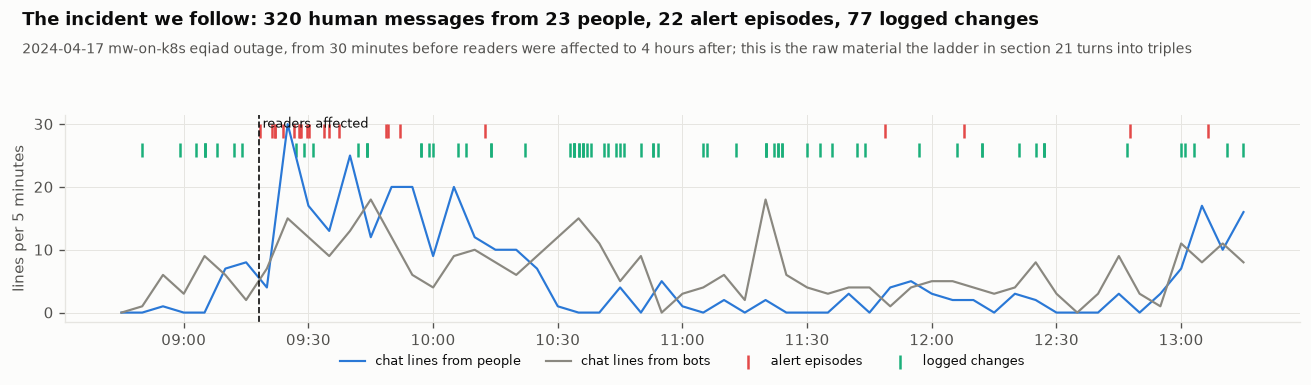

In [147]:
# ---- figure 5, for the incident we follow: a channel becomes structure ----
if FLAGSHIP is not None:
    lo, hi = FLAG_T - pd.Timedelta(minutes=30), FLAG_T + pd.Timedelta(hours=4)
    chat = IRC[(IRC.ts >= lo) & (IRC.ts < hi)]
    humans = chat[~chat.bot]
    mentioned_hosts = {h for t in humans.text for h in hosts_in(t)}
    mentioned_svcs = {s for t in humans.text for tok in SERVICE_LIKE.findall(t.lower())
                      if (s := resolve_service(tok, cutoff=100)[0])}
    FIG5 = {"messages": len(chat), "from people": len(humans), "people": humans.nick.nunique(),
            "hosts named": len(mentioned_hosts), "services named": len(mentioned_svcs),
            "alert episodes": int(((EPISODES.start >= lo) & (EPISODES.start < hi)).sum()),
            "changes logged": int(((CHANGES.ts >= lo) & (CHANGES.ts < hi)).sum())}
    print(f"  {FLAGSHIP['id']}: the 30 minutes before impact and the 4 hours after")
    for k, v in FIG5.items():
        print(f"    {k:<16}{v:>6,}")
    print(f"  the post's channel: 200 messages, 50 people, 15 services; ours: {FIG5['from people']} human messages, "
          f"{FIG5['people']} people, {FIG5['services named'] + FIG5['hosts named']} components named")
    fig, ax = plt.subplots(figsize=(11, 3.4))
    bins = pd.date_range(lo.floor("5min"), hi, freq="5min")       # resample() labels bins on the clock, so must we
    for label, sub, colour in (("people", humans, C1), ("bots", chat[chat.bot], MUTED)):
        counts = sub.set_index("ts").resample("5min").size().reindex(bins, fill_value=0)
        ax.plot(counts.index, counts.values, color=colour, lw=1.3, label=f"chat lines from {label}")
    eps = EPISODES[(EPISODES.start >= lo) & (EPISODES.start < hi)]
    chg = CHANGES[(CHANGES.ts >= lo) & (CHANGES.ts < hi)]
    top = ax.get_ylim()[1]
    ax.scatter(eps.start, np.full(len(eps), top * 0.92), marker="|", s=80, color=C8, label="alert episodes")
    ax.scatter(chg.ts, np.full(len(chg), top * 0.82), marker="|", s=80, color=C3, label="logged changes")
    ax.axvline(FLAG_T, color=INK, ls="--", lw=1)
    ax.text(FLAG_T, top * 0.99, " readers affected", fontsize=8, va="top")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_ylabel("lines per 5 minutes")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=4, frameon=False)
    finish(fig, "incident_channel",
           f"The incident we follow: {FIG5['from people']} human messages from {FIG5['people']} people, "
           f"{FIG5['alert episodes']} alert episodes, {FIG5['changes logged']} logged changes",
           f"{FLAGSHIP['id'].removeprefix('Incidents/')}, from 30 minutes before readers were affected to 4 hours after; "
           "this is the raw material the ladder in section 21 turns into triples")
else:
    print("  [skip] no incident to follow in this profile")

**Wikimedia's incidents are noticed in two minutes and over in forty at the median, but the
tail is long, and the reports that explain them arrive days later.** Of the 146 incidents in
the chat era, 89 have a timeline with times we can read, and each stage is found by its
wording: detection comes a median of 2 minutes after readers are first affected, mitigation at
25, resolution at 40, and the cause is found at 62, so at the median the fix comes before the
explanation. The tail is where the post's four hours live: a quarter of incidents take more than
341 minutes to resolve, and one in ten more than 4,485, over three days. Reports are first saved
a median of 2.8 days after impact, which is why every fact taken from a report is dated by when
it was written, not by when it happened. Scorecards name a coordinator in 80% of incidents, with
a median of four responders and one person paged. The incident enricher writes 6,250 facts, and
60 of the 146 incidents name at least one catalogued component, 101 'affects' links in all; it
took two fixes to get here, one in how deltas are checked (section 15) and one for catalogue
aliases. Figure 5's channel had 200 messages, 50 people and 15 services. Ours, from 30 minutes
before impact to four hours after, has 682 lines, 320 of them from 23 people, beside 22 alert
episodes, 77 logged changes and 8 components named: smaller than Netflix's example, and the
material that the ladder in section 21 turns into triples.

## 20 · Talking to Qwen and Claude without going broke

**Theory.** Every language-model call in this notebook costs money, and the two providers
bill differently. ModelScope charges a fixed number of Magicubes per Qwen call however long
the answer is, so the lever is the number of calls. Anthropic charges Claude by the token,
and Claude Opus 5.5 always thinks before it answers, so its hidden reasoning is billed as
output; the lever there is how hard we ask it to think. One client per provider handles the
rest the same way: a cap on calls in flight, retries with backoff, a disk cache so that a
second run of the notebook costs nothing, and a ledger that counts every call against the
phase budgets written down in section 0. The budgets are cumulative across runs, because the
money is: a call made last week still counts today.

In [148]:
# ---- the models, what each one is for, and what a call costs ----
QWEN = {
    "flash":  "Qwen-Ambassador/Qwen3.8-Flash-Next",   # bulk chat classification, specialist agents
    "mid":    "Qwen-Ambassador/Qwen3.8-27B",          # the middle tier in the model comparison and the 2x2
    "max":    "Qwen-Ambassador/Qwen3.8-Max",          # the reconciler that ranks hypotheses
    "omni":   "Qwen-Ambassador/Qwen3.8-Omni-Flash",   # reads Grafana screenshots
    "max37":  "Qwen-Ambassador/Qwen3.7-Max",          # independent label extractor
    "plus37": "Qwen-Ambassador/Qwen3.7-Plus",         # rule wording, previous-generation baseline
}
CLAUDE = "claude-opus-5-5"
CLAUDE_USD_PER_MTOK = {"input": 4.00, "output": 20.00}
# per-call prices: our previous measurements; Omni-Flash has never been priced, so it is counted at the high
# rate until a quiet-account measurement below says otherwise
QWEN_PRICE = {QWEN["flash"]: 0.2, QWEN["mid"]: 0.2, QWEN["plus37"]: 0.2, QWEN["max"]: 0.5, QWEN["max37"]: 0.5,
              QWEN["omni"]: 0.5}
PRICE_ASSUMED = {QWEN["omni"]}
print(f"  {'role':<8}{'model':<40}{'Magicubes per call':>20}")
print("  " + "-" * 68)
for role, m in QWEN.items():
    p = QWEN_PRICE[m]
    print(f"  {role:<8}{m:<40}{f'{p:.1f}' + (' (assumed)' if m in PRICE_ASSUMED else ''):>20}")
print(f"  {'judge':<8}{CLAUDE:<40}{'$4 in / $20 out per 1M tokens':>32}")

  role    model                                     Magicubes per call
  --------------------------------------------------------------------
  flash   Qwen-Ambassador/Qwen3.8-Flash-Next                       0.2
  mid     Qwen-Ambassador/Qwen3.8-27B                              0.2
  max     Qwen-Ambassador/Qwen3.8-Max                              0.5
  omni    Qwen-Ambassador/Qwen3.8-Omni-Flash             0.5 (assumed)
  max37   Qwen-Ambassador/Qwen3.7-Max                              0.5
  plus37  Qwen-Ambassador/Qwen3.7-Plus                             0.2
  judge   claude-opus-5-5                            $4 in / $20 out per 1M tokens


In [149]:
# ---- the ledger: every call ever made, kept on disk, so budgets survive reruns ----
LEDGER_FILE = ART / "llm_ledger.jsonl"
CACHE_DB = ART / "llm_cache.sqlite"


class BudgetExceeded(RuntimeError):
    pass


class Ledger:
    """Append-only record of live calls; spend per phase is the sum of what is on disk."""

    def __init__(self, path: Path):
        self.path, self._lock = path, threading.Lock()
        self.rows = [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines()] if path.exists() else []
        self.session: list[dict] = []          # this run only, cached replays included

    def add(self, row: dict):
        row = {"t": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), **row}
        with self._lock:
            self.session.append(row)
            if not row.get("cached"):
                self.rows.append(row)
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps(row) + "\n")

    def spent(self, provider: str, phase: str | None = None) -> float:
        return sum(r["cost"] for r in self.rows if r["provider"] == provider
                   and (phase is None or r["phase"] == phase) and not math.isnan(r["cost"]))


LEDGER = Ledger(LEDGER_FILE)
print(f"  ledger {LEDGER_FILE.relative_to(ROOT)}: {len(LEDGER.rows)} live calls on record, "
      f"{LEDGER.spent('qwen'):.1f} Magicubes and ${LEDGER.spent('claude'):.2f} spent so far")

  ledger artifacts\llm_ledger.jsonl: 3309 live calls on record, 733.1 Magicubes and $3.03 spent so far


In [150]:
# ---- the Magicube balance, read from the account itself ----
MS_KEY = (os.environ.get("MODELSCOPE_API_KEY")                      # read once, never printed
          or (KEY_DIR / "modelscope_api_key.txt").read_text(encoding="utf-8").strip())


def magicube_balance() -> float:
    r = httpx.get("https://modelscope.ai/openapi/v1/magicubes/balance",
                  headers={"Authorization": f"Bearer {MS_KEY}"}, timeout=30)
    r.raise_for_status()
    return float(r.json()["data"]["available_balance"])


BALANCE_AT_START = magicube_balance()
print(f"  available balance now: {BALANCE_AT_START:,.1f} Magicubes (this run's budget cap: {QWEN_BUDGET_CUBES})")

  available balance now: 414.2 Magicubes (this run's budget cap: 1200)


In [151]:
# ---- the Qwen client: a cap on calls in flight, retries, a disk cache and the ledger ----
import sqlite3
from contextlib import contextmanager


def parse_json_reply(text: str):
    """The first JSON object in a model reply, or None. A one-element list holding an object is unwrapped."""
    s = re.sub(r"^```(?:json)?\s*|\s*```$", "", (text or "").strip(), flags=re.S)
    try:
        obj = json.loads(s)
    except json.JSONDecodeError:
        m = re.search(r"(\{.*\}|\[.*\])", s, flags=re.S)
        if not m:
            return None
        try:
            obj = json.loads(m.group(1))
        except json.JSONDecodeError:
            return None
    if isinstance(obj, list) and len(obj) == 1 and isinstance(obj[0], dict):
        obj = obj[0]
    return obj


@dataclass
class LLMResult:
    ok: bool
    text: str
    data: object
    model: str
    agent: str
    latency_s: float          # live latency of the call that produced this answer, even when replayed from cache
    cached: bool
    cost: float
    attempts: int
    status: int | None
    error: str | None = None
    usage: dict | None = None
    tool_calls: list | None = None
    refused: bool = False


class CallCache:
    """One sqlite file shared by both providers; reads take the same lock as writes."""

    def __init__(self, path: Path):
        self._db = sqlite3.connect(str(path), check_same_thread=False)
        self._db.execute("CREATE TABLE IF NOT EXISTS calls (key TEXT PRIMARY KEY, provider TEXT, model TEXT, "
                         "response TEXT, latency_s REAL, created TEXT)")
        self._lock = threading.Lock()

    def get(self, key: str):
        with self._lock:
            return self._db.execute("SELECT response, latency_s FROM calls WHERE key = ?", (key,)).fetchone()

    def put(self, key: str, provider: str, model: str, response: dict, latency: float):
        with self._lock:
            self._db.execute("INSERT OR REPLACE INTO calls VALUES (?, ?, ?, ?, ?, ?)",
                             (key, provider, model, json.dumps(response), latency,
                              datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")))
            self._db.commit()


CACHE = CallCache(CACHE_DB)
CURRENT_PHASE = {"qwen": "API probes", "claude": "pilots"}


@contextmanager
def phase(name: str):
    """Charge every call inside the block to one budget line from section 0."""
    assert name in QWEN_PHASES or name in CLAUDE_PHASES, f"unknown phase {name}"
    saved = dict(CURRENT_PHASE)
    if name in QWEN_PHASES:
        CURRENT_PHASE["qwen"] = name
    if name in CLAUDE_PHASES:
        CURRENT_PHASE["claude"] = name
    try:
        yield
    finally:
        CURRENT_PHASE.update(saved)


class QwenClient:
    """OpenAI-compatible chat client for ModelScope, built for many agents calling at once."""

    API = "https://api-inference.modelscope.ai/v1"

    def __init__(self, max_inflight: int = 6, timeout: float = 180):
        self._http = httpx.Client(base_url=self.API, timeout=timeout, headers={"Authorization": f"Bearer {MS_KEY}"},
                                  limits=httpx.Limits(max_connections=max_inflight + 4))
        self._gate = threading.BoundedSemaphore(max_inflight)
        self._lock = threading.Lock()
        self.live = False        # True: skip the cache entirely (used when we measure run-to-run variation)

    def _guard(self, model: str):
        price = QWEN_PRICE.get(model, float("nan"))
        p = CURRENT_PHASE["qwen"]
        cost = 0.5 if math.isnan(price) else price           # an unknown price is assumed to be the high one
        if LEDGER.spent("qwen", p) + cost > QWEN_PHASES[p] or LEDGER.spent("qwen") + cost > QWEN_BUDGET_CUBES:
            raise BudgetExceeded(f"Qwen phase '{p}' would exceed its cap of {QWEN_PHASES[p]} Magicubes")

    def chat(self, model: str, messages: list[dict], *, agent: str = "misc", json_mode: bool = True,
             max_tokens: int = 800, temperature: float = 0.0, thinking: bool = False,
             tools: list | None = None, max_attempts: int = 6) -> LLMResult:
        body = {"model": model, "messages": messages, "max_tokens": max_tokens,
                "temperature": temperature, "enable_thinking": thinking}
        if json_mode:
            body["response_format"] = {"type": "json_object"}
        if tools:
            body["tools"] = tools
        key = "qwen:" + hashlib.sha256(json.dumps(body, sort_keys=True).encode()).hexdigest()
        if not self.live and (hit := CACHE.get(key)):
            res = self._result(json.loads(hit[0]), model, agent, json_mode, hit[1], True, 0.0, 0, 200)
            LEDGER.add({"provider": "qwen", "model": model, "phase": CURRENT_PHASE["qwen"], "agent": agent,
                        "cached": True, "ok": res.ok, "cost": 0.0, "latency_s": hit[1]})
            return res
        self._guard(model)
        status, payload, err, latency, attempts = None, {}, None, 0.0, 0
        with self._gate:
            for attempts in range(1, max_attempts + 1):
                t0 = time.perf_counter()
                try:
                    r = self._http.post("/chat/completions", json=body)
                    status = r.status_code
                except httpx.HTTPError as e:
                    status, err = None, type(e).__name__
                latency = time.perf_counter() - t0
                if status == 200:
                    payload = r.json()
                    break
                if status is not None and status != 429 and status < 500:
                    err = r.text[:300]
                    break                              # a 4xx other than 429 will not improve with retries
                time.sleep(min(30, 1.5 * 2 ** (attempts - 1)) * (0.75 + 0.5 * random.random()))
        cost = QWEN_PRICE.get(model, float("nan")) if status == 200 else 0.0    # every 200 is billed
        if status != 200:
            LEDGER.add({"provider": "qwen", "model": model, "phase": CURRENT_PHASE["qwen"], "agent": agent,
                        "cached": False, "ok": False, "cost": 0.0, "latency_s": latency, "status": status})
            return LLMResult(False, "", None, model, agent, latency, False, 0.0, attempts, status, err or f"HTTP {status}")
        res = self._result(payload, model, agent, json_mode, latency, False, cost, attempts, status)
        if res.ok and not self.live:
            CACHE.put(key, "qwen", model, payload, latency)
        usage = payload.get("usage") or {}
        LEDGER.add({"provider": "qwen", "model": model, "phase": CURRENT_PHASE["qwen"], "agent": agent,
                    "cached": False, "ok": res.ok, "cost": cost, "latency_s": round(latency, 3), "attempts": attempts,
                    "tokens_in": usage.get("prompt_tokens"), "tokens_out": usage.get("completion_tokens")})
        return res

    @staticmethod
    def _result(payload, model, agent, json_mode, latency, cached, cost, attempts, status) -> LLMResult:
        msg = ((payload.get("choices") or [{}])[0]).get("message", {})
        text = msg.get("content") or ""
        ok = bool(text.strip() or msg.get("tool_calls"))
        return LLMResult(ok, text, parse_json_reply(text) if json_mode else None, model, agent, latency, cached,
                         cost, attempts, status, None if ok else "empty reply", payload.get("usage"), msg.get("tool_calls"))


LLM = QwenClient()
print(f"  Qwen client ready: at most 6 calls in flight, cache {CACHE_DB.relative_to(ROOT)}")

  Qwen client ready: at most 6 calls in flight, cache artifacts\llm_cache.sqlite


In [152]:
# ---- the Claude client: same ledger and cache, priced by the token, with a hard stop ----
import anthropic

CLAUDE_KEY = os.environ.get("ANTHROPIC_API_KEY") or (KEY_DIR / "claude_api_key.txt").read_text(encoding="utf-8").strip()


class ClaudeClient:
    """Claude Opus 5.5 as an independent judge and extractor.

    The model always thinks, so `effort` is the cost dial; temperature is not accepted. Structured outputs
    guarantee valid JSON, a server-side fallback re-runs a refused request on another model, and a refusal
    that survives the fallback is reported, never parsed.
    """

    FALLBACK_BETA = "server-side-fallback-2026-07-01"

    def __init__(self, max_inflight: int = 4):
        self._c = anthropic.Anthropic(api_key=CLAUDE_KEY, max_retries=4, timeout=600)
        self._gate = threading.BoundedSemaphore(max_inflight)

    @staticmethod
    def usd(usage) -> float:
        return (usage.input_tokens * CLAUDE_USD_PER_MTOK["input"] + usage.output_tokens * CLAUDE_USD_PER_MTOK["output"]) / 1e6

    def _guard(self, system: str, messages: list[dict], max_tokens: int):
        p = CURRENT_PHASE["claude"]
        n_in = self._c.messages.count_tokens(model=CLAUDE, system=system, messages=messages).input_tokens
        worst = (n_in * CLAUDE_USD_PER_MTOK["input"] + max_tokens * CLAUDE_USD_PER_MTOK["output"]) / 1e6
        if LEDGER.spent("claude", p) + worst > CLAUDE_PHASES[p] or LEDGER.spent("claude") + worst > CLAUDE_BUDGET_USD:
            raise BudgetExceeded(f"Claude phase '{p}' could exceed its cap of ${CLAUDE_PHASES[p]:.2f}")

    def ask(self, system: str, user: str, *, agent: str = "judge", schema: dict | None = None,
            effort: str = "low", max_tokens: int = 4000) -> LLMResult:
        messages = [{"role": "user", "content": user}]
        output_config = {"effort": effort} | ({"format": {"type": "json_schema", "schema": schema}} if schema else {})
        req = {"model": CLAUDE, "max_tokens": max_tokens, "system": system, "messages": messages,
               "output_config": output_config}
        key = "claude:" + hashlib.sha256(json.dumps(req, sort_keys=True).encode()).hexdigest()
        if hit := CACHE.get(key):
            payload = json.loads(hit[0])
            LEDGER.add({"provider": "claude", "model": CLAUDE, "phase": CURRENT_PHASE["claude"], "agent": agent,
                        "cached": True, "ok": payload["ok"], "cost": 0.0, "latency_s": hit[1]})
            return LLMResult(payload["ok"], payload["text"], parse_json_reply(payload["text"]) if schema else None,
                             CLAUDE, agent, hit[1], True, 0.0, 0, 200, payload.get("error"), payload.get("usage"),
                             refused=payload.get("refused", False))
        self._guard(system, messages, max_tokens)
        with self._gate:
            t0 = time.perf_counter()
            resp = self._c.beta.messages.create(**req, betas=[self.FALLBACK_BETA], fallbacks="default")
            latency = time.perf_counter() - t0
        refused = resp.stop_reason == "refusal"
        text = "" if refused else "".join(b.text for b in resp.content if b.type == "text")
        cost = self.usd(resp.usage)
        usage = {"input_tokens": resp.usage.input_tokens, "output_tokens": resp.usage.output_tokens}
        payload = {"ok": bool(text) and not refused, "text": text, "refused": refused, "usage": usage,
                   "served_by": resp.model, "error": "refused" if refused else None}
        CACHE.put(key, "claude", CLAUDE, payload, latency)
        LEDGER.add({"provider": "claude", "model": resp.model, "phase": CURRENT_PHASE["claude"], "agent": agent,
                    "cached": False, "ok": payload["ok"], "cost": cost, "latency_s": round(latency, 3),
                    "tokens_in": usage["input_tokens"], "tokens_out": usage["output_tokens"], "refused": refused})
        return LLMResult(payload["ok"], text, parse_json_reply(text) if schema else None, resp.model, agent, latency,
                         False, cost, 1, 200, payload["error"], usage, refused=refused)


JUDGE = ClaudeClient()
print(f"  Claude client ready: {CLAUDE}, hard stop ${CLAUDE_BUDGET_USD:.0f}, "
      f"${LEDGER.spent('claude'):.2f} spent so far")

  Claude client ready: claude-opus-5-5, hard stop $35, $3.03 spent so far


In [153]:
# ---- what the APIs actually do, measured once: JSON mode, tool calls, bursts, Claude's output ----
probe_file = ART / "api_probes.json"            # facts about the APIs, not about one profile's run
if probe_file.exists() and not RECOMPUTE:
    PROBES = json.loads(probe_file.read_text())
    print(f"  [cache] {probe_file.name} (measured on {PROBES['when']})")
else:
    PROBES = {"when": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC"), "qwen": {}}
    LLM.live = True                                           # these must be real calls, not cache replays
    with phase("API probes"):
        for role, model in QWEN.items():
            replies = [LLM.chat(model, [{"role": "user", "content": f"Return JSON {{\"n\": {i}}} and nothing else."}],
                                agent="probe", max_tokens=40) for i in (1, 2)]
            PROBES["qwen"][role] = {"model": model, "json_ok": sum(r.data is not None for r in replies),
                                    "latency_s": round(float(np.mean([r.latency_s for r in replies])), 2)}
        tool = [{"type": "function", "function": {"name": "lookup_host", "description": "Find the cluster a host belongs to",
                 "parameters": {"type": "object", "properties": {"host": {"type": "string"}}, "required": ["host"]}}}]
        r = LLM.chat(QWEN["flash"], [{"role": "user", "content": "Which cluster runs db1127? Use the tool."}],
                     agent="probe", json_mode=False, tools=tool, max_tokens=200)
        PROBES["tool_calling"] = {"ok": r.ok, "tool_calls": r.tool_calls, "text": r.text[:200]}
        t0 = time.perf_counter()
        with ThreadPoolExecutor(8) as ex:
            burst = list(ex.map(lambda i: LLM.chat(QWEN["flash"], [{"role": "user", "content": f"Reply with {i}."}],
                                                   agent="burst", json_mode=False, max_tokens=8), range(8)))
        PROBES["burst8"] = {"ok": sum(b.ok for b in burst), "retried": sum(b.attempts > 1 for b in burst),
                            "wall_s": round(time.perf_counter() - t0, 2)}
    LLM.live = False
    with phase("pilots"):
        schema = {"type": "object", "additionalProperties": False, "required": ["category", "services"],
                  "properties": {"category": {"type": "string", "enum": ["incident", "question", "discussion", "decision"]},
                                 "services": {"type": "array", "items": {"type": "string"}}}}
        c = JUDGE.ask("You label messages from an on-call chat channel.",
                      "Message: 'db1127 is out to lunch, depooling it now, s7 errors climbing'. Label it.",
                      agent="probe", schema=schema, effort="low", max_tokens=1500)
        PROBES["claude"] = {"ok": c.ok, "data": c.data, "usage": c.usage, "cost_usd": round(c.cost, 5),
                            "latency_s": round(c.latency_s, 2), "served_by": c.model}
    probe_file.write_text(json.dumps(PROBES, indent=1, default=str))
print(f"  {'role':<8}{'JSON ok':>8}{'latency s':>11}")
print("  " + "-" * 27)
for role, p in PROBES["qwen"].items():
    print(f"  {role:<8}{p['json_ok']:>6}/2{p['latency_s']:>11}")
tc = PROBES["tool_calling"]
print(f"\n  native tool calling: {'YES' if tc['tool_calls'] else 'NO'} "
      f"({(tc['tool_calls'] or [{}])[0].get('function', {}) if tc['tool_calls'] else tc['text'][:80]})")
b = PROBES["burst8"]
print(f"  8 calls at once through the client: {b['ok']}/8 answered, {b['retried']} needed a retry, {b['wall_s']}s")
cl = PROBES["claude"]
print(f"  Claude structured output: ok={cl['ok']} {cl['data']}  tokens {cl['usage']}  "
      f"${cl['cost_usd']:.4f}  {cl['latency_s']}s  served by {cl['served_by']}")

  [cache] api_probes.json (measured on 2026-10-31 07:10 UTC)
  role     JSON ok  latency s
  ---------------------------
  flash        2/2       2.08
  mid          2/2       2.12
  max          2/2       1.09
  omni         2/2       1.07
  max37        2/2       1.54
  plus37       2/2       1.65

  native tool calling: YES ({'arguments': '{"host": "db1127"}', 'name': 'lookup_host'})
  8 calls at once through the client: 8/8 answered, 1 needed a retry, 6.28s
  Claude structured output: ok=True {'category': 'incident', 'services': ['db1127', 's7']}  tokens {'input_tokens': 318, 'output_tokens': 22}  $0.0017  2.55s  served by claude-opus-5-5


In [154]:
# ---- prices per call, measured only when nothing else is spending from the account ----
# Our first attempt read the balance before and after two calls and got 1 to 2 Magicubes per call, four to ten
# times the known prices. The balance was falling about 7 a minute with no calls from us: another program shared
# the account. So a measurement now starts by watching the balance for a minute, and only a quiet account counts.
price_file = ART / "api_prices.json"


def measure_prices(calls_per_model: int = 3, quiet_tolerance: float = 0.05) -> dict:
    b0 = magicube_balance()
    time.sleep(60)
    drift = b0 - magicube_balance()
    if abs(drift) > quiet_tolerance:
        return {"status": "skipped", "drift_per_min": round(drift, 2)}
    out = {"status": "measured", "when": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
           "per_call": {}}
    LLM.live = True
    with phase("API probes"):
        for role, model in QWEN.items():
            before = magicube_balance()
            for i in range(calls_per_model):
                LLM.chat(model, [{"role": "user", "content": f"Reply with {i}."}], agent="price", json_mode=False,
                         max_tokens=8)
            time.sleep(10)
            out["per_call"][model] = round((before - magicube_balance()) / calls_per_model, 3)
    LLM.live = False
    return out


PRICES = json.loads(price_file.read_text()) if price_file.exists() and not RECOMPUTE else measure_prices()
if PRICES["status"] == "measured":
    price_file.write_text(json.dumps(PRICES, indent=1))
    print(f"  {'model':<40}{'known':>8}{'measured':>10}")
    print("  " + "-" * 58)
    for m, p in PRICES["per_call"].items():
        print(f"  {m:<40}{QWEN_PRICE[m]:>8}{p:>10}")
        QWEN_PRICE[m] = p
        PRICE_ASSUMED.discard(m)
else:
    print(f"  skipped: the balance moved {PRICES['drift_per_min']} Magicubes in a minute with no calls from us, so a "
          f"before-and-after reading would measure someone else's spending.\n  Budgets keep the known prices "
          f"(Omni-Flash at the assumed 0.5) and the next run tries again.")

  model                                      known  measured
  ----------------------------------------------------------
  Qwen-Ambassador/Qwen3.8-Flash-Next           0.2       0.2
  Qwen-Ambassador/Qwen3.8-27B                  0.2       0.2
  Qwen-Ambassador/Qwen3.8-Max                  0.5       0.5
  Qwen-Ambassador/Qwen3.8-Omni-Flash           0.5       0.2
  Qwen-Ambassador/Qwen3.7-Max                  0.5       0.5
  Qwen-Ambassador/Qwen3.7-Plus                 0.2       0.2


  3,309 live calls on record: median 2.1s for Qwen and 2.6s for Claude; 3.1% needed a retry


[fig] artifacts\figures_full\call_ledger.png


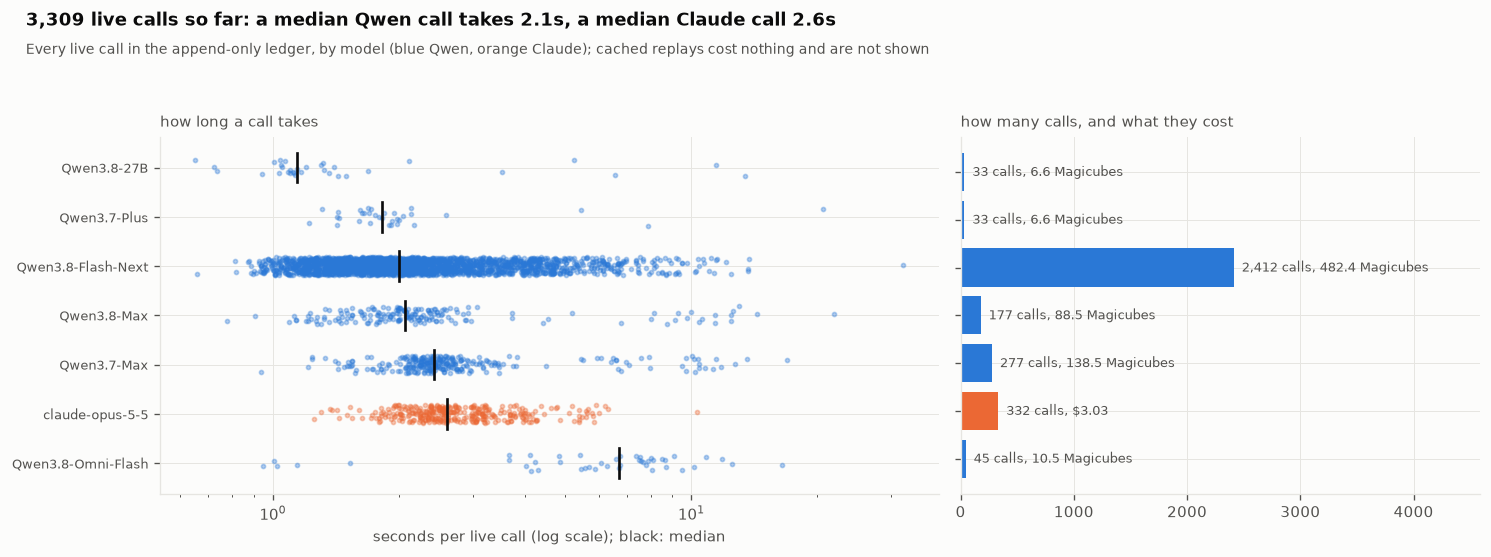

In [155]:
# ---- the ledger, drawn: every live call so far, how long it took and what it cost, by model ----
led = pd.DataFrame(LEDGER.rows)
if len(led):
    led["who"] = led.model.str.replace("Qwen-Ambassador/", "", regex=False)
    by = led.groupby("who").agg(calls=("cost", "size"), spent=("cost", "sum"), p50=("latency_s", "median"),
                                provider=("provider", "first")).sort_values("p50")
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 0.42 * len(by) + 1.8), gridspec_kw={"width_ratios": [1.5, 1]})
    for i, (who, r) in enumerate(by.iterrows()):
        lat = led.loc[led.who == who, "latency_s"].clip(lower=0.1)
        jitter = np.random.default_rng(SEED + i).uniform(-0.18, 0.18, len(lat))
        axes[0].scatter(lat, i + jitter, s=6, alpha=0.35, color=C2 if r.provider == "claude" else C1)
        axes[0].plot([r.p50] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.6)
    axes[0].set_xscale("log")
    axes[0].set_yticks(range(len(by)), by.index, fontsize=8)
    axes[0].set_xlabel("seconds per live call (log scale); black: median")
    axes[0].set_title("how long a call takes", fontsize=9, color=INK2, loc="left")
    axes[1].barh(range(len(by)), by.calls, color=[C2 if p == "claude" else C1 for p in by.provider])
    for i, r in enumerate(by.itertuples()):
        cost = f"${r.spent:.2f}" if r.provider == "claude" else f"{r.spent:.1f} Magicubes"
        axes[1].text(r.calls, i, f"  {r.calls:,} calls, {cost}", va="center", fontsize=7.5, color=INK2)
    axes[1].set_yticks(range(len(by)), [""] * len(by))
    axes[1].set_xlim(0, by.calls.max() * 1.9)
    axes[1].set_title("how many calls, and what they cost", fontsize=9, color=INK2, loc="left")
    for ax in axes:
        ax.invert_yaxis()
    q_med = led.loc[led.provider == "qwen", "latency_s"].median()
    c_med = led.loc[led.provider == "claude", "latency_s"].median()
    print(f"  {len(led):,} live calls on record: median {q_med:.1f}s for Qwen and {c_med:.1f}s for Claude; "
          f"{(led.attempts > 1).mean():.1%} needed a retry")
    finish(fig, "call_ledger", f"{len(led):,} live calls so far: a median Qwen call takes {q_med:.1f}s, a median Claude "
           f"call {c_med:.1f}s",
           "Every live call in the append-only ledger, by model (blue Qwen, orange Claude); cached replays cost nothing "
           "and are not shown")

**Both APIs do what this notebook needs, and the one price we had to assume was two and a half
times too high.** Every Qwen model answered in JSON mode both times it was asked, in one to two
seconds. Qwen supports native tool calling, which the specialists in part F use as it comes.
Eight calls at once through the client all came back, one of them after a retry, in 6.28 seconds,
and Claude's structured output returned a valid object for $0.0017 in 2.55 seconds. Prices were
measured the only way the account allows, from the balance before and after a few calls on a
quiet account, and they confirmed every price we knew, except that Omni-Flash costs 0.2
Magicubes a call, not the 0.5 we had assumed. The first attempt at that measurement found prices
four to ten times too high, because another program was spending from the same account at the
same moment, so a measurement now begins by watching the balance for a minute. The cache and the
ledger make the rest reproducible: a second run reads every answer from disk and costs nothing,
and the bill in section 40 is the sum of the ledger, not an estimate.

## 21 · The five-layer ladder on real chat

**Theory.** Figure 6 is the post's answer to a hard question: how do you build a deterministic
graph out of tools that are not deterministic? Five layers, each adding structure the previous
one could not. Regular expressions pull out the facts a line states outright. Catalogue
validation decides which names are real. Enrichment joins people and machines to teams. A
language model, held to a closed vocabulary, labels what no rule can, such as whether a
conversation is about an incident at all. Correlation, in part E, links what was said to what
happened. The post defines entropy as "the proportion of information still trapped in
unstructured form" and claims the ladder drives it down. We measure that literally on the
on-call channel around every incident: after each layer, how much of each line's text has
become a typed fact, and how many lines still link to nothing in the graph. World: Wikimedia.

In [156]:
# ---- the corpus: what people said around every incident, cut into conversations ----
def incident_chat(start: pd.Timestamp, before=pd.Timedelta(minutes=30), after=pd.Timedelta(hours=3)) -> pd.DataFrame:
    sub = IRC[(IRC.ts >= start - before) & (IRC.ts < start + after) & ~IRC.bot]
    return sub[["ts", "nick", "text"]]


def threads(lines: pd.DataFrame, gap_min: int = 10) -> pd.Series:
    """IRC has no threads, so a conversation is a run of lines with no silence longer than gap_min minutes."""
    return (lines.ts.diff() > pd.Timedelta(minutes=gap_min)).cumsum()


rows = []
for _, r in inc_w.iterrows():
    c = incident_chat(r["start"]).assign(incident=r["id"])
    rows.append(c.assign(thread=threads(c).map(lambda k, i=r["id"]: f"{i}#{k}")))
CHAT = (pd.concat(rows, ignore_index=True).drop_duplicates(["ts", "nick", "text"]) if rows
        else pd.DataFrame(columns=["ts", "nick", "text", "incident", "thread"]))
print(f"  {len(CHAT):,} human lines around {CHAT.incident.nunique()} incidents, from {CHAT.nick.nunique()} people, "
      f"in {CHAT.thread.nunique():,} conversations (median {CHAT.groupby('thread').size().median() if len(CHAT) else 0:.0f} "
      f"lines each)")

  13,331 human lines around 128 incidents, from 209 people, in 661 conversations (median 3 lines each)


In [157]:
# ---- layers 1 to 3: what rules, the catalogue and the identity chain can settle on their own ----
TASK_REF = re.compile(r"\bT\d{5,7}\b")
CAMEL = re.compile(r"\b[A-Z][a-z]+(?:[A-Z][a-z0-9]+)+\b")
ALERT_RULES = set(EPISODES.rule)


def ladder_123(text: str) -> dict:
    """Spans each layer turns into typed facts, as (start, end) character ranges, plus the entities it found."""
    low = text.lower()
    l1 = [m.span(1) for m in HOSTNAME.finditer(low)] + [m.span() for m in TASK_REF.finditer(text)] + \
         [m.span() for m in GERRIT_REF.finditer(text)] + [m.span() for m in CAMEL.finditer(text) if m.group() in ALERT_RULES]
    hosts = [h for h in hosts_in(text) if resolve_host(h)["role_from"] == "catalogue"]
    services, l2 = set(), []
    for m in SERVICE_LIKE.finditer(low):                       # hyphenated names may be misspelt: fuzzy allowed
        if svc := resolve_service(m.group(1))[0]:
            services.add(svc)
            l2.append(m.span(1))
    for m in re.finditer(r"\b[a-z]{5,}\b", low):                # plain words: exact catalogue names only
        if m.group() not in COMMON_WORD_SERVICES and (svc := resolve_service(m.group(), fuzzy=False)[0]):
            services.add(svc)
            l2.append(m.span())
    l2 += [m.span(1) for m in HOSTNAME.finditer(low) if m.group(1) in hosts]
    teams = {resolve_host(h)["team"] for h in hosts} - {None}
    return {"l1": l1, "l2": l2, "hosts": hosts, "services": sorted(services), "teams": sorted(teams),
            "alerts": [m.group() for m in CAMEL.finditer(text) if m.group() in ALERT_RULES]}


def covered(spans: list, n: int) -> float:
    mask = np.zeros(n, bool)
    for a, b in spans:
        mask[a:b] = True
    return mask.mean() if n else 0.0


if len(CHAT):
    L123 = [ladder_123(t) for t in CHAT.text]
    CHAT["l1_share"] = [covered(x["l1"], len(t)) for x, t in zip(L123, CHAT.text)]
    CHAT["l12_share"] = [covered(x["l1"] + x["l2"], len(t)) for x, t in zip(L123, CHAT.text)]
    CHAT["linked_l1"] = [bool(x["l1"]) for x in L123]
    CHAT["linked_l2"] = [bool(x["hosts"] or x["services"] or x["alerts"]) for x in L123]
    CHAT["linked_l3"] = [bool(x["teams"]) for x in L123]
    CHAT["entities"] = [sorted(set(x["hosts"]) | set(x["services"])) for x in L123]
    print(f"  {'after layer':<34}{'text now typed':>15}{'lines linked to the graph':>27}")
    print(f"  {'1 regular expressions':<34}{CHAT.l1_share.mean():>15.1%}{CHAT.linked_l1.mean():>27.1%}")
    print(f"  {'2 catalogue validation':<34}{CHAT.l12_share.mean():>15.1%}{CHAT.linked_l2.mean():>27.1%}")
    print(f"  {'3 identity: host to role to team':<34}{CHAT.l12_share.mean():>15.1%}"
          f"{(CHAT.linked_l2 | CHAT.linked_l3).mean():>27.1%}   (adds owners, not text)")
    ex = CHAT[CHAT.linked_l3].iloc[0] if CHAT.linked_l3.any() else CHAT.iloc[0]
    x = ladder_123(ex.text)
    print(f"\n  example: <{alias(ex.nick)}> {SCRUB(ex.text)[:100]}")
    print(f"    hosts {x['hosts']}  services {x['services']}  owning teams {x['teams']}  alerts {x['alerts']}")

  after layer                        text now typed  lines linked to the graph
  1 regular expressions                        2.0%                       8.8%
  2 catalogue validation                       2.7%                       7.1%
  3 identity: host to role to team             2.7%                       7.1%   (adds owners, not text)

  example: <eng-da08e> !log draining primary/secondary instances off ganeti2022 T296622
    hosts ['ganeti2022']  services []  owning teams ['Infrastructure Foundations']  alerts []


[fig] artifacts\figures_full\entropy_staircase.png


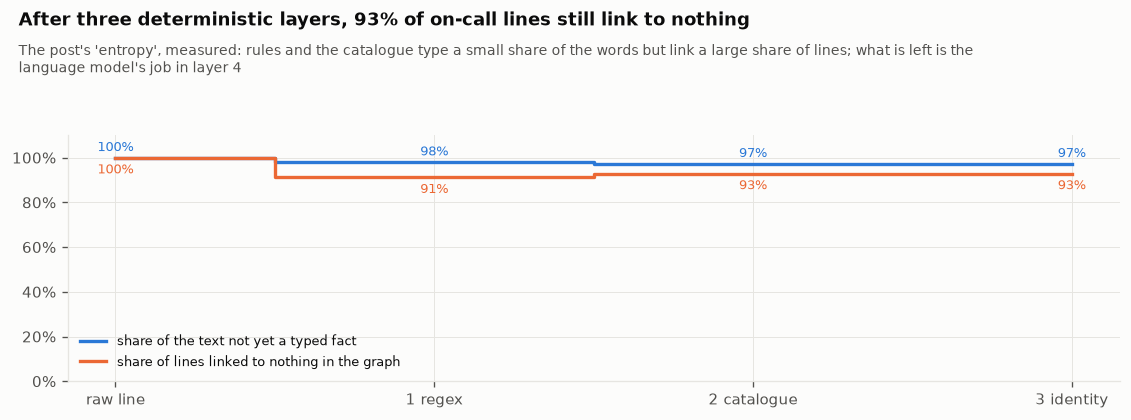

In [158]:
# ---- the entropy staircase: how much is still unstructured after each layer ----
if len(CHAT):
    steps = ["raw line", "1 regex", "2 catalogue", "3 identity"]
    untyped = [1.0, 1 - CHAT.l1_share.mean(), 1 - CHAT.l12_share.mean(), 1 - CHAT.l12_share.mean()]
    unlinked = [1.0, 1 - CHAT.linked_l1.mean(), 1 - CHAT.linked_l2.mean(), 1 - (CHAT.linked_l2 | CHAT.linked_l3).mean()]
    fig, ax = plt.subplots(figsize=(9.5, 3.6))
    ax.step(range(4), untyped, where="mid", color=C1, lw=2, label="share of the text not yet a typed fact")
    ax.step(range(4), unlinked, where="mid", color=C2, lw=2, label="share of lines linked to nothing in the graph")
    for i, (a, b) in enumerate(zip(untyped, unlinked)):
        ax.text(i, a + 0.03, f"{a:.0%}", ha="center", fontsize=8, color=C1)
        ax.text(i, b - 0.07, f"{b:.0%}", ha="center", fontsize=8, color=C2)
    ax.set_xticks(range(4), steps)
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.legend(fontsize=8, loc="lower left")
    finish(fig, "entropy_staircase",
           f"After three deterministic layers, {unlinked[-1]:.0%} of on-call lines still link to nothing",
           "The post's 'entropy', measured: rules and the catalogue type a small share of the words but link a large share "
           "of lines; what is left is the language model's job in layer 4")

In [159]:
# ---- layer 4: a language model with a closed vocabulary, one conversation at a time ----
L4_SYSTEM = ("You label conversations from an on-call engineering chat. Answer with one JSON object and nothing else, "
             "using exactly these keys: category, sentiment, incident_related, mentions. category is one of "
             "incident, question, discussion, decision. sentiment is one of positive, neutral, negative, urgent. "
             "incident_related is true or false. mentions lists only ids from the candidate list that the "
             "conversation is about; it may be empty.")


def l4_prompt(lines: pd.DataFrame, candidates: list[str]) -> str:
    body = "\n".join(f"[{t:%H:%M}] <{alias(n)}> {SCRUB(x)[:300]}" for t, n, x in zip(lines.ts, lines.nick, lines.text))
    return f"Candidate ids: {json.dumps(candidates)}\n\nConversation:\n{body[:6000]}"


def l4_valid(data, candidates: list[str]) -> bool:
    """The contract from section 13, checked in code: ModelScope's JSON mode guarantees JSON, not this shape."""
    props = L4_SCHEMA["properties"]
    return (isinstance(data, dict) and set(data) >= {"category", "sentiment", "incident_related", "mentions"}
            and data["category"] in props["category"]["enum"] and data["sentiment"] in props["sentiment"]["enum"]
            and isinstance(data["incident_related"], bool) and isinstance(data["mentions"], list)
            and all(m in candidates for m in data["mentions"]))


def candidates_for(incident_id: str, start: pd.Timestamp) -> list[str]:
    """The closed list: components that alerted or changed in the window, the only ids a model may name."""
    eps = EPISODES[(EPISODES.start >= start - pd.Timedelta(minutes=30)) & (EPISODES.start < start + pd.Timedelta(hours=3))]
    chg = CHANGES[(CHANGES.ts >= start - pd.Timedelta(hours=6)) & (CHANGES.ts < start + pd.Timedelta(hours=3))]
    hosts = {h for h in eps.host if h} | {h for m in chg.message for h in hosts_in(m)}
    svcs = {s for m in chg.message for tok in SERVICE_LIKE.findall(m.lower()) if (s := resolve_service(tok, 100)[0])}
    return sorted(f"host:{h}" for h in hosts if resolve_host(h)["role_from"] == "catalogue")[:40] + \
        sorted(f"service:{s}" for s in svcs)[:20]


def classify_threads(chat: pd.DataFrame, start: pd.Timestamp, incident_id: str, model: str = QWEN["flash"]) -> pd.DataFrame:
    cands = candidates_for(incident_id, start)
    groups = list(chat.groupby("thread", sort=False))
    with ThreadPoolExecutor(4) as ex:
        res = list(ex.map(lambda g: LLM.chat(model, [{"role": "system", "content": L4_SYSTEM},
                                                      {"role": "user", "content": l4_prompt(g[1], cands)}],
                                              agent="L4", max_tokens=300), groups))
    out = []
    for (tid, g), r in zip(groups, res):
        d = r.data if r.ok else None
        out.append({"thread": tid, "lines": len(g), "ok": r.ok, "valid": l4_valid(d, cands), "cached": r.cached,
                    "latency_s": r.latency_s, **({k: d.get(k) for k in ("category", "sentiment", "incident_related",
                                                                          "mentions")} if isinstance(d, dict) else {})})
    return pd.DataFrame(out)


if FLAGSHIP is not None:
    flag_chat = CHAT[CHAT.incident == FLAGSHIP["id"]]
    with phase("chat classification (L4)"):
        L4_FLAG = classify_threads(flag_chat, FLAG_T, FLAGSHIP["id"])
    print(f"  {FLAGSHIP['id']}: {len(L4_FLAG)} conversations, {L4_FLAG.ok.sum()} answered, "
          f"{L4_FLAG.valid.sum()} inside the contract, {L4_FLAG.cached.sum()} from the cache")
    print(f"  {'conversation':<10}{'lines':>6}  {'category':<11}{'sentiment':<10}{'about it':<9}mentions")
    for _, r in L4_FLAG.iterrows():
        print(f"  {r.thread.rsplit('#', 1)[-1]:<10}{r.lines:>6}  {str(r.get('category')):<11}{str(r.get('sentiment')):<10}"
              f"{str(r.get('incident_related')):<9}{r.get('mentions')}")
    print(f"\n  spent so far on this phase: {LEDGER.spent('qwen', 'chat classification (L4)'):.1f} of "
          f"{QWEN_PHASES['chat classification (L4)']} Magicubes")
else:
    L4_FLAG = pd.DataFrame()
    print("  [skip] no incident to follow in this profile")

  Incidents/2024-04-17 mw-on-k8s eqiad outage: 10 conversations, 10 answered, 10 inside the contract, 10 from the cache
  conversation lines  category   sentiment about it mentions
  0              1  question   neutral   False    []
  1             28  incident   urgent    True     ['service:mw-web']
  2              1  question   neutral   False    []
  3              1  decision   neutral   False    []
  4              1  decision   neutral   False    ['service:mw-web', 'service:mw-api-int', 'service:mw-api-ext']
  5              1  question   neutral   False    []
  6            204  incident   urgent    True     ['host:ncredir2001', 'service:mw-api-int', 'service:mw-web']
  7              9  discussion positive  True     []
  8              3  decision   neutral   False    []
  9             10  discussion neutral   False    []

  spent so far on this phase: 3.8 of 60 Magicubes


**After three deterministic layers, 93% of what people say on call still links to nothing in the
graph, and that is the measured size of layer 4's job.** Around 128 incidents, 209 people wrote
13,331 lines in 661 conversations, three lines long at the median. Regular expressions turned
2.0% of the text into typed facts and linked 8.8% of the lines to something: a host, a task, a
Gerrit change, an alert rule. The catalogue then took some of those links away. Checking names
against what really exists cut the linked lines to 7.1%, while typing slightly more of the text,
2.7%, because it recognises services as well as hosts. Identity adds owners to what is already
linked rather than reaching new text. So the post's entropy does fall, but slowly, and the reason
is the medium: on-call chat is mostly people reasoning in sentences, not naming things. That is
what the language model is for. On the incident we follow, Qwen Flash, held to the closed list of
categories and each conversation's own ids, labelled all ten conversations inside the contract;
the two long ones, of 28 and 204 lines, came back as urgent incidents about mw-web, and the longer
one also names mw-api-int and a host, each from the closed list the conversation was given.

## 22 · Which model for which job

**Theory.** Figure 6 names one model for the classification layer, Claude. We have six Qwen
models and Claude, and they differ by a factor of two and a half in price per call and by several
seconds in latency. The question a software house actually faces is not "which model is best"
but "which is the cheapest model that is good enough for this job". We answer it for layer 4 on
real conversations from incidents we do not otherwise use: every Qwen model that reads text (all
but Omni-Flash, which reads the screenshots in section 23) labels the same conversations, Claude
Opus 5.5 labels them too through its structured outputs, and we measure
agreement with Claude, how often each model stays inside the contract, what a label costs and how
long it takes. Agreement with Claude is not accuracy; section 34 brings labels that two independent
adjudicators agree on. World: Wikimedia.

In [160]:
# ---- the same conversations, labelled by five Qwen models and by Claude ----
L4_CLAUDE_SYSTEM = L4_SYSTEM.replace("Answer with one JSON object and nothing else, using", "Use")


def l4_schema_for(candidates: list[str]) -> dict:
    """Section 13's projection, with this conversation's closed list of ids as the enum for mentions."""
    s = json.loads(json.dumps(L4_SCHEMA))
    s["properties"]["incident_related"] = {"type": "boolean"}
    s["properties"]["mentions"] = {"type": "array", "items": {"type": "string", "enum": candidates or ["none"]}}
    s["required"] = sorted(set(s["required"]) | {"incident_related"})
    return s


def usd_of(usage: dict | None) -> float:
    """What a Claude answer cost, from its token counts; a cached replay still reports what the live call cost."""
    u = usage or {}
    return (u.get("input_tokens", 0) * CLAUDE_USD_PER_MTOK["input"] + u.get("output_tokens", 0)
            * CLAUDE_USD_PER_MTOK["output"]) / 1e6


def label_tuple(d) -> tuple | None:
    if not isinstance(d, dict):
        return None
    return (d.get("category"), d.get("sentiment"), bool(d.get("incident_related")), tuple(sorted(d.get("mentions") or [])))


pool = CHAT[CHAT.incident != (FLAGSHIP["id"] if FLAGSHIP is not None else "")]
sizes_ = pool.groupby("thread").size()
eligible_threads = sizes_[(sizes_ >= 3) & (sizes_ <= 40)].index
N_COMPARE = {"SMOKE": 3, "MEDIUM": 8}.get(PROFILE, 14)      # 14 x 1.6 Magicubes a run
# a fixed order by hash rather than a draw from the pool, so a change of the incident we follow only removes its threads
picked = sorted(eligible_threads, key=lambda t: hashlib.sha256(f"{SEED}|{t}".encode()).hexdigest())[:N_COMPARE]
COMPARE = []
for tid in picked:
    lines = pool[pool.thread == tid]
    inc = lines.incident.iloc[0]
    start = inc_w.loc[inc_w.id == inc, "start"].iloc[0]
    cands = candidates_for(inc, start)
    prompt = l4_prompt(lines, cands)
    with phase("model comparison"):
        for role in ("flash", "mid", "max", "max37", "plus37"):
            r = LLM.chat(QWEN[role], [{"role": "system", "content": L4_SYSTEM}, {"role": "user", "content": prompt}],
                         agent="L4-compare", max_tokens=300)
            COMPARE.append({"thread": tid, "model": role, "labels": label_tuple(r.data), "valid": l4_valid(r.data, cands),
                            "latency_s": r.latency_s, "cost": QWEN_PRICE[QWEN[role]]})
    with phase("chat classification comparison"):
        c = JUDGE.ask(L4_CLAUDE_SYSTEM, prompt, agent="L4-compare", schema=l4_schema_for(cands), effort="low",
                      max_tokens=1500)
    COMPARE.append({"thread": tid, "model": "claude", "labels": label_tuple(c.data), "valid": c.ok and not c.refused,
                    "latency_s": c.latency_s, "cost": usd_of(c.usage)})
COMPARE = pd.DataFrame(COMPARE, columns=["thread", "model", "labels", "valid", "latency_s", "cost"])
print(f"  {len(picked)} conversations from {pool[pool.thread.isin(picked)].incident.nunique()} incidents, labelled by "
      f"{COMPARE.model.nunique()} models")

  14 conversations from 14 incidents, labelled by 6 models


In [161]:
# ---- agreement with Claude, validity, cost and speed ----
ref = COMPARE[COMPARE.model == "claude"].set_index("thread").labels


def agree(a, b, part: int) -> float:
    if a is None or b is None:
        return 0.0
    if part == 3:
        x, y = set(a[3]), set(b[3])
        return 1.0 if not x and not y else len(x & y) / len(x | y)
    return float(a[part] == b[part])


PARETO = []
for role, g in COMPARE[COMPARE.model != "claude"].groupby("model"):
    rows = [(agree(l, ref.get(t), 0), agree(l, ref.get(t), 1), agree(l, ref.get(t), 2), agree(l, ref.get(t), 3))
            for t, l in zip(g.thread, g.labels)]
    a = np.array(rows) if rows else np.zeros((1, 4))
    PARETO.append({"model": role, "category": a[:, 0].mean(), "sentiment": a[:, 1].mean(), "related": a[:, 2].mean(),
                   "mentions": a[:, 3].mean(), "valid": g.valid.mean(), "latency_s": g.latency_s.median(),
                   "cost": g.cost.iloc[0]})
PARETO = pd.DataFrame(PARETO, columns=["model", "category", "sentiment", "related", "mentions", "valid",
                                       "latency_s", "cost"]).sort_values("cost")
print(f"  {'model':<8}{'category':>9}{'sentiment':>10}{'related':>9}{'mentions':>9}{'valid':>7}{'latency':>9}{'cost':>6}")
for _, r in PARETO.iterrows():
    print(f"  {r.model:<8}{r.category:>9.0%}{r.sentiment:>10.0%}{r.related:>9.0%}{r.mentions:>9.2f}{r.valid:>7.0%}"
          f"{r.latency_s:>8.1f}s{r.cost:>6.1f}")
cl = COMPARE[COMPARE.model == "claude"]
print(f"  {'claude':<8}{'(reference)':>37}{cl.valid.mean():>7.0%}{cl.latency_s.median():>8.1f}s  "
      f"${cl.cost.sum() / max(len(cl), 1):.4f} a label")

  model    category sentiment  related mentions  valid  latency  cost
  flash        100%       71%      86%     0.86   100%     1.5s   0.2
  mid          100%       86%      86%     0.86   100%     1.1s   0.2
  plus37       100%       79%      93%     0.86   100%     1.9s   0.2
  max           93%       86%      79%     0.89   100%     1.5s   0.5
  max37         86%       64%     100%     0.89   100%     1.5s   0.5
  claude                            (reference)   100%     2.6s  $0.0058 a label


[fig] artifacts\figures_full\model_pareto.png


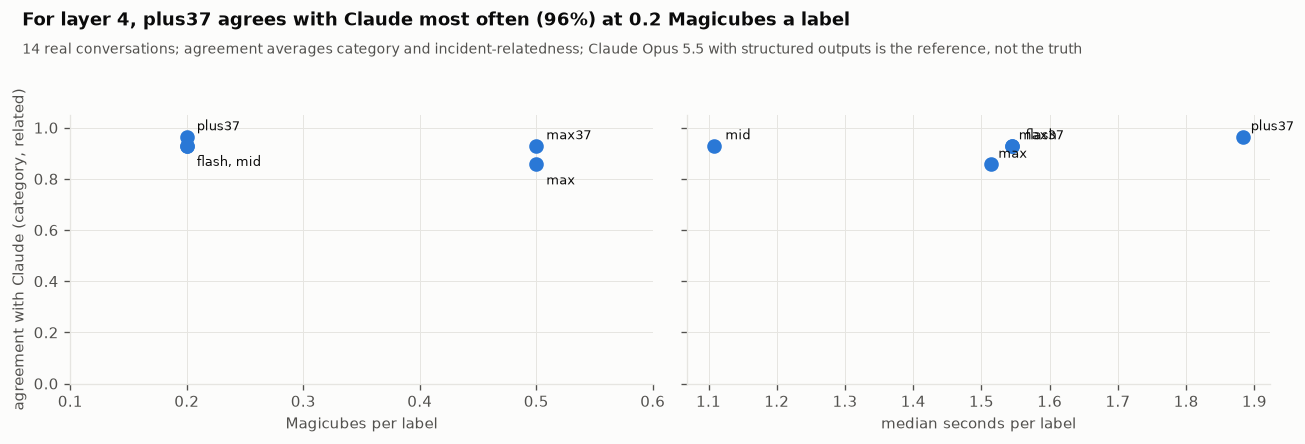

In [162]:
# ---- the trade-off, drawn ----
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
PARETO["overall"] = PARETO[["category", "related"]].mean(axis=1)
for ax, x, lab in ((axes[0], "cost", "Magicubes per label"), (axes[1], "latency_s", "median seconds per label")):
    ax.scatter(PARETO[x], PARETO.overall, s=60, color=C1)
    spot = PARETO.assign(px=PARETO[x].round(2), py=PARETO.overall.round(3))
    for px, col in spot.groupby("px"):                          # models on one spot share a label; a lower spot
        for k, (py, g) in enumerate(sorted(col.groupby("py"), key=lambda kv: -kv[0])):   # at the same x reads below
            ax.annotate(", ".join(g.model), (px, py), textcoords="offset points", xytext=(6, 4 if k == 0 else -12),
                        fontsize=8)
    ax.set_xlabel(lab)
axes[0].set_ylabel("agreement with Claude (category, related)")
axes[0].set_ylim(0, 1.05)
axes[0].set_xlim(0.1, 0.6)
best = PARETO.sort_values(["overall", "cost"], ascending=[False, True]).iloc[0] if len(PARETO) else None
finish(fig, "model_pareto",
       f"For layer 4, {best.model if best is not None else 'no model'} agrees with Claude most often "
       f"({best.overall:.0%}) at {best.cost:.1f} Magicubes a label" if best is not None else "Model comparison",
       f"{len(picked)} real conversations; agreement averages category and incident-relatedness; Claude Opus 5.5 with "
       "structured outputs is the reference, not the truth")

**For layer 4 the cheap models fit as well as the expensive ones: on 14 real conversations
Qwen3.7-Plus agrees with Claude most often, at 0.2 Magicubes a label against 0.5 for either
Max.** Every model stayed inside the contract on every conversation, so validity separates
nothing; agreement separates them a little. On the category of a conversation, the three models
that cost 0.2 Magicubes matched Claude every time, Qwen3.8-Max 93% of the time and Qwen3.7-Max
86%. Sentiment is the loosest field, from 64% to 86%, and it is the one the ladder needs least.
The 27B model was the fastest at 1.1 seconds a label; Claude took 2.6 seconds and $0.0058. With 14
conversations a single disagreement moves a percentage by seven points, so this ranks nothing
finely. What it supports is a decision: layer 4 runs on a 0.2-Magicube model, because paying two
and a half times as much bought no agreement here. Agreement with Claude is not accuracy either;
the labels of section 34 are the ruler for that.

## 23 · Omni-Flash reads the screenshots

**Theory.** One in four Wikimedia incident reports carries an image, almost always a Grafana
panel pasted in by an engineer because it showed the moment things went wrong better than any
sentence could. In a text-only pipeline that evidence is lost. A multimodal model can turn a
panel into a typed fact: which metric, which unit, when it peaked, how high. We send each panel
to Qwen3.8-Omni-Flash with a closed output contract and check its answers against the report's
own timeline: a peak the model places inside the incident's window is at least consistent with
what the engineers wrote. World: Wikimedia.

In [163]:
# ---- the panels: images attached to incident reports in the chat window ----
def image_url(filename: str) -> str | None:
    d = WEB.json(WIKITECH, {"action": "query", "titles": f"File:{filename}", "prop": "imageinfo", "iiprop": "url|mime",
                            "format": "json", "formatversion": 2})
    info = d["query"]["pages"][0].get("imageinfo")
    # the API appends a tracking query string to every URL; the file itself is the part before it
    return info[0]["url"].split("?")[0] if info and info[0].get("mime", "").startswith("image/") else None


PANEL_LIMIT = {"SMOKE": 2, "MEDIUM": 10}.get(PROFILE, 40)
panels = [(r["id"], f) for _, r in inc_w.iterrows() for f in r["files"]][:PANEL_LIMIT * 2]
PANELS = []
for inc, f in panels:
    url = image_url(f.strip())
    if url and url.lower().endswith((".png", ".jpg", ".jpeg")):
        path = WM_RAW / "panels" / slug(f)
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            path.write_bytes(WEB.get(url))
        PANELS.append({"incident": inc, "file": f, "path": path, "bytes": path.stat().st_size})
    if len(PANELS) >= PANEL_LIMIT:
        break
print(f"  {len(PANELS)} panels from {len({p['incident'] for p in PANELS})} reports, "
      f"{sum(p['bytes'] for p in PANELS) / 1e6:.1f} MB")

  40 panels from 18 reports, 7.0 MB


In [164]:
# ---- one panel, one typed fact: the contract Omni-Flash must fill ----
OMNI_SYSTEM = ("You read one monitoring dashboard screenshot. Answer with one JSON object and nothing else: "
               "{\"metric\": short name of what is plotted, \"unit\": unit or null, \"peak_time\": the time of the most "
               "unusual point as HH:MM in the time zone shown or null, \"peak_value\": number or null, "
               "\"anomaly\": one of spike, drop, plateau, none}")


def read_panel(p: dict) -> dict:
    b64 = base64.b64encode(p["path"].read_bytes()).decode()
    mime = "image/png" if p["path"].name.lower().endswith("png") else "image/jpeg"
    msg = [{"role": "system", "content": OMNI_SYSTEM},
           {"role": "user", "content": [{"type": "image_url", "image_url": {"url": f"data:{mime};base64,{b64}"}},
                                        {"type": "text", "text": "Read this panel."}]}]
    r = LLM.chat(QWEN["omni"], msg, agent="omni", max_tokens=200)
    d = r.data if isinstance(r.data, dict) else {}
    ok = r.ok and d.get("anomaly") in ("spike", "drop", "plateau", "none") and isinstance(d.get("metric"), str)
    return {**{k: d.get(k) for k in ("metric", "unit", "peak_time", "peak_value", "anomaly")}, "valid": ok,
            "latency_s": r.latency_s}


with phase("screenshots (Omni)"):
    READS = pd.DataFrame([{**{k: p[k] for k in ("incident", "file")}, **read_panel(p)} for p in PANELS])
if len(READS):
    print(f"  {READS.valid.sum()}/{len(READS)} panels read inside the contract; anomalies: "
          f"{READS.anomaly.value_counts().to_dict()}; median {READS.latency_s.median():.1f}s a panel")
    for _, r in READS[READS.valid].head(4).iterrows():
        print(f"    {r.incident.removeprefix('Incidents/')[:38]:<40}{str(r.metric)[:34]:<36}{r.anomaly:<8}peak {r.peak_time}")

  40/40 panels read inside the contract; anomalies: {'spike': 33, 'drop': 6, 'none': 1}; median 7.1s a panel
    2021-07-26 ruwikinews DynamicPageList   Requests by method                  spike   peak 10:48
    2021-07-26 ruwikinews DynamicPageList   Requests by method                  none    peak 10:42
    2021-07-26 ruwikinews DynamicPageList   Rows read                           drop    peak 10:57
    2021-09-01 partial parsoid outage       MediaWiki errors over time by chan  spike   peak 10:00


  panels with a readable peak time: 35; peak within three hours of the report's start: 91%
  Panels carry their own time zone and axis ticks, so this is a consistency check, not a score.


[fig] artifacts\figures_full\omni_reads.png


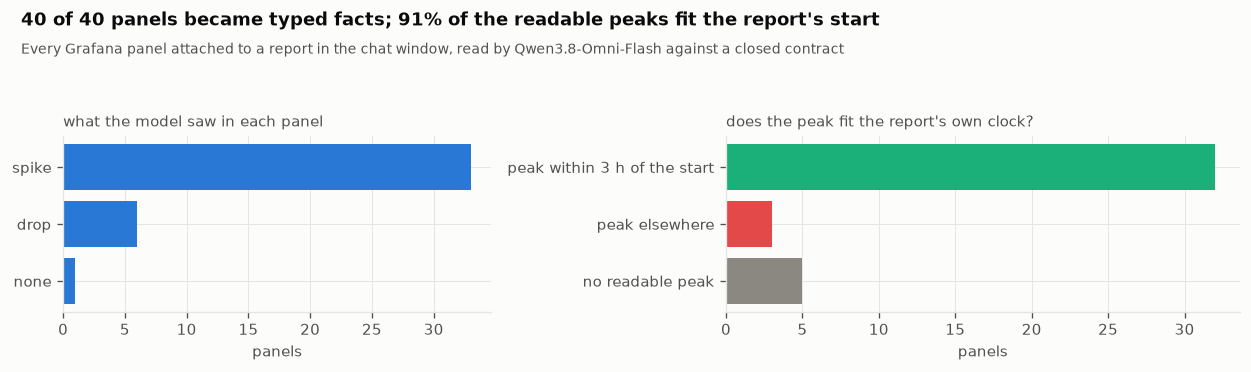

In [165]:
# ---- a check against the report itself: does the model's peak fall inside the incident? ----
def in_window(row) -> bool | None:
    m = re.fullmatch(r"(\d{1,2}):(\d\d)", str(row.peak_time or ""))
    start = inc_w.loc[inc_w.id == row.incident, "start"]
    if not m or start.empty:
        return None
    t0 = start.iloc[0]
    peak = t0.normalize() + pd.Timedelta(hours=int(m.group(1)), minutes=int(m.group(2)))
    return any(abs(peak + pd.Timedelta(days=d) - t0) <= pd.Timedelta(hours=3) for d in (-1, 0, 1))


if len(READS):
    READS["consistent"] = READS.apply(in_window, axis=1)
    known = READS.consistent.dropna()
    print(f"  panels with a readable peak time: {len(known)}; peak within three hours of the report's start: "
          f"{known.mean():.0%}" if len(known) else "  no panel gave a readable peak time")
    print("  Panels carry their own time zone and axis ticks, so this is a consistency check, not a score.")

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2), gridspec_kw={"width_ratios": [1, 1.2]})
    kinds_o = READS.anomaly.fillna("unreadable").value_counts()
    axes[0].barh(kinds_o.index, kinds_o.values, color=C1)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("panels")
    axes[0].set_title("what the model saw in each panel", fontsize=9, color=INK2, loc="left")
    where_ = READS.consistent.map({True: "peak within 3 h of the start", False: "peak elsewhere"}).fillna("no readable peak")
    w_counts = where_.value_counts().reindex(["peak within 3 h of the start", "peak elsewhere", "no readable peak"],
                                             fill_value=0)
    axes[1].barh(w_counts.index, w_counts.values, color=[C3, C8, MUTED])
    axes[1].invert_yaxis()
    axes[1].set_xlabel("panels")
    axes[1].set_title("does the peak fit the report's own clock?", fontsize=9, color=INK2, loc="left")
    finish(fig, "omni_reads", f"{int(READS.valid.sum())} of {len(READS)} panels became typed facts; "
           f"{known.mean():.0%} of the readable peaks fit the report's start" if len(known) else "Omni-Flash on the panels",
           "Every Grafana panel attached to a report in the chat window, read by Qwen3.8-Omni-Flash against a closed "
           "contract")

[fig] artifacts\figures_full\omni_panel.png


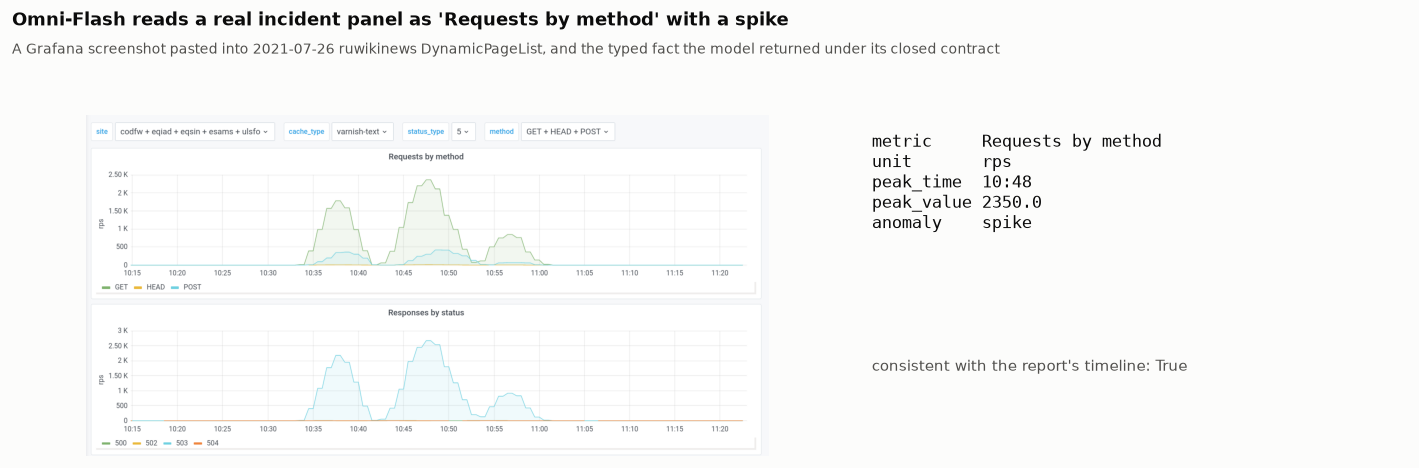

In [166]:
# ---- one panel, and what the model read from it ----
shown = READS[READS.valid].head(1) if len(READS) else READS
if len(shown):
    r = shown.iloc[0]
    p = next(x for x in PANELS if x["file"] == r.file)
    from PIL import Image
    img = Image.open(p["path"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1.6, 1]})
    axes[0].imshow(img)
    axes[0].axis("off")
    axes[1].axis("off")
    reading = "\n".join(f"{k:<11}{r[k]}" for k in ("metric", "unit", "peak_time", "peak_value", "anomaly"))
    axes[1].text(0.0, 0.95, reading, va="top", family="monospace", fontsize=10, color=INK)
    axes[1].text(0.0, 0.25, f"consistent with the report's timeline: {r.get('consistent')}", fontsize=9, color=INK2)
    finish(fig, "omni_panel", f"Omni-Flash reads a real incident panel as '{r.metric}' with a {r.anomaly}",
           f"A Grafana screenshot pasted into {r.incident.removeprefix('Incidents/')}, and the typed fact the model returned "
           "under its closed contract")

**Every one of the 40 panels came back as a typed fact, and nine in ten of the peaks it read sit
inside the incident.** The panels came from 18 reports in the chat window. Each answer filled the
whole contract: a metric name, a unit, a peak and one of four anomaly words. Thirty-three were
read as spikes, six as drops and one as nothing unusual, which is what we would expect of
pictures an engineer chose because they showed the moment things went wrong. Of the 35 panels
with a readable peak time, 91% put it within three hours of the start the report gives. That is
a consistency check, not a score. A panel carries its own time zone, and the model reads axis
ticks rather than data, so a peak at the right clock time in the wrong zone would still pass.
What it does show is that evidence a text-only pipeline throws away can be recovered for about
seven seconds a panel. Two limits are worth saying plainly. The fact says when and how high,
never the shape before or after, so the series behind the picture stays in the picture. And we
stop at reading: these facts are not written into the graph, and no specialist in part F uses
them, so whether a panel changes a diagnosis is a question this notebook leaves open.

## 24 · Determinism, measured

**Theory.** The post's boldest sentence is that the ladder turns non-deterministic tools into
a deterministic graph: "any single step of this ladder is non-deterministic, but in aggregate the
chain becomes deterministic". There are two different claims inside it. One is about the contract:
whatever the model says, what reaches the graph is a valid triple. That one we can make true by
construction, and section 13 did. The other is about repetition: ask again and you get the same
triples. That one is an empirical question about the model, and we answer it by asking again,
live, with the cache switched off, for the same conversations, with and without the closed
vocabulary, for Qwen and for Claude. World: Wikimedia.

  [cache] determinism.json: measured 2026-10-31 14:00 UTC
  how we asked                             identical 3 times  distinct answers
  Qwen Flash, closed vocabulary                          90%               1.1
  Qwen Flash, free JSON                                   0%               2.9
  Claude, structured outputs                             70%               1.3

  Claude's three asks differ only by a number in the system prompt, so its cache cannot answer them;
  Qwen ran with the cache off at temperature 0.7, the setting under which repetition is actually tested.


[fig] artifacts\figures_full\determinism.png


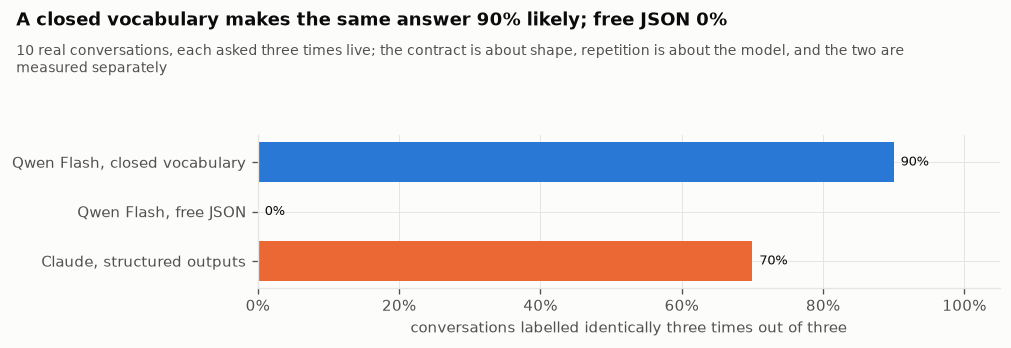

In [167]:
# ---- the same question, asked three times live: how often is the answer the same? ----
N_RERUN = {"SMOKE": 2, "MEDIUM": 5}.get(PROFILE, 10)
rerun_threads = picked[:N_RERUN]
FREE_SYSTEM = ("You read conversations from an on-call engineering chat. Say in JSON what kind of conversation it is, "
               "its tone, whether it is about an incident, and which components it is about.")


def rerun(thread_id: str, mode: str, n: int = 3) -> list:
    lines = pool[pool.thread == thread_id]
    inc = lines.incident.iloc[0]
    cands = candidates_for(inc, inc_w.loc[inc_w.id == inc, "start"].iloc[0])
    out = []
    for i in range(n):
        if mode == "claude":
            with phase("free-text judge"):
                r = JUDGE.ask(L4_CLAUDE_SYSTEM + f" (attempt {i})", l4_prompt(lines, cands), agent="rerun",
                              schema=l4_schema_for(cands), effort="low", max_tokens=1500)
        else:
            LLM.live = True
            with phase("determinism reruns"):
                r = LLM.chat(QWEN["flash"], [{"role": "system", "content": L4_SYSTEM if mode == "closed" else FREE_SYSTEM},
                                             {"role": "user", "content": l4_prompt(lines, cands)}],
                             agent="rerun", max_tokens=300, temperature=0.7)
            LLM.live = False
        out.append(label_tuple(r.data) if mode != "free" else json.dumps(r.data, sort_keys=True) if r.data else None)
    return out


# live calls are the point of this cell, so its answers are saved: a second run reads them instead of paying again
det_file = RES_DIR / "determinism.json"
saved_det = json.loads(det_file.read_text()) if det_file.exists() else None
if saved_det and saved_det["threads"] == [str(t) for t in rerun_threads] and not RECOMPUTE:
    DETERMINISM = saved_det["rows"]
    print(f"  [cache] {det_file.name}: measured {saved_det['measured_at']}")
else:
    DETERMINISM = []
    for mode in ("closed", "free", "claude"):
        for tid in rerun_threads:
            answers_ = rerun(tid, mode)
            DETERMINISM.append({"mode": mode, "thread": str(tid), "distinct": len(set(answers_)),
                                "all_same": len(set(answers_)) == 1 and answers_[0] is not None})
    measured_at = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    det_file.write_text(json.dumps({"measured_at": measured_at,
                                    "threads": [str(t) for t in rerun_threads], "rows": DETERMINISM}, indent=1))
DETERMINISM = pd.DataFrame(DETERMINISM, columns=["mode", "thread", "distinct", "all_same"])
print(f"  {'how we asked':<40}{'identical 3 times':>18}{'distinct answers':>18}")
for mode, label in (("closed", "Qwen Flash, closed vocabulary"), ("free", "Qwen Flash, free JSON"),
                    ("claude", "Claude, structured outputs")):
    d = DETERMINISM[DETERMINISM["mode"] == mode]
    print(f"  {label:<40}{d.all_same.mean():>18.0%}{d.distinct.mean():>18.1f}")
print("\n  Claude's three asks differ only by a number in the system prompt, so its cache cannot answer them;")
print("  Qwen ran with the cache off at temperature 0.7, the setting under which repetition is actually tested.")

if len(DETERMINISM):
    fig, ax = plt.subplots(figsize=(8.5, 3.0))
    modes = [("closed", "Qwen Flash, closed vocabulary", C1), ("free", "Qwen Flash, free JSON", MUTED),
             ("claude", "Claude, structured outputs", C2)]
    vals = [DETERMINISM[DETERMINISM["mode"] == m].all_same.mean() for m, _, _ in modes]
    ax.barh([lab for _, lab, _ in modes], vals, color=[c for _, _, c in modes])
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8)
    ax.set_xlim(0, 1.05)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.invert_yaxis()
    ax.set_xlabel("conversations labelled identically three times out of three")
    finish(fig, "determinism", f"A closed vocabulary makes the same answer {vals[0]:.0%} likely; free JSON {vals[1]:.0%}",
           f"{len(rerun_threads)} real conversations, each asked three times live; the contract is about shape, repetition is "
           "about the model, and the two are measured separately")

**The closed vocabulary is what makes asking again give the same answer: Qwen Flash, sampled at
temperature 0.7, labelled 90% of the conversations identically three times out of three with the
contract, and none without it.** Free JSON came back with 2.9 different answers in three asks on
average. With no list to choose from, any difference in a key's name or a value's wording counts
as a different answer, which is exactly the work a later layer would otherwise have to undo. With
the shape's enum for the category and the conversation's own list of ids for the mentions, there
is nothing left to phrase differently, so a difference is a change in the label itself, and it
happened for one conversation in ten. Claude through structured
outputs repeated itself 70% of the time, less often than the cheaper model at a high temperature.
So the post's sentence is half true by construction and half true by measurement. Every answer
that reaches the graph is a valid triple, because the shapes refuse anything else; that the same
triples come back on a second run is a property of the contract and the model together, and on
these conversations it held nine times in ten, not always.

## 25 · Signals from the labs: metrics, logs and traces become typed signals

**Theory.** The correlation engine reads thirteen signal types, and the post spends one sentence
on where they come from. This is that sentence, done on real telemetry. A signal is a short,
typed claim about one component at one time: this pod's memory moved five robust deviations from
its own last hour, this service logged ten times its usual errors, these spans got three times
slower. Three rules keep the detectors honest. Every baseline is the hour before the window and
never the window itself, so nothing is judged against a future it could not have known. Every
signal names the component the benchmark's answer key would name, so a ranking can be scored
exactly the way published agents were. And the detectors are written once, from the names of
the measurements, before any score is looked at; part G reports what they achieve, not what they
were tuned to achieve. Worlds: OpenRCA and RCAEval.

In [168]:
# ---- the task windows: every OpenRCA question names a half hour, in UTC+8 ----
MONTHS = {m: i for i, m in enumerate(calendar.month_name) if m}
DATE_TEXT = re.compile(r"(January|February|March|April|May|June|July|August|September|October|November|December)"
                       r" (\d{1,2}), (\d{4})")


def task_window(instruction: str) -> tuple[pd.Timestamp, pd.Timestamp]:
    """Start and end in UTC. Five windows cross midnight ('from 23:30 to March 7, 2021, at 00:00'), so the end
    takes the second date when there is one."""
    days = [datetime.date(int(y), MONTHS[mo], int(d)) for mo, d, y in DATE_TEXT.findall(instruction)]
    times = re.findall(r"\b(\d{1,2}:\d\d)\b", instruction)
    a = pd.Timestamp(f"{days[0]} {times[0]}").tz_localize(UTC8).tz_convert("UTC")
    b = pd.Timestamp(f"{days[-1]} {times[1]}").tz_localize(UTC8).tz_convert("UTC")
    return a, b if b > a else b + pd.Timedelta(days=1)          # 'from 23:30 to 00:00' with no second date


TASKS = OPENRCA_TASKS.copy()
TASKS[["ws", "we"]] = pd.DataFrame([task_window(s) for s in TASKS.instruction], index=TASKS.index)
TASKS["task_id"] = [f"{s}-{i:03d}" for i, s in enumerate(TASKS.system)]
inside = [((OPENRCA_RECORDS.system == r.system) & (OPENRCA_RECORDS.ts_utc >= r.ws) & (OPENRCA_RECORDS.ts_utc < r.we)).sum()
          for r in TASKS.itertuples()]
TASKS["failures_inside"] = inside
print(f"  {len(TASKS)} tasks, every window parsed; {(TASKS.we - TASKS.ws).dt.total_seconds().eq(1800).mean():.0%} are "
      f"exactly 30 minutes long")
print(f"  [test] each window holds at least one recorded failure: {(TASKS.failures_inside >= 1).sum()}/{len(TASKS)} -> "
      f"{'PASS' if (TASKS.failures_inside >= 1).all() else 'FAIL'}")
print(f"  example: '{TASKS.instruction.iloc[0][:90]}...' -> {TASKS.ws.iloc[0]:%Y-%m-%d %H:%M} to {TASKS.we.iloc[0]:%H:%M} UTC")

  335 tasks, every window parsed; 100% are exactly 30 minutes long
  [test] each window holds at least one recorded failure: 335/335 -> PASS
  example: 'On March 4, 2021, within the time range of 14:30 to 15:00, a single failure was detected i...' -> 2021-03-04 06:30 to 07:00 UTC


In [169]:
# ---- which component does a measurement belong to? the answer key's own names ----
def components_of(system: str, entity: str) -> list[str]:
    """Market writes container metrics as 'node.pod' and service metrics as 'service-grpc'; the other systems
    already use the answer key's names. A pod also counts for its service, and a container for its node."""
    e = str(entity)
    if not system.startswith("market"):
        return [e]
    if e.endswith("-grpc") or ".ts:" in e:
        return [re.split(r"-grpc$|\.ts:", e)[0].rstrip("2")]
    if "." in e:
        node, pod = e.split(".", 1)
        return [pod, re.sub(r"2?-\d+$", "", pod), node]
    if re.fullmatch(r"node-\d+", e):
        return [e]
    return [e, re.sub(r"2?-\d+$", "", e)]


for s, e in (("market_cb1", "node-6.cartservice-0"), ("market_cb1", "cartservice-grpc"), ("market_cb1", "adservice2.ts:8088"),
             ("market_cb1", "frontend2-0"), ("bank", "Tomcat01"), ("telecom", "docker_003")):
    print(f"  {s:<11}{e:<24}-> {components_of(s, e)}")

  market_cb1 node-6.cartservice-0    -> ['cartservice-0', 'cartservice', 'node-6']
  market_cb1 cartservice-grpc        -> ['cartservice']
  market_cb1 adservice2.ts:8088      -> ['adservice']
  market_cb1 frontend2-0             -> ['frontend2-0', 'frontend']
  bank       Tomcat01                -> ['Tomcat01']
  telecom    docker_003              -> ['docker_003']


In [170]:
# ---- the detectors: each window is judged only against the hour before it ----
DET = duck()                                         # the detectors' own connection


def window_table(system: str) -> str:
    t = TASKS[TASKS.system == system]
    DET.register("win_df", pd.DataFrame({"task_id": t.task_id, "ws": t.ws, "we": t.we}))
    DET.execute("CREATE OR REPLACE TEMP TABLE win AS SELECT task_id, ws::TIMESTAMPTZ AS ws, we::TIMESTAMPTZ AS we FROM win_df")
    return "win"


def detect_metrics(system: str, z_min: float = 5.0) -> pd.DataFrame:
    """Robust z-scores against the hour before the window. A series that only ever goes up in that hour is a
    cumulative counter (CPU seconds, bytes read), so it is judged on its per-minute increase instead; our first
    version compared raw counters with their own past and flagged almost every one of them."""
    win, src = window_table(system), (OPENRCA_PQ / system / "metrics").as_posix()
    return DET.execute(f"""
    WITH m0 AS (SELECT w.task_id, x.entity, x.kpi, date_trunc('minute', x.ts) AS minute, avg(x.value) AS raw,
                       min(x.ts) < min(w.ws) AS before
                FROM read_parquet('{src}/*.parquet') x JOIN {win} w ON x.ts >= w.ws - INTERVAL 60 MINUTE AND x.ts < w.we
                WHERE x.value IS NOT NULL GROUP BY w.task_id, x.entity, x.kpi, date_trunc('minute', x.ts)),
    m1 AS (SELECT *, raw - lag(raw) OVER (PARTITION BY task_id, entity, kpi ORDER BY minute) AS step FROM m0),
    kind AS (SELECT task_id, entity, kpi, avg(CASE WHEN step >= 0 THEN 1 ELSE 0 END) >= 0.95
                    AND count(DISTINCT raw) > 5 AS is_counter FROM m1 WHERE before AND step IS NOT NULL GROUP BY ALL),
    m AS (SELECT m1.task_id, m1.entity, m1.kpi, m1.minute, m1.before, k.is_counter,
                 CASE WHEN k.is_counter THEN m1.step ELSE m1.raw END AS v
          FROM m1 JOIN kind k USING (task_id, entity, kpi) WHERE m1.step IS NOT NULL OR NOT k.is_counter),
    base AS (SELECT task_id, entity, kpi, median(v) AS med FROM m WHERE before GROUP BY ALL),
    spread AS (SELECT m.task_id, m.entity, m.kpi, b.med, median(abs(m.v - b.med)) AS mad
               FROM m JOIN base b USING (task_id, entity, kpi) WHERE m.before GROUP BY ALL)
    SELECT m.task_id, m.entity, m.kpi, m.minute, m.v, s.med, m.is_counter,
           (m.v - s.med) / greatest(1.4826 * s.mad, 0.05 * abs(s.med), 1e-6) AS z
    FROM m JOIN spread s USING (task_id, entity, kpi)
    WHERE NOT m.before AND abs((m.v - s.med) / greatest(1.4826 * s.mad, 0.05 * abs(s.med), 1e-6)) >= {z_min}""").df()


def detect_logs(system: str) -> pd.DataFrame:
    if not (OPENRCA_PQ / system / "logs").exists():
        return pd.DataFrame(columns=["task_id", "entity", "minute", "n", "base"])
    win, src = window_table(system), (OPENRCA_PQ / system / "logs").as_posix()
    return DET.execute(f"""
    WITH l AS (SELECT w.task_id, x.entity, date_trunc('minute', x.ts) AS minute, x.ts < w.ws AS before, count(*) AS n
               FROM read_parquet('{src}/*.parquet') x JOIN {win} w ON x.ts >= w.ws - INTERVAL 60 MINUTE AND x.ts < w.we
               WHERE regexp_matches(x.message, '(?i)error|exception|fail|refused|timeout') GROUP BY ALL),
    base AS (SELECT task_id, entity, sum(n) / 60.0 AS base FROM l WHERE before GROUP BY ALL)
    SELECT l.task_id, l.entity, l.minute, l.n, coalesce(b.base, 0) AS base FROM l LEFT JOIN base b USING (task_id, entity)
    WHERE NOT l.before AND l.n >= 5 AND l.n >= 3 * coalesce(b.base, 0)""").df()


def detect_spans(system: str) -> pd.DataFrame:
    win, src = window_table(system), (OPENRCA_PQ / system / "spans").as_posix()
    failed = {"telecom": "status = 'False'", "bank": "false"}.get(system, "status NOT IN ('0', 'Ok', 'OK', '200')")
    return DET.execute(f"""
    WITH s AS (SELECT w.task_id, x.entity, date_trunc('minute', x.ts) AS minute, x.ts < w.ws AS before,
                      count(*) AS n, avg(x.duration_ms) AS ms, count(*) FILTER (WHERE {failed}) AS bad
               FROM read_parquet('{src}/*.parquet') x JOIN {win} w ON x.ts >= w.ws - INTERVAL 60 MINUTE AND x.ts < w.we
               GROUP BY ALL),
    base AS (SELECT task_id, entity, median(ms) AS ms0, avg(bad) AS bad0 FROM s WHERE before GROUP BY ALL)
    SELECT s.task_id, s.entity, s.minute, s.n, s.ms, b.ms0, s.bad, b.bad0 FROM s JOIN base b USING (task_id, entity)
    WHERE NOT s.before AND s.n >= 5 AND (s.ms >= 3 * b.ms0 OR (s.bad >= 5 AND s.bad >= 3 * b.bad0))""").df()


signals_file = RES_DIR / "openrca_signals.parquet"
if signals_file.exists() and not RECOMPUTE:
    LAB_SIGNALS = pd.read_parquet(signals_file)
    print(f"  [cache] {signals_file.name}")
else:
    parts = []
    for system in sorted(TASKS.system.unique()):
        if not (OPENRCA_PQ / system / "metrics").exists():
            continue
        t0 = time.perf_counter()
        met, logs_, spans_ = detect_metrics(system), detect_logs(system), detect_spans(system)
        for df, kind in ((met, "METRIC_ANOMALY"), (logs_, "LOG_ERROR")):
            if len(df):
                parts.append(df.assign(system=system, kind=kind,
                                       strength=np.abs(df.z) if kind == "METRIC_ANOMALY" else df.n / np.maximum(df.base, 1)))
        if len(spans_):
            slow = spans_[spans_.ms >= 3 * spans_.ms0]
            bad = spans_[(spans_.bad >= 5) & (spans_.bad >= 3 * spans_.bad0)]
            parts.append(slow.assign(system=system, kind="TRACE_SLOW", strength=slow.ms / slow.ms0.clip(lower=1e-6)))
            parts.append(bad.assign(system=system, kind="TRACE_FAILED", strength=bad.bad / np.maximum(bad.bad0, 1)))
        print(f"  {system:<11} metrics {len(met):>8,} anomalous minutes   logs {len(logs_):>6,}   spans {len(spans_):>6,}"
              f"   ({time.perf_counter() - t0:.0f}s)")
    LAB_SIGNALS = pd.concat(parts, ignore_index=True)[["system", "task_id", "kind", "entity", "kpi", "minute", "strength"]] \
        if parts else pd.DataFrame(columns=["system", "task_id", "kind", "entity", "kpi", "minute", "strength"])
    save_parquet(LAB_SIGNALS, signals_file)
print(f"\n  {len(LAB_SIGNALS):,} signal minutes over {LAB_SIGNALS.task_id.nunique()} task windows; "
      f"{len(TASKS) - LAB_SIGNALS.task_id.nunique()} windows produced none")
print(LAB_SIGNALS.groupby(["system", "kind"]).size().unstack(fill_value=0).to_string())
by_kind = LAB_SIGNALS.kind.value_counts()
print(f"  in all: " + ", ".join(f"{k} {v:,}" for k, v in by_kind.items()) +
      f"; metric anomalies are {by_kind.get('METRIC_ANOMALY', 0) / max(len(LAB_SIGNALS), 1):.1%} of the signal minutes, "
      f"{by_kind.get('METRIC_ANOMALY', 0) / max(LAB_SIGNALS.task_id.nunique(), 1):,.0f} per window that has any")

  [cache] openrca_signals.parquet

  863,062 signal minutes over 329 task windows; 6 windows produced none
kind        LOG_ERROR  METRIC_ANOMALY  TRACE_FAILED  TRACE_SLOW
system                                                         
bank               25          204534             0        2135
market_cb1         72          273299            58        1503
market_cb2        152          269445           170        4277
telecom             0          106425           318         649


  in all: METRIC_ANOMALY 853,703, TRACE_SLOW 8,564, TRACE_FAILED 546, LOG_ERROR 249; metric anomalies are 98.9% of the signal minutes, 2,595 per window that has any


[fig] artifacts\figures_full\detectors.png


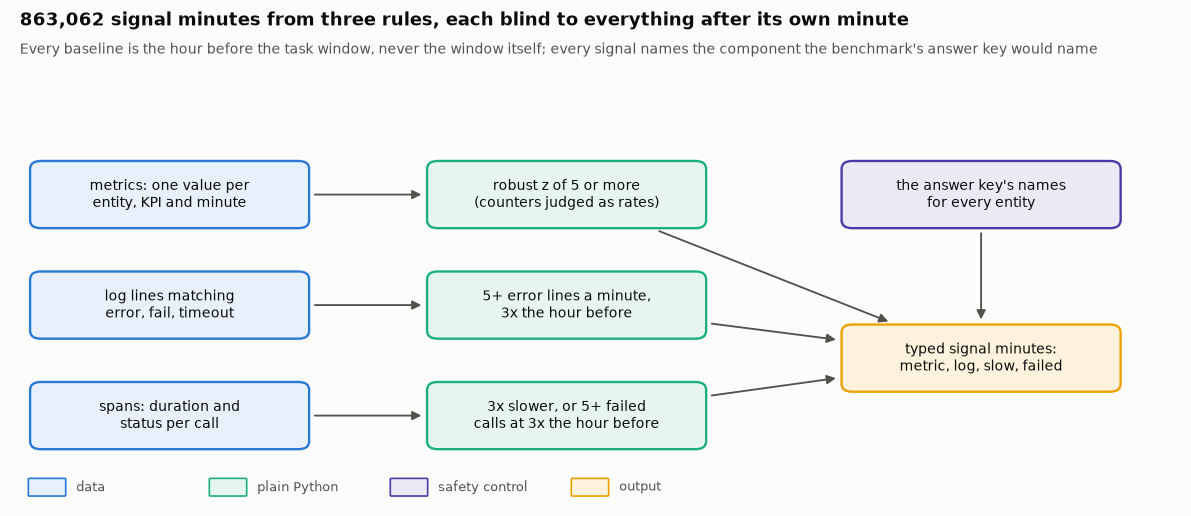

In [171]:
# ---- the detectors, drawn: three rules, each judging a window only against the hour before it ----
DETECT_FLOW = {
    "metrics": (1.35, 3.5, "metrics: one value per\nentity, KPI and minute", "data"),
    "logs": (1.35, 2.25, "log lines matching\nerror, fail, timeout", "data"),
    "spans": (1.35, 1.0, "spans: duration and\nstatus per call", "data"),
    "m_rule": (4.75, 3.5, "robust z of 5 or more\n(counters judged as rates)", "code"),
    "l_rule": (4.75, 2.25, "5+ error lines a minute,\n3x the hour before", "code"),
    "s_rule": (4.75, 1.0, "3x slower, or 5+ failed\ncalls at 3x the hour before", "code"),
    "names": (8.3, 3.5, "the answer key's names\nfor every entity", "guard"),
    "out": (8.3, 1.65, "typed signal minutes:\nmetric, log, slow, failed", "output"),
}
DETECT_EDGES = [("metrics", "m_rule", None), ("logs", "l_rule", None), ("spans", "s_rule", None),
                ("m_rule", "out", None), ("l_rule", "out", None), ("s_rule", "out", None), ("names", "out", None)]
draw_flow(DETECT_FLOW, DETECT_EDGES, "detectors",
          f"{len(LAB_SIGNALS):,} signal minutes from three rules, each blind to everything after its own minute",
          "Every baseline is the hour before the task window, never the window itself; every signal names the "
          "component the benchmark's answer key would name", size=(10, 4.4), box=(2.35, 0.72))

[fig] artifacts\figures_full\signal_mix.png


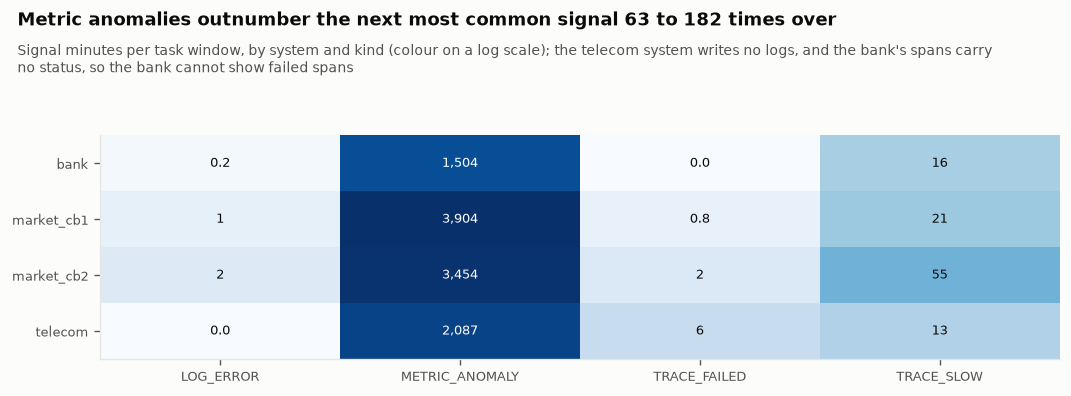

In [172]:
# ---- the signal mix, drawn: what each system's failures look like to the detectors ----
mix = LAB_SIGNALS.groupby(["system", "kind"]).size().unstack(fill_value=0)
per_task = mix.div(TASKS.groupby("system").size().reindex(mix.index), axis=0)
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(np.log10(per_task.to_numpy() + 1), cmap="Blues", aspect="auto")
ax.set_xticks(range(per_task.shape[1]), per_task.columns, fontsize=8)
ax.set_yticks(range(per_task.shape[0]), per_task.index, fontsize=8)
ax.grid(False)
for i in range(per_task.shape[0]):
    for j in range(per_task.shape[1]):
        v = per_task.iat[i, j]
        ax.text(j, i, f"{v:,.0f}" if v >= 1 else f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if np.log10(v + 1) > np.log10(per_task.to_numpy().max() + 1) * 0.6 else INK)
others = mix.drop(columns="METRIC_ANOMALY", errors="ignore").max(axis=1).clip(lower=1)
ratio = mix.get("METRIC_ANOMALY", pd.Series(0, index=mix.index)) / others
finish(fig, "signal_mix", f"Metric anomalies outnumber the next most common signal {ratio.min():.0f} to "
       f"{ratio.max():.0f} times over",
       "Signal minutes per task window, by system and kind (colour on a log scale); the telecom system writes no logs, "
       "and the bank's spans carry no status, so the bank cannot show failed spans")

**The detectors turned 335 real failure windows into 863,062 signal minutes, and 98.9% of them
are metric anomalies.** Six windows produced nothing at all. Logs gave 249 error-burst minutes in
all four systems together, traces 9,110 (8,564 slow, 546 failed), and metrics the remaining
853,703, about 2,600 for every half hour. The reason is arithmetic, not failure: every component
carries dozens of measurements, the only baseline is the hour before, and a measurement that sat
perfectly flat in that hour has no spread to divide by, so any movement at all is divided by
almost nothing and scores in the millions or billions. The running example in section 28 shows
it: the four loudest signals in its window are disk measurements on frontend pods, with robust
z-scores near 5 x 10^11, and none of them is the broken service. Two things
follow, and the next two sections live with both. Counting signals says little about which one
matters, so section 26 ranks by structure, not volume. And ranking by raw strength rewards
series that were idle and then busy, which is why section 27 learns from which kinds of signal
sit on causes rather than from how loud they are.

## 26 · The correlation engine: chains from a cause to a symptom

**Theory.** The post's engine reads typed signals and links them into chains such as deploy,
then error, then alert, then incident, each chain with a confidence. Figure 7 gives the rule:
a hop between two signals inside a ten-minute window scores 0.9 if the pair is a known causal
pair and otherwise 0.6 times how close in time plus 0.4 times how severe, and the chain scores
the mean of its hops. Two questions decide whether this is causal reasoning or coincidence
counting. Does the engine only link signals whose components are connected, or anything that
happens close in time? At a company that changes something every ten minutes, timing alone links
everything to everything. And is 0.87 a probability? A mean of hop scores is not one by
construction, so we ask how often a chain of a given confidence actually names the right cause.
Worlds: OpenRCA, where the call graph and exact answers are known, and Wikimedia, for the
placebo test.

In [173]:
# ---- one hop, three ways to decide whether two signals may be linked ----
def may_link(a: dict, b: dict, mode: str, related, window: float = 10.0, lineage: set | None = None) -> float | None:
    """Minutes from a to b if the hop is allowed, else None. Lineage (a deploy that ships a commit) skips the
    window; 'timing' links any components; 'topology' needs b's component to depend on a's (or be the same)."""
    gap = (b["t"] - a["t"]).total_seconds() / 60
    if gap < 0:
        return None
    if lineage and (a["sid"], b["sid"]) in lineage:
        return gap
    if gap > window:
        return None
    if mode == "timing" or a["comp"] == b["comp"]:
        return gap
    return gap if mode == "topology" and related(a["comp"], b["comp"]) else None


def best_chains(signals: list[dict], sinks: set, mode: str, related, max_hops: int = 4, lineage: set | None = None,
                fan_out: int = 5):
    """Depth-first search from every signal towards any sink; each root keeps its best chain by mean hop score.
    Each signal follows only its `fan_out` best next hops: with hundreds of signals in a window, following all of
    them would explode."""
    by_time = sorted(signals, key=lambda s: s["t"])
    nxt = {s["sid"]: [] for s in by_time}
    for i, a in enumerate(by_time):
        for b in by_time[i + 1:]:
            if (b["t"] - a["t"]).total_seconds() > 600 and not lineage:
                break
            gap = may_link(a, b, mode, related, lineage=lineage)
            if gap is not None:
                linked = bool(lineage and (a["sid"], b["sid"]) in lineage)
                nxt[a["sid"]].append((b, None if linked else hop_score(a["type"], b["type"], gap, b["severity"])))
        nxt[a["sid"]] = sorted(nxt[a["sid"]], key=lambda x: -(x[1] if x[1] is not None else 1))[:fan_out]
    best = {}

    def walk(root, node, scores, path):
        if node["sid"] in sinks and scores:
            s = float(np.mean(scores))
            if s > best.get(root["sid"], (0, None))[0]:
                best[root["sid"]] = (s, list(path))
        if len(path) > max_hops:
            return
        for b, sc in nxt[node["sid"]]:
            walk(root, b, scores + ([sc] if sc is not None else []), path + [b["sid"]])

    for s in by_time:
        if s["sid"] not in sinks:
            walk(s, s, [], [s["sid"]])
    return best


T0_ = pd.Timestamp("2026-01-01 12:00", tz="UTC")
fig7 = [{"sid": k, "type": k, "comp": "api-gateway", "t": T0_ + pd.Timedelta(minutes=m), "severity": 0.825}
        for k, m in (("COMMIT", 0), ("DEPLOYMENT", 14), ("LOG_ERROR", 17), ("ALERT", 19), ("INCIDENT", 24))]
same = lambda a, b: a == b
got = best_chains(fig7, {"INCIDENT"}, "topology", same, lineage={("COMMIT", "DEPLOYMENT")})
no_lineage = best_chains(fig7, {"INCIDENT"}, "topology", same)
print(f"  figure 7 with lineage: best chain from COMMIT scores {got['COMMIT'][0]:.3f} via {got['COMMIT'][1]}")
print(f"  [test] the published 0.87 is reproduced -> {'PASS' if round(got['COMMIT'][0], 2) == 0.87 else 'FAIL'}")
print(f"  [test] without lineage the 14-minute hop is refused and COMMIT reaches nothing -> "
      f"{'PASS' if 'COMMIT' not in no_lineage else 'FAIL'}")
apart = [dict(fig7[2], comp="search"), dict(fig7[4])]
print(f"  [test] an error on an unrelated component does not reach the incident in topology mode -> "
      f"{'PASS' if not best_chains(apart, {'INCIDENT'}, 'topology', same) else 'FAIL'}; "
      f"timing mode links it anyway -> {'yes' if best_chains(apart, {'INCIDENT'}, 'timing', same) else 'no'}")

  figure 7 with lineage: best chain from COMMIT scores 0.870 via ['COMMIT', 'DEPLOYMENT', 'LOG_ERROR', 'ALERT', 'INCIDENT']
  [test] the published 0.87 is reproduced -> PASS
  [test] without lineage the 14-minute hop is refused and COMMIT reaches nothing -> PASS
  [test] an error on an unrelated component does not reach the incident in topology mode -> PASS; timing mode links it anyway -> yes


[fig] artifacts\figures_full\correlation_engine.png


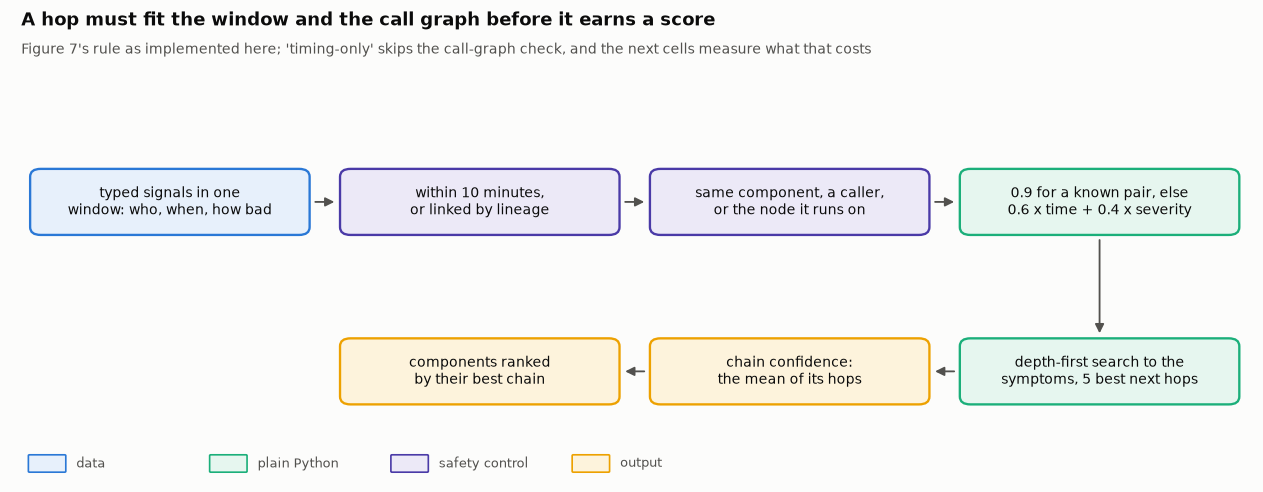

In [174]:
# ---- the engine, drawn: what a hop must pass before it is scored, and how a chain becomes a ranking ----
ENGINE_FLOW = {
    "sig": (1.35, 3.2, "typed signals in one\nwindow: who, when, how bad", "data"),
    "window": (4.0, 3.2, "within 10 minutes,\nor linked by lineage", "guard"),
    "topo": (6.65, 3.2, "same component, a caller,\nor the node it runs on", "guard"),
    "score": (9.3, 3.2, "0.9 for a known pair, else\n0.6 x time + 0.4 x severity", "code"),
    "dfs": (9.3, 1.25, "depth-first search to the\nsymptoms, 5 best next hops", "code"),
    "chain": (6.65, 1.25, "chain confidence:\nthe mean of its hops", "output"),
    "rank": (4.0, 1.25, "components ranked\nby their best chain", "output"),
}
ENGINE_EDGES = [("sig", "window", None), ("window", "topo", None), ("topo", "score", None), ("score", "dfs", None),
                ("dfs", "chain", None), ("chain", "rank", None)]
draw_flow(ENGINE_FLOW, ENGINE_EDGES, "correlation_engine",
          "A hop must fit the window and the call graph before it earns a score",
          "Figure 7's rule as implemented here; 'timing-only' skips the call-graph check, and the next cells measure what "
          "that costs", size=(10.6, 4.2), box=(2.35, 0.72))

In [175]:
# ---- topology for the labs: who calls whom, lifted from pods to services and nodes ----
def service_of(comp: str) -> str:
    return re.sub(r"2?-\d+$", "", comp)


CALLERS = defaultdict(set)              # callee component -> the components that call it, at pod and service level
for r in CALLS.itertuples():
    for callee in {r.callee, service_of(r.callee)}:
        CALLERS[(r.system, callee)] |= {r.caller, service_of(r.caller)}
NODE_OF = {}                            # Market pods run on nodes; the metric names say which
for e in LAB_SIGNALS.loc[LAB_SIGNALS.entity.str.contains(r"^node-\d+\.", regex=True, na=False), "entity"].unique():
    node, pod = e.split(".", 1)
    NODE_OF[pod] = node


def related_in(system: str):
    """b may be an effect of a when b calls a (directly or one more step up), or a is the node b's pod runs on."""
    def related(a: str, b: str) -> bool:
        if service_of(a) == service_of(b) or NODE_OF.get(b) == a:
            return True
        up = CALLERS.get((system, a), set())
        return b in up or any(b in CALLERS.get((system, u), set()) for u in up)
    return related


print(f"  call edges lifted to {len(CALLERS)} callee components; {len(NODE_OF)} pods placed on nodes")
print(f"  example: who is affected when cartservice slows? {sorted(CALLERS.get(('market_cb1', 'cartservice'), set()))}")

  call edges lifted to 108 callee components; 42 pods placed on nodes
  example: who is affected when cartservice slows? ['checkoutservice', 'checkoutservice-0', 'checkoutservice-1', 'checkoutservice-2', 'checkoutservice2-0', 'frontend', 'frontend-0', 'frontend-1', 'frontend-2', 'frontend2-0']


In [176]:
# ---- ranking root causes in each task window: strongest signal, timing-only chains, topology chains ----
def lab_signals_for(task_id: str, system: str, top_per_comp: int = 3) -> list[dict]:
    """The strongest few signal minutes per component and kind, with a severity in [0, 1]."""
    d = LAB_SIGNALS[LAB_SIGNALS.task_id == task_id].copy()
    rows = []
    for e, g in d.groupby("entity"):
        for comp in components_of(system, e):
            rows.append(g.assign(comp=comp))
    if not rows:
        return []
    d = pd.concat(rows)
    d["severity"] = np.clip(np.log1p(d.strength) / np.log1p(50), 0, 1)
    d = d.sort_values("severity", ascending=False).groupby(["comp", "kind"]).head(top_per_comp)
    return [{"sid": f"{r.comp}|{r.kind}|{r.minute:%H%M}|{i}", "type": r.kind, "comp": r.comp, "t": r.minute,
             "severity": float(r.severity)} for i, r in enumerate(d.itertuples())]


def rank_task(task_id: str, system: str, method: str) -> list[str]:
    sig = lab_signals_for(task_id, system)
    if not sig:
        return []
    # every tie is broken by name: a set's order changes from one Python process to the next, and it once moved
    # these rankings, and every number built on them, between two runs of the same notebook
    if method == "strongest signal":
        best = {}
        for s in sig:
            best[s["comp"]] = max(best.get(s["comp"], 0), s["severity"])
        return [c for c, _ in sorted(best.items(), key=lambda x: (-x[1], x[0]))]
    sinks = {s["sid"] for s in sig if s["type"] in ("TRACE_SLOW", "TRACE_FAILED")} or \
            {max(sig, key=lambda s: s["t"])["sid"]}                      # symptoms: what callers felt
    chains = best_chains(sig, sinks, "timing" if method == "timing-only chains" else "topology", related_in(system))
    comp_of = {s["sid"]: s["comp"] for s in sig}
    score = {}
    for sid, (s, _) in chains.items():
        score[comp_of[sid]] = max(score.get(comp_of[sid], 0), s)
    ranked = [c for c, _ in sorted(score.items(), key=lambda x: (-x[1], x[0]))]
    rest = sorted({s["comp"] for s in sig} - set(ranked),
                  key=lambda c: (-max(s["severity"] for s in sig if s["comp"] == c), c))
    return ranked + rest                    # components no chain reaches still count, after the chained ones


def component_answers(scoring_points: str) -> list[str]:
    return re.findall(r"root cause component is ([\w-]+)", scoring_points)


def ac_at(tasks: pd.DataFrame, method: str, ks=(1, 3)) -> dict:
    hits, n = Counter(), 0
    for t in tasks.itertuples():
        want = component_answers(t.scoring_points)
        if not want:
            continue
        ranked = rank_task(t.task_id, t.system, method)
        n += 1
        for k in ks:
            hits[k] += any(w in ranked[:k] for w in want)
    return {f"AC@{k}": hits[k] / max(n, 1) for k in ks} | {"tasks": n}


DEV = TASKS[TASKS.system == "market_cb1"]          # the development cluster: the only one we look at here
print(f"  development cluster: {len(DEV)} tasks, {sum(bool(component_answers(s)) for s in DEV.scoring_points)} ask for a component")
CORR_DEV = {}
for method in ("strongest signal", "timing-only chains", "topology chains"):
    t0 = time.perf_counter()
    CORR_DEV[method] = ac_at(DEV, method)
    print(f"  {method:<22}AC@1 {CORR_DEV[method]['AC@1']:6.1%}   AC@3 {CORR_DEV[method]['AC@3']:6.1%}   "
          f"({time.perf_counter() - t0:.0f}s)")
print("\n  The held-out cluster, the bank and the telecom system are scored once, in section 38, with these methods frozen.")

  development cluster: 70 tasks, 41 ask for a component


  strongest signal      AC@1   4.9%   AC@3   4.9%   (11s)


  timing-only chains    AC@1   4.9%   AC@3   9.8%   (22s)


  topology chains       AC@1   9.8%   AC@3  26.8%   (41s)

  The held-out cluster, the bank and the telecom system are scored once, in section 38, with these methods frozen.


In [177]:
# ---- the placebo: does the engine 'explain' real incidents more often than random moments? ----
CH_SORTED = CHANGES.sort_values("ts").reset_index(drop=True)
# alerts from the chat route only: Loki covers the last six months, and mixing it in would make recent windows
# far busier than old ones, which is not a property of incidents
EP_SORTED = EPISODES[EPISODES.route == "chat"].sort_values("start").reset_index(drop=True)
CH_T, EP_T = to_s(CH_SORTED.ts), to_s(EP_SORTED.start)
CHANGE_TYPE = {"deploy": "DEPLOYMENT", "config": "CONFIG_CHANGE", "capacity": "AUTOSCALE", "maintenance": "MAINTENANCE",
               "other": "CHANGE"}
CLUSTER_OF = {h: v["cluster"] for h, v in CONFTOOL.items()}


def wm_related(hub_cap: int | None):
    """Same host, or two hosts in one pooled cluster. With a cap, a cluster bigger than the cap links nothing:
    the post's edge cap, applied to a membership hub such as the 552-host Kubernetes cluster."""
    sizes = Counter(CLUSTER_OF.values())

    def related(a, b):
        if a is None or b is None:
            return True                                   # the incident itself, or a change with no named host
        ca, cb = CLUSTER_OF.get(a), CLUSTER_OF.get(b)
        return ca is not None and ca == cb and (hub_cap is None or sizes[ca] <= hub_cap)
    return related


def wm_signals(t0: pd.Timestamp, before_h: int = 6) -> list[dict]:
    s0, s1 = int(t0.timestamp()) - before_h * 3600, int(t0.timestamp())
    out = [{"sid": "INCIDENT", "type": "INCIDENT", "comp": None, "t": t0, "severity": 1.0}]
    a, b = np.searchsorted(CH_T, s0), np.searchsorted(CH_T, s1)
    for r in CH_SORTED.iloc[a:b].itertuples():
        hosts = [h for h in hosts_in(r.message) if h in CLUSTER_OF]
        out.append({"sid": f"c{r.Index}", "type": CHANGE_TYPE[r.kind], "comp": hosts[0] if hosts else None,
                    "t": r.ts, "severity": 0.5})
    a, b = np.searchsorted(EP_T, s0), np.searchsorted(EP_T, s1)
    for r in EP_SORTED.iloc[a:b].itertuples():
        out.append({"sid": f"a{r.Index}", "type": "ALERT", "comp": r.host if r.host in CLUSTER_OF else None,
                    "t": r.start, "severity": min(1.0, 0.4 + 0.1 * r.firings)})
    return out


def deploy_explains(t0: pd.Timestamp, related, threshold: float = 0.7) -> bool:
    sig = wm_signals(t0)
    chains = best_chains(sig, {"INCIDENT"}, "topology", related, max_hops=3)
    roots = {s["sid"]: s["type"] for s in sig}
    return any(roots[sid] == "DEPLOYMENT" and score >= threshold for sid, (score, _) in chains.items())


placebo_file = RES_DIR / "correlation_placebo.json"
if placebo_file.exists() and not RECOMPUTE:
    PLACEBO = json.loads(placebo_file.read_text())
    print(f"  [cache] {placebo_file.name}")
else:
    PLACEBO = {}
    moments = {"incidents": list(inc_w.start)}
    if len(inc_w):
        pl, ok_ = placebo_moments(T_INC, weeks=3)
        moments["placebo"] = [pd.Timestamp(int(s), unit="s", tz="UTC") for s in pl[ok_]]
    for cap_label, cap in (("no cap", None), ("cap 50", 50)):
        rel = wm_related(cap)
        PLACEBO[cap_label] = {k: float(np.mean([deploy_explains(t, rel) for t in v])) if v else float("nan")
                              for k, v in moments.items()}
    PLACEBO["n"] = {k: len(v) for k, v in moments.items()}
    placebo_file.write_text(json.dumps(PLACEBO, indent=1))
print(f"  a deploy-rooted chain with confidence 0.7 or more, ending at the moment in question:")
for cap_label in ("no cap", "cap 50"):
    r = PLACEBO[cap_label]
    print(f"    {cap_label:<8} real incidents {r.get('incidents', float('nan')):6.1%}   placebo moments "
          f"{r.get('placebo', float('nan')):6.1%}   ({PLACEBO['n'].get('incidents', 0)} incidents, "
          f"{PLACEBO['n'].get('placebo', 0)} placebo moments)")
print("\n  If the engine explained placebo moments nearly as often as incidents, its chains would say more about how")
print("  busy production is than about what caused anything.")

  [cache] correlation_placebo.json
  a deploy-rooted chain with confidence 0.7 or more, ending at the moment in question:
    no cap   real incidents  22.6%   placebo moments  14.6%   (146 incidents, 707 placebo moments)
    cap 50   real incidents  22.6%   placebo moments  14.6%   (146 incidents, 707 placebo moments)

  If the engine explained placebo moments nearly as often as incidents, its chains would say more about how
  busy production is than about what caused anything.


  confidence     chains  mean score   right
  (0.8, 0.9]        6.0        0.86      0%
  (0.9, 1.0]       33.0        0.98      6%
  Brier score 0.871 (0 is perfect; always saying 0.5 scores 0.25)


[fig] artifacts\figures_full\correlation_checks.png


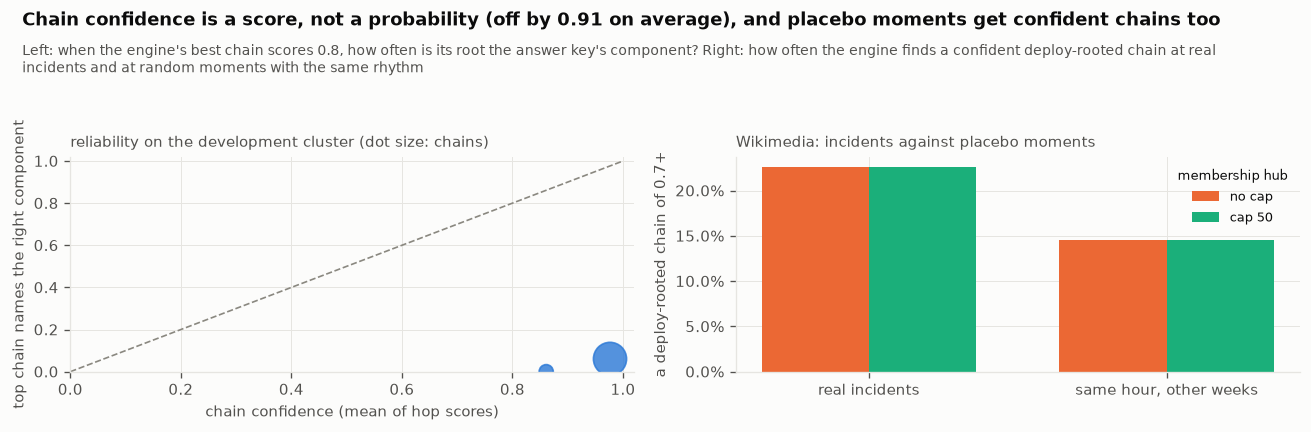

In [178]:
# ---- is 0.87 a probability? chain confidence against how often the chain named the right component ----
CAL = []
for t in DEV.itertuples():
    want = component_answers(t.scoring_points)
    if not want:
        continue
    sig = lab_signals_for(t.task_id, t.system)
    if not sig:
        continue
    sinks = {s["sid"] for s in sig if s["type"] in ("TRACE_SLOW", "TRACE_FAILED")} or {max(sig, key=lambda s: s["t"])["sid"]}
    chains = best_chains(sig, sinks, "topology", related_in(t.system))
    comp_of = {s["sid"]: s["comp"] for s in sig}
    if chains:
        sid, (score, _) = max(chains.items(), key=lambda kv: kv[1][0])
        CAL.append((score, comp_of[sid] in want))
CAL = pd.DataFrame(CAL, columns=["confidence", "right"])
if len(CAL):
    CAL["bin"] = pd.cut(CAL.confidence, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    rel = CAL.groupby("bin", observed=True).agg(n=("right", "size"), conf=("confidence", "mean"), hit=("right", "mean"))
    brier = float(((CAL.confidence - CAL.right) ** 2).mean())
    print(f"  {'confidence':<14}{'chains':>7}{'mean score':>12}{'right':>8}")
    for b, r in rel.iterrows():
        print(f"  {str(b):<14}{r.n:>7}{r.conf:>12.2f}{r.hit:>8.0%}")
    print(f"  Brier score {brier:.3f} (0 is perfect; always saying 0.5 scores 0.25)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
    axes[0].plot([0, 1], [0, 1], ls="--", color=MUTED, lw=1)
    axes[0].scatter(rel.conf, rel.hit, s=rel.n * 12, color=C1, alpha=0.8)
    axes[0].set_xlim(0, 1.02)
    axes[0].set_ylim(0, 1.02)
    axes[0].set_xlabel("chain confidence (mean of hop scores)")
    axes[0].set_ylabel("top chain names the right component")
    axes[0].set_title("reliability on the development cluster (dot size: chains)", fontsize=9, color=INK2, loc="left")
    lab = ["incidents", "placebo"]
    for j, (cap, colour) in enumerate((("no cap", C2), ("cap 50", C3))):
        vals = [PLACEBO[cap].get(k, float("nan")) for k in lab]
        axes[1].bar(np.arange(2) + (j - 0.5) * 0.36, vals, width=0.36, color=colour, label=cap)
    axes[1].set_xticks(range(2), ["real incidents", "same hour, other weeks"])
    axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    axes[1].set_ylabel("a deploy-rooted chain of 0.7+")
    axes[1].legend(fontsize=8, title="membership hub", title_fontsize=8)
    axes[1].set_title("Wikimedia: incidents against placebo moments", fontsize=9, color=INK2, loc="left")
    gap = float((rel.n * (rel.conf - rel.hit).abs()).sum() / rel.n.sum())          # mean calibration error
    placebo_rate = PLACEBO["no cap"].get("placebo", 0.0)
    finish(fig, "correlation_checks",
           ("Chain confidence is a score, not a probability" if gap > 0.1 else "Chain confidence happens to sit close to a "
            "probability") + f" (off by {gap:.2f} on average), and " +
           ("placebo moments get confident chains too" if placebo_rate > 0.1 else "placebo moments rarely get confident chains"),
           "Left: when the engine's best chain scores 0.8, how often is its root the answer key's component? Right: how often "
           "the engine finds a confident deploy-rooted chain at real incidents and at random moments with the same rhythm")

**Topology is what makes chains worth having: following who calls whom puts the right component in
the top three for 26.8% of development failures, against 9.8% for timing alone and 4.9% for the
loudest signal.** The post's 0.87 example reproduces exactly, and so do its two rules: without
lineage the fourteen-minute hop from a commit is refused, and in topology mode an error on an
unrelated component never reaches the incident, while timing mode links it anyway. On the 41
development failures that ask for a component, topology chains put it first four times, timing
chains and the loudest signal twice each, and topology's top three holds it 11 times against 4.
Those are small numbers on purpose: they are what the engine does before anything is learned, and
section 42 tests whether the difference in first place could be chance. Two checks keep the post's
figure 7 in proportion. At Wikimedia a confident chain rooted in a deploy ends at 22.6% of real
incidents, but also at 14.6% of placebo moments with the same daily rhythm: changes are so
frequent that a plausible culprit is nearly always on hand, so a chain is a lead, not a verdict.
And the confidence is not a probability. Chains scoring above 0.9 named the right component 6% of
the time, and the Brier score is 0.871, far worse than always saying one half (0.25). The number
0.87 orders chains; it does not say how likely the cause is.

## 27 · The flywheel: learning from resolved failures

**Theory.** Figure 8 is the post's longest-term claim: every resolved incident teaches the
system something, patterns are inferred from the graph, and the engine adapts, so the next
investigation starts from more than the last one did. Figure 9 shows the knowledge it means: a
SPARQL count that turns chains into a rule such as "api-gateway deploys cause 40% of SEV-2s".
Testing a flywheel honestly needs two things the post does not show: labels that say what
really caused each failure, and a strict line between what the system learned from and what it
is tested on. OpenRCA gives both. Its two Market clusters run the same application under
different faults, so we let the flywheel learn only from the development cluster's resolved
failures and, in part G, test what it learned on the held-out cluster, the protocol of the
published follow-up that this benchmark's authors used. Here we build the learning step and
check it on the development cluster alone, one failure left out at a time. World: OpenRCA.

In [179]:
# ---- Collect: for every resolved development failure, which signals sat on which component ----
FAMILIES = [("cpu", r"cpu|load"), ("memory", r"mem|pgfault|oom|heap"), ("network", r"network|net\.|net_|tcp|udp|packet"),
            ("disk", r"fs_|disk|\.io\.|io_|r_s|w_s|rkb|wkb|svctm|await"), ("process", r"thread|process|tasks_state|file_desc|socket"),
            ("latency", r"duration|mrt|latency|elapsed"), ("errors", r"\bsr\b|success|error|fail")]


def kpi_family(kpi: str) -> str:
    return next((f for f, rx in FAMILIES if re.search(rx, str(kpi), re.I)), "other")


def task_features(task_id: str, system: str) -> dict[str, set]:
    """component -> the signal features present on it in this window ('metric:memory', 'trace:TRACE_SLOW', ...)."""
    d = LAB_SIGNALS[LAB_SIGNALS.task_id == task_id]
    feats = defaultdict(set)
    for kind, e, kpi in zip(d.kind, d.entity, d.kpi):
        f = f"metric:{kpi_family(kpi)}" if kind == "METRIC_ANOMALY" else f"{kind.lower()}"
        for comp in components_of(system, e):
            feats[comp].add(f)
    return feats


def collect(tasks: pd.DataFrame) -> list[tuple[str, dict, list]]:
    return [(t.task_id, task_features(t.task_id, t.system), component_answers(t.scoring_points))
            for t in tasks.itertuples() if component_answers(t.scoring_points)]


COLLECTED = collect(DEV)
roots = sum(len(w) for _, _, w in COLLECTED)
print(f"  {len(COLLECTED)} resolved development failures with a named component; {roots} root components, "
      f"{sum(len(f) for _, f, _ in COLLECTED):,} component-window pairs in all")

  41 resolved development failures with a named component; 54 root components, 3,945 component-window pairs in all


[fig] artifacts\figures_full\flywheel_ours.png


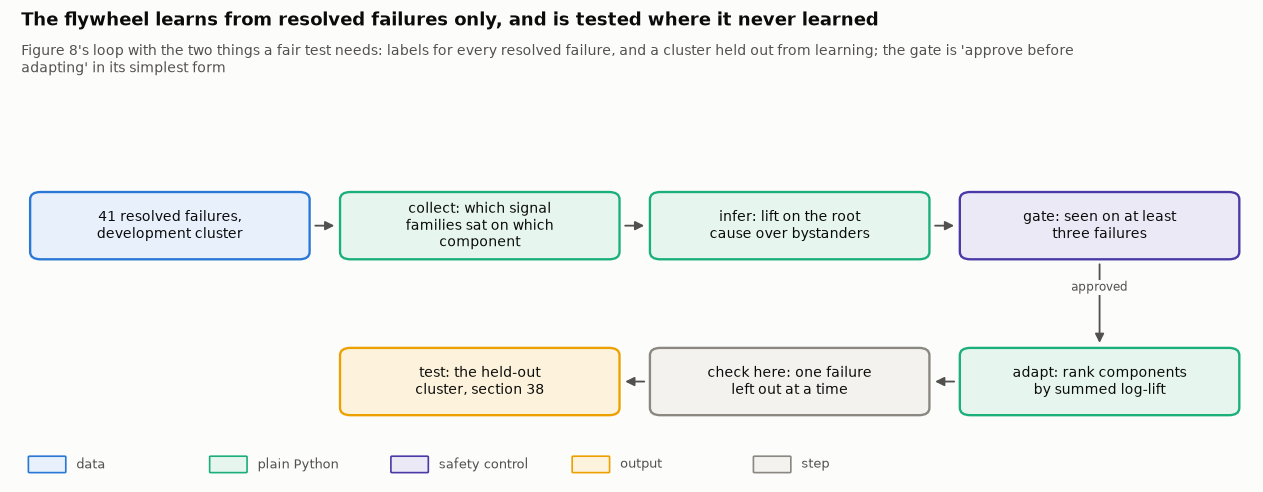

In [180]:
# ---- our flywheel, drawn: collect, infer behind a gate, adapt, and a test on a cluster it never saw ----
FLY_FLOW = {
    "resolved": (1.35, 3.1, f"{len(COLLECTED)} resolved failures,\ndevelopment cluster", "data"),
    "collect": (4.0, 3.1, "collect: which signal\nfamilies sat on which\ncomponent", "code"),
    "infer": (6.65, 3.1, "infer: lift on the root\ncause over bystanders", "code"),
    "gate": (9.3, 3.1, "gate: seen on at least\nthree failures", "guard"),
    "adapt": (9.3, 1.2, "adapt: rank components\nby summed log-lift", "code"),
    "loo": (6.65, 1.2, "check here: one failure\nleft out at a time", "step"),
    "test": (4.0, 1.2, "test: the held-out\ncluster, section 38", "output"),
}
FLY_EDGES = [("resolved", "collect", None), ("collect", "infer", None), ("infer", "gate", None),
             ("gate", "adapt", "approved"), ("adapt", "loo", None), ("loo", "test", None)]
draw_flow(FLY_FLOW, FLY_EDGES, "flywheel_ours",
          "The flywheel learns from resolved failures only, and is tested where it never learned",
          "Figure 8's loop with the two things a fair test needs: labels for every resolved failure, and a cluster held "
          "out from learning; the gate is 'approve before adapting' in its simplest form", size=(10.6, 4.2),
          box=(2.35, 0.78))

In [181]:
# ---- Infer: which features sit on root causes more than on bystanders (lift, with a floor of evidence) ----
def infer(collected: list, min_support: int = 3) -> dict[str, float]:
    on_root, on_other, n_root, n_other = Counter(), Counter(), 0, 0
    for _, feats, want in collected:
        for comp, fs in feats.items():
            if comp in want:
                n_root += 1
                on_root.update(fs)
            else:
                n_other += 1
                on_other.update(fs)
    lift = {}
    for f in sorted(set(on_root) | set(on_other)):
        p_root = (on_root[f] + 0.5) / (n_root + 1)
        p_other = (on_other[f] + 0.5) / (n_other + 1)
        if on_root[f] >= min_support:                     # a pattern seen fewer than three times is not knowledge yet
            lift[f] = p_root / p_other
    return lift


LIFT = infer(COLLECTED)
print(f"  {'feature':<26}{'lift':>7}   reading")
for f, l in sorted(LIFT.items(), key=lambda x: (-x[1], x[0]))[:8]:
    print(f"  {f:<26}{l:>7.2f}   on the root cause {l:.1f}x as often as on a bystander")

  feature                      lift   reading
  log_error                   10.30   on the root cause 10.3x as often as on a bystander
  metric:latency               8.74   on the root cause 8.7x as often as on a bystander
  metric:process               8.73   on the root cause 8.7x as often as on a bystander
  metric:other                 5.76   on the root cause 5.8x as often as on a bystander
  trace_slow                   4.19   on the root cause 4.2x as often as on a bystander
  metric:memory                3.08   on the root cause 3.1x as often as on a bystander
  metric:cpu                   2.89   on the root cause 2.9x as often as on a bystander
  metric:network               1.62   on the root cause 1.6x as often as on a bystander


  development cluster, one failure left out at a time:
    strongest signal (adapt off)          AC@1   4.9%   AC@3   4.9%
    learned lift, gated (support >= 3)    AC@1  29.3%   AC@3  51.2%
    learned lift, ungated (support >= 1)  AC@1  31.7%   AC@3  53.7%

  The gate is the post's 'approve before adapting' step in its simplest form: a pattern must be seen on
  three resolved failures before it may change a ranking.


[fig] artifacts\figures_full\flywheel_dev.png


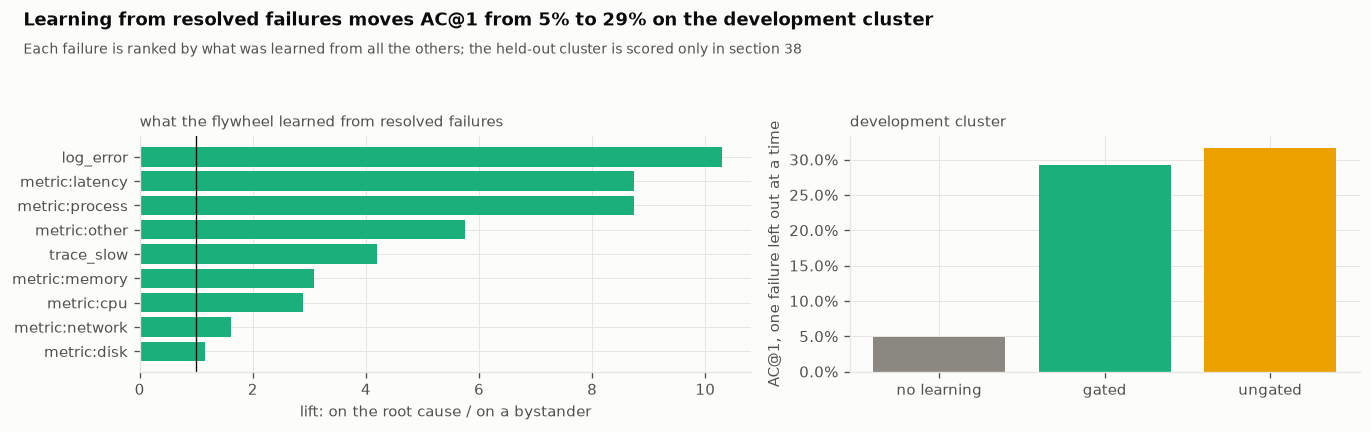

In [182]:
# ---- Adapt: rank with what was learned, and check it with one failure left out at a time ----
def rank_learned(feats: dict, lift: dict) -> list[str]:
    # summed in sorted order and tied by name, so the ranking cannot depend on the order a set is kept in
    score = {c: sum(np.log(lift[f]) for f in sorted(fs) if f in lift and lift[f] > 1) for c, fs in feats.items()}
    return [c for c, s in sorted(score.items(), key=lambda x: (-x[1], x[0]))]


def loo(collected: list, min_support: int = 3, ks=(1, 3)) -> dict:
    hits = Counter()
    for i, (_, feats, want) in enumerate(collected):
        lift = infer(collected[:i] + collected[i + 1:], min_support)       # never learn from the case being ranked
        ranked = rank_learned(feats, lift)
        for k in ks:
            hits[k] += any(w in ranked[:k] for w in want)
    return {f"AC@{k}": hits[k] / max(len(collected), 1) for k in ks}


FLYWHEEL_DEV = {"strongest signal (adapt off)": CORR_DEV["strongest signal"],
                "learned lift, gated (support >= 3)": loo(COLLECTED, 3),
                "learned lift, ungated (support >= 1)": loo(COLLECTED, 1)}
print(f"  development cluster, one failure left out at a time:")
for k, v in FLYWHEEL_DEV.items():
    print(f"    {k:<38}AC@1 {v['AC@1']:6.1%}   AC@3 {v['AC@3']:6.1%}")
print("\n  The gate is the post's 'approve before adapting' step in its simplest form: a pattern must be seen on")
print("  three resolved failures before it may change a ranking.")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw={"width_ratios": [1.2, 1]})
top_l = sorted(LIFT.items(), key=lambda x: -x[1])[:10]
axes[0].barh([f for f, _ in top_l], [l for _, l in top_l], color=[C3 if l > 1 else MUTED for _, l in top_l])
axes[0].axvline(1, color=INK, lw=0.8)
axes[0].invert_yaxis()
axes[0].set_xlabel("lift: on the root cause / on a bystander")
axes[0].set_title("what the flywheel learned from resolved failures", fontsize=9, color=INK2, loc="left")
names_fw = list(FLYWHEEL_DEV)
axes[1].bar(range(len(names_fw)), [FLYWHEEL_DEV[k]["AC@1"] for k in names_fw], color=[MUTED, C3, C4])
axes[1].set_xticks(range(len(names_fw)), ["no learning", "gated", "ungated"])
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[1].set_ylabel("AC@1, one failure left out at a time")
axes[1].set_title("development cluster", fontsize=9, color=INK2, loc="left")
finish(fig, "flywheel_dev", f"Learning from resolved failures moves AC@1 from {FLYWHEEL_DEV[names_fw[0]]['AC@1']:.0%} to "
       f"{FLYWHEEL_DEV[names_fw[1]]['AC@1']:.0%} on the development cluster",
       "Each failure is ranked by what was learned from all the others; the held-out cluster is scored only in section 38")

In [183]:
# ---- figure 9 on our own graph: from chains to a counted rule ----
WISDOM = Counter()
for _, feats, want in COLLECTED:
    # once per failure: a failure whose answer names a pod and its service would otherwise count twice
    WISDOM.update(set().union(*(set(feats.get(w, ())) for w in want)) if want else set())


def most_counted(counter: Counter) -> tuple[str, int]:
    """The commonest feature, ties broken by name: most_common keeps them in the order a set happened to give."""
    return min(counter.items(), key=lambda x: (-x[1], x[0])) if counter else ("none", 0)


top, n_top = most_counted(WISDOM)
best = max(LIFT, key=LIFT.get) if LIFT else "none"
print(f"  data         {len(LAB_SIGNALS[LAB_SIGNALS.system == 'market_cb1']):,} signal minutes in the development cluster")
print(f"  information  {sum(len(f) for _, f, _ in COLLECTED):,} component-window feature sets")
print(f"  knowledge    {len(LIFT)} features whose lift was learned from at least three resolved failures")
print(f"  wisdom       '{top}' sat on the root cause in {n_top} of {len(COLLECTED)} development failures "
      f"({n_top / max(len(COLLECTED), 1):.0%}), the shape of figure 9's '40% of SEV-2s'")
print(f"  and its lift over bystanders is {LIFT.get(top, float('nan')):.1f}; the most telling feature, '{best}', "
      f"has a lift of {LIFT.get(best, float('nan')):.1f} and sits on the root cause in {WISDOM[best]} failures")
print("  A count like figure 9's says how often something was there, not whether it tells causes from bystanders.")

  data         274,932 signal minutes in the development cluster
  information  3,945 component-window feature sets
  knowledge    9 features whose lift was learned from at least three resolved failures
  wisdom       'metric:disk' sat on the root cause in 39 of 41 development failures (95%), the shape of figure 9's '40% of SEV-2s'
  and its lift over bystanders is 1.2; the most telling feature, 'log_error', has a lift of 10.3 and sits on the root cause in 3 failures
  A count like figure 9's says how often something was there, not whether it tells causes from bystanders.


[fig] artifacts\figures_full\count_vs_lift.png


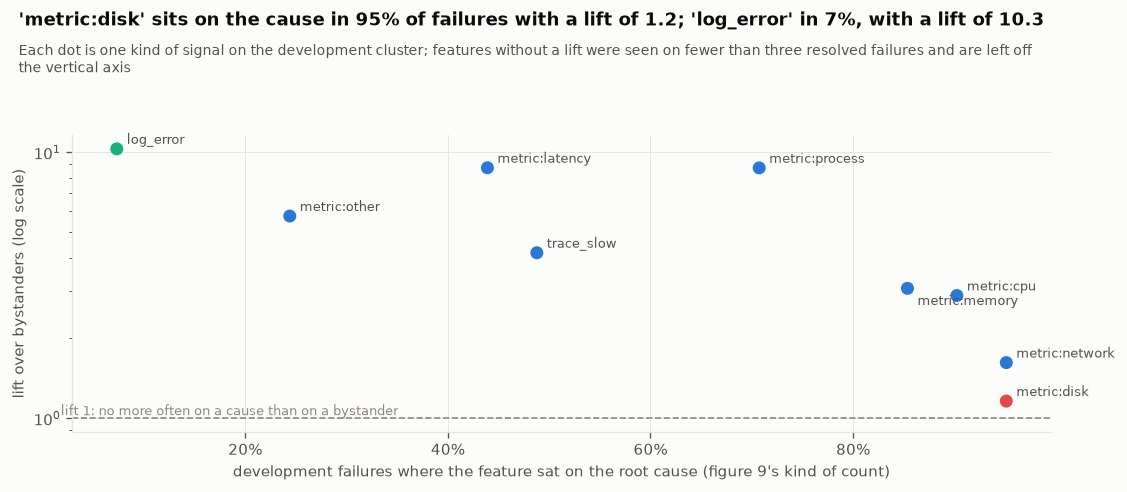

In [184]:
# ---- the counted rule against the telling one, drawn: how often a feature sits on the cause, and how much it says ----
feat_ = sorted(set(WISDOM) | set(LIFT))
counted, n_counted = most_counted(WISDOM)                                      # the count figure 9 would report
telling = max(LIFT, key=LIFT.get) if LIFT else "none"                         # the feature that tells the most
fig, ax = plt.subplots(figsize=(9.5, 4.2))
xs_ = [WISDOM[f] / max(len(COLLECTED), 1) for f in feat_]
ys_ = [LIFT.get(f, np.nan) for f in feat_]
ax.scatter(xs_, ys_, s=46, color=[C3 if f == telling else C8 if f == counted else C1 for f in feat_], zorder=3)
placed = []
for f, x, y in zip(feat_, xs_, ys_):
    if y == y:                          # a label close to one already placed goes below its dot instead of above
        near = any(abs(x - px) < 0.08 and abs(np.log10(y / py)) < 0.08 for px, py in placed)
        ax.annotate(f, (x, y), textcoords="offset points", xytext=(6, -10 if near else 3), fontsize=7.5, color=INK2)
        placed.append((x, y))
ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.text(0.01, 1, "  lift 1: no more often on a cause than on a bystander", color=MUTED, fontsize=7.5, va="bottom")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_xlabel("development failures where the feature sat on the root cause (figure 9's kind of count)")
ax.set_ylabel("lift over bystanders (log scale)")
finish(fig, "count_vs_lift", f"'{counted}' sits on the cause in {n_counted / max(len(COLLECTED), 1):.0%} of failures with "
       f"a lift of {LIFT.get(counted, float('nan')):.1f}; '{telling}' in {WISDOM[telling] / max(len(COLLECTED), 1):.0%}, "
       f"with a lift of {LIFT.get(telling, float('nan')):.1f}",
       "Each dot is one kind of signal on the development cluster; features without a lift were seen on fewer than "
       "three resolved failures and are left off the vertical axis")

**Learning from 40 resolved failures puts the right component first for 29% of the one left out,
where the loudest signal managed 4.9%.** Each development failure is ranked by what the other 40
taught, so no failure ever grades its own lesson. The right component lands in the top three for
51%, against 4.9% before anything was learned. The lessons are kinds of signal, not magnitudes,
which sidesteps the flat-baseline problem of section 25: an error burst in the logs sits on a
cause 10.3 times as often as on a bystander, latency and process metrics 8.7 times, slow spans 4.2
times, network metrics only 1.6 times. The gate that makes a pattern wait for three resolved
failures before it may change a ranking costs a little here, 29.3% first against 31.7% without
it. On a cluster this small that is the expected price of not acting on coincidences; whether the
price buys anything is the question section 38 answers, when these lessons meet the second
cluster's failures, which they were not learned from.

## 28 · Specialists that use tools

**Theory.** Figure 10 is the post's AutoRCA: when an alert fires, specialist agents for metrics,
traces, events, logs, chat and code each examine their part of the evidence, and a reconciler
turns their findings into ranked hypotheses. Two design choices make or break such a system. The
first is what the agents read: Netflix's answer is the graph, already joined and typed, rather than
raw text. The second is how much freedom they get: an agent that may call any tool forever is slow,
expensive and hard to audit. Our specialists are small: one language model each, three or four
tools that read the graph or the Parquet files, at most three rounds of tool use (a round may ask
for several tools at once), then one last turn with the tools taken away, and an answer in a
fixed shape that must cite the evidence it rests on. First we need the ruler they will be held
to, the benchmark's own scorer. World: OpenRCA for the specialists built here; section 31 adds
Wikimedia.

[fig] artifacts\figures_full\autorca_ours.png


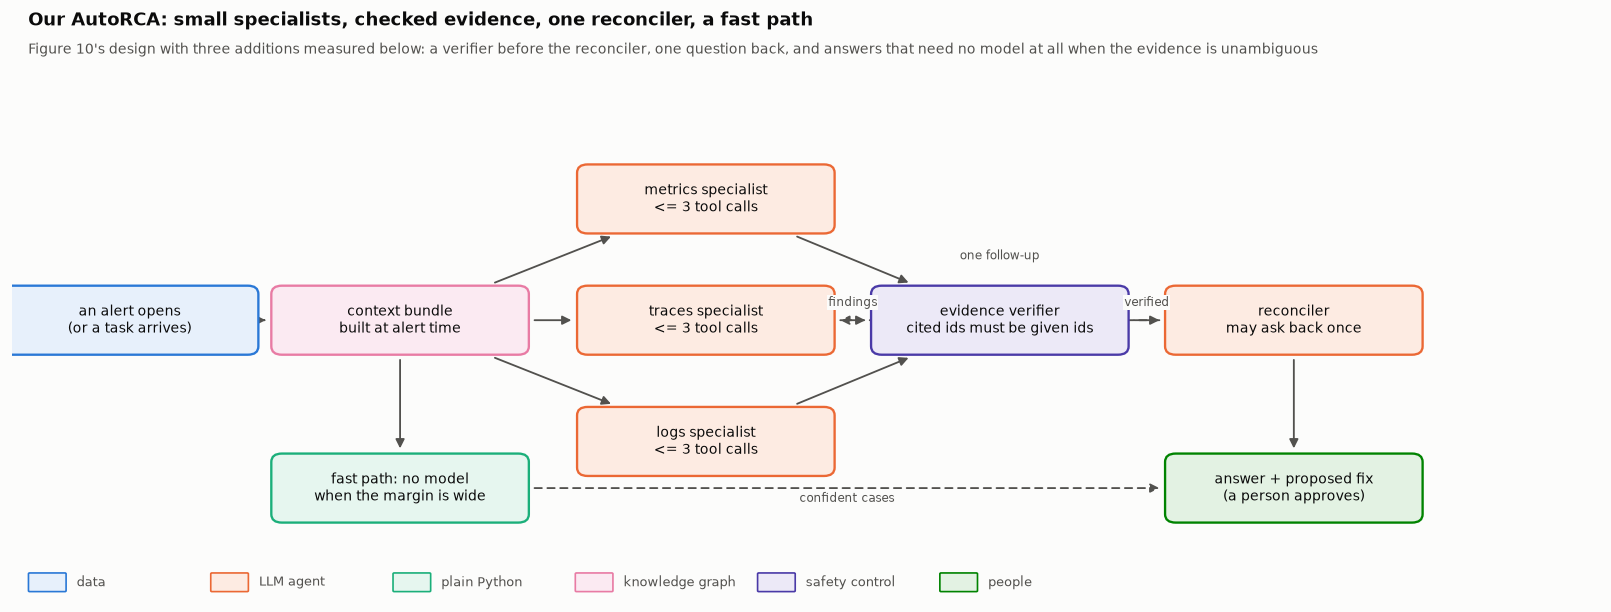

In [185]:
# ---- the system we are about to build, on one page ----
RCA_NODES = {
    "alert": (1.0, 3.0, "an alert opens\n(or a task arrives)", "data"),
    "bundle": (3.3, 3.0, "context bundle\nbuilt at alert time", "graph"),
    "metrics": (5.9, 4.3, "metrics specialist\n<= 3 tool calls", "llm"),
    "traces": (5.9, 3.0, "traces specialist\n<= 3 tool calls", "llm"),
    "logs": (5.9, 1.7, "logs specialist\n<= 3 tool calls", "llm"),
    "verify": (8.4, 3.0, "evidence verifier\ncited ids must be given ids", "guard"),
    "recon": (10.9, 3.0, "reconciler\nmay ask back once", "llm"),
    "answer": (10.9, 1.2, "answer + proposed fix\n(a person approves)", "human"),
    "fast": (3.3, 1.2, "fast path: no model\nwhen the margin is wide", "code"),
}
RCA_EDGES = [("alert", "bundle", None), ("bundle", "metrics", None), ("bundle", "traces", None), ("bundle", "logs", None),
             ("metrics", "verify", None), ("traces", "verify", "findings"), ("logs", "verify", None),
             ("verify", "recon", "verified"), ("recon", "traces", "one follow-up", "dashed", (0.0, 0.5)),
             ("recon", "answer", None), ("bundle", "fast", None), ("fast", "answer", "confident cases", "dashed", (0.0, -0.3))]
draw_flow(RCA_NODES, RCA_EDGES, "autorca_ours", "Our AutoRCA: small specialists, checked evidence, one reconciler, a fast path",
          "Figure 10's design with three additions measured below: a verifier before the reconciler, one question back, "
          "and answers that need no model at all when the evidence is unambiguous", size=(13.5, 5.2), box=(2.15, 0.7))

In [186]:
# ---- the benchmark's ruler: strict and partial scores, exactly as a task's scoring points define them ----
def scoring_items(scoring_points: str) -> list[dict]:
    """One dict per failure the task asks about: the component, reason and time it must get right."""
    comps = re.findall(r"root cause component is ([\w.\-]+)", scoring_points)
    reasons = [r.strip() for r in re.findall(r"root cause reason is ([^\n]+)", scoring_points)]
    times = re.findall(r"of (\d{4}-\d\d-\d\d \d\d:\d\d:\d\d)", scoring_points)
    n = max(len(comps), len(reasons), len(times), 1)
    return [{k: v[i] for k, v in (("component", comps), ("reason", reasons), ("time", times)) if i < len(v)}
            for i in range(n)]


def score_answer(answer: list[dict], scoring_points: str) -> tuple[float, bool]:
    """(partial, strict). Failures may be answered in any order, so the best matching is used."""
    want = scoring_items(scoring_points)
    total = sum(len(w) for w in want)
    if not total:
        return 0.0, False

    def matched(pred: dict, w: dict) -> int:
        m = 0
        if "component" in w and str(pred.get("component", "")).strip() == w["component"]:
            m += 1
        if "reason" in w and str(pred.get("reason", "")).strip().lower() == w["reason"].lower():
            m += 1
        if "time" in w:
            try:
                gap = abs((pd.Timestamp(str(pred.get("datetime"))) - pd.Timestamp(w["time"])).total_seconds())
                m += gap <= 60
            except (ValueError, TypeError):
                pass
        return m

    best = 0
    preds = list(answer or [])[:len(want) + 2]
    for perm in itertools.permutations(range(len(preds)), min(len(preds), len(want))):
        best = max(best, sum(matched(preds[p], w) for p, w in zip(perm, want)))
    return best / total, best == total


R0 = OPENRCA_RECORDS.iloc[0]
pts = TASKS.loc[TASKS.system == R0.system].iloc[0].scoring_points
SCORE_CASES = [
    ("right in every part", [{"datetime": scoring_items(pts)[0].get("time", ""), "component": scoring_items(pts)[0].get("component", ""),
                              "reason": scoring_items(pts)[0].get("reason", "")}], 1.0),
    ("no answer", [], 0.0),
]
for name, ans, want_partial in SCORE_CASES:
    p, s = score_answer(ans, pts)
    print(f"  {'PASS' if abs(p - want_partial) < 1e-9 else 'FAIL'}  {name:<22}partial {p:.2f}  strict {s}")
wrong_time = [{"datetime": "2000-01-01 00:00:00", **{k: v for k, v in scoring_items(pts)[0].items() if k != "time"}}]
print(f"  a wrong time with the rest right scores {score_answer(wrong_time, pts)[0]:.2f} partial, strict "
      f"{score_answer(wrong_time, pts)[1]}  ({len(scoring_items(pts)[0])} criteria in this task)")

  PASS  right in every part   partial 1.00  strict True
  PASS  no answer             partial 0.00  strict False
  a wrong time with the rest right scores 0.00 partial, strict False  (1 criteria in this task)


In [187]:
# ---- the tools: small, typed, and every row they return carries an id an agent can cite ----
VOCAB = {s: {"components": sorted(g.component.unique()), "reasons": sorted(g.reason.unique())}
         for s, g in OPENRCA_RECORDS.groupby("system")}        # the lists the benchmark itself gives its agents


def utc8(ts) -> str:
    return pd.Timestamp(ts).tz_convert(UTC8).strftime("%Y-%m-%d %H:%M:%S")


class LabTools:
    """What a specialist may ask about one task window. Rows carry ids; only ids returned here may be cited."""

    def __init__(self, task: pd.Series):
        self.task, self.system = task, task.system
        d = LAB_SIGNALS[LAB_SIGNALS.task_id == task.task_id].copy()
        d["family"] = [kpi_family(k) if kd == "METRIC_ANOMALY" else kd.lower() for kd, k in zip(d.kind, d.kpi)]
        d["id"] = [f"s{i}" for i in range(len(d))]
        self.sig = d
        self.given: set[str] = set()                         # every id handed out, for the evidence verifier

    def _rows(self, d: pd.DataFrame, k: int) -> list[dict]:
        d = d.sort_values("strength", ascending=False).head(k)
        self.given |= set(d.id)
        return [{"id": r.id, "entity": r.entity, "components": components_of(self.system, r.entity), "kind": r.kind,
                 "family": r.family, "minute": utc8(r.minute), "strength": round(float(r.strength), 1)}
                for r in d.itertuples()]

    def top_anomalies(self, kind: str = "any", k: int = 12) -> list[dict]:
        d = self.sig if kind == "any" else self.sig[self.sig.kind == kind]
        return self._rows(d.sort_values("strength", ascending=False).drop_duplicates(["entity", "family"]), k)

    def component_signals(self, component: str, k: int = 12) -> list[dict]:
        mask = [component in components_of(self.system, e) for e in self.sig.entity]
        return self._rows(self.sig[mask], k)

    def first_anomaly(self, component: str) -> dict:
        mask = [component in components_of(self.system, e) for e in self.sig.entity]
        d = self.sig[mask].sort_values("minute")
        if d.empty:
            return {"component": component, "first": None}
        self.given.add(d.id.iloc[0])
        return {"component": component, "first": utc8(d.minute.iloc[0]), "id": d.id.iloc[0], "family": d.family.iloc[0]}

    def neighbours(self, component: str) -> dict:
        callers = sorted(CALLERS.get((self.system, component), set()))
        callees = sorted({c for (s, c), ups in CALLERS.items() if s == self.system and component in ups})
        return {"component": component, "called_by": callers[:15], "calls": callees[:15]}

    SPEC = {
        "top_anomalies": ("The strongest anomalies in the window. kind: any, METRIC_ANOMALY, TRACE_SLOW, TRACE_FAILED or "
                          "LOG_ERROR.", {"kind": {"type": "string"}, "k": {"type": "integer"}}, []),
        "component_signals": ("Every anomaly on one component, strongest first.",
                              {"component": {"type": "string"}, "k": {"type": "integer"}}, ["component"]),
        "first_anomaly": ("When the first anomaly on a component appeared.", {"component": {"type": "string"}}, ["component"]),
        "neighbours": ("Which components call this one and which it calls, from the traces.",
                       {"component": {"type": "string"}}, ["component"]),
    }

    def schema(self, names: list[str]) -> list[dict]:
        return [{"type": "function", "function": {"name": n, "description": self.SPEC[n][0],
                 "parameters": {"type": "object", "properties": self.SPEC[n][1], "required": self.SPEC[n][2]}}}
                for n in names]

    def call(self, name: str, args: dict):
        if name not in self.SPEC:
            return {"error": f"no tool {name}"}
        try:
            return getattr(self, name)(**{k: v for k, v in args.items() if k in self.SPEC[name][1]})
        except Exception as e:                                  # a bad argument is an answer the agent can read
            return {"error": f"{type(e).__name__}: {e}"}


flag_task = TASKS[(TASKS.system == FLAG_SYSTEM) & (TASKS.ws <= FLAGSHIP_FAILURE.ts_utc) &
                  (TASKS.we > FLAGSHIP_FAILURE.ts_utc)].iloc[0] if FLAGSHIP_FAILURE is not None else DEV.iloc[0]
tools = LabTools(flag_task)
print(f"  the running example's task {flag_task.task_id} ({flag_task.task_index}): {len(tools.sig):,} signal minutes in its window")
for row in tools.top_anomalies(k=4):
    print(f"    {row}")
print(f"    {tools.neighbours('cartservice')}")

  the running example's task market_cb1-195 (task_7): 7,465 signal minutes in its window
    {'id': 's2671', 'entity': 'frontend-2.destination.unknown.frontend', 'components': ['destination.unknown.frontend', 'destination.unknown.frontend', 'frontend-2'], 'kind': 'METRIC_ANOMALY', 'family': 'disk', 'minute': '2022-03-21 15:49:00', 'strength': 512250000000.0}
    {'id': 's6004', 'entity': 'frontend-2.source.frontend.cartservice', 'components': ['source.frontend.cartservice', 'source.frontend.cartservice', 'frontend-2'], 'kind': 'METRIC_ANOMALY', 'family': 'disk', 'minute': '2022-03-21 15:49:00', 'strength': 505750000000.0}
    {'id': 's5963', 'entity': 'frontend-1.destination.unknown.frontend', 'components': ['destination.unknown.frontend', 'destination.unknown.frontend', 'frontend-1'], 'kind': 'METRIC_ANOMALY', 'family': 'disk', 'minute': '2022-03-21 15:48:00', 'strength': 494800000000.0}
    {'id': 's6935', 'entity': 'frontend-1.source.frontend.cartservice', 'components': ['source.fro

  7,465 signal minutes on 182 entities; loudest first: frontend-2.destination.unknown.frontend, frontend-2.source.frontend.cartservice, frontend-1.destination.unknown.frontend, frontend-1.source.frontend.cartservice, frontend-0.destination.unknown.frontend
  the answer key's component, cartservice, is number 38 of 182 by its loudest signal


[fig] artifacts\figures_full\running_example_signals.png


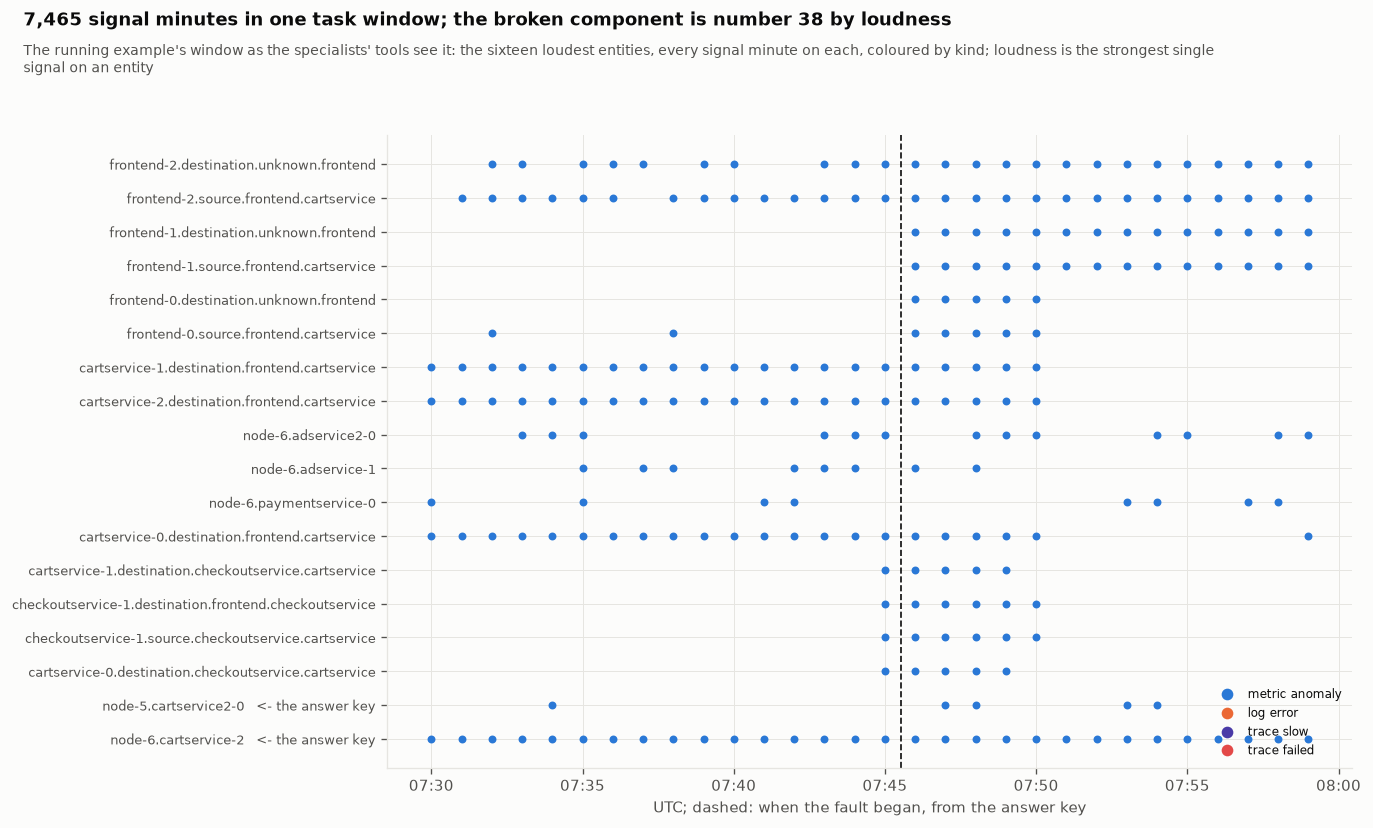

In [188]:
# ---- the running example's window, signal by signal: the haystack the specialists search ----
loud = tools.sig.groupby("entity").strength.max().sort_values(ascending=False)
truth = FLAGSHIP_FAILURE.component if FLAGSHIP_FAILURE is not None else None
hit = [e for e in loud.index if truth in components_of(FLAG_SYSTEM, e)]
rank = list(loud.index).index(hit[0]) + 1 if hit else None
show = list(loud.index[:16]) + [e for e in hit if e not in set(loud.index[:16])][:2]
kind_colour = {"METRIC_ANOMALY": C1, "LOG_ERROR": C2, "TRACE_SLOW": C7, "TRACE_FAILED": C8}
fig, ax = plt.subplots(figsize=(11.5, 0.3 * len(show) + 1.6))
for i, e in enumerate(show):
    d = tools.sig[tools.sig.entity == e]
    for kind, colour in kind_colour.items():
        dk = d[d.kind == kind].drop_duplicates("minute")
        ax.scatter(dk.minute.dt.tz_convert(None), [i] * len(dk), s=14, color=colour)
if FLAGSHIP_FAILURE is not None:
    ax.axvline(pd.Timestamp(FLAGSHIP_FAILURE.ts_utc).tz_convert(None), color=INK, ls="--", lw=1)
ax.set_yticks(range(len(show)), [f"{e}{'   <- the answer key' if e in hit else ''}" for e in show], fontsize=7.5)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("UTC; dashed: when the fault began, from the answer key")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k.lower().replace("_", " "))
                   for k, c in kind_colour.items()], fontsize=7, loc="lower right")
print(f"  {len(tools.sig):,} signal minutes on {len(loud)} entities; loudest first: {', '.join(loud.index[:5])}")
print(f"  the answer key's component, {truth}, is "
      f"{'number ' + str(rank) + ' of ' + str(len(loud)) + ' by its loudest signal' if rank else 'never flagged'}")
finish(fig, "running_example_signals",
       f"{len(tools.sig):,} signal minutes in one task window; the broken component is "
       f"{'number ' + str(rank) + ' by loudness' if rank else 'never flagged'}",
       "The running example's window as the specialists' tools see it: the sixteen loudest entities, every signal minute "
       "on each, coloured by kind; loudness is the strongest single signal on an entity")

In [189]:
# ---- one specialist: a model, a few tools, at most three rounds of them, and an answer with evidence ----
SPECIALISTS = {
    "metrics": (["top_anomalies", "component_signals", "first_anomaly"],
                "You are the metrics specialist. Look at metric anomalies only (kind METRIC_ANOMALY)."),
    "traces": (["top_anomalies", "neighbours", "first_anomaly"],
               "You are the traces specialist. Look at slow and failed spans (TRACE_SLOW, TRACE_FAILED) and at who calls "
               "whom: a slow caller is often a victim of a slow callee."),
    "logs": (["top_anomalies", "component_signals"],
             "You are the logs specialist. Look at bursts of error lines (LOG_ERROR)."),
}
FINDING_FORMAT = ('Finish with one JSON object and nothing else: {"hypotheses": [{"component": one of the allowed components, '
                  '"reason": one of the allowed reasons, "datetime": "YYYY-MM-DD HH:MM:SS" in UTC+8, '
                  '"evidence": [ids returned by your tools], "confidence": a number from 0 to 1}]}, best first, at most 3.')


@dataclass
class Finding:
    specialist: str
    hypotheses: list
    tool_calls: list
    calls: int
    cost: float
    latency_s: float
    ok: bool


def run_specialist(role: str, tools, question: str, max_tool_calls: int = 3, model: str | None = None,
                   roster: dict | None = None, fmt: str | None = None, allowed: str | None = None) -> Finding:
    names, brief = (roster or SPECIALISTS)[role]
    fmt = fmt or FINDING_FORMAT
    if allowed is None:
        v = VOCAB[tools.system]
        allowed = f"Allowed components: {v['components']}. Allowed reasons: {v['reasons']}."
    system = (f"{brief} You investigate one failure in the system '{tools.system}'. {allowed} "
              "Use the tools; cite only ids they return. " + fmt)
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    trail, cost, latency, calls = [], 0.0, 0.0, 0
    for step in range(max_tool_calls + 1):
        last = step == max_tool_calls
        r = LLM.chat(model or QWEN["flash"], msgs + ([{"role": "user", "content": "No more tools. " + fmt}]
                                                    if last else []),
                     agent=f"specialist-{role}", json_mode=False, tools=None if last else tools.schema(names),
                     max_tokens=700)
        calls += 1
        cost += r.cost
        latency += r.latency_s
        if not r.ok:
            break
        if r.tool_calls and not last:
            msgs.append({"role": "assistant", "content": r.text or "", "tool_calls": r.tool_calls})
            for tc in r.tool_calls:
                fn = tc.get("function", {})
                try:
                    args = json.loads(fn.get("arguments") or "{}")
                except json.JSONDecodeError:
                    args = {}
                result = tools.call(fn.get("name", ""), args)
                trail.append((fn.get("name"), args))
                msgs.append({"role": "tool", "tool_call_id": tc.get("id", fn.get("name", "")),
                             "content": json.dumps(result, default=str)[:6000]})
            continue
        data = parse_json_reply(r.text)
        hyps = data.get("hypotheses", []) if isinstance(data, dict) else []
        return Finding(role, hyps[:3], trail, calls, cost, latency, bool(hyps))
    return Finding(role, [], trail, calls, cost, latency, False)


def question_for(task: pd.Series) -> str:
    return (f"{task.instruction}\nThe window is {utc8(task.ws)} to {utc8(task.we)} (UTC+8). "
            "Find the root cause with your tools.")


with phase("AutoRCA development"):
    demo_findings = {role: run_specialist(role, LabTools(flag_task), question_for(flag_task)) for role in SPECIALISTS}
for role, f in demo_findings.items():
    top = f.hypotheses[0] if f.hypotheses else {}
    print(f"  {role:<8} {f.calls} model turns, {len(f.tool_calls)} tool uses {[t[0] for t in f.tool_calls]}, "
          f"{f.latency_s:.1f}s of model time, {f.calls * QWEN_PRICE[QWEN['flash']]:.1f} Magicubes at list price")
    print(f"           -> {top.get('component')} / {top.get('reason')} at {top.get('datetime')} "
          f"(confidence {top.get('confidence')}, evidence {top.get('evidence')})")
print(f"  the answer key: {FLAGSHIP_FAILURE.component if FLAGSHIP_FAILURE is not None else '?'} / "
      f"{FLAGSHIP_FAILURE.reason if FLAGSHIP_FAILURE is not None else '?'} at "
      f"{utc8(FLAGSHIP_FAILURE.ts_utc) if FLAGSHIP_FAILURE is not None else '?'}")

  metrics  4 model turns, 7 tool uses ['top_anomalies', 'first_anomaly', 'first_anomaly', 'first_anomaly', 'first_anomaly', 'component_signals', 'top_anomalies'], 11.3s of model time, 0.8 Magicubes at list price
           -> node-6 / node memory consumption at 2022-03-21 15:48:00 (confidence 0.6, evidence ['s2558', 's111', 's4347', 's2560', 's110', 's109', 's2559'])
  traces   4 model turns, 5 tool uses ['top_anomalies', 'top_anomalies', 'top_anomalies', 'neighbours', 'first_anomaly'], 9.1s of model time, 0.8 Magicubes at list price
           -> cartservice-0 / container read I/O load at 2022-03-21 15:48:00 (confidence 0.7, evidence ['s7418', 's1495', 's5177', 's6004', 's5963', 's3000', 's4438', 's5147', 's3109'])
  logs     4 model turns, 6 tool uses ['top_anomalies', 'top_anomalies', 'component_signals', 'component_signals', 'component_signals', 'component_signals'], 11.0s of model time, 0.8 Magicubes at list price
           -> cartservice-0 / container read I/O load at 2022-03-21

[fig] artifacts\figures_full\specialist_traces.png


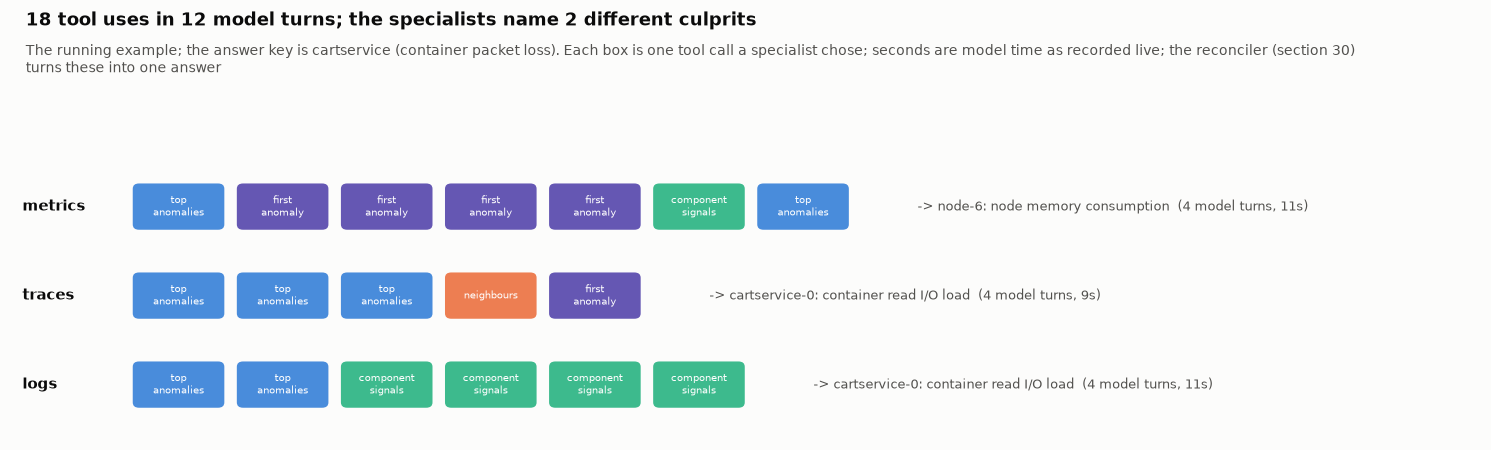

In [190]:
# ---- three specialists at work, drawn: each tool use in order, and what each concluded ----
fig, ax = plt.subplots(figsize=(12.5, 0.95 * len(demo_findings) + 1.0))
ax.axis("off")
width = max([len(f.tool_calls) for f in demo_findings.values()] + [0]) + 5
ax.set_xlim(-1.6, width + 0.5)
ax.set_ylim(-len(demo_findings) + 0.4, 0.8)
tool_colour = {"top_anomalies": C1, "component_signals": C3, "first_anomaly": C7, "neighbours": C2}
for i, (role, f) in enumerate(demo_findings.items()):
    y = -i
    ax.text(-1.5, y, role, fontsize=9, weight="bold", va="center", color=INK)
    for j, (name, args) in enumerate(f.tool_calls):
        ax.add_patch(FancyBboxPatch((j - 0.42, y - 0.24), 0.84, 0.48, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    fc=tool_colour.get(name, MUTED), ec="none", alpha=0.85))
        ax.text(j, y, str(name).replace("_", "\n"), fontsize=6, ha="center", va="center", color="white")
    top_ = f.hypotheses[0] if f.hypotheses else {}
    ax.text(len(f.tool_calls) + 0.1, y, f"-> {top_.get('component', 'no answer')}: {top_.get('reason', '')}  "
            f"({f.calls} model turns, {f.latency_s:.0f}s)", fontsize=8, va="center", color=INK2)
named = {f.hypotheses[0].get("component") for f in demo_findings.values() if f.hypotheses}
finish(fig, "specialist_traces",
       f"{sum(len(f.tool_calls) for f in demo_findings.values())} tool uses in "
       f"{sum(f.calls for f in demo_findings.values())} model turns; the specialists name {len(named)} different "
       f"culprit{'s' if len(named) != 1 else ''}",
       f"The running example; the answer key is {truth} "
       f"({FLAGSHIP_FAILURE.reason if FLAGSHIP_FAILURE is not None else '?'}). Each box is one tool call a specialist "
       "chose; seconds are model time as recorded live; the reconciler (section 30) turns these into one answer")

**Three specialists with a few typed tools each found the broken service in a window where it
ranks 38th of 182 by loudness: two of them named cartservice, and one of those within a minute
of the fault.** The running example's half hour holds 7,465 signal minutes, and its loudest
signals are disk measurements on frontend pods scoring near 5 x 10^11, the flat-baseline effect of
section 25. A ranking by loudness would have started there. The traces specialist did something
else: it asked for the strongest anomalies three times, then for the neighbours of cartservice,
then for its first anomaly, and concluded cartservice-0 at 15:48 with confidence 0.7. The logs
specialist reached the same pod at 15:46, against the answer key's 15:45:31. Both gave the
reason as read I/O load where the answer key says packet loss, and the metrics specialist settled
on node-6's memory. So the specialists disagree, as specialists should, and their mistakes are
of a kind a reader can see: every tool call is listed in order, and every signal they cite is an
id a tool returned, which is exactly what the next section checks.

## 29 · The evidence verifier

**Theory.** A language model asked to cite evidence will sometimes cite evidence it was never
shown, and the citation will look exactly like a real one. The defence is mechanical and cheap:
every id an agent cites must be one of the ids its own tools returned, every component and reason
must come from the benchmark's closed lists, and every time must fall inside the window. A
hypothesis that fails any check is removed before the reconciler sees it, and counted. We put
the verifier before the reconciler in the notebook because the reconciler should never read an
unverified claim. World: OpenRCA.

In [191]:
# ---- every citation checked against what the agent was actually given ----
def verify(f: Finding, tools: LabTools) -> tuple[list, Counter]:
    v, kept, why = VOCAB[tools.system], [], Counter()
    for h in f.hypotheses:
        cited = set(map(str, h.get("evidence") or []))
        if not cited:
            why["no evidence"] += 1
        elif not cited <= tools.given:
            why["cites evidence it was not given"] += 1
        elif h.get("component") not in v["components"]:
            why["component outside the list"] += 1
        elif h.get("reason") not in v["reasons"]:
            why["reason outside the list"] += 1
        else:
            try:
                t = pd.Timestamp(str(h.get("datetime"))).tz_localize(UTC8).tz_convert("UTC")
                inside = tools.task.ws - pd.Timedelta(minutes=5) <= t <= tools.task.we
            except (ValueError, TypeError):
                inside = False
            if not inside:
                why["time outside the window"] += 1
            else:
                kept.append(h)
    return kept, why


fake = Finding("metrics", [{"component": VOCAB[flag_task.system]["components"][0], "reason": VOCAB[flag_task.system]["reasons"][0],
                            "datetime": utc8(flag_task.ws + pd.Timedelta(minutes=3)), "evidence": ["s999999"],
                            "confidence": 0.9}], [], 0, 0, 0, True)
kept, why = verify(fake, LabTools(flag_task))
print(f"  [test] a hypothesis citing an id no tool returned is rejected -> {'PASS' if not kept else 'FAIL'} ({dict(why)})")
for role, f in demo_findings.items():
    t_ = LabTools(flag_task)
    for name, args in f.tool_calls:                          # replay the tool calls so 'given' is what it really saw
        t_.call(name, args)
    kept, why = verify(f, t_)
    print(f"  {role:<8} {len(f.hypotheses)} hypotheses, {len(kept)} pass, rejected: {dict(why) or 'none'}")

  [test] a hypothesis citing an id no tool returned is rejected -> PASS ({'cites evidence it was not given': 1})


  metrics  3 hypotheses, 3 pass, rejected: none
  traces   3 hypotheses, 3 pass, rejected: none


  logs     3 hypotheses, 3 pass, rejected: none


**The verifier rejects a citation that no tool returned, and in the running example all nine
hypotheses passed every check.** It is deliberately mechanical. A cited id must be one the
agent's own tools handed out, the component and the reason must come from the benchmark's lists,
and the time must sit inside the window; nothing here asks a model whether an answer seems right.
In this window the specialists stayed honest and nothing was removed, while the planted hypothesis
citing an id no tool had returned was caught. Section 31 counts what the verifier removes across
the development investigations, and part G across the test. The reason it sits before the
reconciler is simple: the most expensive model in the system never reads a claim that cannot be
traced to the evidence it came from.

## 30 · A reconciler that asks back

**Theory.** Specialists disagree, and they should: the traces specialist sees a slow frontend,
the metrics specialist sees a memory spike two hops away. The reconciler's job in Figure 10 is to
rank the hypotheses, and ours gets one extra power: it may send one follow-up question to one
specialist before it decides, the way an incident commander asks "is the memory spike before or
after the latency?". It is the most capable and most expensive model we use, Qwen3.8-Max, so it
runs once or twice per investigation, never in a loop. World: OpenRCA.

In [192]:
# ---- the reconciler: verified findings in, one answer out, with at most one question back ----
RECONCILE_FORMAT = ('Answer with one JSON object and nothing else: {"answer": [{"datetime": "YYYY-MM-DD HH:MM:SS", '
                    '"component": "...", "reason": "..."}], "confidence": 0 to 1, "ask": null or {"specialist": '
                    '"metrics" | "traces" | "logs", "question": "..."}}. One entry in answer per failure the task asks about.')


def reconcile(task: pd.Series, findings: dict, allow_ask: bool = True) -> dict:
    v = VOCAB[task.system]
    body = "\n".join(f"{role}: {json.dumps(kept, default=str)}" for role, kept in findings.items())
    system = (f"You lead a root-cause investigation in '{task.system}'. Specialists have reported verified hypotheses. "
              f"Allowed components: {v['components']}. Allowed reasons: {v['reasons']}. Prefer a cause that explains "
              f"the other findings (a callee that slows its callers). " + RECONCILE_FORMAT +
              ("" if allow_ask else ' Set "ask" to null.'))
    r = LLM.chat(QWEN["max"], [{"role": "system", "content": system},
                               {"role": "user", "content": f"{task.instruction}\n\nFindings:\n{body}"}],
                 agent="reconciler", max_tokens=600)
    d = r.data if isinstance(r.data, dict) else {}
    return {"answer": d.get("answer") or [], "confidence": d.get("confidence"), "ask": d.get("ask") if allow_ask else None,
            "cost": r.cost, "latency_s": r.latency_s}


def investigate(task: pd.Series, roles=tuple(SPECIALISTS), allow_ask: bool = True, model: str | None = None) -> dict:
    """Specialists in parallel, verify, reconcile, at most one follow-up, reconcile again."""
    t0 = time.perf_counter()
    toolsets = {role: LabTools(task) for role in roles}
    with ThreadPoolExecutor(len(roles)) as ex:
        found = dict(zip(roles, ex.map(lambda ro: run_specialist(ro, toolsets[ro], question_for(task), model=model), roles)))
    verified, rejected = {}, Counter()
    for role, f in found.items():
        kept, why = verify(f, toolsets[role])
        verified[role], rejected = kept, rejected + why
    rec = reconcile(task, verified, allow_ask)
    rec_s, asked = [rec["latency_s"]], None
    if rec["ask"] and isinstance(rec["ask"], dict) and rec["ask"].get("specialist") in roles:
        role = rec["ask"]["specialist"]
        f2 = run_specialist(role, toolsets[role], question_for(task) + "\nThe lead asks: " + str(rec["ask"].get("question")),
                            max_tool_calls=2, model=model)
        kept, why = verify(f2, toolsets[role])
        verified[role], rejected, asked = kept + verified[role], rejected + why, role
        found[role + "+"] = f2
        rec = reconcile(task, verified, allow_ask=False)
        rec_s.append(rec["latency_s"])
    cost = sum(f.cost for f in found.values()) + rec["cost"]          # what this run paid: nothing for a cached call
    list_cost = sum(f.calls for f in found.values()) * QWEN_PRICE[model or QWEN["flash"]] + len(rec_s) * QWEN_PRICE[QWEN["max"]]
    return {"task_id": task.task_id, "answer": rec["answer"], "confidence": rec["confidence"], "asked": asked,
            "rejected": sum(rejected.values()), "rejected_why": dict(rejected),
            "cost": cost, "list_cost": list_cost, "wall_s": time.perf_counter() - t0,
            "calls": sum(f.calls for f in found.values()) + 1 + (asked is not None),
            # model time as each call took it when made live; the cache keeps it, so replays still know it
            "model_s": {"specialists": {r: f.latency_s for r, f in found.items()}, "reconcile": rec_s}}


def critical_path_s(ms: dict) -> float:
    """Model time an investigation waits for with its specialists side by side, from the recorded call latencies."""
    first = [s for r, s in ms["specialists"].items() if not r.endswith("+")]
    again = [s for r, s in ms["specialists"].items() if r.endswith("+")]
    return (max(first) if first else 0.0) + sum(again) + sum(ms["reconcile"])


with phase("AutoRCA development"):
    FLAG_RCA = investigate(flag_task)
p, s = score_answer(FLAG_RCA["answer"], flag_task.scoring_points)
print(f"  {flag_task.task_id}: answer {FLAG_RCA['answer']}")
print(f"  confidence {FLAG_RCA['confidence']}, asked back: {FLAG_RCA['asked']}, rejected hypotheses {FLAG_RCA['rejected']}")
print(f"  score: partial {p:.2f}, strict {s}; {FLAG_RCA['calls']} model calls and "
      f"{critical_path_s(FLAG_RCA['model_s']):.0f}s of model time as recorded live (a rerun replays them from the cache "
      f"in {FLAG_RCA['wall_s']:.0f}s, at no cost)")

  market_cb1-195: answer [{'datetime': '2022-03-21 15:46:00', 'component': 'cartservice-0', 'reason': 'container read I/O load'}]
  confidence 0.7, asked back: None, rejected hypotheses 0
  score: partial 0.33, strict False; 13 model calls and 13s of model time as recorded live (a rerun replays them from the cache in 1s, at no cost)


**The reconciler turned the three findings into one answer that gets the time right and the
component half right: cartservice-0, a pod of the broken service, at 15:46.** It read the nine
verified hypotheses, went with the explanation two specialists shared, and answered with
confidence 0.7 without asking anything back. The benchmark gives that answer one criterion in
three. The time is within a minute of the fault; the answer names the pod where the key names the
service, and read I/O load where the key says packet loss. That ruler is strict, and it is the
right one: an engineer paged with "cartservice-0, disk" would look at the wrong thing first. The
whole investigation took 13 model calls and 13 seconds of model time when it was made live.

## 31 · Two incidents end to end

**Theory.** One investigation proves the plumbing, not the method. Here the agents work through a
sample of the development cluster's tasks under the benchmark's scorer, next to a baseline that
uses no language model at all: the topology chains of section 26 choose the component, its first
anomaly gives the time, and a fixed table from measurement families to the benchmark's reason
names gives the reason. That baseline is our version of the published "manual rules" arm, and it
costs nothing per investigation. Then the incident we follow at Wikimedia gets the same treatment
with the specialists that world needs: changes, alerts, chat and code. Worlds: OpenRCA and
Wikimedia.

In [193]:
# ---- the baseline with no model: chains pick the component, the first anomaly the time, a table the reason ----
FAMILY_REASON_WORDS = {"cpu": ["cpu"], "memory": ["memory", "oom"], "network": ["latency", "delay", "network"],
                       "latency": ["latency", "delay"], "disk": ["read i/o", "disk", "i/o"],
                       "process": ["process termination", "db close"], "errors": ["corruption", "loss"],
                       "trace_slow": ["latency", "delay"], "trace_failed": ["loss", "corruption"], "log_error": ["db close"]}


def reason_for(system: str, component: str, family: str) -> str:
    """The first reason in the benchmark's list whose words fit the family; node faults get node reasons."""
    reasons = VOCAB[system]["reasons"]
    node = component.startswith("node-")
    for word in FAMILY_REASON_WORDS.get(family, []):
        fits = [r for r in reasons if word in r.lower() and (r.lower().startswith("node") == node or not node)]
        if fits:
            return fits[0]
    return reasons[0]


def manual_answer(task: pd.Series) -> list[dict]:
    ranked = rank_task(task.task_id, task.system, "topology chains")
    if not ranked:
        return []
    comp = ranked[0]
    first = LabTools(task).first_anomaly(comp)
    return [{"component": comp, "datetime": first.get("first") or utc8(task.ws),
             "reason": reason_for(task.system, comp, first.get("family", ""))}]


p, s = score_answer(manual_answer(flag_task), flag_task.scoring_points)
print(f"  running example, no model: {manual_answer(flag_task)} -> partial {p:.2f}, strict {s}")

  running example, no model: [{'component': 'cartservice', 'datetime': '2022-03-21 15:30:00', 'reason': 'container memory load'}] -> partial 0.33, strict False


In [194]:
# ---- agents and baseline on a sample of development tasks, scored the benchmark's way ----
N_DEV = {"SMOKE": 2, "MEDIUM": 6}.get(PROFILE, 14)
dev_sample = DEV.sample(min(N_DEV, len(DEV)), random_state=SEED)
DEV_RUNS = []
with phase("AutoRCA development"):
    for task in dev_sample.itertuples():
        t = pd.Series(task._asdict())
        agent = investigate(t)
        pa, sa = score_answer(agent["answer"], t.scoring_points)
        pm, sm = score_answer(manual_answer(t), t.scoring_points)
        DEV_RUNS.append({"task": t.task_id, "type": t.task_index, "agent_partial": pa, "agent_strict": sa,
                         "manual_partial": pm, "manual_strict": sm, "calls": agent["calls"],
                         "model_s": critical_path_s(agent["model_s"]), "rejected": agent["rejected"],
                         "asked": agent["asked"]})
DEV_RUNS = pd.DataFrame(DEV_RUNS)
print(f"  {len(DEV_RUNS)} development tasks")
print(f"  {'':<26}{'partial':>9}{'strict':>8}")
print(f"  {'agents (Qwen)':<26}{DEV_RUNS.agent_partial.mean():>9.1%}{DEV_RUNS.agent_strict.mean():>8.1%}")
print(f"  {'no model (manual rules)':<26}{DEV_RUNS.manual_partial.mean():>9.1%}{DEV_RUNS.manual_strict.mean():>8.1%}")
print(f"  per investigation: median {DEV_RUNS.calls.median():.0f} model calls and {DEV_RUNS.model_s.median():.0f}s of "
      f"model time as recorded live; follow-up questions asked in {DEV_RUNS.asked.notna().mean():.0%}; hypotheses "
      f"rejected by the verifier {DEV_RUNS.rejected.sum()}")
print(f"  spent on development so far: {LEDGER.spent('qwen', 'AutoRCA development'):.1f} of "
      f"{QWEN_PHASES['AutoRCA development']} Magicubes")

  14 development tasks
                              partial  strict
  agents (Qwen)                 12.5%    7.1%
  no model (manual rules)        7.7%    0.0%
  per investigation: median 13 model calls and 16s of model time as recorded live; follow-up questions asked in 7%; hypotheses rejected by the verifier 7
  spent on development so far: 58.8 of 140 Magicubes


  task by task: the agents score higher on 2, lower on 2, the same on 10


[fig] artifacts\figures_full\dev_scores.png


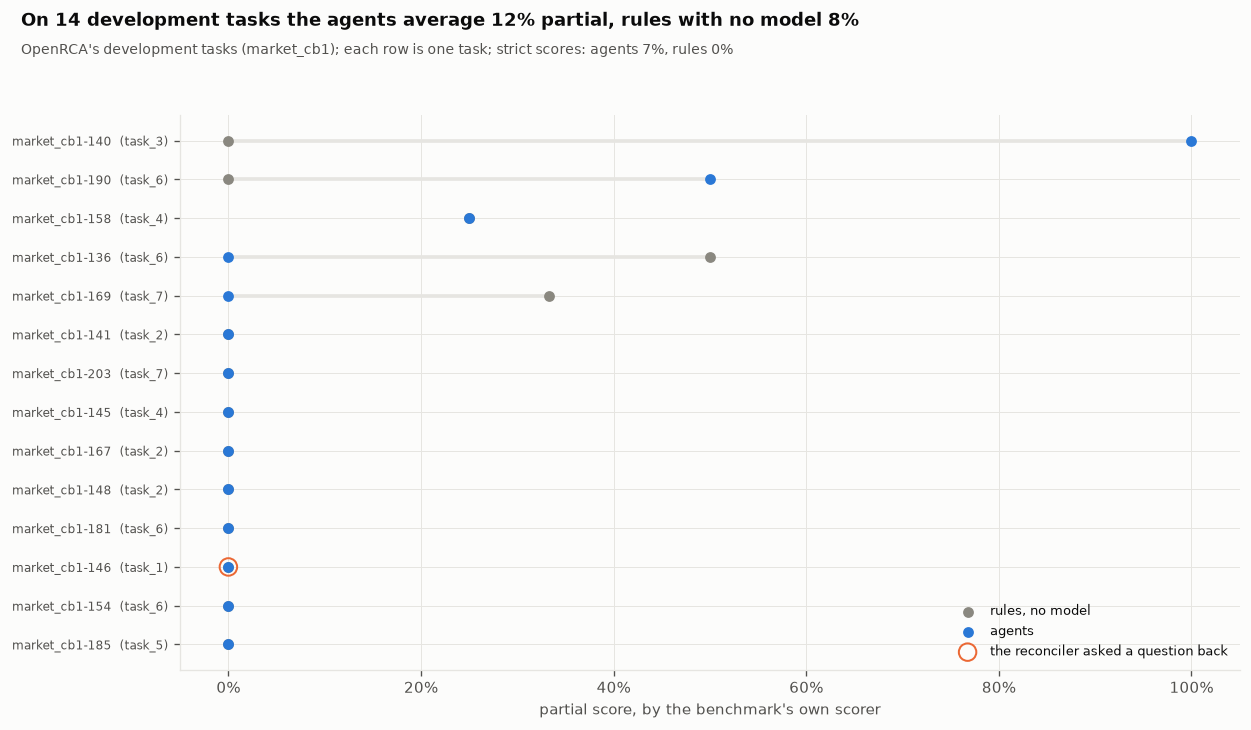

In [195]:
# ---- agents against rules with no model, task by task, drawn ----
if len(DEV_RUNS):
    d = DEV_RUNS.sort_values(["agent_partial", "manual_partial"]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10.5, 0.32 * len(d) + 1.7))
    for i, r in d.iterrows():
        ax.plot([r.manual_partial, r.agent_partial], [i, i], color=GRID, lw=2.2, zorder=1)
    ax.scatter(d.manual_partial, d.index, color=MUTED, s=30, zorder=2, label="rules, no model")
    ax.scatter(d.agent_partial, d.index, color=C1, s=30, zorder=3, label="agents")
    asked_ = d.asked.notna()
    ax.scatter(d.agent_partial[asked_], d.index[asked_], s=110, facecolors="none", edgecolors=C2, lw=1.2, zorder=4,
               label="the reconciler asked a question back")
    ax.set_yticks(d.index, [f"{t}  ({ty})" for t, ty in zip(d.task, d.type)], fontsize=7)
    ax.set_xlim(-0.05, 1.05)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.set_xlabel("partial score, by the benchmark's own scorer")
    ax.legend(fontsize=7.5, loc="lower right")
    wins = int((d.agent_partial > d.manual_partial).sum())
    losses = int((d.agent_partial < d.manual_partial).sum())
    print(f"  task by task: the agents score higher on {wins}, lower on {losses}, the same on {len(d) - wins - losses}")
    finish(fig, "dev_scores", f"On {len(d)} development tasks the agents average {d.agent_partial.mean():.0%} partial, "
           f"rules with no model {d.manual_partial.mean():.0%}",
           f"OpenRCA's development tasks ({', '.join(sorted(dev_sample.system.unique()))}); each row is one task; "
           f"strict scores: agents {d.agent_strict.mean():.0%}, rules {d.manual_strict.mean():.0%}")

In [196]:
# ---- the Wikimedia tools: everything known fifteen minutes after readers were hit, and nothing later ----
def bm25(query: str, docs: list[str], k1: float = 1.5, b: float = 0.75) -> np.ndarray:
    """Plain BM25: enough to find the chat lines that share rare words with a question."""
    toks = [re.findall(r"[a-z0-9][\w.-]+", d.lower()) for d in docs]
    q = re.findall(r"[a-z0-9][\w.-]+", query.lower())
    n, avg = len(toks), np.mean([len(t) for t in toks]) if toks else 1
    df = Counter(w for t in toks for w in set(t))
    scores = np.zeros(n)
    for i, t in enumerate(toks):
        tf = Counter(t)
        for w in q:
            if w in tf:
                idf = math.log(1 + (n - df[w] + 0.5) / (df[w] + 0.5))
                scores[i] += idf * tf[w] * (k1 + 1) / (tf[w] + k1 * (1 - b + b * len(t) / avg))
    return scores


class WikiTools:
    """As-of tools for one Wikimedia incident: the clock stops at T0 + 15 minutes."""

    def __init__(self, t0: pd.Timestamp, minutes_after: int = 15):
        self.t0, self.asof, self.given = t0, t0 + pd.Timedelta(minutes=minutes_after), set()
        self.chat = IRC[(IRC.ts >= t0 - pd.Timedelta(hours=2)) & (IRC.ts <= self.asof) & ~IRC.bot].reset_index(drop=True)

    def _give(self, rows: list[dict]) -> list[dict]:
        self.given |= {r["id"] for r in rows}
        return rows

    def changes_before(self, hours: int = 6, kind: str = "any") -> list[dict]:
        d = CHANGES[(CHANGES.ts >= self.t0 - pd.Timedelta(hours=min(int(hours), 24))) & (CHANGES.ts <= self.asof)]
        if kind != "any":
            d = d[d.kind == kind]
        d = d.sort_values("ts", ascending=False).head(25)
        return self._give([{"id": f"c{i}", "time": f"{r.ts:%H:%M}", "kind": r.kind, "hosts": hosts_in(r.message)[:3],
                            "message": SCRUB(r.message)[:160]} for i, r in zip(d.index, d.itertuples())])

    def alerts_around(self, minutes_before: int = 60) -> list[dict]:
        d = EPISODES[(EPISODES.start >= self.t0 - pd.Timedelta(minutes=min(int(minutes_before), 360)))
                     & (EPISODES.start <= self.asof)].sort_values("start").head(30)
        return self._give([{"id": f"a{i}", "time": f"{r.start:%H:%M}", "rule": r.rule, "host": r.host, "firings": int(r.firings)}
                           for i, r in zip(d.index, d.itertuples())])

    def chat_search(self, query: str, k: int = 8) -> list[dict]:
        if self.chat.empty:
            return []
        s = bm25(query, self.chat.text.tolist())
        top = np.argsort(-s)[:k]
        return self._give([{"id": f"m{i}", "time": f"{self.chat.ts[i]:%H:%M}", "who": alias(self.chat.nick[i]),
                            "text": SCRUB(self.chat.text[i])[:200]} for i in top if s[i] > 0])

    def merges_before(self, hours: int = 24) -> list[dict]:
        d = GERRIT_CHANGES[(GERRIT_CHANGES.submitted >= self.t0 - pd.Timedelta(hours=min(int(hours), 72)))
                           & (GERRIT_CHANGES.submitted <= self.asof)].sort_values("submitted", ascending=False).head(25)
        return self._give([{"id": f"g{r.number}", "time": f"{r.submitted:%m-%d %H:%M}", "repo": r.project.split("/")[-1],
                            "subject": SCRUB(r.subject)[:140]} for r in d.itertuples()])

    def host_info(self, host: str) -> dict:
        r = resolve_host(host)
        return {k: r[k] for k in ("host", "dc", "role", "role_from", "team", "cluster")}

    SPEC = {
        "changes_before": ("Logged production changes before the incident, newest first. kind: any, deploy, config, "
                           "capacity, maintenance.", {"hours": {"type": "integer"}, "kind": {"type": "string"}}, []),
        "alerts_around": ("Alert episodes from shortly before the incident.", {"minutes_before": {"type": "integer"}}, []),
        "chat_search": ("Search what people said in the on-call channel before now.", {"query": {"type": "string"},
                                                                                     "k": {"type": "integer"}}, ["query"]),
        "merges_before": ("Code changes merged to the operations repositories before the incident.",
                          {"hours": {"type": "integer"}}, []),
        "host_info": ("Role, owning team and cluster of a host.", {"host": {"type": "string"}}, ["host"]),
    }
    schema, call = LabTools.schema, LabTools.call


# the closed vocabulary an answer must use; section 34's labels are held to the same two lists
TRIGGERS = ["deploy", "config change", "capacity change", "maintenance", "hardware failure", "traffic surge",
            "external dependency", "latent bug", "unknown"]
DETECTIONS = ["automated alert", "human report", "unknown"]
WIKI_SPECIALISTS = {
    "events": (["changes_before", "host_info"], "You are the change specialist: what changed in production just before."),
    "alerts": (["alerts_around", "host_info"], "You are the alerts specialist: what fired, where, and in what order."),
    "chat": (["chat_search"], "You are the chat specialist: what the engineers on call noticed and suspected."),
    "code": (["merges_before", "changes_before"], "You are the code specialist: which merged change could have shipped the problem."),
}
WIKI_FORMAT = ('Finish with one JSON object and nothing else: {"hypotheses": [{"trigger": one of ' + json.dumps(TRIGGERS)
               + ', "components": ["host:<name>" or "service:<name>"], "change": an id from your tools or null, '
               '"evidence": [ids your tools returned], "confidence": 0 to 1}]}, best first, at most 3.')


def wiki_specialist(role: str, tools: WikiTools, question: str) -> Finding:
    tools.system = "wikimedia"
    return run_specialist(role, tools, question, roster=WIKI_SPECIALISTS, fmt=WIKI_FORMAT,
                          allowed="Components are written host:<name> or service:<name>.")


if FLAGSHIP is not None:
    wt = WikiTools(FLAG_T)
    q = (f"Readers of Wikimedia sites were affected from {FLAG_T:%Y-%m-%d %H:%M} UTC. It is now {wt.asof:%H:%M} UTC. "
         "What triggered this, on which components, and was a specific change responsible?")
    with phase("AutoRCA development"):
        WIKI_FOUND = {role: wiki_specialist(role, wt, q) for role in WIKI_SPECIALISTS}
    for role, f in WIKI_FOUND.items():
        top = f.hypotheses[0] if f.hypotheses else {}
        cited_ok = set(map(str, top.get("evidence") or [])) <= wt.given
        print(f"  {role:<7} {f.calls} model turns, {len(f.tool_calls)} tool uses {[t[0] for t in f.tool_calls]}")
        print(f"          -> {top.get('trigger')} on {top.get('components')}, change {top.get('change')}, "
              f"confidence {top.get('confidence')}, evidence verified: {cited_ok}")
    print(f"\n  what the report, written later, concluded (never shown to the agents):")
    concl = re.sub(r"\{\{.*?\}\}|<!--.*?-->|\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", lambda m: m.group(1) or " ",
                   FLAGSHIP.conclusions or FLAGSHIP.summary, flags=re.S)
    print(textwrap.fill(SCRUB(re.sub(r"\s+", " ", concl)).strip()[:600], width=104, initial_indent="    ",
                        subsequent_indent="    "))
else:
    WIKI_FOUND = {}
    print("  [skip] no incident to follow in this profile")

  events  4 model turns, 3 tool uses ['changes_before', 'changes_before', 'host_info']
          -> deploy on ['service:mediawiki', 'service:mw-api-int'], change c307890, confidence 0.6, evidence verified: True
  alerts  4 model turns, 4 tool uses ['alerts_around', 'alerts_around', 'host_info', 'host_info']
          -> capacity change on ['host:kubernetes1008'], change None, confidence 0.8, evidence verified: True
  chat    4 model turns, 6 tool uses ['chat_search', 'chat_search', 'chat_search', 'chat_search', 'chat_search', 'chat_search']
          -> deploy on ['service:objectcache', 'service:mediawiki'], change None, confidence 0.9, evidence verified: True
  code    4 model turns, 5 tool uses ['merges_before', 'changes_before', 'changes_before', 'merges_before', 'changes_before']
          -> deploy on ['service:mediawiki'], change g1020251, confidence 0.9, evidence verified: True

  what the report, written later, concluded (never shown to the agents):
    ===What went well?=== * 

**On fourteen development tasks the agents score 12.5% partial against 7.7% for rules with no
model, and on the Wikimedia incident three of four specialists name a deploy, which is what the
report concluded.** The OpenRCA numbers are small and close: the agents beat the rules on two
tasks, lose on two and tie on ten, so the development cluster cannot tell the two apart; the
held-out test in part G decides. An investigation took a median of 13 model
calls and 16 seconds of model time, the reconciler asked a follow-up question once in fourteen,
and the verifier removed 7 hypotheses before the reconciler saw them. The Wikimedia side is the
harder test of the method, because nothing there is a benchmark. Fifteen minutes after readers
were first affected, the change specialist proposed a deploy on mediawiki and mw-api-int with a
specific logged change, the code specialist a deploy with a specific merged change, the chat
specialist a deploy from what the engineers on call were saying, and the alerts specialist a
capacity change on one Kubernetes host. The report, written more than a day later and never shown
to them, says a deployed change was missing the final dot in a hostname, and that the same change
had gone out in the other data centre the day before. The agents were pointed at the right kind of
cause; whether they name the right change is what the labels of section 34 and the test incidents
of part G measure.

## 32 · Making it fast

**Theory.** The post's promise is that the graph absorbs the hour or two an engineer spends
assembling context, so the investigation itself can take minutes. Three levers decide how fast
that really is. Context can be built when the alert opens, not when someone asks, so the
investigation reads a finished bundle. Specialists can run side by side instead of one after
another. And some failures are obvious: when the no-model baseline is confident enough, the
answer can go out without calling a single model, and only the hard cases pay for agents. The
last lever needs care, because "confident enough" has to be chosen on development data and then
kept. World: OpenRCA.

In [197]:
# ---- where an investigation's time goes ----
def timed_investigation(task: pd.Series) -> dict:
    t0 = time.perf_counter()
    tools_ = {role: LabTools(task) for role in SPECIALISTS}
    t_bundle = time.perf_counter() - t0
    seq = []
    for role in SPECIALISTS:
        s0 = time.perf_counter()
        run_specialist(role, tools_[role], question_for(task))
        seq.append(time.perf_counter() - s0)
    with ThreadPoolExecutor(len(SPECIALISTS)) as ex:
        s0 = time.perf_counter()
        list(ex.map(lambda ro: run_specialist(ro, LabTools(task), question_for(task)), SPECIALISTS))
        t_par = time.perf_counter() - s0
    s0 = time.perf_counter()
    reconcile(task, {}, allow_ask=False)
    t_rec = time.perf_counter() - s0
    return {"bundle_s": t_bundle, "sequential_s": sum(seq), "parallel_s": t_par, "reconcile_s": t_rec, "per_specialist": seq}


with phase("live latency"):
    TIMING = timed_investigation(flag_task)            # the cache answers repeats, so this times the replay path too
print(f"  read the bundle built at alert time   {TIMING['bundle_s'] * 1000:8.1f} ms")
print(f"  specialists one after another          {TIMING['sequential_s']:8.1f} s   "
      f"({', '.join(f'{x:.1f}' for x in TIMING['per_specialist'])})")
print(f"  specialists side by side               {TIMING['parallel_s']:8.1f} s")
print(f"  reconciler                             {TIMING['reconcile_s']:8.1f} s")
print("  Repeated calls are served by the cache here; section 40 measures live latency with the cache switched off.")

  read the bundle built at alert time      465.8 ms
  specialists one after another               0.3 s   (0.2, 0.0, 0.1)
  specialists side by side                    0.7 s
  reconciler                                  0.0 s
  Repeated calls are served by the cache here; section 40 measures live latency with the cache switched off.


  as recorded live: specialists metrics 11.3s, traces 9.1s, logs 11.0s; reconciler 1.8s
  model time one after another 33.2s, side by side 13.1s: 61% of the wait removed by running the specialists together


[fig] artifacts\figures_full\latency_waterfall.png


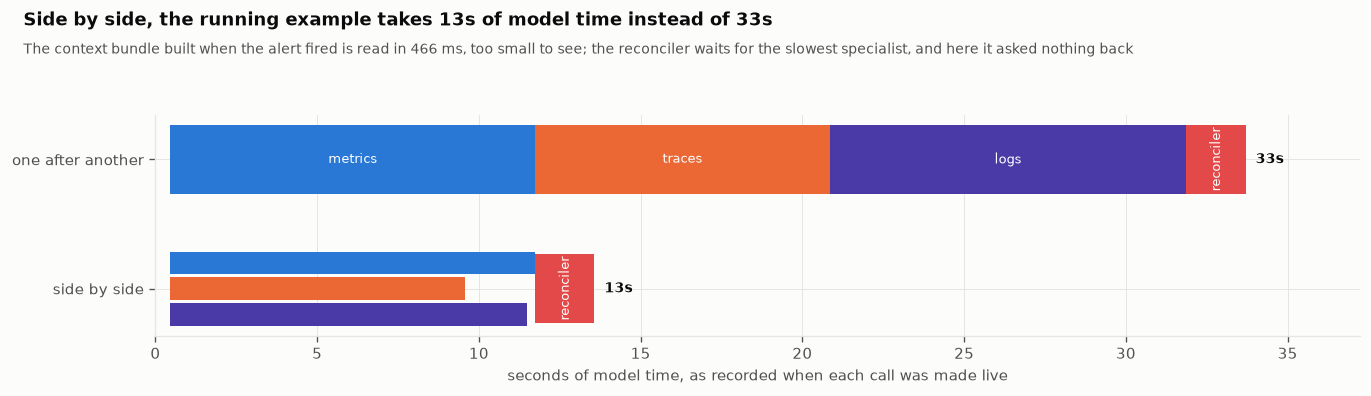

In [198]:
# ---- where an investigation's time goes, drawn from the model time each call took when it was made live ----
ms = FLAG_RCA["model_s"]
first = {r: s for r, s in ms["specialists"].items() if not r.endswith("+")}
again = {r[:-1]: s for r, s in ms["specialists"].items() if r.endswith("+")}
role_colour = dict(zip(first, (C1, C2, C7, C4, C5, C6)))
tail = [("reconciler", ms["reconcile"][0], C8)]
if again:
    tail += [(f"{r} again", s, role_colour.get(r, MUTED)) for r, s in again.items()] + [("reconciler", ms["reconcile"][-1], C8)]
fig, ax = plt.subplots(figsize=(11.5, 3.4))
totals = {}
for row, y in (("one after another", 0.0), ("side by side", 1.5)):
    t = TIMING["bundle_s"]
    if row == "one after another":
        for r, s in first.items():
            ax.barh(y, s, left=t, height=0.8, color=role_colour[r])
            ax.text(t + s / 2, y, r, ha="center", va="center", fontsize=7.5, color="white")
            t += s
    else:
        for k, (r, s) in enumerate(first.items()):
            ax.barh(y - 0.3 + k * 0.3, s, left=t, height=0.26, color=role_colour[r])
        t += max(first.values())
    for name, s, colour in tail:
        ax.barh(y, s, left=t, height=0.8, color=colour)
        ax.text(t + s / 2, y, name, ha="center", va="center", fontsize=7.5, color="white", rotation=90 if s < 4 else 0)
        t += s
    totals[row] = t - TIMING["bundle_s"]     # model time only: the bundle read is a live timing, measured afresh each run
    ax.text(t, y, f"  {totals[row]:.0f}s", va="center", fontsize=8.5, color=INK, weight="bold")
ax.set_yticks([0.0, 1.5], list(totals))
ax.invert_yaxis()
ax.set_xlim(0, max(totals.values()) * 1.12)
ax.set_xlabel("seconds of model time, as recorded when each call was made live")
print(f"  as recorded live: specialists {', '.join(f'{r} {s:.1f}s' for r, s in first.items())}; "
      f"reconciler {' + '.join(f'{s:.1f}s' for s in ms['reconcile'])}"
      + (f"; asked {', '.join(again)} again ({sum(again.values()):.1f}s)" if again else ""))
print(f"  model time one after another {totals['one after another']:.1f}s, side by side {totals['side by side']:.1f}s: "
      f"{1 - totals['side by side'] / totals['one after another']:.0%} of the wait removed by running the specialists "
      "together")
finish(fig, "latency_waterfall",
       f"Side by side, the running example takes {totals['side by side']:.0f}s of model time instead of "
       f"{totals['one after another']:.0f}s",
       f"The context bundle built when the alert fired is read in {TIMING['bundle_s'] * 1000:.0f} ms, too small to see; "
       "the reconciler waits for the slowest specialist" +
       (", and its question back costs a second round" if again else ", and here it asked nothing back"))

  41 development tasks ranked by the baseline's margin; the baseline's component is right on 5% of them
  the agents' partial score on development tasks: 12%; on no set of its most confident tasks does the baseline reach it
  frozen rule: no fast path; every task goes to the agents (the threshold is registered as infinite)


[fig] artifacts\figures_full\fast_path.png


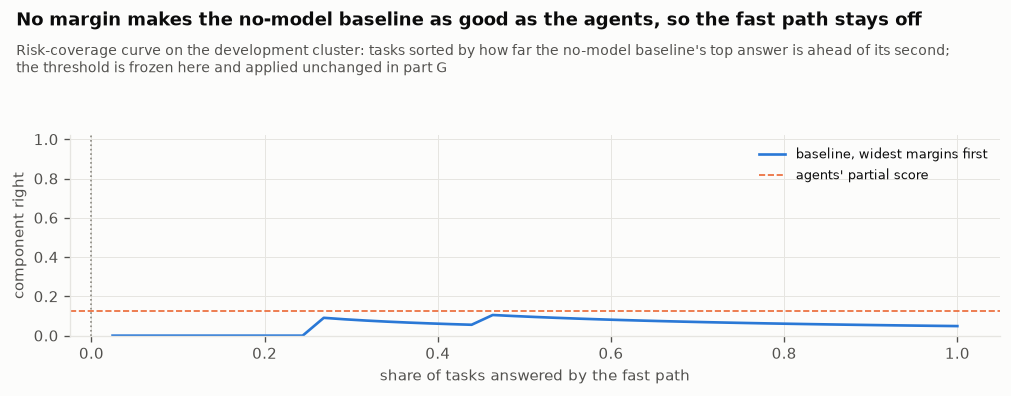

In [199]:
# ---- the fast path: answer without any model when the baseline's margin is wide, chosen on development data ----
def margin(task: pd.Series) -> tuple[str | None, float]:
    """The baseline's top component and how far ahead of the second it is, in chain score."""
    sig = lab_signals_for(task.task_id, task.system)
    if not sig:
        return None, 0.0
    sinks = {s["sid"] for s in sig if s["type"] in ("TRACE_SLOW", "TRACE_FAILED")} or {max(sig, key=lambda s: s["t"])["sid"]}
    chains = best_chains(sig, sinks, "topology", related_in(task.system))
    comp_of = {s["sid"]: s["comp"] for s in sig}
    score = {}
    for sid, (s, _) in chains.items():
        score[comp_of[sid]] = max(score.get(comp_of[sid], 0), s)
    if not score:
        return None, 0.0
    top = sorted(score.values(), reverse=True) + [0.0]
    return max(score, key=score.get), top[0] - top[1]


RC = []
for t in DEV.itertuples():
    want = component_answers(t.scoring_points)
    if want:
        comp, m = margin(pd.Series(t._asdict()))
        RC.append((m, comp in want))
RC = pd.DataFrame(RC, columns=["margin", "right"]).sort_values("margin", ascending=False)
RC["coverage"] = np.arange(1, len(RC) + 1) / len(RC)
RC["accuracy"] = RC.right.cumsum() / np.arange(1, len(RC) + 1)
agent_acc = DEV_RUNS.agent_partial.mean() if len(DEV_RUNS) else 0.5
ok_cut = RC[RC.accuracy >= agent_acc]
TAU = float(ok_cut.margin.min()) if len(ok_cut) else float("inf")
FAST_COVERAGE = float(ok_cut.coverage.max()) if len(ok_cut) else 0.0
print(f"  {len(RC)} development tasks ranked by the baseline's margin; the baseline's component is right on "
      f"{RC.right.mean():.0%} of them")
if len(ok_cut):
    print(f"  the agents' partial score on development tasks: {agent_acc:.0%}; the baseline beats it on its widest-margin "
          f"tasks down to a margin of {TAU:.3f}, which covers {FAST_COVERAGE:.0%} of tasks")
    print(f"  frozen rule: answer without a model when the margin is at least {TAU:.3f}")
else:
    print(f"  the agents' partial score on development tasks: {agent_acc:.0%}; on no set of its most confident tasks does "
          f"the baseline reach it")
    print("  frozen rule: no fast path; every task goes to the agents (the threshold is registered as infinite)")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(RC.coverage, RC.accuracy, color=C1, lw=1.6, label="baseline, widest margins first")
ax.axhline(agent_acc, color=C2, ls="--", lw=1, label="agents' partial score")
ax.axvline(FAST_COVERAGE, color=MUTED, ls=":", lw=1)
ax.set_xlabel("share of tasks answered by the fast path")
ax.set_ylabel("component right")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8)
finish(fig, "fast_path", f"The fast path can take {FAST_COVERAGE:.0%} of development tasks without losing accuracy"
       if FAST_COVERAGE else "No margin makes the no-model baseline as good as the agents, so the fast path stays off",
       "Risk-coverage curve on the development cluster: tasks sorted by how far the no-model baseline's top answer is ahead "
       "of its second; the threshold is frozen here and applied unchanged in part G")

**Running the specialists side by side cuts the running example from 33 to 13 seconds of model
time, and on our development data the fast path never earns the right to skip the models.** As
recorded when the calls were made live, the three specialists took 11.3, 9.1 and 11.0 seconds and
the reconciler 1.8, so one after another an investigation waits 33 seconds and side by side 13:
the slowest specialist plus the reconciler. The context bundle, assembled when the alert fired,
is read in well under a second. The fast path is the idea of answering the easy cases without any
model; ours would answer with the no-model baseline whenever its top component is far enough ahead
of its second. On the development cluster no such margin exists: the baseline's most confident
answers are never right often enough to match the agents' 12% partial score, so the threshold is
registered as infinite and every test task goes to the agents. Section 40 times investigations
live, with the cache switched off.

## 33 · From diagnosis to a proposed fix

**Theory.** The post stops at diagnosis and mentions remediation as the next step. A proposed
fix is useful only if it is specific, reversible and shown with the evidence and confidence that
justify it, and dangerous if it runs by itself. Ours is a card: the action, the target, why, how
sure, what would undo it, and a line that says a person must approve it. Nothing in this notebook
executes anything. Worlds: OpenRCA and Wikimedia.

In [200]:
# ---- the card: one reversible action, its evidence, and a person's approval ----
ACTIONS = [("memory", "restart the {level} {target} and watch its memory"), ("cpu", "move load off the {level} {target}"),
           ("network", "drain the {level} {target} from the load balancer until its network recovers"),
           ("latency", "drain the {level} {target} from the load balancer"), ("disk", "move the {level} {target}'s I/O-heavy work elsewhere"),
           ("i/o", "move the {level} {target}'s I/O-heavy work elsewhere"),
           ("process", "restart the {level} {target}"), ("deploy", "roll back {target}"), ("config", "revert {target}"),
           ("capacity", "repool or depool {target} back to its previous state")]


def remediation_card(target: str, about: str, confidence, evidence: list, undo: str) -> str:
    level = "node" if target.startswith("node-") else "pod" if re.search(r"-\d+$", target) else "service"
    action = next((a for k, a in ACTIONS if k in about.lower()), "page the owning team about {target}").format(
        level=level, target=target)
    lines = [f"  proposed action   {action}", f"  because           {about}",
             f"  confidence        {confidence}", f"  evidence          {', '.join(map(str, evidence[:6])) or 'none'}",
             f"  to undo           {undo}", "  status            waiting for a person to approve; nothing has been executed"]
    return "\n".join(lines)


CARDS_SHOWN = []                                   # (where it came from, the card's text)
if FLAG_RCA["answer"]:
    a = FLAG_RCA["answer"][0]
    cited = next((h.get("evidence") for f in demo_findings.values() for h in f.hypotheses if h.get("evidence")), [])
    CARDS_SHOWN.append((f"OpenRCA, task {flag_task.task_id}",
                        remediation_card(str(a.get("component")), str(a.get("reason")), FLAG_RCA["confidence"], cited,
                                         "return the component to the pool once its signals are back to their baseline")))
if WIKI_FOUND:
    best = max((h for f in WIKI_FOUND.values() for h in f.hypotheses), key=lambda h: h.get("confidence") or 0, default=None)
    if best:
        CARDS_SHOWN.append((f"Wikimedia, {FLAGSHIP['id'].removeprefix('Incidents/')}",
                            remediation_card(str(best.get("change") or (best.get("components") or ["?"])[0]),
                                             str(best.get("trigger")), best.get("confidence"), best.get("evidence") or [],
                                             "redeploy the previous version, or repool what was depooled")))
for where, card in CARDS_SHOWN:
    print(f"  {where}\n{card}\n")

  OpenRCA, task market_cb1-195
  proposed action   move the pod cartservice-0's I/O-heavy work elsewhere
  because           container read I/O load
  confidence        0.7
  evidence          s2558, s111, s4347, s2560, s110, s109
  to undo           return the component to the pool once its signals are back to their baseline
  status            waiting for a person to approve; nothing has been executed

  Wikimedia, 2024-04-17 mw-on-k8s eqiad outage
  proposed action   roll back service:objectcache
  because           deploy
  confidence        0.9
  evidence          m10, m23, m49, m56, m65, m34
  to undo           redeploy the previous version, or repool what was depooled
  status            waiting for a person to approve; nothing has been executed



[fig] artifacts\figures_full\remediation_cards.png


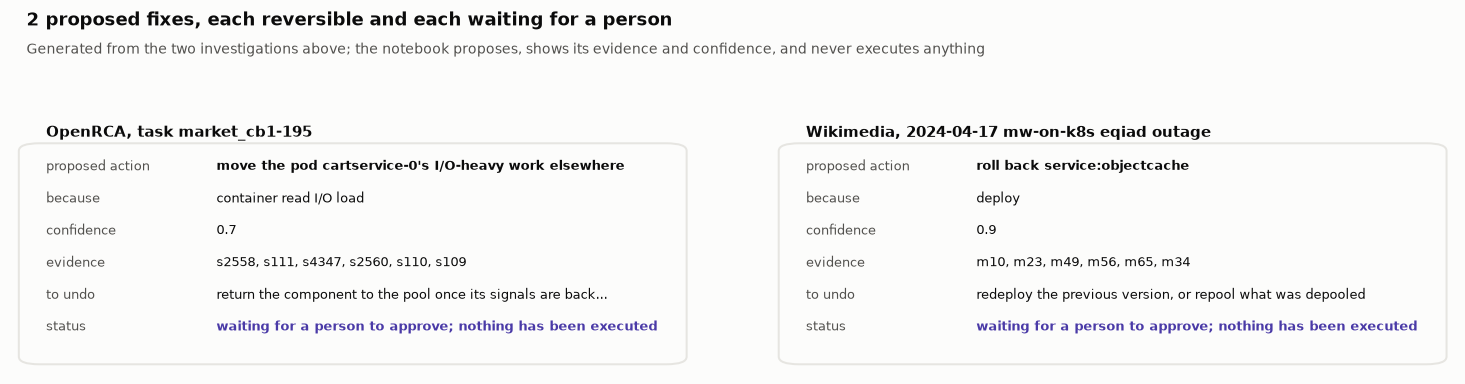

In [201]:
# ---- the cards, drawn: what a person sees before anything is allowed to happen ----
if CARDS_SHOWN:
    fig, axes = plt.subplots(1, len(CARDS_SHOWN), figsize=(6.4 * len(CARDS_SHOWN), 3.3), squeeze=False)
    for ax, (where, card) in zip(axes[0], CARDS_SHOWN):
        ax.axis("off")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.84, boxstyle="round,pad=0.01,rounding_size=0.03",
                                    fc=SURF, ec=GRID, lw=1.2))
        ax.text(0.05, 0.93, where, fontsize=9, weight="bold", color=INK, va="center")
        rows = [(ln[2:20].strip(), ln[20:].strip()) for ln in card.splitlines()]       # the card's two columns
        for k, (field, value) in enumerate(rows):
            y = 0.80 - k * 0.125
            colour = C7 if field == "status" else INK
            ax.text(0.05, y, field, fontsize=7.8, color=INK2, va="center")
            ax.text(0.30, y, textwrap.shorten(value, 62, placeholder="..."), fontsize=7.8, color=colour, va="center",
                    weight="bold" if field in ("proposed action", "status") else "normal")
    finish(fig, "remediation_cards", f"{len(CARDS_SHOWN)} proposed fix{'es' if len(CARDS_SHOWN) != 1 else ''}, each "
           "reversible and each waiting for a person",
           "Generated from the two investigations above; the notebook proposes, shows its evidence and confidence, and "
           "never executes anything")

**Each investigation ends in a card that a person must approve, and nothing in this notebook
executes anything.** The OpenRCA card proposes moving the I/O-heavy work off cartservice-0,
because the reconciler's answer was read I/O load, with confidence 0.7 and the six signal ids
behind it. The Wikimedia card proposes rolling back what the most confident specialist blamed,
objectcache, with confidence 0.9 and the chat lines it cited; objectcache is the cache layer whose
router the faulty change had moved, so the card points near the cause without naming it. Both
cards say how to undo the action. What makes a card useful is that the evidence and the confidence
sit next to the action: a person reading the first can check its signals and see that the reason it
gives is not the one the answer key records. The post leaves remediation as future work;
ours stops at the proposal on purpose, and section 43 checks the principle that keeps it there.

## 34 · Labels we can trust

**Theory.** OpenRCA and RCAEval come with answers. Wikimedia does not: its incident reports say
what happened in prose, written by the people who fixed it, and our evaluation needs a typed
answer for each one: what kind of thing triggered it, which components were the cause, which
change if any, and how it was noticed. Reading 146 reports by hand is a week of work, and having
one model read them would make the test only as good as that model. So two models from different
companies read every report independently, Claude Opus 5.5 through its structured outputs and
Qwen3.7-Max through JSON mode, each held to the same closed vocabulary. Where they agree we accept
the label, and we report how often they agreed before anyone decided anything. Where they disagree,
no person decided: the project's owner chose not to review labels by hand, so two adjudicators
do it independently, each shown the report and the two answers labelled only A and B in a random
order. One is the assistant that built this notebook, which read every disagreement and wrote down
a decision and a reason for each (`artifacts/labels/review_decisions.json`); the other is
Qwen3.8-Max, which extracted no labels. A label counts only where the two adjudicators agree on the
trigger; where they do not, the report is marked inconclusive and leaves the test. Because the
assistant is a Claude model judging between Claude and Qwen, we also unblind afterwards and count
whose labels each adjudicator kept. The final labels are frozen and hashed before any system is
tested against them; the one revision made after the test, forced by a bug, is reported below.
World: Wikimedia.

[fig] artifacts\figures_full\label_protocol.png


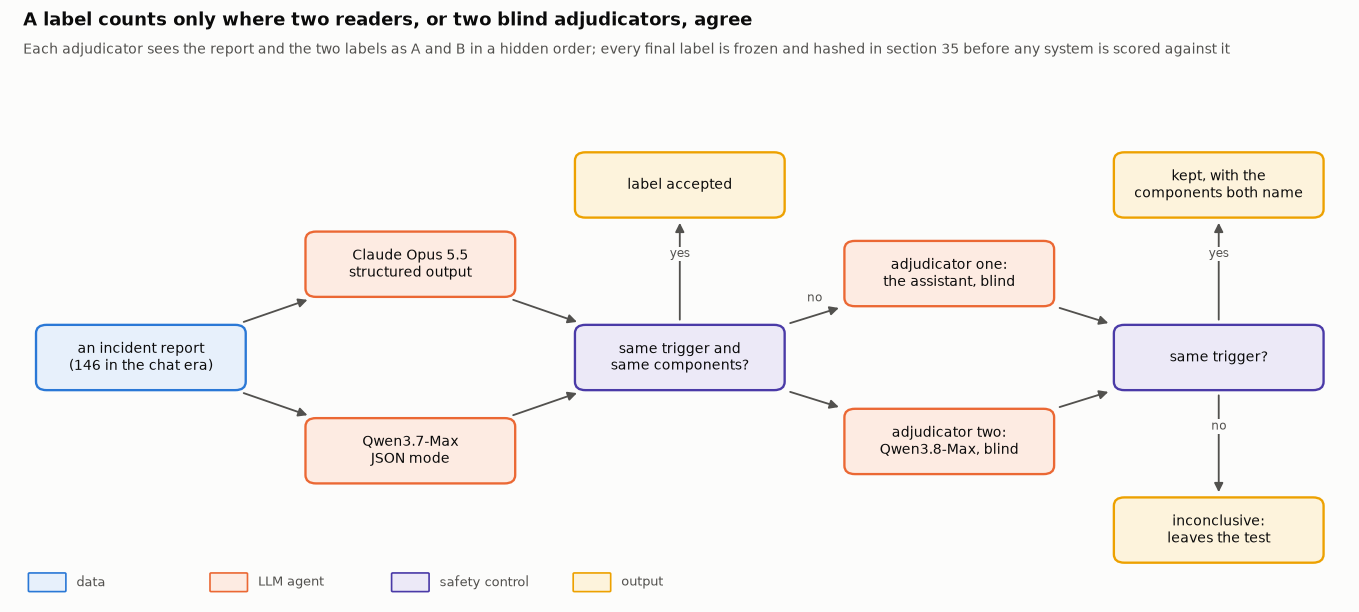

In [202]:
# ---- the protocol, drawn: two readers, two blind adjudicators, and a label only where they agree ----
LABEL_FLOW = {
    "report": (1.1, 2.6, f"an incident report\n({len(inc_w)} in the chat era)", "data"),
    "claude": (3.4, 3.6, "Claude Opus 5.5\nstructured output", "llm"),
    "qwen": (3.4, 1.6, "Qwen3.7-Max\nJSON mode", "llm"),
    "agree": (5.7, 2.6, "same trigger and\nsame components?", "guard"),
    "accept": (5.7, 4.45, "label accepted", "output"),
    "assistant": (8.0, 3.5, "adjudicator one:\nthe assistant, blind", "llm"),
    "qwen38": (8.0, 1.7, "adjudicator two:\nQwen3.8-Max, blind", "llm"),
    "agree2": (10.3, 2.6, "same trigger?", "guard"),
    "final": (10.3, 4.45, "kept, with the\ncomponents both name", "output"),
    "inconc": (10.3, 0.75, "inconclusive:\nleaves the test", "output"),
}
LABEL_EDGES = [("report", "claude", None), ("report", "qwen", None), ("claude", "agree", None), ("qwen", "agree", None),
               ("agree", "accept", "yes"), ("agree", "assistant", "no"), ("agree", "qwen38", None),
               ("assistant", "agree2", None), ("qwen38", "agree2", None), ("agree2", "final", "yes"),
               ("agree2", "inconc", "no")]
draw_flow(LABEL_FLOW, LABEL_EDGES, "label_protocol",
          "A label counts only where two readers, or two blind adjudicators, agree",
          "Each adjudicator sees the report and the two labels as A and B in a hidden order; every final label is frozen "
          "and hashed in section 35 before any system is scored against it", size=(11.4, 5.2), box=(1.75, 0.66))

In [203]:
# ---- the contract every label must fill: the same TRIGGERS and DETECTIONS the agents answer in (section 31) ----
def label_schema(candidates: list[str]) -> dict:
    return {"type": "object", "additionalProperties": False,
            "required": ["trigger", "root_cause_components", "triggering_change", "detected_by", "one_line"],
            "properties": {
                "trigger": {"type": "string", "enum": TRIGGERS},
                "root_cause_components": {"type": "array", "items": {"type": "string", "enum": candidates or ["none"]}},
                "triggering_change": {"type": ["string", "null"], "description": "a Gerrit change number or null"},
                "detected_by": {"type": "string", "enum": DETECTIONS},
                "one_line": {"type": "string", "description": "what happened, in at most 25 words"}}}


LABEL_SYSTEM = ("You read one incident report from a large website's operations team and fill in a label. Use only "
                "what the report says. trigger is what started the incident. root_cause_components lists only ids "
                "from the candidate list that the report names as the cause; leave it empty if none fits. "
                "triggering_change is a Gerrit change number if the report names the change that started it, "
                "otherwise null. detected_by says whether monitoring or a person noticed first.")


def report_candidates(r) -> list[str]:
    """Hosts the catalogue knows and catalogue services named anywhere in the report: the closed list for this one."""
    text = report_text(r).lower()
    hosts = sorted({f"host:{h}" for h in hosts_in(text) if resolve_host(h)["role_from"] == "catalogue"})
    svcs = sorted({f"service:{s}" for tok in SERVICE_LIKE.findall(text) if (s := resolve_service(tok, cutoff=100)[0])}
                  | {f"service:{w}" for w in re.findall(r"\b[a-z]{5,}\b", text)
                     if w not in COMMON_WORD_SERVICES and resolve_service(w, fuzzy=False)[0] == w})
    return (hosts[:40] + svcs[:40]) or ["none"]


def report_prompt(r) -> str:
    plain = re.sub(r"\{\{.*?\}\}|<!--.*?-->", " ", report_text(r), flags=re.S)
    return f"Candidate ids: {json.dumps(report_candidates(r))}\n\nReport:\n{SCRUB(plain)[:12000]}"


print(f"  triggers {TRIGGERS}")
print(f"  detection {DETECTIONS}")
ex = inc_w.iloc[0] if len(inc_w) else None
if ex is not None:
    print(f"  example closed list for {ex['id']}: {report_candidates(ex)[:8]} ...")

  triggers ['deploy', 'config change', 'capacity change', 'maintenance', 'hardware failure', 'traffic surge', 'external dependency', 'latent bug', 'unknown']
  detection ['automated alert', 'human report', 'unknown']
  example closed list for Incidents/2021-07-16 asw-a2-codfw network: ['host:ms-be2040', 'host:ms-be2051', 'host:ms-fe2005', 'host:thanos-fe2001', 'service:cxserver', 'service:mobileapps', 'service:restbase', 'service:swift'] ...


In [204]:
# ---- two readers, one report at a time ----
def qwen_label(r) -> dict | None:
    cands = report_candidates(r)
    sys_ = LABEL_SYSTEM + " Answer with one JSON object with exactly the keys trigger, root_cause_components, " \
                          f"triggering_change, detected_by, one_line. trigger is one of {TRIGGERS}; detected_by is one of {DETECTIONS}."
    res = LLM.chat(QWEN["max37"], [{"role": "system", "content": sys_}, {"role": "user", "content": report_prompt(r)}],
                   agent="labeller", max_tokens=600)
    return res.data if isinstance(res.data, dict) else None


def claude_label(r) -> dict | None:
    res = JUDGE.ask(LABEL_SYSTEM, report_prompt(r), agent="labeller", schema=label_schema(report_candidates(r)),
                    effort="low", max_tokens=2000)
    return res.data if res.ok and isinstance(res.data, dict) else None


LABEL_POOL = inc_w if PROFILE == "FULL" else inc_w.head({"SMOKE": 2, "MEDIUM": 20}.get(PROFILE, 20))
with phase("label extraction"):
    with ThreadPoolExecutor(4) as ex_:
        QWEN_LABELS = list(ex_.map(qwen_label, [r for _, r in LABEL_POOL.iterrows()]))
        CLAUDE_LABELS = list(ex_.map(claude_label, [r for _, r in LABEL_POOL.iterrows()]))
print(f"  {len(LABEL_POOL)} reports; Qwen3.7-Max answered {sum(l is not None for l in QWEN_LABELS)}, Claude answered "
      f"{sum(l is not None for l in CLAUDE_LABELS)}")
print(f"  spent: {LEDGER.spent('qwen', 'label extraction'):.1f} Magicubes, ${LEDGER.spent('claude', 'label extraction'):.2f}")

  146 reports; Qwen3.7-Max answered 146, Claude answered 146
  spent: 147.0 Magicubes, $2.53


  trigger                       0.73
  detected_by                   0.92
  components (mean Jaccard)     0.86
  trigger, raw agreement        0.77
  both readers agree on trigger and components for 100 of 146 reports; the rest go to two adjudicators, blind


[fig] artifacts\figures_full\label_agreement.png


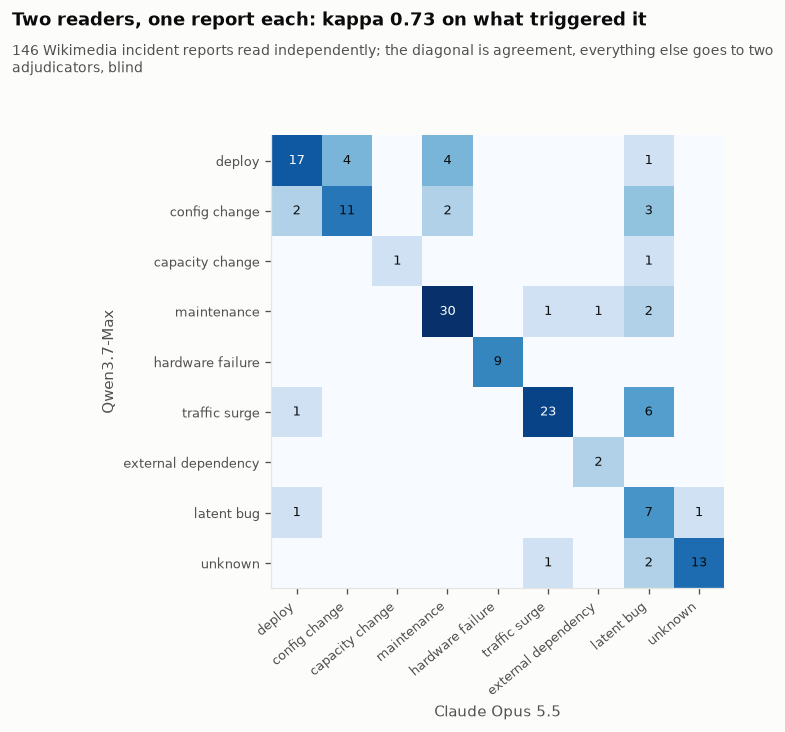

In [205]:
# ---- agreement before anyone decides: kappa for the categories, overlap for the components ----
def cohen_kappa(a: list, b: list) -> float:
    pairs = [(x, y) for x, y in zip(a, b) if x is not None and y is not None]
    if not pairs:
        return float("nan")
    cats = sorted({x for p in pairs for x in p})
    po = np.mean([x == y for x, y in pairs])
    pe = sum((sum(x == c for x, _ in pairs) / len(pairs)) * (sum(y == c for _, y in pairs) / len(pairs)) for c in cats)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


both = [(q, c) for q, c in zip(QWEN_LABELS, CLAUDE_LABELS) if q and c]
AGREE = {"trigger": cohen_kappa([q.get("trigger") for q, _ in both], [c.get("trigger") for _, c in both]),
         "detected_by": cohen_kappa([q.get("detected_by") for q, _ in both], [c.get("detected_by") for _, c in both])}
def jaccard(a, b) -> float:
    """Overlap of two component lists; two empty lists ('no candidate fits') agree completely."""
    a, b = set(a or []), set(b or [])
    return 1.0 if not a and not b else len(a & b) / len(a | b)


jac = [jaccard(q.get("root_cause_components"), c.get("root_cause_components")) for q, c in both]
AGREE["components (mean Jaccard)"] = float(np.mean(jac)) if jac else float("nan")
AGREE["trigger, raw agreement"] = float(np.mean([q.get("trigger") == c.get("trigger") for q, c in both])) if both else float("nan")
for k, v in AGREE.items():
    print(f"  {k:<28}{v:6.2f}")
print(f"  both readers agree on trigger and components for {sum(q.get('trigger') == c.get('trigger') and j == 1 for (q, c), j in zip(both, jac))}"
      f" of {len(both)} reports; the rest go to two adjudicators, blind")

if both:
    trig = pd.crosstab(pd.Series([q.get("trigger") for q, _ in both], name="Qwen3.7-Max"),
                       pd.Series([c.get("trigger") for _, c in both], name="Claude Opus 5.5")).reindex(
        index=TRIGGERS, columns=TRIGGERS, fill_value=0)
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    ax.imshow(np.log1p(trig.to_numpy()), cmap="Blues")
    ax.set_xticks(range(len(TRIGGERS)), TRIGGERS, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(TRIGGERS)), TRIGGERS, fontsize=8)
    ax.set_xlabel("Claude Opus 5.5")
    ax.set_ylabel("Qwen3.7-Max")
    ax.grid(False)
    for i in range(len(TRIGGERS)):
        for j in range(len(TRIGGERS)):
            if trig.iat[i, j]:
                ax.text(j, i, trig.iat[i, j], ha="center", va="center", fontsize=8,
                        color="white" if trig.iat[i, j] > trig.to_numpy().max() / 2 else INK)
    finish(fig, "label_agreement", f"Two readers, one report each: kappa {AGREE['trigger']:.2f} on what triggered it",
           f"{len(both)} Wikimedia incident reports read independently; the diagonal is agreement, everything else goes "
           "to two adjudicators, blind")

In [206]:
# ---- the disagreements: what each adjudicator sees, blind to which model wrote which answer ----
REVIEW_FILE = LABEL_DIR / "review_queue.json"
DECISIONS_FILE = LABEL_DIR / "review_decisions.json"
queue = []
for (_, r), q, c in zip(LABEL_POOL.iterrows(), QWEN_LABELS, CLAUDE_LABELS):
    if q and c and q.get("trigger") == c.get("trigger") and \
            set(q.get("root_cause_components") or []) == set(c.get("root_cause_components") or []):
        continue
    a, b = (q, c) if random.Random(f"{SEED}|{r['id']}").random() < 0.5 else (c, q)      # order hidden from adjudicators
    queue.append({"incident": r["id"], "report_excerpt": SCRUB(re.sub(r"\{\{.*?\}\}|<!--.*?-->", " ", r["summary"],
                                                                     flags=re.S))[:1500],
                  "candidates": report_candidates(r), "A": a, "B": b})
REVIEW_FILE.write_text(json.dumps(queue, indent=1, default=str), encoding="utf-8")
print(f"  {len(queue)} reports need a decision; queue written to {REVIEW_FILE.relative_to(ROOT)}")
print(f"  decisions on file: {len(json.loads(DECISIONS_FILE.read_text())) if DECISIONS_FILE.exists() else 0}")

  46 reports need a decision; queue written to artifacts\labels\review_queue.json
  decisions on file: 52


In [207]:
# ---- two adjudicators, blind: the assistant's written decisions, and Qwen3.8-Max reading the same disagreements ----
ADJ_SYSTEM = ("Two careful readers labelled the same incident report and disagree. Decide which label is right, A or "
              "B, or write your own if neither is, using only what the report says. trigger is the event that started "
              "the incident, not its deeper cause; root_cause_components lists only candidate ids the report names as "
              "the cause, never components that merely suffered. Answer with one JSON object with exactly the keys "
              f"choice (A, B or neither), trigger (one of {TRIGGERS}), root_cause_components, and reason (at most 25 "
              "words). When choice is A or B, copy that label's trigger and components.")
FINAL_LABELS_FILE = LABEL_DIR / "labels_final.json"
LABEL_KEYS = ("trigger", "root_cause_components", "triggering_change", "detected_by", "one_line")


def qwen_adjudicate(item: dict) -> dict | None:
    r = LABEL_POOL[LABEL_POOL.id == item["incident"]].iloc[0]
    body = (f"{report_prompt(r)}\n\nLabel A: {json.dumps(item['A'], default=str)}\n"
            f"Label B: {json.dumps(item['B'], default=str)}")
    res = LLM.chat(QWEN["max"], [{"role": "system", "content": ADJ_SYSTEM}, {"role": "user", "content": body}],
                   agent="adjudicator", max_tokens=500)
    return res.data if isinstance(res.data, dict) else None


def readers_side(item: dict, label: dict) -> str:
    """Which reader's label an adjudicator kept, unblinded only now: 'Claude', 'Qwen' or 'own'."""
    same = lambda x: x and x.get("trigger") == label.get("trigger") and \
        set(x.get("root_cause_components") or []) == set(label.get("root_cause_components") or [])
    qwen_is_a = random.Random(f"{SEED}|{item['incident']}").random() < 0.5
    if same(item["A"]):
        return "Qwen" if qwen_is_a else "Claude"
    if same(item["B"]):
        return "Claude" if qwen_is_a else "Qwen"
    return "own"


DECISIONS = json.loads(DECISIONS_FILE.read_text()) if DECISIONS_FILE.exists() else []
# a decision is about what the readers wrote; when a fix changes the text they read, it no longer applies, and the
# report counts only if both readers now agree (no decision is made again after the test)
ASSISTANT = {d["incident"]: d for d in DECISIONS if not d.get("superseded")}
# the scrubber fixed on 1 November had taken 'wdqs', 'swe' and 'www.wikipedia.org' for people (section 44); scrubbing
# every report both ways finds the ones whose text changed, and only decisions on those may be set aside
before_fix = Scrubber()
before_fix.handles = {**SCRUB.handles, **{h: alias(h) for h in ("wdqs", "swe", "www.wikipedia.org")}}
before_fix.names, before_fix.given = SCRUB.names, SCRUB.given
REREAD = set()
for _, r in LABEL_POOL.iterrows():
    plain_ = re.sub(r"\{\{.*?\}\}|<!--.*?-->", " ", report_text(r), flags=re.S)
    if before_fix(plain_)[:12000] != SCRUB(plain_)[:12000]:
        REREAD.add(r["id"])
SET_ASIDE = {d["incident"] for d in DECISIONS if d.get("superseded")} & set(LABEL_POOL.id)
assert SET_ASIDE == REREAD & {d["incident"] for d in DECISIONS}, "set aside only, and every, decision on a changed text"
print(f"  {len(REREAD)} of {len(LABEL_POOL)} reports reached the readers changed by the scrubber bug and were read again; "
      f"{len(SET_ASIDE)} decisions on them are set aside")
with phase("label extraction"):
    with ThreadPoolExecutor(4) as ex_:
        decidable = [q for q in queue if q["incident"] in ASSISTANT]     # a second opinion needs a first one
        QWEN_ADJ = dict(zip([q["incident"] for q in decidable], ex_.map(qwen_adjudicate, decidable)))
ADJ_ROWS, FINAL = [], []
for item in queue:
    mine, other = ASSISTANT.get(item["incident"]), QWEN_ADJ.get(item["incident"]) or {}
    if mine is None:                       # a disagreement without a decision stays out of the test
        FINAL.append({"incident": item["incident"], "how": "inconclusive: no decision", "trigger": "unknown",
                      "root_cause_components": [], "triggering_change": None, "detected_by": "unknown", "one_line": ""})
        continue
    if other.get("choice") in ("A", "B"):
        theirs = item[other["choice"]] or {}
    else:
        theirs = {"trigger": other.get("trigger"), "root_cause_components": other.get("root_cause_components") or []}
    same_trigger = mine["trigger"] == theirs.get("trigger")
    both = set(mine["root_cause_components"] or []) & set(theirs.get("root_cause_components") or [])
    ADJ_ROWS.append({"incident": item["incident"], "assistant": mine["trigger"], "qwen": theirs.get("trigger"),
                     "agree": same_trigger, "same_components": set(mine["root_cause_components"] or []) ==
                     set(theirs.get("root_cause_components") or []),
                     "assistant_kept": readers_side(item, mine), "qwen_kept": readers_side(item, theirs)})
    if same_trigger:                       # the trigger both agree on, and only the components both name
        FINAL.append({"incident": item["incident"], "how": "two adjudicators agree",
                      **{k: mine[k] for k in LABEL_KEYS}, "root_cause_components": sorted(both)})
    else:
        FINAL.append({"incident": item["incident"], "how": "inconclusive: the adjudicators disagree", "trigger": "unknown",
                      "root_cause_components": [], "triggering_change": None, "detected_by": mine["detected_by"],
                      "one_line": mine["one_line"]})
ADJ = pd.DataFrame(ADJ_ROWS)
# the file section 35 fingerprints holds every label, so none can change unseen: the reports both readers agreed on
# (Claude's wording of the shared answer) and every decision on a disagreement, kept or inconclusive
queued = {item["incident"] for item in queue}
AGREED = [{"incident": r["id"], "how": "both readers agree", **{k: c.get(k) for k in LABEL_KEYS}}
          for (_, r), q, c in zip(LABEL_POOL.iterrows(), QWEN_LABELS, CLAUDE_LABELS) if q and c and r["id"] not in queued]
FINAL = sorted(AGREED + FINAL, key=lambda d: d["incident"])
FINAL_LABELS_FILE.write_text(json.dumps(FINAL, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
if len(ADJ):
    print(f"  {len(ADJ)} disagreements read by both adjudicators; they agree on the trigger for {ADJ.agree.mean():.0%} "
          f"(kappa {cohen_kappa(list(ADJ.assistant), list(ADJ.qwen)):.2f}) and on the components for "
          f"{ADJ.same_components.mean():.0%}")
    for who in ("assistant", "qwen"):
        kept = ADJ[f"{who}_kept"].value_counts()
        print(f"  {'the assistant' if who == 'assistant' else 'Qwen3.8-Max':<14} kept Claude's label {kept.get('Claude', 0):>3}, "
              f"Qwen's {kept.get('Qwen', 0):>3}, wrote its own {kept.get('own', 0):>3}")
    print(f"  final: {len(AGREED)} labels both readers agreed on, {sum(f['how'] == 'two adjudicators agree' for f in FINAL)} "
          f"kept by both adjudicators, {sum(f['how'].startswith('inconclusive') for f in FINAL)} inconclusive and left "
          f"out of the test; all {len(FINAL)} written to {FINAL_LABELS_FILE.relative_to(ROOT)}")
    for _, a in ADJ[~ADJ.agree].iterrows():
        print(f"    inconclusive  {a.incident.removeprefix('Incidents/')[:52]:<54}assistant: {a.assistant:<17}qwen: {a.qwen}")
if REREAD:
    again = Counter(f["how"] for f in FINAL if f["incident"] in REREAD)
    print(f"  the {len(REREAD)} reports read again: {again['both readers agree']} now agreed by both readers, "
          f"{sum(v for k, v in again.items() if k.startswith('inconclusive'))} inconclusive")
    for f in FINAL:
        if f["incident"] in REREAD and f["how"].startswith("inconclusive"):
            print(f"    inconclusive  {f['incident'].removeprefix('Incidents/')[:52]:<54}{f['how']}")

  15 of 146 reports reached the readers changed by the scrubber bug and were read again; 6 decisions on them are set aside


  42 disagreements read by both adjudicators; they agree on the trigger for 64% (kappa 0.58) and on the components for 81%
  the assistant  kept Claude's label  25, Qwen's   8, wrote its own   9
  Qwen3.8-Max    kept Claude's label  15, Qwen's  17, wrote its own  10
  final: 100 labels both readers agreed on, 27 kept by both adjudicators, 19 inconclusive and left out of the test; all 146 written to artifacts\labels\labels_final.json
    inconclusive  2021-07-26 ruwikinews DynamicPageList                 assistant: latent bug       qwen: config change
    inconclusive  2021-12-03 mx                                         assistant: maintenance      qwen: config change
    inconclusive  2022-05-31 Analytics Hadoop failure                   assistant: latent bug       qwen: capacity change
    inconclusive  2022-07-13 brief outbound bandwidth spike eqsin       assistant: traffic surge    qwen: unknown
    inconclusive  2022-12-09 api appserver worker starvation            assistant: unkn

**Two models read all 146 reports and agreed on what triggered the incident three times in four
(kappa 0.73); two blind adjudicators settled 27 of the 42 disagreements they both read, and 19
reports leave the test as inconclusive.** Claude Opus 5.5 and Qwen3.7-Max agreed on how an
incident was noticed almost always (kappa 0.92), on the components with a mean overlap of 0.86,
and on trigger and components together for 100 reports. Many of the disagreements are about where
an incident starts: a kernel upgrade or the traffic change that exposed it, a maintenance window
or the latent bug it uncovered. On these hard cases the adjudicators agreed with each other 64% of
the time (kappa 0.58), below what the readers managed on every report, so neither layer is a
rubber stamp. Unblinding afterwards shows one thing worth knowing: the assistant, itself a Claude
model, kept Claude's label 25 times and Qwen's 8, while Qwen3.8-Max split 15 and 17. Whether that
is a lean or better reading cannot be told from here, and the rule that a label counts only when
both adjudicators agree is what keeps either one's lean out of the test. One correction came after
the test had run. A scrubber bug (section 44) had hidden a service's name from the readers in 15
reports, so those were read again on the corrected text: 11 now have both readers agreeing, and
the other 4 are inconclusive, because the decisions made on their old text were set aside and no
decision is made once results are known. Every label, with the inconclusive reports marked as
such, is in one file whose fingerprint section 35 puts into the registration.

## 35 · The exam: what is fixed before any test result is seen

**Theory.** Every number in part G is only worth something if the rules were fixed before the
number existed. So this section writes them down and fingerprints them: which failures are for
development and which for testing, the floors any method must beat (guessing at random, and
always answering whatever was most common in development), the published results we compare
against, the targets from section 1, the fast-path threshold from section 32, and a hash of the
final labels from section 34. The file is hashed, the hash is printed, and part
G refuses to run if the file has changed since. Worlds: all.

  openrca   dev ['market_cb1']   test ['market_cb2', 'bank', 'telecom']
  wikimedia dev 108   test 38
  rcaeval   test 360
  the incident we follow is in the Wikimedia dev set; it is shown, never used to choose anything
[fig] artifacts\figures_full\splits.png


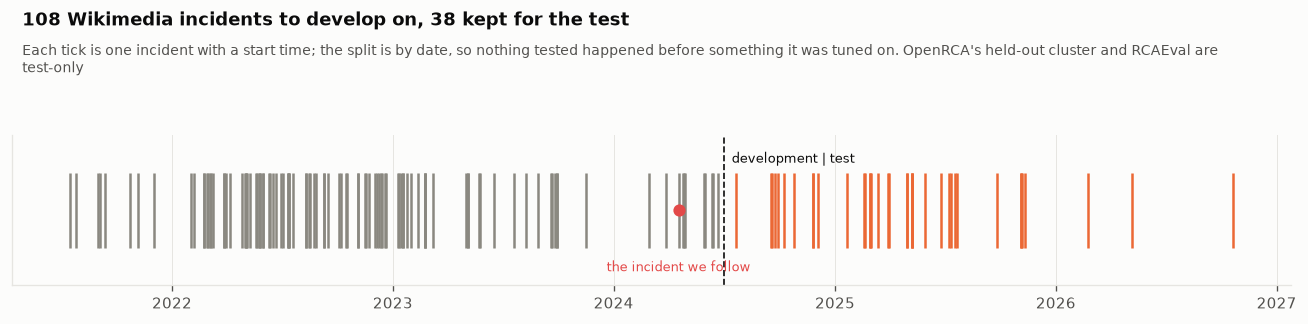

In [208]:
# ---- splits: development data shapes methods, test data only scores them ----
WM_SPLIT_DAY = pd.Timestamp("2024-07-01", tz="UTC")       # the last 28 months of incidents are the Wikimedia test
SPLITS = {
    "openrca": {"dev": ["market_cb1"], "test": ["market_cb2", "bank", "telecom"]},
    "wikimedia": {"dev": [r["id"] for _, r in inc_w.iterrows() if r["start"] < WM_SPLIT_DAY],
                  "test": [r["id"] for _, r in inc_w.iterrows() if r["start"] >= WM_SPLIT_DAY]},
    "rcaeval": {"test": sorted(CASES.case)},
}
for world, s in SPLITS.items():
    print(f"  {world:<10}" + "   ".join(f"{k} {len(v) if isinstance(v, list) and world != 'openrca' else v}"
                                         for k, v in s.items()))
flag_split = "test" if FLAGSHIP is not None and FLAGSHIP["id"] in SPLITS["wikimedia"]["test"] else "dev"
print(f"  the incident we follow is in the Wikimedia {flag_split} set; it is shown, never used to choose anything")

fig, ax = plt.subplots(figsize=(11, 2.8))
starts = inc_w.start.sort_values()
ax.eventplot([starts[starts < WM_SPLIT_DAY].to_numpy(), starts[starts >= WM_SPLIT_DAY].to_numpy()],
             lineoffsets=[1, 1], colors=[MUTED, C2], linelengths=0.8)
ax.axvline(WM_SPLIT_DAY, color=INK, ls="--", lw=1)
ax.text(WM_SPLIT_DAY, 1.55, "  development | test", fontsize=8, va="center")
if FLAGSHIP is not None:
    ax.scatter([FLAG_T], [1], color=C8, zorder=3, s=40)
    ax.text(FLAG_T, 0.35, "the incident we follow", fontsize=8, color=C8, ha="center")
ax.set_yticks([])
ax.set_ylim(0.2, 1.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
finish(fig, "splits", f"{len(SPLITS['wikimedia']['dev'])} Wikimedia incidents to develop on, "
       f"{len(SPLITS['wikimedia']['test'])} kept for the test",
       "Each tick is one incident with a start time; the split is by date, so nothing tested happened before something "
       "it was tuned on. OpenRCA's held-out cluster and RCAEval are test-only")

  market_cb2  random   2.2%   always-the-common-answer   3.8%   (78 tasks, partial score)
  bank        random   6.4%   always-the-common-answer  11.2%   (136 tasks, partial score)
  telecom     random  13.7%   always-the-common-answer  25.8%   (51 tasks, partial score)


[fig] artifacts\figures_full\floors.png


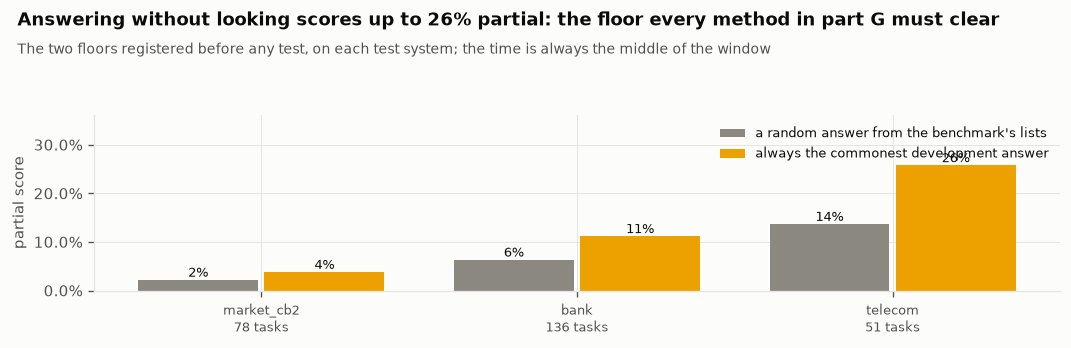

In [209]:
# ---- floors: what guessing and habit achieve, computed on the test sets themselves ----
def floor_scores(system: str) -> dict:
    """Random: a uniform pick from the benchmark's lists. Prior: the development cluster's most common answer."""
    tasks = TASKS[TASKS.system == system]
    v = VOCAB[system]
    dev_recs = OPENRCA_RECORDS[OPENRCA_RECORDS.system.isin(SPLITS["openrca"]["dev"])]
    common_comp = Counter(dev_recs.component).most_common(1)[0][0] if system.startswith("market") else \
        Counter(OPENRCA_RECORDS[OPENRCA_RECORDS.system == system].component).most_common(1)[0][0]
    common_reason = Counter(dev_recs.reason).most_common(1)[0][0] if system.startswith("market") else v["reasons"][0]
    rng_ = random.Random(SEED)
    rand, prior = [], []
    for t in tasks.itertuples():
        mid = utc8(t.ws + (t.we - t.ws) / 2)
        rand.append(score_answer([{"component": rng_.choice(v["components"]), "reason": rng_.choice(v["reasons"]),
                                   "datetime": mid}], t.scoring_points)[0])
        prior.append(score_answer([{"component": common_comp, "reason": common_reason, "datetime": mid}],
                                  t.scoring_points)[0])
    return {"random": float(np.mean(rand)), "prior": float(np.mean(prior)), "tasks": len(tasks)}


FLOORS = {s: floor_scores(s) for s in SPLITS["openrca"]["test"]}
for s, f in FLOORS.items():
    print(f"  {s:<11} random {f['random']:6.1%}   always-the-common-answer {f['prior']:6.1%}   ({f['tasks']} tasks, partial score)")

fig, ax = plt.subplots(figsize=(9, 3.0))
fl = pd.DataFrame(FLOORS).T
x_ = np.arange(len(fl))
ax.bar(x_ - 0.2, fl["random"], width=0.38, color=MUTED, label="a random answer from the benchmark's lists")
ax.bar(x_ + 0.2, fl["prior"], width=0.38, color=C4, label="always the commonest development answer")
for i, r in enumerate(fl.itertuples()):
    ax.text(i - 0.2, r.random, f"{r.random:.0%}", ha="center", va="bottom", fontsize=7.5)
    ax.text(i + 0.2, r.prior, f"{r.prior:.0%}", ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x_, [f"{s}\n{int(r.tasks)} tasks" for s, r in fl.iterrows()], fontsize=8)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_ylim(0, max(fl[["random", "prior"]].max().max() * 1.4, 0.1))
ax.set_ylabel("partial score")
ax.legend(fontsize=7.5, loc="upper right")
finish(fig, "floors", f"Answering without looking scores up to {fl[['random', 'prior']].max().max():.0%} partial: the "
       "floor every method in part G must clear",
       "The two floors registered before any test, on each test system; the time is always the middle of the window")

In [210]:
# ---- the registration: every rule in one file, fingerprinted before part G runs ----
labels_hash = hashlib.sha256(FINAL_LABELS_FILE.read_bytes()).hexdigest() if FINAL_LABELS_FILE.exists() else None
PREREG = {
    "claims": [list(c) for c in CLAIMS], "experiments": EXPERIMENTS,
    "targets": TARGETS, "splits": {w: {k: (v if w == "openrca" else len(v)) for k, v in s.items()} for w, s in SPLITS.items()},
    "wikimedia_split_day": str(WM_SPLIT_DAY.date()), "floors": FLOORS,
    "anchors": {"openrca_heldout_market": {"agent": 14.10, "manual rules": 24.36, "mined rules": 35.90},
                "rcaeval_re2_tt": {"BARO AC@1": 0.69, "BARO AC@3": 0.82, "TraceRCA AC@1": 0.66, "TraceRCA AC@3": 0.79}},
    "fast_path_margin": TAU, "correlation": {"window_min": 10, "known_pair_prior": 0.9, "aggregator": "mean",
                                             "fan_out": 5, "max_hops": 4},
    "flywheel_gate_min_support": 3, "labels_sha256": labels_hash,
}
blob = json.dumps(PREREG, indent=1, sort_keys=True, default=str)
PREREG_HASH = hashlib.sha256(blob.encode()).hexdigest()
now_iso = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")
old = json.loads(PREREG_FILE.read_text()) if PREREG_FILE.exists() else None
same_rules = old is not None and {k: v for k, v in old["rules"].items() if k != "labels_sha256"} == \
    {k: v for k, v in json.loads(blob).items() if k != "labels_sha256"}
# the only other change allowed: labels read again once for a reason written here, keeping the fingerprints replaced
LABEL_REVISION = ("2026-11-01: the scrubber had taken the query service 'wdqs' and the job title 'SWE' for people, so "
                  "some reports reached the readers with those words hidden; section 34 finds them, has them read "
                  "again and sets aside the decisions made on the old text, and section 44 records the bug")
revised_for = [rev["why"] for rev in (old or {}).get("labels_revised", [])]
if old is None:
    PREREG_FILE.write_text(json.dumps({"hash": PREREG_HASH, "written": now_iso, "rules": json.loads(blob)}, indent=1))
    print(f"  registration written: {PREREG_FILE.relative_to(ROOT)}  sha256 {PREREG_HASH[:16]}...")
elif old["hash"] == PREREG_HASH:
    since = old["labels_revised"][-1]["at"] if old.get("labels_revised") else old.get("labels_added") or old["written"]
    print(f"  registration unchanged since its last change, {since}: sha256 {PREREG_HASH[:16]}...")
elif same_rules and old["rules"].get("labels_sha256") is None and labels_hash:
    # the one change allowed after writing: the labels arrive once the review is finished
    PREREG_FILE.write_text(json.dumps({"hash": PREREG_HASH, "written": old["written"], "labels_added": now_iso,
                                       "rules": json.loads(blob)}, indent=1))
    print(f"  labels added to the registration written {old['written']}: sha256 now {PREREG_HASH[:16]}...")
elif same_rules and old["rules"].get("labels_sha256") and labels_hash and LABEL_REVISION not in revised_for:
    revised = old.get("labels_revised", []) + [{"at": now_iso, "labels_from": old["rules"]["labels_sha256"],
                                                 "labels_to": labels_hash, "registration_from": old["hash"],
                                                 "why": LABEL_REVISION}]
    PREREG_FILE.write_text(json.dumps({"hash": PREREG_HASH, "written": old["written"],
                                       "labels_added": old.get("labels_added"), "labels_revised": revised,
                                       "rules": json.loads(blob)}, indent=1))
    print(f"  labels revised after the registration, every rule unchanged: labels {revised[-1]['labels_from'][:12]}... "
          f"-> {labels_hash[:12]}..., registration {old['hash'][:12]}... -> {PREREG_HASH[:12]}...")
else:
    PREREG_HASH = old["hash"]
    print(f"  the registration on file differs from these rules; it was written {old['written']} and part G uses it "
          f"as it is. A change needs a note in section 44.")
print(f"  labels in the registration: {'hashed ' + labels_hash[:16] if labels_hash else 'not yet: adjudication is pending'}")
on_file = json.loads(PREREG_FILE.read_text())
for rev in on_file.get("labels_revised", []):
    print(textwrap.fill(f"revised {rev['at'][:16]} UTC, labels {rev['labels_from'][:12]}... -> {rev['labels_to'][:12]}...: "
                        f"{rev['why']}", width=110, initial_indent="  ", subsequent_indent="    "))
# part G scores only against the labels the registration names; any other change stops the notebook here
if on_file["rules"].get("labels_sha256") and labels_hash != on_file["rules"]["labels_sha256"]:
    raise RuntimeError("the labels differ from the registered ones; part G will not score against them")

  registration unchanged since its last change, 2026-11-01T01:19:34+00:00: sha256 e95b56bdb2bb8738...
  labels in the registration: hashed c10ef27b602f07a5
  revised 2026-11-01T01:19 UTC, labels a02d99f6feec... -> c10ef27b602f...: 2026-11-01: the scrubber had taken
    the query service 'wdqs' and the job title 'SWE' for people, so some reports reached the readers with
    those words hidden; section 34 finds them, has them read again and sets aside the decisions made on the
    old text, and section 44 records the bug


**Before any test score existed, the rules were written down and fingerprinted, and the floors
say what a method has to beat: guessing scores between 2% and 14% partial, and always giving the
commonest answer between 4% and 26%.** The splits keep development and test apart in every world:
OpenRCA's first Market cluster for development, and the second cluster, the bank and the telecom
system for testing; for Wikimedia, the 108 incidents before July 2024 for development and the 38
after it for testing; and all 360 RCAEval cases for testing, since nothing is learned from them.
The incident we follow is a development incident, shown throughout and never used to choose
anything. The floors are computed on the test sets themselves, from a random component and reason
out of the benchmark's own lists, or the commonest development answer every time, with the time
set to the middle of the window. Telecom is the easiest system to guess on, and its floor reaches
26%. The registration holds the claims, the experiments, the targets, the splits, the floors, the
published anchors, the fast-path threshold and the fingerprint of every label. It changed once
after the test had run, when section 34 had reports read again after a scrubber fix: the file
keeps the labels' old fingerprint beside the new one with the time and the reason, every other
rule is as first written, and the cell stops the notebook if the labels ever differ from the
ones the registration names.

## 36 · Experiments 1, 3 and 4: joins, identity and ordering

**Theory.** Three of the post's claims are about plumbing, and plumbing can be measured without
any model. Experiment 1 tests "one query over the ontology replaces lookups across three tools"
on the question every responder asks first: what changed in the hours before, near the machines
that alerted, and who owns it. We answer it twice, once by hand across the raw sources and once
with a single SPARQL query over the graph, at every test incident and at a sample of real alert
moments, and check that the answers match.
Experiment 3 collects what sections 11, 16 and 26 measured about identity, the catalogue gate and
edge caps. Experiment 4 asks what ordering and coverage records buy. World: Wikimedia, test
incidents only.

  the question as first written, one hour of changes: 0 of 38 test incidents have any answer, so agreement there would prove nothing; the question now reads the 6 hours before
  38 test incidents: the two methods return the same changes and owners for 38 of them; 0 have at least one change near an alerting machine


  11 of them had a catalogued machine alerting in the half hour before; the others had alerts on services or on machines the catalogue does not know, or none
  of a median 66 changes logged in the 6 hours before an incident, the question keeps a median of 0 (a mean of 0.0)
  the same question at 500 real alert moments from the last 30 days: the same answer at 500 of them, and 217 of them have a change to compare
  by hand: 5 lookups across 5 sources, median 15 ms;  by query: 1 query, median 40 ms
  questions with at least one change to compare: 217; the two methods agree on 217 of them (100%)


  [test] reading hour buckets returns exactly what filtering every time returned, on 38/38 incidents -> PASS


[fig] artifacts\figures_full\experiment1.png


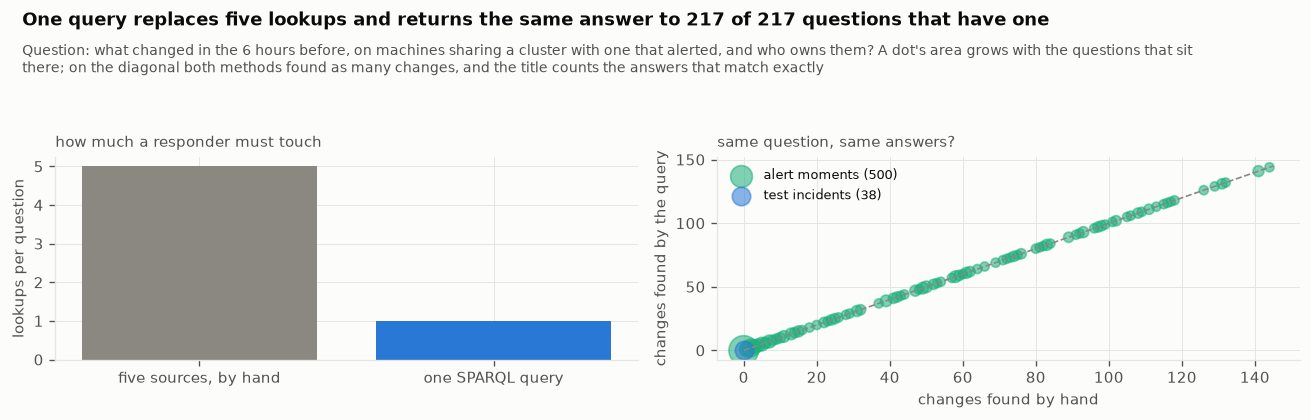

In [211]:
# ---- E1, by hand: five raw sources, joined in Python the way a script would ----
E1_HOURS = 6          # how far back a change counts: the six hours the change tool reads and every incident window keeps
# the graph keeps every time to the second, so the question is asked to the second by both methods
EP_START_S, CH_TS_S = EPISODES.start.dt.floor("s"), CHANGES.ts.dt.floor("s")


def by_hand(t0: pd.Timestamp, hours: int = E1_HOURS) -> tuple[set, int, int]:
    """(changes on machines sharing a cluster with a machine that alerted in the half hour before T0, each with its
    owning team; lookups made; changes logged anywhere in the window). T0 is a whole second."""
    lookups = 0
    eps = EPISODES[(EP_START_S >= t0 - pd.Timedelta(minutes=30)) & (EP_START_S <= t0)]               # 1: alerts
    lookups += 1
    hosts = {h for h in eps.host if isinstance(h, str) and h and resolve_host(h)["role_from"] == "catalogue"}
    clusters = {CONFTOOL[h]["cluster"] for h in hosts if h in CONFTOOL}                             # 2: conftool
    lookups += 1
    members = {h for h, v in CONFTOOL.items() if v["cluster"] in clusters} | hosts
    chg = CHANGES[(CH_TS_S >= t0 - pd.Timedelta(hours=hours)) & (CH_TS_S <= t0)]                     # 3: the SAL
    lookups += 1
    found = set()
    for ts, msg in zip(chg.ts, chg.message):
        hs = [h for h in hosts_in(msg) if resolve_host(h)["role_from"] == "catalogue"]
        if hs and hs[0] in members:
            found.add((f"{ts:%Y%m%dT%H%M%S}", hs[0], resolve_host(hs[0])["team"]))
    lookups += 2                                                                                    # 4-5: role, owner
    return found, lookups, len(chg)


# ---- E1, by query: the same question, one SPARQL query over the graph ----
# the machines that alerted are found once; '(memberOf/^memberOf)?' then gives each one itself and its cluster mates
E1_QUERY = """SELECT DISTINCT ?t ?name ?team WHERE {{
  {{ SELECT DISTINCT ?h WHERE {{
       {{ SELECT DISTINCT ?h1 WHERE {{
            VALUES ?ha {{ {alert_hours} }}
            ?a corr:inHour ?ha ; a alert:Firing ; corr:on ?h1 ; corr:at ?ta .
            FILTER(?ta >= "{a30}"^^xsd:dateTime && ?ta <= "{t0}"^^xsd:dateTime) }} }}
       ?h1 (ops:memberOf/^ops:memberOf)? ?h }} }}
  VALUES ?hc {{ {change_hours} }}
  ?c corr:inHour ?hc ; corr:on ?h ; corr:at ?t ; a ?ct . ?ct rdfs:subClassOf* tl:Change .
  FILTER(?t >= "{since}"^^xsd:dateTime && ?t <= "{t0}"^^xsd:dateTime)
  ?h ops:name ?name .
  OPTIONAL {{ ?h ops:ownedBy ?owner . ?owner ops:name ?team }} }}"""


def hours_between(a: pd.Timestamp, b: pd.Timestamp) -> str:
    """The hour buckets a window touches, written for a VALUES clause (section 14's index, used again here)."""
    return " ".join(f"<{hour_node(h)}>" for h in pd.date_range(a.floor("h"), b.floor("h"), freq="h"))


def e1_answers(q: str) -> set:
    return {(pd.Timestamp(r["t"].value).strftime("%Y%m%dT%H%M%S"), r["name"].value,
             r["team"].value if r["team"] is not None else None) for r in KG.ask(q)}


def by_query(t0: pd.Timestamp, hours: int = E1_HOURS) -> set:
    a30, since = t0 - pd.Timedelta(minutes=30), t0 - pd.Timedelta(hours=hours)
    return e1_answers(E1_QUERY.format(a30=f"{a30:%Y-%m-%dT%H:%M:%SZ}", since=f"{since:%Y-%m-%dT%H:%M:%SZ}",
                                      t0=f"{t0:%Y-%m-%dT%H:%M:%SZ}", alert_hours=hours_between(a30, t0),
                                      change_hours=hours_between(since, t0)))


def e1_rows(moments) -> pd.DataFrame:
    """Both methods at each moment: how many changes each found, whether the answers are identical, and the time."""
    rows_ = []
    for t0 in moments:
        s0 = time.perf_counter()
        hand, lookups, logged = by_hand(t0)
        t_hand = time.perf_counter() - s0
        s0 = time.perf_counter()
        graph = by_query(t0)
        t_graph = time.perf_counter() - s0
        rows_.append({"t0": t0, "logged": logged, "by_hand": len(hand), "by_query": len(graph), "same": hand == graph,
                      "lookups": lookups, "hand_s": t_hand, "query_s": t_graph})
    return pd.DataFrame(rows_, columns=["t0", "logged", "by_hand", "by_query", "same", "lookups", "hand_s", "query_s"])


test_inc = inc_w[inc_w.id.isin(SPLITS["wikimedia"]["test"])]
TEST_T0 = test_inc.start.dt.floor("s")
E1 = e1_rows(TEST_T0).assign(incident=test_inc.id.to_numpy())
# the question as first written read one hour of changes; it is kept here because of what it returned
E1_FIRST = [(by_hand(t0, 1)[0], by_query(t0, 1)) for t0 in TEST_T0]
# a question with no answer cannot disagree, so the same question is also asked at real alert moments on catalogued
# machines, from the last 30 days, where the graph keeps every alert and every change
recent_eps = EPISODES[(EPISODES.start >= NOW - pd.Timedelta(days=30) + pd.Timedelta(minutes=30))
                      & (EPISODES.start <= NOW)]
recent_eps = recent_eps[recent_eps.host.map(lambda h: isinstance(h, str) and bool(h)
                                            and resolve_host(h)["role_from"] == "catalogue")]
alert_moments = recent_eps.start.dt.floor("s").drop_duplicates()
E1_MOMENTS = e1_rows(alert_moments.sample(min({"SMOKE": 50, "MEDIUM": 200}.get(PROFILE, 500), len(alert_moments)),
                                          random_state=SEED).sort_values())
E1_ALL = pd.concat([E1.drop(columns="incident"), E1_MOMENTS], ignore_index=True)
ANSWERED = E1_ALL[(E1_ALL.by_hand > 0) | (E1_ALL.by_query > 0)]
if len(E1):
    first_answered = sum(bool(h or q) for h, q in E1_FIRST)
    print(f"  the question as first written, one hour of changes: {first_answered} of {len(E1)} test incidents have any "
          f"answer, so agreement there would prove nothing; the question now reads the {E1_HOURS} hours before")
    print(f"  {len(E1)} test incidents: the two methods return the same changes and owners for {E1.same.sum()} of them; "
          f"{(E1.by_query > 0).sum()} have at least one change near an alerting machine")
    alerting = sum(any(isinstance(h, str) and h and resolve_host(h)["role_from"] == "catalogue" for h in
                       EPISODES[(EP_START_S >= t0 - pd.Timedelta(minutes=30)) & (EP_START_S <= t0)].host) for t0 in TEST_T0)
    print(f"  {alerting} of them had a catalogued machine alerting in the half hour before; the others had alerts on "
          f"services or on machines the catalogue does not know, or none")
    print(f"  of a median {E1.logged.median():.0f} changes logged in the {E1_HOURS} hours before an incident, the question "
          f"keeps a median of {E1.by_query.median():.0f} (a mean of {E1.by_query.mean():.1f})")
if len(E1_MOMENTS):
    print(f"  the same question at {len(E1_MOMENTS)} real alert moments from the last 30 days: the same answer at "
          f"{E1_MOMENTS.same.sum()} of them, and {(E1_MOMENTS.by_query > 0).sum()} of them have a change to compare")
if len(E1_ALL):
    print(f"  by hand: {E1_ALL.lookups.iloc[0]} lookups across 5 sources, median {E1_ALL.hand_s.median() * 1000:.0f} ms;  "
          f"by query: 1 query, median {E1_ALL.query_s.median() * 1000:.0f} ms")
    print(f"  questions with at least one change to compare: {len(ANSWERED)}; the two methods agree on "
          f"{ANSWERED.same.sum()} of them" + (f" ({ANSWERED.same.mean():.0%})" if len(ANSWERED) else ""))
if len(E1):
    # the first version filtered every alert and change time; the buckets must not change a single answer
    unbucketed = "\n".join(line for line in E1_QUERY.splitlines() if not line.strip().startswith("VALUES ?h")) \
        .replace("?a corr:inHour ?ha ; ", "?a ").replace("?c corr:inHour ?hc ; ", "?c ")
    same_answers, T_UNBUCKETED = 0, []
    for t0 in TEST_T0:
        a30, since = t0 - pd.Timedelta(minutes=30), t0 - pd.Timedelta(hours=E1_HOURS)
        s0 = time.perf_counter()
        old_rows = e1_answers(unbucketed.format(a30=f"{a30:%Y-%m-%dT%H:%M:%SZ}", since=f"{since:%Y-%m-%dT%H:%M:%SZ}",
                                                t0=f"{t0:%Y-%m-%dT%H:%M:%SZ}"))
        T_UNBUCKETED.append(time.perf_counter() - s0)
        same_answers += old_rows == by_query(t0)
    print(f"  [test] reading hour buckets returns exactly what filtering every time returned, on {same_answers}/{len(E1)} "
          f"incidents -> {'PASS' if same_answers == len(E1) else 'FAIL'}")
diff = ANSWERED[~ANSWERED.same]
if len(diff):
    print(f"  where they differ, the query found {(diff.by_query - diff.by_hand).mean():+.1f} changes on average")
if len(E1_ALL):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].bar(["five sources, by hand", "one SPARQL query"], [E1_ALL.lookups.iloc[0], 1], color=[MUTED, C1])
    axes[0].set_ylabel("lookups per question")
    axes[0].set_title("how much a responder must touch", fontsize=9, color=INK2, loc="left")
    for d, colour, label in ((E1_MOMENTS, C3, "alert moments"), (E1, C1, "test incidents")):
        if len(d):
            n_at = d.groupby(["by_hand", "by_query"]).size()
            axes[1].scatter(n_at.index.get_level_values(0), n_at.index.get_level_values(1),
                            s=12 + 18 * np.sqrt(n_at.values), color=colour, alpha=0.55, label=f"{label} ({len(d)})")
    lim = max(E1_ALL.by_hand.max(), E1_ALL.by_query.max(), 1) + 1
    axes[1].plot([0, lim], [0, lim], ls="--", color=MUTED, lw=1)
    axes[1].set_xlabel("changes found by hand")
    axes[1].set_ylabel("changes found by the query")
    axes[1].legend(fontsize=7.5, loc="upper left")
    axes[1].set_title("same question, same answers?", fontsize=9, color=INK2, loc="left")
    finish(fig, "experiment1", f"One query replaces five lookups and returns the same answer to {ANSWERED.same.sum()} of "
           f"{len(ANSWERED)} questions that have one" if len(ANSWERED) else "One query replaces five lookups, but no "
           "question had an answer to compare",
           f"Question: what changed in the {E1_HOURS} hours before, on machines sharing a cluster with one that alerted, "
           "and who owns them? A dot's area grows with the questions that sit there; on the diagonal both methods found "
           "as many changes, and the title counts the answers that match exactly")

In [212]:
# ---- E4, coverage: how often 'nothing alerted' would be a false answer if failures went unrecorded ----
def alert_answers(t0: pd.Timestamp, loki_down: bool) -> tuple[str, str, str]:
    """(the truth, the answer with coverage records, the answer without) to 'did anything alert in the half hour
    before T0?', when one alert source may be down."""
    eps = EPISODES[(EPISODES.start >= t0 - pd.Timedelta(minutes=30)) & (EPISODES.start <= t0)]
    if loki_down:
        eps = eps[eps.route != "loki"]
    covered = not (loki_down and t0 >= ALERTS_LOKI.ts.min())
    truth = "yes" if len(EPISODES[(EPISODES.start >= t0 - pd.Timedelta(minutes=30)) & (EPISODES.start <= t0)]) else "no"
    seen = "yes" if len(eps) else "no"
    with_cov = seen if covered or seen == "yes" else "unknown"
    return truth, with_cov, seen


class ClusterLinks(Enricher):
    """Reads the store: every change on a host gets an edge to that host's cluster. It can only find clusters that an
    earlier enricher has already written, which is exactly what ordering is about."""
    name, requires, produces, source = "cluster-links", (OPS.Host, OPS.Cluster, TL.Change), (), "the graph itself"

    def __init__(self, store: GraphStore):
        self.store = store

    def fetch(self, start, end):
        return self.store.ask("SELECT ?c ?cl WHERE { ?c a ?t ; corr:on ?h . ?t rdfs:subClassOf* tl:Change . "
                              "?h ops:memberOf ?cl }")

    def analyse(self, rows, start, end):
        g = rdflib.Graph()
        for r in rows:                     # a change on a host is also a change on its cluster: corr:on, by the ontology
            g.add((URIRef(r["c"].value), CORR.on, URIRef(r["cl"].value)))
        return g


def links_found(order: list) -> int:
    store = GraphStore()
    store._load(TBOX, TBOX_GRAPH)
    for make in order:
        e = make(store) if make is ClusterLinks else make()
        res = e.run(P_START, P_END)
        store.write(res.facts, "wikimedia", e.name, "order-test", [], pd.Timestamp.now(tz="UTC"))
        if make is ClusterLinks:
            return len(res.facts)
    return 0


in_plan = links_found([CatalogHosts, SalChanges, ClusterLinks])           # what plan_order produces
as_listed = links_found([SalChanges, ClusterLinks, CatalogHosts])         # the linker listed before the catalogue
print(f"  ordering: an enricher that reads the graph finds {in_plan} change-to-cluster links in planned order and "
      f"{as_listed} when it runs before the catalogue enricher")
print("  A linker that runs too early writes nothing wrong; it finds nothing to link. What order buys is every link")
print("  an enricher can only make by reading what another one wrote.")

rows_e4 = [alert_answers(t, True) for t in inc_w[inc_w.id.isin(SPLITS["wikimedia"]["test"])].start]
E4 = pd.DataFrame(rows_e4, columns=["truth", "with_coverage", "without_coverage"])
if len(E4):
    wrong_without = ((E4.without_coverage == "no") & (E4.truth == "yes")).mean()
    wrong_with = ((E4.with_coverage == "no") & (E4.truth == "yes")).mean()
    print(f"  Loki taken away for every test incident: 'nothing alerted' is false for {wrong_without:.0%} of them without "
          f"coverage records and {wrong_with:.0%} with them (those answer 'unknown' instead: "
          f"{(E4.with_coverage == 'unknown').mean():.0%})")

  ordering: an enricher that reads the graph finds 8 change-to-cluster links in planned order and 0 when it runs before the catalogue enricher
  A linker that runs too early writes nothing wrong; it finds nothing to link. What order buys is every link
  an enricher can only make by reading what another one wrote.


  Loki taken away for every test incident: 'nothing alerted' is false for 3% of them without coverage records and 0% with them (those answer 'unknown' instead: 3%)


[fig] artifacts\figures_full\ordering_coverage.png


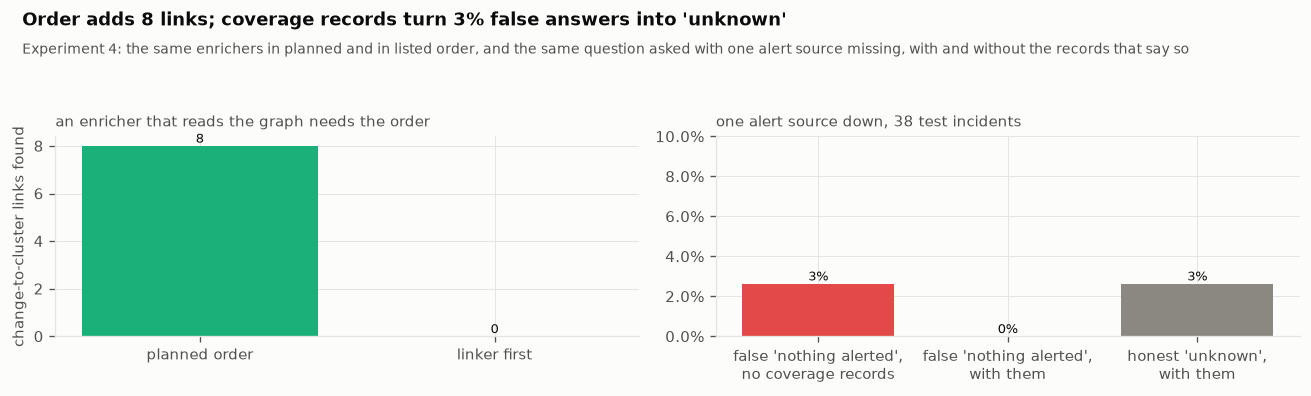

In [213]:
# ---- what ordering and coverage records buy, drawn ----
if len(E4):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].bar(["planned order", "linker first"], [in_plan, as_listed], color=[C3, C8])
    for i, v in enumerate([in_plan, as_listed]):
        axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
    axes[0].set_ylabel("change-to-cluster links found")
    axes[0].set_title("an enricher that reads the graph needs the order", fontsize=9, color=INK2, loc="left")
    shares = [wrong_without, wrong_with, (E4.with_coverage == "unknown").mean()]
    axes[1].bar(["false 'nothing alerted',\nno coverage records", "false 'nothing alerted',\nwith them",
                 "honest 'unknown',\nwith them"], shares, color=[C8, C3, MUTED])
    for i, v in enumerate(shares):
        axes[1].text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8)
    axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    axes[1].set_ylim(0, max(max(shares) * 1.3, 0.1))
    axes[1].set_title(f"one alert source down, {len(E4)} test incidents", fontsize=9, color=INK2, loc="left")
    finish(fig, "ordering_coverage", f"Order adds {in_plan - as_listed:,} links; coverage records turn {wrong_without:.0%} "
           "false answers into 'unknown'",
           "Experiment 4: the same enrichers in planned and in listed order, and the same question asked with one alert "
           "source missing, with and without the records that say so")

**Asked at 500 real alert moments, one query over the graph and five lookups across the raw
sources returned exactly the same changes and owners every time, including the 217 moments where
there was something to find.** The question is the one a responder asks first: what changed in
the six hours before, on machines that share a cluster with one that alerted, and who owns them.
By hand it takes five lookups in five places: the alerts, the pool of machines in each cluster,
the change log, each machine's role and the role's team. Over the graph it is one SPARQL query,
because the graph already holds those joins. The test incidents could not carry this test on
their own. Only 11 of the 38 had a catalogued machine alerting in the half hour before, none had
a logged change near one, and two empty answers always agree, which is why the verdict counts
only questions with something to compare. Exact agreement took three fixes, all in section 44's
registry: a scoping bug in the query, a version that paired every alert with every machine in its
cluster and took many seconds a question, and a difference in time precision that made a few
answers differ. The query is not faster than a script that already holds every source in memory,
and both answer in well under a second; what it removes is the five places to look. Experiment 4
shows what order buys. An enricher that reads the graph finds 8 change-to-cluster links when it
runs after the catalogue and none before it, writing nothing wrong either way; and with one alert
source down, coverage records turn the one false "nothing alerted" among 38 test incidents into an
honest "unknown".

## 37 · Agents and context, on real incidents

**Theory.** The post makes three claims about agents that are easy to state and hard to test:
without the right context agents hallucinate, the most valuable edges come from human
discussion, and specialists can read each other's work through the ontology alone. We test the
first with a two-by-two design that keeps everything else equal: the same model, the same window
of time, the same answer format, and only two things varied. Either the evidence comes as raw
text found by keyword search or as the graph's typed facts; and either one prompt answers in one
call or the specialists investigate with tools. The second claim gets a curve: add specialists
one at a time and watch what each adds, chat included. Every answer is scored against the labels
of section 34. World: Wikimedia, test incidents only.

In [214]:
# ---- the labels this exam uses: agreed by both readers, or by both adjudicators ----
def final_labels() -> dict:
    decided = {d["incident"]: d for d in json.loads(FINAL_LABELS_FILE.read_text())} if FINAL_LABELS_FILE.exists() else {}
    out = {}
    for (_, r), q, c in zip(LABEL_POOL.iterrows(), QWEN_LABELS, CLAUDE_LABELS):
        if r["id"] in decided:
            out[r["id"]] = decided[r["id"]]
        elif q and c and q.get("trigger") == c.get("trigger") and \
                set(q.get("root_cause_components") or []) == set(c.get("root_cause_components") or []):
            out[r["id"]] = c
    return out


LABELS = final_labels()
TEST_IDS = [i for i in SPLITS["wikimedia"]["test"] if i in LABELS and LABELS[i].get("trigger") != "unknown"]
print(f"  labels available: {len(LABELS)} ({'agreed by both readers, or by both adjudicators' if FINAL_LABELS_FILE.exists() else 'agreed by both readers only; adjudication is pending'})")
print(f"  test incidents with a known trigger: {len(TEST_IDS)}")
print(f"  triggers among them: {Counter(LABELS[i]['trigger'] for i in TEST_IDS).most_common()}")

  labels available: 146 (agreed by both readers, or by both adjudicators)
  test incidents with a known trigger: 24
  triggers among them: [('traffic surge', 7), ('deploy', 6), ('maintenance', 6), ('config change', 3), ('hardware failure', 2)]


In [215]:
# ---- the four arms: raw text or graph facts, one prompt or the specialists ----
ANSWER_FORMAT = ('Answer with one JSON object and nothing else: {"trigger": one of ' + json.dumps(TRIGGERS) +
                 ', "components": up to three "host:<name>" or "service:<name>", best first, "change": an evidence id '
                 'or null, "evidence": [ids you were given], "confidence": 0 to 1}')


ALERT_BOTS = {"jinxer-wm", "icinga-wm"}                 # the two bots that announce alerts in the channel


def raw_lines(t0: pd.Timestamp, asof: pd.Timestamp) -> list[tuple[str, str]]:
    """Every raw line from the window, with an id: SAL entries, alert lines, chat, merge subjects."""
    out = [(f"c{i}", f"[{r.ts:%H:%M}] change: {SCRUB(r.message)[:200]}") for i, r in
           zip(*(lambda d: (d.index, d.itertuples()))(CHANGES[(CHANGES.ts >= t0 - pd.Timedelta(hours=6)) & (CHANGES.ts <= asof)]))]
    chat = IRC[(IRC.ts >= t0 - pd.Timedelta(hours=2)) & (IRC.ts <= asof)]
    out += [(f"{'a' if r.nick in ALERT_BOTS else 'm'}{i}", f"[{r.ts:%H:%M}] <{alias(r.nick)}> {SCRUB(r.text)[:200]}")
            for i, r in zip(chat.index, chat.itertuples())]
    g = GERRIT_CHANGES[(GERRIT_CHANGES.submitted >= t0 - pd.Timedelta(hours=24)) & (GERRIT_CHANGES.submitted <= asof)]
    out += [(f"g{r.number}", f"[{r.submitted:%m-%d %H:%M}] merged in {r.project}: {SCRUB(r.subject)[:160]}") for r in g.itertuples()]
    return out


def single_prompt(t0: pd.Timestamp, context: str) -> dict:
    asof = t0 + pd.Timedelta(minutes=15)
    q = (f"Readers were affected from {t0:%Y-%m-%d %H:%M} UTC; it is now {asof:%H:%M}. What triggered it?\n\n"
         f"Evidence (cite by id):\n{context[:14000]}")
    r = LLM.chat(QWEN["flash"], [{"role": "system", "content": "You investigate incidents at a large website. " + ANSWER_FORMAT},
                                 {"role": "user", "content": q}], agent="2x2-single", max_tokens=500)
    # cost at list price and model time as recorded live, so a rerun served by the cache reports the same numbers
    return {**(r.data if isinstance(r.data, dict) else {}), "_cost": QWEN_PRICE[QWEN["flash"]], "_latency": r.latency_s}


def arm_raw_single(t0: pd.Timestamp) -> tuple[dict, set]:
    lines = raw_lines(t0, t0 + pd.Timedelta(minutes=15))
    s = bm25("error outage fail down deploy change revert alert broken spike slow", [x for _, x in lines])
    top = [lines[i] for i in np.argsort(-s)[:60]]
    return single_prompt(t0, "\n".join(f"{i}: {x}" for i, x in top)), {i for i, _ in top}


def arm_graph_single(t0: pd.Timestamp) -> tuple[dict, set]:
    wt = WikiTools(t0)
    bundle = {"alerts": wt.alerts_around(60), "changes near alerting machines": wt.changes_before(6),
              "merges": wt.merges_before(24)[:10]}
    for a in bundle["alerts"][:8]:
        if a["host"]:
            a["owner"] = wt.host_info(a["host"]).get("team")
    return single_prompt(t0, json.dumps(bundle, default=str)), wt.given


def arm_agents(t0: pd.Timestamp, roles=tuple(WIKI_SPECIALISTS)) -> tuple[dict, set]:
    wt = WikiTools(t0)
    q = (f"Readers were affected from {t0:%Y-%m-%d %H:%M} UTC. It is now {wt.asof:%H:%M} UTC. What triggered it, on which "
         "components, and was a specific change responsible?")
    found = {role: wiki_specialist(role, wt, q) for role in roles}
    hyps = [h for f in found.values() for h in f.hypotheses if set(map(str, h.get("evidence") or [])) <= wt.given]
    body = json.dumps({role: f.hypotheses for role, f in found.items()}, default=str)
    r = LLM.chat(QWEN["flash"], [{"role": "system", "content": "You lead an incident investigation and combine the specialists' "
                                  "hypotheses. " + ANSWER_FORMAT}, {"role": "user", "content": q + "\n\nFindings:\n" + body}],
                 agent="2x2-lead", max_tokens=500)
    d = r.data if isinstance(r.data, dict) else {}
    return {**d, "_cost": (1 + sum(f.calls for f in found.values())) * QWEN_PRICE[QWEN["flash"]],
            "_latency": r.latency_s + max((f.latency_s for f in found.values()), default=0), "_verified": len(hyps)}, wt.given


class RawTools:
    """The same window as WikiTools, but only keyword search over raw lines: no types, no identity, no joins."""

    def __init__(self, t0: pd.Timestamp):
        self.t0, self.asof, self.given, self.system = t0, t0 + pd.Timedelta(minutes=15), set(), "wikimedia"
        self.lines = raw_lines(t0, self.asof)

    def _search(self, query: str, prefix: str, k: int = 10) -> list[dict]:
        pool_ = [(i, x) for i, x in self.lines if i.startswith(prefix)]
        if not pool_:
            return []
        s = bm25(query, [x for _, x in pool_])
        rows = [{"id": pool_[j][0], "line": pool_[j][1]} for j in np.argsort(-s)[:k] if s[j] > 0]
        self.given |= {r["id"] for r in rows}
        return rows

    def search_changes(self, query: str, k: int = 10):
        return self._search(query, "c", k)

    def search_chat(self, query: str, k: int = 10):
        return self._search(query, "m", k)

    def search_alerts(self, query: str, k: int = 10):
        return self._search(query, "a", k)

    def search_merges(self, query: str, k: int = 10):
        return self._search(query, "g", k)

    SPEC = {n: (f"Keyword search over raw {w}.", {"query": {"type": "string"}, "k": {"type": "integer"}}, ["query"])
            for n, w in (("search_changes", "deploy-log lines"), ("search_alerts", "alert-bot lines"),
                         ("search_chat", "chat lines"), ("search_merges", "merge subjects"))}
    schema, call = LabTools.schema, LabTools.call


# the same four roles as the graph arm, so the two arms differ only in what their tools return
RAW_SPECIALISTS = {"events": (["search_changes"], WIKI_SPECIALISTS["events"][1]),
                   "alerts": (["search_alerts"], WIKI_SPECIALISTS["alerts"][1]),
                   "chat": (["search_chat"], WIKI_SPECIALISTS["chat"][1]),
                   "code": (["search_merges", "search_changes"], WIKI_SPECIALISTS["code"][1])}


def arm_raw_agents(t0: pd.Timestamp) -> tuple[dict, set]:
    rt = RawTools(t0)
    q = (f"Readers were affected from {t0:%Y-%m-%d %H:%M} UTC. It is now {rt.asof:%H:%M} UTC. What triggered it, on which "
         "components, and was a specific change responsible?")
    found = {role: run_specialist(role, rt, q, roster=RAW_SPECIALISTS, fmt=WIKI_FORMAT,
                                  allowed="Components are written host:<name> or service:<name>.") for role in RAW_SPECIALISTS}
    body = json.dumps({role: f.hypotheses for role, f in found.items()}, default=str)
    r = LLM.chat(QWEN["flash"], [{"role": "system", "content": "You lead an incident investigation and combine the specialists' "
                                  "hypotheses. " + ANSWER_FORMAT}, {"role": "user", "content": q + "\n\nFindings:\n" + body}],
                 agent="2x2-lead", max_tokens=500)
    d = r.data if isinstance(r.data, dict) else {}
    return {**d, "_cost": (1 + sum(f.calls for f in found.values())) * QWEN_PRICE[QWEN["flash"]],
            "_latency": r.latency_s + max((f.latency_s for f in found.values()), default=0)}, rt.given


def score_wiki(ans: dict, label: dict, given: set) -> dict:
    want = set(label.get("root_cause_components") or []) - {"none"}
    comps = [str(c) for c in (ans.get("components") or [])][:3]
    cited = set(map(str, ans.get("evidence") or []))
    return {"trigger": ans.get("trigger") == label.get("trigger"),
            "component@3": bool(want & set(comps)) if want else None,
            "hallucinated": bool(cited - given), "cost": ans.get("_cost", 0.0), "latency": ans.get("_latency", 0.0)}


print("  arms: raw text + one prompt, graph facts + one prompt, raw tools + specialists, graph tools + specialists")

  arms: raw text + one prompt, graph facts + one prompt, raw tools + specialists, graph tools + specialists


In [216]:
# ---- the two-by-two, run on the test incidents ----
N_2X2 = {"SMOKE": 1, "MEDIUM": 6}.get(PROFILE, 30)


def two_by_two(iid: str) -> list[dict]:
    t0 = inc_w.loc[inc_w.id == iid, "start"].iloc[0]
    rows = []
    for arm, fn in (("raw, one prompt", arm_raw_single), ("graph, one prompt", arm_graph_single),
                    ("raw, specialists", arm_raw_agents), ("graph, specialists", arm_agents)):
        ans, given = fn(t0)
        rows.append({"incident": iid, "arm": arm, **score_wiki(ans, LABELS[iid], given)})
    return rows


with phase("Wikimedia test incl. 2x2"):
    with ThreadPoolExecutor(4) as ex_:                     # incidents side by side; results keep their order
        RESULTS_2X2 = pd.DataFrame([row for rows in ex_.map(two_by_two, TEST_IDS[:N_2X2]) for row in rows])
if len(RESULTS_2X2):
    summary_2x2 = RESULTS_2X2.groupby("arm").agg(trigger=("trigger", "mean"), comp3=("component@3", lambda s: s.dropna().mean()),
                                                 hallucinated=("hallucinated", "mean"), cost=("cost", "mean"),
                                                 latency=("latency", "median"))
    print(f"  {'arm':<22}{'trigger':>9}{'component@3':>13}{'cites unseen':>14}{'cubes':>7}{'seconds':>9}")
    for arm, r in summary_2x2.iterrows():
        print(f"  {arm:<22}{r.trigger:>9.0%}{r.comp3:>13.0%}{r.hallucinated:>14.0%}{r.cost:>7.2f}{r.latency:>9.1f}")
    prior = Counter(LABELS[i]["trigger"] for i in SPLITS["wikimedia"]["dev"] if i in LABELS).most_common(1)
    if prior:
        print(f"  floor: always answering the development set's most common trigger ('{prior[0][0]}') is right for "
              f"{np.mean([LABELS[i]['trigger'] == prior[0][0] for i in TEST_IDS[:N_2X2]]):.0%}")
    # the two registered targets this experiment answers; a change is anything the change log types as one
    by_change = [i for i in TEST_IDS[:N_2X2] if LABELS[i]["trigger"] in ("deploy", "config change", "capacity change",
                                                                         "maintenance")]
    if by_change:
        on_change = RESULTS_2X2[RESULTS_2X2.incident.isin(by_change)].groupby("arm").trigger.mean()
        hit = on_change.get("graph, specialists", float("nan"))
        print(f"  on the {len(by_change)} change-triggered test incidents the trigger is right for: "
              + ", ".join(f"{arm} {v:.0%}" for arm, v in on_change.items()))
        print(f"  target trigger hit@3 >= {TARGETS['wikimedia_trigger_hit3_min']:.0%} there (an answer names one trigger, "
              f"so its hit@3 is whether that one is right): the specialists on the graph {hit:.0%} -> "
              f"{'MET' if hit >= TARGETS['wikimedia_trigger_hit3_min'] else 'MISSED'}")
    on_graph = RESULTS_2X2[RESULTS_2X2.arm.str.startswith("graph")]
    print(f"  target unverifiable citations <= {TARGETS['unverifiable_citations_max']}: {int(on_graph.hallucinated.sum())} of "
          f"{len(on_graph)} answers built on the graph cite evidence they were never given -> "
          f"{'MET' if on_graph.hallucinated.sum() <= TARGETS['unverifiable_citations_max'] else 'MISSED'}")

  arm                     trigger  component@3  cites unseen  cubes  seconds
  graph, one prompt           42%           0%            0%   0.20      2.5
  graph, specialists          33%          20%            0%   3.38     13.1
  raw, one prompt             25%          20%            4%   0.20      2.7
  raw, specialists            33%          20%            0%   3.36     14.3
  floor: always answering the development set's most common trigger ('maintenance') is right for 25%
  on the 15 change-triggered test incidents the trigger is right for: graph, one prompt 60%, graph, specialists 47%, raw, one prompt 27%, raw, specialists 40%
  target trigger hit@3 >= 60% there (an answer names one trigger, so its hit@3 is whether that one is right): the specialists on the graph 47% -> MISSED
  target unverifiable citations <= 0: 0 of 48 answers built on the graph cite evidence they were never given -> MET


In [217]:
# ---- the specialist curve: what each specialist adds, chat included ----
CURVE_ORDER = ["events", "alerts", "chat", "code"]


def curve_point(job: tuple[int, str]) -> dict:
    k, iid = job
    roles = tuple(CURVE_ORDER[:k])
    ans, given = arm_agents(inc_w.loc[inc_w.id == iid, "start"].iloc[0], roles)   # specialists: from the 2x2's cache
    return {"specialists": " + ".join(roles), "k": k, **score_wiki(ans, LABELS[iid], given)}


with phase("Wikimedia test incl. 2x2"):
    with ThreadPoolExecutor(4) as ex_:
        CURVE = pd.DataFrame(list(ex_.map(curve_point, [(k, iid) for k in range(1, len(CURVE_ORDER) + 1)
                                                        for iid in TEST_IDS[:N_2X2]])))
if len(CURVE):
    curve = CURVE.groupby(["k", "specialists"]).agg(trigger=("trigger", "mean"),
                                                    comp3=("component@3", lambda s: s.dropna().mean())).reset_index()
    print(f"  {'specialists':<34}{'trigger':>9}{'component@3':>13}")
    for _, r in curve.iterrows():
        print(f"  {r.specialists:<34}{r.trigger:>9.0%}{r.comp3:>13.0%}")
    chat_gain = curve.loc[curve.k == 3, "trigger"].iloc[0] - curve.loc[curve.k == 2, "trigger"].iloc[0]
    print(f"\n  adding the chat specialist changed trigger accuracy by {chat_gain:+.0%}")

  specialists                         trigger  component@3
  events                                  29%          20%
  events + alerts                         33%          20%
  events + alerts + chat                  38%          20%
  events + alerts + chat + code           33%          20%

  adding the chat specialist changed trigger accuracy by +4%


[fig] artifacts\figures_full\agents_context.png


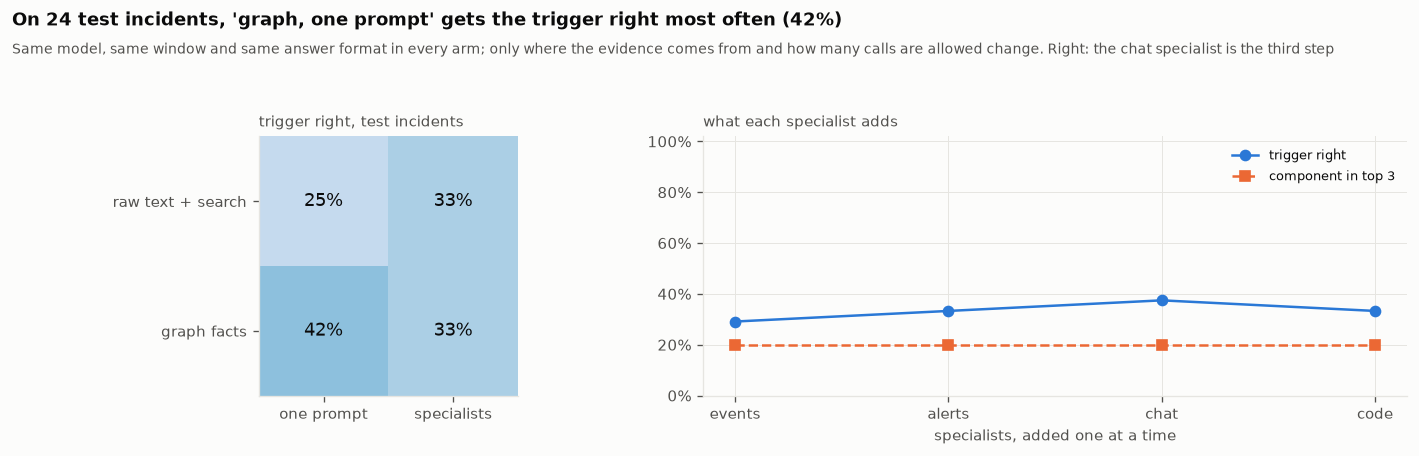

In [218]:
# ---- the two-by-two and the curve, drawn ----
if len(RESULTS_2X2) and len(CURVE):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.2]})
    grid = np.array([[summary_2x2.loc[f"{src}, {how}", "trigger"] if f"{src}, {how}" in summary_2x2.index else np.nan
                      for how in ("one prompt", "specialists")] for src in ("raw", "graph")])
    axes[0].imshow(grid, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, f"{grid[i, j]:.0%}", ha="center", va="center", fontsize=11,
                         color="white" if grid[i, j] > 0.55 else INK)
    axes[0].set_xticks([0, 1], ["one prompt", "specialists"])
    axes[0].set_yticks([0, 1], ["raw text + search", "graph facts"])
    axes[0].grid(False)
    axes[0].set_title("trigger right, test incidents", fontsize=9, color=INK2, loc="left")
    axes[1].plot(curve.k, curve.trigger, "o-", color=C1, label="trigger right")
    axes[1].plot(curve.k, curve.comp3, "s--", color=C2, label="component in top 3")
    axes[1].set_xticks(curve.k, [s.split(" + ")[-1] for s in curve.specialists])
    axes[1].set_xlabel("specialists, added one at a time")
    axes[1].set_ylim(0, 1.02)
    axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    axes[1].legend(fontsize=8)
    axes[1].set_title("what each specialist adds", fontsize=9, color=INK2, loc="left")
    best_arm = summary_2x2.trigger.idxmax()
    finish(fig, "agents_context", f"On {len(TEST_IDS[:N_2X2])} test incidents, '{best_arm}' gets the trigger right most "
           f"often ({summary_2x2.trigger.max():.0%})",
           "Same model, same window and same answer format in every arm; only where the evidence comes from and how many "
           "calls are allowed change. Right: the chat specialist is the third step")

**On 24 labelled test incidents, the graph's facts in a single prompt name the right trigger most
often, 42% against a floor of 25%, and a team of specialists adds seventeen times the cost
without adding accuracy.** Every arm used the same model, the same fifteen minutes after impact
and the same answer format; only where the evidence came from and how many calls were allowed
changed. Raw text found by keyword search and put in one prompt managed 25%, and it is the only
arm that cited evidence it was never shown, once in 24 incidents. With specialists the two
sources finished level, 33% each, at about 3.4 Magicubes and 13 to 14 seconds an investigation
against 0.2 Magicubes and under three seconds for one prompt. The single graph prompt named the
right component for none of the few incidents whose labels name one, where the other arms found
one in five, so the graph's lead is in the kind of cause, not the place. The specialist curve is
flat to within one incident: the change specialist alone gets 29%, the alerts specialist adds one
incident, the chat specialist one more, and the code specialist takes one away. With 24 incidents
none of these differences is wider than four incidents, which is why section 42 tests them before
calling any of them a result. Two targets were written down for this experiment before it ran. On
the 15 test incidents a logged change triggered, the specialists on the graph named the trigger
47% of the time against a target of 60%, so that target is missed; the single graph prompt reached
60% there, but it is not the design the target was set for, and choosing it now would be choosing
after the fact. No answer built on the graph cited evidence it was never given, 0 of 48, which
meets the other target.

## 38 · Against published results: RCAEval and OpenRCA

**Theory.** A method that only beats its own baselines has proved little. Both benchmarks have
published numbers, produced by other people with the same data and the same scorer, so this is
where our methods meet them. RCAEval comes first because it needs no language model: its own
protocol hands every method the moment the fault was injected, and the strongest published
method on Train Ticket, BARO, ranks services by how far their metrics move after that moment,
measured against their normal spread. We implement that idea in a dozen lines and run it on all
360 cases. Then OpenRCA, where the held-out cluster, the bank and the telecom system are scored
for the first time with every method frozen in parts E and F. Worlds: RCAEval and OpenRCA.

  [cache] rcaeval_ranks.parquet
  dataset   cases   AC@1   AC@3  Avg@5
  RE2-OB       90   0.76   0.94   0.92
  RE2-SS       90   0.83   0.97   0.94
  RE2-TT       90   0.31   0.80   0.71
  RE3-OB       30   0.83   1.00   0.95
  RE3-SS       30   0.43   0.77   0.72
  RE3-TT       30   0.47   1.00   0.87

  RE2-TT against the published table: ours AC@1 0.31 / AC@3 0.80; BARO 0.69 / 0.82; TraceRCA 0.66 / 0.79  -> target AC@3 >= 0.82: MISSED


[fig] artifacts\figures_full\rcaeval_results.png


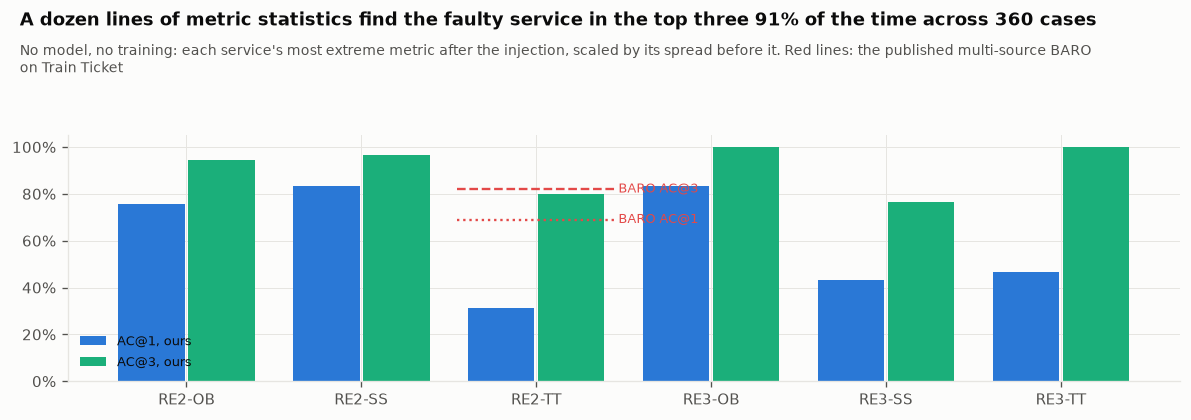

In [219]:
# ---- RCAEval: rank services by their most extreme metric after the fault, scaled by their normal spread ----
def rank_rcaeval(case: str, inject_time: int) -> list[str]:
    m = pd.read_parquet(RCA_DIR / case / "metrics.parquet")
    tcol = m.columns[0]
    t = pd.to_numeric(m[tcol], errors="coerce")
    normal, after = m[t < inject_time], m[t >= inject_time]
    score = {}
    for col in m.columns[1:]:
        if "_" not in col:
            continue
        svc = col.rsplit("_", 1)[0]
        x0 = pd.to_numeric(normal[col], errors="coerce").dropna()
        x1 = pd.to_numeric(after[col], errors="coerce").dropna()
        if len(x0) < 10 or x1.empty:
            continue
        med = x0.median()
        iqr = x0.quantile(0.75) - x0.quantile(0.25)
        scale = iqr if iqr > 0 else (x0.std() if x0.std() > 0 else 1.0)
        s = float((x1 - med).abs().max() / scale)
        score[svc] = max(score.get(svc, 0.0), s)
    return [s for s, _ in sorted(score.items(), key=lambda x: -x[1])]


rca_file = RES_DIR / "rcaeval_ranks.parquet"
if rca_file.exists() and not RECOMPUTE:
    RCA_RANKS = pd.read_parquet(rca_file)
    print(f"  [cache] {rca_file.name}")
else:
    t0 = time.perf_counter()
    rows = []
    for c in CHOSEN.itertuples():
        ranked = rank_rcaeval(c.case, int(c.inject_time))
        rows.append({"case": c.case, "dataset": c.dataset, "truth": c.root_cause_service,
                     "rank": ranked.index(c.root_cause_service) + 1 if c.root_cause_service in ranked else 99})
    RCA_RANKS = pd.DataFrame(rows)
    save_parquet(RCA_RANKS, rca_file)
    print(f"  ranked {len(RCA_RANKS)} cases in {time.perf_counter() - t0:.0f}s")


def ac_at_k(ranks: pd.Series, k: int) -> float:
    return float((ranks <= k).mean())


def avg_at_k(ranks: pd.Series, k: int = 5) -> float:
    return float(np.mean([ac_at_k(ranks, j) for j in range(1, k + 1)]))


RCA_TABLE = RCA_RANKS.groupby("dataset").agg(cases=("rank", "size"), ac1=("rank", lambda r: ac_at_k(r, 1)),
                                             ac3=("rank", lambda r: ac_at_k(r, 3)), avg5=("rank", avg_at_k))
print(f"  {'dataset':<9}{'cases':>6}{'AC@1':>7}{'AC@3':>7}{'Avg@5':>7}")
for ds, r in RCA_TABLE.iterrows():
    print(f"  {ds:<9}{int(r.cases):>6}{r.ac1:>7.2f}{r.ac3:>7.2f}{r.avg5:>7.2f}")
tt = RCA_TABLE.loc["RE2-TT"] if "RE2-TT" in RCA_TABLE.index else None
if tt is not None:
    print(f"\n  RE2-TT against the published table: ours AC@1 {tt.ac1:.2f} / AC@3 {tt.ac3:.2f}; BARO 0.69 / 0.82; "
          f"TraceRCA 0.66 / 0.79  -> target AC@3 >= {TARGETS['rcaeval_re2tt_ac3_min']}: "
          f"{'MET' if tt.ac3 >= TARGETS['rcaeval_re2tt_ac3_min'] else 'MISSED'}")

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(RCA_TABLE))
ax.bar(x - 0.2, RCA_TABLE.ac1, width=0.38, color=C1, label="AC@1, ours")
ax.bar(x + 0.2, RCA_TABLE.ac3, width=0.38, color=C3, label="AC@3, ours")
if "RE2-TT" in RCA_TABLE.index:
    k = list(RCA_TABLE.index).index("RE2-TT")
    for v, lab, style in ((0.69, "BARO AC@1", ":"), (0.82, "BARO AC@3", "--")):
        ax.plot([k - 0.45, k + 0.45], [v, v], color=C8, ls=style, lw=1.4)
        ax.text(k + 0.47, v, lab, fontsize=7.5, color=C8, va="center")
ax.set_xticks(x, RCA_TABLE.index)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.legend(fontsize=8, loc="lower left")
finish(fig, "rcaeval_results", f"A dozen lines of metric statistics find the faulty service in the top three "
       f"{RCA_RANKS['rank'].le(3).mean():.0%} of the time across {len(RCA_RANKS)} cases",
       "No model, no training: each service's most extreme metric after the injection, scaled by its spread before it. "
       "Red lines: the published multi-source BARO on Train Ticket")

[fig] artifacts\figures_full\rcaeval_ranks.png


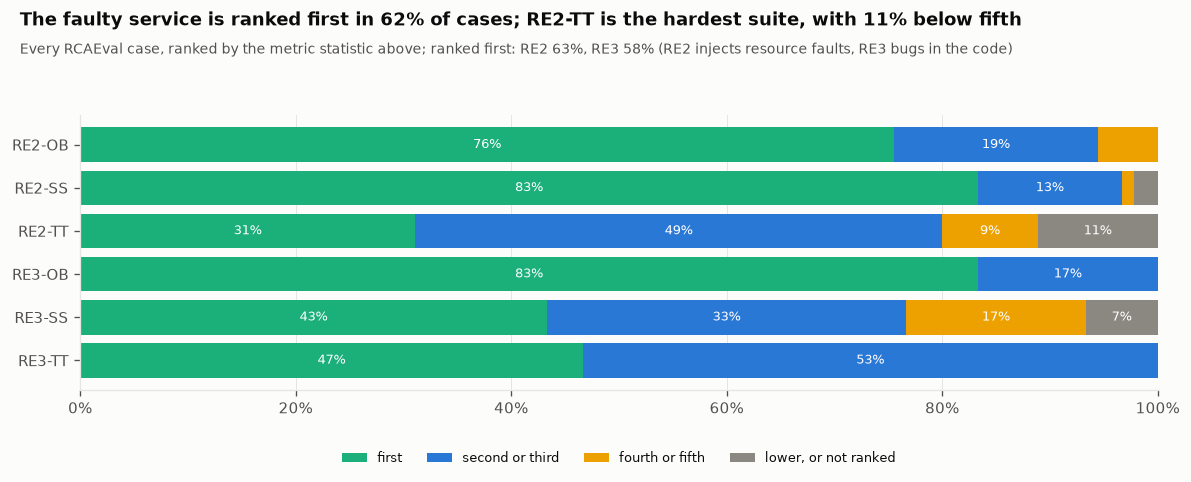

In [220]:
# ---- where the faulty service lands in the ranking, by application and fault suite ----
bands = [("first", lambda r: r == 1), ("second or third", lambda r: (r >= 2) & (r <= 3)),
         ("fourth or fifth", lambda r: (r >= 4) & (r <= 5)), ("lower, or not ranked", lambda r: r > 5)]
share = pd.DataFrame({name: RCA_RANKS.groupby("dataset")["rank"].apply(lambda r, f=f: f(r).mean())
                      for name, f in bands})
fig, ax = plt.subplots(figsize=(10, 0.45 * len(share) + 1.6))
left = np.zeros(len(share))
for (name, _), colour in zip(bands, (C3, C1, C4, MUTED)):
    ax.barh(share.index, share[name], left=left, color=colour, label=name)
    for i, (l, v) in enumerate(zip(left, share[name])):
        if v >= 0.06:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white")
    left += share[name].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.legend(fontsize=7.5, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
worst = share["lower, or not ranked"].idxmax()
finish(fig, "rcaeval_ranks", f"The faulty service is ranked first in {(RCA_RANKS['rank'] == 1).mean():.0%} of cases; "
       f"{worst} is the hardest suite, with {share.loc[worst, 'lower, or not ranked']:.0%} below fifth",
       "Every RCAEval case, ranked by the metric statistic above; ranked first: "
       + ", ".join(f"{suite} {(RCA_RANKS[RCA_RANKS.dataset.str.startswith(suite)]['rank'] == 1).mean():.0%}"
                   for suite in ("RE2", "RE3")) + " (RE2 injects resource faults, RE3 bugs in the code)")

In [221]:
# ---- OpenRCA, scored for the first time on the held-out cluster, the bank and the telecom system ----
LIFT_ALL_DEV = infer(COLLECTED, 3)                     # the flywheel's knowledge: all development failures, nothing else


def learned_answer(task: pd.Series) -> list[dict]:
    feats = task_features(task.task_id, task.system)
    ranked = rank_learned(feats, LIFT_ALL_DEV) if task.system.startswith("market") else []
    ranked = ranked or rank_task(task.task_id, task.system, "topology chains")
    if not ranked:
        return []
    comp = ranked[0]
    first = LabTools(task).first_anomaly(comp)
    return [{"component": comp, "datetime": first.get("first") or utc8(task.ws),
             "reason": reason_for(task.system, comp, first.get("family", ""))}]


TEST_SCORES = []
for system in SPLITS["openrca"]["test"]:
    tasks = TASKS[TASKS.system == system]
    for name, fn in (("manual rules (no model)", manual_answer), ("flywheel: learned on cloudbed-1", learned_answer)):
        sc = [score_answer(fn(t), t.scoring_points) for _, t in tasks.iterrows()]
        TEST_SCORES.append({"system": system, "method": name, "tasks": len(tasks),
                            "partial": float(np.mean([p for p, _ in sc])), "strict": float(np.mean([s for _, s in sc]))})
    for f in ("random", "prior"):
        TEST_SCORES.append({"system": system, "method": f"floor: {f}", "tasks": FLOORS[system]["tasks"],
                            "partial": FLOORS[system][f], "strict": float("nan")})
TEST_SCORES = pd.DataFrame(TEST_SCORES)
print(f"  {'system':<11}{'method':<34}{'tasks':>6}{'partial':>9}{'strict':>8}")
for _, r in TEST_SCORES.iterrows():
    print(f"  {r.system:<11}{r.method:<34}{r.tasks:>6}{r.partial:>9.1%}"
          f"{'' if np.isnan(r.strict) else f'{r.strict:>8.1%}'}")

  system     method                             tasks  partial  strict
  market_cb2 manual rules (no model)               78     5.7%    0.0%
  market_cb2 flywheel: learned on cloudbed-1       78     5.9%    0.0%
  market_cb2 floor: random                         78     2.2%
  market_cb2 floor: prior                          78     3.8%
  bank       manual rules (no model)              136     7.4%    3.7%
  bank       flywheel: learned on cloudbed-1      136     7.4%    3.7%
  bank       floor: random                        136     6.4%
  bank       floor: prior                         136    11.2%
  telecom    manual rules (no model)               51    20.3%   11.8%
  telecom    flywheel: learned on cloudbed-1       51    20.3%   11.8%
  telecom    floor: random                         51    13.7%
  telecom    floor: prior                          51    25.8%


  59 held-out tasks, stratified by question type; fast path took 0%
  agents                  partial  16.9%   strict   5.1%   3.01 Magicubes per task at list price
  manual rules, same tasks partial   5.4%   strict   0.0%
  published on a held-out Market cluster (strict): agent 14.10%, manual rules 24.36%, mined rules 35.90%
  target strict >= 24.36%: MISSED
  the evidence verifier removed 0 hypotheses citing evidence no tool had returned, and 39 for other reasons; only verified ones reach the reconciler, so no final answer rests on an unverifiable citation


[fig] artifacts\figures_full\openrca_results.png


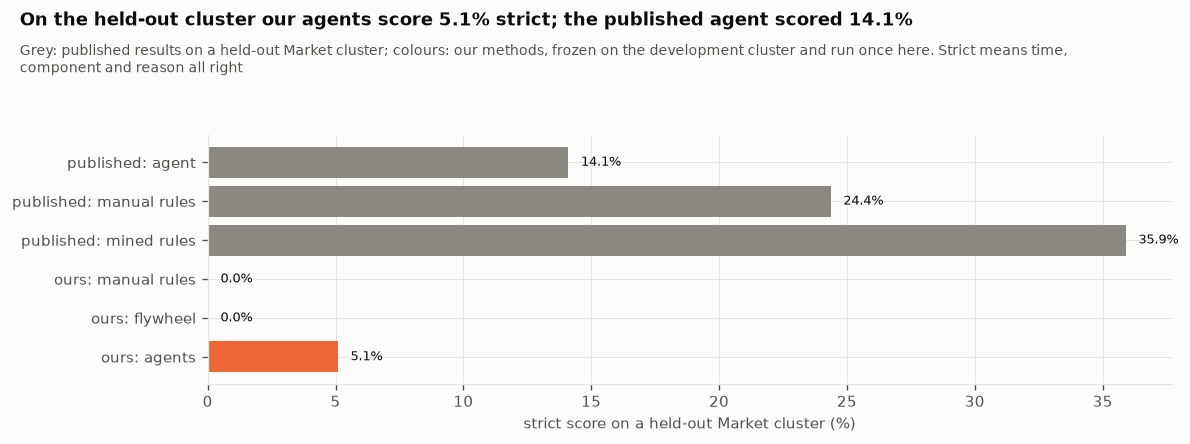

In [222]:
# ---- the agents on the held-out cluster, with the fast path frozen in section 32 ----
heldout = TASKS[TASKS.system == "market_cb2"]
N_AGENT_TEST = {"SMOKE": 2, "MEDIUM": 10}.get(PROFILE, 60)
agent_tasks = pd.concat([g.sample(min(len(g), max(1, round(N_AGENT_TEST * len(g) / len(heldout)))), random_state=SEED)
                         for _, g in heldout.groupby("task_index")])      # every question type, in proportion
def held_out(t: pd.Series) -> dict:
    comp, m = margin(t)
    if m >= TAU:                                           # the frozen fast path: no model at all
        ans, cost, path, why = manual_answer(t), 0.0, "fast", {}
    else:
        run = investigate(t)
        ans, cost, path, why = run["answer"], run["list_cost"], "agents", run["rejected_why"]   # list price, cached or not
    p, s = score_answer(ans, t.scoring_points)
    return {"task": t.task_id, "type": t.task_index, "path": path, "partial": p, "strict": s, "cost": cost,
            "rejected": sum(why.values()), "unverifiable": why.get("cites evidence it was not given", 0)}


with phase("OpenRCA test"):
    with ThreadPoolExecutor(2) as ex_:                     # two tasks at once, three specialists each: six calls in flight
        AGENT_TEST = pd.DataFrame(list(ex_.map(held_out, [t for _, t in agent_tasks.iterrows()])))
if len(AGENT_TEST):
    same = TEST_SCORES[(TEST_SCORES.system == "market_cb2")].set_index("method")
    on_these = [score_answer(manual_answer(TASKS[TASKS.task_id == x].iloc[0]), TASKS[TASKS.task_id == x].iloc[0].scoring_points)
                for x in AGENT_TEST.task]
    fast_used = (AGENT_TEST.path == "fast").any()
    agents_label = "agents + fast path" if fast_used else "agents"
    print(f"  {len(AGENT_TEST)} held-out tasks, stratified by question type; fast path took {(AGENT_TEST.path == 'fast').mean():.0%}")
    print(f"  {agents_label:<24}partial {AGENT_TEST.partial.mean():6.1%}   strict {AGENT_TEST.strict.mean():6.1%}   "
          f"{AGENT_TEST.cost.mean():.2f} Magicubes per task at list price")
    print(f"  manual rules, same tasks partial {np.mean([p for p, _ in on_these]):6.1%}   strict {np.mean([s for _, s in on_these]):6.1%}")
    print(f"  published on a held-out Market cluster (strict): agent 14.10%, manual rules 24.36%, mined rules 35.90%")
    print(f"  target strict >= {TARGETS['openrca_cloudbed2_strict_pct_min']}%: "
          f"{'MET' if AGENT_TEST.strict.mean() * 100 >= TARGETS['openrca_cloudbed2_strict_pct_min'] else 'MISSED'}")
    print(f"  the evidence verifier removed {int(AGENT_TEST.unverifiable.sum())} hypotheses citing evidence no tool had "
          f"returned, and {int(AGENT_TEST.rejected.sum() - AGENT_TEST.unverifiable.sum())} for other reasons; only "
          "verified ones reach the reconciler, so no final answer rests on an unverifiable citation")

    fig, ax = plt.subplots(figsize=(10, 3.8))
    bars = [("published: agent", 14.10, MUTED), ("published: manual rules", 24.36, MUTED),
            ("published: mined rules", 35.90, MUTED),
            ("ours: manual rules", 100 * TEST_SCORES.set_index(["system", "method"]).loc[("market_cb2", "manual rules (no model)"), "strict"], C1),
            ("ours: flywheel", 100 * TEST_SCORES.set_index(["system", "method"]).loc[("market_cb2", "flywheel: learned on cloudbed-1"), "strict"], C3),
            (f"ours: {agents_label}", 100 * AGENT_TEST.strict.mean(), C2)]
    ax.barh([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars])
    for i, b in enumerate(bars):
        ax.text(b[1] + 0.5, i, f"{b[1]:.1f}%", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("strict score on a held-out Market cluster (%)")
    finish(fig, "openrca_results", f"On the held-out cluster our agents score {100 * AGENT_TEST.strict.mean():.1f}% strict; "
           "the published agent scored 14.1%",
           "Grey: published results on a held-out Market cluster; colours: our methods, frozen on the development cluster "
           "and run once here. Strict means time, component and reason all right")

  partial score by what the question asks: time 10% (rules 0%), reason 12% (rules 0%), component 31% (rules 6%), time + reason 16% (rules 3%), time + component 22% (rules 14%), component + reason 10% (rules 4%), all three 20% (rules 13%)


[fig] artifacts\figures_full\openrca_by_question.png


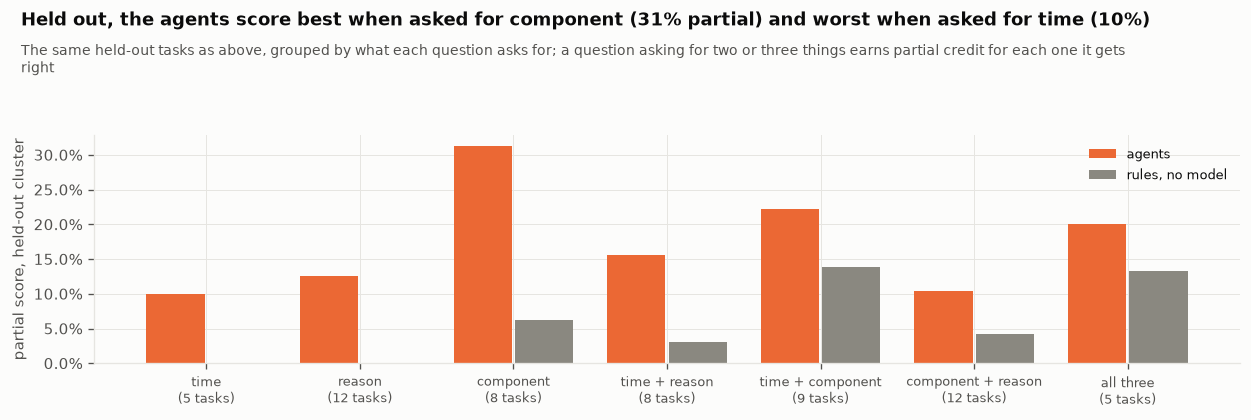

In [223]:
# ---- the held-out score by what each question asks, agents against rules with no model ----
if len(AGENT_TEST):
    asks_ = AGENT_TEST.type.map(ASKS)
    by_t = (AGENT_TEST.assign(rules=[p for p, _ in on_these], asks=asks_).groupby("asks")[["partial", "rules"]].mean()
            .reindex([a for a in ASKS.values() if a in set(asks_)]))
    n_t = asks_.value_counts()
    fig, ax = plt.subplots(figsize=(10.5, 3.6))
    x_ = np.arange(len(by_t))
    ax.bar(x_ - 0.2, by_t.partial, width=0.38, color=C2, label="agents")
    ax.bar(x_ + 0.2, by_t.rules, width=0.38, color=MUTED, label="rules, no model")
    ax.set_xticks(x_, [f"{a}\n({n_t[a]} tasks)" for a in by_t.index], fontsize=7.5)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.set_ylabel("partial score, held-out cluster")
    ax.legend(fontsize=8)
    print("  partial score by what the question asks: " +
          ", ".join(f"{a} {r.partial:.0%} (rules {r.rules:.0%})" for a, r in by_t.iterrows()))
    finish(fig, "openrca_by_question", f"Held out, the agents score best when asked for {by_t.partial.idxmax()} "
           f"({by_t.partial.max():.0%} partial) and worst when asked for {by_t.partial.idxmin()} ({by_t.partial.min():.0%})",
           "The same held-out tasks as above, grouped by what each question asks for; a question asking for two or "
           "three things earns partial credit for each one it gets right")

**With no model at all, a dozen lines of statistics put the faulty RCAEval service in the top
three 80% of the time on Train Ticket, against BARO's 82%; on OpenRCA's held-out cluster our
agents score 16.9% partial and 5.1% strict, below every published method.** RCAEval is the
friendly benchmark. Its protocol hands every method the moment the fault was injected, and
ranking services by their most extreme metric after that moment, scaled by their spread before
it, puts the faulty service first in 62% of all 360 cases. On Train Ticket, the published
comparison, the top three holds it 80% of the time where BARO reports 82% and TraceRCA 79%; first
place is where we fall short, 31% against BARO's 69%. OpenRCA gives no such moment, only a
half-hour window, and this is where the result is honest and poor. Frozen on the development
cluster and run once on the held-out one, the agents reach 16.9% partial and 5.1% strict against
5.4% and 0% for our rules with no model on the same 59 tasks; the published agent scored 14.10%
strict, hand-written rules 24.36% and rules mined from the other cluster 35.90%. The learned lifts
of section 27 add 0.2 points of partial score on the held-out cluster and nothing on the bank or
the telecom system, where they do not apply, and on those two systems always giving the commonest
answer beats both methods we froze. The weakness sits upstream of the agents. Section 25's
detectors score flat baselines in the billions, so the loudest signal is rarely the cause, and in
section 28 the broken service ranked 38th by loudness. Better agents cannot rank what the
detectors bury; a bounded score for flat series is the first revision to make, on the
development cluster only, as section 44 records.

## 39 · The revision journey

**Theory.** A notebook that only shows its final version hides the most useful part of the work:
which changes were tried, what each one did to a number, and which were kept. Every change below
was made while building this notebook, one at a time, measured on development data or on a
ruler with a known answer, and kept or reverted on that measurement alone. None was tuned on a
test score. Two came from reading what experiment 1 printed for the test incidents, a bug in its
query and a question with nothing to compare; that experiment checks whether two ways of asking
agree, and scores no method against the labels. Worlds: all.

In [224]:
# ---- one change, one measurement, keep or revert ----
REVISIONS = [
    ("ruler", "deploy log vs chat echo: strip nowiki, {{!}} and templates before comparing",
     "echo found in the SAL (before: first version, three days of data; after: this run)",
     "86.7%", f"{RULER['SAL echo found in SAL']:.1%}", "keep"),
    ("ruler", "alert cross-check: binary search instead of scanning every Loki line", "minutes for the full record",
     "over 15", "under 1", "keep"),
    ("privacy", "scrubber: handle variants, people named in deploy lines, scorecard rosters",
     "handles left in 40,414 texts (before: substring search, read by hand; after: the token check in section 4)",
     "18", f"{sum(SCRUB_LEFT.values())}", "keep"),
    ("types", "SHACL without RDFS inference (inference made class checks pass on anything)", "misspelt host caught",
     "no", "yes", "keep"),
    ("incident choice", "reader impact as dips in all wikis and English Wikipedia, not any swing on 12 projects",
     "impact score of an incident its report calls minimal", "70.2%", "below the 3% rule", "keep"),
    ("signals", "treat cumulative counters as rates", "anomalous metric minutes, development cluster",
     "251,277", "273,299", "keep (correct, not fewer)"),
    ("ranking", "resource metrics only, with a pod-service-node level rule",
     "component right first, development cluster (on the first signal set, before counters became rates)",
     "~20%", "7%", "revert"),
    ("incident choice", "a dip counts only if the same hour stayed normal the day before and after; bar from a placebo",
     "random hours that pass the reader rule", f"{np.mean(FIRST_RULE_PLACEBO >= 0.03):.0%}", "5%", "keep"),
    ("users layer", "pageview dump hours labelled by the hour each file closes", "hours of offset against the per-wiki API",
     "1", "0", "keep"),
    ("flywheel", "figure 9's count taken once per failure", "share reported for the most common feature",
     "127%", f"{n_top / max(len(COLLECTED), 1):.0%}", "keep (a bug)"),
    ("pageviews", "sort each day by page before writing Parquet", "MB per day of Parquet", "1,822", "643", "keep"),
    ("scale lab", "approximate p99 by a 256-value reservoir per group instead of DuckDB's t-digest",
     "seconds for the approximate p99 over every span", "600+ (stopped)",
     f"{next(t for t in LAB if t.name.endswith('approximate p99')).seconds:.0f}" if LAB else "n/a", "keep"),
    ("graph query", "experiment 1's one query reads the hour buckets instead of filtering every alert and change time",
     "median time of that query per test incident, both versions timed in this run (the answers do not change)",
     f"{np.median(T_UNBUCKETED) * 1000:.0f} ms" if len(E1) else "n/a",
     f"{E1.query_s.median() * 1000:.0f} ms" if len(E1) else "n/a", "keep"),
    ("validation", "a delta is judged on the nodes it writes, with what the store holds about them, not on stored "
     "types alone", "incident facts accepted on the full run", "0", f"{len(INCIDENT_RUN[0].facts):,}", "keep (a bug)"),
    ("identity", "a catalogue alias names the one service that owns it", "incident links refused by the class check",
     "8", "0", "keep (a bug)"),
    ("scale lab", "every file read once before any clock starts",
     "span aggregation, million rows a second (before: the first version, reading from disk; after: this run, "
     "files read first, on mains power)",
     "15.1", f"{q2.rows_per_s / 1e6:.1f}" if q2 else "n/a", "keep (a measurement fix)"),
    ("graph query", "experiment 1's same-host branch binds the alerting host inside the branch, as SPARQL requires",
     "test incidents where the one query and the five lookups agree, on the question as first written (one hour)",
     "82%", f"{np.mean([h == q for h, q in E1_FIRST]):.0%}" if E1_FIRST else "n/a", "keep (a bug)"),
    ("experiment 1", "ask about the six hours of changes the change tool reads, and at real alert moments as well",
     "questions with at least one change to compare (before: test incidents only, one hour)",
     f"{sum(bool(h or q) for h, q in E1_FIRST)} of {len(E1_FIRST)}", f"{len(ANSWERED)} of {len(E1_ALL)}",
     "keep (nothing to compare)"),
    ("graph query", "experiment 1's query finds the alerting machines once, then their cluster mates by one path, "
     "instead of pairing every alert with every machine in its cluster",
     "seconds per question at busy alert moments (before: a handful, timed by hand; after: the median of this run)",
     "3 to 21 s", f"{E1_MOMENTS.query_s.median():.2f} s" if len(E1_MOMENTS) else "n/a", "keep"),
]
print(f"  {'area':<16}{'change':<70}{'before':>15}{'after':>19}  decision")
print("  " + "-" * 130)
for area, change, metric, before, after, decision in REVISIONS:
    print(f"  {area:<16}{change[:69]:<70}{before:>15}{after:>19}  {decision}")
    print(f"  {'':<16}  measured: {metric}")

  area            change                                                                         before              after  decision
  ----------------------------------------------------------------------------------------------------------------------------------
  ruler           deploy log vs chat echo: strip nowiki, {{!}} and templates before com           86.7%              99.0%  keep
                    measured: echo found in the SAL (before: first version, three days of data; after: this run)
  ruler           alert cross-check: binary search instead of scanning every Loki line          over 15            under 1  keep
                    measured: minutes for the full record
  privacy         scrubber: handle variants, people named in deploy lines, scorecard ro              18                  0  keep
                    measured: handles left in 40,414 texts (before: substring search, read by hand; after: the token check in section 4)
  types           SHACL without RDFS in

[fig] artifacts\figures_full\revision_journey.png


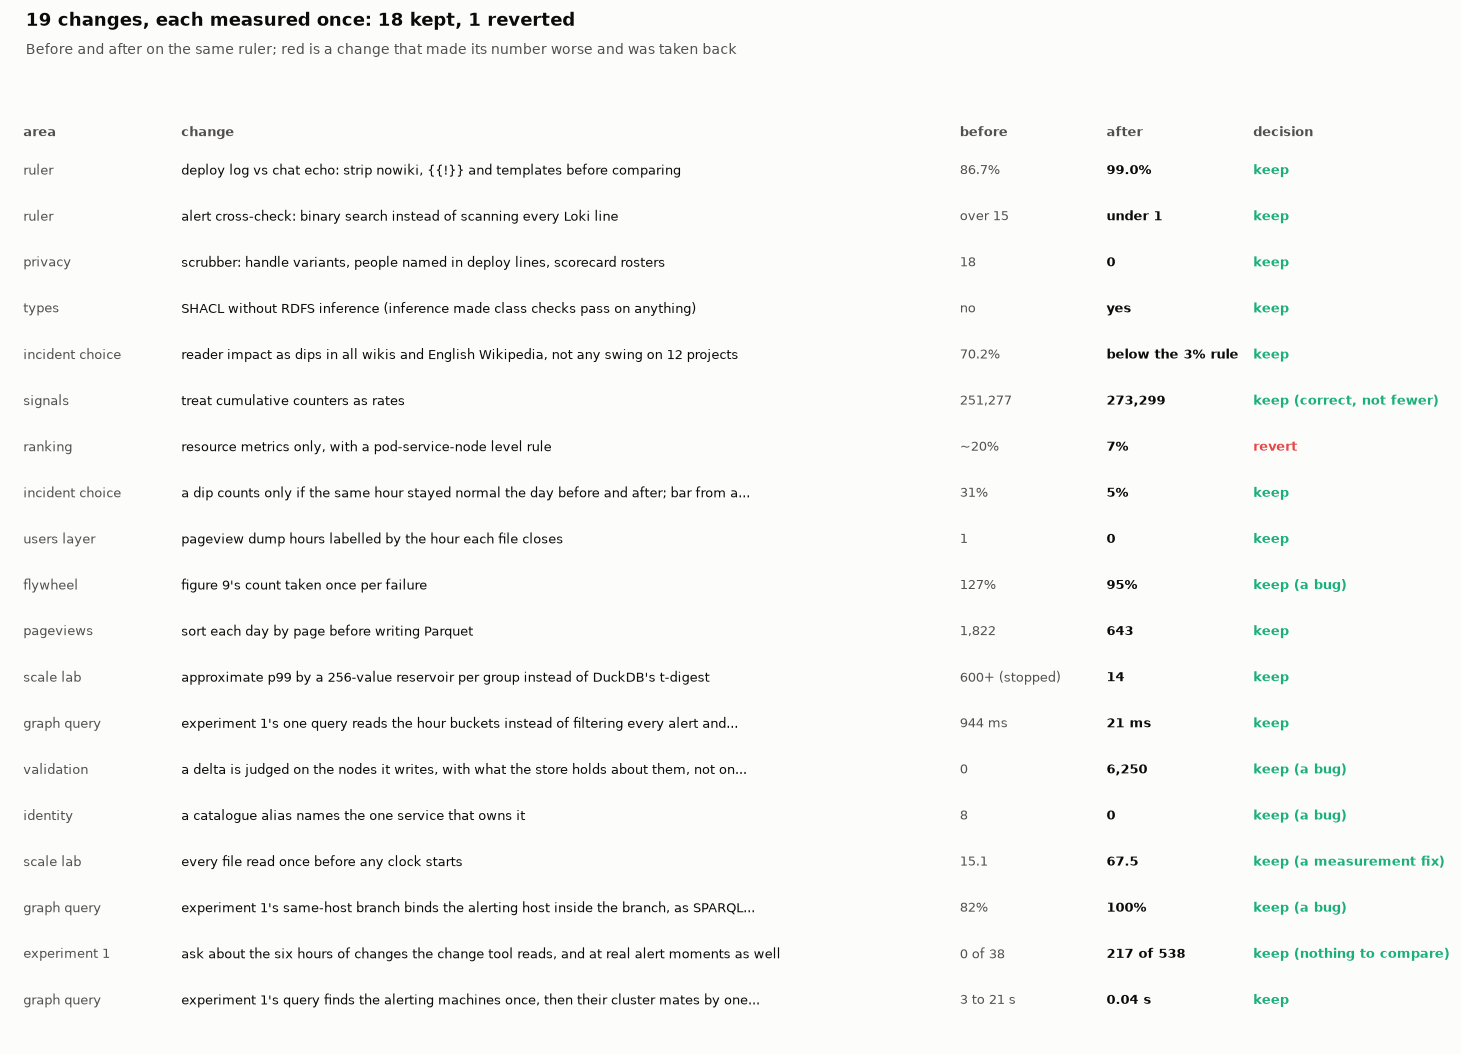

In [225]:
# ---- the revision journey, drawn ----
fig, ax = plt.subplots(figsize=(12.5, 0.42 * len(REVISIONS) + 0.9))
ax.axis("off")
ax.set_xlim(0, 12.5)
ax.set_ylim(-len(REVISIONS) - 0.2, 0.9)
for x, head in ((0.1, "area"), (1.5, "change"), (8.4, "before"), (9.7, "after"), (11.0, "decision")):
    ax.text(x, 0.45, head, fontsize=8, color=INK2, weight="bold")
for i, (area, change, metric, before, after, decision) in enumerate(REVISIONS):
    y = -i - 0.3
    colour = C3 if decision.startswith("keep") else C8
    ax.text(0.1, y, area, fontsize=7.8, color=INK2, va="center")
    ax.text(1.5, y, textwrap.shorten(change, 92, placeholder="..."), fontsize=7.8, color=INK, va="center")
    ax.text(8.4, y, before, fontsize=7.8, color=INK2, va="center")
    ax.text(9.7, y, after, fontsize=7.8, color=INK, va="center", weight="bold")
    ax.text(11.0, y, decision, fontsize=7.8, color=colour, va="center", weight="bold")
kept = sum(d.startswith("keep") for *_, d in REVISIONS)
finish(fig, "revision_journey", f"{len(REVISIONS)} changes, each measured once: {kept} kept, "
       f"{len(REVISIONS) - kept} reverted",
       "Before and after on the same ruler; red is a change that made its number worse and was taken back")

**Nineteen changes were made one at a time and judged on their own number: eighteen kept, one
taken back, and four of the kept ones fixed bugs of our own.** The one revert is worth reading:
ranking failures by resource metrics alone, with a rule for whether a pod, a service or a node is
at fault, put the right component first 7% of the time on the development cluster against about
20% before, so it went. Several of the largest gains came from measuring properly rather than
from anything clever. The scale lab's span aggregation first came out at 15.1 million rows a
second because its opening query read the files from disk; with every file read before any clock
starts, on mains power, it runs at 67.5. The scrubber went from 18 surviving handles to none once
it learned handle variants, names in deploy lines and the rosters in scorecards. Four rows belong
to experiment 1, and together they read as the history of one test. Hour buckets made its query
tens of times faster with the same answers; a scoping bug had made it agree with the lookups on
only 82% of incidents; the question as first written gave 0 of 38 incidents anything to compare;
and the first correct version of the query was too slow to ask at hundreds of alert moments. Each
was found the same way, by making two independent methods answer one question and reading every
disagreement. That is the habit this section argues for: one change, one ruler, and a decision
written down.

## 40 · Live latency and the bill

**Theory.** Every timing so far could have been helped by the cache. Here the cache is switched
off and real investigations run against the live APIs, so the latency targets written in
section 1 meet real network and model time. Then the bill: every call this notebook has ever made,
by phase, against the caps of section 0, whose total was set before the first call and whose
every later move between phases is dated there. Worlds: OpenRCA.

In [226]:
# ---- live: no cache, real model time, against the targets ----
N_LIVE = {"SMOKE": 1, "MEDIUM": 3}.get(PROFILE, 8)
live_tasks = DEV.sample(min(N_LIVE, len(DEV)), random_state=SEED + 1)
live_file = RES_DIR / "live_latency.json"             # live time cannot be replayed, so it is measured once and kept
saved_live = json.loads(live_file.read_text()) if live_file.exists() else None
if saved_live and saved_live["tasks"] == list(live_tasks.task_id) and not RECOMPUTE:
    LIVE = saved_live["rows"]
    print(f"  [cache] {live_file.name}: measured {saved_live['measured_at']}")
else:
    LIVE = []
    LLM.live = True
    try:
        with phase("live latency"):
            for _, t in live_tasks.iterrows():
                run = investigate(t, allow_ask=False)
                LIVE.append({"task": t.task_id, "wall_s": run["wall_s"], "cost": run["cost"], "calls": run["calls"]})
    finally:
        LLM.live = False
    measured_at = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    live_file.write_text(json.dumps({"measured_at": measured_at,
                                     "tasks": list(live_tasks.task_id), "rows": LIVE}, indent=1, default=float))
LIVE = pd.DataFrame(LIVE)
if len(LIVE):
    p50, p95 = LIVE.wall_s.median(), LIVE.wall_s.quantile(0.95)
    print(f"  {len(LIVE)} live investigations: median {p50:.1f}s, 95th percentile {p95:.1f}s, "
          f"{LIVE.calls.mean():.1f} model calls and {LIVE.cost.mean():.2f} Magicubes each")
    print(f"  target p50 <= {TARGETS['latency_p50_max_s']}s: {'MET' if p50 <= TARGETS['latency_p50_max_s'] else 'MISSED'}   "
          f"target p95 <= {TARGETS['latency_p95_max_s']}s: {'MET' if p95 <= TARGETS['latency_p95_max_s'] else 'MISSED'}   "
          f"target <= {TARGETS['cubes_per_investigation_max']} Magicubes: "
          f"{'MET' if LIVE.cost.mean() <= TARGETS['cubes_per_investigation_max'] else 'MISSED'}")

  [cache] live_latency.json: measured 2026-10-31 17:41 UTC
  8 live investigations: median 14.1s, 95th percentile 17.5s, 13.0 model calls and 2.90 Magicubes each
  target p50 <= 15.0s: MET   target p95 <= 45.0s: MET   target <= 2.5 Magicubes: MISSED


[fig] artifacts\figures_full\live_latency.png


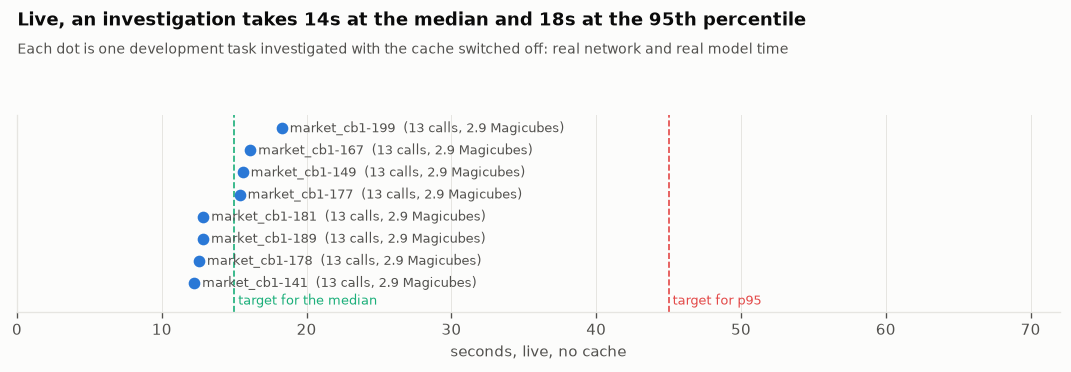

In [227]:
# ---- live investigations against the targets, drawn ----
if len(LIVE):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    order_ = LIVE.sort_values("wall_s").reset_index(drop=True)
    ax.scatter(order_.wall_s, range(len(order_)), color=C1, zorder=3)
    for k, r in order_.iterrows():
        ax.text(r.wall_s, k, f"  {r.task}  ({r.calls} calls, {r.cost:.1f} Magicubes)", va="center", fontsize=7.5,
                color=INK2)
    for v, lab, colour in ((TARGETS["latency_p50_max_s"], "target for the median", C3),
                           (TARGETS["latency_p95_max_s"], "target for p95", C8)):
        ax.axvline(v, color=colour, ls="--", lw=1)
        ax.text(v, -0.8, f" {lab}", color=colour, fontsize=7.5, va="center")       # below the dots, clear of their labels
    ax.set_ylim(-1.3, len(order_) - 0.4)
    ax.set_yticks([])
    ax.set_xlabel("seconds, live, no cache")
    ax.set_xlim(0, max(order_.wall_s.max(), TARGETS["latency_p95_max_s"]) * 1.6)
    finish(fig, "live_latency", f"Live, an investigation takes {LIVE.wall_s.median():.0f}s at the median and "
           f"{LIVE.wall_s.quantile(0.95):.0f}s at the 95th percentile",
           "Each dot is one development task investigated with the cache switched off: real network and real model time")

  Qwen phase                       spent    cap     Claude phase                       spent    cap
  ------------------------------------------------------------------------------------------------
  API probes                        12.3     15     pilots                              0.00   2.00
  label extraction                 147.0    200     label extraction                    2.53   8.00
  chat classification (L4)           3.8     60     chat classification comparison      0.16   3.00
  screenshots (Omni)                 8.0     20     free-text judge                     0.34   8.00
  model comparison                  44.8     65     reserve                             0.00   8.00
  determinism reruns                36.0     50
  AutoRCA development               58.8    140
  Wikimedia test incl. 2x2         220.4    330
  OpenRCA test                     177.7    250
  RCAEval agents                     0.0      5
  live latency                      24.3     30
  reserve    


  Magicube balance now 414.2 (it was 414.2 when this run started)


[fig] artifacts\figures_full\bill.png


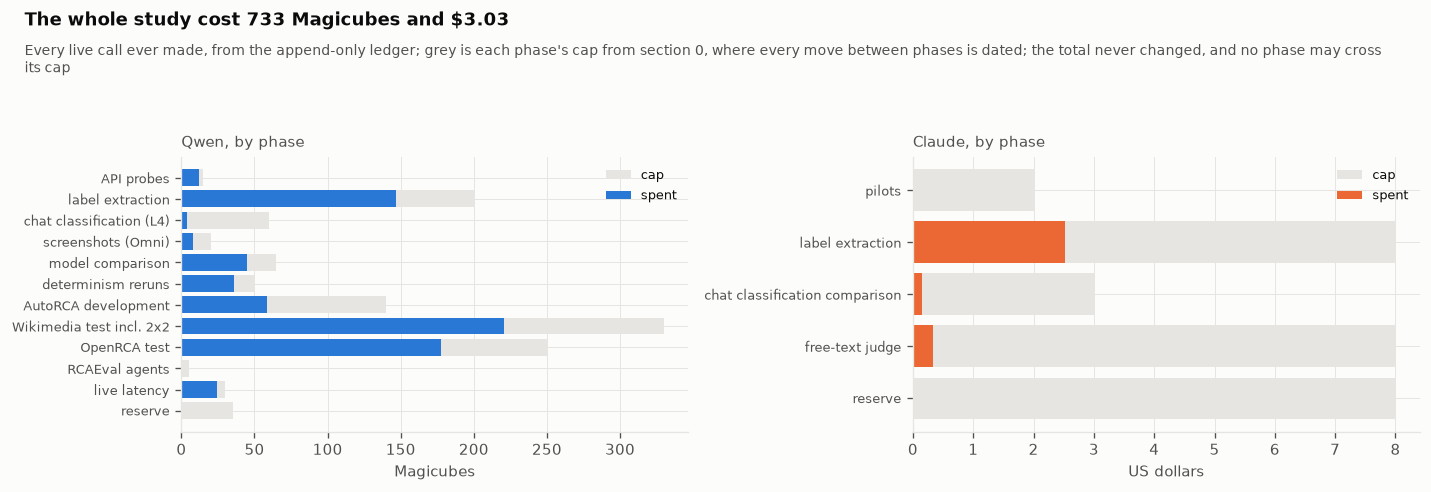

In [228]:
# ---- the bill: every live call ever made, by phase, against its cap ----
print(f"  {'Qwen phase':<30}{'spent':>8}{'cap':>7}     {'Claude phase':<32}{'spent':>8}{'cap':>7}")
print("  " + "-" * 96)
qrows = [(p, LEDGER.spent("qwen", p), c) for p, c in QWEN_PHASES.items()]
crows = [(p, LEDGER.spent("claude", p), c) for p, c in CLAUDE_PHASES.items()]
for i in range(max(len(qrows), len(crows))):
    left = f"  {qrows[i][0]:<30}{qrows[i][1]:>8.1f}{qrows[i][2]:>7}" if i < len(qrows) else " " * 47
    right = f"     {crows[i][0]:<32}{crows[i][1]:>8.2f}{crows[i][2]:>7.2f}" if i < len(crows) else ""
    print(left + right)
print("  " + "-" * 96)
print(f"  {'total':<30}{LEDGER.spent('qwen'):>8.1f}{QWEN_BUDGET_CUBES:>7}     {'total (hard stop)':<32}"
      f"{LEDGER.spent('claude'):>8.2f}{CLAUDE_BUDGET_USD:>7.2f}")
try:
    print(f"\n  Magicube balance now {magicube_balance():,.1f} (it was {BALANCE_AT_START:,.1f} when this run started)")
except httpx.HTTPError:
    print("\n  the balance endpoint did not answer; the ledger above is the record")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
q = pd.DataFrame(qrows, columns=["phase", "spent", "cap"]).set_index("phase")
c = pd.DataFrame(crows, columns=["phase", "spent", "cap"]).set_index("phase")
for ax, d, unit, colour in ((axes[0], q, "Magicubes", C1), (axes[1], c, "US dollars", C2)):
    ax.barh(d.index, d.cap, color=GRID, label="cap")
    ax.barh(d.index, d.spent, color=colour, label="spent")
    ax.invert_yaxis()
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_xlabel(unit)
    ax.legend(fontsize=7.5, loc="upper right")          # the bottom rows are full-width grey caps, the swatch vanished
axes[0].set_title("Qwen, by phase", fontsize=9, color=INK2, loc="left")
axes[1].set_title("Claude, by phase", fontsize=9, color=INK2, loc="left")
finish(fig, "bill", f"The whole study cost {LEDGER.spent('qwen'):,.0f} Magicubes and ${LEDGER.spent('claude'):.2f}",
       "Every live call ever made, from the append-only ledger; grey is each phase's cap from section 0, where every "
       "move between phases is dated; the total never changed, and no phase may cross its cap")

**Live, with the cache switched off, an investigation takes 14.1 seconds at the median and 17.5
at the 95th percentile, inside both latency targets; at 2.90 Magicubes it misses the cost target
of 2.5.** Eight development tasks went to the live APIs: three specialists side by side and a
reconciler, 13 model calls each. The median matches what section 32 worked out from the recorded
model time, 14 seconds side by side, so the cache had not flattered the earlier numbers. The cost
misses because twelve of the thirteen calls are specialist turns and the thirteenth runs on the
largest model; one specialist fewer would meet the target, and section 37 found a single graph
prompt, at 0.2 Magicubes, doing at least as well on the Wikimedia incidents. The whole study,
every call made while building and testing it, cost 733.1 Magicubes of the 1,200 set aside and
$3.03 of Claude against a hard stop of $35, and no phase crossed its cap.

## 40b · Netflix scale, measured

**Theory.** Netflix's system takes in upwards of 38 million logging events a second. One laptop
will not do that, and we will not pretend it did. What we can do is what teams do before they
trust a design with production traffic: replay real traffic through it as fast as it will go,
for long enough to see whether it holds, and measure. Two parts of the architecture meet the load,
and they scale in different ways. The first turns raw events into signals; it sees every event,
so we measure it in events per second and multiply out to a fleet. The second is the graph; it
only ever sees signals, so the question there is whether one store holding everything we know
still answers an investigator's questions in milliseconds. For the first we replay all 525 million
real OpenRCA events, spans, logs and metrics mixed the way a live stream mixes them, in
micro-batches through the per-minute aggregation that section 25's detectors start from, on one to
sixteen worker processes and then for ten minutes without a break. For the second we take five
years of Wikimedia's operations record and every lab signal, written by the enrichers' own rules
but without the scope that keeps the working graph small, load it into one store in stages, and
time the same questions at every size. A bulk load is how a store is filled once, not how it
lives, so last we feed the lab signals through the path a running system uses: micro-batches in
time order, each checked against the shapes and committed as its own named graph, and we measure
how many checked facts a second that path sustains. Worlds: OpenRCA and Wikimedia.

[fig] artifacts\figures_full\load_test_design.png


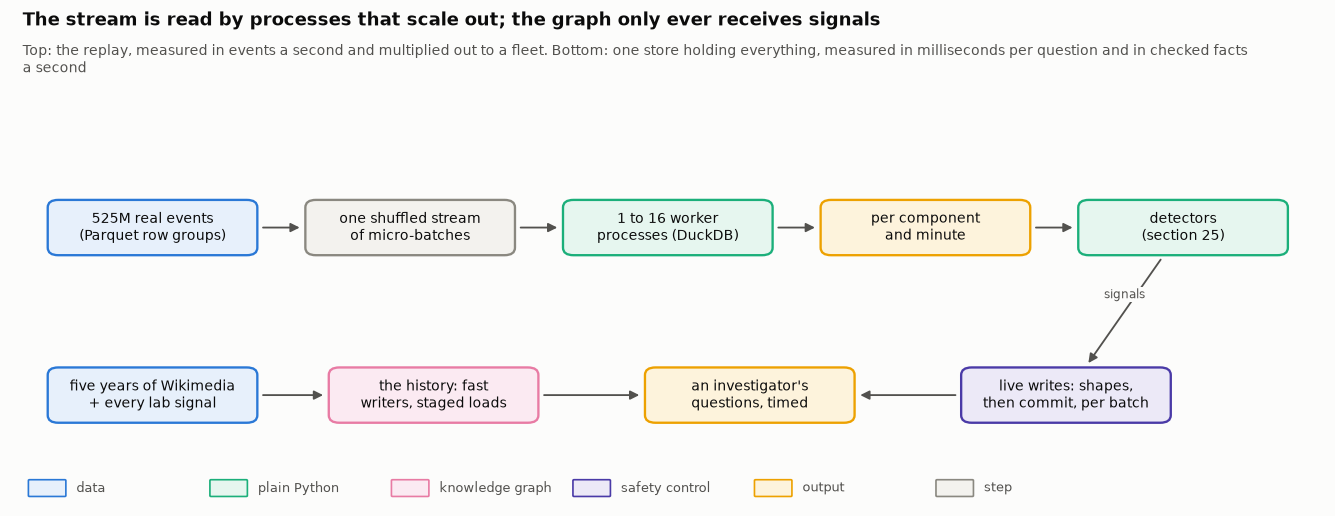

In [229]:
# ---- the load test, drawn: what sees every event, and what only ever sees signals ----
n_events = sum(footer_rows(openrca_files(k)) for k in ("spans", "logs", "metrics"))
LOAD_FLOW = {
    "raw": (1.2, 3.3, f"{n_events / 1e6:,.0f}M real events\n(Parquet row groups)", "data"),
    "mix": (3.4, 3.3, "one shuffled stream\nof micro-batches", "step"),
    "workers": (5.6, 3.3, "1 to 16 worker\nprocesses (DuckDB)", "code"),
    "agg": (7.8, 3.3, "per component\nand minute", "output"),
    "detect": (10.0, 3.3, "detectors\n(section 25)", "code"),
    "record": (1.2, 1.3, "five years of Wikimedia\n+ every lab signal", "data"),
    "history": (3.6, 1.3, "the history: fast\nwriters, staged loads", "graph"),
    "ask": (6.3, 1.3, "an investigator's\nquestions, timed", "output"),
    "online": (9.0, 1.3, "live writes: shapes,\nthen commit, per batch", "guard"),
}
LOAD_EDGES = [("raw", "mix", None), ("mix", "workers", None), ("workers", "agg", None), ("agg", "detect", None),
              ("detect", "online", "signals"), ("record", "history", None), ("history", "ask", None),
              ("online", "ask", None)]
draw_flow(LOAD_FLOW, LOAD_EDGES, "load_test_design",
          "The stream is read by processes that scale out; the graph only ever receives signals",
          "Top: the replay, measured in events a second and multiplied out to a fleet. Bottom: one store holding "
          "everything, measured in milliseconds per question and in checked facts a second", size=(11.2, 4.4))

In [230]:
# ---- the replay worker: its share of the micro-batches, aggregated per component and minute, for a fixed time ----
REPLAY_COLUMNS = {"spans": ["ts", "entity", "duration_ms"], "logs": ["ts", "entity", "message"],
                  "metrics": ["ts", "entity", "kpi", "value"]}
REPLAY_SQL = {
    "spans": "SELECT entity, date_trunc('minute', ts) AS m, count(*) AS n, avg(duration_ms) AS ms, "
             "max(duration_ms) AS worst FROM batch GROUP BY ALL",
    "logs": "SELECT entity, date_trunc('minute', ts) AS m, count(*) AS n, count(*) FILTER (WHERE "
            "regexp_matches(message, '(?i)error|exception|fail|refused|timeout')) AS bad FROM batch GROUP BY ALL",
    "metrics": "SELECT entity, kpi, date_trunc('minute', ts) AS m, avg(value) AS v, max(value) AS peak "
               "FROM batch GROUP BY ALL",
}
WORKER_SRC = '''
import json, sys, time
import duckdb, psutil
import pyarrow as pa
import pyarrow.parquet as pq

spec = json.load(open(sys.argv[1]))
pa.set_cpu_count(spec["threads"])
con = duckdb.connect()
con.execute(f"SET threads = {spec['threads']}; SET TimeZone = 'UTC'")
files, done, rows, lat, i = {}, [], [], [], 0
start = time.time()
while time.time() < start + spec["seconds"]:
    path, rg, kind = spec["batches"][i % len(spec["batches"])]
    i += 1
    if path not in files:
        files[path] = pq.ParquetFile(path)
    t0 = time.perf_counter()
    batch = files[path].read_row_group(rg, columns=spec["columns"][kind])
    con.register("batch", batch)
    con.sql(spec["sql"][kind]).to_arrow_table()
    con.unregister("batch")
    lat.append(time.perf_counter() - t0)
    done.append(time.time())
    rows.append(batch.num_rows)
mem = psutil.Process().memory_info()
json.dump({"start": start, "done": done, "rows": rows, "lat": lat, "batches": i,
           "peak_mb": getattr(mem, "peak_wset", mem.rss) / 2**20}, open(spec["out"], "w"))
'''
LOAD_DIR = ART / "loadtest"
LOAD_DIR.mkdir(exist_ok=True)
(LOAD_DIR / "worker.py").write_text(WORKER_SRC.strip() + "\n", encoding="utf-8")


def replay_batches() -> list[tuple[str, int, str]]:
    """Every row group of every span, log and metric file, shuffled: the whole corpus as one mixed stream."""
    out = [(str(f), rg, kind) for kind in REPLAY_SQL for f in openrca_files(kind)
           for rg in range(pq.ParquetFile(f).metadata.num_row_groups)]
    return random.Random(SEED).sample(out, len(out))


REPLAY = replay_batches()
ROWS_BY_KIND = {k: footer_rows(openrca_files(k)) for k in REPLAY_SQL}
REPLAY_EVENTS = sum(ROWS_BY_KIND.values())
print(f"  {len(REPLAY):,} micro-batches holding {REPLAY_EVENTS:,} real events: " +
      ", ".join(f"{k} {v / max(REPLAY_EVENTS, 1):.0%}" for k, v in ROWS_BY_KIND.items()))
print(f"  one micro-batch is one Parquet row group; the worker is {(LOAD_DIR / 'worker.py').relative_to(ROOT)}, "
      f"started once per process")

  808 micro-batches holding 524,547,719 real events: spans 76%, logs 15%, metrics 10%
  one micro-batch is one Parquet row group; the worker is artifacts\loadtest\worker.py, started once per process


In [231]:
# ---- the replay: one to sixteen workers side by side, then ten minutes with the best of them ----
def replay(processes: int, seconds: float) -> dict:
    """Events a second are counted from the first worker's start to the last batch any worker finished."""
    threads = max(1, MACHINE["cores"] // processes)
    procs, outs = [], []
    for k in range(processes):
        out, spec = LOAD_DIR / f"out_{processes}_{k}.json", LOAD_DIR / f"spec_{processes}_{k}.json"
        spec.write_text(json.dumps({"batches": REPLAY[k::processes], "seconds": seconds, "threads": threads,
                                    "columns": REPLAY_COLUMNS, "sql": REPLAY_SQL, "out": str(out)}))
        procs.append(subprocess.Popen([sys.executable, str(LOAD_DIR / "worker.py"), str(spec)]))
        outs.append(out)
    for p in procs:
        p.wait()
    if any(p.returncode for p in procs):
        raise RuntimeError(f"a replay worker failed: return codes {[p.returncode for p in procs]}")
    res = [json.loads(o.read_text()) for o in outs]
    t0, t1 = min(r["start"] for r in res), max(r["done"][-1] for r in res)
    rows = np.concatenate([r["rows"] for r in res])
    lat = np.concatenate([r["lat"] for r in res]) * 1000
    done = np.concatenate([r["done"] for r in res]) - t0
    edges = np.arange(0, (t1 - t0) // 10 * 10 + 1, 10)               # whole ten-second bins only
    per_s = np.histogram(done, bins=edges, weights=rows)[0] / 10 if len(edges) > 1 else np.array([])
    return {"processes": processes, "threads_each": threads, "seconds": round(t1 - t0, 1), "events": int(rows.sum()),
            "events_per_s": float(rows.sum() / (t1 - t0)), "batch_p50_ms": float(np.median(lat)),
            "batch_p99_ms": float(np.percentile(lat, 99)), "batch_events": int(np.median(rows)),
            "peak_mb_each": round(max(r["peak_mb"] for r in res)), "timeline": [round(x) for x in per_s]}


load_file = RES_DIR / "load_test.json"
if load_file.exists() and not RECOMPUTE:
    LOAD = json.loads(load_file.read_text())
    print(f"  [cache] measured on {LOAD['measured_at']}, {power_note(LOAD.get('power'))}")
elif not REPLAY:
    LOAD = None
    print("  [skip] no OpenRCA files in this profile")
else:
    CON.close()                                 # DuckDB holds its buffer pool until the connection closes, and the
    CON = duck()                                # workers need that memory: the shared connection starts again empty
    gc.collect()
    for kind in REPLAY_SQL:                     # read every file once first, so the runs measure work, not the disk
        for f in openrca_files(kind):
            with open(f, "rb") as fh:
                while fh.read(1 << 24):
                    pass
    short, sustained_s = {"SMOKE": (5, 10), "MEDIUM": (20, 60)}.get(PROFILE, (45, 600))
    sweep = []
    for k in (1, 2, 4, 8, 16):
        free_mem_gb = psutil.virtual_memory().available / 2**30
        need_gb = k * (0.4 + 0.1 * max(1, MACHINE["cores"] // k))   # trials: 0.7 GB at 16 threads, 1.25 GB at 8
        if k > MACHINE["cores"] or free_mem_gb < need_gb:             # never let the replay swap
            print(f"  [skip] {k} workers: {free_mem_gb:.0f} GB of memory free, about {need_gb:.0f} GB needed")
            continue
        sweep.append(replay(k, short))
    best = max(sweep, key=lambda r: r["events_per_s"])["processes"]
    LOAD = {"measured_at": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
            "machine": MACHINE, "power": power_state(),
            "events_in_corpus": REPLAY_EVENTS, "sweep": sweep, "sustained": replay(best, sustained_s)}
    load_file.write_text(json.dumps(LOAD, indent=1))
if LOAD:
    print(f"  {'workers':>8}{'threads':>9}{'seconds':>9}{'events':>16}{'events/s':>11}{'batch p50':>11}{'p99':>9}"
          f"{'memory each':>13}")
    for r in LOAD["sweep"] + [LOAD["sustained"]]:
        print(f"  {r['processes']:>8}{r['threads_each']:>9}{r['seconds']:>9.0f}{r['events']:>16,}"
              f"{r['events_per_s'] / 1e6:>10.1f}M{r['batch_p50_ms']:>9.0f}ms{r['batch_p99_ms']:>7.0f}ms"
              f"{r['peak_mb_each']:>10,} MB" + ("   <- sustained" if r is LOAD["sustained"] else ""))
    s = LOAD["sustained"]
    tl = np.array(s["timeline"])
    print(f"\n  sustained for {s['seconds'] / 60:.1f} minutes: {s['events']:,} events, {s['events'] / LOAD['events_in_corpus']:.1f} "
          f"passes over the whole corpus at {s['events_per_s'] / 1e6:.1f}M a second")
    print(f"  slowest ten seconds {tl.min() / 1e6:.1f}M/s, fastest {tl.max() / 1e6:.1f}M/s; last minute "
          f"{tl[-6:].mean() / 1e6:.1f}M/s against {tl[:6].mean() / 1e6:.1f}M/s in the first")

  [cache] measured on 2026-10-31 17:45 UTC, on mains power
   workers  threads  seconds          events   events/s  batch p50      p99  memory each
         1       16       45     380,183,233       8.4M       49ms    541ms     1,661 MB
         2        8       45     736,414,237      16.3M       51ms    504ms     1,668 MB
         4        4       45     993,490,332      21.9M       80ms    775ms     1,622 MB
         8        2       46   1,142,978,675      25.1M      135ms   1298ms     1,354 MB
        16        1       47   1,235,449,835      26.4M      265ms   2131ms     1,279 MB
        16        1      602  15,723,611,150      26.1M      275ms   2265ms     1,425 MB   <- sustained

  sustained for 10.0 minutes: 15,723,611,150 events, 30.0 passes over the whole corpus at 26.1M a second
  slowest ten seconds 14.5M/s, fastest 30.0M/s; last minute 23.3M/s against 28.9M/s in the first


In [232]:
# ---- the same events as text: what parsing costs before the first aggregate, and the fleet that implies ----
import pyarrow as pa
import pyarrow.csv as pacsv

JSON_TYPES = {"ts": "TIMESTAMPTZ", "duration_ms": "DOUBLE", "value": "DOUBLE"}


def decode_cost(kind: str, repeats: int = 3) -> dict:
    """Seconds of one core per million events, for one micro-batch arriving as Parquet, as CSV and as JSON lines."""
    pf = pq.ParquetFile(openrca_files(kind)[0])
    batch = pf.read_row_group(0, columns=REPLAY_COLUMNS[kind])
    con = duckdb.connect()
    con.execute("SET threads = 1; SET TimeZone = 'UTC'")
    buf = io.BytesIO()
    pacsv.write_csv(batch, buf)
    csv_bytes, js = buf.getvalue(), LOAD_DIR / f"sample_{kind}.ndjson"
    con.register("batch", batch)
    con.execute(f"COPY batch TO '{js.as_posix()}' (FORMAT json)")
    con.unregister("batch")
    cols = "{" + ", ".join(f"'{c}': '{JSON_TYPES.get(c, 'VARCHAR')}'" for c in batch.schema.names) + "}"
    from_json = f"WITH batch AS (SELECT * FROM read_json('{js.as_posix()}', format = 'newline_delimited', columns = {cols})) "

    def aggregate(table) -> None:
        con.register("batch", table)
        con.sql(REPLAY_SQL[kind]).to_arrow_table()
        con.unregister("batch")

    ways = {"Parquet": lambda: aggregate(pf.read_row_group(0, columns=REPLAY_COLUMNS[kind])),
            "CSV": lambda: aggregate(pacsv.read_csv(io.BytesIO(csv_bytes),
                                                    convert_options=pacsv.ConvertOptions(column_types=batch.schema))),
            "JSON": lambda: con.sql(from_json + REPLAY_SQL[kind]).to_arrow_table()}
    out = {"events": batch.num_rows}
    pa.set_cpu_count(1)
    try:
        for name, fn in ways.items():
            times = []
            for _ in range(repeats):
                t0 = time.perf_counter()
                fn()
                times.append(time.perf_counter() - t0)
            out[name] = float(np.median(times)) / batch.num_rows * 1e6
    finally:
        pa.set_cpu_count(MACHINE["cores"])
        js.unlink(missing_ok=True)
    return out


decode_file = RES_DIR / "decode_cost.json"
if decode_file.exists() and not RECOMPUTE:
    DECODE = json.loads(decode_file.read_text())
else:
    DECODE = {kind: decode_cost(kind) for kind in REPLAY_SQL if ROWS_BY_KIND[kind]}
    decode_file.write_text(json.dumps(DECODE, indent=1))
FLEET = {}
if DECODE and LOAD:
    share = {k: ROWS_BY_KIND[k] / REPLAY_EVENTS for k in DECODE}
    print(f"  one core, seconds per million events   {'Parquet':>9}{'CSV':>8}{'JSON':>8}")
    for kind, d in DECODE.items():
        print(f"  {kind:<8} {share[kind]:>4.0%} of the stream{'':<12}{d['Parquet']:>9.2f}{d['CSV']:>8.2f}{d['JSON']:>8.2f}")
    MIX = {w: sum(share[k] * DECODE[k][w] for k in DECODE) for w in ("Parquet", "CSV", "JSON")}
    print(f"  {'the mix, weighted by volume':<38}{MIX['Parquet']:>9.2f}{MIX['CSV']:>8.2f}{MIX['JSON']:>8.2f}")
    rate = LOAD["sustained"]["events_per_s"]
    print(f"\n  measured: this laptop sustains {rate / 1e6:.1f}M events a second from Parquet")
    for w in MIX:
        per_laptop = rate * MIX["Parquet"] / MIX[w]
        FLEET[w] = NETFLIX_EVENTS_PER_S / per_laptop
        print(f"  events arriving as {w:<8} {per_laptop / 1e6:5.1f}M a second each: Netflix's 38M needs {FLEET[w]:4.1f} "
              f"laptops like this one, {math.ceil(FLEET[w] * 1.5)} with half again in reserve "
              f"({NETFLIX_EVENTS_PER_S * MIX[w] / 1e6:.0f} cores busy at one core's speed)")

  one core, seconds per million events     Parquet     CSV    JSON
  spans     76% of the stream                 0.21    0.25    0.31
  logs      15% of the stream                 0.57    0.62    0.67
  metrics   10% of the stream                 2.68    3.15    3.84
  the mix, weighted by volume                0.51    0.59    0.71

  measured: this laptop sustains 26.1M events a second from Parquet
  events arriving as Parquet   26.1M a second each: Netflix's 38M needs  1.5 laptops like this one, 3 with half again in reserve (19 cores busy at one core's speed)
  events arriving as CSV       22.4M a second each: Netflix's 38M needs  1.7 laptops like this one, 3 with half again in reserve (22 cores busy at one core's speed)
  events arriving as JSON      18.7M a second each: Netflix's 38M needs  2.0 laptops like this one, 4 with half again in reserve (27 cores busy at one core's speed)


[fig] artifacts\figures_full\decode_cost.png


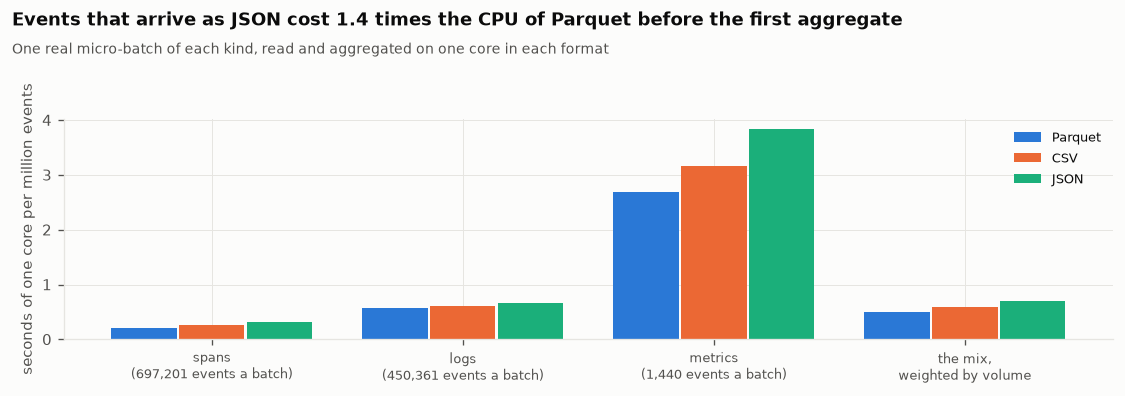

In [233]:
# ---- what parsing costs, drawn: one core's seconds per million events, by how the events arrive ----
if DECODE:
    fig, ax = plt.subplots(figsize=(9.5, 3.4))
    kinds_ = list(DECODE)
    x_ = np.arange(len(kinds_) + 1)
    for j, (w, colour) in enumerate((("Parquet", C1), ("CSV", C2), ("JSON", C3))):
        vals = [DECODE[k][w] for k in kinds_] + ([MIX[w]] if "MIX" in globals() else [np.nan])
        ax.bar(x_ + (j - 1) * 0.27, vals, width=0.26, color=colour, label=w)
    ax.set_xticks(x_, [f"{k}\n({DECODE[k]['events']:,} events a batch)" for k in kinds_] + ["the mix,\nweighted by volume"],
                  fontsize=7.5)
    ax.set_ylabel("seconds of one core per million events")
    ax.legend(fontsize=8)
    ratio_ = MIX["JSON"] / MIX["Parquet"] if "MIX" in globals() else float("nan")
    # Parquet's time includes the aggregation, so JSON above twice Parquet means parsing alone outweighs it
    finish(fig, "decode_cost", f"Events that arrive as JSON cost {ratio_:.1f} times the CPU of Parquet before the first "
           "aggregate", "One real micro-batch of each kind, read and aggregated on one core in each format"
           + ("; parsing the text costs more than the aggregation itself, so the wire format sizes the fleet"
              if ratio_ > 2 else ""))

[fig] artifacts\figures_full\netflix_replay.png


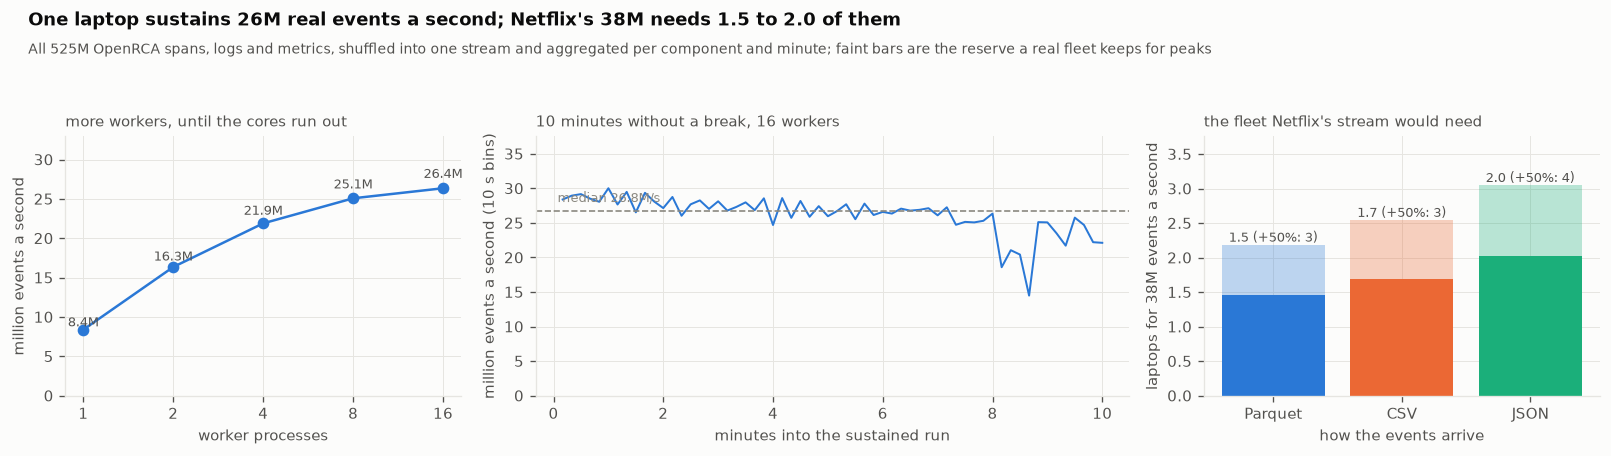

In [234]:
# ---- the replay, drawn ----
if LOAD and FLEET:
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1, 1.5, 1]})
    sw = LOAD["sweep"]
    ax = axes[0]
    ax.plot([r["processes"] for r in sw], [r["events_per_s"] / 1e6 for r in sw], "o-", color=C1)
    for r in sw:
        ax.text(r["processes"], r["events_per_s"] / 1e6 * 1.05, f"{r['events_per_s'] / 1e6:.1f}M", ha="center",
                fontsize=7.5, color=INK2)
    ax.set_xscale("log", base=2)
    ax.set_xticks([r["processes"] for r in sw], [str(r["processes"]) for r in sw])
    ax.set_ylim(0, max(r["events_per_s"] for r in sw) / 1e6 * 1.25)
    ax.set_xlabel("worker processes")
    ax.set_ylabel("million events a second")
    ax.set_title("more workers, until the cores run out", fontsize=9, color=INK2, loc="left")
    ax = axes[1]
    s = LOAD["sustained"]
    tl = np.array(s["timeline"]) / 1e6
    ax.plot(np.arange(1, len(tl) + 1) * 10 / 60, tl, color=C1, lw=1.2)
    ax.axhline(np.median(tl), color=MUTED, ls="--", lw=1)
    ax.text(0, np.median(tl) * 1.03, f" median {np.median(tl):.1f}M/s", color=MUTED, fontsize=7.5, va="bottom")
    ax.set_ylim(0, tl.max() * 1.25)
    ax.set_xlabel("minutes into the sustained run")
    ax.set_ylabel("million events a second (10 s bins)")
    ax.set_title(f"{s['seconds'] / 60:.0f} minutes without a break, {s['processes']} workers", fontsize=9, color=INK2,
                 loc="left")
    ax = axes[2]
    ways = list(FLEET)
    ax.bar(ways, [FLEET[w] for w in ways], color=[C1, C2, C3])
    ax.bar(ways, [FLEET[w] * 0.5 for w in ways], bottom=[FLEET[w] for w in ways], color=[C1, C2, C3], alpha=0.3)
    for i, w in enumerate(ways):
        ax.text(i, FLEET[w] * 1.5 + 0.05, f"{FLEET[w]:.1f} (+50%: {math.ceil(FLEET[w] * 1.5)})", ha="center",
                fontsize=7.5, color=INK2)
    ax.set_ylim(0, max(FLEET.values()) * 1.85)
    ax.set_xlabel("how the events arrive")
    ax.set_ylabel("laptops for 38M events a second")
    ax.set_title("the fleet Netflix's stream would need", fontsize=9, color=INK2, loc="left")
    finish(fig, "netflix_replay",
           f"One laptop sustains {s['events_per_s'] / 1e6:.0f}M real events a second; Netflix's 38M needs "
           f"{min(FLEET.values()):.1f} to {max(FLEET.values()):.1f} of them",
           f"All {LOAD['events_in_corpus'] / 1e6:.0f}M OpenRCA spans, logs and metrics, shuffled into one stream and "
           f"aggregated per component and minute; faint bars are the reserve a real fleet keeps for peaks")

In [235]:
# ---- the enrichers' own triples for millions of rows: the same URIs and predicates, a column at a time ----
XSD_DT = f"^^<{XSD.dateTime}>"


def slug_many(keys: pd.Series) -> pd.Series:
    """slug() for a whole column, with pandas doing the regular expression instead of one call per key."""
    s = keys.astype("str").str.strip().str.lower().str.replace(r"[^a-z0-9._~-]+", "-", regex=True).str.strip("-")
    empty = s == ""
    return s.where(~empty, keys[empty].map(slug)) if empty.any() else s


def mint_many(tenant: str, kind: str, keys: pd.Series) -> pd.Series:
    """mint() for a whole column."""
    return f"{BASE}id/{slug(tenant)}/{slug(kind)}/" + slug_many(keys)


def iso_z(ts: pd.Series) -> pd.Series:
    """'2024-10-24T10:54:00Z' for a whole column; dt_literal() writes the same thing one value at a time."""
    t = pd.to_datetime(ts, utc=True).dt.tz_localize(None).to_numpy("datetime64[s]")
    return pd.Series(np.datetime_as_string(t, unit="s"), index=ts.index, dtype="str") + "Z"


def compact(ts: pd.Series) -> pd.Series:
    """The '%Y%m%dT%H%M%S' form the enrichers put into keys."""
    return iso_z(ts).str[:19].str.replace("-", "", regex=False).str.replace(":", "", regex=False)


def sha8(texts) -> pd.Series:
    return pd.Series([hashlib.sha256(t.encode()).hexdigest()[:8] for t in texts], index=texts.index, dtype="str")


def iri(values: pd.Series) -> pd.Series:
    return "<" + values + ">"


def nt_string(text: pd.Series) -> pd.Series:
    """A plain string literal, escaped as N-Triples wants it."""
    for a, b in (("\\", "\\\\"), ('"', '\\"'), ("\n", "\\n"), ("\r", "\\r")):
        text = text.str.replace(a, b, regex=False)
    return '"' + text + '"'


def nt(s: pd.Series, p: URIRef, o) -> pd.Series:
    """One triple per row; a row whose subject or object is missing writes nothing."""
    return (s + f" <{p}> " + o + " .\n").fillna("")


def signal_nt(node: pd.Series, cls, at: pd.Series, detected: pd.Series, on: pd.Series | None = None) -> pd.Series:
    """What signal() writes, for a column of signals: type, both times, the hour bucket, the component."""
    s, t_at = iri(node), iso_z(at)
    out = (nt(s, RDF.type, f"<{cls}>" if isinstance(cls, str) else iri(cls))
           + nt(s, CORR.at, '"' + t_at + '"' + XSD_DT) + nt(s, CORR.detectedAt, '"' + iso_z(detected) + '"' + XSD_DT)
           + nt(s, CORR.inHour, f"<{BASE}id/hour/" + t_at.str[:13] + ">"))
    return out if on is None else out + nt(s, CORR.on, iri(on))


@functools.cache
def catalogued(host: str) -> bool:
    return resolve_host(host)["role_from"] == "catalogue"


def entities_nt(pairs) -> str:
    """Typing triples for the hosts, rules and people the signals point at, written once each."""
    names = nt_string(pd.Series([str(name or "") for _, _, name in pairs], dtype="str")).tolist()
    return "".join(f"<{node}> <{RDF.type}> <{cls}> .\n" + (f"<{node}> <{OPS.name}> {quoted} .\n" if name else "")
                   for (node, cls, name), quoted in sorted(set(zip(pairs, names)), key=str))


def changes_nt(rows: pd.DataFrame) -> tuple[pd.Series, str]:
    """ChangesAndLineage.analyse for any number of rows: per-row text, plus the hosts and code changes they name."""
    node = mint_many("wikimedia", "change", compact(rows.ts) + "-" + sha8(rows.message))
    host = rows.message.map(lambda m: next((h for h in hosts_in(m) if catalogued(h)), None))
    # pandas turns the None into NaN, and NaN is true in Python: test for a string, or every unnamed change gets 'host/nan'
    on = host.map(lambda h: str(mint("wikimedia", "host", h)) if isinstance(h, str) and h else None)
    text = (signal_nt(node, rows.kind.map(lambda k: str(KIND_CLASS[k])), rows.ts, rows.ts, on)
            + nt(iri(node), TL.message, nt_string(rows.message.map(lambda m: SCRUB(m)[:240]))))
    merged = merge_time[~merge_time.index.duplicated()]
    refs = pd.DataFrame({"node": node, "n": rows.refs}).explode("n").dropna()
    refs = refs[refs.n.isin(merged.index)]
    if len(refs):
        code = mint_many("wikimedia", "code-change", refs.n.astype(int).astype(str))
        links = nt(iri(refs.node), TL.includes, iri(code)).groupby(level=0).agg("".join)
        text = text + links.reindex(text.index, fill_value="")
        first = ~refs.n.duplicated()
        at = pd.to_datetime(refs.n[first].map(merged), utc=True)
        code_text = "".join(signal_nt(code[first], CODE.Change, at, at)
                            + nt(iri(code[first]), CODE.number, '"' + refs.n[first].astype(int).astype(str)
                                 + f'"^^<{XSD.integer}>'))
    else:
        code_text = ""
    hosts = [(str(mint("wikimedia", "host", h)), str(OPS.Host), h) for h in host.dropna().unique()]
    return text, code_text + entities_nt(hosts)


def episodes_nt(eps: pd.DataFrame) -> tuple[pd.Series, str]:
    """AlertsAndUsers.analyse for alert episodes."""
    key = [f"{r}-{t}-{slug(u)}-{h}" for r, t, u, h in zip(eps.route, compact(eps.start), eps.rule, eps.host)]
    node = mint_many("wikimedia", "firing", pd.Series(key, index=eps.index, dtype="str"))
    known = eps.host.map(lambda h: bool(h) and isinstance(h, str) and catalogued(h))
    on = eps.host.where(known).map(lambda h: str(mint("wikimedia", "host", h)), na_action="ignore")
    rule = mint_many("wikimedia", "alert-rule", eps.rule)
    s = iri(node)
    text = (signal_nt(node, ALERT.Firing, eps.start, eps.start, on) + nt(s, ALERT.ofRule, iri(rule))
            + nt(s, ALERT.resolvedAt, ('"' + iso_z(eps.end) + '"' + XSD_DT).where(eps.end.notna()))
            + nt(s, ALERT.source, nt_string(eps.route)))
    pairs = [(r, str(ALERT.Rule), None) for r in rule.unique()] + \
            [(str(mint("wikimedia", "host", h)), str(OPS.Host), h) for h in eps.host[known].unique()]
    return text, entities_nt(pairs)


def shifts_nt(sh: pd.DataFrame) -> pd.Series:
    """AlertsAndUsers.analyse for traffic shifts: known once the hour closes."""
    node = mint_many("wikimedia", "traffic-shift", sh.project + "-" + compact(sh.start).str[:11])
    s = iri(node)
    return (signal_nt(node, USERS.TrafficShift, sh.start, sh.start + pd.Timedelta(hours=1))
            + nt(s, USERS.project, nt_string(sh.project))
            + nt(s, USERS.ratio, '"' + sh.ratio.map(lambda x: str(round(x, 4))) + f'"^^<{XSD.decimal}>'))


def messages_nt(chat: pd.DataFrame) -> tuple[pd.Series, str]:
    """Chat lines as slack:Message nodes: when, who and where, and no text, so nothing to scrub but the author."""
    node = mint_many("wikimedia", "message", chat.channel + "-" + compact(chat.ts) + "-"
                     + sha8(chat.nick + "\t" + chat.text.fillna("")))
    who_of = {n: alias(n) for n in chat.nick.unique()}
    who = mint_many("wikimedia", "person", chat.nick.map(who_of))
    room = mint_many("wikimedia", "channel", chat.channel)
    s = iri(node)
    text = (nt(s, RDF.type, f"<{SLACK.Message}>") + nt(s, SLACK.postedAt, '"' + iso_z(chat.ts) + '"' + XSD_DT)
            + nt(s, SLACK.author, iri(who)) + nt(s, SLACK.inChannel, iri(room)))
    pairs = [(p, str(OPS.Person), None) for p in who.unique()] + [(c, str(SLACK.Channel), None) for c in room.unique()]
    return text, entities_nt(pairs)


def lab_nt(sig: pd.DataFrame) -> tuple[pd.Series, str]:
    """Section 25's signal minutes, each a typed signal on its component, known once its minute has closed."""
    parts, pairs = [], []
    for system, d in sig.groupby("system"):
        tenant = f"openrca-{system}"
        node = mint_many(tenant, "signal", d.task_id + "-" + d.kind + "-" + d.entity + "-" + d.kpi.fillna("")
                         + "-" + compact(d.minute))
        on = mint_many(tenant, "component", d.entity)
        text = signal_nt(node, d.kind.map(lambda k: str(SIGNAL_CLASS[k])), d.minute, d.minute + pd.Timedelta(minutes=1),
                         on) + nt(iri(node), METRIC.kpi, nt_string(d.kpi).where(d.kind == "METRIC_ANOMALY"))
        parts.append(text)
        machine = d.entity.str.fullmatch(r"node-\d+|os_\d+")
        pairs += [(c, str(OPS.Host if m else OPS.Pod), e)
                  for c, m, e in set(zip(on, machine, d.entity))]
    return (pd.concat(parts) if parts else pd.Series([], dtype="str")), entities_nt(pairs)


print("  writers: changes_nt, episodes_nt, shifts_nt, messages_nt, lab_nt; each returns per-row N-Triples plus the")
print("  entities those rows point at, written once")

  writers: changes_nt, episodes_nt, shifts_nt, messages_nt, lab_nt; each returns per-row N-Triples plus the
  entities those rows point at, written once


In [236]:
# ---- a test before trusting the fast writers: on real rows they must write exactly what the enrichers write ----
def triples_of(text: str) -> set:
    return set(rdflib.Graph().parse(data=text, format="nt")) if text.strip() else set()


keys = pd.concat([CHANGES.message.sample(min(5000, len(CHANGES)), random_state=SEED), EPISODES.rule,
                  IRC.nick.drop_duplicates()]).astype("str").reset_index(drop=True)
same_uris = (mint_many("wikimedia", "x", keys) == keys.map(lambda k: str(mint("wikimedia", "x", k)))).mean()
print(f"  [test] mint_many and mint agree on {same_uris:.2%} of {len(keys):,} real keys -> "
      f"{'PASS' if same_uris == 1 else 'FAIL'}")
rows = CHANGES[CHANGES.refs.map(len) > 0].sample(min(150, int((CHANGES.refs.map(len) > 0).sum())), random_state=SEED)
rows = pd.concat([rows, CHANGES.sample(min(150, len(CHANGES)), random_state=SEED + 1)])
rows = rows[~rows.index.duplicated()]
eps = EPISODES.sample(min(300, len(EPISODES)), random_state=SEED)
sh = SHIFTS.head(100)
reference = set(ChangesAndLineage().analyse(rows, None, None)) | set(AlertsAndUsers().analyse((eps, sh), None, None))
text_c, extra_c = changes_nt(rows)
text_e, extra_e = episodes_nt(eps)
fast = triples_of("".join(text_c) + extra_c + "".join(text_e) + extra_e + "".join(shifts_nt(sh)))
print(f"  [test] {len(rows)} changes, {len(eps)} alert episodes and {len(sh)} traffic shifts: the enrichers write "
      f"{len(reference):,} triples, the fast writers {len(fast):,}; identical -> {'PASS' if fast == reference else 'FAIL'}")
for t in list(reference - fast)[:3] + list(fast - reference)[:3]:
    print(f"    only in {'the enrichers' if t in reference else 'the fast writers'}: {t[0].n3()[-60:]} {t[1].n3()[-30:]} "
          f"{t[2].n3()[:60]}")
assert same_uris == 1 and fast == reference

  [test] mint_many and mint agree on 100.00% of 386,257 real keys -> PASS


  [test] 300 changes, 300 alert episodes and 100 traffic shifts: the enrichers write 5,601 triples, the fast writers 5,601; identical -> PASS


In [237]:
# ---- everything we know, in one store, loaded in stages and asked the same questions at every size ----
BIG_DIR = GRAPH_DIR / f"large_{RUN_TAG}"
GRAPH_QUERIES = {
    "everything on one host, six hours": ("bucket", """SELECT ?s ?t WHERE {{ VALUES ?h {{ {hours6} }}
        ?s corr:inHour ?h ; corr:on <{host}> ; corr:at ?t }}"""),
    "alerts in one hour, by host": ("bucket", """SELECT ?host (COUNT(?s) AS ?n) WHERE {{ ?s corr:inHour <{hour}> ;
        a alert:Firing ; corr:on ?host }} GROUP BY ?host"""),
    "changes in the hour before an alert": ("bucket", """SELECT ?c ?t WHERE {{ VALUES ?h {{ {hours2} }}
        ?c corr:inHour ?h ; a/rdfs:subClassOf* tl:Change ; corr:at ?t .
        FILTER(?t <= "{at}"^^xsd:dateTime && ?t > "{at}"^^xsd:dateTime - "PT1H"^^xsd:dayTimeDuration) }}"""),
    "chat in one hour, no bucket (a range filter)": ("scan", """SELECT (COUNT(?m) AS ?n) WHERE {{
        ?m slack:postedAt ?t . FILTER(?t >= "{a}"^^xsd:dateTime && ?t < "{b}"^^xsd:dateTime) }}"""),
}


def time_queries(store: ox.Store, anchors: pd.DataFrame, n: int = 20) -> dict:
    """Each question asked about real alert episodes already in the store: median and 95th percentile, rows returned.
    An untimed pass over other episodes comes first, so that every stage is timed with the store equally warm."""
    out = {}
    for seed, timed in ((SEED + 1, False), (SEED, True)):
        rng = np.random.default_rng(seed)
        for name, (kind, q) in GRAPH_QUERIES.items():
            lat, rows = [], []
            for i in rng.choice(len(anchors), n if kind == "bucket" else max(n // 4, 3)):
                e = anchors.iloc[i]
                h0 = e.start.floor("h")
                hours = lambda k: " ".join(f"<{hour_node(h0 - pd.Timedelta(hours=j))}>" for j in range(k))
                text = PREFIXES + q.format(hours6=hours(6), hours2=hours(2), host=mint("wikimedia", "host", e.host),
                                           hour=hour_node(h0), at=f"{e.start:%Y-%m-%dT%H:%M:%SZ}",
                                           a=f"{h0:%Y-%m-%dT%H:%M:%SZ}", b=f"{h0 + pd.Timedelta(hours=1):%Y-%m-%dT%H:%M:%SZ}")
                t0 = time.perf_counter()
                rows.append(len(list(store.query(text))))
                lat.append((time.perf_counter() - t0) * 1000)
            if timed:
                out[name] = {"p50_ms": float(np.median(lat)), "p95_ms": float(np.percentile(lat, 95)),
                             "rows": float(np.mean(rows))}
    return out


big_file = RES_DIR / "graph_scale.json"
if big_file.exists() and not RECOMPUTE:
    GRAPH_SCALE = json.loads(big_file.read_text())
    print(f"  [cache] {big_file.name}")
else:
    t0 = time.perf_counter()
    sources, extra = {}, []
    for name, (fn, frame, ts) in {
            "changes": (changes_nt, CHANGES, "ts"), "alert episodes": (episodes_nt, EPISODES, "start"),
            "chat lines": (messages_nt, IRC, "ts"), "lab signals": (lab_nt, LAB_SIGNALS, "minute")}.items():
        text, ents = fn(frame)
        sources[name] = pd.DataFrame({"ts": pd.to_datetime(frame.loc[text.index, ts], utc=True), "nt": text})
        extra.append(ents)
    shift_text = shifts_nt(SHIFTS)
    sources["traffic shifts"] = pd.DataFrame({"ts": SHIFTS.start, "nt": shift_text})
    base = KG.store.query("CONSTRUCT { ?s ?p ?o } WHERE { GRAPH ?g { ?s ?p ?o } }").serialize(
        format=ox.RdfFormat.N_TRIPLES).decode("utf-8") + TBOX.serialize(format="nt") + "".join(extra)
    t_write = time.perf_counter() - t0
    ALL = pd.concat([d.assign(source=k) for k, d in sources.items()], ignore_index=True).sort_values("ts", kind="stable")
    ALL["n"] = ALL.nt.str.count("\n")
    cum = base.count("\n") + ALL.n.cumsum().to_numpy()
    # stages roughly evenly spaced on a log scale, none so close to the full store that the two cannot be told apart
    targets = [t for t in (2e6, 4e6, 6e6, 8e6, 12e6, 16e6) if base.count("\n") < t < cum[-1] * 0.85] + [int(cum[-1])]
    stage = np.searchsorted(np.array(targets), cum, side="left")
    shutil.rmtree(BIG_DIR, ignore_errors=True)
    BIG_DIR.mkdir(parents=True)
    big = ox.Store(str(BIG_DIR / "store"))
    s0 = time.perf_counter()
    big.bulk_load(base.encode("utf-8"), format=ox.RdfFormat.N_TRIPLES)
    t_load, written = time.perf_counter() - s0, base.count("\n")
    anchors_all = EPISODES[EPISODES.host.map(lambda h: bool(h) and isinstance(h, str) and catalogued(h))]
    GRAPH_SCALE = {"write_s": round(t_write, 1), "base_triples": written,
                   "by_source": {k: int(d.nt.str.count("\n").sum()) for k, d in sources.items()}, "steps": []}
    t_opt, fixed = 0.0, None
    for k, target in enumerate(targets):
        part = ALL[stage == k]
        if part.empty:
            continue
        path = BIG_DIR / f"stage_{k}.nt"
        path.write_text("".join(part.nt.tolist()), encoding="utf-8")
        s0 = time.perf_counter()
        big.bulk_load(path=str(path), format=ox.RdfFormat.N_TRIPLES)
        big.flush()
        t_load += time.perf_counter() - s0
        written += int(part.n.sum())
        path.unlink()
        s0 = time.perf_counter()
        big.optimize()                     # compacted after every load, as Oxigraph advises after a batch upload,
        t_opt += time.perf_counter() - s0  # so that every stage is timed on a store in the same state
        upto = part.ts.max()
        if fixed is None:
            # the same questions at every size: episodes whose hours are complete before anything later is loaded,
            # so a later stage adds history elsewhere and never into the hours being asked about
            early = anchors_all[anchors_all.start < upto.floor("h") - pd.Timedelta(hours=1)]
            fixed = early if len(early) else None
        if fixed is not None:
            GRAPH_SCALE["steps"].append({"triples_written": written, "load_s": round(t_load, 1),
                                         "optimize_s": round(t_opt, 1), "upto": str(upto),
                                         "queries": time_queries(big, fixed)})
        print(f"  {written:>12,} triples written, history up to {upto:%Y-%m-%d}, loaded in {t_load:.0f}s and compacted "
              f"in {t_opt:.0f}s so far", flush=True)
    GRAPH_SCALE["fixed_anchors"] = ({"episodes": len(fixed), "before": str(fixed.start.max())} if fixed is not None
                                    else {"episodes": 0, "before": ""})
    # what an investigator meets in practice: the same questions about the last 30 days, the busiest stretch, at full size
    recent_anchors = anchors_all[anchors_all.start >= NOW - pd.Timedelta(days=30)]
    GRAPH_SCALE["recent"] = time_queries(big, recent_anchors) if len(recent_anchors) else {}
    t0 = time.perf_counter()
    GRAPH_SCALE["stored"] = len(big)
    GRAPH_SCALE["disk_gb"] = round(sum(p.stat().st_size for p in BIG_DIR.rglob("*") if p.is_file()) / 1e9, 2)
    violations, rule_s = Counter(), {}
    for pn, rule, msg, q in COMPILED:
        s0 = time.perf_counter()
        violations[f"{pn} {rule}"] += len(list(big.query("PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> " + q)))
        rule_s[f"{pn} {rule}"] = round(time.perf_counter() - s0, 2)
    GRAPH_SCALE["shacl"] = {"seconds": round(time.perf_counter() - t0, 1), "violations": dict(violations),
                            "rule_seconds": rule_s}
    GRAPH_SCALE["power"] = power_state()
    big_file.write_text(json.dumps(GRAPH_SCALE, indent=1))
    del big, ALL
G = GRAPH_SCALE
last = G["steps"][-1]
print(f"\n  written by the fast writers in {G['write_s']:.0f}s: " +
      ", ".join(f"{k} {v / 1e6:.1f}M" for k, v in G["by_source"].items()) + f", plus {G['base_triples'] / 1e6:.1f}M "
      f"from the working graph, the ontology and the entities")
print(f"  {G['stored']:,} distinct triples in one store, {G['disk_gb']} GB on disk, bulk-loaded at "
      f"{last['triples_written'] / last['load_s']:,.0f} triples a second, plus {last.get('optimize_s', 0):.0f}s of "
      f"compaction across the stages")
print(f"  every shape checked over all of it in {G['shacl']['seconds']:.0f}s: "
      f"{sum(G['shacl']['violations'].values()):,} violations; everything here timed {power_note(G.get('power'))}")
print(f"\n  each question asks about the same alert episodes at every size, drawn once from the "
      f"{G['fixed_anchors']['episodes']:,} that end before {G['fixed_anchors']['before'][:10]}; the last column asks "
      f"about the last 30 days instead, the busiest stretch, at full size")
print(f"  {'median ms, by triples in the store':<46}" + "".join(f"{s['triples_written'] / 1e6:>8.1f}M" for s in G["steps"])
      + f"{'recent':>10}")
for name in GRAPH_QUERIES:
    print(f"  {name:<46}" + "".join(f"{s['queries'][name]['p50_ms']:>9.1f}" for s in G["steps"])
          + f"{G['recent'].get(name, {}).get('p50_ms', float('nan')):>10.1f}")

  [cache] graph_scale.json

  written by the fast writers in 49s: changes 1.5M, alert episodes 2.8M, chat lines 6.9M, lab signals 5.2M, traffic shifts 0.1M, plus 0.7M from the working graph, the ontology and the entities
  16,393,203 distinct triples in one store, 1.7 GB on disk, bulk-loaded at 775,668 triples a second, plus 21s of compaction across the stages
  every shape checked over all of it in 161s: 0 violations; everything here timed on mains power

  each question asks about the same alert episodes at every size, drawn once from the 1,765 that end before 2022-03-19; the last column asks about the last 30 days instead, the busiest stretch, at full size
  median ms, by triples in the store                 4.0M     6.0M     8.0M    12.0M    17.2M    recent
  everything on one host, six hours                   0.8      1.4      1.0      1.0      1.0       4.8
  alerts in one hour, by host                         0.2      0.2      0.2      0.2      0.2       1.1
  changes in the hou

In [238]:
# ---- the write path a live system uses: micro-batches of signals, each checked by the shapes, then committed ----
TBOX_NT = TBOX.serialize(format="nt")


def violations_in(delta: str) -> int:
    """check_fast for N-Triples text: the compiled shapes, run on one delta together with the ontology."""
    st = ox.Store()
    st.load((delta + TBOX_NT).encode("utf-8"), format=ox.RdfFormat.N_TRIPLES)
    return sum(len(list(st.query("PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> " + q))) for *_, q in COMPILED)


STREAM_BATCH = 5000                                  # signals per micro-batch, a few seconds of a busy stream
stream_file = RES_DIR / "write_path.json"
if stream_file.exists() and not RECOMPUTE:
    STREAM = json.loads(stream_file.read_text())
    print(f"  [cache] {stream_file.name}")
elif not len(LAB_SIGNALS):
    STREAM = None
    print("  [skip] no lab signals in this profile")
else:
    shutil.rmtree(BIG_DIR / "online", ignore_errors=True)
    live = ox.Store(str(BIG_DIR / "online"))          # its own store, so the measurement starts from empty
    ordered = LAB_SIGNALS.sort_values("minute", kind="stable").reset_index(drop=True)
    rows_, kept = [], 0
    t_all = time.perf_counter()
    for k, at in enumerate(range(0, len(ordered), STREAM_BATCH)):
        text, ents = lab_nt(ordered.iloc[at:at + STREAM_BATCH])
        delta = "".join(text.tolist()) + ents        # each delta types what it points at, so it checks on its own
        t0 = time.perf_counter()
        bad = violations_in(delta)
        t1 = time.perf_counter()
        if not bad:                                  # a delta that breaks a shape is refused whole
            live.load(delta.encode("utf-8"), format=ox.RdfFormat.N_TRIPLES,
                      to_graph=ox.NamedNode(f"{BASE}graph/stream/batch-{k}"))
        t2 = time.perf_counter()
        n = delta.count("\n")
        kept += 0 if bad else n
        rows_.append({"store_after": kept, "check_ms": (t1 - t0) * 1000, "commit_ms": (t2 - t1) * 1000,
                      "triples": n, "refused": bool(bad)})
    wall = time.perf_counter() - t_all
    W = pd.DataFrame(rows_)
    STREAM = {"signals": len(ordered), "batches": len(W), "triples": int(W.triples.sum()), "seconds": round(wall, 1),
              "refused": int(W.refused.sum()), "signals_per_s": len(ordered) / wall,
              "triples_per_s": float(W.triples.sum() / wall), "check_p50_ms": float(W.check_ms.median()),
              "commit_p50_ms": float(W.commit_ms.median()),
              "batch_p99_ms": float((W.check_ms + W.commit_ms).quantile(0.99)),
              "timeline": W[["store_after", "check_ms", "commit_ms"]].round(1).values.tolist(), "power": power_state()}
    stream_file.write_text(json.dumps(STREAM, indent=1))
    del live
if STREAM:
    print(f"  {STREAM['signals']:,} lab signals in {STREAM['batches']} micro-batches of {STREAM_BATCH:,}: "
          f"{STREAM['triples']:,} triples checked and committed in {STREAM['seconds']:.0f}s, "
          f"{STREAM['refused']} batches refused by the shapes")
    print(f"  end to end: {STREAM['signals_per_s']:,.0f} signals ({STREAM['triples_per_s']:,.0f} triples) a second; "
          f"per batch, the shapes take {STREAM['check_p50_ms']:.0f} ms and the commit {STREAM['commit_p50_ms']:.0f} ms at "
          f"the median, {STREAM['batch_p99_ms']:.0f} ms together at the 99th percentile; timed "
          f"{power_note(STREAM.get('power'))}")

  [cache] write_path.json
  863,062 lab signals in 173 micro-batches of 5,000: 5,223,495 triples checked and committed in 131s, 0 batches refused by the shapes
  end to end: 6,588 signals (39,871 triples) a second; per batch, the shapes take 149 ms and the commit 534 ms at the median, 870 ms together at the 99th percentile; timed on mains power


[fig] artifacts\figures_full\graph_scale.png


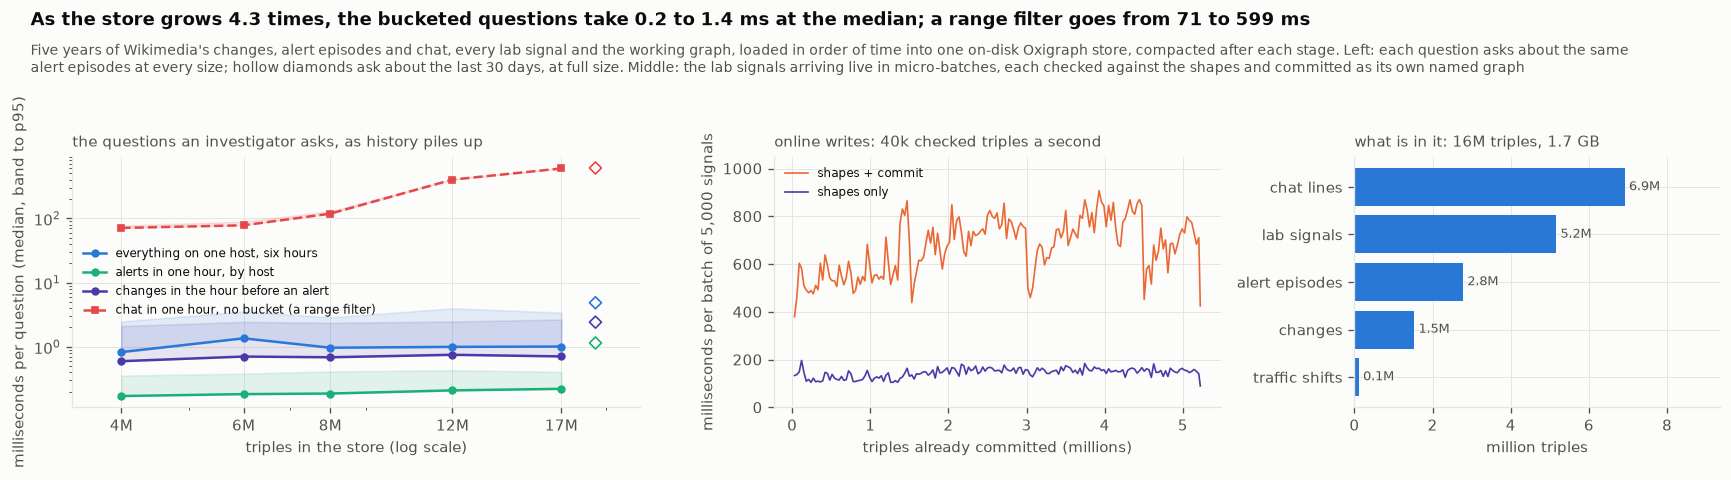

In [239]:
# ---- the graph at scale, drawn ----
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0), gridspec_kw={"width_ratios": [1.4, 1.1, 0.9]})
xs = np.array([s["triples_written"] for s in G["steps"]]) / 1e6
for (name, (kind, _)), colour in zip(GRAPH_QUERIES.items(), (C1, C3, C7, C8)):
    p50 = [s["queries"][name]["p50_ms"] for s in G["steps"]]
    p95 = [s["queries"][name]["p95_ms"] for s in G["steps"]]
    axes[0].plot(xs, p50, "o-" if kind == "bucket" else "s--", color=colour, label=name, ms=4)
    axes[0].fill_between(xs, p50, p95, color=colour, alpha=0.12)
    if name in G.get("recent", {}):
        axes[0].scatter([xs[-1] * 1.12], [G["recent"][name]["p50_ms"]], marker="D", s=26, facecolors="none",
                        edgecolors=colour, zorder=3)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(xs[0] * 0.85, xs[-1] * 1.3)
axes[0].set_xticks(xs, [f"{x:.0f}M" if x >= 1 else f"{x:.1f}M" for x in xs])
axes[0].xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
axes[0].set_xlabel("triples in the store (log scale)")
axes[0].set_ylabel("milliseconds per question (median, band to p95)")
axes[0].legend(fontsize=7, loc="center left")             # between the range filter above and the buckets below
axes[0].set_title("the questions an investigator asks, as history piles up", fontsize=9, color=INK2, loc="left")
if STREAM:
    tl_ = np.array(STREAM["timeline"])
    axes[1].plot(tl_[:, 0] / 1e6, tl_[:, 1] + tl_[:, 2], color=C2, lw=1, label="shapes + commit")
    axes[1].plot(tl_[:, 0] / 1e6, tl_[:, 1], color=C7, lw=1, label="shapes only")
    axes[1].set_ylim(0, np.percentile(tl_[:, 1] + tl_[:, 2], 99.5) * 1.2)
    axes[1].set_xlabel("triples already committed (millions)")
    axes[1].set_ylabel(f"milliseconds per batch of {STREAM_BATCH:,} signals")
    axes[1].legend(fontsize=7)
    axes[1].set_title(f"online writes: {STREAM['triples_per_s'] / 1e3:,.0f}k checked triples a second", fontsize=9,
                      color=INK2, loc="left")
src = pd.Series(G["by_source"]).sort_values()
axes[2].barh(src.index, src.values / 1e6, color=C1)
for i, v in enumerate(src.values):
    axes[2].text(v / 1e6, i, f" {v / 1e6:.1f}M", va="center", fontsize=7.5, color=INK2)
axes[2].set_xlim(0, src.max() / 1e6 * 1.35)
axes[2].set_xlabel("million triples")
axes[2].set_title(f"what is in it: {G['stored'] / 1e6:.0f}M triples, {G['disk_gb']} GB", fontsize=9, color=INK2, loc="left")
BUCKET_P50 = [s["queries"][n]["p50_ms"] for s in G["steps"] for n, (kind, _) in GRAPH_QUERIES.items() if kind == "bucket"]
RECENT_P50 = [G["recent"][n]["p50_ms"] for n, (kind, _) in GRAPH_QUERIES.items()
              if kind == "bucket" and n in G.get("recent", {})] or BUCKET_P50
q_s = [s["queries"]["chat in one hour, no bucket (a range filter)"]["p50_ms"] for s in G["steps"]]
fmt_ms = lambda v: f"{v:.1f}" if v < 10 else f"{v:.0f}"
finish(fig, "graph_scale",
       f"As the store grows {xs[-1] / xs[0]:.1f} times, the bucketed questions take {fmt_ms(min(BUCKET_P50))} to "
       f"{fmt_ms(max(BUCKET_P50))} ms at the median; a range filter goes from {fmt_ms(q_s[0])} to {fmt_ms(q_s[-1])} ms",
       "Five years of Wikimedia's changes, alert episodes and chat, every lab signal and the working graph, loaded in "
       "order of time into one on-disk Oxigraph store, compacted after each stage. Left: each question asks about the "
       "same alert episodes at every size; hollow diamonds ask about the last 30 days, at full size. Middle: the lab "
       "signals arriving live in micro-batches, each checked against the shapes and committed as its own named graph")

                                        number                        what it rests on
  events in, per second                 38M (Netflix)                 26.1M per laptop, sustained 10 min
  machines to read the stream           1.5 to 2.0 laptops            Parquet in, then JSON lines in
  raw events per signal                 82,681                        section 10's funnel; benchmarks fail far more often than production, so real streams condense further
  signals into the graph, per second    460                           about 6.0 triples each
  triples into the graph, per second    2,753                         one store bulk-loads 775,668: 281.8 times that
  the same, checked and committed live  39,871                        14.5 times what Netflix's stream needs, every delta checked by the shapes
  history in one store                  16M triples, 1.7 GB           1.7 hours of Netflix-rate signals at benchmark density
  an investigator's question            1.1 to 4.8 ms at

[fig] artifacts\figures_full\netflix_scale_summary.png


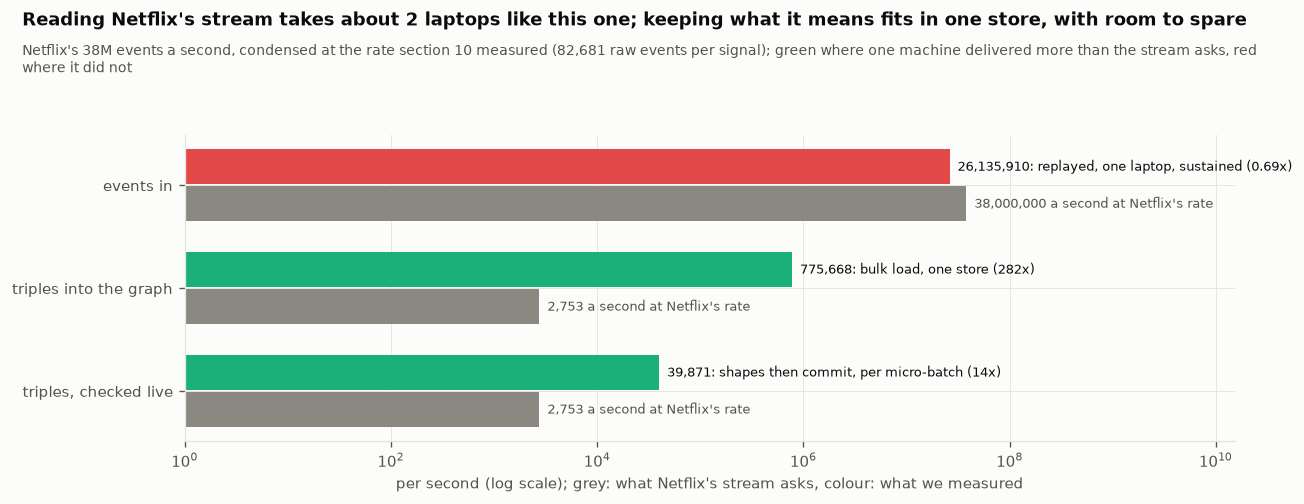

In [240]:
# ---- the arithmetic: Netflix's stream, condensed, against what one store just did ----
if LOAD and FUNNEL:
    raw = sum(FUNNEL[t]["raw rows"] for t in ("spans", "logs") if t in FUNNEL)
    eps_ = sum(FUNNEL[t]["slow episodes"] for t in ("spans", "logs") if t in FUNNEL)
    per_signal = raw / max(eps_, 1)
    lab_triples = G["by_source"].get("lab signals", 0) / max(len(LAB_SIGNALS), 1)
    signals_s = NETFLIX_EVENTS_PER_S / per_signal
    need = signals_s * lab_triples
    load_rate = last["triples_written"] / last["load_s"]
    SCALE_TABLE = [
        ("events in, per second", f"{NETFLIX_EVENTS_PER_S / 1e6:.0f}M (Netflix)",
         f"{LOAD['sustained']['events_per_s'] / 1e6:.1f}M per laptop, sustained {LOAD['sustained']['seconds'] / 60:.0f} min"),
        ("machines to read the stream", f"{min(FLEET.values()):.1f} to {max(FLEET.values()):.1f} laptops",
         "Parquet in, then JSON lines in"),
        ("raw events per signal", f"{per_signal:,.0f}", "section 10's funnel; benchmarks fail far more often than "
                                                         "production, so real streams condense further"),
        ("signals into the graph, per second", f"{signals_s:,.0f}", f"about {lab_triples:.1f} triples each"),
        ("triples into the graph, per second", f"{need:,.0f}",
         f"one store bulk-loads {load_rate:,.0f}: {load_rate / need:,.1f} times that"),
        ("the same, checked and committed live", f"{STREAM['triples_per_s']:,.0f}" if STREAM else "not measured",
         f"{STREAM['triples_per_s'] / need:,.1f} times what Netflix's stream needs, every delta checked by the shapes"
         if STREAM else "needs the lab signals"),
        ("history in one store", f"{G['stored'] / 1e6:.0f}M triples, {G['disk_gb']} GB",
         f"{G['stored'] / need / 3600:.1f} hours of Netflix-rate signals at benchmark density"),
        ("an investigator's question", f"{fmt_ms(min(RECENT_P50))} to {fmt_ms(max(RECENT_P50))} ms at the median",
         f"{len(RECENT_P50)} bucketed questions about the last 30 days, in the full store"),
    ]
    print(f"  {'':<38}{'number':<30}what it rests on")
    for a, b, c in SCALE_TABLE:
        print(f"  {a:<38}{b:<30}{c}")

    # ---- the same arithmetic, drawn: what Netflix's stream asks of each part, and what one machine delivered ----
    rows_ = [("events in", NETFLIX_EVENTS_PER_S, LOAD["sustained"]["events_per_s"], "replayed, one laptop, sustained"),
             ("triples into the graph", need, load_rate, "bulk load, one store")]
    if STREAM:
        rows_.append(("triples, checked live", need, STREAM["triples_per_s"], "shapes then commit, per micro-batch"))
    fig, ax = plt.subplots(figsize=(11, 0.9 * len(rows_) + 1.6))
    for i, (what, asked, got, how) in enumerate(rows_):
        ax.barh(i + 0.18, asked, height=0.34, color=MUTED)
        ax.barh(i - 0.18, got, height=0.34, color=C3 if got >= asked else C8)
        ax.text(asked, i + 0.18, f"  {asked:,.0f} a second at Netflix's rate", va="center", fontsize=7.8, color=INK2)
        ratio = got / asked
        ax.text(got, i - 0.18, f"  {got:,.0f}: {how} ({ratio:,.0f}x)" if ratio >= 10 else f"  {got:,.0f}: {how} "
                f"({ratio:.2g}x)", va="center", fontsize=7.8, color=INK)
    ax.set_xscale("log")
    ax.set_yticks(range(len(rows_)), [r[0] for r in rows_])
    ax.invert_yaxis()
    ax.set_xlim(1, max(max(r[1], r[2]) for r in rows_) * 400)
    ax.set_xlabel("per second (log scale); grey: what Netflix's stream asks, colour: what we measured")
    fits = all(got >= asked for what, asked, got, _ in rows_ if what != "events in")
    finish(fig, "netflix_scale_summary",
           f"Reading Netflix's stream takes about {math.ceil(min(FLEET.values()))} laptops like this one; keeping what "
           f"it means " + ("fits in one store, with room to spare" if fits else "needs more than one store"),
           f"Netflix's 38M events a second, condensed at the rate section 10 measured ({per_signal:,.0f} raw events per "
           f"signal); green where one machine delivered more than the stream asks, red where it did not")

**One laptop replays real telemetry at 26.1 million events a second for ten minutes without a
break, so reading Netflix's 38 million takes two laptops like it; and one store holds five years
of what we know, over 16 million facts, and answers the same questions in about a millisecond
whatever its size.** The replay ran over 524 million real OpenRCA events as one shuffled stream
of 808 micro-batches through the per-minute aggregation the detectors start from. One worker
managed 8.4 million events a second and sixteen 26.4 million; over ten minutes sixteen held 26.1
million, more than 15 billion events in all, although the last minute ran at 23.3 million against
28.9 in the first. How the events arrive matters too: one core spends 0.71 seconds per million
events decoding JSON against 0.51 for Parquet, which moves the fleet from 1.5 laptops to 2.0. The
graph scales differently, because it only ever sees signals. Condensed at the rate section 10
measured, Netflix's stream becomes about 460 signals and 2,753 facts a second. One store
bulk-loads 775,668 facts a second, and the path a live system uses, each micro-batch checked
against every shape and then committed as its own named graph, sustains 39,871, which is 14.5
times what the stream needs. The questions had to be measured with care, and section 44 records
the two ways we first got that wrong. Asked about the same alert episodes at every size, the
bucketed questions take 0.2 to 1.4 ms from 4 to 17 million facts, while a range filter over every
chat line grows from 71.0 to 598.7 ms with the history it scans; asked about the busiest stretch,
the last 30 days, the same bucketed questions take 1.1 to 4.8 ms. Every shape was checked over
the whole store in 161 seconds, with no violation. None of this is Netflix's scale. It is what one
laptop does with real data shaped like Netflix's, and the arithmetic for a fleet rests on it.

## 41 · Ask the graph

**Theory.** The graph's last user is a person with a question. A model that knows the ontology
can turn a plain question into SPARQL, and the types catch one kind of mistake loudly: a query
that names a class or property the ontology does not have returns nothing. They cannot catch the
other kind, a query that is valid and asks for less than the question meant. We give Qwen Flash
the ontology's own file and the four competency questions as examples, check that what it writes
parses, run it, print what came back, and then check each answer against what the question
meant. World: Wikimedia.

In [241]:
# ---- a question in, SPARQL out, checked before it runs ----
ASK_SYSTEM = ("You write one SPARQL SELECT query for a knowledge graph with this ontology (Turtle):\n" + TBOX_TTL +
              "\nExamples:\n" + "\n\n".join(CQ.values()) +
              "\nUse only classes and properties from the ontology. Answer with the query alone, no prefixes, no prose.")


def ask_graph(question: str, limit: int = 10) -> tuple[str, list]:
    r = LLM.chat(QWEN["flash"], [{"role": "system", "content": ASK_SYSTEM}, {"role": "user", "content": question}],
                 agent="ask", json_mode=False, max_tokens=500)
    q = re.sub(r"^```(?:sparql)?\s*|\s*```$", "", (r.text or "").strip(), flags=re.S)
    try:
        res = KG.store.query(STORE_PREFIXES + q + ("" if "LIMIT" in q.upper() else f" LIMIT {limit}"),
                             use_default_graph_as_union=True)
    except (SyntaxError, ValueError, OSError) as e:
        return q, [f"refused: {type(e).__name__}: {str(e)[:120]}"]
    if not isinstance(res, ox.QuerySolutions):
        return q, ["refused: not a SELECT query"]
    names = [v.value for v in res.variables]
    return q, [{k: None if t is None else t.value.replace(BASE, "") for k, t in zip(names, row)} for row in res]


QUESTIONS = ["Which teams own the hosts that had alerts in the last 30 days?",
             "Which changes include a merged code change, and when did each merge happen?",
             "How many incidents affected each application?"]
ASKED = []
with phase("live latency"):
    for question in QUESTIONS:
        q, rows = ask_graph(question)
        ASKED.append((question, q, rows))
        print(f"  Q: {question}")
        print(textwrap.indent(q[:500], "     "))
        for row in rows[:5]:
            print(f"     -> {row}"[:150])
        if not (rows and isinstance(rows[0], str)):
            print(f"     rows returned: {len(rows)}" + (" (the limit we set)" if len(rows) == 10 else ""))
        print()
# the types refuse a query that names what the ontology does not have; they cannot refuse one that asks for too little
for question, q, rows in ASKED:
    if "NOW()" in q:
        print(f"  [check] '{question[:44]}' uses NOW(), the clock of the machine that runs it "
              f"({datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d}), not the moment the record was read "
              f"({NOW:%Y-%m-%d %H:%M}), so its answer moves with the day it runs")
    if "tl:includes" in q and re.search(r"\ba tl:Change\b", q) and "subClassOf" not in q:
        plain = int(KG.ask("SELECT (COUNT(DISTINCT ?c) AS ?n) WHERE { ?c a tl:Change ; tl:includes ?x }")[0]["n"].value)
        every = int(KG.ask("SELECT (COUNT(DISTINCT ?c) AS ?n) WHERE { ?c a/rdfs:subClassOf* tl:Change ; "
                           "tl:includes ?x }")[0]["n"].value)
        print(f"  [check] '{question[:44]}' asks for 'a tl:Change': {plain:,} of the {every:,} changes that include a "
              f"merged code change are typed that way; the rest are typed by a subclass such as tl:Deployment, which "
              f"only 'a/rdfs:subClassOf* tl:Change' reaches, since nothing here infers parent classes")

  Q: Which teams own the hosts that had alerts in the last 30 days?
     SELECT DISTINCT ?team WHERE {
       ?firing a alert:Firing ; corr:at ?t .
       FILTER(?t > NOW() - "P30D"^^xsd:dayTimeDuration)
       ?host ops:memberOf ?cluster .
       ?firing corr:on ?host .
       ?host ops:ownedBy ?team .
     }
     -> {'team': 'id/wikimedia/team/serviceops'}
     -> {'team': 'id/wikimedia/team/data-platform'}
     -> {'team': 'id/wikimedia/team/machine-learning'}
     -> {'team': 'id/wikimedia/team/traffic'}
     -> {'team': 'id/wikimedia/team/observability'}
     rows returned: 8

  Q: Which changes include a merged code change, and when did each merge happen?
     SELECT DISTINCT ?change ?codeChange WHERE {
       ?change a tl:Change ; tl:includes ?codeChange .
       ?codeChange a code:Change ; corr:at ?mergeTime .
     }
     -> {'change': 'id/wikimedia/change/20260630t225300-da54ce7d', 'codeChange': 'id/wikimedia/code-change/1305158'}
     -> {'change': 'id/wikimedia/change/202610

  [check] 'Which changes include a merged code change, ' asks for 'a tl:Change': 13 of the 2,056 changes that include a merged code change are typed that way; the rest are typed by a subclass such as tl:Deployment, which only 'a/rdfs:subClassOf* tl:Change' reaches, since nothing here infers parent classes


In [242]:
# ---- the incident explorer: pick an incident, see its neighbourhood in the graph ----
def neighbourhood(iid: str) -> dict:
    t0 = inc_w.loc[inc_w.id == iid, "start"].iloc[0]
    wt = WikiTools(t0)
    return {"alerts": wt.alerts_around(60)[:6], "changes": wt.changes_before(2)[:6], "merges": wt.merges_before(12)[:4],
            "label": LABELS.get(iid) if "LABELS" in globals() else None}


if FLAGSHIP is not None:                   # printed as well, so a saved or exported notebook shows it without widgets
    print(json.dumps(neighbourhood(FLAGSHIP["id"]), indent=1, default=str)[:2500])
if IN_NOTEBOOK:
    import ipywidgets as widgets
    pick = widgets.Dropdown(options=list(inc_w.id), description="incident", layout=widgets.Layout(width="90%"))
    out = widgets.Output()

    def show(change):
        out.clear_output()
        with out:
            print(json.dumps(neighbourhood(change["new"]), indent=1, default=str)[:4000])

    pick.observe(show, names="value")
    display(widgets.VBox([pick, out]))

{
 "alerts": [
  {
   "id": "a58748",
   "time": "09:18",
   "rule": "PHPFPMTooBusy",
   "host": "",
   "firings": 6
  },
  {
   "id": "a76219",
   "time": "09:21",
   "rule": "MediaWikiLatencyExceeded",
   "host": "",
   "firings": 6
  },
  {
   "id": "a100803",
   "time": "09:21",
   "rule": "MaxConntrack",
   "host": "kubernetes1008",
   "firings": 1
  },
  {
   "id": "a33011",
   "time": "09:21",
   "rule": "ProbeDown",
   "host": "",
   "firings": 12
  },
  {
   "id": "a90595",
   "time": "09:23",
   "rule": "SwaggerProbeHasFailures",
   "host": "",
   "firings": 6
  },
  {
   "id": "a96016",
   "time": "09:26",
   "rule": "SystemdUnitFailed",
   "host": "build2001",
   "firings": 2
  }
 ],
 "changes": [
  {
   "id": "c307895",
   "time": "09:31",
   "kind": "deploy",
   "hosts": [],
   "message": "scap failed: KeyError 'production' (duration: 22m 21s)"
  },
  {
   "id": "c307894",
   "time": "09:29",
   "kind": "capacity",
   "hosts": [
    "db2150"
   ],
   "message": "dbctl com

**The model turned three plain questions into SPARQL that parsed and ran, and two of the three
answers are quietly incomplete, which is exactly the kind of mistake the types cannot catch.**
The second is the sharp one. Asked which changes include a merged code change, the model wrote
'a tl:Change'; only 13 of the 2,056 such changes are typed that way, because deploys and
configuration changes carry their subclass and nothing here infers the parent class, so the query
answered confidently from less than one percent of what it was asked about. It also never
selects the merge time the question asked for. The first uses NOW(), the clock of whatever
machine runs it, so its answer moves with the day it runs, and it adds a cluster condition the
question never mentioned. The third is right. This is the post's case for types seen from the
other side: a typed graph refuses a query that names what the ontology lacks, and accepts a valid
query that asks for less than the question meant, so a model's query needs checking before
anyone acts on its answer. The explorer prints the neighbourhood of the incident we follow, so a
saved copy of this notebook shows it even without widgets.

## 42 · The debate, settled by evidence

**Theory.** Section 1 wrote down twelve claims from the post before any data was loaded. Each
now gets a verdict computed from the numbers measured above, never typed in by hand. Where a
claim is a comparison, two methods on the same incidents or the same tasks, a difference of one
or two cases out of forty proves nothing, so each comparison gets an exact test: McNemar's test
when both methods answered the same items, a sign test for partial scores, Fisher's test for
incidents against placebo moments. Testing several claims at once raises the chance that one of
them passes by luck, so the p-values are corrected together with Holm's method. A claim is
SUPPORTED when every comparison behind it points its way and survives the correction,
INCONCLUSIVE when it points the right way but chance cannot be ruled out at our sample sizes,
NOT SUPPORTED when it shows no difference or the opposite one, and NOT TESTABLE when none of our
worlds can test it. Only the first counts as support. Worlds: all.

  comparison                                  n  what we saw                              p  Holm p
  H2 closed vocabulary repeats itself        10  only closed 9, only free 0           0.004   0.027
  H6 topology over timing                    41  first: topology 4, timing 2          0.500   1.000
  H6 incidents over placebo                 853  33/146 incidents, 103/707 placebo    0.018   0.111
  H7 learned over manual, held out           78  better on 7, worse on 8              1.000   1.000   (points against the claim)
  H8 chat specialist added                   24  only with chat 1, only without 0     1.000   1.000
  H9 raw context hallucinates more           24  only raw 1, only graph 0             1.000   1.000
  H12 coverage records prevent false 'no'    38  wrong only without 1, only with 0    1.000   1.000

  7 comparisons, two-sided exact tests, Holm-corrected together; a claim needs every one of its comparisons to point its way with a corrected p below 0.05


[fig] artifacts\figures_full\claim_tests.png


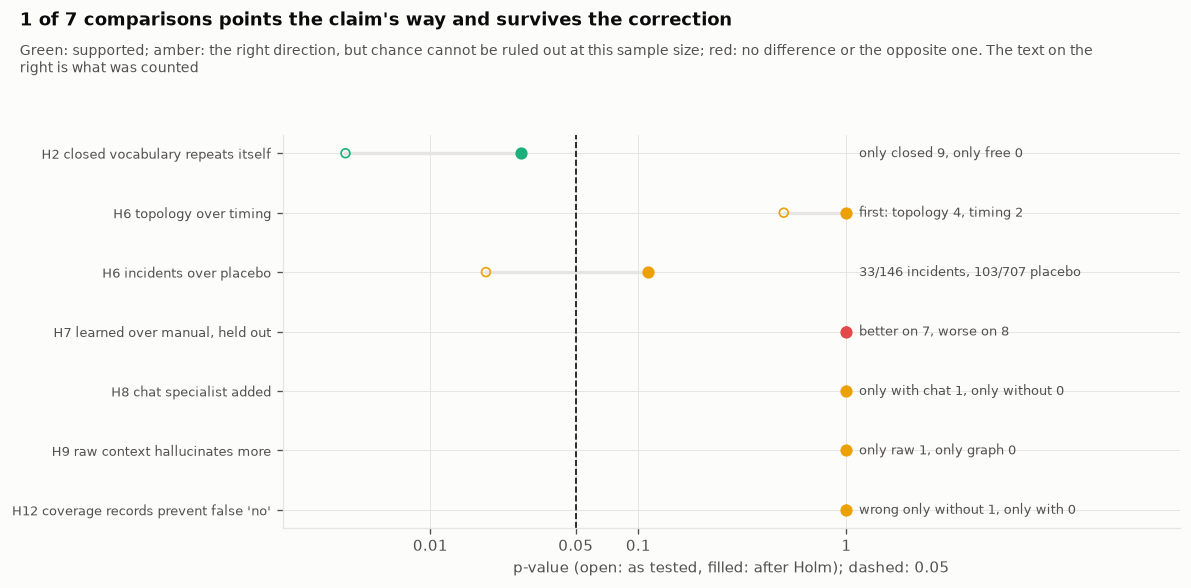

In [243]:
# ---- the tests behind the verdicts: exact tests on paired outcomes, Holm-corrected across the claims ----
from scipy.stats import binomtest, fisher_exact


def safe(fn, default=None):
    try:
        return fn()
    except Exception:
        return default


def mcnemar(a, b) -> tuple[int, int, float]:
    """Exact McNemar test on paired yes/no outcomes: how often only a held, how often only b, and the two-sided p."""
    pairs = [(bool(x), bool(y)) for x, y in zip(a, b) if x is not None and y is not None]
    only_a, only_b = sum(x and not y for x, y in pairs), sum(y and not x for x, y in pairs)
    return only_a, only_b, (binomtest(only_a, only_a + only_b).pvalue if only_a + only_b else 1.0)


def holm(p: dict) -> dict:
    """Holm's step-down correction: the k-th smallest of m p-values is multiplied by m - k + 1, never decreasing."""
    adj, running = {}, 0.0
    for k, name in enumerate(sorted(p, key=p.get)):
        running = max(running, min(1.0, (len(p) - k) * p[name]))
        adj[name] = running
    return adj


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """The 95% Wilson interval for k successes in n: honest at small n, where k/n plus or minus two errors is not."""
    if not n:
        return float("nan"), float("nan")
    p, d = k / n, 1 + z * z / n
    mid, half = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, mid - half), min(1.0, mid + half)


def task_hits(tasks: pd.DataFrame, method: str, k: int = 1) -> list[bool]:
    return [any(w in rank_task(t.task_id, t.system, method)[:k] for w in component_answers(t.scoring_points))
            for t in tasks.itertuples() if component_answers(t.scoring_points)]


TESTS = {}                   # comparison -> n, what was seen, whether it points the claim's way, two-sided p
if len(DETERMINISM):
    rep_ = DETERMINISM.pivot(index="thread", columns="mode", values="all_same")
    a_, b_, p_ = mcnemar(rep_["closed"].tolist(), rep_["free"].tolist())
    TESTS["H2 closed vocabulary repeats itself"] = {"n": len(rep_), "seen": f"only closed {a_}, only free {b_}",
                                                     "favours": a_ > b_, "p": p_}
topo_h, timing_h = task_hits(DEV, "topology chains"), task_hits(DEV, "timing-only chains")
a_, b_, p_ = mcnemar(topo_h, timing_h)
TESTS["H6 topology over timing"] = {"n": len(topo_h), "seen": f"first: topology {sum(topo_h)}, timing {sum(timing_h)}",
                                    "favours": a_ > b_, "p": p_}
n_i, n_p = PLACEBO["n"].get("incidents", 0), PLACEBO["n"].get("placebo", 0)
if n_i and n_p:
    h_i, h_p = round(PLACEBO["no cap"]["incidents"] * n_i), round(PLACEBO["no cap"]["placebo"] * n_p)
    TESTS["H6 incidents over placebo"] = {"n": n_i + n_p, "seen": f"{h_i}/{n_i} incidents, {h_p}/{n_p} placebo",
                                          "favours": h_i / n_i > h_p / n_p,
                                          "p": float(fisher_exact([[h_i, n_i - h_i], [h_p, n_p - h_p]])[1])}
cb2 = TASKS[TASKS.system == "market_cb2"]
learned_s = [score_answer(learned_answer(t), t.scoring_points)[0] for _, t in cb2.iterrows()]
manual_s = [score_answer(manual_answer(t), t.scoring_points)[0] for _, t in cb2.iterrows()]
wins, losses = sum(l > m for l, m in zip(learned_s, manual_s)), sum(l < m for l, m in zip(learned_s, manual_s))
TESTS["H7 learned over manual, held out"] = {"n": len(cb2), "seen": f"better on {wins}, worse on {losses}",
                                             "favours": wins > losses,
                                             "p": binomtest(wins, wins + losses).pvalue if wins + losses else 1.0}
if len(CURVE):
    a_, b_, p_ = mcnemar(CURVE[CURVE.k == 3].trigger.tolist(), CURVE[CURVE.k == 2].trigger.tolist())
    TESTS["H8 chat specialist added"] = {"n": int((CURVE.k == 3).sum()), "seen": f"only with chat {a_}, only without {b_}",
                                         "favours": a_ > b_, "p": p_}
if len(RESULTS_2X2):
    hal = RESULTS_2X2.pivot(index="incident", columns="arm", values="hallucinated")
    a_, b_, p_ = mcnemar(hal["raw, one prompt"].tolist(), hal["graph, one prompt"].tolist())
    TESTS["H9 raw context hallucinates more"] = {"n": len(hal), "seen": f"only raw {a_}, only graph {b_}",
                                                 "favours": a_ > b_, "p": p_}
if len(E4):
    a_, b_, p_ = mcnemar(((E4.without_coverage == "no") & (E4.truth == "yes")).tolist(),
                         ((E4.with_coverage == "no") & (E4.truth == "yes")).tolist())
    TESTS["H12 coverage records prevent false 'no'"] = {"n": len(E4), "seen": f"wrong only without {a_}, only with {b_}",
                                                       "favours": a_ > b_, "p": p_}
HOLM = holm({k: v["p"] for k, v in TESTS.items()})
print(f"  {'comparison':<40}{'n':>5}  {'what we saw':<34}{'p':>8}{'Holm p':>8}")
for k, v in TESTS.items():
    print(f"  {k:<40}{v['n']:>5}  {v['seen']:<34}{v['p']:>8.3f}{HOLM[k]:>8.3f}"
          f"{'' if v['favours'] else '   (points against the claim)'}")
print(f"\n  {len(TESTS)} comparisons, two-sided exact tests, Holm-corrected together; a claim needs every one of its "
      f"comparisons to point its way with a corrected p below 0.05")

fig, ax = plt.subplots(figsize=(10, 0.5 * len(TESTS) + 1.5))
names_t = list(TESTS)
for i, k in enumerate(names_t):
    v = TESTS[k]
    colour = C3 if v["favours"] and HOLM[k] < 0.05 else C4 if v["favours"] else C8
    ax.plot([v["p"], HOLM[k]], [i, i], color=GRID, lw=2, zorder=1)
    ax.scatter([v["p"]], [i], s=28, facecolors="none", edgecolors=colour, zorder=2)
    ax.scatter([HOLM[k]], [i], s=40, color=colour, zorder=3)
    ax.text(1.15, i, v["seen"], va="center", fontsize=7.5, color=INK2)
ax.axvline(0.05, color=INK, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlim(min(min(HOLM.values()), min(v["p"] for v in TESTS.values())) / 2, 40)
ticks = [t for t in (0.001, 0.01, 0.05, 0.1, 1) if t >= ax.get_xlim()[0]]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_yticks(range(len(names_t)), names_t, fontsize=7.8)
ax.invert_yaxis()
ax.set_xlabel("p-value (open: as tested, filled: after Holm); dashed: 0.05")
n_sig = sum(TESTS[k]["favours"] and HOLM[k] < 0.05 for k in names_t)
verb = ("points", "survives") if n_sig == 1 else ("point", "survive")
finish(fig, "claim_tests", f"{n_sig} of {len(TESTS)} comparisons {verb[0]} the claim's way and {verb[1]} the correction",
       "Green: supported; amber: the right direction, but chance cannot be ruled out at this sample size; red: no "
       "difference or the opposite one. The text on the right is what was counted")


def tested(*keys) -> tuple[str, str]:
    """A verdict from the tests: SUPPORTED, INCONCLUSIVE (the right direction, but chance cannot be ruled out at
    this sample size) or NOT SUPPORTED (no difference, or the wrong way)."""
    rows = [TESTS[k] for k in keys if k in TESTS]
    if not rows:
        return "NOT TESTABLE", "not run"
    if not all(r["favours"] for r in rows):
        verdict = "NOT SUPPORTED"
    else:
        verdict = "SUPPORTED" if all(HOLM[k] < 0.05 for k in keys if k in TESTS) else "INCONCLUSIVE"
    return verdict, "; ".join(f"{r['seen']} (Holm p {HOLM[k]:.2f})" for k, r in zip([k for k in keys if k in TESTS], rows))

In [244]:
# ---- twelve claims, twelve verdicts, each computed from a measured number ----


def verdict_rows() -> list[tuple]:
    rows = []
    # two empty answers always agree, so only questions with a change to compare count, and at least 30 of them
    n_ans, agree = safe(lambda: len(ANSWERED), 0), safe(lambda: int(ANSWERED.same.sum()), 0)
    rows.append(("H1", "NOT TESTABLE" if n_ans < 30 else "SUPPORTED" if agree / n_ans >= 0.9 else "NOT SUPPORTED",
                 f"one query and five lookups return the same changes and owners on {agree} of {n_ans} questions with "
                 "a change to compare" if n_ans else "no question had a change to compare"))
    valid = safe(lambda: float(COMPARE[COMPARE.model == "flash"].valid.mean()))
    h2, h2_seen = tested("H2 closed vocabulary repeats itself")
    if valid is not None and valid < 0.95 and h2 != "NOT TESTABLE":
        h2 = "NOT SUPPORTED"                     # a contract the model breaks cannot make its answers repeatable
    closed_ = safe(lambda: DETERMINISM[DETERMINISM["mode"] == "closed"].all_same)
    lo, hi = wilson(int(closed_.sum()), len(closed_)) if closed_ is not None else (float("nan"), float("nan"))
    rows.append(("H2", h2 if valid is not None else "NOT TESTABLE",
                 f"contract kept {valid:.0%}; identical three times with the contract {closed_.mean():.0%} of "
                 f"{len(closed_)} (95% interval {lo:.0%} to {hi:.0%}); {h2_seen}"
                 if valid is not None and closed_ is not None else "determinism runs missing"))
    rows.append(("H3", "SUPPORTED" if safe(lambda: GATE["refused"] > 0) else "NOT TESTABLE",
                 f"{safe(lambda: GATE['refused'], 0):,} junk strings refused; misspelt host caught by the shapes"))
    pl = safe(lambda: PLACEBO)
    if pl and not CAP_TESTABLE:
        r0 = pl["no cap"]["incidents"] / max(pl["no cap"]["placebo"], 1e-9)
        r1 = pl["cap 50"]["incidents"] / max(pl["cap 50"]["placebo"], 1e-9)
        rows.append(("H4", "SUPPORTED" if r1 > r0 * 1.1 else "NOT SUPPORTED",
                     f"call graphs: no fan-in above {MAX_FANIN} (not testable); membership hub: incident/placebo ratio "
                     f"{r0:.2f} uncapped, {r1:.2f} capped"))
    else:
        rows.append(("H4", "NOT TESTABLE", f"largest fan-in {MAX_FANIN}"))
    ip, al = safe(lambda: in_plan), safe(lambda: as_listed)
    rows.append(("H5", "SUPPORTED" if ip is not None and ip > al else "NOT SUPPORTED" if ip is not None else "NOT TESTABLE",
                 f"a graph-reading enricher makes {ip} links in planned order, {al} out of order" if ip is not None else "E4 missing"))
    rows.append(("H6", *tested("H6 topology over timing", "H6 incidents over placebo")))
    rows.append(("H7", *tested("H7 learned over manual, held out")))
    rows.append(("H8", *tested("H8 chat specialist added")))
    rows.append(("H9", *tested("H9 raw context hallucinates more")))
    rows.append(("H10", "NOT TESTABLE", "our specialists report to a reconciler and never read each other's findings"))
    cause = safe(lambda: float(LIFE["cause found"].median()))
    live = safe(lambda: float(LIVE.wall_s.median()))
    rows.append(("H11", "NOT TESTABLE" if cause is None or live is None else
                 "SUPPORTED" if live / 60 < cause else "NOT SUPPORTED",
                 f"people: cause found a median {cause:.0f} min after impact; agents: an answer in {live:.0f} s live, "
                 "right or wrong" if cause is not None and live is not None else "timing missing"))
    rows.append(("H12", *tested("H12 coverage records prevent false 'no'")))
    return rows


SCORECARD_ROWS = verdict_rows()
GLANCE_FILE.write_text(json.dumps(
    {"profile": PROFILE, "written": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="minutes"),
     "verdicts": [{"claim": cid, "verdict": v, "evidence": why} for cid, v, why in SCORECARD_ROWS]}, indent=1))
claim_text = {c[0]: c[1] for c in CLAIMS}
print(f"  {'':<5}{'verdict':<15}{'claim':<70}")
print("  " + "-" * 118)
for cid, v, why in SCORECARD_ROWS:
    print(f"  {cid:<5}{v:<15}{claim_text[cid][:69]:<70}")
    print(f"  {'':<20}{why}")
tally = Counter(v for _, v, _ in SCORECARD_ROWS)
print(f"\n  {dict(tally)}")

       verdict        claim                                                                 
  ----------------------------------------------------------------------------------------------------------------------
  H1   SUPPORTED      One query over the ontology replaces lookups across three tools       
                      one query and five lookups return the same changes and owners on 217 of 217 questions with a change to compare
  H2   SUPPORTED      Constraining an LLM with a type system yields a deterministic graph   
                      contract kept 100%; identical three times with the contract 90% of 10 (95% interval 60% to 98%); only closed 9, only free 0 (Holm p 0.03)
  H3   SUPPORTED      Validating every application against the catalogue keeps junk out of  
                      3,734 junk strings refused; misspelt host caught by the shapes
  H4   NOT SUPPORTED  Capping dependency edges stops popular services from dominating       
                      call graphs: n

[fig] artifacts\figures_full\scorecard.png


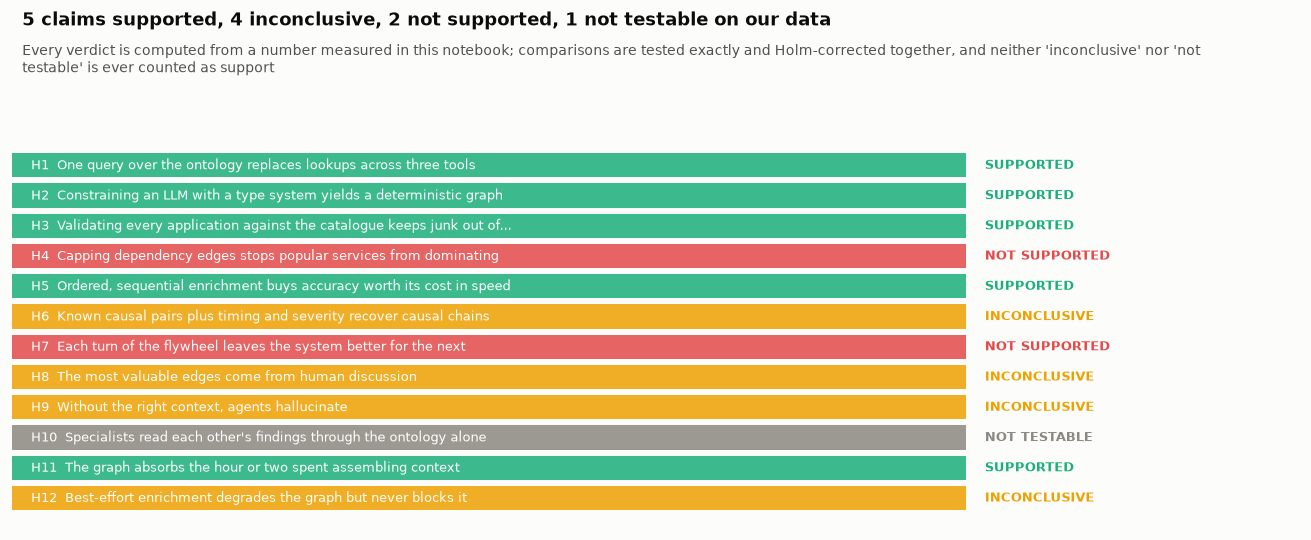

In [245]:
# ---- the scorecard, drawn ----
fig, ax = plt.subplots(figsize=(11, 4.6))
colour = {"SUPPORTED": C3, "INCONCLUSIVE": C4, "NOT SUPPORTED": C8, "NOT TESTABLE": MUTED}
for i, (cid, v, why) in enumerate(SCORECARD_ROWS):
    ax.barh(i, 1, color=colour[v], alpha=0.85)
    ax.text(0.02, i, f"{cid}  {textwrap.shorten(claim_text[cid], 74, placeholder='...')}", va="center", fontsize=8,
            color="white")
    ax.text(1.02, i, v, va="center", fontsize=8, color=colour[v], weight="bold")
ax.set_xlim(0, 1.35)
ax.set_yticks([])
ax.set_xticks([])
ax.invert_yaxis()
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
finish(fig, "scorecard", f"{tally.get('SUPPORTED', 0)} claims supported, {tally.get('INCONCLUSIVE', 0)} inconclusive, "
       f"{tally.get('NOT SUPPORTED', 0)} not supported, {tally.get('NOT TESTABLE', 0)} not testable on our data",
       "Every verdict is computed from a number measured in this notebook; comparisons are tested exactly and "
       "Holm-corrected together, and neither 'inconclusive' nor 'not testable' is ever counted as support")

**Five of the post's twelve claims hold on our data, two do not, four point the right way
without enough cases to rule out chance, and one cannot be tested here.** What holds is the
plumbing. One query over the ontology returns exactly what five lookups return (H1). A closed
vocabulary makes a model repeat itself where free JSON never does, on 9 of 10 conversations
against none, and that difference survives the correction for seven comparisons (H2). The
catalogue gate refused 3,734 junk strings (H3). Order matters to an enricher that reads the graph
(H5), though we never measured what running in sequence costs. And agents answer within seconds
where people took a median of 62 minutes to find a cause (H11), a verdict about time, not about
being right. What does not hold is the edge cap, which changed nothing on the one hub large
enough to try it (H4), and the flywheel's promise that each turn leaves the system better (H7):
rules learned on one cluster beat the hand-written ones on 7 held-out tasks and lost on 8. The
four inconclusive claims all point the post's way. Topology chains put the right component first
more often than timing alone, 4 times against 2 of 41, and incidents get confident chains more
often than placebo moments, 33 of 146 against 103 of 707, but neither survives the correction for
seven comparisons, the placebo's coming closest at p 0.11; and chat, raw context and coverage
records each changed the outcome of exactly one incident. Settling them
needs many more labelled incidents than one organisation's public reports provide, and we report
them as open rather than round them up. H10 needs specialists that read each other's findings,
and ours report to a reconciler instead.

## 43 · The eight principles, against our evidence

**Theory.** The post closes with eight principles its authors would carry into a second
attempt. They are advice, not claims, but each one makes a prediction about what goes wrong when
it is ignored, and for most of them this notebook ran into that failure directly. Worlds: all.

In [246]:
# ---- each principle, and where this notebook met it ----
chat_fixed, chat_broke, chat_p = (mcnemar(CURVE[CURVE.k == 3].trigger.tolist(), CURVE[CURVE.k == 2].trigger.tolist())
                                  if len(CURVE) else (0, 0, 1.0))
PRINCIPLES = [
    ("Model identity before anything else", f"section 11: today's catalogue names {YEARLY.iloc[-1]:.0%} of the hosts "
     f"mentioned in {YEARLY.index[-1]} and {YEARLY.iloc[0]:.0%} of those mentioned in {YEARLY.index[0]}; section 16: "
     f"{GATE['refused']:,} junk strings refused as applications"),
    ("Treat the ontology as code", "section 12: renaming one property broke a competency question before merge"),
    ("Separate concepts from instances", f"section 12: one {TBOX_LINES}-line ontology serves "
     "Wikimedia and each OpenRCA system as separate tenants; instances live in named graphs"),
    ("Build on open standards", "section 13: the same query gave different wrong answers in two engines until the value was "
     "typed; with types, both agreed"),
    ("Constrain stochastic tools with a type system", "sections 13 and 24: shapes refuse what breaks the contract; "
     "repetition is a separate question, measured in section 24"),
    ("Make enrichment best-effort and ordered", "section 15: coverage records turn a timeout into 'unknown'; section 36: "
     "an enricher that reads the graph needs the order"),
    ("Model human reasoning alongside machine telemetry",
     f"section 37: with the chat specialist added, the trigger came out right where it had been wrong on {chat_fixed} "
     f"of {int((CURVE.k == 3).sum()) if len(CURVE) else 0} test incidents, and wrong where it had been right on "
     f"{chat_broke}"),
    ("Keep humans as the approvers", "section 33: every proposed fix waits for a person; section 34 shows the cost of "
     "skipping one: with no person to settle the labels, two adjudicators must agree, and every report they "
     "split on leaves the test"),
]
for i, (p, where) in enumerate(PRINCIPLES, 1):
    print(f"  {i}. {p}")
    print(textwrap.fill(where, width=100, initial_indent="       ", subsequent_indent="       "))

  1. Model identity before anything else
       section 11: today's catalogue names 81% of the hosts mentioned in 2026 and 18% of those
       mentioned in 2021; section 16: 3,734 junk strings refused as applications
  2. Treat the ontology as code
       section 12: renaming one property broke a competency question before merge
  3. Separate concepts from instances
       section 12: one 117-line ontology serves Wikimedia and each OpenRCA system as separate
       tenants; instances live in named graphs
  4. Build on open standards
       section 13: the same query gave different wrong answers in two engines until the value was
       typed; with types, both agreed
  5. Constrain stochastic tools with a type system
       sections 13 and 24: shapes refuse what breaks the contract; repetition is a separate
       question, measured in section 24
  6. Make enrichment best-effort and ordered
       section 15: coverage records turn a timeout into 'unknown'; section 36: an enricher that
 

**Each of the eight principles names a failure, and this notebook ran into most of them before it
followed the principle.** Identity comes first for a reason: today's catalogue names 81% of the
hosts mentioned this year and 18% of those mentioned in 2021, so a join that ignores time loses
most of the past. Treating the ontology as code caught a renamed property before it could break
the agents' saved questions. Open standards paid off in a way the post does not mention: the
same query gave two engines two different wrong answers until the value was typed, and then both
agreed. The type system limited what the models could say, and section 24 showed it is also what
made them repeat themselves. Coverage records turned a timeout into "unknown", and order let an
enricher make links it could not make alone. The seventh principle is the one our evidence
barely touches: adding the chat specialist changed the outcome of a single test incident. The
eighth is built in. Nothing in this notebook acts without a person, and section 34 showed what
the absence of one costs: every label the two adjudicators split on had to leave the test.

## 44 · What is claimed, what is not, and what is still open

**Theory.** A results section that lists only what worked is advertising. This one lists what
the notebook does not claim, every bug we found in our own work while building it, and the
questions we could not close. Worlds: all.

In [247]:
# ---- what this notebook does not claim ----
NOT_CLAIMED = [
    "Netflix's numbers. We never saw their data; every number here is measured on Wikimedia, OpenRCA or RCAEval.",
    "Human labels. No person reviewed the Wikimedia labels: two models read every report, and where they disagreed "
    "the assistant that built this notebook and Qwen3.8-Max adjudicated blind; only labels both agreed on are kept.",
    (f"Netflix's scale on one machine. Section 40b replays real telemetry through the signal step at "
     f"{LOAD['sustained']['events_per_s'] / 1e6:.0f} million events a second and loads a {G['stored'] / 1e6:.0f}-million-"
     "triple graph on one laptop; the fleet for 38 million events a second is arithmetic from that measurement, not a run."
     if LOAD and "G" in globals() else "Netflix's scale: section 40b's measurements did not run in this profile."),
    "Infrastructure metrics at Wikimedia. They are public for fifteen days, shorter than any incident we test.",
    "That agreement with Claude is accuracy. Section 22 compares models with Claude; only section 34's labels are truth.",
    "That a mean of hop scores is a probability. Section 26 treats chain confidence as a score.",
    "The edge cap. No call graph we have comes near the fan-in where a cap would act.",
    "Agents on RCAEval. Its 360 cases are scored with the model-free ranker of section 38 only; the budget set aside "
    "for agents there was never spent.",
]
for line in NOT_CLAIMED:
    print(textwrap.fill(line, width=104, initial_indent="  - ", subsequent_indent="    "))

  - Netflix's numbers. We never saw their data; every number here is measured on Wikimedia, OpenRCA or
    RCAEval.
  - Human labels. No person reviewed the Wikimedia labels: two models read every report, and where they
    disagreed the assistant that built this notebook and Qwen3.8-Max adjudicated blind; only labels both
    agreed on are kept.
  - Netflix's scale on one machine. Section 40b replays real telemetry through the signal step at 26
    million events a second and loads a 16-million-triple graph on one laptop; the fleet for 38 million
    events a second is arithmetic from that measurement, not a run.
  - Infrastructure metrics at Wikimedia. They are public for fifteen days, shorter than any incident we
    test.
  - That agreement with Claude is accuracy. Section 22 compares models with Claude; only section 34's
    labels are truth.
  - That a mean of hop scores is a probability. Section 26 treats chain confidence as a score.
  - The edge cap. No call graph we have comes

  where       bug
  section 4   an incident page titled with a date that does not exist (2018-02-29) crashed the
              parser
  section 4   the catalogue cache had no profile in its name, so a quick run could feed a full one
  section 4   names leaked in five shapes the first scrubber missed: prefixed handles, deploy-line
              rosters, account names in cookbook logs, scorecard responders, a bot named after its
              owner
  section 5   matching every chat alert against every Loki line with the same name: hours instead of
              seconds
  section 8   pandas 3 stores Parquet times in microseconds; dividing by 10**9 gave seconds a
              thousand times too small
  section 9   the first reader-impact score chose an incident whose own report says readers were
              barely affected
  section 13  validating with RDFS inference made every class check on a ranged property pass on
              anything
  section 25  a window from 23:30 to 00:00 wit

[fig] artifacts\figures_full\bug_registry.png


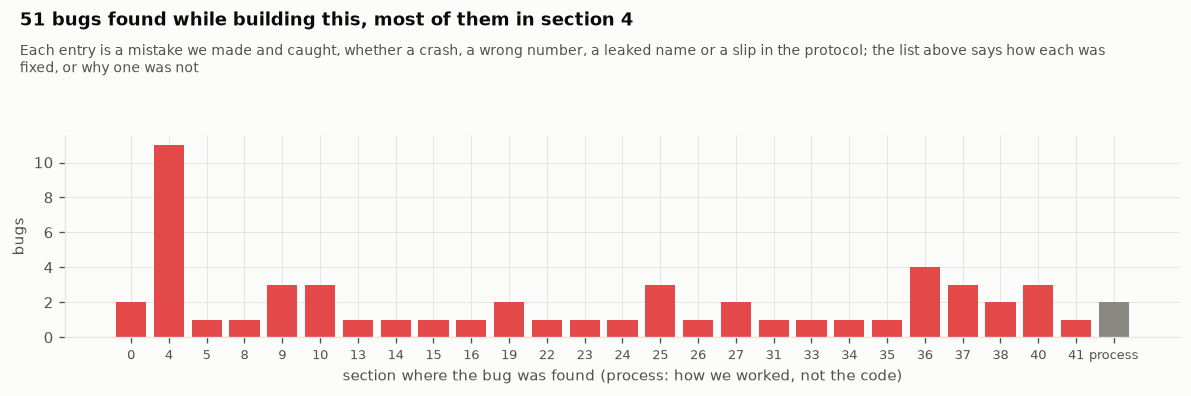

In [248]:
# ---- the bug registry: every bug we found in our own work, and where it was fixed ----
BUGS = [
    ("section 4", "an incident page titled with a date that does not exist (2018-02-29) crashed the parser"),
    ("section 4", "the catalogue cache had no profile in its name, so a quick run could feed a full one"),
    ("section 4", "names leaked in five shapes the first scrubber missed: prefixed handles, deploy-line rosters, "
     "account names in cookbook logs, scorecard responders, a bot named after its owner"),
    ("section 5", "matching every chat alert against every Loki line with the same name: hours instead of seconds"),
    ("section 8", "pandas 3 stores Parquet times in microseconds; dividing by 10**9 gave seconds a thousand times too small"),
    ("section 9", "the first reader-impact score chose an incident whose own report says readers were barely affected"),
    ("section 13", "validating with RDFS inference made every class check on a ranged property pass on anything"),
    ("section 25", "a window from 23:30 to 00:00 with no second date ended before it began"),
    ("section 25", "raw counters compared with their own past look anomalous; they are now judged as rates"),
    ("section 0", "labels, the registration and the run summary were shared by every profile, so a quick run could "
     "have overwritten the study's record"),
    ("section 9", f"the second reader rule (any 3% dip) passed at {np.mean(FIRST_RULE_PLACEBO >= 0.03):.0%} of random "
     "hours, and the incident it chose had dipped at the same hour the day before"),
    ("section 9", "pageview dump files are named for the hour they close; the first conversion put every hour an hour late"),
    ("section 22", "the comparison's sample was redrawn whenever the incident we follow changed, so it ran twice"),
    ("section 23", "Wikimedia's image links gained a tracking query string, so no screenshot passed the extension check"),
    ("sections 24, 40", "cells that must call models live kept no results, so every rerun would have paid again"),
    ("section 27", "figure 9's count went once per named component instead of once per failure, and reached 52 of 41"),
    ("section 31", "the agents' answer vocabulary was defined three sections after its first use"),
    ("section 37", "the raw arm of the two-by-two had three specialists to the graph arm's four"),
    ("section 38", "under pandas 3 a grouped apply drops the grouping column, so the stratified test sample would have "
     "lost its question type (caught by reading the code, before it ran)"),
    ("section 41", "the question-to-SPARQL prompt carried only the first 6,000 characters of the ontology, which cut "
     "off lineage and code changes"),
    ("section 34", "the agreement count scored two empty component lists as total disagreement, so it printed 23 agreed "
     "reports where the review queue (rightly) found 99"),
    ("section 0", "a run stopped while writing a cache left half a Parquet file, which the next run trusted; every "
     "cache is now written beside its target and renamed into place"),
    ("section 4", "names written with an unfamiliar given name, and responder lists in an older table format, slipped past "
     "the scrubber; at least one such name reached both model APIs inside label-extraction prompts before the fix, "
     "and those reports were scrubbed again and re-read"),
    ("section 4", "responder rosters turned 'people' ('5 people: ...') and 'WMF' ('(WMF)') into handles, so those words "
     "were replaced by pseudonyms in every text; rosters now admit only names and handles"),
    ("section 10", "DuckDB's t-digest approximate quantile ran on one core for over ten minutes on 380,000 groups, where "
     "the exact quantile took seconds on all cores; the approximation is now a small reservoir per group"),
    ("section 25", "DuckDB 2 refuses new work on a connection holding a half-read result, so the detectors failed whenever "
     "they ran instead of reading their cache; they now have a connection of their own"),
    ("section 4", "the quick profile took the newest chat but the newest incident reports, which never overlapped; it now "
     "takes every source around one incident the chat record covers"),
    ("process", "a test run of ours reached section 37 before the labels were frozen; it was stopped after 83 model "
     "calls, before any score existed, nobody read an answer, and those cached answers are reused, not regenerated"),
    ("section 15", "deltas were checked with only the stored types of the nodes they point at, so every catalogued "
     "service an incident named became a node to judge, without the catalogue id the store holds, and every incident "
     "fact was quarantined on the full run; each delta's own nodes are now judged, with their stored values"),
    ("section 10", "the first timed query found the files on disk and the next ones in memory, so one aggregation "
     "measured 15 and 52 million rows a second in the same run; every file is now read once before any clock starts"),
    ("section 19", "catalogue aliases ('restbase' for restbase-https) became application nodes of their own, which no "
     "enricher had typed, so the incident delta failed its class check; an alias now names the one service it belongs "
     "to, and an alias two services share names neither"),
    ("section 19", "the channel figure's five-minute bins began at the incident's own minute while pandas counts on "
     "the clock, so every count it drew was zero"),
    ("section 4", "a given name written alone, missing from the list of common names and never written with a surname, "
     "passed the scrubber into a printed report excerpt and into label prompts; given names are now also learned from "
     "what people do in the reports, and the affected reports were scrubbed again and re-read"),
    ("section 4", "given names in lower case, the way people address each other in chat ('name: ...') or log in "
     "('name@host'), passed the scrubber, which took only capitalised words for names; an audit of every corpus found "
     "them, and the scrubber's own test now counts given names in any case"),
    ("section 33", "a diagnosis of read I/O load matched no action and fell back to paging the owning team; I/O now maps "
     "to moving the I/O-heavy work"),
    ("section 4", "'now' was the clock time of each run, so every window that ends now slid by an hour between two runs "
     "and the counts behind it drifted; 'now' is frozen when the record is first fetched"),
    ("section 16", "the on-disk graph kept everything earlier runs had written, so a fact from an older version of an "
     "enricher could survive a fix; the graph is now rebuilt from nothing on every run"),
    ("section 40b", "the fast writer for changes tested 'if host' on a value pandas had turned from None into NaN, "
     "which Python counts as true, so every change naming no catalogued host pointed at a host called 'nan'; the "
     "equivalence test against the enrichers stopped the run before the big graph was built"),
    ("section 36", "experiment 1's query bound '?h' to the alerting host inside one branch of a UNION, where SPARQL "
     "evaluates the branch on its own and '?h1' is still unbound, so that branch matched every host and the query "
     "returned changes on machines nowhere near an alert; the lookups by hand disagreed on 18% of incidents, and that "
     "disagreement is what found it"),
    ("section 36", "with that bug fixed, the one query and the lookups agreed on every test incident only because "
     "neither found a change in the hour before any of them, and two empty answers always agree; the question now "
     "reads the six hours the change tool reads, is asked at real alert moments as well, and the verdict counts only "
     "questions with a change to compare"),
    ("section 36", "at busy alert moments, experiment 1's query paired every alert of the half hour with every machine in "
     "that alert's cluster before it looked for a change, and took up to 21 seconds a question where the lookups by "
     "hand took a tenth of one; it now finds the alerting machines once, and their cluster mates by one path"),
    ("section 36", "the lookups by hand compared alert times to the microsecond and the graph to the second, so an alert "
     "in the first fraction of a second of the window counted for the query and not for the lookups, and 3 of 226 "
     "answers differed; both methods now ask the question to the second, as the graph keeps it"),
    ("section 40b", "the big graph drew its questions afresh at every size from all the history loaded so far, so the "
     "later stages asked about the busier recent years and looked slower for that reason alone (one question went "
     "from about one row to over a hundred); each question now asks about the same alert episodes at every size, "
     "and the busy recent month is measured on its own"),
    ("section 10", "the stopwatch took the shared DuckDB connection as a default argument, which Python fixes when the "
     "function is defined, so once section 40b replaced that connection it would have timed against a closed one; "
     "it now looks the connection up each time it is called"),
    ("sections 37, 38", "two of the seven targets written down before the test, trigger hit@3 on change-triggered "
     "incidents and no unverifiable citations, were never scored by any cell; both are now scored where the "
     "experiment that answers them runs, and the verifier's rejections are counted by reason"),
    ("section 4", "the demonstration of how handles are normalised printed real people's handles beside their "
     "pseudonyms, which tied the two together in the notebook's own output; it now uses invented handles, and so do "
     "the comments in the scrubber's code"),
    ("section 4", "three scorecard rosters taught the scrubber words that are not people: 'Name (WDQS)' gave 'wdqs', "
     "the query service, '1 SWE' gave 'SWE', a job title, and a link in a responder line gave 'www.wikipedia.org'; "
     f"those words reached the label readers as pseudonyms in {len(REREAD)} of {len(LABEL_POOL)} reports, and the "
     "agents wherever their tools returned them. It was found after the test had run. Rosters now skip words in "
     f"capitals and links, no domain becomes a handle, the {len(REREAD)} reports were read again, the "
     f"{len(SET_ASIDE)} decisions on their old text were set aside rather than made again with the results in view, "
     "every prompt that held the old text was asked again, and the registration keeps both label fingerprints"),
    ("section 35", "the text said part G would refuse to run if the labels changed after the registration, but no cell "
     "checked; the registration cell now stops the notebook when the labels differ from the ones it names, and "
     "accepts a revision only once, with its reason written into the registration"),
    ("sections 14, 26, 27", "two fresh runs of the whole notebook disagreed on the chain rankings, the rules with "
     "no model, the bank's score and one verdict, because the rankings broke ties in whatever order Python kept a set "
     "in, and that order changes with every process; ties are now broken by name, sums run in a fixed order, the "
     "example fact is chosen by an ordered query, and runs fix the hash seed"),
    ("process", "six timing results were first measured while the laptop ran on battery, which slows its processor "
     "(the same writer took 52 seconds on mains power and 171 on battery); they were measured again on mains power, "
     "and every timing that can be redone now records which power it ran on"),
    ("section 37", "the graph arm's prompt calls its list of changes 'changes near alerting machines', but the list is "
     "the newest 25 changes logged from six hours before until the moment of asking, wherever they ran; it was found "
     "after the arm had run and is left as run, since a different prompt would make a different arm"),
]
print(f"  {'where':<12}bug")
for where, bug in BUGS:
    print(textwrap.fill(bug, width=100, initial_indent=f"  {where:<12}", subsequent_indent=" " * 14))

where_ = Counter(w if w == "process" else f"section {n}" for w, _ in BUGS for n in re.findall(r"\d+", w) or [w])
order_w = sorted(where_, key=lambda s: (s == "process", int(re.sub(r"\D", "", s) or 0)))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(order_w)), [where_[s] for s in order_w], color=[MUTED if s == "process" else C8 for s in order_w])
ax.set_xticks(range(len(order_w)), [s.replace("section ", "") for s in order_w], fontsize=8)
ax.set_xlabel("section where the bug was found (process: how we worked, not the code)")
ax.set_ylabel("bugs")
top_w = max(where_, key=where_.get)
finish(fig, "bug_registry", f"{len(BUGS)} bugs found while building this, most of them in {top_w}",
       "Each entry is a mistake we made and caught, whether a crash, a wrong number, a leaked name or a slip in the "
       "protocol; the list above says how each was fixed, or why one was not")

In [249]:
# ---- what is still open ----
OPEN = [
    "Chat as evidence at scale: the specialist curve covers the test incidents we could afford, not all of them.",
    "The flywheel at Wikimedia: rolling-origin learning needs more labelled incidents per year than five years provide.",
    "Calibration: chain confidence is a score; turning it into a probability needs far more labelled chains.",
    "Hub caps in production graphs: the membership hub is one test, not a general answer.",
    "Screenshots as evidence: section 23 turns panels into typed facts, but no specialist uses them yet.",
    "Flat baselines: a measurement idle in the hour before scores in the billions on any movement (section 25); a "
    "bounded score is the next revision to measure, on the development cluster only.",
]
still_open = sorted(f["incident"] for f in FINAL if f["incident"] in REREAD and f["how"].startswith("inconclusive"))
if still_open:
    OPEN.append(f"Labels read again: {len(still_open)} of the {len(REREAD)} reports read again after the scrubber fix "
                "are inconclusive, and stay so, since no decision is made once results are known; a blind "
                "adjudication before any future test would bring them back.")
for line in OPEN:
    print(textwrap.fill(line, width=104, initial_indent="  - ", subsequent_indent="    "))

  - Chat as evidence at scale: the specialist curve covers the test incidents we could afford, not all
    of them.
  - The flywheel at Wikimedia: rolling-origin learning needs more labelled incidents per year than five
    years provide.
  - Calibration: chain confidence is a score; turning it into a probability needs far more labelled
    chains.
  - Hub caps in production graphs: the membership hub is one test, not a general answer.
  - Screenshots as evidence: section 23 turns panels into typed facts, but no specialist uses them yet.
  - Flat baselines: a measurement idle in the hour before scores in the billions on any movement
    (section 25); a bounded score is the next revision to measure, on the development cluster only.
  - Labels read again: 4 of the 15 reports read again after the scrubber fix are inconclusive, and stay
    so, since no decision is made once results are known; a blind adjudication before any future test
    would bring them back.


**Fifty-one bugs were found while this notebook was built, eleven of them in section 4, and seven
of those eleven were about who counts as a person.** Privacy is where mostly right is wrong: a
given name written alone, names in lower case the way people address each other in chat, and
responder rosters in an older table format each slipped past one version of the scrubber, and a
demonstration printed real handles beside their pseudonyms; the scrubber's own test now counts
what survives in every corpus, in any case. The reverse mistake came last, after the test had
run: three roster entries taught the scrubber that a query service, a job title and a domain were
people, which hid the service's name from the label readers in 15 of 146 reports and from the
agents wherever their tools returned it. Repairing that without bending the test took a protocol.
The 15 reports were read again by the same two models, the decisions made on their old text were
set aside rather than made again with the results in view, every prompt that held the old text was
asked again, and the registration keeps both label fingerprints and the reason. The repair also
exposed a promise the code did not keep, that part G would refuse labels changed after the
registration; the registration cell now enforces it.
Experiment 1 comes next with four entries, and they read as a lesson in testing: two surfaced as
disagreements between the query and the lookups, one as an agreement too perfect to mean
anything, and one as a run that would not finish. The list of what is not claimed is as much a
result as the verdicts: no Netflix numbers, no human labels, no claim that one laptop runs
Netflix's stream, and no agents on RCAEval. What is still open is mostly a matter of scale and
of one revision we have not made: more labelled incidents would settle the four inconclusive
claims, the reports the scrubber fix left inconclusive need an adjudication made before any
future test, and a bounded anomaly score is the next change to measure.

## 45 · Reproducing this

**Theory.** Everything above can be rerun. The data is public and fetched once, politely; the
model calls are cached, so a second run costs nothing and returns the same answers even if a
model is withdrawn; and every heavy result is cached on disk with the profile in its name. The
manifest below records what this run produced and fingerprints it. Worlds: all.

In [250]:
# ---- the manifest: what this run produced, fingerprinted ----
def file_hash(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:16]


manifest = {"profile": PROFILE, "machine": MACHINE, "finished": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
            "figures": sorted(p.name for p in FIG_DIR.glob("*.png")),
            "ontology": {p.name: file_hash(p) for p in ONTO_DIR.glob("*") if p.is_file()},
            "registration": PREREG_HASH if "PREREG_HASH" in globals() else None,
            "live_calls_this_run": sum(1 for r in LEDGER.session if not r.get("cached")),
            "cached_calls_this_run": sum(1 for r in LEDGER.session if r.get("cached")),
            "spent": {"qwen": round(LEDGER.spent("qwen"), 2), "claude_usd": round(LEDGER.spent("claude"), 4)}}
MANIFEST_FILE.write_text(json.dumps(manifest, indent=1, default=str))
print(f"  {len(manifest['figures'])} figures; ontology files {manifest['ontology']}")
print(f"  model calls this run: {manifest['live_calls_this_run']} live, {manifest['cached_calls_this_run']} from the cache")
print(f"  [test] a rerun makes no live model calls -> "
      f"{'PASS' if manifest['live_calls_this_run'] == 0 else 'not yet: this run made live calls (run again to check)'}")
print("\n  to rerun: uv run python scripts/nb.py execute -p PROFILE FULL   (or SMOKE for a few minutes)")

  90 figures; ontology files {'competency.rq': '2cba2f48ff7891c2', 'ops.ttl': 'db895132680a71ea', 'shapes.ttl': '1a8b5be802a06a9e'}
  model calls this run: 0 live, 3414 from the cache
  [test] a rerun makes no live model calls -> PASS

  to rerun: uv run python scripts/nb.py execute -p PROFILE FULL   (or SMOKE for a few minutes)


**A second run of this notebook pays for no model calls and reaches the same verdicts: the data
is public, every model answer is cached, the rules were fingerprinted before the test, and the
run fingerprints itself above.** Two kinds of number move between runs, and should. Wall-clock
timings depend on the machine and on whether it runs on mains power or battery, which is why
every timing that can be redone says which it ran on. Answers that read the clock move with the
day, like the first query of section 41. The counts, labels, chains and verdicts are computed
again from the same inputs each time, with ties broken by name and Python's hash seed fixed, so
that not even the order of a set can change them; and the opening of the notebook prints the
verdicts the last complete run left on disk, so a reader can see that the two agree.